In [ ]:
#!/usr/bin/env python
# -*- coding: utf-8 -*-
"""
================================================================================
KIDNEY STONE CT ANALYSIS FRAMEWORK -- KSSD2025 -- MSABR-Net -- SINGLE-FILE EDITION
================================================================================
Segmentation -> detection -> counting -> in-plane size (mm and px) -> slice-level
burden -> descriptive size-burden category -> explainable AI -> single-slice
measurement report -> benchmark against five baselines.

HOW TO RUN (Google Colab)
    Runtime > Change runtime type > T4 GPU. Paste this file into one cell and run
    it, or upload it and run  !python kssd2025_msabr_net.py
    First run with CFG.QUICK = True (2 epochs, 128 px) to confirm the download and
    the image/mask pairing, then set it back to False for the real run.
    Run time on a T4: stone-free training slices make each epoch ~1.5x longer, so
    MSABR-Net alone takes ~2-2.5 h and all six models ~9 h. To see the proposed
    model's false-positive result first, set CFG.run_baselines = False; then run
    the baselines (same settings) before quoting any comparison.

DATA
    The script downloads the real dataset with kagglehub
    ("murillobouzon/kssd2025-kidney-stone-segmentation-dataset"), offering a
    kaggle.json upload if credentials are missing, and reuses an existing copy
    (Kaggle input or kagglehub cache). Set CFG.data_root to use a local copy.
    There is no synthetic fallback. Keep the original TIF files: TIF and PNG are
    lossless; never convert to JPEG (its block artefacts corrupt exactly the
    stone boundaries this project measures, and turn binary masks into grey).

OUTPUTS (./results, zipped at the end; tables/reports carry a run tag)
    figures/      numbered figures, qualitative panels, XAI panels
    tables/       dataset stats, splits, per-image metrics, comparisons, tests
    reports/      single-slice report cards (.txt/.json/.png/.pdf), duplicate audit
    checkpoints/  best (EMA) weights per model
    predictions/  probability + binary masks per evaluated slice (.npz)
    LIMITATIONS.txt  every caveat this run triggered, with its numbers

HOW EACH REVIEWER-2 COMMENT IS ADDRESSED IN THE CODE
    #1 No patient IDs / leakage. Splits are grouped by image-similarity cluster
       (NCC of 64x64 thumbnails; connected components above an automatically
       chosen threshold) with StratifiedGroupKFold, so near-identical slices never
       straddle train and test. Residual train-test similarity is measured per test
       slice and Dice is checked against it (train_proximity.csv, fig23).
       Duplicates: nothing is removed (CFG.dedup_mode="group"); byte-identical and
       verified copies are locked into one split; dice_unique_slices counts each
       copied slice once. This is a proxy, not patient-level independence.
    #2 Assumed pixel spacing. Every size result is also reported in pixels (*_px);
       spacing_sensitivity_*.csv restates mm results over 0.50-1.00 mm/px;
       spacing_category_sensitivity_*.csv shows how many slices change category.
       Optional validation on DICOM with real PixelSpacing: CFG.external_paired_root.
    #3 Categories. "Size-burden category" is a descriptive grouping, not a
       validated severity grade; reports make no management, passage or MET
       statement; the heuristic index is hidden; category_scheme_sensitivity_*.csv
       compares cut-off schemes. category_* metrics measure error propagation
       (predicted-mask category vs GT-mask category), not clinical agreement.
    #4 Stone-free slices. Internal presence AUC is withheld (too few negatives);
       every model is evaluated on presumed stone-free CT-KIDNEY slices (Normal /
       Cyst / Tumor; same source family, NOT independent) with Wilson CIs, and
       false-positive calculi are shown for review (fig24, fp_review_*.csv).
       See "FALSE-POSITIVE REDUCTION" below for how the FP rate is reduced
       without touching the held-out evaluation slices.
    #5 Single slice. All outputs say "this slice"; no patient-level wording; the
       2-D volume surrogate is hidden by default.
    #6 Statistics. Paired Wilcoxon per baseline with Bonferroni (m = number of
       planned comparisons) AND Holm adjustment, a cluster-level test, cluster-
       bootstrap CIs, effect size, pre-specified practical margins and measurement-
       level differences (significance_tests.csv). Optional multi-seed study.

TRAINING RECIPE (identical for every model)
    Focal-Tversky + BCE (+ boundary, presence and deep-supervision terms for
    MSABR-Net) + a top-k "negative peak" loss on stone-free slices, AdamW,
    OneCycle LR stepped per iteration, weight EMA used for validation/checkpoint/
    test, collapse watchdog with one lower-LR retry, hard-negative mining,
    validation-selected operating point, flip TTA.

v3 FIXES (after the v2 run: 5/5 baselines collapsed, MSABR-Net NaN at epoch 42,
crash in external_negative_figure before LIMITATIONS/zip were written)
    - Early stopping could fire at epoch 21, before the epoch-30 collapse check, so
      no collapsed baseline was ever retried. Patience now only counts once val
      Dice >= collapse_dice_floor; the check moved to 40% of the epochs; a model
      still collapsed on its last attempt stops there instead of running on.
    - Focal-Tversky / Dice terms were averaged over stone-free slices too, where
      they reward an empty prediction (a collapse attractor) and, with gamma < 1,
      have an infinite gradient at a perfectly clean slice (the epoch-42 NaN).
      They now run on stone-bearing slices only, in float32, with a clamp.
    - Output heads start at a 1% prior (focal-loss initialisation); the negative
      peak loss is ramped in over the first epochs.
    - Non-finite steps are skipped (BatchNorm statistics repaired); an epoch that
      diverges stops the attempt and keeps the best checkpoint.
    - Operating point: ties go to recall, not to a lower validation FP rate.
      fp_target = 5% is the stated requirement.
    - Grouping: the cluster-size cap can no longer fall below the cluster that
      exists at the strictest threshold (v2 fell back to t = 0.999 = no grouping).
    - Wilson CI bound rounding fixed (the crash); every reporting step after
      training is wrapped so one failure cannot lose the tables, LIMITATIONS.txt
      and the zip. Checkpoints carry a recipe fingerprint; run_train=False reuses
      only checkpoints from this recipe that did not collapse.
    - Shortcut audit: the flag now rests on the JPEG twins (same slice, both
      formats); low detection on unannotated 'novel' Stone slices gets a review
      sheet (fig27) instead of a shortcut verdict.

FALSE-POSITIVE REDUCTION (v2; previous run: 241/900 = 26.8% for MSABR-Net)
    Cause: KSSD2025 has 7 stone-free slices out of 838, so no model ever learned
    what a stone-free slice looks like, and the threshold was tuned for Dice only.
    Fix, applied identically to EVERY model:
      a. Stone-free CT-KIDNEY slices (Normal / Cyst / Tumor) are split into
         neg-train / neg-val / neg-test pools by similarity cluster, so no cluster
         is shared between them. neg-test is touched ONCE, for the final numbers.
      b. Training mixes neg-train slices into every epoch (CFG.neg_ratio per stone
         slice), half of them "hard" negatives (the ones the model currently fires
         on most), with a top-k negative peak loss and real negatives for the
         presence head.
      c. Checkpoint selection uses stone Dice on KSSD val AND the fraction of
         neg-val monitor slices with no predicted calculus.
      d. The operating point (pixel threshold, minimum component area, component
         peak probability, presence gate) is chosen on KSSD val + neg-val ONLY:
         the highest validation Dice whose validation FP rate is <= CFG.fp_target
         while stone recall and Dice stay within CFG.op_recall_tol / op_dice_tol
         of the Dice-only reference. All constants are fixed before the test set
         is evaluated; the test FP rate is reported as measured, whatever it is.
    Checks shipped with the result (all in tables/ and LIMITATIONS.txt):
      - fp_ablation: same weights, Dice-only reference vs chosen operating point,
        so the effect of post-processing is separated from the effect of training;
      - detection recall by stone size, so small stones are not silently dropped;
      - source-shortcut audit on CT-KIDNEY "Stone" slices (same source and file
        format as the negatives): if a model had learned "CT-KIDNEY JPEG = no
        stone", it would miss stones there.
================================================================================
"""

# =============================================================================
# SECTION 0 -- ENVIRONMENT, IMPORTS AND CONFIGURATION
# =============================================================================
import os
import re
import sys
import json
import glob
import time
import math
import random
import hashlib
import shutil
import datetime
import warnings
import subprocess

warnings.filterwarnings("ignore")


def _pip(pkg, imp=None):
    """Install a package only if it is missing (keeps Colab startup fast)."""
    try:
        __import__(imp or pkg.split("==")[0].replace("-", "_"))
        return True
    except ImportError:
        print(f"[setup] installing {pkg} ...")
        base = [sys.executable, "-m", "pip", "install", "-q"]
        if subprocess.call(base + [pkg]) != 0:      # PEP 668 externally-managed env
            subprocess.call(base + ["--break-system-packages", pkg])
        try:
            __import__(imp or pkg.split("==")[0].replace("-", "_"))
            return True
        except ImportError:
            return False


for _p, _i in [("numpy", "numpy"), ("pandas", "pandas"), ("scipy", "scipy"),
               ("scikit-image", "skimage"), ("scikit-learn", "sklearn"),
               ("opencv-python-headless", "cv2"), ("matplotlib", "matplotlib"),
               ("tifffile", "tifffile"), ("torch", "torch")]:
    _pip(_p, _i)

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.backends.backend_pdf import PdfPages

from skimage import measure
from scipy.ndimage import distance_transform_edt, binary_erosion, gaussian_filter
from scipy import stats
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score,
                             cohen_kappa_score, r2_score, auc)

try:                                    # inline figure display inside Colab
    from IPython.display import display, Image as IPyImage, Markdown
    _IN_NOTEBOOK = "ipykernel" in sys.modules or "google.colab" in sys.modules
except Exception:
    _IN_NOTEBOOK = False

IN_COLAB = "google.colab" in sys.modules


# -----------------------------------------------------------------------------
#  >>>>>>>>>>>>>>>>>>>>>>  EDIT EVERYTHING HERE  <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<
# -----------------------------------------------------------------------------
class CFG:
    # ---------- data ----------
    kaggle_slug   = "murillobouzon/kssd2025-kidney-stone-segmentation-dataset"
    # Leave "" to auto-detect/download from Kaggle. On a Kaggle notebook set e.g.
    # data_root = "/kaggle/input/kssd2025-kidney-stone-segmentation-dataset"
    data_root     = ""
    out_dir       = "./results"

    # ---------- geometry / CLINICAL CALIBRATION ----------
    # KSSD2025 ships rendered slices, NOT DICOM, so in-plane spacing is not in
    # the files. Every millimetre in this project = spacing x pixels. Replace the
    # value below with the real spacing, or report results in pixels and say so.
    pixel_spacing_mm = 0.70     # <<< PLACEHOLDER -- CALIBRATE THIS
    spacing_csv      = ""       # optional CSV: image,spacing_mm
    # Range used for the spacing sensitivity analysis (Reviewer 2, comment 2).
    # A 512 matrix over a 300-500 mm display FOV gives ~0.59-0.98 mm/px, so this
    # grid brackets the plausible in-plane spacings of adult abdominal CT.
    spacing_grid     = (0.50, 0.60, 0.70, 0.80, 0.90, 1.00)

    # ---------- grouped splitting (Reviewer 2, comment 1) ----------
    # KSSD2025 has no patient IDs, so "group by patient" is impossible. Instead,
    # slices that look near-identical (adjacent slices of one scan, re-hosted
    # copies) are clustered and every cluster is kept inside ONE split.
    #   "similarity" -> cluster by normalised cross-correlation (NCC) of 64x64
    #                   thumbnails; clusters = connected components of the
    #                   "NCC >= t" graph
    #   "filename"   -> old behaviour: one group per file (i.e. no grouping)
    group_mode             = "similarity"
    group_thumb_size       = 64
    group_ncc_floor        = 0.85   # never link two slices less similar than this
    group_max_cluster_frac = 0.05   # largest cluster may hold at most 5% of images
    group_ncc_threshold    = None   # None = automatic: the LOWEST t (= most linking,
                                    # most conservative against leakage) whose
                                    # largest cluster still fits the cap above.
                                    # Set a float to fix it by hand.
    # v3: the cap can never be smaller than the cluster that already exists at the
    # STRICTEST threshold (near-identical slices that must stay together anyway). In
    # v2 one such 50-slice cluster exceeded the 41-slice cap, so the scan fell back to
    # t = 0.999 and grouped almost nothing (test -> train median NCC 0.995).

    # ---------- training (identical recipe for every model) ----------
    img_size        = 512       # 384 or 256 if you hit GPU OOM / time limits
    in_channels     = 1
    batch_size      = 4
    epochs          = 60        # proposed model
    baseline_epochs = 60        # each baseline; keep equal to `epochs` for a fair comparison
    lr              = 3e-4
    weight_decay    = 1e-4
    amp             = True
    num_workers     = 0         # data is preloaded into RAM; 0 is fastest here
    early_stop      = 20
    seed            = 42
    deterministic   = True      # cuDNN deterministic mode: same seed -> same result on GPU
    # Exponential moving average of the weights. The EMA copy is what is validated,
    # checkpointed and tested; on a training set this small it is smoother and usually
    # generalises a little better than the raw weights. use_ema=False = previous recipe.
    use_ema         = True
    ema_decay       = 0.999     # ~1000-step horizon (~7 epochs at batch 4 on ~600 slices)
    lr_overrides = {            # per-model starting LR: these two baselines collapsed at
        "resunet":   1e-4,      # the shared 3e-4, so they get a lower one (helps the
        "transunet": 1e-4,      # baselines, never the proposed model)
    }
    grad_clip       = 5.0       # max gradient norm
    # Input preprocessing switches (same for every model). The 3x3 median filter can
    # erode the smallest calculi (2-3 px wide at 512 px) while the GT keeps them; if
    # small-stone recall is the bottleneck (detection_by_size_*.csv), compare
    # use_denoise=False on VALIDATION before adopting it.
    use_denoise     = True
    use_clahe       = True
    # Collapse watchdog: if train AND val Dice are both below collapse_dice_floor at
    # collapse_check_at x epochs, restart once with lr x collapse_lr_factor (0 = off).
    # Early stopping can no longer fire before this check (v3 fix: in v2, early stop
    # at epoch 21 pre-empted the epoch-30 check, so no baseline was ever retried), and
    # it only starts counting once the model has learned something (val Dice >= floor).
    collapse_dice_floor = 0.05
    collapse_check_at   = 0.40
    collapse_lr_factor  = 0.2

    # ---------- v3 training-stability fixes (same for every model) ----------
    # 1. Region losses (Focal-Tversky, Dice, deep supervision, boundary Dice) are
    #    computed on stone-bearing slices only. On a stone-free slice the Tversky index
    #    is 1/(1 + alpha*FP): it rewards predicting NOTHING with the same weight as a
    #    stone slice, which drove the v2 baselines into an all-background collapse,
    #    and with gamma < 1 its gradient is infinite at a perfectly clean slice, the
    #    source of the NaN at epoch 42. Stone-free slices still get pixel BCE and the
    #    negative peak loss below. False = v2 behaviour.
    region_loss_positive_only = True
    # 2. Prior-probability bias on every 1-channel output head (Lin et al., focal loss):
    #    logits start at logit(0.01) instead of 0 (p = 0.5 on every pixel), so training
    #    does not begin by pushing ~262k background pixels into sigmoid saturation.
    #    None = v2 initialisation.
    head_prior_prob = 0.01
    # 3. The negative peak loss is ramped in linearly over this many epochs so the
    #    stone task gets a head start before stone-free suppression is at full weight.
    neg_peak_ramp_epochs = 5
    # 4. A training epoch whose loss turns non-finite stops that attempt ("diverged");
    #    the best checkpoint so far is kept, and if nothing usable was learned yet the
    #    attempt is retried at the lower LR. Non-finite steps are skipped and BatchNorm
    #    statistics they corrupted are restored from the EMA copy.
    max_nonfinite_frac = 0.05

    # Reuse of checkpoints when run_train=False: a checkpoint is reused only if it was
    # trained with the current recipe (fingerprint of the training settings) and did not
    # collapse; otherwise that model is retrained.
    reuse_require_same_recipe = True

    # ---------- duplicate handling ----------
    # The 8x8 dHash flags ~600 of 838 KSSD2025 slices as candidates because most
    # abdominal slices share a similar outline at that size, so candidates are only
    # PROPOSED and then verified (pixel NCC at 128x128 AND GT-mask Dice).
    #   "group"      remove nothing; lock exact + verified copies into one split (DEFAULT)
    #   "off"        detect + report only; no locking (copies may leak across splits)
    #   "exact_only" remove byte-identical copies
    #   "verified"   remove byte-identical + verified near copies
    #   "full"       remove every dHash candidate (NOT recommended)
    dedup_mode             = "group"
    dedup_max_hamming      = 3      # dHash Hamming distance <= this => candidate pair
    dedup_verify_size      = 128    # thumbnail side used for the pixel check
    dedup_verify_ncc       = 0.99   # pixel similarity a true copy must reach ...
    dedup_verify_mask_dice = 0.90   # ... AND GT-mask overlap it must reach
    dedup_qc_pairs         = 6      # confirmed / rejected examples in fig00b
    dedup_audit_n          = 30     # random candidate pairs exported for a manual spot-check
    dedup_manual_csv       = ""     # optional filled duplicate_audit csv ("dup"/"not_dup"
                                    # in manual_verdict) overriding the automatic verdicts

    # ---------- presence (stone / no stone) ----------
    presence_min_neg          = 5     # fewer GT-negative test slices -> presence AUC withheld
    presence_pos_weight_floor = 0.10  # floor for the presence-head class-balancing weight

    # ---------- loss weights ----------
    w_tversky   = 1.0
    w_bce       = 0.5
    w_boundary  = 0.3
    w_presence  = 0.2
    tversky_alpha = 0.3         # <0.5 => false negatives cost more (screening)
    tversky_gamma = 0.75

    # ---------- split ----------
    train_frac, val_frac, test_frac = 0.70, 0.15, 0.15
    n_folds       = 5
    patient_regex = r"(?P<pid>^[A-Za-z]*[_-]?\d+)"

    # ---------- post-processing ----------
    prob_threshold   = 0.50     # fallback only; replaced by the operating point below
    min_stone_area_px = 4       # floor used when measuring GT and predicted masks
    connectivity     = 2        # 8-connectivity

    # ---------- false-positive control (v2) ----------
    # Stone-free TRAINING slices come from the neg-TRAIN pool only (see
    # neg_split_frac). The neg-TEST pool behind the reported FP rate is never
    # trained on, never used for checkpointing and never used for tuning.
    train_with_negatives = True
    neg_ratio        = 0.5      # stone-free slices per stone slice, drawn fresh every epoch
    neg_hard_frac    = 0.5      # share of them that are "hard" (highest recent max prob)
    neg_hard_warmup  = 3        # epochs of purely random negatives before mining starts
    w_neg_peak       = 0.5      # weight of the top-k BCE on stone-free slices
    neg_topk         = 64       # most confident pixels per stone-free slice in that loss
    aug_jpeg_p       = 0.25     # random JPEG re-encoding of training inputs, so compression
                                # artefacts cannot act as a "which dataset is this" cue
    # Checkpoint score = val Dice on KSSD stone slices x (1 - w x share of neg-val
    # monitor slices with any pixel > 0.5). Multiplicative, so an empty model scores
    # 0. w = 0 reproduces the previous behaviour (Dice only).
    ckpt_neg_weight  = 0.5
    neg_monitor_n    = None     # neg-val slices scored every epoch (None = size of KSSD val)

    # Operating point, chosen on VALIDATION ONLY (KSSD val + neg-val), then frozen.
    # PRE-SPECIFIED: state these values in the paper as fixed before the test set
    # was evaluated, and do not change them after looking at test results.
    #   chosen point = highest validation Dice such that
    #       validation FP rate (stone-free slices with >=1 calculus) <= fp_target
    #       validation stone recall >= reference recall - op_recall_tol
    #       validation Dice         >= reference Dice   - op_dice_tol
    #   reference = best Dice using the pixel threshold alone (the previous protocol).
    #   If nothing meets fp_target, the lowest-FP point within the tolerances is used
    #   and the run says so - the target is never forced.
    #   Among points within op_tie_dice of the best feasible Dice, the HIGHEST recall
    #   wins (then the simplest post-processing, then the lowest FP). In v2 the lowest
    #   FP won the tie, which traded 0.5 points of validation FP for 8 points of test
    #   slice sensitivity (0.986 -> 0.907) once the FP target was already met.
    # fp_target = 0.05: design requirement - fewer than 5% of stone-free slices with a
    # false calculus. target_dice is only REPORTED against (requirement check at the end
    # of the run); nothing is tuned towards it on the test set.
    fp_target      = 0.05
    target_dice    = 0.94
    op_tie_dice    = 0.002
    op_recall_tol  = 0.02
    op_dice_tol    = 0.01
    op_thresholds  = (0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.97, 0.98, 0.99)
    op_min_area_px = (4, 6, 8, 12, 16, 24)       # component must have >= this many px
    op_peak_probs  = (0.0, 0.9, 0.95, 0.98, 0.99, 0.995, 0.999)   # component max prob
    op_presence    = (None, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)
                                                 # slice gate; models with a presence head

    # ---------- multi-seed study (opt-in; multiplies run time by len(seeds)) ----------
    run_multiseed = False
    seeds         = (42, 1337, 2024)

    # ---------- size-burden category thresholds (Reviewer 2, comments 3 & 5) ----
    # These define a DESCRIPTIVE grouping of single-slice in-plane measurements.
    # They are NOT a clinically validated severity grade: treatment of renal
    # calculi also depends on location, obstruction, infection, symptoms,
    # composition and patient factors that this pipeline never observes, and
    # the 5/10 mm spontaneous-passage literature concerns URETERAL stones. The
    # cut-offs are kept only as size strata; the variable names keep the old
    # "sev_" prefix so existing tables/scripts still read them.
    sev_small_mm      = 5.0
    sev_large_mm      = 10.0
    sev_burden_high_mm = 20.0
    sev_multi_count   = 3
    # Alternative threshold schemes evaluated as a SENSITIVITY analysis only
    # (category_scheme_sensitivity). (small_mm, large_mm, burden_high_mm,
    # multi_count or None). "renal_10_20" uses size strata of the kind found in
    # renal-stone treatment algorithms (<10, 10-20, >20 mm); confirm the exact
    # strata against the guideline edition you cite before naming it in the paper.
    category_schemes = {
        "primary_5_10":  (5.0, 10.0, 20.0, 3),
        "renal_10_20":   (10.0, 20.0, 20.0, None),
    }

    # ---------- report card content (Reviewer 2, comments 3 & 5) ----------
    report_show_index  = False   # heuristic "size-burden index" (formerly "risk score")
    report_show_volume = False   # 2-D prolate-spheroid surrogate, not a true volume

    # ---------- stone-free slices (Reviewer 2, comment 4) ----------
    # KSSD2025 has only 7 stone-free slices (none in the test set). Presumed
    # stone-free slices come from the Normal / Cyst / Tumor classes of the public
    # CT-KIDNEY dataset (same Dhaka PACS source family as KSSD2025, so they add
    # NEGATIVES; they are NOT an independent external cohort). Slices that look
    # near-identical to any KSSD2025 slice are excluded first. The rest are
    # clustered by similarity and whole clusters go to neg-train / neg-val /
    # neg-test, so no near-identical slice is shared between the pools.
    run_external_negatives = True
    neg_kaggle_slug   = "nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone"
    neg_root          = ""                      # local folder -> skips the download
    neg_class_dirs    = ("Normal", "Cyst", "Tumor")   # never "Stone"
    neg_exclude_similar = True                  # drop slices too similar to KSSD2025
    neg_pool_per_class  = 1200                  # candidates read per class (seeded)
    neg_split_frac      = (0.55, 0.20, 0.25)    # train / val / test share of clusters
    neg_train_per_class = 650                   # caps applied after the grouped split
    neg_val_per_class   = 200
    neg_max_per_class   = 300                   # neg-TEST cap: 3 x 300 = 900, as before

    # ---------- source-shortcut audit ----------
    # Negatives are CT-KIDNEY JPEGs; KSSD2025 slices are TIFs. A model could lower
    # its FP rate by learning "CT-KIDNEY file = no stone". The audit runs every
    # model on CT-KIDNEY "Stone" slices (same source and format as the negatives,
    # but with stones) and reports how often a calculus is still found:
    #   copies of KSSD TEST slices -> same slice in both formats, must agree;
    #   slices that are not copies of any KSSD slice -> never seen in training.
    run_shortcut_audit = True
    audit_stone_dir    = "Stone"
    audit_max_slices   = 400
    audit_copy_ncc     = 0.99      # 128x128 NCC at/above which it is "the same slice"
    audit_models       = "all"     # "all" or "proposed"
    audit_review_n     = 16        # random 'novel' Stone slices shown with the proposed
                                   # model's prediction (fig27 + audit_review_*.csv), so
                                   # you can check whether a stone is visible at all

    # ---------- optional external set with KNOWN spacing (Reviewer 2, comment 2)
    # Folder with images/ (DICOM .dcm or image files) and masks/ (same stems).
    # DICOM spacing is read from PixelSpacing; otherwise from external_spacing_csv
    # (name,spacing_mm). Images without a mask are scored as stone-free.
    external_paired_root  = ""
    external_spacing_csv  = ""
    external_hu_window    = (40, 400)   # (centre, width) used to render DICOM HU.
                                        # MUST visually match KSSD2025's rendering -
                                        # check fig_external_rendering_check.png.
    external_unmatched_are_negative = True

    # ---------- statistics (Reviewer 2, comment 6) ----------
    alpha                 = 0.05
    n_bootstrap           = 2000
    # Pre-specified "practically negligible" margins. There is NO established
    # minimal clinically important difference for Dice; these are explicit,
    # user-chosen values that must be justified in the manuscript.
    practical_margin_dice = 0.01
    practical_margin_mm   = 0.50

    # ---------- what to run ----------
    run_eda        = True
    run_train      = True
    run_xai        = True
    run_reports    = True
    run_baselines  = True       # False = MSABR-Net only (~2-2.5 h on a T4 instead of ~9 h)
    baselines      = ("unet", "attunet", "unetpp", "resunet", "transunet")
    n_xai_cases    = 6
    n_reports      = 12
    n_stonefree_reports = 9     # report cards for RANDOM held-out stone-free slices,
                                # 3 each from Normal / Cyst / Tumor (one per class shown
                                # inline, all saved + fig28 overview), not hand-picked:
                                # a slice where the model wrongly finds a stone is shown
    use_tta        = True
    show_figures   = True       # display every figure inline in Colab
    figure_dpi     = 150
    zip_results    = True

    # ---------- quick smoke test on the REAL data (fast, proves it runs) ------
    # True -> 2 epochs at 128 px, one baseline. Use this first to confirm the
    # download, the image/mask pairing and the patient split all work, THEN set
    # it back to False for the real training run.
    QUICK = False


if CFG.QUICK:
    CFG.epochs, CFG.baseline_epochs = 2, 1
    CFG.img_size, CFG.batch_size = 128, 4
    CFG.n_xai_cases, CFG.n_reports = 2, 2
    CFG.baselines = ("unet",)
    CFG.neg_pool_per_class = 40
    CFG.neg_train_per_class, CFG.neg_val_per_class, CFG.neg_max_per_class = 20, 8, 10
    CFG.audit_max_slices = 20


DIRS = {}
# run-time state shared between steps (filled in by main())
SIM = {}             # similarity matrix + thumbnails from build_similarity_groups()
GROUP_INFO = {}      # chosen NCC threshold, cluster statistics
PROX = None          # per val/test image: max similarity to any TRAIN image
GROUP_OF = {}        # image name -> group id
DUP_COPIES = set()   # dedup_mode="group": slices that are a second copy of another slice
NEG = {}             # stone-free pools: {"train": df, "val": df, "test": df, "info": dict}
_CURRENT_SEED = CFG.seed


def make_dirs():
    global DIRS
    DIRS = {
        "root":    CFG.out_dir,
        "figures": os.path.join(CFG.out_dir, "figures"),
        "qual":    os.path.join(CFG.out_dir, "figures", "qualitative"),
        "xai":     os.path.join(CFG.out_dir, "figures", "xai"),
        "tables":  os.path.join(CFG.out_dir, "tables"),
        "ckpt":    os.path.join(CFG.out_dir, "checkpoints"),
        "preds":   os.path.join(CFG.out_dir, "predictions"),
        "reports": os.path.join(CFG.out_dir, "reports"),
    }
    for p in DIRS.values():
        os.makedirs(p, exist_ok=True)
    return DIRS


def seed_all(s=CFG.seed):
    global _CURRENT_SEED
    _CURRENT_SEED = int(s)       # also drives the augmentation RNG (multi-seed runs)
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    if CFG.deterministic:
        # Without this, cuDNN is free to pick a different (faster but not bitwise-
        # reproducible) algorithm each run, so "the same seed" does not guarantee the
        # same result on GPU - the most likely explanation if an unchanged baseline's
        # Dice moves noticeably between two runs of this script.
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    else:
        torch.backends.cudnn.benchmark = True


def DEV():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def banner(txt):
    print("\n" + "=" * 78 + f"\n  {txt}\n" + "=" * 78)


SAFE_ERRORS = []     # (step, error) for every reporting step that failed but was skipped


def _safe(label, fn, *args, **kwargs):
    """Run a reporting / figure step; if it raises, log it and carry on. A plotting
    bug at the end of a 9-hour run must not throw away the tables, the limitations
    report and the zip (v2 crashed in external_negative_figure and lost all three)."""
    try:
        return fn(*args, **kwargs)
    except Exception as e:                                    # noqa: BLE001
        import traceback
        SAFE_ERRORS.append((label, f"{type(e).__name__}: {e}"))
        print(f"  [error] {label} failed and was skipped ({type(e).__name__}: {e}). "
              "The rest of the run continues; traceback below.")
        traceback.print_exc(limit=3)
        try:
            plt.close("all")
        except Exception:
            pass
        return None


def _latest_table(fname):
    """Path of tables/<fname>, or - if a previous run already renamed it with
    finalize_run_tag_filenames() - the newest '<stem>__<run_tag><ext>' copy.
    Returns the untagged path (which may not exist) when neither is present."""
    path = os.path.join(DIRS["tables"], fname)
    if os.path.exists(path):
        return path
    stem, ext = os.path.splitext(fname)
    tagged = sorted(glob.glob(os.path.join(DIRS["tables"], f"{stem}__*{ext}")),
                    key=os.path.getmtime)
    return tagged[-1] if tagged else path


# =============================================================================
# SECTION 1 -- DATA DISCOVERY AND I/O
# =============================================================================
IMG_EXT = (".tif", ".tiff", ".png", ".jpg", ".jpeg", ".bmp")
MASK_TOKENS = ("mask", "label", "gt", "seg", "annotation")


def imread_gray(path):
    """Read any 2-D image as float32 grayscale, preserving 16-bit range."""
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img is None:
        import tifffile
        img = tifffile.imread(path)
    img = np.asarray(img)
    if img.ndim == 3:
        img = img[..., :3].mean(axis=-1) if img.shape[-1] >= 3 else img[..., 0]
    return img.astype(np.float32)


def imread_mask(path):
    m = imread_gray(path)
    return (m > (0.5 * m.max() if m.max() > 1 else 0.5)).astype(np.uint8)


def file_md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()


MASK_DIR_NAMES = {"label", "labels", "mask", "masks", "gt", "groundtruth",
                  "ground_truth", "ground-truth", "annotation", "annotations",
                  "seg", "segmentation", "segmentations", "target", "targets"}
IMAGE_DIR_NAMES = {"image", "images", "img", "imgs", "ct", "scan", "scans",
                   "slice", "slices", "input", "inputs", "original", "originals",
                   "raw", "volume", "volumes"}


def _is_mask_path(p):
    low = os.path.basename(p).lower()
    parent = os.path.basename(os.path.dirname(p)).lower()
    return parent in MASK_DIR_NAMES or any(t in low for t in MASK_TOKENS)


def _norm_stem(name):
    """'Stone-12_mask' -> 'stone-12'  so an image and its mask compare equal."""
    st = os.path.splitext(os.path.basename(name))[0].lower().strip()
    changed = True
    while changed:
        changed = False
        for t in MASK_TOKENS:
            for sep in ("_", "-", ".", " ", ""):
                suf = sep + t
                if st.endswith(suf) and len(st) > len(suf):
                    st = st[: -len(suf)].rstrip("_-. ")
                    changed = True
    return st


def _mask_candidates(img_path):
    """Sibling-folder and same-folder naming conventions for a mask file."""
    stem, ext = os.path.splitext(img_path)
    base = os.path.basename(stem)
    d = os.path.dirname(img_path)
    parent = os.path.dirname(d)
    c = []
    for tok in MASK_TOKENS:                       # same folder: name_mask.tif
        c += [f"{stem}_{tok}{ext}", f"{stem}-{tok}{ext}", f"{stem}{tok}{ext}"]
    for folder in sorted(MASK_DIR_NAMES) + ["Masks", "Labels", "GT"]:
        for tok in ("", "_mask", "_label", "_gt", "_seg"):
            # sibling folder (data/image -> data/label) and nested folder
            c.append(os.path.join(parent, folder, f"{base}{tok}{ext}"))
            c.append(os.path.join(d, folder, f"{base}{tok}{ext}"))
    return c


def _pair_by_folder(by_dir):
    """PRIMARY strategy: a dedicated mask folder beside an image folder, e.g.
           data/image/xxx.tif   <->   data/label/xxx.tif
    This is the KSSD2025 layout. Filenames may be identical, which the
    suffix-based matcher below cannot handle, so this runs first."""
    mask_dirs = [d for d in by_dir if os.path.basename(d).lower() in MASK_DIR_NAMES]
    img_dirs = [d for d in by_dir
                if os.path.basename(d).lower() in IMAGE_DIR_NAMES and d not in mask_dirs]
    if not mask_dirs:
        return []
    if not img_dirs:            # any non-mask folder counts as an image folder
        img_dirs = [d for d in by_dir if d not in mask_dirs]
    if not img_dirs:
        return []

    lookup = {}                 # (mask_dir, normalised stem) -> path
    for md in mask_dirs:
        for mp in by_dir[md]:
            lookup[(md, _norm_stem(mp))] = mp

    rows = []
    for idir in img_dirs:
        # prefer a mask folder that is a sibling of this image folder
        ordered = sorted(mask_dirs,
                         key=lambda md: (os.path.dirname(md) != os.path.dirname(idir),
                                         len(md)))
        for ip in by_dir[idir]:
            st = _norm_stem(ip)
            for md in ordered:
                mp = lookup.get((md, st))
                if mp is not None and os.path.normpath(mp) != os.path.normpath(ip):
                    rows.append({"image": ip, "mask": mp,
                                 "name": os.path.splitext(os.path.basename(ip))[0]})
                    break
    return rows


def discover_pairs(root):
    """Auto-match image/mask pairs regardless of how the mirror organises them."""
    from collections import defaultdict
    files = [p for p in glob.glob(os.path.join(root, "**", "*"), recursive=True)
             if p.lower().endswith(IMG_EXT)]
    if not files:
        raise FileNotFoundError(f"No images found under {root}")

    by_dir = defaultdict(list)
    for f in files:
        by_dir[os.path.dirname(f)].append(f)
    for k in by_dir:
        by_dir[k].sort()

    # --- strategy 1: dedicated mask folder (data/image + data/label)
    rows = _pair_by_folder(by_dir)
    if rows:
        strategy = "paired folders"
    else:
        # --- strategy 2: filename suffix (xxx.tif + xxx_mask.tif)
        images = sorted(p for p in files if not _is_mask_path(p))
        masks = {os.path.normpath(p) for p in files if _is_mask_path(p)}
        rows = []
        for ip in images:
            hit = None
            for c in _mask_candidates(ip):
                if os.path.normpath(c) in masks or os.path.exists(c):
                    hit = c
                    break
            if hit is None:
                st = _norm_stem(ip)
                for m in masks:
                    if _norm_stem(m) == st and os.path.normpath(m) != os.path.normpath(ip):
                        hit = m
                        break
            if hit is not None:
                rows.append({"image": ip, "mask": hit,
                             "name": os.path.splitext(os.path.basename(ip))[0]})
        strategy = "filename suffix"

    if not rows:
        raise RuntimeError("Images found but no image/mask correspondence could be "
                           "established.")
    df = pd.DataFrame(rows).drop_duplicates(subset="image").reset_index(drop=True)
    n_src = len({r["image"] for r in rows})
    print(f"[data] pairing strategy: {strategy}  ({len(df)} pairs)")
    if len(df) < n_src:
        print(f"[warn] {n_src-len(df)} images had no matching mask -> dropped")
    return df


def infer_patient_ids(df):
    pat = re.compile(CFG.patient_regex)
    pids = []
    for n in df["name"]:
        m = pat.search(n)
        pids.append(m.group("pid") if m else n)
    df = df.copy(); df["patient_id"] = pids
    if df["patient_id"].nunique() == len(df):
        print("""
[IMPORTANT] Every image mapped to a UNIQUE case id, i.e. NO patient grouping.
    KSSD2025 is derived from the CT KIDNEY dataset, whose filenames carry no
    patient identifier, so several axial slices of the SAME patient can land in
    different splits and inflate your test scores.
    What this script does about it (CFG.group_mode="similarity"):
      - near-identical slices are clustered (STEP 1b) and each cluster is kept
        inside a single split, so adjacent slices of one scan cannot straddle
        train and test;
      - for every test image, the similarity to its closest TRAINING image is
        recorded and Dice is reported against it (residual-leakage analysis).
    Stronger still: ask the dataset authors for the slice->patient mapping.
    State the absence of patient IDs as a limitation either way.
    If the filenames DO encode a patient id, fix CFG.patient_regex instead.""")
    return df


def attach_spacing(df):
    df = df.copy(); df["spacing_mm"] = float(CFG.pixel_spacing_mm)
    if CFG.spacing_csv and os.path.exists(CFG.spacing_csv):
        s = pd.read_csv(CFG.spacing_csv)
        mp = dict(zip(s.iloc[:, 0].astype(str), s.iloc[:, 1].astype(float)))
        df["spacing_mm"] = [mp.get(n, CFG.pixel_spacing_mm) for n in df["name"]]
        print("[info] per-image pixel spacing loaded from CSV")
    else:
        print(f"[warn] using a CONSTANT placeholder spacing of "
              f"{CFG.pixel_spacing_mm} mm/px -- all mm results scale with it.")
    return df


# ------------------------------------------------- KAGGLE DATA SOURCE (only)
# Common places the dataset already lives, checked before downloading.
KAGGLE_MOUNTS = [
    "/kaggle/input/kssd2025-kidney-stone-segmentation-dataset",
    "/kaggle/input/kssd2025",
    "/content/kssd2025-kidney-stone-segmentation-dataset",
]


def print_tree(root, max_depth=3, max_files=6):
    """Print the real folder layout - the fastest way to debug a discovery failure."""
    print(f"\nFolder layout under {root}:")
    root = os.path.abspath(root)
    for cur, dirs, files in os.walk(root):
        depth = cur[len(root):].count(os.sep)
        if depth > max_depth:
            dirs[:] = []
            continue
        pad = "    " * depth
        print(f"{pad}{os.path.basename(cur) or root}/   ({len(files)} files)")
        for f in sorted(files)[:max_files]:
            print(f"{pad}    {f}")
        if len(files) > max_files:
            print(f"{pad}    ... (+{len(files)-max_files} more)")


def _kaggle_credentials_present():
    if os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json")):
        return True
    if os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"):
        return True
    return os.path.exists("/kaggle/input")          # running inside Kaggle itself


def _upload_kaggle_json():
    """Colab helper: let the user upload kaggle.json, then install it."""
    if not IN_COLAB:
        return False
    try:
        from google.colab import files
        print("\nUpload your kaggle.json (Kaggle > Settings > API > Create New Token):")
        up = files.upload()
        for fn in up:
            if fn.endswith(".json"):
                os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
                dst = os.path.expanduser("~/.kaggle/kaggle.json")
                with open(dst, "wb") as f:
                    f.write(up[fn])
                os.chmod(dst, 0o600)
                print("kaggle.json installed.")
                return True
    except Exception as e:
        print(f"[warn] kaggle.json upload failed: {e}")
    return False


def resolve_data_root():
    """Locate the KSSD2025 dataset. Kaggle is the ONLY source - no synthetic data."""
    # 1. explicit path set by the user
    if CFG.data_root:
        if os.path.isdir(CFG.data_root):
            print(f"[data] using CFG.data_root = {CFG.data_root}")
            return CFG.data_root
        raise FileNotFoundError(
            f"CFG.data_root='{CFG.data_root}' does not exist. Either fix the path or "
            "set CFG.data_root='' to download from Kaggle automatically.")

    # 2. already mounted (Kaggle notebooks, or a previous download)
    for p in KAGGLE_MOUNTS + sorted(glob.glob("/kaggle/input/*kssd*")) + \
            sorted(glob.glob(os.path.expanduser("~/.cache/kagglehub/**/kssd*"),
                             recursive=True)):
        if os.path.isdir(p):
            print(f"[data] found dataset already mounted at {p}")
            return p

    # 3. download via kagglehub
    if not _pip("kagglehub", "kagglehub"):
        raise RuntimeError("Could not install kagglehub. Run:  !pip install kagglehub")
    import kagglehub

    for attempt in (1, 2):
        try:
            path = kagglehub.dataset_download(CFG.kaggle_slug)
            print("Path to dataset files:", path)
            return path
        except Exception as e:
            print(f"[error] Kaggle download failed ({type(e).__name__}: {e})")
            if attempt == 1 and not _kaggle_credentials_present() and _upload_kaggle_json():
                print("[data] retrying download with the uploaded credentials ...")
                continue
            break

    raise RuntimeError(
        "\n" + "=" * 74 +
        "\nCOULD NOT OBTAIN THE KSSD2025 DATASET."
        "\nFix it with ONE of the following, then re-run:"
        "\n"
        "\n  A) Kaggle notebook: add the dataset via '+ Add Input' and set"
        "\n       CFG.data_root = '/kaggle/input/kssd2025-kidney-stone-segmentation-dataset'"
        "\n"
        "\n  B) Colab with credentials:"
        "\n       from google.colab import files; files.upload()   # upload kaggle.json"
        "\n       !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json"
        "\n     then re-run this script."
        "\n"
        "\n  C) Manual: download the dataset, unzip it in Colab, and set"
        "\n       CFG.data_root = '/content/<your_folder>'"
        "\n" + "=" * 74)


def sanity_check_index(df, root):
    """Catch the failure modes that only show up on the real dataset."""
    n_empty, n_check = 0, min(len(df), 40)
    for _, r in df.head(n_check).iterrows():
        if imread_mask(r["mask"]).sum() == 0:
            n_empty += 1
    if n_empty == n_check:
        print_tree(root)
        raise RuntimeError(
            "Every mask read as EMPTY. The image/mask pairing is probably wrong, or the "
            "masks use a label value the binariser missed. Check the layout printed above "
            "and the 'matched pairs' preview, then adjust MASK_TOKENS / imread_mask().")
    if n_empty > .5 * n_check:
        print(f"[warn] {n_empty}/{n_check} sampled masks are empty. If KSSD2025 really "
              "contains stone-free slices this is fine; otherwise check the pairing.")
    report_bit_depth(df)


def report_bit_depth(df, n=25):
    """Tell the user what they ACTUALLY have on disk. This decides whether a
    format conversion would lose anything (see convert_dataset_to_png)."""
    dtypes, maxima, uniq, shapes = set(), [], [], set()
    for _, r in df.head(n).iterrows():
        raw = cv2.imread(r["image"], cv2.IMREAD_UNCHANGED)
        if raw is None:
            import tifffile
            raw = tifffile.imread(r["image"])
        raw = np.asarray(raw)
        dtypes.add(str(raw.dtype)); shapes.add(raw.shape)
        maxima.append(float(raw.max())); uniq.append(int(np.unique(raw).size))
    hi = max(maxima) if maxima else 0
    eff8 = hi <= 255
    print(f"[data] image dtype(s): {sorted(dtypes)} | shapes: {sorted(shapes)[:3]}"
          f"{' ...' if len(shapes) > 3 else ''}")
    print(f"[data] max value {hi:.0f}, ~{int(np.mean(uniq))} distinct levels "
          f"-> effective depth: {'8-bit' if eff8 else '16-bit'}")
    if eff8 and "uint16" in dtypes:
        print("[note] stored as 16-bit but the data only occupies the 8-bit range; "
              "converting to 8-bit PNG would be lossless.")
    m = imread_mask(df.iloc[0]["mask"])
    print(f"[data] mask binarises to values {sorted(np.unique(m).tolist())}, "
          f"foreground {100*m.mean():.3f}% of the first slice")


# ------------------------------------------------------------ FORMAT CONVERSION
def convert_dataset_to_png(df, dst_root="./kssd2025_png", verify=True):
    """
    OPTIONAL. Convert the TIF dataset to PNG, losslessly, preserving bit depth.

    YOU ALMOST CERTAINLY DO NOT NEED THIS. TIF is already lossless and this
    pipeline reads it natively. Convert only if some other tool in your workflow
    cannot open TIF. See the notes at the bottom of this file for why JPEG is
    never an acceptable choice here.

    Returns a new index DataFrame pointing at the PNG copies; assign it to
    CFG.data_root's index or just point CFG.data_root at dst_root afterwards.
    """
    os.makedirs(f"{dst_root}/image", exist_ok=True)
    os.makedirs(f"{dst_root}/label", exist_ok=True)
    rows, bad = [], 0
    for _, r in df.iterrows():
        raw = cv2.imread(r["image"], cv2.IMREAD_UNCHANGED)
        if raw is None:
            import tifffile
            raw = tifffile.imread(r["image"])
        raw = np.asarray(raw)
        if raw.ndim == 3:
            raw = raw[..., :3].mean(-1).astype(raw.dtype)
        # keep 16-bit as 16-bit; PNG supports it. Only downcast if truly 8-bit.
        out = raw if raw.dtype == np.uint16 and raw.max() > 255 else \
            raw.astype(np.uint8) if raw.max() <= 255 else raw.astype(np.uint16)
        ip = f"{dst_root}/image/{r['name']}.png"
        mp = f"{dst_root}/label/{r['name']}.png"
        cv2.imwrite(ip, out)
        cv2.imwrite(mp, (imread_mask(r["mask"]) * 255).astype(np.uint8))
        if verify:
            back = cv2.imread(ip, cv2.IMREAD_UNCHANGED)
            if back is None or not np.array_equal(np.asarray(back), out):
                bad += 1
        rows.append({"image": ip, "mask": mp, "name": r["name"]})
    print(f"[convert] wrote {len(rows)} PNG pairs to {dst_root}")
    if verify:
        print(f"[convert] lossless round-trip check: "
              f"{'ALL PASSED' if bad == 0 else f'{bad} MISMATCHES - do not use'}")
    return pd.DataFrame(rows)


def build_index():
    root = resolve_data_root()
    try:
        df = discover_pairs(root)
    except Exception as e:
        print_tree(root)
        raise RuntimeError(
            f"Image/mask discovery failed on the real dataset ({e}). Use the folder "
            "layout printed above to extend MASK_TOKENS or _mask_candidates() near the "
            "top of this script.") from e

    df = infer_patient_ids(df)
    df = attach_spacing(df)
    print(f"\n[data] {len(df)} image/mask pairs | "
          f"{df['patient_id'].nunique()} inferred cases | root={root}")
    print("[data] matched pairs preview (verify these are correct!):")
    print(df[["name", "patient_id"]].head(5).to_string(index=False))
    for _, r in df.head(3).iterrows():
        print(f"       {os.path.basename(r['image'])}  <->  {os.path.basename(r['mask'])}")
    sanity_check_index(df, root)
    return df


# =============================================================================
# SECTION 2 -- MORPHOMETRY: STEPS 6, 7, 8
#   connected-component detection, per-stone size, stone-burden aggregation
# =============================================================================
STONE_COLS = ["stone_id", "area_px", "area_mm2", "perimeter_mm", "equiv_diam_mm",
              "major_axis_mm", "minor_axis_mm", "feret_max_mm", "volume_mm3",
              "eccentricity", "solidity", "cy", "cx",
              "bbox_r0", "bbox_c0", "bbox_r1", "bbox_c1"]


def _prop(p, new, old):
    """regionprops attribute lookup that works across scikit-image versions."""
    for n in (new, old):
        try:
            return getattr(p, n)
        except AttributeError:
            continue
    raise AttributeError(new)


def clean_mask(mask, min_area_px=4):
    """Drop speckle false positives (implemented directly: the skimage API for
    remove_small_objects changed semantics between versions)."""
    m = np.asarray(mask) > 0
    if min_area_px > 1 and m.any():
        lab = measure.label(m, connectivity=2)
        cnt = np.bincount(lab.ravel())
        keep = np.zeros(cnt.shape[0], bool)
        keep[1:] = cnt[1:] >= int(min_area_px)
        m = keep[lab]
    return m.astype(np.uint8)


def label_stones(mask, connectivity=None):
    return measure.label(np.asarray(mask) > 0,
                         connectivity=connectivity or CFG.connectivity)


def stone_table(mask, spacing_mm):
    """STEP 6+7: one row per detected stone, calibrated to millimetres."""
    m = clean_mask(mask, CFG.min_stone_area_px)
    lab = label_stones(m)
    s = float(spacing_mm)
    rows = []
    for i, p in enumerate(measure.regionprops(lab), start=1):
        major = _prop(p, "axis_major_length", "major_axis_length") * s
        minor = _prop(p, "axis_minor_length", "minor_axis_length") * s
        try:
            feret = p.feret_diameter_max * s
        except Exception:
            feret = major
        rows.append(dict(
            stone_id=i, area_px=int(p.area), area_mm2=p.area * s * s,
            perimeter_mm=p.perimeter * s,
            equiv_diam_mm=_prop(p, "equivalent_diameter_area",
                                "equivalent_diameter") * s,
            major_axis_mm=major, minor_axis_mm=minor, feret_max_mm=feret,
            # prolate-spheroid surrogate volume: the standard 2-D stand-in
            volume_mm3=(np.pi / 6.0) * major * minor * minor,
            eccentricity=float(p.eccentricity), solidity=float(p.solidity),
            cy=float(p.centroid[0]), cx=float(p.centroid[1]),
            bbox_r0=p.bbox[0], bbox_c0=p.bbox[1],
            bbox_r1=p.bbox[2], bbox_c1=p.bbox[3]))
    return pd.DataFrame(rows, columns=STONE_COLS)


def burden(stones):
    """STEP 8: aggregate stone burden for one image."""
    if len(stones) == 0:
        return dict(stone_count=0, largest_mm=0.0, mean_mm=0.0, min_mm=0.0,
                    linear_burden_mm=0.0, total_area_mm2=0.0,
                    total_volume_mm3=0.0, multiplicity="none")
    d = stones["feret_max_mm"].to_numpy()
    return dict(stone_count=int(len(d)), largest_mm=float(d.max()),
                mean_mm=float(d.mean()), min_mm=float(d.min()),
                linear_burden_mm=float(d.sum()),
                total_area_mm2=float(stones["area_mm2"].sum()),
                total_volume_mm3=float(stones["volume_mm3"].sum()),
                multiplicity="single" if len(d) == 1 else "multiple")


def size_bin(d_mm):
    if d_mm <= 0:
        return "none"
    if d_mm < CFG.sev_small_mm:
        return "small"
    if d_mm <= CFG.sev_large_mm:
        return "medium"
    return "large"


def analyse_mask(mask, spacing_mm):
    st = stone_table(mask, spacing_mm)
    su = burden(st)
    su["size_class"] = size_bin(su["largest_mm"])
    return st, su


# =============================================================================
# SECTION 3 -- STEP 9: DESCRIPTIVE SIZE-BURDEN CATEGORY  (formerly "severity")
#   A deterministic, auditable rule applied to the measured in-plane geometry of
#   ONE slice. It is a size descriptor, NOT a clinically validated severity grade
#   and NOT a basis for management (Reviewer 2, comments 3 and 5). Internal names
#   (severity_label, sev_*) are kept so older tables and scripts still work.
# =============================================================================
CLASSES = ["Low", "Moderate", "High"]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
CATEGORY_NAME = "size-burden category"
INDEX_NAME = "size-burden index"


def _scheme(scheme=None):
    """(small_mm, large_mm, burden_high_mm, multi_count) for a named scheme;
    None = the primary thresholds in CFG.sev_*."""
    if scheme is None:
        return (CFG.sev_small_mm, CFG.sev_large_mm, CFG.sev_burden_high_mm,
                CFG.sev_multi_count)
    if isinstance(scheme, str):
        return CFG.category_schemes[scheme]
    return tuple(scheme)


def size_burden_index(summary):
    """Heuristic 0-1 SIZE-BURDEN INDEX (formerly called a "risk score"). The weights
    (0.5/0.1/0.2/0.2) are hand-chosen, not fitted to any outcome, so this is an
    ordering of slices by measured size/count/burden and nothing more. It is used
    only as a continuous score for the category ROC curves."""
    d = float(summary.get("largest_mm", 0.0))
    n = float(summary.get("stone_count", 0))
    b = float(summary.get("linear_burden_mm", 0.0))
    if n == 0:
        return 0.0
    s_size = np.clip((d - CFG.sev_small_mm) /
                     max(CFG.sev_large_mm - CFG.sev_small_mm, 1e-6), 0, 1) * .5 \
        + np.clip(d / (2 * CFG.sev_large_mm), 0, 1) * .1
    s_cnt = np.clip((n - 1) / max(CFG.sev_multi_count - 1, 1), 0, 1) * .2
    s_bur = np.clip(b / max(CFG.sev_burden_high_mm, 1e-6), 0, 1) * .2
    return float(np.clip(s_size + s_cnt + s_bur, 0, 1))


risk_score = size_burden_index      # old name, kept as an alias


def severity_label(summary, scheme=None):
    """Descriptive size-burden category of ONE slice (Low / Moderate / High)."""
    small, large, bhigh, multi = _scheme(scheme)
    d = float(summary.get("largest_mm", 0.0))
    n = int(summary.get("stone_count", 0))
    b = float(summary.get("linear_burden_mm", 0.0))
    if n == 0:
        return "Low"
    if d > large or b >= bhigh or (multi is not None and n >= multi):
        return "High"
    if d >= small or n > 1:
        return "Moderate"
    return "Low"


size_burden_category = severity_label


def measurement_note(label, summary):
    """Plain statement of what was measured on this slice and which descriptive
    threshold it crossed. Deliberately names NO intervention, no spontaneous-
    passage likelihood and no medical expulsive therapy: those depend on stone
    location, obstruction, infection, symptoms and patient factors this pipeline
    does not observe, and the passage literature concerns ureteral, not renal,
    calculi (Reviewer 2, comment 3)."""
    d = float(summary.get("largest_mm", 0.0))
    n = int(summary.get("stone_count", 0))
    b = float(summary.get("linear_burden_mm", 0.0))
    if n == 0:
        return ("No kidney stone detected on this slice. This does not exclude stones "
                "on other slices of the same study.")
    crossed = []
    if d > CFG.sev_large_mm:
        crossed.append(f"largest in-plane diameter {d:.1f} mm is above the "
                       f"{CFG.sev_large_mm:.0f} mm category cut-off")
    elif d >= CFG.sev_small_mm:
        crossed.append(f"largest in-plane diameter {d:.1f} mm is at or above the "
                       f"{CFG.sev_small_mm:.0f} mm category cut-off")
    else:
        crossed.append(f"largest in-plane diameter {d:.1f} mm is below the "
                       f"{CFG.sev_small_mm:.0f} mm category cut-off")
    if b >= CFG.sev_burden_high_mm:
        crossed.append(f"summed in-plane diameter on this slice {b:.1f} mm is at or "
                       f"above {CFG.sev_burden_high_mm:.0f} mm")
    if n >= CFG.sev_multi_count:
        crossed.append(f"{n} separate calculi are visible on this slice")
    return ("Measured on this slice: " + "; ".join(crossed) +
            f". Category '{label}' is a descriptive size grouping of these slice-level "
            "measurements, not a clinical severity grade, and implies no particular "
            "management. Stone size and burden must be confirmed on the full volume.")


recommendation = measurement_note     # back-compat alias


def assess(summary, scheme=None):
    lab = severity_label(summary, scheme)
    return dict(category=lab, category_idx=CLASS_TO_IDX[lab],
                size_index=size_burden_index(summary),
                note=measurement_note(lab, summary))


# =============================================================================
# SECTION 4 -- PLOTTING HELPERS (inline display in Colab)
# =============================================================================
PALETTE = ["#2E5EAA", "#D1495B", "#00798C", "#EDAE49", "#8367C7", "#5C6B73", "#3F7D20"]
SEV_COLORS = {"Low": "#3F7D20", "Moderate": "#EDAE49", "High": "#D1495B",
              "None": "#2E5EAA"}


def set_style():
    plt.rcParams.update({
        "figure.facecolor": "white", "axes.facecolor": "white",
        "axes.grid": True, "grid.alpha": .25, "grid.linestyle": "--",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
        "legend.frameon": False, "font.size": 10, "savefig.bbox": "tight"})


def save(fig, path, show=None):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    fig.savefig(path, dpi=CFG.figure_dpi)
    plt.close(fig)
    show = CFG.show_figures if show is None else show
    if show and _IN_NOTEBOOK:
        try:
            display(Markdown(f"**{os.path.basename(path)}**"))
            display(IPyImage(filename=path))
        except Exception:
            pass
    return path


def to_display(img):
    img = np.asarray(img, np.float32)
    lo, hi = np.percentile(img, [1, 99])
    if hi - lo < 1e-6:
        lo, hi = float(img.min()), float(img.max()) + 1e-6
    return np.clip((img - lo) / (hi - lo), 0, 1)


def overlay(img, mask, color=(1, .2, .2), alpha=.45):
    base = to_display(img); rgb = np.dstack([base] * 3)
    m = np.asarray(mask) > 0
    for c in range(3):
        rgb[..., c] = np.where(m, (1 - alpha) * rgb[..., c] + alpha * color[c],
                               rgb[..., c])
    return rgb


def error_map(img, gt, pred):
    """Green = TP, Red = FN (missed stone), Blue = FP (spurious)."""
    rgb = np.dstack([to_display(img)] * 3)
    gt, pr = np.asarray(gt) > 0, np.asarray(pred) > 0
    rgb[gt & pr] = [.10, .85, .30]
    rgb[gt & ~pr] = [.95, .15, .15]
    rgb[~gt & pr] = [.15, .45, .98]
    return rgb


def annotate_stones(ax, stones, color="#EDAE49"):
    for _, s in stones.iterrows():
        r0, c0, r1, c1 = int(s.bbox_r0), int(s.bbox_c0), int(s.bbox_r1), int(s.bbox_c1)
        ax.add_patch(mpatches.Rectangle((c0 - 2, r0 - 2), (c1 - c0) + 4, (r1 - r0) + 4,
                                        fill=False, ec=color, lw=1.4))
        ax.text(c1 + 3, r0, f"#{int(s.stone_id)} {s.feret_max_mm:.1f}mm", color=color,
                fontsize=7, va="top", bbox=dict(fc="black", alpha=.55, pad=1, lw=0))


def blend_heat(img, heat, alpha=.45):
    base = (to_display(img) * 255).astype(np.uint8)
    hm = cv2.applyColorMap((np.clip(heat, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_JET)
    hm = cv2.cvtColor(hm, cv2.COLOR_BGR2RGB)
    return (alpha * hm + (1 - alpha) * np.dstack([base] * 3)).astype(np.uint8)


# =============================================================================
# SECTION 5 -- STEP 1: DATASET ANALYSIS, DUPLICATE REMOVAL, EDA FIGURES
# =============================================================================
def dhash(img, hash_size=8):
    small = cv2.resize(to_display(img), (hash_size + 1, hash_size),
                       interpolation=cv2.INTER_AREA)
    return "".join("1" if b else "0" for b in (small[:, 1:] > small[:, :-1]).ravel())


def hamming(a, b):
    return sum(c1 != c2 for c1, c2 in zip(a, b))


def find_duplicates(df, max_hamming=None):
    """ALL candidate duplicate pairs (not greedy): byte-identical files (MD5) plus
    every pair whose 8x8 dHash differs by <= max_hamming bits. These are only
    CANDIDATES - see verify_duplicates()."""
    max_hamming = CFG.dedup_max_hamming if max_hamming is None else max_hamming
    names = df["name"].astype(str).tolist()
    md5 = df["md5"].astype(str).to_numpy()
    bits = np.array([[c == "1" for c in str(h)] for h in df["dhash"]], np.int32)
    cnt = bits.sum(1)
    H = cnt[:, None] + cnt[None, :] - 2 * (bits @ bits.T)
    same = md5[:, None] == md5[None, :]
    ii, jj = np.where(np.triu((H <= max_hamming) | same, k=1))
    rows = [dict(kind="exact" if same[i, j] else "near", i=int(i), j=int(j),
                 keep=names[i], drop=names[j], distance=int(H[i, j]))
            for i, j in zip(ii, jj)]
    return pd.DataFrame(rows, columns=["kind", "i", "j", "keep", "drop", "distance"])


def verify_duplicates(dup, thumbs, fg):
    """Second, stricter check on every candidate pair.
    thumbs: name -> zero-mean unit-norm 128x128 thumbnail (dot product = NCC)
    fg:     name -> (mask shape, flat indices of GT foreground pixels)
    A near-duplicate is CONFIRMED only if the pixels match (NCC) AND the
    annotations match (mask Dice). Same stones in the same place on a near-
    identical image = the same slice re-hosted; a look-alike neighbouring slice
    fails one of the two."""
    dup = dup.copy()
    if not len(dup):
        for c in ["ncc", "mask_dice", "auto_verdict", "manual_verdict", "confirmed", "reason"]:
            dup[c] = []
        return dup
    # NCC in chunks: stacking every candidate pair at 128x128 at once costs ~128 KB per
    # pair, which on the real dataset (thousands of dHash candidates) can exhaust Colab RAM.
    keep_n, drop_n = dup["keep"].tolist(), dup["drop"].tolist()
    ncc = np.empty(len(dup), np.float32)
    for s0 in range(0, len(dup), 2048):
        A = np.stack([thumbs[n] for n in keep_n[s0:s0 + 2048]])
        B = np.stack([thumbs[n] for n in drop_n[s0:s0 + 2048]])
        ncc[s0:s0 + len(A)] = (A * B).sum(1)
    dup["ncc"] = ncc.round(5)
    md = []
    for a, b in zip(dup["keep"], dup["drop"]):
        (sa, fa), (sb, fb) = fg[a], fg[b]
        if sa != sb:
            md.append(np.nan)
        elif len(fa) + len(fb) == 0:
            md.append(1.0)                     # both stone-free: annotations agree
        else:
            md.append(2 * len(np.intersect1d(fa, fb, assume_unique=True)) /
                      (len(fa) + len(fb)))
    dup["mask_dice"] = np.round(md, 4)
    pix = dup.ncc >= CFG.dedup_verify_ncc
    msk = dup.mask_dice >= CFG.dedup_verify_mask_dice
    exact = dup.kind == "exact"
    dup["auto_verdict"] = np.where(exact | (pix & msk), "dup", "not_dup")
    dup["reason"] = np.select(
        [exact, pix & msk, pix & ~msk, ~pix & msk],
        ["byte-identical file", "pixels AND annotation match",
         "pixels similar but annotation differs", "annotation similar but pixels differ"],
        "neither pixels nor annotation match")
    dup["manual_verdict"] = ""
    if CFG.dedup_manual_csv and os.path.exists(CFG.dedup_manual_csv):
        man = pd.read_csv(CFG.dedup_manual_csv, dtype=str).fillna("")
        man = man[man.manual_verdict.str.strip().str.lower().isin(["dup", "not_dup"])]
        mv = {(k, d): v.strip().lower() for k, d, v in
              zip(man["keep"], man["drop"], man["manual_verdict"])}
        dup["manual_verdict"] = [mv.get((k, d), "") for k, d in zip(dup["keep"], dup["drop"])]
        n_over = int((dup.manual_verdict != "").sum())
        n_flip = int(((dup.manual_verdict != "") & (dup.manual_verdict != dup.auto_verdict)).sum())
        print(f"  manual verdicts applied to {n_over} pair(s) from {CFG.dedup_manual_csv} "
              f"({n_flip} disagreed with the automatic verdict)")
    dup["confirmed"] = np.where(dup.manual_verdict != "", dup.manual_verdict == "dup",
                                dup.auto_verdict == "dup")
    return dup


def _drop_set(pairs):
    """Connected components of the given pairs; keep the earliest image of each
    component, drop the rest."""
    parent = {}

    def root(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    name_of = {}
    for i, j, k, d in zip(pairs["i"], pairs["j"], pairs["keep"], pairs["drop"]):
        i, j = int(i), int(j); name_of[i], name_of[j] = str(k), str(d)
        ri, rj = root(i), root(j)
        if ri != rj:
            parent[max(ri, rj)] = min(ri, rj)    # root = smallest index = kept image
    return {name_of[x] for x in list(parent) if root(x) != x}


def _confirmed_bool(dup):
    c = dup["confirmed"]
    return c if c.dtype == bool else c.astype(str).str.lower().isin(["true", "1"])


def _copy_pairs(dup):
    """Pairs that are TRUE copies: byte-identical files, or near pairs confirmed by
    both the pixel and the annotation check (or by a manual verdict)."""
    if dup is None or not len(dup):
        return dup
    return dup[(dup["kind"].astype(str) == "exact") | _confirmed_bool(dup)]


def _duplicates_to_drop(dup):
    """Which candidate pairs CFG.dedup_mode actually acts on. Detection and
    verification always run, so the evidence is on disk whatever the mode.
    "group" and "off" remove nothing ("group" instead locks copies into one split,
    see build_similarity_groups)."""
    if dup is None or not len(dup) or CFG.dedup_mode in ("off", "group"):
        return set()
    if CFG.dedup_mode == "exact_only":
        pairs = dup[dup.kind == "exact"]
    elif CFG.dedup_mode == "verified":
        pairs = dup[_confirmed_bool(dup)]
    else:                                                    # "full"
        pairs = dup
    return _drop_set(pairs) if len(pairs) else set()


def _pair_panel(axes, img_df, r, lookup):
    """image A | image B | |A-B| | both masks (red A, cyan B) for one pair."""
    ra, rb = lookup[str(r["keep"])], lookup[str(r["drop"])]
    a, b = imread_gray(ra["image"]), imread_gray(rb["image"])
    ma, mb = imread_mask(ra["mask"]), imread_mask(rb["mask"])
    da, db = to_display(a), to_display(b)
    axes[0].imshow(da, cmap="gray"); axes[0].set_title(f"{r['keep']}", fontsize=8)
    axes[1].imshow(db, cmap="gray"); axes[1].set_title(f"{r['drop']}", fontsize=8)
    if a.shape == b.shape:
        axes[2].imshow(np.abs(da - db), cmap="magma", vmin=0, vmax=.5)
    axes[2].set_title(f"|A-B|   NCC {r['ncc']:.4f}", fontsize=8)
    rgb = np.dstack([da] * 3) * .6
    if ma.shape == rgb.shape[:2]:
        rgb[ma > 0] = [1, .15, .15]
    if mb.shape == rgb.shape[:2]:
        rgb[(mb > 0) & (ma > 0)] = [1, 1, .2]
        rgb[(mb > 0) & ~(ma > 0)] = [.1, .9, .9]
    axes[3].imshow(rgb)
    axes[3].set_title(f"masks (yellow=both)  Dice {r['mask_dice']:.3f}", fontsize=8)
    for x in axes:
        x.axis("off")


def duplicate_qc_figure(img_df, dup, n_pairs=None):
    """fig00b: confirmed vs rejected near-duplicate examples (the rejected ones are
    the MOST similar rejected pairs, i.e. where a wrong 'not duplicate' would be
    likeliest). fig00c: hash distances, and the two verification signals for every
    candidate pair with the thresholds - true copies should sit in the top-right
    corner, well separated from look-alike slices."""
    set_style()
    n_pairs = n_pairs or CFG.dedup_qc_pairs
    lookup = {str(r["name"]): r for _, r in img_df.iterrows()}
    near = dup[dup.kind == "near"]
    conf = near[near.confirmed].sort_values("ncc").head(n_pairs // 2)
    rej = near[~near.confirmed].sort_values("ncc", ascending=False).head(n_pairs - len(conf))
    show = pd.concat([conf, rej])
    if len(show):
        fig, axes = plt.subplots(len(show), 4, figsize=(11, 2.7 * len(show)))
        axes = np.atleast_2d(axes)
        for k, (_, r) in enumerate(show.iterrows()):
            _pair_panel(axes[k], img_df, r, lookup)
            axes[k, 0].text(-.16, .5, ("CONFIRMED\n" if r["confirmed"] else "REJECTED\n")
                            + str(r["reason"]).replace(" but ", "\nbut ").replace(" AND ", "\nAND "),
                            transform=axes[k, 0].transAxes, rotation=90, va="center",
                            ha="center", fontsize=7,
                            color="#a33" if r["confirmed"] else "#2E5EAA")
        fate = {"verified": "removed", "full": "removed",
                "group": "kept, locked to one split"}.get(CFG.dedup_mode, "kept")
        fig.suptitle(f"Duplicate verification - confirmed copies ({fate}) vs most-similar "
                     "rejected (kept) candidate pairs", fontweight="bold")
        save(fig, f"{DIRS['figures']}/fig00b_duplicate_qc_pairs.png")

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
    ax[0].hist(dup["distance"], bins=range(0, int(dup["distance"].max()) + 2),
               color=PALETTE[1], edgecolor="white", align="left")
    ax[0].set(xlabel="dHash Hamming distance (of 64 bits)", ylabel="candidate pairs",
              title=f"Stage 1: hash candidates (<= {CFG.dedup_max_hamming} bits)")
    for ok, col, lab in [(False, PALETTE[0], "kept (not a copy)"),
                         (True, PALETTE[1], "confirmed copy")]:
        d = dup[dup.confirmed == ok]
        ax[1].scatter(d.ncc, d.mask_dice.fillna(-.05), s=10, alpha=.5, color=col,
                      label=f"{lab}: {len(d)} pairs")
    ax[1].axvline(CFG.dedup_verify_ncc, color="#555", ls="--", lw=1)
    ax[1].axhline(CFG.dedup_verify_mask_dice, color="#555", ls="--", lw=1)
    ax[1].set(xlabel=f"pixel NCC ({CFG.dedup_verify_size}x{CFG.dedup_verify_size})",
              ylabel="GT-mask Dice between the two slices",
              title="Stage 2: verification (copies = top-right box)")
    ax[1].legend(fontsize=8, loc="center left", framealpha=.9, frameon=True)
    save(fig, f"{DIRS['figures']}/fig00c_duplicate_hamming_hist.png")


def duplicate_audit(img_df, dup, n=None):
    """Random, seeded sample of candidate pairs (half confirmed, half rejected) for
    a manual spot-check: duplicate_audit.csv (fill 'manual_verdict' with dup /
    not_dup) + duplicate_audit.pdf (one row per pair). Point CFG.dedup_manual_csv
    at the filled CSV and re-run to apply your verdicts."""
    n = n or CFG.dedup_audit_n
    near = dup[dup.kind == "near"]
    if not len(near):
        return
    rng = np.random.default_rng(CFG.seed)
    conf, rej = near[near.confirmed], near[~near.confirmed]
    k_conf = min(len(conf), n // 2)
    k_rej = min(len(rej), n - k_conf)
    parts = [g.iloc[np.sort(rng.choice(len(g), k, replace=False))]
             for g, k in ((conf, k_conf), (rej, k_rej)) if k]
    samp = pd.concat(parts).reset_index(drop=True) if parts else near.head(0)
    samp.insert(0, "audit_id", np.arange(1, len(samp) + 1))
    cols = ["audit_id", "keep", "drop", "distance", "ncc", "mask_dice", "reason",
            "auto_verdict", "manual_verdict"]
    samp[cols].assign(manual_verdict="").to_csv(f"{DIRS['tables']}/duplicate_audit.csv",
                                                index=False)
    lookup = {str(r["name"]): r for _, r in img_df.iterrows()}
    set_style()
    with PdfPages(f"{DIRS['reports']}/duplicate_audit.pdf") as pp:
        for s0 in range(0, len(samp), 5):
            chunk = samp.iloc[s0:s0 + 5]
            fig, axes = plt.subplots(len(chunk), 4, figsize=(11, 2.7 * len(chunk)))
            axes = np.atleast_2d(axes)
            for k, (_, r) in enumerate(chunk.iterrows()):
                _pair_panel(axes[k], img_df, r, lookup)
                axes[k, 0].text(-.08, .5, f"#{r['audit_id']}  auto: {r['auto_verdict']}",
                                transform=axes[k, 0].transAxes, rotation=90,
                                va="center", ha="center", fontsize=8)
            fig.suptitle("Duplicate spot-check - write dup / not_dup for each audit_id "
                         "in duplicate_audit.csv", fontweight="bold", fontsize=10)
            pp.savefig(fig); plt.close(fig)
    print(f"  spot-check sample: {len(samp)} candidate pairs -> duplicate_audit.csv + "
          "reports/duplicate_audit.pdf")


def check_duplicate_leakage(split_df):
    """After splitting: which candidate pairs that were NOT removed (both slices still
    in the data) ended up in different splits? With dedup_mode="verified" these are
    pairs judged NOT to be copies; their pixel NCC is listed so you can see how
    similar they are. Confirmed copies that were kept (modes "off"/"exact_only")
    and land in different splits are real leakage and are flagged loudly."""
    dup_path = f"{DIRS['tables']}/duplicates.csv"
    if not os.path.exists(dup_path):
        return None
    try:
        # names MUST be read as strings: numeric names ("12") would otherwise become
        # ints and never match the string names in split_df
        dup = pd.read_csv(dup_path, dtype={"keep": str, "drop": str, "kind": str})
    except Exception:
        return None
    if len(dup) == 0:
        return []
    if dup["confirmed"].dtype != bool:
        dup["confirmed"] = dup["confirmed"].astype(str).str.lower().isin(["true", "1"])
    split_of = dict(zip(split_df["name"].astype(str), split_df["split"]))
    removed = _duplicates_to_drop(dup)
    leaks, n_both_present = [], 0
    for _, r in dup.iterrows():
        k_, d_ = str(r["keep"]), str(r["drop"])
        if k_ in removed or d_ in removed:
            continue
        s_keep, s_drop = split_of.get(k_), split_of.get(d_)
        if s_keep is None or s_drop is None:
            continue
        n_both_present += 1
        if s_keep != s_drop:
            leaks.append(dict(keep=k_, keep_split=s_keep, drop=d_, drop_split=s_drop,
                              kind=r["kind"], distance=r["distance"], ncc=r.get("ncc"),
                              mask_dice=r.get("mask_dice"),
                              confirmed=bool(r["confirmed"]) or r["kind"] == "exact"))
    L = pd.DataFrame(leaks)
    L.to_csv(f"{DIRS['tables']}/duplicate_split_leakage.csv", index=False)
    n_conf = int(L.confirmed.sum()) if len(L) else 0
    print(f"  duplicate-leakage check: {n_both_present} candidate pair(s) still have both "
          f"slices in the data; {len(L)} of them span two splits.")
    if n_conf:
        why = ("this should not happen in 'group' mode - check build_similarity_groups()"
               if CFG.dedup_mode == "group" else
               f"dedup_mode='{CFG.dedup_mode}' kept both without locking them together; "
               "use dedup_mode='group' (keeps every image) or 'verified'")
        print(f"  [WARN] {n_conf} CONFIRMED copy pair(s) span two splits - real leakage "
              f"({why}). See duplicate_split_leakage.csv.")
    elif len(L):
        t = GROUP_INFO.get("threshold")
        print(f"         none of those is a confirmed copy (median pixel NCC "
              f"{L.ncc.median():.3f}); look-alike slices are handled by the similarity "
              "grouping" + (f" (threshold {t:.3f} at 64x64)." if t is not None else "."))
    return leaks


def analyse_dataset(idx):
    banner("STEP 1  dataset analysis, quality control and de-duplication")
    set_style()
    img_rows, stone_rows = [], []
    thumbs, fg = {}, {}          # for the duplicate verification step
    t0 = time.time()
    for k, (_, r) in enumerate(idx.iterrows()):
        img = imread_gray(r["image"]); msk = imread_mask(r["mask"])
        if msk.shape != img.shape:
            msk = cv2.resize(msk, (img.shape[1], img.shape[0]),
                             interpolation=cv2.INTER_NEAREST)
        thumbs[str(r["name"])] = _thumb(img, CFG.dedup_verify_size)
        fg[str(r["name"])] = (msk.shape, np.flatnonzero(msk))
        st = stone_table(msk, r["spacing_mm"]); bu = burden(st)
        stone_rows.append(st.assign(name=r["name"], patient_id=r["patient_id"]))
        img_rows.append(dict(
            name=r["name"], patient_id=r["patient_id"], image=r["image"],
            mask=r["mask"], spacing_mm=r["spacing_mm"],
            height=img.shape[0], width=img.shape[1],
            i_min=float(img.min()), i_max=float(img.max()),
            i_mean=float(img.mean()), i_std=float(img.std()),
            mask_px=int(msk.sum()), mask_ratio=float(msk.mean()),
            md5=file_md5(r["image"]), dhash=dhash(img),
            size_class=size_bin(bu["largest_mm"]), **bu))
        if (k + 1) % 200 == 0:
            print(f"  ...analysed {k+1}/{len(idx)}")
    img_df = pd.DataFrame(img_rows)
    # skip stone-free slices' empty tables (pandas deprecates concatenating empty frames)
    stone_rows = [s for s in stone_rows if len(s)]
    stone_df = pd.concat(stone_rows, ignore_index=True) if stone_rows else \
        pd.DataFrame(columns=STONE_COLS + ["name", "patient_id"])
    print(f"  scanned {len(idx)} pairs in {time.time()-t0:.1f}s")

    img_df["name"] = img_df["name"].astype(str)
    dup = verify_duplicates(find_duplicates(img_df), thumbs, fg)
    dup.to_csv(f"{DIRS['tables']}/duplicates.csv", index=False)
    del thumbs, fg
    if len(dup):
        duplicate_qc_figure(img_df, dup)
        duplicate_audit(img_df, dup)
        exact = dup.kind == "exact"; near = ~exact
        cand_imgs = len(set(dup["keep"]) | set(dup["drop"]))
        n_full = len(_drop_set(dup))
        to_drop = _duplicates_to_drop(dup)
        print(f"  duplicate check, stage 1 (8x8 dHash <= {CFG.dedup_max_hamming} bits or "
              f"identical MD5): {len(dup)} candidate pairs touching {cand_imgs} images; "
              f"removing all of them ('full') would drop {n_full} images.")
        print(f"  stage 2 (pixel NCC >= {CFG.dedup_verify_ncc} AND mask Dice >= "
              f"{CFG.dedup_verify_mask_dice}): {int(exact.sum())} byte-identical pairs, "
              f"{int((near & dup.confirmed).sum())} near pairs CONFIRMED as copies, "
              f"{int((near & ~dup.confirmed).sum())} near pairs REJECTED (look-alike, "
              "not copies - kept and handled by the similarity grouping).")
        for reason, c in dup.loc[near, "reason"].value_counts().items():
            print(f"      {c:>6}  {reason}")
        extra = ""
        if CFG.dedup_mode == "group":
            cp = _copy_pairs(dup)
            extra = (f" All images kept; {len(cp)} copy pair(s) touching "
                     f"{len(set(cp['keep']) | set(cp['drop']))} images will be locked "
                     "into the same split.")
        print(f"  CFG.dedup_mode='{CFG.dedup_mode}': removing {len(to_drop)} image(s).{extra} "
              "Check fig00b/fig00c and the spot-check in reports/duplicate_audit.pdf.")
        if to_drop:
            img_df = img_df[~img_df.name.isin(to_drop)].reset_index(drop=True)
            stone_df = stone_df[stone_df.name.astype(str).isin(set(img_df.name))] \
                .reset_index(drop=True)

    img_df.to_csv(f"{DIRS['tables']}/image_level_stats.csv", index=False)
    stone_df.to_csv(f"{DIRS['tables']}/stone_level_stats.csv", index=False)
    summary = _dataset_summary(img_df, stone_df, dup)
    summary.to_csv(f"{DIRS['tables']}/dataset_summary.csv", index=False)
    print("\n" + summary.to_string(index=False))
    _eda_figures(img_df, stone_df)
    return img_df, stone_df, summary


def _dataset_summary(img_df, stone_df, dup):
    dia = stone_df["feret_max_mm"] if len(stone_df) else pd.Series(dtype=float)
    q = lambda p: float(np.percentile(dia, p)) if len(dia) else float("nan")
    to_drop = _duplicates_to_drop(dup) if len(dup) else set()
    n_cp = len(_copy_pairs(dup)) if len(dup) else 0
    rec = [("images kept for the study", len(img_df)),
           ("unique filename ids (NOT patients)", img_df.patient_id.nunique()),
           ("dedup_mode", CFG.dedup_mode),
           ("copy pairs locked into one split",
            n_cp if CFG.dedup_mode == "group" else 0),
           ("candidate pairs (dHash / MD5)", len(dup)),
           ("  byte-identical pairs", int((dup.kind == "exact").sum()) if len(dup) else 0),
           ("  near pairs confirmed as copies",
            int(((dup.kind == "near") & dup.confirmed).sum()) if len(dup) else 0),
           ("  near pairs rejected (look-alike, kept)",
            int(((dup.kind == "near") & ~dup.confirmed).sum()) if len(dup) else 0),
           ("images 'full' mode would remove", len(_drop_set(dup)) if len(dup) else 0),
           ("images actually removed", len(to_drop)),
           ("images with >=1 stone", int((img_df.stone_count > 0).sum())),
           ("images with no stone", int((img_df.stone_count == 0).sum())),
           ("total stones annotated", len(stone_df)),
           ("mean stones / image", round(float(img_df.stone_count.mean()), 3)),
           ("max stones in one image", int(img_df.stone_count.max()) if len(img_df) else 0),
           ("foreground pixels (%)", round(100 * float(img_df.mask_ratio.mean()), 4)),
           ("class imbalance bg:fg", f"1 : {float(img_df.mask_ratio.mean()):.2e}"),
           ("min stone diameter (mm)", round(float(dia.min()), 2) if len(dia) else 0),
           ("max stone diameter (mm)", round(float(dia.max()), 2) if len(dia) else 0),
           ("mean stone diameter (mm)", round(float(dia.mean()), 2) if len(dia) else 0),
           ("median stone diameter (mm)", round(q(50), 2)),
           ("IQR stone diameter (mm)", f"{q(25):.2f} - {q(75):.2f}"),
           ("small (<5 mm) stones", int((dia < CFG.sev_small_mm).sum())),
           ("medium (5-10 mm) stones",
            int(((dia >= CFG.sev_small_mm) & (dia <= CFG.sev_large_mm)).sum())),
           ("large (>10 mm) stones", int((dia > CFG.sev_large_mm).sum()))]
    return pd.DataFrame(rec, columns=["metric", "value"])


def _eda_figures(img_df, stone_df):
    F = DIRS["figures"]
    if len(stone_df):
        fig, ax = plt.subplots(1, 2, figsize=(11, 4))
        ax[0].hist(stone_df.feret_max_mm, bins=40, color=PALETTE[0], edgecolor="white")
        ax[0].axvline(CFG.sev_small_mm, color=PALETTE[1], ls="--", label="5 mm")
        ax[0].axvline(CFG.sev_large_mm, color=PALETTE[3], ls="--", label="10 mm")
        ax[0].set(xlabel="max Feret diameter (mm)", ylabel="stones",
                  title="Stone size distribution"); ax[0].legend()
        ax[1].hist(stone_df.area_mm2, bins=40, color=PALETTE[2], edgecolor="white")
        ax[1].set(xlabel="stone area (mm$^2$)", ylabel="stones", title="Stone area")
        save(fig, f"{F}/fig01_stone_size_distribution.png")

        fig, ax = plt.subplots(1, 3, figsize=(15, 4))
        vc = stone_df.feret_max_mm.apply(size_bin).value_counts()
        ax[0].pie(vc.values, labels=vc.index, autopct="%1.1f%%",
                  colors=PALETTE[:len(vc)], wedgeprops=dict(ec="white"))
        ax[0].set_title("Stone size classes")
        cc = img_df.stone_count.value_counts().sort_index()
        ax[1].bar(cc.index.astype(str), cc.values, color=PALETTE[0])
        ax[1].set(xlabel="stones per image", ylabel="images", title="Stone multiplicity")
        ax[2].scatter(stone_df.area_mm2, stone_df.feret_max_mm, s=10, alpha=.5,
                      color=PALETTE[4])
        ax[2].set(xlabel="area (mm$^2$)", ylabel="max diameter (mm)",
                  title="Area vs diameter")
        save(fig, f"{F}/fig02_class_composition.png")

        fig, ax = plt.subplots(1, 3, figsize=(15, 4))
        ax[0].hist(stone_df.eccentricity, bins=30, color=PALETTE[5], edgecolor="white")
        ax[0].set(xlabel="eccentricity", ylabel="stones", title="Shape elongation")
        ax[1].hist(stone_df.solidity, bins=30, color=PALETTE[6], edgecolor="white")
        ax[1].set(xlabel="solidity", ylabel="stones", title="Shape compactness")
        ax[2].scatter(stone_df.minor_axis_mm, stone_df.major_axis_mm, s=10, alpha=.5,
                      color=PALETTE[1])
        lim = float(stone_df.major_axis_mm.max()) * 1.05 + 1e-6
        ax[2].plot([0, lim], [0, lim], "k--", lw=.8)
        ax[2].set(xlabel="minor axis (mm)", ylabel="major axis (mm)", title="Axis ratio")
        save(fig, f"{F}/fig03_shape_descriptors.png")

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].hist(100 * img_df.mask_ratio, bins=40, color=PALETTE[1], edgecolor="white")
    ax[0].set(xlabel="foreground pixels (% of image)", ylabel="images",
              title="Extreme class imbalance"); ax[0].set_yscale("log")
    ax[1].hist(img_df.linear_burden_mm, bins=40, color=PALETTE[3], edgecolor="white")
    ax[1].set(xlabel="cumulative stone diameter (mm)", ylabel="images",
              title="Stone burden per image")
    save(fig, f"{F}/fig04_imbalance_burden.png")

    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].hist(img_df.i_mean, bins=40, color=PALETTE[0], edgecolor="white")
    ax[0].set(xlabel="mean intensity", ylabel="images", title="Inter-image intensity shift")
    ax[1].hist(img_df.i_std, bins=40, color=PALETTE[2], edgecolor="white")
    ax[1].set(xlabel="intensity std", ylabel="images", title="Contrast variability")
    sizes = img_df.groupby(["height", "width"]).size().sort_values(ascending=False)
    ax[2].bar([f"{h}x{w}" for h, w in sizes.index[:8]], sizes.values[:8], color=PALETTE[5])
    ax[2].set(ylabel="images", title="Image resolutions"); ax[2].tick_params(axis="x", rotation=30)
    save(fig, f"{F}/fig05_intensity_resolution.png")

    n = min(8, len(img_df))
    if n:
        pick = img_df.sort_values("largest_mm", ascending=False).head(max(n // 2, 1))
        rest = img_df.drop(pick.index)
        if len(rest) and n - len(pick) > 0:
            pick = pd.concat([pick, rest.sample(min(n - len(pick), len(rest)),
                                                random_state=CFG.seed)])
        ncol = max(len(pick) // 2, 1)
        fig, axes = plt.subplots(2, ncol, figsize=(3 * ncol, 6.4))
        axes = np.atleast_1d(axes).ravel()
        for a, (_, r) in zip(axes, pick.iterrows()):
            a.imshow(overlay(imread_gray(r["image"]), imread_mask(r["mask"])))
            a.set_title(f"{str(r['name'])[:16]}\n{int(r.stone_count)} stone(s), "
                        f"max {r.largest_mm:.1f} mm", fontsize=8); a.axis("off")
        for a in axes[len(pick):]:
            a.axis("off")
        fig.suptitle("KSSD2025 samples with ground-truth overlay", fontweight="bold")
        save(fig, f"{F}/fig06_sample_overlays.png")
    # fig07 (grouping structure) is now drawn by build_similarity_groups(), because
    # the groups no longer come from filenames.


# =============================================================================
# SECTION 5b -- STEP 1b: SIMILARITY-CLUSTER GROUPING  (Reviewer 2, comment 1)
#   No patient IDs exist, so we cannot guarantee patient-level independence.
#   What we CAN do is guarantee that no two slices that look near-identical -
#   the signature of adjacent slices from one scan or re-hosted copies - end up
#   in different splits, and then MEASURE how close each test image still is to
#   its nearest training image. That is what this section does.
# =============================================================================
def _thumb(img, size=None):
    """Zero-mean, unit-norm thumbnail; dot product of two = NCC."""
    size = size or CFG.group_thumb_size
    t = cv2.resize(window(img), (size, size), interpolation=cv2.INTER_AREA)
    t = t.ravel().astype(np.float32); t -= t.mean()
    n = float(np.linalg.norm(t))
    return t / n if n > 1e-8 else t


def _components(S, t):
    k, lab = connected_components(csr_matrix(S >= t), directed=False)
    sizes = np.bincount(lab)
    return k, lab, sizes


def _lock_copies_together(df):
    """dedup_mode="group": merge the groups of every true copy pair (exact file copy
    or verified near-copy) so both copies always land in the SAME split. No image is
    removed. Also records which slices are second copies (DUP_COPIES), so the test
    metrics can additionally be reported with each copied slice counted once."""
    global DUP_COPIES
    DUP_COPIES = set()
    dup_path = f"{DIRS['tables']}/duplicates.csv"
    if CFG.dedup_mode != "group" or not os.path.exists(dup_path):
        return df
    try:
        dup = pd.read_csv(dup_path, dtype={"keep": str, "drop": str, "kind": str})
    except Exception:
        return df
    if not len(dup):
        return df
    cp = _copy_pairs(dup)
    present = set(df["name"])
    cp = cp[cp["keep"].isin(present) & cp["drop"].isin(present)]
    if not len(cp):
        return df
    DUP_COPIES = _drop_set(cp)

    parent = {}

    def root(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    gid = dict(zip(df["name"], df["group_id"].astype(str)))
    n_before = len(set(gid.values()))
    for a, b in zip(cp["keep"], cp["drop"]):
        ra, rb = root(gid[a]), root(gid[b])
        if ra != rb:
            parent[max(ra, rb)] = min(ra, rb)
    df = df.copy()
    df["group_id"] = [root(g) for g in df["group_id"].astype(str)]
    n_after = df["group_id"].nunique()
    print(f"  dedup_mode='group': {len(cp)} copy pair(s) locked into one split each "
          f"({n_before - n_after} group merge(s)); {len(DUP_COPIES)} slice(s) are second "
          "copies - kept, and reported separately in the 'unique slices' metrics.")
    return df


def _scan_threshold(S, fixed=None):
    """Linking threshold for the 'NCC >= t' graph on similarity matrix S (diagonal
    must not be >= any t). Returns (threshold, how it was chosen, scan table).
    Automatic rule: the LOWEST t (most linking, most conservative against leakage)
    whose largest cluster holds <= CFG.group_max_cluster_frac of the images."""
    n = S.shape[0]
    # fine steps near the top, where near-identical slices separate
    grid = np.unique(np.r_[np.arange(CFG.group_ncc_floor, 0.99, 0.005),
                           np.arange(0.990, 0.9995, 0.001)].round(4))
    cap = max(2, int(np.floor(CFG.group_max_cluster_frac * n)))
    rows = []
    for t in grid:
        k, lab, sizes = _components(S, t)
        rows.append(dict(threshold=float(t), n_clusters=int(k),
                         largest=int(sizes.max()),
                         n_singletons=int((sizes == 1).sum()),
                         images_in_multi=int(sizes[sizes > 1].sum())))
    grid_df = pd.DataFrame(rows)
    if fixed is not None:
        return float(fixed), "set by hand (CFG.group_ncc_threshold)", grid_df
    # The cluster that exists at the strictest threshold is made of near-identical
    # slices; it has to stay together whatever the cap says, so the cap may not be
    # smaller than it (otherwise the scan falls back to the strictest threshold and
    # groups almost nothing - what happened in v2).
    floor_largest = int(grid_df.largest.iloc[-1])
    cap_eff = max(cap, floor_largest)
    ok = grid_df[grid_df.largest <= cap_eff]
    t = float(ok.threshold.min())
    how = (f"automatic: lowest NCC whose largest cluster <= {cap_eff} images "
           f"({100*cap_eff/n:.1f}% of the data")
    how += (f"; cap raised from {cap} to the {floor_largest}-slice cluster that already "
            "exists at the strictest threshold)" if cap_eff > cap else ")")
    if t >= float(grid[-1]):
        print("  [warn] the grouping could not link anything beyond the strictest "
              "threshold without exceeding the cap. Inspect grouping_threshold_scan.csv "
              "and consider setting CFG.group_ncc_threshold by hand.")
    show = grid_df[(grid_df.threshold >= t - 0.02) & (grid_df.threshold <= t + 0.004)]
    print("  threshold scan around the chosen value (full table: grouping_threshold_scan.csv):")
    print("    " + show.to_string(index=False).replace("\n", "\n    "))
    return t, how, grid_df


def build_similarity_groups(img_df):
    """Adds group_id / group_size / nn_ncc columns and fills SIM / GROUP_INFO."""
    global SIM, GROUP_INFO, GROUP_OF
    banner("STEP 1b  similarity-cluster grouping (proxy for patient identity)")
    df = img_df.copy()
    df["name"] = df["name"].astype(str)
    names = df["name"].tolist()
    n = len(df)
    t0 = time.time()
    T, T128 = [], []
    for p in df["image"]:
        im = imread_gray(p)
        T.append(_thumb(im)); T128.append(_thumb(im, CFG.dedup_verify_size))
    T, T128 = np.stack(T), np.stack(T128)
    S = (T @ T.T).astype(np.float32)
    np.fill_diagonal(S, -1.0)
    nn_j = S.argmax(1); nn = S[np.arange(n), nn_j]
    print(f"  {n} thumbnails, {n*(n-1)//2:,} pairwise NCCs in {time.time()-t0:.1f}s")

    if CFG.group_mode != "similarity":
        df["group_id"] = df["patient_id"].astype(str)
        thr = None
        grid_df = pd.DataFrame()
    else:
        thr, how, grid_df = _scan_threshold(S, CFG.group_ncc_threshold)
        k, lab, sizes = _components(S, thr)
        df["group_id"] = [f"g{l:04d}" for l in lab]
        print(f"  grouping threshold NCC >= {thr:.3f}  [{how}]")
        print(f"  {k} clusters | largest {sizes.max()} | singletons "
              f"{(sizes == 1).sum()} | images sharing a cluster "
              f"{sizes[sizes > 1].sum()} ({100*sizes[sizes > 1].sum()/n:.1f}%)")
    grid_df.to_csv(f"{DIRS['tables']}/grouping_threshold_scan.csv", index=False)
    df = _lock_copies_together(df)

    df["group_size"] = df.groupby("group_id")["name"].transform("size")
    df["nn_ncc"] = nn
    df["nn_name"] = [names[j] for j in nn_j]
    df[["name", "group_id", "group_size", "nn_ncc", "nn_name"]].to_csv(
        f"{DIRS['tables']}/similarity_groups.csv", index=False)

    np.fill_diagonal(S, 1.0)
    SIM = dict(names=names, T=T, T128=T128, S=S, threshold=thr)
    GROUP_OF = dict(zip(df["name"], df["group_id"]))
    sizes = df.groupby("group_id").size()
    GROUP_INFO = dict(mode=CFG.group_mode, threshold=thr, n_images=n,
                      n_groups=int(sizes.size), largest=int(sizes.max()),
                      n_singletons=int((sizes == 1).sum()),
                      nn_ncc_median=float(np.median(nn)))
    _grouping_figures(df, grid_df, thr)
    return df


def _grouping_figures(df, grid_df, thr):
    set_style()
    F = DIRS["figures"]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].hist(df.nn_ncc, bins=50, color=PALETTE[0], edgecolor="white")
    if thr is not None:
        ax[0].axvline(thr, color=PALETTE[1], ls="--", label=f"grouping t = {thr:.3f}")
        ax[0].legend()
    ax[0].set(xlabel="NCC to most similar OTHER slice (64x64 thumbnails)",
              ylabel="images", title="Nearest-neighbour similarity")
    if len(grid_df):
        ax[1].plot(grid_df.threshold, grid_df.largest, "o-", color=PALETTE[1],
                   ms=3, label="largest cluster")
        ax[1].plot(grid_df.threshold, grid_df.images_in_multi, "s-", color=PALETTE[2],
                   ms=3, label="images in multi-image clusters")
        ax[1].axhline(CFG.group_max_cluster_frac * len(df), color="#888", ls=":",
                      label="cluster-size cap")
        if thr is not None:
            ax[1].axvline(thr, color=PALETTE[1], ls="--")
        ax[1].set(xlabel="NCC linking threshold", ylabel="images",
                  title="Cluster structure vs threshold"); ax[1].legend(fontsize=8)
    save(fig, f"{F}/fig07b_similarity_grouping.png")

    fig, ax = plt.subplots(figsize=(7, 4))
    per = df.groupby("group_id").size().value_counts().sort_index()
    ax.bar(per.index.astype(str), per.values, color=PALETTE[4])
    ax.set(xlabel="slices per similarity cluster", ylabel="number of clusters",
           title="Grouping unit used for splitting (similarity clusters)")
    save(fig, f"{F}/fig07_patient_structure.png")

    multi = df[df.group_size > 1].sort_values(["group_size", "group_id"],
                                              ascending=[False, True])
    gids = multi.group_id.drop_duplicates().head(4).tolist()
    if gids:
        fig, axes = plt.subplots(len(gids), 4, figsize=(11, 2.8 * len(gids)))
        axes = np.atleast_2d(axes)
        for i, g in enumerate(gids):
            mem = df[df.group_id == g].head(4)
            for j in range(4):
                a = axes[i, j]; a.axis("off")
                if j < len(mem):
                    r = mem.iloc[j]
                    a.imshow(to_display(imread_gray(r["image"])), cmap="gray")
                    a.set_title(f"{g} | {r['name']}", fontsize=8)
        fig.suptitle("Example similarity clusters - members should look like the "
                     "same scan / adjacent slices", fontweight="bold")
        save(fig, f"{F}/fig07c_cluster_examples.png", show=False)


def train_proximity(split_df):
    """For every val/test image: the highest NCC to ANY training image. This is
    the residual-leakage measurement reported alongside the grouped split."""
    if not SIM:
        return None
    idx_of = {n: i for i, n in enumerate(SIM["names"])}
    names = split_df["name"].astype(str)
    tr = np.array([idx_of[n] for n in names[split_df.split == "train"] if n in idx_of])
    if len(tr) == 0:
        return None
    rows = []
    for nm, sp in zip(names, split_df["split"]):
        if sp == "train" or nm not in idx_of:
            continue
        s = SIM["S"][idx_of[nm], tr]
        j = int(np.argmax(s))
        rows.append(dict(name=nm, split=sp, max_ncc_to_train=float(s[j]),
                         nearest_train=SIM["names"][tr[j]]))
    df = pd.DataFrame(rows)
    df.to_csv(f"{DIRS['tables']}/train_proximity.csv", index=False)
    t = SIM.get("threshold")
    te = df[df.split == "test"]
    if len(te):
        print(f"  residual proximity (test -> nearest train image): median NCC "
              f"{te.max_ncc_to_train.median():.3f}, max {te.max_ncc_to_train.max():.3f}"
              + (f" (grouping threshold {t:.3f}; values >= it would mean the "
                 "grouping failed)" if t is not None else ""))
        if t is not None and (te.max_ncc_to_train >= t).any():
            print("  [WARN] some test images are at/above the grouping threshold to a "
                  "training image - this should not happen; check the split code.")
    return df


def proximity_figure(per_image, name):
    if "max_ncc_to_train" not in per_image:
        return
    pos = per_image[(per_image.gt_count > 0) & per_image.max_ncc_to_train.notna()]
    if len(pos) < 10:
        return
    set_style()
    q = pd.qcut(pos.max_ncc_to_train, 4, duplicates="drop")
    g = pos.groupby(q, observed=True).seg_dice.agg(["mean", "std", "count"])
    g.to_csv(f"{DIRS['tables']}/proximity_dice_{name}.csv")
    rho, p = stats.spearmanr(pos.max_ncc_to_train, pos.seg_dice)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].scatter(pos.max_ncc_to_train, pos.seg_dice, s=14, alpha=.6, color=PALETTE[0])
    if SIM.get("threshold") is not None:
        ax[0].axvline(SIM["threshold"], color=PALETTE[1], ls="--",
                      label=f"grouping t = {SIM['threshold']:.3f}"); ax[0].legend()
    ax[0].set(xlabel="NCC to most similar TRAINING image", ylabel="test Dice",
              title=f"Residual-leakage check (Spearman rho={rho:.2f}, p={p:.2g})")
    ax[1].bar(range(len(g)), g["mean"], yerr=g["std"].fillna(0), color=PALETTE[2],
              capsize=4)
    ax[1].set_xticks(range(len(g)))
    ax[1].set_xticklabels([f"{iv.left:.2f}-{iv.right:.2f}\nn={c}"
                           for iv, c in zip(g.index, g["count"])], fontsize=8)
    ax[1].set(xlabel="similarity-to-train quartile", ylabel="Dice",
              title="Dice should not climb with similarity to train")
    save(fig, f"{DIRS['figures']}/fig23_train_proximity_{name}.png")


# =============================================================================
# SECTION 6 -- STEP 2: PREPROCESSING
#   windowing -> denoise -> CLAHE -> resize -> z-score.
#   CLAHE BEFORE denoising would amplify quantum noise into stone-like specks.
# =============================================================================
def window(img, p_low=.5, p_high=99.5):
    lo, hi = np.percentile(img, [p_low, p_high])
    if hi - lo < 1e-6:
        lo, hi = float(img.min()), float(img.max()) + 1e-6
    return np.clip((img - lo) / (hi - lo), 0, 1).astype(np.float32)


def denoise(x01, k=3):
    return cv2.medianBlur((x01 * 255).astype(np.uint8), k).astype(np.float32) / 255.


def clahe(x01, clip=2.0, grid=8):
    cl = cv2.createCLAHE(clipLimit=clip, tileGridSize=(grid, grid))
    return cl.apply((x01 * 255).astype(np.uint8)).astype(np.float32) / 255.


def znorm(x):
    return ((x - x.mean()) / (x.std() + 1e-6)).astype(np.float32)


def preprocess(img, mask=None, size=None, use_clahe=None, use_denoise=None):
    size = size or CFG.img_size
    use_clahe = CFG.use_clahe if use_clahe is None else use_clahe
    use_denoise = CFG.use_denoise if use_denoise is None else use_denoise
    x = window(img)
    if use_denoise:
        x = denoise(x)
    if use_clahe:
        x = clahe(x)
    x = cv2.resize(x, (size, size), interpolation=cv2.INTER_LINEAR)
    m = None if mask is None else cv2.resize(mask.astype(np.uint8), (size, size),
                                             interpolation=cv2.INTER_NEAREST)
    return znorm(x), m


def figure_preprocessing(img, mask):
    set_style()
    x = window(img); xd = denoise(x); xc = clahe(xd)
    xr = cv2.resize(xc, (CFG.img_size, CFG.img_size), interpolation=cv2.INTER_LINEAR)
    mr = cv2.resize(mask.astype(np.uint8), (CFG.img_size, CFG.img_size),
                    interpolation=cv2.INTER_NEAREST)
    stages = [("Raw CT slice", to_display(img)), ("Percentile windowing", x),
              ("Median denoising", xd), ("CLAHE", xc),
              (f"Resized {CFG.img_size}", xr), ("Ground truth", mr.astype(float))]
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for a, (t, im) in zip(axes.ravel(), stages):
        a.imshow(im, cmap="gray"); a.set_title(t, fontsize=10); a.axis("off")
    fig.suptitle("STEP 2 - preprocessing pipeline", fontweight="bold")
    save(fig, f"{DIRS['figures']}/fig09a_preprocessing.png")

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].hist(to_display(img).ravel(), bins=80, color=PALETTE[0], alpha=.8, label="raw")
    ax[0].hist(xc.ravel(), bins=80, color=PALETTE[1], alpha=.6, label="after CLAHE")
    ax[0].set(title="Intensity histogram", xlabel="normalised intensity")
    ax[0].set_yscale("log"); ax[0].legend()
    if mask.sum() > 0:
        m = mask.astype(bool); disp = to_display(img)
        ax[1].hist(disp[~m].ravel(), bins=80, density=True, color=PALETTE[5],
                   alpha=.7, label="background")
        ax[1].hist(disp[m].ravel(), bins=40, density=True, color=PALETTE[1],
                   alpha=.8, label="stone")
        ax[1].set(title="Stone vs background intensity", xlabel="normalised intensity")
        ax[1].legend()
    save(fig, f"{DIRS['figures']}/fig09b_preprocessing_hist.png")


# =============================================================================
# SECTION 7 -- STEP 3: AUGMENTATION (pure numpy/cv2, no albumentations)
#   Implemented directly so there is no library-version breakage in Colab.
#   Masks are transformed jointly with nearest-neighbour interpolation.
# =============================================================================
def _affine(img, mask, rng):
    h, w = img.shape
    ang = rng.uniform(-25, 25); sc = rng.uniform(.85, 1.15)
    tx, ty = rng.uniform(-.06, .06) * w, rng.uniform(-.06, .06) * h
    M = cv2.getRotationMatrix2D((w / 2, h / 2), ang, sc)
    M[0, 2] += tx; M[1, 2] += ty
    img = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR,
                         borderMode=cv2.BORDER_CONSTANT, borderValue=float(img.min()))
    mask = cv2.warpAffine(mask, M, (w, h), flags=cv2.INTER_NEAREST,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    return img, mask


def _elastic(img, mask, rng, alpha=22, sigma=6):
    h, w = img.shape
    dx = gaussian_filter(rng.uniform(-1, 1, (h, w)).astype(np.float32), sigma) * alpha
    dy = gaussian_filter(rng.uniform(-1, 1, (h, w)).astype(np.float32), sigma) * alpha
    yy, xx = np.meshgrid(np.arange(h, dtype=np.float32),
                         np.arange(w, dtype=np.float32), indexing="ij")
    mx, my = (xx + dx).astype(np.float32), (yy + dy).astype(np.float32)
    img = cv2.remap(img, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
    mask = cv2.remap(mask, mx, my, cv2.INTER_NEAREST, borderMode=cv2.BORDER_REFLECT_101)
    return img, mask


def _grid_distort(img, mask, rng, steps=5, limit=.2):
    h, w = img.shape
    def axis_map(n):
        cuts = np.linspace(0, n, steps + 1).astype(int)
        out = np.zeros(n, np.float32); prev = 0
        for i in range(steps):
            a, b = cuts[i], cuts[i + 1]
            length = (b - a) * (1 + rng.uniform(-limit, limit))
            out[a:b] = np.linspace(prev, prev + length, b - a, endpoint=False)
            prev += length
        return out * (n - 1) / max(out[-1], 1e-6)
    mx = np.tile(axis_map(w), (h, 1)).astype(np.float32)
    my = np.tile(axis_map(h)[:, None], (1, w)).astype(np.float32)
    img = cv2.remap(img, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
    mask = cv2.remap(mask, mx, my, cv2.INTER_NEAREST, borderMode=cv2.BORDER_REFLECT_101)
    return img, mask


def _coarse_dropout(img, mask, rng, n_holes=4, size=24):
    """Cutout applied ONLY to background: blanking a stone while keeping its mask
    would teach the network to hallucinate."""
    h, w = img.shape
    out = img.copy()
    for _ in range(rng.integers(1, n_holes + 1)):
        hh = int(rng.integers(8, size)); ww = int(rng.integers(8, size))
        r0 = int(rng.integers(0, max(h - hh, 1))); c0 = int(rng.integers(0, max(w - ww, 1)))
        if mask[r0:r0 + hh, c0:c0 + ww].sum() == 0:
            out[r0:r0 + hh, c0:c0 + ww] = float(img.mean())
    return out, mask


def augment(img, mask, rng):
    """img float32 (~0-1 range), mask uint8. Returns augmented pair."""
    if rng.random() < .5:
        img, mask = np.fliplr(img).copy(), np.fliplr(mask).copy()
    if rng.random() < .2:
        img, mask = np.flipud(img).copy(), np.flipud(mask).copy()
    if rng.random() < .3:
        k = int(rng.integers(1, 4))
        img, mask = np.rot90(img, k).copy(), np.rot90(mask, k).copy()
    if rng.random() < .7:
        img, mask = _affine(img, mask, rng)
    if rng.random() < .20:
        img, mask = _elastic(img, mask, rng)
    if rng.random() < .20:
        img, mask = _grid_distort(img, mask, rng)
    if rng.random() < .5:                                   # brightness / contrast
        img = np.clip(img * rng.uniform(.8, 1.2) + rng.uniform(-.2, .2), 0, 1)
    if rng.random() < .3:                                   # gamma
        img = np.clip(np.power(np.clip(img, 0, 1), rng.uniform(.8, 1.25)), 0, 1)
    if rng.random() < .3:                                   # gaussian noise
        img = np.clip(img + rng.normal(0, rng.uniform(.01, .05), img.shape), 0, 1)
    if rng.random() < .2:                                   # CLAHE jitter
        img = clahe(np.clip(img, 0, 1), clip=float(rng.uniform(1.5, 3.0)))
    if CFG.aug_jpeg_p > 0 and rng.random() < CFG.aug_jpeg_p:
        img = _jpeg_roundtrip(img, int(rng.integers(60, 96)))
    if rng.random() < .15:
        img, mask = _coarse_dropout(img, mask, rng)
    return img.astype(np.float32), mask.astype(np.uint8)


def _jpeg_roundtrip(img01, quality):
    """Encode/decode the INPUT image as JPEG (mask untouched). The stone-free
    training slices are CT-KIDNEY JPEGs and the KSSD2025 slices are TIFs; giving
    both kinds random JPEG artefacts stops 'blockiness' from telling the network
    which dataset - and therefore which label - a slice comes from."""
    u8 = (np.clip(img01, 0, 1) * 255).astype(np.uint8)
    ok, buf = cv2.imencode(".jpg", u8, [int(cv2.IMWRITE_JPEG_QUALITY), int(quality)])
    if not ok:
        return img01
    return cv2.imdecode(buf, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.


def figure_augmentation(img01, mask, n=8):
    set_style()
    rng = np.random.default_rng(CFG.seed)
    ncol = max(n // 2, 1)
    fig, axes = plt.subplots(2, ncol, figsize=(2.6 * ncol, 5.6))
    for i, a in enumerate(np.atleast_1d(axes).ravel()):
        if i == 0:
            xi, mi = img01, mask; a.set_title("original", fontsize=9)
        else:
            xi, mi = augment(img01, mask, rng); a.set_title(f"aug {i}", fontsize=9)
        a.imshow(overlay(xi, mi)); a.axis("off")
    fig.suptitle("STEP 3 - augmentation samples (mask transformed jointly)",
                 fontweight="bold")
    save(fig, f"{DIRS['figures']}/fig09c_augmentation.png")


# =============================================================================
# SECTION 8 -- STEP 4: LEAKAGE-SAFE, STRATIFIED, PATIENT-GROUPED SPLITTING
# =============================================================================
def _strata(df):
    mult = np.where(df.stone_count >= 2, "multi", "single")
    return (df.size_class.astype(str) + "|" + mult).to_numpy()


def build_splits(img_df):
    gcol = "group_id" if "group_id" in img_df.columns else "patient_id"
    banner(f"STEP 4  stratified splitting grouped by '{gcol}'")
    if gcol == "patient_id" and img_df.patient_id.nunique() == len(img_df):
        print("  [warn] grouping by filename id = one group per image = NO grouping.")
    set_style()
    y, g, idx = _strata(img_df), img_df[gcol].astype(str).to_numpy(), np.arange(len(img_df))

    n_test = max(2, int(round(1 / max(CFG.test_frac, 1e-6))))
    rest_i, test_i = next(iter(StratifiedGroupKFold(
        n_splits=n_test, shuffle=True, random_state=CFG.seed).split(idx, y, g)))
    rest = img_df.iloc[rest_i]
    val_share = CFG.val_frac / max(CFG.train_frac + CFG.val_frac, 1e-6)
    n_val = max(2, int(round(1 / max(val_share, 1e-6))))
    tr_j, va_j = next(iter(StratifiedGroupKFold(
        n_splits=n_val, shuffle=True, random_state=CFG.seed + 1).split(
        np.arange(len(rest)), _strata(rest), rest[gcol].astype(str).to_numpy())))

    split = pd.Series(index=img_df.index, dtype=object)
    split.iloc[test_i] = "test"; split.iloc[rest_i[tr_j]] = "train"
    split.iloc[rest_i[va_j]] = "val"
    df = img_df.copy(); df["split"] = split.values

    bad = df.groupby(gcol)["split"].nunique()
    assert (bad > 1).sum() == 0, f"group leakage: {list(bad[bad>1].index)[:5]}"
    print(f"  grouping check passed: no '{gcol}' appears in two splits "
          f"({df[gcol].nunique()} groups)")
    real = df.split.value_counts(normalize=True)
    for s_, want in [("train", CFG.train_frac), ("val", CFG.val_frac),
                     ("test", CFG.test_frac)]:
        got = float(real.get(s_, 0.0))
        if abs(got - want) > .05:
            print(f"  [warn] {s_} holds {100*got:.1f}% of images (target "
                  f"{100*want:.0f}%) - large clusters limit how evenly groups split.")

    df["fold"] = -1
    for k, (_, va) in enumerate(StratifiedGroupKFold(
            n_splits=CFG.n_folds, shuffle=True,
            random_state=CFG.seed).split(idx, y, g)):
        df.iloc[va, df.columns.get_loc("fold")] = k

    df.to_csv(f"{DIRS['tables']}/splits.csv", index=False)
    tab = df.groupby(["split", "size_class"]).size().unstack(fill_value=0)
    tab["images"] = tab.sum(axis=1)
    tab["groups"] = df.groupby("split")[gcol].nunique()
    tab["stones"] = df.groupby("split").stone_count.sum()
    tab.to_csv(f"{DIRS['tables']}/split_composition.csv")
    print("\n" + tab.to_string())

    order = [s for s in ["train", "val", "test"] if s in tab.index]
    cols = [c for c in ["none", "small", "medium", "large"] if c in tab.columns]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    bottom = np.zeros(len(order))
    for i, c in enumerate(cols):
        v = tab.loc[order, c].to_numpy(float)
        ax[0].bar(order, v, bottom=bottom, label=c, color=PALETTE[i]); bottom += v
    ax[0].set(ylabel="images", title="Stratified split composition")
    ax[0].legend(title="largest stone")
    frac = tab.loc[order, cols].div(tab.loc[order, cols].sum(axis=1), axis=0)
    for i, c in enumerate(cols):
        ax[1].plot(order, frac[c], "o-", color=PALETTE[i], label=c)
    ax[1].set(ylabel="proportion", title="Stratification check (flat = good)")
    ax[1].legend()
    save(fig, f"{DIRS['figures']}/fig08_split_composition.png")
    return df


# =============================================================================
# SECTION 9 -- TORCH DATASET (preloaded into RAM; no worker processes needed)
# =============================================================================
def boundary_target(mask, width=2):
    m = (mask > 0).astype(np.uint8)
    if m.sum() == 0:
        return m.astype(np.float32)
    k = np.ones((2 * width + 1, 2 * width + 1), np.uint8)
    return (cv2.dilate(m, k) - cv2.erode(m, k)).astype(np.float32)


def _load_mask_or_empty(r, shape):
    mp = r.get("mask", "")
    if isinstance(mp, str) and mp:
        m = imread_mask(mp)
        if m.shape != shape:
            m = cv2.resize(m, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)
        return m
    return None                              # stone-free slice: no mask file


class KidneyStoneDataset(Dataset):
    """Slices preloaded into RAM.

    df      rows that are always part of the set (KSSD2025 slices; a row with an
            empty 'mask' is a stone-free slice).
    neg_df  TRAINING ONLY: a pool of stone-free slices. Each epoch, resample() draws
            n_neg_per_epoch of them: a CFG.neg_hard_frac share are the "hard" ones
            (highest max probability the last time the model saw them, updated by
            run_epoch through update_neg_scores()), the rest are random. Epoch size
            is constant, so the OneCycle schedule length is unaffected.
    Index i < len(df) -> row of df; otherwise -> the (i - len(df))-th selected
    negative. 'neg_id' in the batch is the pool index of a negative, -1 otherwise."""

    def __init__(self, df, split="train", verbose=True, neg_df=None, n_neg_per_epoch=0):
        self.df = df.reset_index(drop=True)
        self.split = split
        self.train = split == "train"
        self.rng = np.random.default_rng(_CURRENT_SEED + (0 if self.train else 1))
        t0 = time.time()
        self.X, self.M = self._load(self.df)
        self.NX = []
        if neg_df is not None and len(neg_df):
            self.NX, _ = self._load(neg_df.reset_index(drop=True))
        self.n_neg = int(min(n_neg_per_epoch, len(self.NX)))
        self.neg_score = np.full(len(self.NX), np.nan, np.float32)
        self.epoch, self.n_hard_last = 0, 0
        self.sel = np.arange(self.n_neg)
        if verbose:
            mb = sum(a.nbytes for a in self.X + self.NX) / 1e6 + \
                sum(m.nbytes for m in self.M if m is not None) / 1e6
            extra = (f" + pool of {len(self.NX)} stone-free slices, {self.n_neg} drawn per "
                     "epoch" if len(self.NX) else "")
            print(f"  [{split}] preloaded {len(self.X)} slices{extra} "
                  f"({mb:.0f} MB) in {time.time()-t0:.1f}s")

    @staticmethod
    def _load(df):
        X, M = [], []
        for _, r in df.iterrows():
            img = load_image(r["image"])
            msk = _load_mask_or_empty(r, img.shape)
            x, m = preprocess(img, msk)
            x01 = (x - x.min()) / (x.max() - x.min() + 1e-6)
            X.append((x01 * 255).astype(np.uint8))           # ~0.26 MB / image at 512
            M.append(None if m is None else m.astype(np.uint8))
        return X, M

    # ---------------------------------------------------------- hard negatives
    def resample(self):
        """Draw this epoch's stone-free slices (training set only)."""
        if not self.train or self.n_neg == 0:
            return
        self.epoch += 1
        n, k = len(self.NX), self.n_neg
        scored = np.isfinite(self.neg_score)
        n_hard = int(round(CFG.neg_hard_frac * k)) if self.epoch > CFG.neg_hard_warmup else 0
        n_hard = min(n_hard, int(scored.sum()))
        if n_hard > 0:
            sc = np.where(scored, self.neg_score, -np.inf)
            hard = np.argsort(-sc, kind="stable")[:n_hard]
            rest = np.setdiff1d(np.arange(n), hard)
            self.sel = np.concatenate([hard, self.rng.choice(rest, k - n_hard, replace=False)])
        else:
            self.sel = self.rng.choice(n, k, replace=False)
        self.n_hard_last = n_hard

    def update_neg_scores(self, neg_ids, maxprob):
        ids = np.asarray(neg_ids).ravel()
        ok = ids >= 0
        if ok.any():
            self.neg_score[ids[ok]] = np.asarray(maxprob).ravel()[ok]

    def hard_negative_stats(self):
        s = self.neg_score[np.isfinite(self.neg_score)]
        if not len(s):
            return {}
        return dict(neg_seen=int(len(s)), neg_maxprob_median=float(np.median(s)),
                    neg_frac_above_05=float((s > .5).mean()), neg_hard_drawn=self.n_hard_last)

    # ---------------------------------------------------------- torch API
    def __len__(self):
        return len(self.X) + self.n_neg

    def __getitem__(self, i):
        if i < len(self.X):
            x8, m, neg_id = self.X[i], self.M[i], -1
        else:
            neg_id = int(self.sel[i - len(self.X)])
            x8, m = self.NX[neg_id], None
        x = x8.astype(np.float32) / 255.
        m = np.zeros(x.shape, np.uint8) if m is None else m.copy()
        if self.train:
            x, m = augment(x, m, self.rng)
        x = znorm(x)
        return {"image": torch.from_numpy(np.ascontiguousarray(x))[None],
                "mask": torch.from_numpy(np.ascontiguousarray(m.astype(np.float32)))[None],
                "boundary": torch.from_numpy(boundary_target(m))[None],
                "presence": torch.tensor([float(m.sum() > 0)]),
                "neg_id": torch.tensor(neg_id),
                "index": torch.tensor(i)}


def _use_negatives():
    return bool(CFG.train_with_negatives and NEG.get("train") is not None
                and len(NEG["train"]))


def make_loaders(split_df):
    """Returns a dict of loaders: train / val / test (KSSD2025) and, when stone-free
    pools exist, valneg (the neg-VAL monitor used for checkpoint selection)."""
    out = {}
    for s in ["train", "val", "test"]:
        d = split_df[split_df.split == s]
        neg_df, n_neg = None, 0
        if s == "train" and _use_negatives():
            neg_df = NEG["train"]
            n_neg = int(round(CFG.neg_ratio * len(d)))
        ds = KidneyStoneDataset(d, s, neg_df=neg_df, n_neg_per_epoch=n_neg)
        out[s] = DataLoader(ds, batch_size=CFG.batch_size, shuffle=(s == "train"),
                            num_workers=CFG.num_workers,
                            pin_memory=torch.cuda.is_available(),
                            drop_last=(s == "train" and len(ds) > CFG.batch_size))
    out["valneg"] = None
    if NEG.get("val") is not None and len(NEG["val"]) and CFG.ckpt_neg_weight > 0:
        nv = NEG["val"]
        k = CFG.neg_monitor_n or int((split_df.split == "val").sum())
        if len(nv) > k:
            nv = nv.sample(k, random_state=CFG.seed)
        ds = KidneyStoneDataset(nv, "val_neg")
        out["valneg"] = DataLoader(ds, batch_size=CFG.batch_size, shuffle=False,
                                   num_workers=CFG.num_workers,
                                   pin_memory=torch.cuda.is_available())
    if not _use_negatives():
        print("  [warn] training WITHOUT stone-free slices (none available or "
              "CFG.train_with_negatives=False): expect a high false-positive rate.")
    return out


# =============================================================================
# SECTION 10 -- MODELS
#   Proposed: MSABR-Net (Multi-Scale Attention & Boundary-Refined Network)
#   Baselines: U-Net, Attention U-Net, U-Net++, ResU-Net, TransUNet-lite
# =============================================================================
def up(x, ref):
    return F.interpolate(x, size=ref.shape[-2:], mode="bilinear", align_corners=False)


class ConvBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.b = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True))

    def forward(self, x):
        return self.b(x)


class SEBlock(nn.Module):
    """Channel attention - cheap, and measurably helps tiny-object recall."""
    def __init__(self, c, r=8):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(c, max(c // r, 4)), nn.ReLU(inplace=True),
                                nn.Linear(max(c // r, 4), c), nn.Sigmoid())

    def forward(self, x):
        return x * self.fc(x.mean(dim=(2, 3)))[:, :, None, None]


class ResConvBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.b = ConvBlock(cin, cout)
        # BatchNorm on the 1x1 projection shortcut (standard ResNet practice) keeps both
        # paths on the same scale; without it ResU-Net tended to collapse on this data.
        self.sc = (nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout))
                   if cin != cout else nn.Identity())
        self.se = SEBlock(cout)

    def forward(self, x):
        return F.relu(self.se(self.b(x)) + self.sc(x), inplace=True)


class AttentionGate(nn.Module):
    """Additive attention gate (Oktay et al.) filtering the skip connection."""
    def __init__(self, c_skip, c_gate, c_int):
        super().__init__()
        self.wg = nn.Sequential(nn.Conv2d(c_gate, c_int, 1, bias=False), nn.BatchNorm2d(c_int))
        self.wx = nn.Sequential(nn.Conv2d(c_skip, c_int, 1, bias=False), nn.BatchNorm2d(c_int))
        self.psi = nn.Sequential(nn.Conv2d(c_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())

    def forward(self, skip, gate):
        g = self.wg(gate)
        if g.shape[-2:] != skip.shape[-2:]:
            g = F.interpolate(g, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        a = self.psi(F.relu(self.wx(skip) + g, inplace=True))
        return skip * a, a


class ASPP(nn.Module):
    """Multi-scale context: parallel dilated convs + image-level pooling."""
    def __init__(self, cin, cout, rates=(1, 3, 6, 12)):
        super().__init__()
        self.br = nn.ModuleList([nn.Sequential(
            nn.Conv2d(cin, cout, 1 if r == 1 else 3, padding=0 if r == 1 else r,
                      dilation=r, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
            for r in rates])
        self.pool = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(cin, cout, 1, bias=False),
                                  nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
        self.fuse = nn.Sequential(nn.Conv2d(cout * (len(rates) + 1), cout, 1, bias=False),
                                  nn.BatchNorm2d(cout), nn.ReLU(inplace=True), nn.Dropout2d(.1))

    def forward(self, x):
        f = [b(x) for b in self.br]
        p = F.interpolate(self.pool(x), size=x.shape[-2:], mode="bilinear", align_corners=False)
        return self.fuse(torch.cat(f + [p], 1))


class BoundaryRefinement(nn.Module):
    """Predicts a stone edge map and applies it as a residual correction to the
    segmentation logits - directly targets the boundary errors that dominate Dice
    when objects are only a few pixels wide."""
    def __init__(self, c):
        super().__init__()
        self.edge = nn.Sequential(
            nn.Conv2d(c, c // 2, 3, padding=1, bias=False), nn.BatchNorm2d(c // 2),
            nn.ReLU(inplace=True),
            nn.Conv2d(c // 2, c // 2, 3, padding=1, bias=False), nn.BatchNorm2d(c // 2),
            nn.ReLU(inplace=True))
        self.edge_out = nn.Conv2d(c // 2, 1, 1)
        self.refine = nn.Sequential(
            nn.Conv2d(c // 2 + 1, c // 2, 3, padding=1, bias=False), nn.BatchNorm2d(c // 2),
            nn.ReLU(inplace=True), nn.Conv2d(c // 2, 1, 1))

    def forward(self, feat, seg_logits):
        e = self.edge(feat)
        return seg_logits + self.refine(torch.cat([e, seg_logits], 1)), self.edge_out(e)


class MSABRNet(nn.Module):
    """PROPOSED MODEL.
    1. Multi-scale residual-SE encoder + ASPP bottleneck (2 px .. 60 px stones)
    2. Attention-gated skips (suppresses bone / contrast false positives)
    3. Boundary-refinement head (what actually moves the mm error)
    4. Deep supervision (stabilises training on only ~590 training slices)
    5. Auxiliary stone-presence head (image-level confidence for the report)
    """
    def __init__(self, in_ch=1, base=32, deep_supervision=True):
        super().__init__()
        c1, c2, c3, c4, c5 = base, base * 2, base * 4, base * 8, base * 16
        self.ds = deep_supervision
        self.e1, self.e2 = ResConvBlock(in_ch, c1), ResConvBlock(c1, c2)
        self.e3, self.e4 = ResConvBlock(c2, c3), ResConvBlock(c3, c4)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = ASPP(c4, c5)
        self.a4 = AttentionGate(c4, c5, c4 // 2); self.a3 = AttentionGate(c3, c4, c3 // 2)
        self.a2 = AttentionGate(c2, c3, c2 // 2); self.a1 = AttentionGate(c1, c2, c1 // 2)
        self.d4, self.d3 = ResConvBlock(c5 + c4, c4), ResConvBlock(c4 + c3, c3)
        self.d2, self.d1 = ResConvBlock(c3 + c2, c2), ResConvBlock(c2 + c1, c1)
        self.head = nn.Conv2d(c1, 1, 1)
        self.aux3, self.aux2 = nn.Conv2d(c3, 1, 1), nn.Conv2d(c2, 1, 1)
        self.brm = BoundaryRefinement(c1)
        self.presence = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                      nn.Linear(c5, 64), nn.ReLU(inplace=True),
                                      nn.Dropout(.2), nn.Linear(64, 1))
        self.attn_maps = {}

    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(self.pool(e1))
        e3 = self.e3(self.pool(e2)); e4 = self.e4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        s4, a4 = self.a4(e4, b);  d4 = self.d4(torch.cat([up(b, e4), s4], 1))
        s3, a3 = self.a3(e3, d4); d3 = self.d3(torch.cat([up(d4, e3), s3], 1))
        s2, a2 = self.a2(e2, d3); d2 = self.d2(torch.cat([up(d3, e2), s2], 1))
        s1, a1 = self.a1(e1, d2); d1 = self.d1(torch.cat([up(d2, e1), s1], 1))
        self.attn_maps = {"a4": a4, "a3": a3, "a2": a2, "a1": a1}
        coarse = self.head(d1)
        seg, edge = self.brm(d1, coarse)
        out = {"seg": seg, "coarse": coarse, "boundary": edge, "presence": self.presence(b)}
        if self.ds and self.training:
            out["aux"] = [F.interpolate(self.aux3(d3), size=x.shape[-2:], mode="bilinear",
                                        align_corners=False),
                          F.interpolate(self.aux2(d2), size=x.shape[-2:], mode="bilinear",
                                        align_corners=False)]
        return out

    def cam_layer(self):
        return self.d1


class UNet(nn.Module):
    def __init__(self, in_ch=1, base=32, block=ConvBlock):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.e = nn.ModuleList([block(in_ch, c[0])] + [block(c[i], c[i + 1]) for i in range(3)])
        self.b = block(c[3], c[4])
        self.d = nn.ModuleList([block(c[4] + c[3], c[3]), block(c[3] + c[2], c[2]),
                                block(c[2] + c[1], c[1]), block(c[1] + c[0], c[0])])
        self.pool, self.head = nn.MaxPool2d(2), nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        sk = []
        for blk in self.e:
            x = blk(x); sk.append(x); x = self.pool(x)
        x = self.b(x)
        for blk, s in zip(self.d, reversed(sk)):
            x = blk(torch.cat([up(x, s), s], 1))
        return {"seg": self.head(x)}

    def cam_layer(self):
        return self.d[-1]


class ResUNet(UNet):
    def __init__(self, in_ch=1, base=32):
        super().__init__(in_ch, base, block=ResConvBlock)


class AttentionUNet(nn.Module):
    def __init__(self, in_ch=1, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.e = nn.ModuleList([ConvBlock(in_ch, c[0])] +
                               [ConvBlock(c[i], c[i + 1]) for i in range(3)])
        self.b = ConvBlock(c[3], c[4])
        self.g = nn.ModuleList([AttentionGate(c[3], c[4], c[3] // 2),
                                AttentionGate(c[2], c[3], c[2] // 2),
                                AttentionGate(c[1], c[2], c[1] // 2),
                                AttentionGate(c[0], c[1], c[0] // 2)])
        self.d = nn.ModuleList([ConvBlock(c[4] + c[3], c[3]), ConvBlock(c[3] + c[2], c[2]),
                                ConvBlock(c[2] + c[1], c[1]), ConvBlock(c[1] + c[0], c[0])])
        self.pool, self.head = nn.MaxPool2d(2), nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        sk = []
        for blk in self.e:
            x = blk(x); sk.append(x); x = self.pool(x)
        x = self.b(x)
        for gate, blk, s in zip(self.g, self.d, reversed(sk)):
            s2, _ = gate(s, x)
            x = blk(torch.cat([up(x, s2), s2], 1))
        return {"seg": self.head(x)}

    def cam_layer(self):
        return self.d[-1]


class UNetPP(nn.Module):
    """U-Net++ with nested dense skip pathways."""
    def __init__(self, in_ch=1, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8]
        self.pool = nn.MaxPool2d(2)
        self.x00, self.x10 = ConvBlock(in_ch, c[0]), ConvBlock(c[0], c[1])
        self.x20, self.x30 = ConvBlock(c[1], c[2]), ConvBlock(c[2], c[3])
        self.x01 = ConvBlock(c[0] + c[1], c[0]); self.x11 = ConvBlock(c[1] + c[2], c[1])
        self.x21 = ConvBlock(c[2] + c[3], c[2])
        self.x02 = ConvBlock(c[0] * 2 + c[1], c[0]); self.x12 = ConvBlock(c[1] * 2 + c[2], c[1])
        self.x03 = ConvBlock(c[0] * 3 + c[1], c[0])
        self.head = nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        x00 = self.x00(x)
        x10 = self.x10(self.pool(x00)); x01 = self.x01(torch.cat([x00, up(x10, x00)], 1))
        x20 = self.x20(self.pool(x10)); x11 = self.x11(torch.cat([x10, up(x20, x10)], 1))
        x02 = self.x02(torch.cat([x00, x01, up(x11, x00)], 1))
        x30 = self.x30(self.pool(x20)); x21 = self.x21(torch.cat([x20, up(x30, x20)], 1))
        x12 = self.x12(torch.cat([x10, x11, up(x21, x10)], 1))
        x03 = self.x03(torch.cat([x00, x01, x02, up(x12, x00)], 1))
        self._last = x03
        return {"seg": self.head(x03)}

    def cam_layer(self):
        return self.x03


class TransUNetLite(nn.Module):
    """CNN encoder + transformer bottleneck + U-Net decoder, sized so it actually
    trains on ~600 slices without ImageNet pretraining."""
    def __init__(self, in_ch=1, base=32, depth=4, heads=4):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8]
        self.e = nn.ModuleList([ConvBlock(in_ch, c[0])] +
                               [ConvBlock(c[i], c[i + 1]) for i in range(3)])
        self.pool = nn.MaxPool2d(2)
        self.embed = nn.Conv2d(c[3], c[3], 1)
        layer = nn.TransformerEncoderLayer(d_model=c[3], nhead=heads,
                                           dim_feedforward=c[3] * 2, batch_first=True,
                                           dropout=.1, norm_first=True)
        self.tr = nn.TransformerEncoder(layer, num_layers=depth)
        self.pos = nn.Parameter(torch.zeros(1, 32 * 32, c[3]))
        # LayerScale-style gated residual around the transformer (Touvron et al., 2021):
        # tr_gate starts near 0, so training begins as a plain CNN encoder-decoder and
        # leans on the (unpretrained) transformer only as it becomes useful. Without
        # this path the baseline failed to train at all on a dataset this small.
        self.tr_gate = nn.Parameter(torch.full((c[3],), 1e-4))
        self.d = nn.ModuleList([ConvBlock(c[3] + c[2], c[2]), ConvBlock(c[2] + c[1], c[1]),
                                ConvBlock(c[1] + c[0], c[0])])
        self.head = nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        sk = []
        for blk in self.e:
            x = blk(x); sk.append(x); x = self.pool(x)
        z = self.embed(x); B, C, H, W = z.shape
        t = z.flatten(2).transpose(1, 2)
        pos = self.pos
        if pos.shape[1] != t.shape[1]:
            pos = F.interpolate(self.pos.transpose(1, 2), size=t.shape[1],
                                mode="linear", align_corners=False).transpose(1, 2)
        gated = t + self.tr_gate * self.tr(t + pos)
        x = gated.transpose(1, 2).reshape(B, C, H, W)
        for blk, s in zip(self.d, list(reversed(sk))[1:]):
            x = blk(torch.cat([up(x, s), s], 1))
        x = up(x, sk[0])
        return {"seg": self.head(x)}

    def cam_layer(self):
        return self.d[-1]


REGISTRY = {"msabrnet": MSABRNet, "unet": UNet, "attunet": AttentionUNet,
            "unetpp": UNetPP, "resunet": ResUNet, "transunet": TransUNetLite}
PRETTY = {"msabrnet": "MSABR-Net (proposed)", "unet": "U-Net",
          "attunet": "Attention U-Net", "unetpp": "U-Net++",
          "resunet": "ResU-Net", "transunet": "TransUNet-lite"}


def build_model(name, in_ch=1, base=32):
    if name not in REGISTRY:
        raise KeyError(f"unknown model '{name}', options: {list(REGISTRY)}")
    return REGISTRY[name](in_ch=in_ch, base=base)


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


# =============================================================================
# SECTION 11 -- LOSSES
#   Stones occupy ~0.01-0.1% of a slice, so plain BCE collapses to the empty
#   prediction. Focal-Tversky with alpha<0.5 penalises misses more than false
#   alarms, which is the right asymmetry for a screening tool.
# =============================================================================
def _reduce_region(per_sample, sel=None):
    """Mean of a per-sample region loss over the selected samples (all if sel is
    None). With no selected sample the result is a graph-connected zero, so the
    backward pass still works on a batch of stone-free slices only."""
    if sel is None:
        return per_sample.mean()
    if bool(sel.any()):
        return per_sample[sel].mean()
    return per_sample.sum() * 0.0


def dice_loss(logits, target, eps=1., sel=None):
    # float32 on purpose: under autocast the logits arrive as fp16
    p = torch.sigmoid(logits.float())
    t = target.float()
    num = 2 * (p * t).sum((1, 2, 3)) + eps
    den = p.sum((1, 2, 3)) + t.sum((1, 2, 3)) + eps
    return _reduce_region(1 - num / den, sel)


def focal_tversky_loss(logits, target, alpha=.3, gamma=.75, eps=1., sel=None):
    p = torch.sigmoid(logits.float())
    t = target.float()
    tp = (p * t).sum((1, 2, 3))
    fp = (p * (1 - t)).sum((1, 2, 3))
    fn = ((1 - p) * t).sum((1, 2, 3))
    ti = (tp + eps) / (tp + alpha * fp + (1 - alpha) * fn + eps)
    # (1 - ti) can round to 0 or a hair below it; x**gamma with gamma < 1 then gives
    # NaN in the forward pass or an infinite gradient in the backward pass (the v2
    # epoch-42 NaN). The clamp keeps both finite.
    return _reduce_region((1 - ti).clamp_min(1e-6) ** gamma, sel)


def _presence_pos_weight(train_loader):
    """Class-balancing pos_weight (n_negative / n_positive) for the presence head,
    computed from what one training epoch contains: KSSD2025 training slices plus
    the stone-free slices drawn per epoch. Without the stone-free pool, negatives
    are a handful and the floor stops the weight becoming so extreme that the head
    overfits them."""
    try:
        ds = train_loader.dataset
        n_pos = sum(1 for m in ds.M if m is not None and m.max() > 0)
        n_neg = len(ds.M) - n_pos + int(getattr(ds, "n_neg", 0))
        if n_pos == 0 or n_neg == 0:
            return None
        return max(n_neg / n_pos, CFG.presence_pos_weight_floor)
    except Exception:
        return None


class MultiTaskLoss(nn.Module):
    def __init__(self, presence_pos_weight=None):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        pw = None if presence_pos_weight is None else torch.tensor([float(presence_pos_weight)])
        self.presence_bce = nn.BCEWithLogitsLoss(pos_weight=pw)
        self.neg_peak_scale = 1.0       # set per epoch by train_model (linear ramp-in)

    def forward(self, out, batch):
        m, b, pres = batch["mask"].float(), batch["boundary"].float(), batch["presence"].float()
        seg = out["seg"].float()
        # region losses on stone-bearing slices only (see CFG.region_loss_positive_only)
        sel = (pres.view(-1) > .5) if CFG.region_loss_positive_only else None
        ft = lambda lg: focal_tversky_loss(lg, m, CFG.tversky_alpha, CFG.tversky_gamma,
                                           sel=sel)
        loss = CFG.w_tversky * ft(seg) + CFG.w_bce * self.bce(seg, m)
        parts = {"seg": float(loss.detach())}
        if "coarse" in out:
            l = .5 * ft(out["coarse"].float())
            loss = loss + l; parts["coarse"] = float(l.detach())
        if "boundary" in out and CFG.w_boundary > 0:
            bo = out["boundary"].float()
            l = CFG.w_boundary * (self.bce(bo, b) + dice_loss(bo, b, sel=sel))
            loss = loss + l; parts["boundary"] = float(l.detach())
        if "presence" in out and CFG.w_presence > 0:
            l = CFG.w_presence * self.presence_bce(out["presence"].float(), pres)
            loss = loss + l; parts["presence"] = float(l.detach())
        if "aux" in out:
            l = sum(.3 * ft(a.float()) for a in out["aux"])
            loss = loss + l; parts["deep_sup"] = float(l.detach())
        if CFG.w_neg_peak > 0:
            # Negative peak loss: on stone-free slices, BCE towards 0 on the k most
            # confident pixels. A single confident blob is what turns a stone-free
            # slice into a false positive, and the area-based terms above barely
            # notice a blob of a few pixels. Summed over stone-free samples and
            # divided by the batch size, so it scales with how many are present.
            neg = pres.view(-1) < .5
            if bool(neg.any()):
                lg = seg[neg].flatten(1)
                top = lg.topk(min(int(CFG.neg_topk), lg.shape[1]), dim=1).values
                l = (CFG.w_neg_peak * float(self.neg_peak_scale) *
                     F.softplus(top).mean(1).sum() / seg.shape[0])
                loss = loss + l; parts["neg_peak"] = float(l.detach())
            else:
                parts["neg_peak"] = 0.0
        parts["total"] = float(loss.detach())
        return loss, parts


def init_output_prior(model, prob=None):
    """Prior-probability initialisation of every 1-channel output head (Lin et al.,
    2017): bias = logit(prob), so the network starts by predicting a rare foreground
    instead of p = 0.5 everywhere. Applied identically to every architecture. The
    boundary-refinement correction of MSABR-Net starts at zero (zero-init residual),
    so its seg output starts at the same prior as every baseline."""
    prob = CFG.head_prior_prob if prob is None else prob
    if prob is None:
        return model
    b = float(np.log(prob / (1.0 - prob)))
    n = 0
    for nm in ("head", "aux3", "aux2"):
        mod = getattr(model, nm, None)
        if isinstance(mod, nn.Conv2d) and mod.out_channels == 1 and mod.bias is not None:
            nn.init.constant_(mod.bias, b); n += 1
    brm = getattr(model, "brm", None)
    if isinstance(brm, BoundaryRefinement):
        nn.init.constant_(brm.edge_out.bias, b); n += 1
        last = brm.refine[-1]
        nn.init.zeros_(last.weight)
        if last.bias is not None:
            nn.init.zeros_(last.bias)
    if n == 0:
        print(f"  [warn] init_output_prior: no output head found on "
              f"{type(model).__name__}; initialisation unchanged.")
    return model


# =============================================================================
# SECTION 12 -- STEP 5: TRAINING
# =============================================================================
@torch.no_grad()
def _dice_batch(logits, target, thr=.5):
    p = (torch.sigmoid(logits) > thr).float()
    num = 2 * (p * target).sum((1, 2, 3))
    den = p.sum((1, 2, 3)) + target.sum((1, 2, 3))
    return torch.where(den > 0, num / den, torch.ones_like(den)).cpu().numpy()


class ModelEMA:
    """Exponential moving average of a model's weights (Polyak averaging).
    Floating-point params AND BatchNorm running statistics are averaged; integer
    buffers (num_batches_tracked) are copied. The decay ramps up over the first
    updates, (1+n)/(10+n), so early in training the average follows the model
    closely instead of being dominated by the random initialisation."""

    def __init__(self, model, decay=0.999):
        import copy
        self.decay = float(decay)
        self.updates = 0
        self.ema = copy.deepcopy(model).eval()      # build BEFORE the first forward pass
        for p in self.ema.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        d = min(self.decay, (1 + self.updates) / (10 + self.updates))
        msd = model.state_dict()
        for k, v in self.ema.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(msd[k].detach().to(v.dtype), alpha=1.0 - d)
            else:
                v.copy_(msd[k])


def _state_is_finite(module):
    """True if every floating-point parameter and buffer of `module` is finite."""
    with torch.no_grad():
        for v in module.state_dict().values():
            if v.is_floating_point() and not bool(torch.isfinite(v).all()):
                return False
    return True


@torch.no_grad()
def _repair_bn_buffers(model, reference):
    """A forward pass that produced a non-finite loss has already written its batch
    statistics into BatchNorm running_mean / running_var (the optimiser step is
    skipped, but those buffers are not protected by it). Restore any non-finite
    running buffer from `reference` (the EMA copy), or reset it if there is none."""
    ref = reference.state_dict() if reference is not None else {}
    n = 0
    for k, v in model.state_dict().items():
        if ("running_" in k and v.is_floating_point()
                and not bool(torch.isfinite(v).all())):
            if k in ref and bool(torch.isfinite(ref[k]).all()):
                v.copy_(ref[k])
            else:
                v.fill_(1.0 if "var" in k else 0.0)
            n += 1
    return n


def run_epoch(model, loader, crit, opt=None, scaler=None, dev=None, sched=None, ema=None):
    """One pass over `loader`; trains if `opt` is given. The LR schedule is stepped
    once per optimiser step (as OneCycleLR is defined) and the EMA copy, if any, is
    updated after every step. On the training set, this epoch's stone-free slices
    are drawn first and their max probability is fed back for hard-negative mining.
    A training step whose loss is non-finite is skipped entirely (no backward, no
    EMA update) and any BatchNorm statistics it corrupted are repaired.

    Returns dict(loss, dice_pos = mean Dice over slices WITH a stone, clean_neg =
    share of stone-free slices with no pixel above 0.5, parts = loss terms,
    n_steps, n_nonfinite)."""
    train = opt is not None
    model.train(train)
    if train and hasattr(loader.dataset, "resample"):
        loader.dataset.resample()
    tot, n, dices, pos, maxp, acc = 0., 0, [], [], [], {}
    n_steps = n_bad = 0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for batch in loader:
            batch = {k: v.to(dev, non_blocking=True) for k, v in batch.items()}
            with torch.autocast(device_type=dev.type,
                                enabled=bool(CFG.amp and dev.type == "cuda")):
                out = model(batch["image"])
                loss, parts = crit(out, batch)
            n_steps += 1
            finite = bool(torch.isfinite(loss.detach()))
            if train:
                opt.zero_grad(set_to_none=True)
                if finite:
                    scaler.scale(loss).backward()
                    scaler.unscale_(opt)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.grad_clip)
                    scaler.step(opt); scaler.update()
                else:
                    _repair_bn_buffers(model, ema.ema if ema is not None else None)
                if sched is not None:       # keep the schedule aligned with the epochs
                    try:
                        sched.step()
                    except ValueError:      # OneCycleLR past total_steps: hold last LR
                        pass
                if ema is not None and finite:
                    ema.update(model)
            bs = batch["image"].size(0)
            if finite:
                tot += float(loss.detach()) * bs; n += bs
                for k, v in parts.items():
                    acc[k] = acc.get(k, 0.) + v * bs
            else:
                n_bad += 1
            with torch.no_grad():
                seg = out["seg"].detach().float()
                mx = torch.sigmoid(seg).flatten(1).max(1).values.cpu().numpy()
            dices.append(_dice_batch(seg, batch["mask"]))
            pos.append((batch["mask"].flatten(1).amax(1) > 0).cpu().numpy())
            maxp.append(mx)
            if train and "neg_id" in batch and hasattr(loader.dataset, "update_neg_scores"):
                loader.dataset.update_neg_scores(batch["neg_id"].cpu().numpy(),
                                                 np.nan_to_num(mx, nan=1.0))
    d = np.concatenate(dices) if dices else np.zeros(0)
    p = np.concatenate(pos) if pos else np.zeros(0, bool)
    mp = np.concatenate(maxp) if maxp else np.zeros(0)
    return dict(loss=tot / n if n else np.nan,
                dice_pos=float(np.nanmean(d[p])) if p.any() else np.nan,
                clean_neg=float((mp[~p] <= .5).mean()) if (~p).any() else np.nan,
                parts={k: v / max(n, 1) for k, v in acc.items()},
                n_steps=n_steps, n_nonfinite=n_bad)


def _build_optim(model, epochs, lr, train_loader, dev):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CFG.weight_decay)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=lr, total_steps=max(epochs * max(len(train_loader), 1), 2),
        pct_start=.25, div_factor=10, final_div_factor=100)
    try:
        scaler = torch.amp.GradScaler(enabled=bool(CFG.amp and dev.type == "cuda"))
    except AttributeError:                                   # older torch
        scaler = torch.cuda.amp.GradScaler(enabled=bool(CFG.amp and dev.type == "cuda"))
    return opt, sched, scaler


def _ckpt_score(dice_pos, clean_neg):
    """Checkpoint score = val Dice on stone slices x (1 - w x val FP share on the
    neg-val monitor). Multiplicative, so a model that predicts nothing scores 0
    (an additive mix would reward an empty model with w x 1.0 early in training and
    could trigger early stopping before the model has learned anything)."""
    if not np.isfinite(dice_pos):
        return np.nan
    if not np.isfinite(clean_neg) or CFG.ckpt_neg_weight <= 0:
        return float(dice_pos)
    return float(dice_pos * (1.0 - CFG.ckpt_neg_weight * (1.0 - clean_neg)))


def train_model(train_loader, val_loader, name, epochs=None, tag=None, valneg_loader=None):
    """Trains `name`, with one automatic retry at a reduced LR if the run looks
    like a training collapse (both train and val Dice on STONE slices still ~0 at
    the epoch fraction CFG.collapse_check_at). A collapse in one attempt does not
    silently disappear: it is still visible in the saved history (an 'attempt'
    column) and model_comparison.csv flags the model as training_collapsed if it
    never recovered (see aggregate()).

    Checkpoint selection uses _ckpt_score(): KSSD val Dice, discounted by the share
    of neg-val monitor slices on which the model fires (valneg_loader). Both sets
    are validation data; the neg-TEST pool is never seen here."""
    # `tag` names the output files (checkpoint, history) so that repeated runs of
    # the same architecture (multi_seed_study) do not overwrite each other.
    dev = DEV(); epochs = epochs or CFG.epochs
    tag = tag or name
    base_lr = CFG.lr_overrides.get(name, CFG.lr)
    check_ep = max(3, int(round(epochs * CFG.collapse_check_at)))
    ck = f"{DIRS['ckpt']}/{tag}.pt"
    presence_pw = _presence_pos_weight(train_loader)
    if presence_pw is not None:
        print(f"  presence-head class balancing: pos_weight={presence_pw:.4f} "
              f"(from one training epoch's mix; floor={CFG.presence_pos_weight_floor})")
    n_neg_ep = int(getattr(train_loader.dataset, "n_neg", 0))

    banner(f"STEP 5  training {PRETTY.get(name,name)} | "
           f"{count_params(build_model(name, CFG.in_channels)):,} params "
           f"| {epochs} epochs | lr={base_lr:g} | "
           f"{'EMA ' + str(CFG.ema_decay) if CFG.use_ema else 'no EMA'} | "
           f"{n_neg_ep} stone-free slices/epoch | {dev}")

    attempts_lr = [base_lr]
    if CFG.collapse_lr_factor:
        attempts_lr.append(base_lr * CFG.collapse_lr_factor)

    all_hist = []
    best_overall, best_state, winning_attempt, best_info = -1., None, 1, {}
    outcome, prev_outcome = "completed", None
    for attempt_idx, lr in enumerate(attempts_lr, start=1):
        if attempt_idx > 1:
            print(f"  [retry] {PRETTY.get(name,name)} {prev_outcome} at "
                  f"lr={attempts_lr[attempt_idx - 2]:g} - restarting once with lr={lr:g}.")
            if hasattr(train_loader.dataset, "neg_score"):
                train_loader.dataset.neg_score[:] = np.nan
                train_loader.dataset.epoch = 0
        model = init_output_prior(build_model(name, CFG.in_channels)).to(dev)
        ema = ModelEMA(model, CFG.ema_decay) if CFG.use_ema else None
        crit = MultiTaskLoss(presence_pos_weight=presence_pw).to(dev)
        opt, sched, scaler = _build_optim(model, epochs, lr, train_loader, dev)
        best, bad, learned, outcome = -1., 0, False, "completed"
        is_last = attempt_idx == len(attempts_lr)
        for ep in range(1, epochs + 1):
            t0 = time.time()
            ramp = max(int(CFG.neg_peak_ramp_epochs), 0)
            crit.neg_peak_scale = min(1.0, ep / ramp) if ramp else 1.0
            tr = run_epoch(model, train_loader, crit, opt, scaler, dev, sched=sched, ema=ema)
            # validate (and checkpoint) the averaged weights when EMA is on
            net = ema.ema if ema is not None else model
            va = run_epoch(net, val_loader, crit, None, None, dev)
            vn = run_epoch(net, valneg_loader, crit, None, None, dev) \
                if valneg_loader is not None else None
            trd, vad = tr["dice_pos"], va["dice_pos"]
            clean = vn["clean_neg"] if vn is not None else np.nan
            score = _ckpt_score(vad, clean)
            hn = train_loader.dataset.hard_negative_stats() \
                if hasattr(train_loader.dataset, "hard_negative_stats") else {}
            all_hist.append(dict(epoch=ep, attempt=attempt_idx, lr_base=lr,
                                 lr_now=float(opt.param_groups[0]["lr"]),
                                 val_weights="ema" if ema is not None else "raw",
                                 train_loss=tr["loss"], val_loss=va["loss"],
                                 train_dice=trd, val_dice=vad,
                                 train_clean_neg=tr["clean_neg"], val_clean_neg=clean,
                                 val_score=score, nonfinite_steps=tr["n_nonfinite"],
                                 neg_peak_scale=crit.neg_peak_scale,
                                 secs=time.time() - t0, **tr["parts"], **hn))
            # ---- divergence: too many non-finite steps, or the weights went non-finite
            frac_bad = tr["n_nonfinite"] / max(tr["n_steps"], 1)
            if frac_bad > CFG.max_nonfinite_frac or not _state_is_finite(model) or \
                    (ema is not None and not _state_is_finite(ema.ema)):
                print(f"  ep {ep:3d}/{epochs} | training DIVERGED ({tr['n_nonfinite']}/"
                      f"{tr['n_steps']} steps with a non-finite loss, or non-finite "
                      "weights); stopping this attempt and keeping the best checkpoint "
                      "so far.")
                outcome = "diverged"
                break
            flag = ""
            if np.isfinite(score) and score > best:
                best, bad = score, 0
                if score > best_overall:
                    best_overall = score
                    best_state = {k: v.detach().cpu().clone()
                                  for k, v in net.state_dict().items()}
                    winning_attempt = attempt_idx
                    best_info = dict(epoch=ep, val_dice=vad, val_clean_neg=clean)
                flag = "  * best"
            elif learned:
                bad += 1            # patience only counts once something has been learned
            learned = learned or (np.isfinite(vad) and vad >= CFG.collapse_dice_floor)
            neg_txt = f" | neg-val clean {clean:.3f} | score {score:.4f}" \
                if np.isfinite(clean) else ""
            skip_txt = f" | {tr['n_nonfinite']} step(s) skipped" if tr["n_nonfinite"] else ""
            print(f"  ep {ep:3d}/{epochs} | train {tr['loss']:.4f}/{trd:.4f} | "
                  f"val {va['loss']:.4f}/{vad:.4f}{neg_txt} | "
                  f"{time.time()-t0:5.1f}s{skip_txt}{flag}")
            if ep == check_ep and not learned and max(np.nan_to_num(trd),
                                                      np.nan_to_num(vad)) < CFG.collapse_dice_floor:
                print(f"  [warn] {name}: train & val Dice on stone slices both still below "
                      f"{CFG.collapse_dice_floor} at epoch {check_ep}/{epochs} (lr={lr:g}). "
                      + ("Retrying once at a lower LR rather than reporting a broken model."
                         if not is_last else
                         "No retry left: stopping here; the model is reported as TRAINING "
                         "FAILED."))
                outcome = "collapsed"
                break
            if learned and bad >= CFG.early_stop:
                print(f"  early stop at epoch {ep} (best score this attempt {best:.4f})")
                break
        prev_outcome = {"collapsed": "looked collapsed",
                        "diverged": "diverged before learning anything usable"}.get(outcome)
        retry = (outcome == "collapsed" or
                 (outcome == "diverged" and best_overall < CFG.collapse_dice_floor))
        if not retry or is_last:
            break

    h = pd.DataFrame(all_hist)
    h["global_epoch"] = np.arange(1, len(h) + 1)
    h.to_csv(f"{DIRS['tables']}/history_{tag}.csv", index=False)
    _safe(f"training-history figure ({tag})", plot_history, h, tag)
    if best_info:
        print(f"  selected checkpoint: epoch {best_info['epoch']} (val Dice "
              f"{best_info['val_dice']:.4f}, neg-val clean {best_info['val_clean_neg']:.3f})")

    if best_state is None:          # no finite score in any attempt
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    torch.save({"model": best_state, "name": name, "val_score": best_overall,
                "val_dice": best_info.get("val_dice", np.nan),
                "val_clean_neg": best_info.get("val_clean_neg", np.nan),
                "ema": bool(CFG.use_ema), "winning_attempt": winning_attempt,
                "trained_with_negatives": bool(n_neg_ep),
                "n_attempts": int(h["attempt"].nunique()),
                "last_outcome": outcome,
                "recipe": recipe_fingerprint(name, epochs)}, ck)
    model = build_model(name, CFG.in_channels).to(dev)
    model.load_state_dict(best_state)
    return model


RECIPE_KEYS = ["img_size", "in_channels", "batch_size", "lr", "weight_decay", "amp",
               "use_denoise", "use_clahe",
               "use_ema", "ema_decay", "grad_clip", "early_stop", "seed",
               "collapse_dice_floor", "collapse_check_at", "collapse_lr_factor",
               "region_loss_positive_only", "head_prior_prob", "neg_peak_ramp_epochs",
               "max_nonfinite_frac", "w_tversky", "w_bce", "w_boundary", "w_presence",
               "tversky_alpha", "tversky_gamma", "train_with_negatives", "neg_ratio",
               "neg_hard_frac", "neg_hard_warmup", "w_neg_peak", "neg_topk", "aug_jpeg_p",
               "ckpt_neg_weight", "neg_monitor_n", "neg_pool_per_class",
               "neg_train_per_class", "neg_val_per_class", "neg_split_frac",
               "group_mode", "group_max_cluster_frac", "group_ncc_threshold", "dedup_mode",
               "train_frac", "val_frac", "test_frac"]


def recipe_fingerprint(name, epochs):
    """Short hash of every setting that changes how `name` is trained (and on which
    split), stored in its checkpoint so that a checkpoint from another recipe is never
    silently mixed into a comparison."""
    d = {k: getattr(CFG, k, None) for k in RECIPE_KEYS}
    d.update(model=name, epochs=int(epochs), lr_eff=CFG.lr_overrides.get(name, CFG.lr),
             recipe_version="v3")
    return hashlib.md5(json.dumps(d, sort_keys=True, default=str).encode()).hexdigest()[:12]


def load_reusable_checkpoint(name, epochs):
    """Model from an existing checkpoint, or None if it must be (re)trained: missing,
    trained with another recipe (CFG.reuse_require_same_recipe), or collapsed."""
    ck = f"{DIRS['ckpt']}/{name}.pt"
    if not os.path.exists(ck):
        return None
    try:
        c = torch.load(ck, map_location="cpu", weights_only=False)
    except TypeError:                                     # older torch: no weights_only
        c = torch.load(ck, map_location="cpu")
    want = recipe_fingerprint(name, epochs)
    if CFG.reuse_require_same_recipe and c.get("recipe") != want:
        print(f"  [reuse] {ck} was trained with a different recipe "
              f"({c.get('recipe', 'pre-v3')} != {want}) - retraining {name}.")
        return None
    vd = c.get("val_dice", np.nan)
    if not (np.isfinite(vd) and vd >= CFG.collapse_dice_floor):
        print(f"  [reuse] {ck} has val Dice {vd} (collapsed) - retraining {name}.")
        return None
    model = build_model(name, CFG.in_channels)
    model.load_state_dict(c["model"])
    print(f"  loaded existing checkpoint {ck} (recipe {want}, val Dice {vd:.4f})")
    return model


def plot_history(h, name):
    set_style()
    xk = "global_epoch" if "global_epoch" in h.columns else "epoch"
    x = h[xk]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    ax[0].plot(x, h.train_loss, color=PALETTE[0], label="train")
    ax[0].plot(x, h.val_loss, color=PALETTE[1], label="val")
    ax[0].set(xlabel="epoch", ylabel="loss", title=f"{name} - loss"); ax[0].legend()
    ax[1].plot(x, h.train_dice, color=PALETTE[0], label="train Dice (stone slices)")
    ax[1].plot(x, h.val_dice, color=PALETTE[1], label="val Dice (stone slices)")
    if "val_clean_neg" in h and h.val_clean_neg.notna().any():
        ax[1].plot(x, h.val_clean_neg, color=PALETTE[6], ls="-.",
                   label="neg-val: share with no pixel > 0.5")
        ax[1].plot(x, h.val_score, color=PALETTE[3], lw=1, label="checkpoint score")
    best_col = "val_score" if "val_score" in h and h.val_score.notna().any() else "val_dice"
    ax[1].axhline(h[best_col].max(), ls="--", color=PALETTE[3],
                  label=f"best {best_col} {h[best_col].max():.4f}")
    ax[1].set(xlabel="epoch", ylabel="score", title="Dice / stone-free cleanliness")
    ax[1].legend(fontsize=7)
    for i, c in enumerate([c for c in ["seg", "boundary", "presence", "deep_sup", "coarse",
                                       "neg_peak"]
                           if c in h.columns]):
        ax[2].plot(x, h[c], color=PALETTE[i], label=c)
    ax[2].set(xlabel="epoch", ylabel="loss component", title="Multi-task loss terms")
    ax[2].legend(fontsize=8)
    if "attempt" in h.columns and h["attempt"].nunique() > 1:
        boundary = h.loc[h["attempt"] == h["attempt"].max(), xk].min()
        for a in ax:
            a.axvline(boundary, color="#888", ls=":", lw=1)
        ax[1].text(boundary, ax[1].get_ylim()[0], "  restarted\n  (collapse)",
                   fontsize=7, color="#888", va="bottom")
    save(fig, f"{DIRS['figures']}/fig10_history_{name}.png")


# -----------------------------------------------------------------------------
# OPERATING POINT: how a probability map becomes calculi (identical everywhere:
# validation search, test evaluation, stone-free slices, audit, XAI, reports)
# -----------------------------------------------------------------------------
def make_op(t=None, min_area=None, peak=0.0, presence=None, **extra):
    """t        pixel threshold: pixels with prob > t form candidate components
    min_area  a component needs at least this many pixels (native resolution)
    peak      ... and a maximum probability >= peak (0 = off). With t < peak this
              is hysteresis thresholding: the full extent of a confident component
              is kept, weak blobs are dropped.
    presence  slice-level gate on the presence head (None = off; models without a
              presence head ignore it)."""
    return dict(t=float(CFG.prob_threshold if t is None else t),
                min_area=int(CFG.min_stone_area_px if min_area is None else min_area),
                peak=float(peak or 0.0),
                presence=None if presence is None or (isinstance(presence, float)
                                                      and not np.isfinite(presence))
                else float(presence), **extra)


def as_op(op):
    if op is None:
        return make_op()
    if isinstance(op, (int, float, np.floating)):
        return make_op(t=float(op))
    return op


def op_label(op):
    if op is None:
        return ""
    op = as_op(op)
    s = f"t={op['t']:.2f}, area>={op['min_area']}px"
    if op["peak"] > op["t"]:
        s += f", peak>={op['peak']:g}"
    if op.get("presence") is not None:
        s += f", presence>={op['presence']:.2f}"
    return s


def postprocess(prob, op, presence_head=None):
    """Binary calculus mask from a probability map under operating point `op`."""
    op = as_op(op)
    if (op.get("presence") is not None and presence_head is not None
            and presence_head < op["presence"]):
        return np.zeros(prob.shape, np.uint8)
    m = prob > op["t"]
    if not m.any():
        return np.zeros(prob.shape, np.uint8)
    lab = measure.label(m, connectivity=CFG.connectivity)
    n = int(lab.max())
    keep = np.bincount(lab.ravel(), minlength=n + 1) >= op["min_area"]
    if op["peak"] > op["t"]:
        from scipy import ndimage as ndi
        pk = np.asarray(ndi.maximum(prob, lab, index=np.arange(1, n + 1)))
        keep[1:] &= pk >= op["peak"]
    keep[0] = False
    return keep[lab].astype(np.uint8)


def _component_tables(prob, gt, thresholds):
    """Per threshold t: area, peak prob and GT overlap of every component of
    (prob > t), plus which cleaned-GT calculi each component touches."""
    from scipy import ndimage as ndi
    g = gt > 0
    g_lab = label_stones(clean_mask(gt, CFG.min_stone_area_px))
    out = []
    for t in thresholds:
        lab = measure.label(prob > t, connectivity=CFG.connectivity)
        n = int(lab.max())
        if n == 0:
            out.append((np.zeros(0), np.zeros(0), np.zeros(0), np.zeros((0, 2), int)))
            continue
        idx = np.arange(1, n + 1)
        area = np.bincount(lab.ravel(), minlength=n + 1)[1:].astype(float)
        inter = np.bincount(lab[g].ravel(), minlength=n + 1)[1:].astype(float)
        peak = np.asarray(ndi.maximum(prob, lab, index=idx), float)
        both = (lab > 0) & (g_lab > 0)
        pairs = np.unique(np.stack([lab[both] - 1, g_lab[both] - 1], 1), axis=0) \
            if both.any() else np.zeros((0, 2), int)
        out.append((area, peak, inter, pairs))
    return out, int(g.sum()), int(g_lab.max())


@torch.no_grad()
def select_operating_point(model, name, val_df, neg_val_df=None):
    """Choose the operating point on VALIDATION data only (KSSD val + neg-val),
    with every slice predicted exactly as at test time (native resolution, TTA).

    Reference point = best val Dice using the pixel threshold alone (min area =
    CFG.min_stone_area_px, no peak filter, no gate): the previous protocol.
    Chosen point    = among points with val FP rate <= CFG.fp_target, val recall
                      >= ref recall - CFG.op_recall_tol and val Dice >= ref Dice -
                      CFG.op_dice_tol: the highest val Dice; points within
                      CFG.op_tie_dice of it are treated as tied and the highest
                      recall wins (then simplest post-processing, then lowest FP).
                      If none meets the FP target: the lowest-FP point within the
                      Dice/recall tolerances, flagged target_met=False.
    Recall here = share of GT calculi touched by a kept component (the test set
    uses the stricter IoU >= 0.25 matching)."""
    dev = DEV(); model.eval().to(dev)
    thr = tuple(float(t) for t in CFG.op_thresholds)
    has_head = False

    def collect(df):
        nonlocal has_head
        rows = []
        for _, r in df.iterrows():
            prob, img, _, head = predict_image(model, r["image"], dev, CFG.use_tta)
            gt = _read_gt(r, img.shape)
            tabs, gt_area, n_gt = _component_tables(prob, gt, thr)
            has_head = has_head or head is not None
            rows.append(dict(tabs=tabs, gt_area=gt_area, n_gt=n_gt,
                             head=np.nan if head is None else float(head)))
        return rows

    t0 = time.time()
    P = collect(val_df)
    N = collect(neg_val_df) if neg_val_df is not None and len(neg_val_df) else []
    print(f"  operating-point search for {name}: {len(P)} KSSD val slices + {len(N)} "
          f"neg-val slices predicted in {time.time()-t0:.0f}s")

    gt_area = np.array([r["gt_area"] for r in P], float)
    gt_off = np.r_[0, np.cumsum([r["n_gt"] for r in P])].astype(int)
    n_gt_tot = int(gt_off[-1])
    head_p = np.array([r["head"] for r in P]); head_n = np.array([r["head"] for r in N])
    pres_grid = [p for p in CFG.op_presence if p is None or has_head]

    def stack(rows, ti):
        im, ar, pk, it, pc, pg, off = [], [], [], [], [], [], 0
        for i, r in enumerate(rows):
            a, p, x, pr = r["tabs"][ti]
            im.append(np.full(len(a), i)); ar.append(a); pk.append(p); it.append(x)
            if len(pr):
                pc.append(pr[:, 0] + off); pg.append(pr[:, 1] + gt_off[i] if rows is P else pr[:, 1])
            off += len(a)
        cat = lambda L, dt=float: np.concatenate(L).astype(dt) if L else np.zeros(0, dt)
        return cat(im, int), cat(ar), cat(pk), cat(it), cat(pc, int), cat(pg, int)

    recs = []
    for ti, t in enumerate(thr):
        ip, ap, kp, xp, pcp, pgp = stack(P, ti)
        inn, an, kn, _, _, _ = stack(N, ti) if N else (np.zeros(0, int),) * 6
        for a in CFG.op_min_area_px:
            ka_p, ka_n = ap >= a, (an >= a if N else np.zeros(0, bool))
            for c in CFG.op_peak_probs:
                if 0 < c <= t:
                    continue                         # no-op filter: skip duplicate rows
                kc_p = ka_p & (kp >= c)
                kc_n = ka_n & (kn >= c) if N else ka_n
                for g in pres_grid:
                    gate_p = np.ones(len(P), bool) if g is None else ~(head_p < g)
                    kept_p = kc_p & gate_p[ip]
                    isum = np.bincount(ip[kept_p], weights=xp[kept_p], minlength=len(P))
                    asum = np.bincount(ip[kept_p], weights=ap[kept_p], minlength=len(P))
                    den = gt_area + asum
                    dice = float(np.mean(np.where(den > 0, 2 * isum / np.maximum(den, 1e-9),
                                                  1.0))) if len(P) else np.nan
                    hit = np.zeros(n_gt_tot, bool)
                    if len(pcp):
                        hit[pgp[kept_p[pcp]]] = True
                    rec = float(hit.mean()) if n_gt_tot else np.nan
                    fp_comps_pos = int((kept_p & (xp == 0)).sum())
                    if N:
                        gate_n = np.ones(len(N), bool) if g is None else ~(head_n < g)
                        kept_n = kc_n & gate_n[inn]
                        fp_img = np.bincount(inn[kept_n], minlength=len(N)) > 0
                        fpr = float(fp_img.mean())
                    else:
                        fpr = np.nan
                    recs.append(dict(t=t, min_area=int(a), peak=float(c),
                                     presence=np.nan if g is None else float(g),
                                     val_dice=dice, val_recall=rec, val_fp_rate=fpr,
                                     val_fp_components_on_stone_slices=fp_comps_pos))
    G = pd.DataFrame(recs)
    G["is_reference"] = False; G["feasible"] = False; G["chosen"] = False

    a_ref = CFG.min_stone_area_px if CFG.min_stone_area_px in CFG.op_min_area_px \
        else min(CFG.op_min_area_px)
    ref_rows = G[(G.min_area == a_ref) & (G.peak == 0) & G.presence.isna()]
    ri = ref_rows.sort_values(["val_dice", "t"], ascending=[False, False]).index[0]
    G.loc[ri, "is_reference"] = True
    ref = G.loc[ri]
    within = (G.val_recall >= ref.val_recall - CFG.op_recall_tol - 1e-12) & \
             (G.val_dice >= ref.val_dice - CFG.op_dice_tol - 1e-12)
    if N:
        G["feasible"] = within & (G.val_fp_rate <= CFG.fp_target + 1e-12)
    complexity = (G.presence.notna().astype(int) + (G.peak > 0).astype(int) +
                  (G.min_area > CFG.min_stone_area_px).astype(int))
    G["_cx"] = complexity
    if not N:
        ci, target_met = ri, False
        print("  [warn] no neg-val slices: the operating point is the Dice-only reference "
              "and the FP rate is uncontrolled.")
    elif G.feasible.any():
        F = G[G.feasible]
        F = F[F.val_dice >= F.val_dice.max() - CFG.op_tie_dice]
        # once the FP target is met, a tie goes to RECALL (missed stones), then to the
        # simplest post-processing, and only then to a lower FP rate
        ci = F.sort_values(["val_recall", "_cx", "val_fp_rate", "val_dice"],
                           ascending=[False, True, True, False]).index[0]
        target_met = True
    else:
        W = G[within]
        ci = W.sort_values(["val_fp_rate", "val_dice", "_cx"],
                           ascending=[True, False, True]).index[0]
        target_met = False
    G.loc[ci, "chosen"] = True
    G = G.drop(columns="_cx")
    n_neg = len(N)
    lo_hi = [wilson_ci(int(round(f * n_neg)), n_neg) if n_neg and np.isfinite(f)
             else (np.nan, np.nan) for f in G.val_fp_rate]
    G["val_fp_ci_low"] = [a for a, _ in lo_hi]; G["val_fp_ci_high"] = [b for _, b in lo_hi]
    G.to_csv(f"{DIRS['tables']}/operating_point_scan_{name}.csv", index=False)

    c = G.loc[ci]
    pres = None if not np.isfinite(c.presence) else float(c.presence)
    ref_op = make_op(t=ref.t, min_area=int(ref.min_area), val_dice=float(ref.val_dice),
                     val_recall=float(ref.val_recall), val_fp_rate=float(ref.val_fp_rate))
    op = make_op(t=c.t, min_area=int(c.min_area), peak=c.peak, presence=pres,
                 val_dice=float(c.val_dice), val_recall=float(c.val_recall),
                 val_fp_rate=float(c.val_fp_rate), val_fp_ci=(float(c.val_fp_ci_low),
                                                               float(c.val_fp_ci_high)),
                 target_met=bool(target_met), n_val_pos=len(P), n_val_neg=n_neg,
                 ref=ref_op)
    print(f"  reference (Dice-only, previous protocol): {op_label(ref_op)} -> val Dice "
          f"{ref.val_dice:.4f}, recall {ref.val_recall:.4f}, neg-val FP rate "
          f"{ref.val_fp_rate:.3f}")
    print(f"  chosen operating point: {op_label(op)} -> val Dice {c.val_dice:.4f}, "
          f"recall {c.val_recall:.4f}, neg-val FP rate {c.val_fp_rate:.3f} "
          f"(95% CI {c.val_fp_ci_low:.3f}-{c.val_fp_ci_high:.3f}, n={n_neg})")
    if N and not target_met:
        print(f"  [warn] {name}: no point reached the FP target {CFG.fp_target:.0%} on "
              f"validation within the Dice/recall tolerances; using the lowest-FP point "
              "allowed. Reported as such - the target is not forced.")
    _operating_point_figure(G, name)
    return op


def _operating_point_figure(G, name):
    if G.val_fp_rate.isna().all():
        return
    set_style()
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
    for a, ycol, yl in [(ax[0], "val_dice", "validation Dice (KSSD val)"),
                        (ax[1], "val_recall", "validation calculus recall")]:
        a.scatter(G.val_fp_rate, G[ycol], s=6, alpha=.25, color="#999", label="all points")
        F = G[G.feasible]
        if len(F):
            a.scatter(F.val_fp_rate, F[ycol], s=8, alpha=.6, color=PALETTE[2],
                      label="meets FP target & tolerances")
        r, c = G[G.is_reference].iloc[0], G[G.chosen].iloc[0]
        a.scatter([r.val_fp_rate], [r[ycol]], s=90, marker="s", color=PALETTE[5],
                  label="Dice-only reference", zorder=5)
        a.scatter([c.val_fp_rate], [c[ycol]], s=140, marker="*", color=PALETTE[1],
                  label="chosen", zorder=6)
        a.axvline(CFG.fp_target, color="#333", ls="--", lw=1)
        lo = max(0.0, float(np.nanpercentile(G[ycol], 5)) - .02)
        a.set(xlabel="neg-val FP rate (stone-free slices with >=1 calculus)", ylabel=yl,
              ylim=(lo, min(1.0, float(G[ycol].max())) + .02))
        a.legend(fontsize=7, loc="lower right")
    fig.suptitle(f"Operating-point search on validation data only - {PRETTY.get(name, name)}",
                 fontweight="bold")
    save(fig, f"{DIRS['figures']}/fig26_operating_point_{name}.png",
         show=(name == "msabrnet"))


def spacing_sensitivity_table(summary, name, spacings=None):
    """Restate every millimetre-scale result in `summary` across a plausible pixel-
    spacing range (manuscript Table 3). Lengths scale linearly with s, areas
    quadratically; dimensionless metrics (Dice, IoU, R^2, kappa, ...) are unaffected
    and omitted. Cheap: rescales already-computed results, no retraining."""
    spacings = spacings or CFG.spacing_grid
    s0 = float(CFG.pixel_spacing_mm)
    length_keys = ["hd95_mm", "assd_mm", "largest_mae", "largest_rmse", "largest_bias",
                  "diam_mae", "diam_rmse", "diam_bias", "burden_mae", "burden_rmse",
                  "burden_bias"]
    area_keys = ["area_mae", "area_rmse", "area_bias"]
    rows = []
    for k in length_keys + area_keys:
        if k not in summary or not np.isfinite(summary.get(k, np.nan)):
            continue
        base = float(summary[k])
        row = {"metric": k, "scaling": "area (s^2)" if k in area_keys else "length (s)"}
        for s in spacings:
            f = (s / s0) ** (2 if k in area_keys else 1)
            row[f"s={s:.2f}"] = round(base * f, 4)
        rows.append(row)
    if np.isfinite(summary.get("largest_mae", np.nan)):
        row = {"metric": "largest_mae / 5mm threshold", "scaling": "length (s)"}
        for s in spacings:
            row[f"s={s:.2f}"] = round(float(summary["largest_mae"]) * (s / s0) / 5.0, 4)
        rows.append(row)
    df = pd.DataFrame(rows)
    df.to_csv(f"{DIRS['tables']}/spacing_sensitivity_{name}.csv", index=False)
    return df


def spacing_category_sensitivity(per_image, name, spacings=None):
    """What the ASSUMED spacing does to the threshold-based outputs (Reviewer 2,
    comment 2). Lengths scale linearly, but the 1-mm tolerance and the mm
    category cut-offs do not, so the fraction of slices 'within 1 mm' and the
    category each slice falls into both change with the assumed spacing. Uses
    the stored per-image measurements; no re-inference."""
    spacings = spacings or CFG.spacing_grid
    pi = per_image
    s0 = pi.spacing_mm.astype(float).to_numpy()
    gt0 = pi.gt_category.to_numpy()
    rows = []
    for sp in spacings:
        f = sp / s0
        gl, pl = pi.gt_largest_mm.to_numpy() * f, pi.pred_largest_mm.to_numpy() * f
        gb, pb = pi.gt_burden_mm.to_numpy() * f, pi.pred_burden_mm.to_numpy() * f
        gcat = np.array([severity_label(dict(largest_mm=a, stone_count=n, linear_burden_mm=b))
                         for a, n, b in zip(gl, pi.gt_count, gb)])
        pcat = np.array([severity_label(dict(largest_mm=a, stone_count=n, linear_burden_mm=b))
                         for a, n, b in zip(pl, pi.pred_count, pb)])
        gi = np.array([CLASS_TO_IDX[c] for c in gcat]); pj = np.array([CLASS_TO_IDX[c] for c in pcat])
        err = np.abs(pl - gl)
        rows.append({"spacing_mm": sp,
                     "largest_mae_mm": float(err.mean()),
                     "largest_within_1mm": float((err <= 1).mean()),
                     "gt_Low": int((gcat == "Low").sum()),
                     "gt_Moderate": int((gcat == "Moderate").sum()),
                     "gt_High": int((gcat == "High").sum()),
                     "frac_gt_category_differs_from_assumed": float((gcat != gt0).mean()),
                     "category_agreement": float((gcat == pcat).mean()),
                     "category_kappa": float(cohen_kappa_score(gi, pj))
                     if len(set(gi)) > 1 or len(set(pj)) > 1 else np.nan})
    df = pd.DataFrame(rows).round(4)
    df.to_csv(f"{DIRS['tables']}/spacing_category_sensitivity_{name}.csv", index=False)
    print("\n  spacing sensitivity of threshold-based outputs "
          f"(assumed spacing {CFG.pixel_spacing_mm} mm/px):")
    print(df.to_string(index=False))
    return df


def category_scheme_sensitivity(per_image, name):
    """Same measurements, different category cut-offs (Reviewer 2, comment 3):
    shows how much of the category assignment is a consequence of the chosen
    thresholds rather than of the images."""
    pi = per_image
    out, cats = [], {}
    for sch in CFG.category_schemes:
        g = np.array([severity_label(dict(largest_mm=a, stone_count=n, linear_burden_mm=b), sch)
                      for a, n, b in zip(pi.gt_largest_mm, pi.gt_count, pi.gt_burden_mm)])
        p = np.array([severity_label(dict(largest_mm=a, stone_count=n, linear_burden_mm=b), sch)
                      for a, n, b in zip(pi.pred_largest_mm, pi.pred_count, pi.pred_burden_mm)])
        cats[sch] = g
        gi = [CLASS_TO_IDX[c] for c in g]; pj = [CLASS_TO_IDX[c] for c in p]
        out.append({"scheme": sch, "thresholds": str(CFG.category_schemes[sch]),
                    "gt_Low": int((g == "Low").sum()), "gt_Moderate": int((g == "Moderate").sum()),
                    "gt_High": int((g == "High").sum()),
                    "agreement": float(np.mean(g == p)),
                    "kappa": float(cohen_kappa_score(gi, pj)) if len(set(gi + pj)) > 1 else np.nan})
    keys = list(cats)
    for i in range(len(keys)):
        for j in range(i + 1, len(keys)):
            same = cats[keys[i]] == cats[keys[j]]
            out.append({"scheme": f"{keys[i]} vs {keys[j]}",
                        "thresholds": "GT category under scheme A vs scheme B",
                        "agreement": float(np.mean(same)),
                        "frac_gt_category_differs": float(np.mean(~same))})
    df = pd.DataFrame(out)
    df.to_csv(f"{DIRS['tables']}/category_scheme_sensitivity_{name}.csv", index=False)
    return df


# =============================================================================
# SECTION 13 -- STEP 12: METRICS
# =============================================================================
def _confusion(gt, pr):
    gt, pr = gt.astype(bool), pr.astype(bool)
    return (float((gt & pr).sum()), float((~gt & pr).sum()),
            float((gt & ~pr).sum()), float((~gt & ~pr).sum()))


def surface_distances(gt, pr, spacing=1.):
    g, p = gt.astype(bool), pr.astype(bool)
    if g.sum() == 0 or p.sum() == 0:
        return None, None
    sg = np.logical_xor(g, binary_erosion(g, border_value=0))
    sp = np.logical_xor(p, binary_erosion(p, border_value=0))
    if sg.sum() == 0 or sp.sum() == 0:
        return None, None
    return distance_transform_edt(~sp, sampling=spacing)[sg], \
        distance_transform_edt(~sg, sampling=spacing)[sp]


def segmentation_metrics(gt, pr, spacing_mm=1.):
    tp, fp, fn, tn = _confusion(gt, pr)
    eps = 1e-8
    both_empty = (gt.sum() + pr.sum()) == 0
    out = dict(dice=1. if both_empty else (2 * tp) / (2 * tp + fp + fn + eps),
               iou=1. if both_empty else tp / (tp + fp + fn + eps),
               precision=tp / (tp + fp + eps), recall=tp / (tp + fn + eps),
               specificity=tn / (tn + fp + eps), tp=tp, fp=fp, fn=fn, tn=tn)
    out["f1"] = 2 * out["precision"] * out["recall"] / (out["precision"] + out["recall"] + eps)
    out["sensitivity"] = out["recall"]
    out["vs"] = 1 - abs(fn - fp) / (2 * tp + fp + fn + eps)
    d1, d2 = surface_distances(gt, pr, spacing_mm)
    if d1 is None:
        out.update(hd95_mm=np.nan, hd_mm=np.nan, assd_mm=np.nan)
    else:
        alld = np.concatenate([d1, d2])
        out.update(hd95_mm=float(np.percentile(alld, 95)), hd_mm=float(alld.max()),
                   assd_mm=float((d1.sum() + d2.sum()) / (len(d1) + len(d2))))
    return out


def match_stones(gt_stones, pr_stones, gt_lab, pr_lab, iou_thr=.25):
    """Greedy IoU matching between GT and predicted connected components."""
    g_ids = list(gt_stones.stone_id) if len(gt_stones) else []
    p_ids = list(pr_stones.stone_id) if len(pr_stones) else []
    pairs, used = [], set()
    for g in g_ids:
        gm = gt_lab == g; best, bi = None, 0.
        for p in p_ids:
            if p in used:
                continue
            pm = pr_lab == p
            inter = np.logical_and(gm, pm).sum()
            if inter == 0:
                continue
            i = inter / np.logical_or(gm, pm).sum()
            if i > bi:
                best, bi = p, i
        if best is not None and bi >= iou_thr:
            used.add(best); pairs.append((g, best, bi))
    tp = len(pairs)
    return pairs, dict(tp=tp, fp=len(p_ids) - tp, fn=len(g_ids) - tp,
                       n_gt=len(g_ids), n_pred=len(p_ids))


def detection_summary(counts):
    tp = sum(c["tp"] for c in counts); fp = sum(c["fp"] for c in counts)
    fn = sum(c["fn"] for c in counts); eps = 1e-8
    p, r = tp / (tp + fp + eps), tp / (tp + fn + eps)
    return dict(det_precision=p, det_recall=r, det_f1=2 * p * r / (p + r + eps),
                det_tp=tp, det_fp=fp, det_fn=fn)


def counting_metrics(n_gt, n_pr):
    # *_per_slice: a calculus spanning several axial sections is counted once per
    # section, so this is the number of calculi visible IN THIS PLANE, not a
    # patient-level stone count. The short keys are the same numbers.
    n_gt, n_pr = np.asarray(n_gt, float), np.asarray(n_pr, float)
    d = dict(count_mae=float(np.abs(n_gt - n_pr).mean()),
             count_rmse=float(np.sqrt(((n_gt - n_pr) ** 2).mean())),
             count_exact_acc=float((n_gt == n_pr).mean()),
             count_within1=float((np.abs(n_gt - n_pr) <= 1).mean()))
    d.update({f"{k}_per_slice": v for k, v in d.items()})
    return d


def regression_metrics(y, yh, prefix=""):
    y, yh = np.asarray(y, float), np.asarray(yh, float)
    ok = np.isfinite(y) & np.isfinite(yh); y, yh = y[ok], yh[ok]
    keys = ["mae", "rmse", "r2", "pearson_r", "p_value", "bias", "loa_low", "loa_high"]
    if len(y) < 2 or y.std() < 1e-9 or yh.std() < 1e-9:
        base = {f"{prefix}{k}": np.nan for k in keys}
        if len(y) >= 1:
            e = yh - y
            base[f"{prefix}mae"] = float(np.abs(e).mean())
            base[f"{prefix}rmse"] = float(np.sqrt((e ** 2).mean()))
            base[f"{prefix}bias"] = float(e.mean())
        return base
    e = yh - y
    r, p = stats.pearsonr(y, yh)
    return {f"{prefix}mae": float(np.abs(e).mean()),
            f"{prefix}rmse": float(np.sqrt((e ** 2).mean())),
            f"{prefix}r2": float(r2_score(y, yh)), f"{prefix}pearson_r": float(r),
            f"{prefix}p_value": float(p), f"{prefix}bias": float(e.mean()),
            f"{prefix}loa_low": float(e.mean() - 1.96 * e.std()),
            f"{prefix}loa_high": float(e.mean() + 1.96 * e.std())}


def classification_metrics(y, yh, labels, scores=None):
    p, r, f, sup = precision_recall_fscore_support(
        y, yh, labels=list(range(len(labels))), zero_division=0)
    pm, rm, fm, _ = precision_recall_fscore_support(y, yh, average="macro", zero_division=0)
    out = dict(accuracy=accuracy_score(y, yh), macro_precision=pm, macro_recall=rm,
               macro_f1=fm, kappa=cohen_kappa_score(y, yh))
    for i, l in enumerate(labels):
        out[f"precision_{l}"] = p[i]; out[f"recall_{l}"] = r[i]
        out[f"f1_{l}"] = f[i]; out[f"support_{l}"] = int(sup[i])
    if scores is not None:
        try:
            yb = np.zeros((len(y), len(labels)))
            yb[np.arange(len(y)), np.asarray(y, int)] = 1
            keep = yb.sum(0) > 0
            out["auc_macro_ovr"] = float(roc_auc_score(
                yb[:, keep], np.asarray(scores)[:, keep], average="macro", multi_class="ovr"))
        except Exception:
            out["auc_macro_ovr"] = np.nan
    out["confusion_matrix"] = confusion_matrix(y, yh, labels=list(range(len(labels)))).tolist()
    return out


def bootstrap_ci(vals, n=2000, alpha=.05, seed=0):
    v = np.asarray([x for x in vals if np.isfinite(x)], float)
    if len(v) < 3:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    bs = [rng.choice(v, len(v), replace=True).mean() for _ in range(n)]
    return float(np.percentile(bs, 100 * alpha / 2)), \
        float(np.percentile(bs, 100 * (1 - alpha / 2)))


# =============================================================================
# SECTION 14 -- INFERENCE + FULL MULTI-TASK EVALUATION (STEPS 6-9, 12)
#   Predictions are resized back to the ORIGINAL slice resolution before any
#   morphometry, so the network input size never contaminates the mm numbers.
# =============================================================================
_DICOM_EXT = (".dcm", ".dicom", ".ima")


def _is_dicom(path):
    return str(path).lower().endswith(_DICOM_EXT)


def read_dicom(path):
    """DICOM slice -> (image rendered with CFG.external_hu_window on 0-255, spacing_mm).
    The rendering window must visually match KSSD2025 (see
    fig_external_rendering_check.png) or the comparison is a domain shift test."""
    _pip("pydicom", "pydicom")
    import pydicom
    ds = pydicom.dcmread(path)
    hu = ds.pixel_array.astype(np.float32) * float(getattr(ds, "RescaleSlope", 1) or 1) \
        + float(getattr(ds, "RescaleIntercept", 0) or 0)
    c, w = CFG.external_hu_window
    img = np.clip((hu - (c - w / 2.0)) / float(w), 0, 1) * 255.0
    ps = getattr(ds, "PixelSpacing", None)
    spacing = None
    if ps is not None and len(ps) >= 2:
        spacing = float(ps[0])
        if abs(float(ps[0]) - float(ps[1])) > 1e-3:
            print(f"  [warn] {os.path.basename(path)}: non-square pixels {list(ps)}; "
                  "using the row spacing.")
    return img.astype(np.float32), spacing


def load_image(path):
    """Grayscale float32 image from any supported file (TIF/PNG/JPG/DICOM)."""
    if _is_dicom(path):
        return read_dicom(path)[0]
    return imread_gray(path)


@torch.no_grad()
def predict_image(model, img_path, dev, tta=True):
    """Returns (prob_map, raw_image, presence_maxprob, presence_head).

    presence_maxprob = max predicted probability anywhere on the slice. Always
        available and computed IDENTICALLY for every architecture, so this is
        the signal to use whenever models are being COMPARED against each
        other (see evaluate_model()/aggregate()).
    presence_head = the dedicated presence-classifier head's sigmoid output,
        or None for architectures without one (all baselines). Kept separate
        from presence_maxprob and never substituted for it, so cross-model
        comparisons always use the same signal.
    """
    img = load_image(img_path)
    x, _ = preprocess(img, None)
    t = torch.from_numpy(x)[None, None].to(dev)
    # all TTA views in ONE batch (eval-mode BatchNorm has no batch dependence, so this
    # equals one-by-one inference, but is markedly faster on a GPU)
    flips = [None] + ([[-1], [-2], [-1, -2]] if tta else [])
    xb = torch.cat([t if f is None else torch.flip(t, f) for f in flips], 0)
    out = model(xb)
    p = torch.sigmoid(out["seg"].float())
    probs = [p[i:i + 1] if f is None else torch.flip(p[i:i + 1], f)
             for i, f in enumerate(flips)]
    pres_head = [float(v) for v in torch.sigmoid(out["presence"].float()).view(-1)] \
        if "presence" in out else []
    prob = torch.stack(probs).mean(0)[0, 0].cpu().numpy()
    prob = cv2.resize(prob, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_LINEAR)
    presence_maxprob = float(prob.max())
    presence_head = float(np.mean(pres_head)) if pres_head else None
    return prob, img, presence_maxprob, presence_head


def _read_gt(r, shape):
    """GT mask for an index row; rows without a mask (stone-free sets) -> empty."""
    mp = r.get("mask") if hasattr(r, "get") else None
    if isinstance(mp, str) and mp:
        gt = imread_mask(mp)
        if gt.shape != shape:
            gt = cv2.resize(gt, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)
        return gt
    return np.zeros(shape, np.uint8)


def evaluate_model(model, index_df, name, op=None, save_preds="all", threshold=None):
    """Evaluate under operating point `op` (see make_op / select_operating_point).
    If op carries a 'ref' point, the same predictions are also scored at it
    (ref_* columns) - the fp_ablation that separates post-processing from training.
    save_preds: "all" | "positive" (only slices with a prediction) | "none".
    `threshold` is accepted for backward compatibility (= a pixel-threshold-only op)."""
    dev = DEV(); model.eval().to(dev)
    op = as_op(op if op is not None else threshold)
    ref = op.get("ref")
    pdir = os.path.join(DIRS["preds"], name); os.makedirs(pdir, exist_ok=True)
    img_rows, stone_rows, det, fp_rows, gt_rows = [], [], [], [], []

    for _, r in index_df.iterrows():
        prob, img, pres, pres_head = predict_image(model, r["image"], dev, CFG.use_tta)
        gt = _read_gt(r, img.shape)
        pr = postprocess(prob, op, pres_head)
        sp = float(r["spacing_mm"])
        if ref is not None:
            pr_ref = postprocess(prob, ref, pres_head)
            ref_count = int(label_stones(clean_mask(pr_ref, CFG.min_stone_area_px)).max())
            den = int(gt.sum()) + int(pr_ref.sum())
            ref_dice = 1.0 if den == 0 else 2.0 * float(((gt > 0) & (pr_ref > 0)).sum()) / den
        else:
            ref_count, ref_dice = np.nan, np.nan

        seg = segmentation_metrics(gt, pr, sp)
        gs, gsum = analyse_mask(gt, sp)
        ps, psum = analyse_mask(pr, sp)
        gsev, psev = assess(gsum), assess(psum)
        # Label the CLEANED GT mask, exactly as stone_table() did, so component ids
        # line up with `gs` (the raw mask could contain <min_stone_area_px specks
        # that shift the label numbering).
        gt_lab = label_stones(clean_mask(gt, CFG.min_stone_area_px))
        pr_lab = label_stones(pr)
        pairs, cnt = match_stones(gs, ps, gt_lab, pr_lab, .25)
        det.append(cnt)
        matched_g = {g for g, _, _ in pairs}
        for _, q in gs.iterrows():
            gt_rows.append(dict(name=r["name"], gt_id=int(q.stone_id),
                                diam_mm=float(q.feret_max_mm),
                                diam_px=float(q.feret_max_mm) / sp,
                                area_px=int(q.area_px),
                                detected=int(q.stone_id) in matched_g))

        for g, p, iou in pairs:
            gr = gs[gs.stone_id == g].iloc[0]; pp = ps[ps.stone_id == p].iloc[0]
            stone_rows.append(dict(name=r["name"], gt_id=g, pred_id=p, iou=iou,
                                   spacing_mm=sp,
                                   gt_diam_mm=gr.feret_max_mm, pred_diam_mm=pp.feret_max_mm,
                                   gt_area_mm2=gr.area_mm2, pred_area_mm2=pp.area_mm2,
                                   gt_vol_mm3=gr.volume_mm3, pred_vol_mm3=pp.volume_mm3))

        # unmatched predicted components = false-positive calculi (Reviewer 2, #4)
        matched_p = {p for _, p, _ in pairs}
        if len(ps):
            hi = float(np.percentile(img, 99.5)) + 1e-6
            for _, q in ps[~ps.stone_id.isin(matched_p)].iterrows():
                comp = pr_lab == int(q.stone_id)
                fp_rows.append(dict(
                    name=r["name"], image=r["image"], stone_id=int(q.stone_id),
                    area_px=int(q.area_px), feret_mm=float(q.feret_max_mm),
                    cy=float(q.cy), cx=float(q.cx),
                    bbox=(int(q.bbox_r0), int(q.bbox_c0), int(q.bbox_r1), int(q.bbox_c1)),
                    mean_intensity=float(img[comp].mean()),
                    rel_intensity=float(img[comp].mean() / hi),
                    mean_prob=float(prob[comp].mean()),
                    gt_has_stone=bool(gt.any())))

        img_rows.append(dict(
            name=r["name"], patient_id=r.get("patient_id", r["name"]),
            group_id=GROUP_OF.get(str(r["name"]), ""), spacing_mm=sp,
            dup_copy=str(r["name"]) in DUP_COPIES,
            presence_prob=pres, presence_prob_head=pres_head,
            conf=float(prob[pr > 0].mean()) if pr.sum() else float(prob.max()),
            **{f"seg_{k}": v for k, v in seg.items()},
            gt_count=gsum["stone_count"], pred_count=psum["stone_count"],
            gt_largest_mm=gsum["largest_mm"], pred_largest_mm=psum["largest_mm"],
            gt_burden_mm=gsum["linear_burden_mm"], pred_burden_mm=psum["linear_burden_mm"],
            gt_area_mm2=gsum["total_area_mm2"], pred_area_mm2=psum["total_area_mm2"],
            gt_vol_mm3=gsum["total_volume_mm3"], pred_vol_mm3=psum["total_volume_mm3"],
            gt_category=gsev["category"], pred_category=psev["category"],
            gt_cat_idx=gsev["category_idx"], pred_cat_idx=psev["category_idx"],
            gt_size_index=gsev["size_index"], pred_size_index=psev["size_index"],
            det_tp=cnt["tp"], det_fp=cnt["fp"], det_fn=cnt["fn"],
            ref_pred_count=ref_count, ref_seg_dice=ref_dice,
            image=r["image"], mask=r.get("mask", "")))

        if save_preds == "all" or (save_preds == "positive" and pr.any()):
            np.savez_compressed(os.path.join(pdir, f"{r['name']}.npz"),
                                prob=prob.astype(np.float16), pred=pr.astype(np.uint8))

    per_image = pd.DataFrame(img_rows)
    per_image["name"] = per_image["name"].astype(str)
    if PROX is not None and len(PROX):
        per_image = per_image.merge(PROX[["name", "max_ncc_to_train"]], on="name",
                                    how="left")
    matched = pd.DataFrame(stone_rows)
    fps = pd.DataFrame(fp_rows)
    gt_st = pd.DataFrame(gt_rows, columns=["name", "gt_id", "diam_mm", "diam_px",
                                           "area_px", "detected"])
    per_image.to_csv(f"{DIRS['tables']}/per_image_{name}.csv", index=False)
    matched.to_csv(f"{DIRS['tables']}/matched_stones_{name}.csv", index=False)
    fps.to_csv(f"{DIRS['tables']}/false_positives_{name}.csv", index=False)
    summary = aggregate(per_image, matched, det, name)
    summary["operating_point"] = op_label(op)
    if len(gt_st):
        gt_st.to_csv(f"{DIRS['tables']}/gt_stones_{name}.csv", index=False)
        summary.update(detection_by_size(gt_st, name))
    pd.DataFrame([{k: v for k, v in summary.items() if not isinstance(v, list)}]).to_csv(
        f"{DIRS['tables']}/summary_{name}.csv", index=False)
    return dict(per_image=per_image, matched=matched, summary=summary, false_pos=fps)


SIZE_BINS_MM = [0, 3, 5, 10, np.inf]
SIZE_BIN_KEYS = ["lt3mm", "3to5mm", "5to10mm", "gt10mm"]


def detection_by_size(gt_st, name):
    """Detection recall (IoU >= 0.25 matching) per GT calculus size bin. Bins are in
    mm at the ASSUMED spacing; the px range of each bin is listed beside it."""
    d = gt_st.assign(bin=pd.cut(gt_st.diam_mm, SIZE_BINS_MM, labels=SIZE_BIN_KEYS,
                                right=False))
    rows, out = [], {}
    for b in SIZE_BIN_KEYS:
        g = d[d.bin == b]
        k, n = int(g.detected.sum()), len(g)
        lo, hi = wilson_ci(k, n)
        rows.append(dict(size_bin=b, n_gt_calculi=n, detected=k,
                         recall=k / n if n else np.nan, recall_ci_low=lo, recall_ci_high=hi,
                         diam_px_min=float(g.diam_px.min()) if n else np.nan,
                         diam_px_max=float(g.diam_px.max()) if n else np.nan))
        out[f"det_recall_{b}"] = k / n if n else np.nan
    pd.DataFrame(rows).to_csv(f"{DIRS['tables']}/detection_by_size_{name}.csv", index=False)
    return out


def aggregate(per_image, matched, det, name):
    s = {"model": name, "n_test": len(per_image)}
    for k in ["dice", "iou", "precision", "recall", "specificity", "f1",
              "hd95_mm", "assd_mm", "vs"]:
        c = f"seg_{k}"
        if c in per_image:
            s[k] = float(np.nanmean(per_image[c])); s[f"{k}_std"] = float(np.nanstd(per_image[c]))
    lo, hi = bootstrap_ci(per_image["seg_dice"])
    s["dice_ci95"] = f"[{lo:.3f}, {hi:.3f}]"
    # Pooled ("global") Dice: TP/FP/FN summed over every test pixel first. A different
    # metric from the mean per-slice Dice above (large stones weigh more); reported
    # alongside it, never instead of it.
    if {"seg_tp", "seg_fp", "seg_fn"} <= set(per_image.columns):
        tp_, fp_, fn_ = (float(per_image[c].sum()) for c in ("seg_tp", "seg_fp", "seg_fn"))
        s["dice_global"] = 2 * tp_ / (2 * tp_ + fp_ + fn_) if (tp_ + fp_ + fn_) else np.nan
    pos = per_image[per_image.gt_count > 0]
    s["dice_positive_only"] = float(np.nanmean(pos["seg_dice"])) if len(pos) else np.nan
    s["training_collapsed"] = bool(np.isfinite(s["dice_positive_only"])
                                   and s["dice_positive_only"] < CFG.collapse_dice_floor)
    # slice-level sensitivity: share of stone-bearing slices with >= 1 predicted calculus
    # (a slice-level gate could otherwise silently drop whole positive slices)
    s["slice_sensitivity"] = float((pos.pred_count > 0).mean()) if len(pos) else np.nan
    if "ref_seg_dice" in per_image and per_image.ref_seg_dice.notna().any():
        s["ref_dice"] = float(np.nanmean(per_image.ref_seg_dice))
        s["ref_slice_sensitivity"] = float((pos.ref_pred_count > 0).mean()) \
            if len(pos) else np.nan
    # dedup_mode="group" keeps second copies of a slice; these numbers count every
    # copied slice ONCE, so a reader can see the copies did not inflate the result.
    dc = per_image["dup_copy"].astype(bool) if "dup_copy" in per_image else \
        pd.Series(False, index=per_image.index)
    u = per_image[~dc]
    s["n_dup_copies"] = int(dc.sum())
    s["dice_unique_slices"] = float(np.nanmean(u["seg_dice"])) if len(u) else np.nan
    up = u[u.gt_count > 0]
    s["dice_positive_only_unique_slices"] = float(np.nanmean(up["seg_dice"])) \
        if len(up) else np.nan
    s.update(detection_summary(det))
    s.update(counting_metrics(per_image.gt_count, per_image.pred_count))
    if len(matched):
        s.update(regression_metrics(matched.gt_diam_mm, matched.pred_diam_mm, "diam_"))
        s.update(regression_metrics(matched.gt_area_mm2, matched.pred_area_mm2, "area_"))
        s.update(regression_metrics(matched.gt_vol_mm3, matched.pred_vol_mm3, "vol_"))
    s.update(regression_metrics(per_image.gt_largest_mm, per_image.pred_largest_mm, "largest_"))
    s.update(regression_metrics(per_image.gt_burden_mm, per_image.pred_burden_mm, "burden_"))
    err = np.abs(per_image.pred_largest_mm - per_image.gt_largest_mm)
    s["largest_within_1mm"] = float((err <= 1).mean())
    s["largest_within_2mm"] = float((err <= 2).mean())

    # ---- spacing-INDEPENDENT versions of the size results (Reviewer 2, #2).
    # These are what the images actually support; the mm numbers above are these
    # multiplied by the assumed spacing.
    sp = per_image.spacing_mm.astype(float).replace(0, np.nan)
    e_px = (per_image.pred_largest_mm - per_image.gt_largest_mm) / sp
    s["largest_mae_px"] = float(np.nanmean(np.abs(e_px)))
    s["largest_bias_px"] = float(np.nanmean(e_px))
    s["largest_within_1px"] = float((np.abs(e_px) <= 1).mean())
    s["largest_within_2px"] = float((np.abs(e_px) <= 2).mean())
    eb_px = (per_image.pred_burden_mm - per_image.gt_burden_mm) / sp
    s["burden_mae_px"] = float(np.nanmean(np.abs(eb_px)))
    if "seg_hd95_mm" in per_image:
        s["hd95_px"] = float(np.nanmean(per_image.seg_hd95_mm / sp))
    if len(matched) and "spacing_mm" in matched:
        ed = (matched.pred_diam_mm - matched.gt_diam_mm) / matched.spacing_mm.astype(float)
        s["diam_mae_px"] = float(np.abs(ed).mean())
        s["diam_bias_px"] = float(ed.mean())

    # ---- residual-leakage check (Reviewer 2, #1): does Dice rise with how similar
    # a test slice is to its closest training slice?
    if "max_ncc_to_train" in per_image:
        pp = per_image[(per_image.gt_count > 0) & per_image.max_ncc_to_train.notna()]
        if len(pp) >= 10 and pp.seg_dice.std() > 0:
            rho, p = stats.spearmanr(pp.max_ncc_to_train, pp.seg_dice)
            s["prox_spearman_rho"] = float(rho); s["prox_spearman_p"] = float(p)
            s["prox_median_ncc_to_train"] = float(pp.max_ncc_to_train.median())
    scores = np.stack([1 - per_image.pred_size_index,
                       1 - np.abs(per_image.pred_size_index - .5) * 2,
                       per_image.pred_size_index], axis=1)
    cm = classification_metrics(per_image.gt_cat_idx.to_numpy(),
                                per_image.pred_cat_idx.to_numpy(), CLASSES, scores)
    # category_*: the reference category is the same descriptive rule applied to the
    # GT mask (not a clinician's judgement), so these measure how faithfully
    # segmentation error survives the rule -- error propagation, NOT clinical agreement.
    for k, v in cm.items():
        if k != "confusion_matrix":
            s[f"category_{k}"] = v
    y = (per_image.gt_count > 0).astype(int).to_numpy()
    s["n_test_negative"] = int((1 - y).sum())
    s["presence_reliable"] = bool(s["n_test_negative"] >= CFG.presence_min_neg)
    if not s["presence_reliable"]:
        # With this few negatives an AUC/AP is an artefact of the split, not a
        # measurement, so it is WITHHELD (the keys are deliberately absent).
        s["presence_note"] = (f"withheld: only {s['n_test_negative']} GT-negative test "
                              f"image(s), need >= {CFG.presence_min_neg}")
        print(f"  [info] {name}: presence AUC/AP WITHHELD ({s['n_test_negative']} "
              f"negative test image(s) < CFG.presence_min_neg={CFG.presence_min_neg}). "
              f"Reporting a number from this few negatives would be an artefact of the "
              f"split, not a measurement -- see LIMITATIONS.txt.")
    elif 0 < y.sum() < len(y):
        # Consistent signal (max predicted probability on the slice), comparable across
        # every architecture - this is what should drive any cross-model comparison.
        s["presence_auc"] = float(roc_auc_score(y, per_image.presence_prob))
        s["presence_ap"] = float(average_precision_score(y, per_image.presence_prob))
        # Dedicated presence-head signal, only meaningful for models that trained one
        # (currently MSABR-Net). Reported under a different name so it is never averaged
        # or plotted against the maxprob signal of models that don't have a head.
        head_col = per_image.get("presence_prob_head")
        if head_col is not None and head_col.notna().any():
            mask = head_col.notna().to_numpy()
            yh, hv = y[mask], head_col[mask].to_numpy()
            if 0 < yh.sum() < len(yh):
                s["presence_auc_head"] = float(roc_auc_score(yh, hv))
                s["presence_ap_head"] = float(average_precision_score(yh, hv))
    return s


# =============================================================================
# SECTION 15 -- STEP 10: EXPLAINABLE AI
#   Grad-CAM for segmentation maximises the summed logit inside the predicted
#   stone region: "which image evidence supported calling THIS object a stone?"
# =============================================================================
class GradCAM:
    def __init__(self, model, layer=None):
        self.model = model
        self.layer = layer if layer is not None else model.cam_layer()
        self.acts = self.grads = None
        self.h = []

    def __enter__(self):
        self.h.append(self.layer.register_forward_hook(
            lambda m, i, o: setattr(self, "acts", o)))
        self.h.append(self.layer.register_full_backward_hook(
            lambda m, gi, go: setattr(self, "grads", go[0])))
        return self

    def __exit__(self, *a):
        for h in self.h:
            h.remove()
        self.h = []

    def __call__(self, x, plusplus=False):
        self.model.zero_grad(set_to_none=True)
        out = self.model(x)
        logits = out["seg"]
        region = (torch.sigmoid(logits) > .5).float()
        if region.sum() == 0:
            region = (logits >= logits.flatten().topk(64).values.min()).float()
        (logits * region).sum().backward(retain_graph=True)
        A, G = self.acts, self.grads
        if plusplus:
            g2, g3 = G ** 2, G ** 3
            den = 2 * g2 + (A * g3).sum((2, 3), keepdim=True)
            alpha = g2 / torch.where(den != 0, den, torch.ones_like(den))
            w = (alpha * F.relu(G)).sum((2, 3), keepdim=True)
        else:
            w = G.mean((2, 3), keepdim=True)
        cam = F.relu((w * A).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear",
                            align_corners=False)[0, 0].detach().cpu().numpy()
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8), out


@torch.no_grad()
def occlusion_map(model, x, patch=64, stride=32):
    base = torch.sigmoid(model(x)["seg"].float()).sum().item()
    H, W = x.shape[-2:]
    heat = np.zeros((H, W), np.float32); cnt = np.zeros((H, W), np.float32)
    for r in range(0, max(H - patch, 0) + 1, stride):
        for c in range(0, max(W - patch, 0) + 1, stride):
            xx = x.clone(); xx[..., r:r + patch, c:c + patch] = x.mean()
            drop = base - torch.sigmoid(model(xx)["seg"].float()).sum().item()
            heat[r:r + patch, c:c + patch] += drop
            cnt[r:r + patch, c:c + patch] += 1
    heat = np.clip(heat / np.maximum(cnt, 1), 0, None)
    return heat / (heat.max() + 1e-8)


def explain_case(model, row, out_png, do_occlusion=False, op=None):
    set_style()
    op = as_op(op)                                  # operating point chosen in main()
    dev = DEV(); model.eval().to(dev)
    prob, img, _, head = predict_image(model, row["image"], dev, tta=False)
    gt = _read_gt(row, img.shape)
    pred = postprocess(prob, op, head)
    stones, summ = analyse_mask(pred, float(row["spacing_mm"]))

    x, _ = preprocess(img, None)
    xt = torch.from_numpy(x)[None, None].to(dev).requires_grad_(True)
    with GradCAM(model) as cam_fn:
        cam, out = cam_fn(xt)
        cam_pp, _ = cam_fn(xt, plusplus=True)
    R = lambda a: cv2.resize(a, (img.shape[1], img.shape[0]))
    cam, cam_pp = R(cam), R(cam_pp)

    panels = [("CT slice", to_display(img), "gray"),
              ("Ground truth", overlay(img, gt), None),
              ("Prediction", overlay(img, pred, (.2, .6, 1.)), None),
              ("Error map (G=TP R=FN B=FP)", error_map(img, gt, pred), None),
              ("Probability map", prob, "magma"),
              ("Grad-CAM", blend_heat(img, cam), None),
              ("Grad-CAM++", blend_heat(img, cam_pp), None)]
    if getattr(model, "attn_maps", {}):
        a = list(model.attn_maps.values())[-1][0, 0].detach().float().cpu().numpy()
        panels.append(("Attention gate (finest)", blend_heat(img, R(a)), None))
    if "boundary" in out:
        b = torch.sigmoid(out["boundary"].float())[0, 0].detach().cpu().numpy()
        panels.append(("Boundary head", R(b), "inferno"))
    if do_occlusion:
        with torch.no_grad():
            panels.append(("Occlusion sensitivity",
                           blend_heat(img, R(occlusion_map(model, xt.detach()))), None))

    ncol = 5; nrow = int(np.ceil(len(panels) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.1 * ncol, 3.4 * nrow))
    axes = np.atleast_1d(axes).ravel()
    for a, (t, im, cm) in zip(axes, panels):
        a.imshow(im, cmap=cm) if cm else a.imshow(im)
        a.set_title(t, fontsize=9); a.axis("off")
        if t == "Prediction" and len(stones):
            annotate_stones(a, stones)
    for a in axes[len(panels):]:
        a.axis("off")
    fig.suptitle(f"XAI - {row['name']}  |  predicted {summ['stone_count']} calculus/i on "
                 f"this slice, largest {summ['largest_mm']:.1f} mm (assumed spacing)",
                 fontweight="bold")
    save(fig, out_png)


# =============================================================================
# SECTION 16 -- STEP 11: AUTOMATED SINGLE-SLICE MEASUREMENT REPORT
#   Revised after review (Reviewer 2, comments 3 and 5): every quantity is
#   labelled as a slice-level, in-plane measurement; the category is labelled
#   descriptive and unvalidated; no management, passage or MET statement is made;
#   the heuristic index and the 2-D volume surrogate are hidden by default.
# =============================================================================
DISCLAIMER = ("Research prototype. Not a medical device. Generated from ONE axial CT "
              "slice: all values are 2-D in-plane measurements of this slice only and "
              "do not represent the patient's total stone burden or true maximum "
              "diameter. The size-burden category is a descriptive grouping that has not "
              "been validated against clinical outcomes and ignores stone location, "
              "obstruction, infection, symptoms and patient factors. No management "
              "recommendation is made. Verify on the full volume.")


def _spacing_label(spacing_mm):
    assumed = not (CFG.spacing_csv and os.path.exists(CFG.spacing_csv))
    return f"{spacing_mm} mm/px" + ("  (ASSUMED - not read from DICOM)" if assumed else "")


def build_report(name, stones, summary, confidence=None, spacing_mm=None,
                 reference_label=None):
    sev = assess(summary)
    sp = float(spacing_mm if spacing_mm is not None else CFG.pixel_spacing_mm)
    n_st = int(summary["stone_count"])
    rep = {
        "report_id": f"KS-slice-{name}",
        "finding": ("No kidney stone detected on this slice" if n_st == 0 else
                    f"Kidney stone detected on this slice ({n_st} "
                    f"{'calculus' if n_st == 1 else 'calculi'})"),
        "reference_label": reference_label or "",
        "scope": "single axial slice (2-D)",
        "generated": datetime.datetime.now().strftime("%Y-%m-%d %H:%M"),
        "pixel_spacing_mm": sp,
        "pixel_spacing_label": _spacing_label(sp),
        "calculi_on_slice": int(summary["stone_count"]),
        "largest_inplane_diameter_mm": round(float(summary["largest_mm"]), 2),
        "largest_inplane_diameter_px": round(float(summary["largest_mm"]) / sp, 1),
        "mean_inplane_diameter_mm": round(float(summary["mean_mm"]), 2),
        "slice_linear_burden_mm": round(float(summary["linear_burden_mm"]), 2),
        "slice_area_mm2": round(float(summary["total_area_mm2"]), 2),
        "multiplicity_on_slice": summary["multiplicity"],
        "size_class": summary.get("size_class", ""),
        "size_burden_category": sev["category"],
        "category_note": "descriptive; not clinically validated",
        "model_confidence": round(float(confidence), 3) if confidence is not None else None,
        "measurement_note": sev["note"],
        "stones": [{"id": int(s.stone_id),
                    "max_inplane_diameter_mm": round(float(s.feret_max_mm), 2),
                    "max_inplane_diameter_px": round(float(s.feret_max_mm) / sp, 1),
                    "major_axis_mm": round(float(s.major_axis_mm), 2),
                    "minor_axis_mm": round(float(s.minor_axis_mm), 2),
                    "area_mm2": round(float(s.area_mm2), 2),
                    "location_rc_px": [round(float(s.cy), 1), round(float(s.cx), 1)]}
                   for _, s in stones.iterrows()],
        "disclaimer": DISCLAIMER}
    if n_st == 0:
        # "Low" is a size grouping of calculi that exist; it must not be printed on a
        # slice where none was found
        rep["size_burden_category"] = "None"
        rep["category_note"] = "not applicable - no stone on this slice"
    if CFG.report_show_index:
        rep["size_burden_index_heuristic"] = round(sev["size_index"], 3)
    if CFG.report_show_volume:
        rep["volume_surrogate_mm3_2d"] = round(float(summary["total_volume_mm3"]), 2)
        for st, (_, s) in zip(rep["stones"], stones.iterrows()):
            st["volume_surrogate_mm3_2d"] = round(float(s.volume_mm3), 2)
    return rep


def report_text(rep):
    L = ["=" * 66, "   AUTOMATED SINGLE-SLICE KIDNEY STONE MEASUREMENT REPORT", "=" * 66,
         f"Report ID     : {rep['report_id']}",
         f"Scope         : {rep['scope']}",
         f"Generated     : {rep['generated']}",
         f"Pixel spacing : {rep['pixel_spacing_label']}",
         "-" * 66, f"RESULT        : {rep['finding'].upper()}"]
    if rep.get("reference_label"):
        L.append(f"Reference     : {rep['reference_label']}")
    L += ["-" * 66, "FINDINGS ON THIS SLICE", "-" * 66,
         f"Calculi on this slice        : {rep['calculi_on_slice']} "
         f"({rep['multiplicity_on_slice']})",
         f"Largest in-plane diameter    : {rep['largest_inplane_diameter_mm']} mm "
         f"({rep['largest_inplane_diameter_px']} px)  [{rep['size_class']}]",
         f"Mean in-plane diameter       : {rep['mean_inplane_diameter_mm']} mm",
         f"Summed in-plane diameter     : {rep['slice_linear_burden_mm']} mm",
         f"Segmented area on this slice : {rep['slice_area_mm2']} mm^2"]
    if "volume_surrogate_mm3_2d" in rep:
        L.append(f"2-D volume surrogate         : {rep['volume_surrogate_mm3_2d']} mm^3 "
                 "(ellipsoid from one slice; NOT a volumetric measurement)")
    L += ["-" * 66, "PER-CALCULUS MEASUREMENTS (THIS SLICE)", "-" * 66,
          f"{'ID':<4}{'Dmax(mm)':>10}{'Dmax(px)':>10}{'Major(mm)':>11}{'Minor(mm)':>11}"
          f"{'Area(mm2)':>12}"]
    for s in rep["stones"]:
        L.append(f"{s['id']:<4}{s['max_inplane_diameter_mm']:>10.2f}"
                 f"{s['max_inplane_diameter_px']:>10.1f}{s['major_axis_mm']:>11.2f}"
                 f"{s['minor_axis_mm']:>11.2f}{s['area_mm2']:>12.2f}")
    if not rep["stones"]:
        L.append("  (no kidney stone detected on this slice)")
    L += ["-" * 66, "DESCRIPTIVE CATEGORY", "-" * 66,
          f"Size-burden category : {rep['size_burden_category']} "
          f"({rep['category_note']})"]
    if "size_burden_index_heuristic" in rep:
        L.append(f"Size-burden index    : {rep['size_burden_index_heuristic']:.3f} "
                 "(hand-weighted heuristic, not a risk estimate)")
    L += [(f"Confidence (no stone): {rep['model_confidence']}  (1 - highest pixel "
           "probability on the slice)" if rep["calculi_on_slice"] == 0 else
           f"Model confidence     : {rep['model_confidence']}  (mean probability inside "
           "the segmented calculi)"), "",
          "NOTE", "-" * 66, rep["measurement_note"], "",
          "-" * 66, DISCLAIMER, "=" * 66]
    return "\n".join(L)


def _wrap(s, n):
    words, lines, cur = s.split(), [], ""
    for w in words:
        if len(cur) + len(w) + 1 > n:
            lines.append(cur); cur = w
        else:
            cur = (cur + " " + w).strip()
    lines.append(cur)
    return "\n".join(lines)


def render_report_card(rep, img, gt, pred, stones, out_png, show=None):
    set_style()
    fig = plt.figure(figsize=(13, 8.4))
    gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1.25], hspace=.18, wspace=.12,
                          bottom=.1, top=.93)
    ref_t = "Reference annotation"
    if rep.get("reference_label"):
        ref_t = f"Reference: {rep['reference_label']}"
    for pos, im, t in [((0, 0), to_display(img), "CT slice"),
                       ((0, 1), overlay(img, gt), ref_t),
                       ((1, 0), overlay(img, pred, (.2, .6, 1.)), "Automated segmentation")]:
        ax = fig.add_subplot(gs[pos])
        ax.imshow(im, cmap="gray" if t == "CT slice" else None)
        ax.set_title(t, fontsize=10); ax.axis("off")
    ax = fig.add_subplot(gs[1, 1]); ax.imshow(to_display(img), cmap="gray")
    if len(stones):
        annotate_stones(ax, stones)
    ax.set_title("Detection & in-plane measurement", fontsize=10); ax.axis("off")

    ax = fig.add_subplot(gs[:, 2]); ax.axis("off")
    cat = rep["size_burden_category"]
    ax.add_patch(plt.Rectangle((.02, .905), .96, .085, transform=ax.transAxes,
                               color=SEV_COLORS.get(cat, "#888"), alpha=.9))
    no_stone = rep["calculi_on_slice"] == 0
    ax.text(.5, .958, "NO KIDNEY STONE DETECTED" if no_stone else
            f"SIZE-BURDEN CATEGORY: {cat.upper()}", transform=ax.transAxes,
            ha="center", va="center", fontsize=12.5, fontweight="bold", color="white")
    ax.text(.5, .92, "on this slice only - other slices of the study are not assessed"
            if no_stone else "descriptive, single slice - not a clinical severity grade",
            transform=ax.transAxes, ha="center", va="center", fontsize=8, color="white")
    body = [("Report ID", rep["report_id"]), ("Scope", rep["scope"]),
            ("Calculi on slice", f"{rep['calculi_on_slice']}  "
                                 f"({rep['multiplicity_on_slice']})"),
            ("Largest in-plane D", f"{rep['largest_inplane_diameter_mm']} mm  "
                                   f"({rep['largest_inplane_diameter_px']} px)"),
            ("Mean in-plane D", f"{rep['mean_inplane_diameter_mm']} mm"),
            ("Summed in-plane D", f"{rep['slice_linear_burden_mm']} mm"),
            ("Area on slice", f"{rep['slice_area_mm2']} mm2")]
    if "volume_surrogate_mm3_2d" in rep:
        body.append(("2-D vol. surrogate", f"{rep['volume_surrogate_mm3_2d']} mm3"))
    if "size_burden_index_heuristic" in rep:
        body.append(("Index (heuristic)", f"{rep['size_burden_index_heuristic']:.3f}"))
    sp_short = (f"{rep['pixel_spacing_mm']} mm/px"
                + (" (assumed)" if "ASSUMED" in rep["pixel_spacing_label"] else ""))
    body += [("Confidence (no stone)" if no_stone else "Model confidence",
              f"{rep['model_confidence']}"),
             ("Pixel spacing", sp_short), ("Generated", rep["generated"])]
    y = .86
    for k, v in body:
        ax.text(.03, y, k, transform=ax.transAxes, fontsize=9, color="#555")
        ax.text(.47, y, str(v), transform=ax.transAxes, fontsize=9, fontweight="bold")
        y -= .042
    y -= .012
    ax.text(.03, y, "PER-CALCULUS (THIS SLICE)", transform=ax.transAxes,
            fontsize=9, fontweight="bold"); y -= .03
    ax.text(.03, y, f"{'ID':<4}{'Dmax mm':>9}{'Dmax px':>9}{'Area':>9}",
            transform=ax.transAxes, fontsize=8.5, family="monospace", color="#555")
    y -= .027
    for s in rep["stones"][:5]:
        ax.text(.03, y, f"{s['id']:<4}{s['max_inplane_diameter_mm']:>9.1f}"
                        f"{s['max_inplane_diameter_px']:>9.1f}{s['area_mm2']:>9.1f}",
                transform=ax.transAxes, fontsize=8.5, family="monospace"); y -= .027
    if len(rep["stones"]) > 5:
        ax.text(.03, y, f"... (+{len(rep['stones'])-5} more)", transform=ax.transAxes,
                fontsize=8, color="#777"); y -= .027
    y -= .012
    ax.text(.03, y, "NOTE", transform=ax.transAxes, fontsize=9, fontweight="bold")
    y -= .03
    ax.text(.03, y, _wrap(rep["measurement_note"], 62), transform=ax.transAxes,
            fontsize=7.8, va="top")
    fig.text(.02, .012, _wrap(DISCLAIMER, 200), fontsize=7.2, color="#a33",
             va="bottom", style="italic")
    fig.suptitle("Automated Single-Slice Kidney Stone Measurement Report",
                 fontweight="bold", fontsize=13)
    return save(fig, out_png, show=show)


def batch_reports(model, index_df, name, n=12, op=None,
                  title="STEP 11  automated single-slice measurement reports"):
    banner(title)
    op = as_op(op)                                  # operating point chosen in main()
    dev = DEV(); model.eval().to(dev)
    pngs, reports, panels = [], [], []
    has_cls = "neg_class" in index_df.columns
    seen_cls = set()
    for i, (_, r) in enumerate(index_df.head(n).iterrows()):
        prob, img, _, head = predict_image(model, r["image"], dev, CFG.use_tta)
        gt = _read_gt(r, img.shape)
        pred = postprocess(prob, op, head)
        stones, summ = analyse_mask(pred, float(r["spacing_mm"]))
        conf = float(prob[pred > 0].mean()) if pred.sum() else float(1 - prob.max())
        ref_lab = None
        if not gt.any():
            cls = r.get("neg_class", "")
            ref_lab = "no stone" + (f" ({cls} folder label)"
                                    if isinstance(cls, str) and cls else " (annotation)")
        rep = build_report(r["name"], stones, summ, conf, float(r["spacing_mm"]),
                           reference_label=ref_lab)
        reports.append(rep)
        base = f"{DIRS['reports']}/{name}_{r['name']}"
        with open(base + ".txt", "w") as f:
            f.write(report_text(rep))
        with open(base + ".json", "w") as f:
            json.dump(rep, f, indent=2)
        # display only a few inline, else the notebook gets enormous: the first two,
        # or for stone-free slices the first card of EACH class (Normal / Cyst / Tumor)
        if has_cls:
            cls = str(r.get("neg_class", ""))
            show_it = cls not in seen_cls
            seen_cls.add(cls)
            panels.append((cls, str(r["name"]), img, pred, int(summ["stone_count"])))
        else:
            show_it = i < 2
        pngs.append(render_report_card(rep, img, gt, pred, stones, base + ".png",
                                       show=show_it))
    if panels:
        _safe("stone-free overview figure", stonefree_overview_figure, panels, name)
    if pngs:
        import matplotlib.image as mpimg
        with PdfPages(f"{DIRS['reports']}/{name}_reports.pdf") as pp:
            for p in pngs:
                fig = plt.figure(figsize=(13, 8.4)); a = fig.add_axes([0, 0, 1, 1])
                a.imshow(mpimg.imread(p)); a.axis("off"); pp.savefig(fig); plt.close(fig)
    pd.DataFrame([{k: v for k, v in r.items() if k != "stones"} for r in reports]).to_csv(
        f"{DIRS['tables']}/reports_{name}.csv", index=False)
    print(f"  {len(reports)} reports (txt/json/png) + combined PDF -> {DIRS['reports']}"
          f"  [operating point {op_label(op)}]")
    n_none = sum(r_["calculi_on_slice"] == 0 for r_ in reports)
    print(f"  {n_none}/{len(reports)} report(s) say 'No kidney stone detected'.")
    if panels:
        for c in sorted({p[0] for p in panels}):
            sub = [p for p in panels if p[0] == c]
            print(f"    {c:<7} {sum(p[4] == 0 for p in sub)}/{len(sub)} with no stone detected")
    if reports:
        print("\n" + report_text(reports[0]))
    return reports


def stonefree_overview_figure(panels, name):
    """One column per source class (Normal / Cyst / Tumor), randomly drawn held-out
    stone-free slices with the model's prediction overlaid. A slice where the model
    wrongly finds a calculus is shown in red, not left out."""
    set_style()
    classes = [c for c in CFG.neg_class_dirs if any(p[0] == c for p in panels)] + \
        sorted({p[0] for p in panels} - set(CFG.neg_class_dirs))
    rows = max(sum(p[0] == c for p in panels) for c in classes)
    fig, axes = plt.subplots(rows, len(classes), figsize=(4.2 * len(classes), 4.4 * rows),
                             squeeze=False)
    for j, c in enumerate(classes):
        sub = [p for p in panels if p[0] == c]
        for i in range(rows):
            a = axes[i, j]; a.axis("off")
            if i >= len(sub):
                continue
            _, nm, img, pred, k = sub[i]
            a.imshow(overlay(img, pred, (1., .15, .15)) if k else to_display(img),
                     cmap=None if k else "gray")
            ok = k == 0
            a.set_title(f"{c}  |  {'NO STONE DETECTED' if ok else f'{k} FALSE CALCULUS'}"
                        f"\n{nm}", fontsize=9, color="#14532d" if ok else "#b91c1c",
                        fontweight="bold")
    fig.suptitle(f"Held-out stone-free slices by source class - {PRETTY.get(name.split('_')[0], name)}"
                 "\n(random sample, not hand-picked; labels from the CT-KIDNEY class folders)",
                 fontweight="bold", fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    save(fig, f"{DIRS['figures']}/fig28_stonefree_by_class_{name}.png")


# =============================================================================
# SECTION 17 -- RESULT FIGURES
# =============================================================================
def qualitative_grid(per_image, name, n=6):
    set_style()
    df = per_image[per_image.gt_count > 0].sort_values("seg_dice", ascending=False)
    if len(df) == 0:
        return
    k = max(n // 3, 1); mid = len(df) // 2
    mid_slice = df.iloc[max(mid - k // 2, 0): max(mid - k // 2, 0) + k]
    pick = pd.concat([df.head(k), mid_slice, df.tail(k)])
    tags = ["best"] * k + ["median"] * len(mid_slice) + ["worst"] * k
    fig, axes = plt.subplots(len(pick), 4, figsize=(13, 3.1 * len(pick)))
    axes = np.atleast_2d(axes)
    for i, ((_, r), tag) in enumerate(zip(pick.iterrows(), tags)):
        img = imread_gray(r["image"]); gt = imread_mask(r["mask"])
        if gt.shape != img.shape:
            gt = cv2.resize(gt, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
        z = np.load(f"{DIRS['preds']}/{name}/{r['name']}.npz")
        pred = z["pred"]
        for j, (im, t, cm) in enumerate([
                (to_display(img), "CT slice", "gray"),
                (overlay(img, gt), "ground truth", None),
                (overlay(img, pred, (.2, .6, 1.)), "prediction", None),
                (error_map(img, gt, pred), "TP / FN / FP", None)]):
            ax = axes[i, j]
            ax.imshow(im, cmap=cm) if cm else ax.imshow(im)
            ax.axis("off")
            if i == 0:
                ax.set_title(t, fontsize=10)
        axes[i, 0].text(-.06, .5, f"{tag}\nDice {r.seg_dice:.3f}\n"
                                  f"GT {int(r.gt_count)} / pred {int(r.pred_count)}",
                        transform=axes[i, 0].transAxes, rotation=90, va="center",
                        ha="center", fontsize=8)
    fig.suptitle(f"Qualitative results - {PRETTY.get(name,name)}", fontweight="bold")
    save(fig, f"{DIRS['qual']}/qualitative_{name}.png")


def segmentation_figures(per_image, name):
    set_style()
    pos = per_image[per_image.gt_count > 0]
    if len(pos) == 0:
        return
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].hist(pos.seg_dice, bins=25, color=PALETTE[0], edgecolor="white")
    ax[0].axvline(pos.seg_dice.mean(), color=PALETTE[1], ls="--",
                  label=f"mean {pos.seg_dice.mean():.3f}")
    ax[0].set(xlabel="Dice", ylabel="images", title="Per-image Dice"); ax[0].legend()
    vp = ax[1].violinplot([pos.seg_dice.dropna(), pos.seg_iou.dropna(),
                           pos.seg_precision.dropna(), pos.seg_recall.dropna()],
                          showmeans=True)
    for b in vp["bodies"]:
        b.set_facecolor(PALETTE[2]); b.set_alpha(.6)
    ax[1].set_xticks([1, 2, 3, 4]); ax[1].set_xticklabels(["Dice", "IoU", "Prec", "Rec"])
    ax[1].set(title="Metric distributions")
    ax[2].scatter(pos.gt_largest_mm, pos.seg_dice, s=14, alpha=.6, color=PALETTE[4])
    ax[2].set(xlabel="GT largest stone (mm)", ylabel="Dice",
              title="Accuracy vs stone size")
    save(fig, f"{DIRS['figures']}/fig11_segmentation_stats_{name}.png")

    pos = pos.assign(bin=pd.cut(pos.gt_largest_mm, [0, 3, 5, 10, 1e9],
                                labels=["<3", "3-5", "5-10", ">10"]))
    g = pos.groupby("bin", observed=True).seg_dice.agg(["mean", "std", "count"])
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].bar(g.index.astype(str), g["mean"], yerr=g["std"].fillna(0),
              color=PALETTE[0], capsize=4)
    for i, c in enumerate(g["count"]):
        ax[0].text(i, .02, f"n={c}", ha="center", fontsize=8, color="white")
    ax[0].set(xlabel="GT largest stone (mm)", ylabel="Dice",
              title="Dice by stone-size bin (small-object honesty)")
    hd = pos.seg_hd95_mm.replace([np.inf], np.nan).dropna()
    if len(hd):
        ax[1].hist(hd, bins=25, color=PALETTE[3], edgecolor="white")
    ax[1].set(xlabel="HD95 (mm)", ylabel="images", title="Boundary error (HD95)")
    save(fig, f"{DIRS['figures']}/fig12_error_analysis_{name}.png")


def detection_figures(per_image, name):
    set_style()
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    mx = int(max(per_image.gt_count.max(), per_image.pred_count.max(), 1))
    j = np.random.default_rng(0).normal(0, .06, len(per_image))
    ax[0].scatter(per_image.gt_count + j, per_image.pred_count + j, s=18, alpha=.6,
                  color=PALETTE[0])
    ax[0].plot([0, mx], [0, mx], "k--", lw=1)
    ax[0].set(xlabel="GT stone count", ylabel="predicted count",
              title="Stone counting agreement")
    cm = pd.crosstab(per_image.gt_count, per_image.pred_count)
    im = ax[1].imshow(cm.values, cmap="Blues")
    ax[1].set_xticks(range(len(cm.columns))); ax[1].set_xticklabels(cm.columns)
    ax[1].set_yticks(range(len(cm.index))); ax[1].set_yticklabels(cm.index)
    for i in range(cm.shape[0]):
        for k in range(cm.shape[1]):
            if cm.values[i, k]:
                ax[1].text(k, i, cm.values[i, k], ha="center", va="center", fontsize=8,
                           color="white" if cm.values[i, k] > cm.values.max() / 2 else "black")
    ax[1].set(xlabel="predicted", ylabel="ground truth", title="Count confusion matrix")
    ax[1].grid(False); fig.colorbar(im, ax=ax[1], fraction=.046)
    tot = per_image[["det_tp", "det_fp", "det_fn"]].sum()
    ax[2].bar(["TP", "FP", "FN"], tot.values, color=[PALETTE[6], PALETTE[1], PALETTE[3]])
    for i, v in enumerate(tot.values):
        ax[2].text(i, v, str(int(v)), ha="center", va="bottom")
    ax[2].set(ylabel="stones", title="Object-level detection outcome")
    save(fig, f"{DIRS['figures']}/fig13_detection_{name}.png")


def _agreement(ax, y, yh, xl, yl, title):
    y, yh = np.asarray(y, float), np.asarray(yh, float)
    ok = np.isfinite(y) & np.isfinite(yh); y, yh = y[ok], yh[ok]
    ax.scatter(y, yh, s=16, alpha=.6, color=PALETTE[0])
    lim = max(y.max() if len(y) else 1, yh.max() if len(yh) else 1, 1) * 1.05
    ax.plot([0, lim], [0, lim], "k--", lw=1, label="identity")
    if len(y) > 2 and y.std() > 1e-9:
        m, b = np.polyfit(y, yh, 1); xs = np.linspace(0, lim, 50)
        r = np.corrcoef(y, yh)[0, 1]
        ax.plot(xs, m * xs + b, color=PALETTE[1], label=f"fit y={m:.2f}x{b:+.2f}  r={r:.3f}")
    ax.set(xlabel=xl, ylabel=yl,
           title=f"{title}\nMAE {np.abs(yh-y).mean():.2f} mm" if len(y) else title)
    ax.legend(fontsize=8)


def _bland_altman(ax, y, yh, title):
    y, yh = np.asarray(y, float), np.asarray(yh, float)
    ok = np.isfinite(y) & np.isfinite(yh); y, yh = y[ok], yh[ok]
    if len(y) == 0:
        return
    mean, diff = (y + yh) / 2, yh - y
    bias, sd = diff.mean(), diff.std()
    ax.scatter(mean, diff, s=16, alpha=.6, color=PALETTE[4])
    ax.axhline(bias, color=PALETTE[1], label=f"bias {bias:+.2f} mm")
    ax.axhline(bias + 1.96 * sd, color=PALETTE[3], ls="--", label=f"+1.96SD {bias+1.96*sd:+.2f}")
    ax.axhline(bias - 1.96 * sd, color=PALETTE[3], ls="--", label=f"-1.96SD {bias-1.96*sd:+.2f}")
    ax.set(xlabel="mean of methods (mm)", ylabel="predicted - reference (mm)", title=title)
    ax.legend(fontsize=8)


def size_figures(per_image, matched, name):
    set_style()
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
    _agreement(ax[0], per_image.gt_largest_mm, per_image.pred_largest_mm,
               "GT largest stone (mm)", "predicted (mm)", "Largest-stone diameter")
    _bland_altman(ax[1], per_image.gt_largest_mm, per_image.pred_largest_mm,
                  "Bland-Altman: largest stone (mm)")
    _agreement(ax[2], per_image.gt_burden_mm, per_image.pred_burden_mm,
               "GT cumulative burden (mm)", "predicted (mm)", "Stone burden")
    save(fig, f"{DIRS['figures']}/fig14_size_estimation_{name}.png")

    if len(matched):
        fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
        _agreement(ax[0], matched.gt_diam_mm, matched.pred_diam_mm,
                   "GT diameter (mm)", "predicted (mm)", "Per-stone max diameter")
        _bland_altman(ax[1], matched.gt_diam_mm, matched.pred_diam_mm,
                      "Bland-Altman: per-stone diameter (mm)")
        err = matched.pred_diam_mm - matched.gt_diam_mm
        ax[2].hist(err, bins=30, color=PALETTE[2], edgecolor="white")
        ax[2].axvline(0, color="k", lw=1)
        ax[2].axvline(err.mean(), color=PALETTE[1], ls="--", label=f"bias {err.mean():+.2f} mm")
        ax[2].set(xlabel="prediction error (mm)", ylabel="stones",
                  title="Size error distribution"); ax[2].legend()
        save(fig, f"{DIRS['figures']}/fig15_per_stone_size_{name}.png")


def severity_figures(per_image, name):
    set_style()
    y = per_image.gt_cat_idx.to_numpy(int); yh = per_image.pred_cat_idx.to_numpy(int)
    cm = confusion_matrix(y, yh, labels=range(len(CLASSES)))
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
    for a, M, t, fmt in [(ax[0], cm, "Category agreement (counts)", "d"),
                         (ax[1], cmn, "Category agreement (row-normalised)", ".2f")]:
        a.imshow(M, cmap="Blues", vmin=0)
        a.set_xticks(range(len(CLASSES))); a.set_xticklabels(CLASSES)
        a.set_yticks(range(len(CLASSES))); a.set_yticklabels(CLASSES)
        for i in range(len(CLASSES)):
            for k in range(len(CLASSES)):
                a.text(k, i, format(M[i, k], fmt), ha="center", va="center", fontsize=10,
                       color="white" if M[i, k] > M.max() / 2 else "black")
        a.set(xlabel="from predicted mask", ylabel="from GT mask (same rule)", title=t)
        a.grid(False)
    for i, c in enumerate(CLASSES):
        yb = (y == i).astype(int)
        if yb.sum() in (0, len(yb)):
            continue
        risk = per_image.pred_size_index.to_numpy()
        score = risk if c == "High" else (1 - risk if c == "Low"
                                          else 1 - np.abs(risk - .5) * 2)
        fpr, tpr, _ = roc_curve(yb, score)
        ax[2].plot(fpr, tpr, color=SEV_COLORS[c], label=f"{c} (AUC {auc(fpr,tpr):.3f})")
    ax[2].plot([0, 1], [0, 1], "k--", lw=1)
    ax[2].set(xlabel="false positive rate", ylabel="true positive rate",
              title="Category ROC from size-burden index (one-vs-rest)")
    ax[2].legend(fontsize=8)
    fig.text(.01, .01, "Reference = the same descriptive rule applied to the GT mask "
             "(measures error propagation, not clinical agreement).", fontsize=7,
             color="#555", style="italic")
    save(fig, f"{DIRS['figures']}/fig16_severity_{name}.png")

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for i, c in enumerate(CLASSES):
        v = per_image.loc[per_image.gt_cat_idx == i, "pred_size_index"]
        if len(v):
            ax[0].hist(v, bins=20, alpha=.6, color=SEV_COLORS[c], label=f"GT {c}")
    ax[0].set(xlabel="size-burden index (heuristic)", ylabel="images",
              title="Index separation by GT-derived category"); ax[0].legend()
    tab = pd.crosstab(per_image.gt_category, per_image.pred_category, normalize="index")
    tab = tab.reindex(index=[c for c in CLASSES if c in tab.index],
                      columns=[c for c in CLASSES if c in tab.columns], fill_value=0)
    bottom = np.zeros(len(tab))
    for c in tab.columns:
        ax[1].bar(tab.index, tab[c], bottom=bottom, color=SEV_COLORS[c], label=f"pred {c}")
        bottom += tab[c].to_numpy()
    ax[1].set(ylabel="proportion", xlabel="GT-derived category",
              title="Predicted category mix"); ax[1].legend(fontsize=8)
    save(fig, f"{DIRS['figures']}/fig17_size_burden_index_{name}.png")


def presence_figure(per_image, name):
    y = (per_image.gt_count > 0).astype(int).to_numpy()
    if y.sum() in (0, len(y)):
        return
    if int((1 - y).sum()) < CFG.presence_min_neg:
        # Consistent with aggregate(): no ROC from a handful of negatives. Stone-free
        # performance comes from the external negative set (Reviewer 2, #4).
        print(f"  [info] fig18 skipped for {name}: only {int((1 - y).sum())} stone-free "
              f"test slice(s) (< CFG.presence_min_neg={CFG.presence_min_neg}).")
        return
    s = per_image.presence_prob.to_numpy()
    fpr, tpr, _ = roc_curve(y, s); pr, rc, _ = precision_recall_curve(y, s)
    set_style()
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(fpr, tpr, color=PALETTE[0], label=f"AUC {roc_auc_score(y,s):.3f}")
    ax[0].plot([0, 1], [0, 1], "k--", lw=1)
    ax[0].set(xlabel="FPR", ylabel="TPR", title="Stone-presence ROC"); ax[0].legend()
    ax[1].plot(rc, pr, color=PALETTE[1], label=f"AP {average_precision_score(y,s):.3f}")
    ax[1].set(xlabel="recall", ylabel="precision", title="Precision-recall"); ax[1].legend()
    save(fig, f"{DIRS['figures']}/fig18_presence_{name}.png")


def dice_by_cluster(per_image, name, top=8):
    """Where the test Dice is lost: mean Dice per similarity cluster. Clusters are
    whole units of the split, so one large, hard cluster that lands in the test set
    can pull the mean down on its own (v2: 64 of 140 test slices were second copies,
    with mean Dice ~0.59 vs 0.87 for the rest). Diagnostic only - nothing is
    excluded from the reported metrics because of it."""
    pi = per_image[per_image.gt_count > 0]
    if "group_id" not in pi or not len(pi):
        return None
    g = pi.groupby("group_id").agg(n_slices=("seg_dice", "size"),
                                   mean_dice=("seg_dice", "mean"),
                                   n_dup_copies=("dup_copy", "sum"))
    g["share_of_test"] = g.n_slices / len(pi)
    # how much the overall mean would move if this cluster scored the overall mean
    g["dice_points_lost"] = (pi.seg_dice.mean() - g.mean_dice) * g.share_of_test
    g = g.sort_values("dice_points_lost", ascending=False)
    g.to_csv(f"{DIRS['tables']}/dice_by_cluster_{name}.csv")
    print(f"  test Dice by similarity cluster (largest losses first; full table "
          f"dice_by_cluster_{name}.csv):")
    print("    " + g.head(top).round(4).to_string().replace("\n", "\n    "))
    return g


def all_result_figures(res, name):
    banner("STEP 12  result figures")
    for lab, fn, args in [
            ("Dice by cluster", dice_by_cluster, (res["per_image"], name)),
            ("proximity figure", proximity_figure, (res["per_image"], name)),
            ("false-positive gallery (test)", false_positive_gallery,
             (res.get("false_pos"), name, "internal test set")),
            ("qualitative grid", qualitative_grid, (res["per_image"], name)),
            ("segmentation figures", segmentation_figures, (res["per_image"], name)),
            ("detection figures", detection_figures, (res["per_image"], name)),
            ("size figures", size_figures, (res["per_image"], res["matched"], name)),
            ("category figures", severity_figures, (res["per_image"], name)),
            ("presence figure", presence_figure, (res["per_image"], name))]:
        _safe(lab, fn, *args)


# =============================================================================
# SECTION 17b -- STONE-FREE / EXTERNAL EVALUATION AND FALSE-POSITIVE REVIEW
#   (Reviewer 2, comments 2 and 4)
# =============================================================================
EXT_INDEX = None      # optional external set with known spacing
AUDIT_INDEX = None    # CT-KIDNEY "Stone" slices for the source-shortcut audit


def wilson_ci(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    lo, hi = max(0.0, c - h), min(1.0, c + h)
    # At k = 0 (or k = n) the bound is exactly 0 (or 1) in theory, but c - h rounds to
    # ~1e-19 for some n. That put the interval a hair ABOVE the observed rate and
    # produced the v2 crash "'yerr' must not contain negative values".
    if k <= 0:
        lo = 0.0
    if k >= n:
        hi = 1.0
    return (min(lo, p), max(hi, p))


def _ci_yerr(mid, lo, hi):
    """Asymmetric error-bar array for matplotlib from an estimate and its CI: never
    negative (matplotlib refuses negative yerr) and 0 where the CI is missing."""
    mid, lo, hi = (np.asarray(v, float) for v in (mid, lo, hi))
    lower = np.nan_to_num(mid - lo, nan=0.0)
    upper = np.nan_to_num(hi - mid, nan=0.0)
    return np.vstack([np.clip(lower, 0, None), np.clip(upper, 0, None)])


def false_positive_gallery(fp, name, source, n=12, half=40):
    """Crops around predicted calculi that match no GT calculus, plus a review sheet
    (fp_review_*.csv, empty 'reviewer_label' column) so a reader can record what
    each one actually is: vascular calcification, bone, bowel contrast, phlebolith,
    or a TRUE stone the annotation missed."""
    tag = re.sub(r"[^a-z0-9]+", "_", source.lower()).strip("_")
    if fp is None or len(fp) == 0:
        print(f"  no false-positive calculi for {name} on the {source}.")
        return
    keep = [c for c in fp.columns if c != "bbox"]
    fp[keep].assign(reviewer_label="").to_csv(
        f"{DIRS['tables']}/fp_review_{name}_{tag}.csv", index=False)
    set_style()
    pick = fp.sort_values("area_px", ascending=False).head(n)
    ncol = 4; nrow = int(math.ceil(len(pick) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.1 * ncol, 3.3 * nrow))
    axes = np.atleast_1d(axes).ravel()
    for a, (_, r) in zip(axes, pick.iterrows()):
        disp = to_display(load_image(r["image"]))
        H, W = disp.shape
        cy, cx = int(r["cy"]), int(r["cx"])
        r0, r1 = max(cy - half, 0), min(cy + half, H)
        c0, c1 = max(cx - half, 0), min(cx + half, W)
        a.imshow(disp[r0:r1, c0:c1], cmap="gray")
        b = r["bbox"]
        a.add_patch(mpatches.Rectangle((b[1] - c0 - 1.5, b[0] - r0 - 1.5),
                                       b[3] - b[1] + 2, b[2] - b[0] + 2,
                                       fill=False, ec="#1f77ff", lw=1.3))
        a.set_title(f"{r['name']}\n{r['feret_mm']:.1f} mm | rel. int. "
                    f"{r['rel_intensity']:.2f}", fontsize=7.5)
        a.axis("off")
    for a in axes[len(pick):]:
        a.axis("off")
    fig.suptitle(f"False-positive calculi - {PRETTY.get(name, name)} - {source} "
                 f"({len(fp)} total, largest {len(pick)} shown)\nReview each: vascular "
                 "calcification? bone? contrast? or a true stone missing from the "
                 "annotation?", fontweight="bold", fontsize=10)
    save(fig, f"{DIRS['figures']}/fig24_false_positives_{name}_{tag}.png", show=False)


def _find_class_files(root, class_names):
    want = {c.lower(): c for c in class_names}
    out = {c: {} for c in class_names}
    for cur, dirs, files in os.walk(root):
        c = want.get(os.path.basename(cur).lower())
        if c is None:
            continue
        for f in sorted(files):
            if f.lower().endswith(IMG_EXT):
                out[c].setdefault(f, os.path.join(cur, f))   # dedupe nested copies
    return {c: sorted(v.values()) for c, v in out.items()}


def resolve_negative_root():
    if CFG.neg_root:
        if os.path.isdir(CFG.neg_root):
            return CFG.neg_root
        raise FileNotFoundError(f"CFG.neg_root='{CFG.neg_root}' does not exist")
    slug_dir = CFG.neg_kaggle_slug.split("/")[-1]
    for p in [f"/kaggle/input/{slug_dir}"] + sorted(glob.glob(os.path.expanduser(
            f"~/.cache/kagglehub/datasets/{CFG.neg_kaggle_slug}/versions/*"))):
        if os.path.isdir(p) and any(_find_class_files(p, CFG.neg_class_dirs).values()):
            print(f"[neg] found stone-free source already present at {p}")
            return p
    if not _pip("kagglehub", "kagglehub"):
        raise RuntimeError("kagglehub unavailable")
    import kagglehub
    print(f"[neg] downloading {CFG.neg_kaggle_slug} (large; first run only) ...")
    return kagglehub.dataset_download(CFG.neg_kaggle_slug)


def _neg_name(cls, path):
    stem = re.sub(r"[^A-Za-z0-9]+", "_",
                  os.path.splitext(os.path.basename(path))[0]).strip("_")
    return f"neg_{cls}_{stem}"


def build_negative_pools():
    """Presumed stone-free slices split into neg-train / neg-val / neg-test.

    1. up to CFG.neg_pool_per_class slices per class are read (seeded sample);
    2. slices near-identical to any KSSD2025 slice are dropped (same scan, could
       contain a stone);
    3. the rest are clustered with the SAME similarity rule used for KSSD2025, and
       whole clusters are assigned to train / val / test (class-stratified), so a
       slice and its near-duplicates never sit on both sides of the train/test line;
    4. per-class caps are applied inside each pool.
    neg-test is what the reported FP rate is computed on; nothing else touches it."""
    global NEG
    banner("STEP 1c  stone-free slices: grouped neg-train / neg-val / neg-test pools")
    root = resolve_negative_root()
    found = _find_class_files(root, CFG.neg_class_dirs)
    rng = np.random.default_rng(CFG.seed)
    rows = []
    for c, files in found.items():
        print(f"  {c:<8} {len(files):>6} files available")
        if len(files) > CFG.neg_pool_per_class:
            files = sorted(rng.choice(files, CFG.neg_pool_per_class, replace=False).tolist())
        for f in files:
            nm = _neg_name(c, f)
            rows.append(dict(image=f, mask="", name=nm, patient_id=nm, neg_class=c,
                             spacing_mm=float(CFG.pixel_spacing_mm)))
    if not rows:
        print_tree(root)
        raise RuntimeError(f"no images found in class folders {CFG.neg_class_dirs}")
    df = pd.DataFrame(rows).drop_duplicates("name").reset_index(drop=True)
    t0 = time.time()
    T = np.stack([_thumb(load_image(p)) for p in df["image"]])
    print(f"  {len(df)} candidate slices read and thumbnailed in {time.time()-t0:.1f}s")

    if CFG.neg_exclude_similar and SIM:
        df["max_ncc_to_kssd"] = (T @ SIM["T"].T).max(1)
        t = SIM["threshold"] if SIM.get("threshold") is not None else CFG.group_ncc_floor
        ex = (df.max_ncc_to_kssd >= t).to_numpy()
        df[ex].to_csv(f"{DIRS['tables']}/negatives_excluded_similar_to_kssd.csv",
                      index=False)
        print(f"  excluded {int(ex.sum())} slice(s) with NCC >= {t:.3f} to a KSSD2025 "
              "slice (possible same scan, could contain a stone)")
        df, T = df[~ex].reset_index(drop=True), T[~ex]

    # --- similarity clusters among the negatives (same rule as for KSSD2025)
    S = (T @ T.T).astype(np.float32)
    np.fill_diagonal(S, -1.0)
    thr, how, scan = _scan_threshold(S, CFG.group_ncc_threshold)
    scan.to_csv(f"{DIRS['tables']}/negative_grouping_threshold_scan.csv", index=False)
    k, lab, sizes = _components(S, thr)
    df["group_id"] = [f"n{l:05d}" for l in lab]
    print(f"  negative clusters: NCC >= {thr:.3f} [{how}] -> {k} clusters, largest "
          f"{sizes.max()}, {int(sizes[sizes > 1].sum())} slices share a cluster")

    # --- grouped, class-stratified split into train / val / test
    fr = np.asarray(CFG.neg_split_frac, float); fr = fr / fr.sum()
    n_folds = int(min(20, k))
    n_te = max(1, int(round(fr[2] * n_folds)))
    n_va = max(1, int(round(fr[1] * n_folds)))
    if n_te + n_va >= n_folds:
        raise RuntimeError("too few stone-free clusters to build three pools")
    fold = np.full(len(df), -1)
    sgkf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=CFG.seed)
    for f_, (_, idx) in enumerate(sgkf.split(np.arange(len(df)), df.neg_class,
                                             df.group_id)):
        fold[idx] = f_
    df["split"] = np.where(fold < n_te, "test", np.where(fold < n_te + n_va, "val", "train"))
    bad = df.groupby("group_id")["split"].nunique()
    assert (bad > 1).sum() == 0, "a stone-free cluster appears in two pools"

    caps = {"train": CFG.neg_train_per_class, "val": CFG.neg_val_per_class,
            "test": CFG.neg_max_per_class}
    keep = np.zeros(len(df), bool)
    for (sp, c), g in df.groupby(["split", "neg_class"]):
        idx = g.index.to_numpy()
        if len(idx) > caps[sp]:
            idx = np.sort(rng.choice(idx, caps[sp], replace=False))
        keep[idx] = True
    df, T = df[keep].reset_index(drop=True), T[keep]

    # --- residual similarity of every val/test negative to its closest TRAIN negative
    tr = (df.split == "train").to_numpy()
    df["max_ncc_to_negtrain"] = np.nan
    if tr.any():
        oth = ~tr
        df.loc[oth, "max_ncc_to_negtrain"] = (T[oth] @ T[tr].T).max(1)
    df.to_csv(f"{DIRS['tables']}/negative_splits.csv", index=False)
    df[df.split == "test"].to_csv(f"{DIRS['tables']}/negative_index.csv", index=False)

    tab = df.groupby(["split", "neg_class"]).size().unstack(fill_value=0)
    tab["slices"] = tab.sum(axis=1)
    tab["clusters"] = df.groupby("split").group_id.nunique()
    print("\n" + tab.to_string())
    te = df[df.split == "test"]
    if len(te) and te.max_ncc_to_negtrain.notna().any():
        print(f"  neg-test -> nearest neg-train slice: median NCC "
              f"{te.max_ncc_to_negtrain.median():.3f}, max {te.max_ncc_to_negtrain.max():.3f}"
              f" (linking threshold {thr:.3f})")
    print("  NOTE: labels come from the source dataset's class folders (no stone "
          "annotation was done for them), and the source is the same PACS family as "
          "KSSD2025, so this is NOT an independent external cohort.")
    NEG = {s: df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test")}
    NEG["info"] = dict(root=root, threshold=thr, n_clusters=int(k),
                       largest_cluster=int(sizes.max()),
                       test_median_ncc_to_train=float(te.max_ncc_to_negtrain.median())
                       if len(te) and te.max_ncc_to_negtrain.notna().any() else np.nan)
    return NEG


def evaluate_external_negatives(model, name, op, internal_pi):
    """False positives on the held-out neg-TEST pool + pooled presence AUC. Reports
    both the chosen operating point and the Dice-only reference point computed on
    the SAME predictions (fp_ablation), so post-processing and training effects can
    be told apart."""
    neg_test = NEG["test"]
    res = evaluate_model(model, neg_test, f"{name}_extneg", op=op, save_preds="positive")
    pi = res["per_image"].merge(neg_test[["name", "neg_class"]], on="name", how="left")
    n = len(pi); has = pi.pred_count > 0; k = int(has.sum())
    lo, hi = wilson_ci(k, n)
    k_ref = int((pi.ref_pred_count > 0).sum())
    lo_r, hi_r = wilson_ci(k_ref, n)
    out = dict(model=name, operating_point=op_label(op), n_negative=n, images_with_fp=k,
               image_fp_rate=k / max(n, 1), image_fp_rate_ci_low=lo,
               image_fp_rate_ci_high=hi, image_specificity=1 - k / max(n, 1),
               fp_target=CFG.fp_target,
               val_fp_rate=op.get("val_fp_rate", np.nan),
               ref_operating_point=op_label(op.get("ref")),
               ref_images_with_fp=k_ref, ref_image_fp_rate=k_ref / max(n, 1),
               ref_image_fp_rate_ci_low=lo_r, ref_image_fp_rate_ci_high=hi_r,
               fp_calculi_total=int(pi.pred_count.sum()),
               fp_calculi_per_image=float(pi.pred_count.mean()),
               frac_category_above_low=float((pi.pred_category != "Low").mean()),
               median_fp_diameter_mm=float(pi.loc[has, "pred_largest_mm"].median())
               if k else np.nan)
    for c, g in pi.groupby("neg_class"):
        kc = int((g.pred_count > 0).sum())
        lo_c, hi_c = wilson_ci(kc, len(g))
        out[f"fp_rate_{c}"] = kc / len(g); out[f"n_{c}"] = len(g)
        out[f"fp_rate_{c}_ci_low"], out[f"fp_rate_{c}_ci_high"] = lo_c, hi_c
        out[f"ref_fp_rate_{c}"] = float((g.ref_pred_count > 0).mean())
    ip = internal_pi
    y = np.r_[(ip.gt_count > 0).astype(int).to_numpy(), np.zeros(n, int)]
    sc = np.r_[ip.presence_prob.to_numpy(float), pi.presence_prob.to_numpy(float)]
    if 0 < y.sum() < len(y):
        out["pooled_presence_auc"] = float(roc_auc_score(y, sc))
        out["pooled_presence_ap"] = float(average_precision_score(y, sc))
        h1, h2 = ip.get("presence_prob_head"), pi.get("presence_prob_head")
        if h1 is not None and h2 is not None and h1.notna().all() and h2.notna().all():
            sh = np.r_[h1.to_numpy(float), h2.to_numpy(float)]
            out["pooled_presence_auc_head"] = float(roc_auc_score(y, sh))
    print(f"  [{name}] held-out stone-free slices: {k}/{n} with >=1 false calculus "
          f"(rate {k/max(n,1):.3f}, 95% CI {lo:.3f}-{hi:.3f}) at the chosen operating "
          f"point; {k_ref}/{n} ({k_ref/max(n,1):.3f}) at the Dice-only reference point "
          f"(same weights). Pooled presence AUC "
          f"{out.get('pooled_presence_auc', float('nan')):.3f}")
    if k / max(n, 1) > CFG.fp_target:
        print(f"  [{name}] test FP rate is ABOVE the validation target "
              f"{CFG.fp_target:.0%}. It is reported as measured; do not re-tune on test.")
    return out, res["false_pos"]


def external_negative_figure(ext_rows):
    if not ext_rows:
        return
    set_style()
    df = pd.DataFrame(ext_rows)
    names = [PRETTY.get(m, m) for m in df.model]
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
    x = np.arange(len(df)); w = .38
    for off, col, lo, hi, lab, c in [
            (-w / 2, "ref_image_fp_rate", "ref_image_fp_rate_ci_low",
             "ref_image_fp_rate_ci_high", "Dice-only reference point", PALETTE[5]),
            (w / 2, "image_fp_rate", "image_fp_rate_ci_low", "image_fp_rate_ci_high",
             "chosen operating point", PALETTE[1])]:
        err = _ci_yerr(df[col], df[lo], df[hi])
        ax[0].bar(x + off, df[col], w, yerr=err, capsize=3, color=c, label=lab)
        for xi, v, h in zip(x + off, df[col], df[hi]):
            ax[0].text(xi, h + .006, f"{100*v:.1f}%", ha="center", va="bottom",
                       fontsize=6.5, rotation=90)
    ax[0].axhline(CFG.fp_target, color="#333", ls="--", lw=1,
                  label=f"validation target {CFG.fp_target:.0%}")
    ax[0].set_xticks(x); ax[0].set_xticklabels(names, rotation=20, ha="right")
    ax[0].set(ylabel="neg-test slices with >=1 false calculus",
              title="False-positive rate on neg-TEST (Wilson 95% CI), same weights",
              ylim=(0, min(1.0, float(df.ref_image_fp_rate_ci_high.max())) * 1.18 + .02))
    ax[0].legend(fontsize=8, loc="upper left")
    cls = [c for c in CFG.neg_class_dirs if f"fp_rate_{c}" in df]
    wc = .8 / max(len(cls), 1)
    for i, c in enumerate(cls):
        err = _ci_yerr(df[f"fp_rate_{c}"], df[f"fp_rate_{c}_ci_low"],
                       df[f"fp_rate_{c}_ci_high"])
        ax[1].bar(x + i * wc, df[f"fp_rate_{c}"], wc, yerr=err, capsize=2, label=c,
                  color=PALETTE[i + 2])
    ax[1].axhline(CFG.fp_target, color="#333", ls="--", lw=1)
    ax[1].set_xticks(x + .4 - wc / 2); ax[1].set_xticklabels(names, rotation=20, ha="right")
    ax[1].set(ylabel="false-positive rate", title="By source class, chosen operating point")
    ax[1].legend(fontsize=8, loc="upper left")
    save(fig, f"{DIRS['figures']}/fig25_external_negatives.png")


def fp_ablation_table(ext_rows):
    """Same trained weights, two operating points, on the held-out neg-TEST pool and
    the KSSD test set: the Dice-only reference point (previous protocol) vs the
    point chosen on validation. The difference is what post-processing contributes;
    the reference column itself already includes the effect of training with
    stone-free slices."""
    df = pd.DataFrame(ext_rows)
    cols = ["model", "n_negative",
            "ref_operating_point", "ref_image_fp_rate", "ref_image_fp_rate_ci_low",
            "ref_image_fp_rate_ci_high", "test_ref_dice",
            "operating_point", "image_fp_rate", "image_fp_rate_ci_low",
            "image_fp_rate_ci_high", "test_dice", "test_slice_sensitivity",
            "test_det_recall", "val_fp_rate", "fp_target"]
    out = df[[c for c in cols if c in df]].copy()
    out.to_csv(f"{DIRS['tables']}/fp_ablation.csv", index=False)
    print("\n  held-out stone-free slices (neg-test), all models - same weights at two "
          "operating points:")
    show = out.assign(
        ref_fp=lambda d: [f"{100*r:.1f}% [{100*a:.1f}-{100*b:.1f}]" for r, a, b in
                          zip(d.ref_image_fp_rate, d.ref_image_fp_rate_ci_low,
                              d.ref_image_fp_rate_ci_high)],
        chosen_fp=lambda d: [f"{100*r:.1f}% [{100*a:.1f}-{100*b:.1f}]" for r, a, b in
                             zip(d.image_fp_rate, d.image_fp_rate_ci_low,
                                 d.image_fp_rate_ci_high)])
    keep = [c for c in ["model", "n_negative", "ref_fp", "chosen_fp", "val_fp_rate",
                        "test_ref_dice", "test_dice", "test_slice_sensitivity",
                        "test_det_recall"] if c in show]
    print(show[keep].round(4).to_string(index=False))
    return out


# ------------------------------------------------- source-shortcut audit
def build_shortcut_audit_index(split_df):
    """CT-KIDNEY 'Stone' slices (same source/format as the negatives, but with
    stones), matched to KSSD2025 at 128x128 NCC:
      copy_of_kssd_test -> the JPEG twin of a KSSD test slice (compare answers);
      novel             -> not a copy of any KSSD slice, never trained on;
    copies of KSSD train/val slices are left out (the model saw their twin)."""
    banner("STEP 1e  source-shortcut audit set (CT-KIDNEY 'Stone' slices)")
    root = NEG.get("info", {}).get("root") or resolve_negative_root()
    files = _find_class_files(root, [CFG.audit_stone_dir])[CFG.audit_stone_dir]
    if not files:
        print(f"  [warn] no '{CFG.audit_stone_dir}' folder under {root}; audit skipped.")
        return None
    if "T128" not in SIM:
        print("  [warn] KSSD thumbnails unavailable; audit skipped.")
        return None
    t0 = time.time()
    T128, T64 = [], []
    for p in files:
        im = load_image(p)
        T128.append(_thumb(im, CFG.dedup_verify_size)); T64.append(_thumb(im))
    T128, T64 = np.stack(T128), np.stack(T64)
    N = T128 @ SIM["T128"].T
    j = N.argmax(1); best = N[np.arange(len(files)), j]
    split_of = dict(zip(split_df["name"].astype(str), split_df["split"]))
    kssd_names = SIM["names"]
    tr_idx = [i for i, nm in enumerate(kssd_names) if split_of.get(nm) == "train"]
    max64_train = (T64 @ SIM["T"][tr_idx].T).max(1) if tr_idx else np.full(len(files), np.nan)
    rows = []
    for i, p in enumerate(files):
        m_name = kssd_names[j[i]]
        is_copy = best[i] >= CFG.audit_copy_ncc
        sp = split_of.get(m_name, "")
        grp = ("copy_of_kssd_test" if is_copy and sp == "test" else
               "copy_of_kssd_trainval" if is_copy else "novel")
        stem = re.sub(r"[^A-Za-z0-9]+", "_",
                      os.path.splitext(os.path.basename(p))[0]).strip("_")
        rows.append(dict(image=p, mask="", name=f"aud_{stem}", patient_id=f"aud_{stem}",
                         spacing_mm=float(CFG.pixel_spacing_mm), audit_group=grp,
                         kssd_match=m_name, kssd_match_split=sp,
                         ncc128_to_kssd=float(best[i]),
                         max_ncc64_to_kssd_train=float(max64_train[i])))
    df = pd.DataFrame(rows).drop_duplicates("name")
    print(f"  {len(df)} 'Stone' slices matched in {time.time()-t0:.1f}s: " +
          ", ".join(f"{g} {n}" for g, n in df.audit_group.value_counts().items()))
    df = df[df.audit_group != "copy_of_kssd_trainval"]
    nov = df[df.audit_group == "novel"]
    if len(nov) > CFG.audit_max_slices:
        rng = np.random.default_rng(CFG.seed)
        nov = nov.iloc[np.sort(rng.choice(len(nov), CFG.audit_max_slices, replace=False))]
    df = pd.concat([df[df.audit_group == "copy_of_kssd_test"], nov]).reset_index(drop=True)
    df.to_csv(f"{DIRS['tables']}/shortcut_audit_index.csv", index=False)
    if not (df.audit_group == "copy_of_kssd_test").any():
        print("  [note] no CT-KIDNEY slice matched a KSSD test slice at NCC >= "
              f"{CFG.audit_copy_ncc}; only the 'novel' arm of the audit is available.")
    return df


@torch.no_grad()
def run_shortcut_audit(model, name, op, test_pi):
    """Slice-level detection on CT-KIDNEY 'Stone' slices vs on KSSD test slices."""
    if AUDIT_INDEX is None or not len(AUDIT_INDEX):
        return None
    dev = DEV(); model.eval().to(dev)
    # seeded sample of 'novel' slices kept for a visual review sheet (proposed model)
    review = set()
    nv_idx = np.flatnonzero((AUDIT_INDEX.audit_group == "novel").to_numpy())
    if name == "msabrnet" and CFG.audit_review_n and len(nv_idx):
        rng = np.random.default_rng(CFG.seed)
        review = set(rng.choice(nv_idx, min(CFG.audit_review_n, len(nv_idx)),
                                replace=False).tolist())
    det, maxp, kept = [], [], {}
    for i, (_, r) in enumerate(AUDIT_INDEX.iterrows()):
        prob, img, _, head = predict_image(model, r["image"], dev, CFG.use_tta)
        pred = postprocess(prob, op, head)
        det.append(int(label_stones(pred).max() > 0)); maxp.append(float(prob.max()))
        if i in review:
            kept[i] = (img, pred, float(prob.max()))
    a = AUDIT_INDEX.assign(detected=det, max_prob=maxp)
    a.to_csv(f"{DIRS['tables']}/shortcut_audit_{name}.csv", index=False)
    if kept:
        _safe("audit review sheet", _audit_review_sheet, a, kept, name)
    pos = test_pi[test_pi.gt_count > 0]
    kssd_sens = float((pos.pred_count > 0).mean()) if len(pos) else np.nan
    out = dict(model=name, kssd_test_slice_sensitivity=kssd_sens, n_kssd_test_pos=len(pos))
    cp = a[a.audit_group == "copy_of_kssd_test"]
    if len(cp):
        tif_det = dict(zip(test_pi["name"].astype(str), (test_pi.pred_count > 0).astype(int)))
        twin = cp.kssd_match.map(tif_det)
        ok = twin.notna()
        out.update(n_jpeg_twins=int(ok.sum()),
                   jpeg_twin_detection_rate=float(cp.detected[ok].mean()) if ok.any() else np.nan,
                   tif_twin_detection_rate=float(twin[ok].mean()) if ok.any() else np.nan,
                   twin_agreement=float((cp.detected[ok] == twin[ok]).mean())
                   if ok.any() else np.nan)
    nv = a[a.audit_group == "novel"]
    if len(nv):
        k = int(nv.detected.sum()); lo, hi = wilson_ci(k, len(nv))
        out.update(n_novel_stone_slices=len(nv), novel_detection_rate=k / len(nv),
                   novel_detection_ci_low=lo, novel_detection_ci_high=hi)
    # The JPEG twins are the controlled comparison: the SAME slice, with the same
    # annotated stone, in the negatives' file format. A large drop there means the
    # model keys on the source/format. The 'novel' Stone slices carry only a folder
    # label - KSSD2025 was built from the Stone slices that had an annotatable stone,
    # so many of the slices left out may show none - and a low rate there is not, on
    # its own, evidence of a shortcut (review fig27 / audit_review_*.csv).
    twin_drop = (out["tif_twin_detection_rate"] - out["jpeg_twin_detection_rate"]
                 if np.isfinite(out.get("jpeg_twin_detection_rate", np.nan)) else np.nan)
    novel_drop = (kssd_sens - out["novel_detection_rate"]
                  if np.isfinite(out.get("novel_detection_rate", np.nan)) else np.nan)
    out["twin_drop"] = float(twin_drop) if np.isfinite(twin_drop) else np.nan
    out["novel_drop_vs_kssd"] = float(novel_drop) if np.isfinite(novel_drop) else np.nan
    gaps = [g for g in (twin_drop, novel_drop) if np.isfinite(g)]
    out["max_drop_vs_kssd"] = float(max(gaps)) if gaps else np.nan
    if np.isfinite(twin_drop):
        out["shortcut_flag"] = bool(twin_drop > 0.10)
    else:
        out["shortcut_flag"] = bool(np.isfinite(novel_drop) and novel_drop > 0.10)
    out["novel_needs_review"] = bool(np.isfinite(novel_drop) and novel_drop > 0.10)
    msg = (f"  [{name}] shortcut audit: KSSD test slice sensitivity {kssd_sens:.3f}")
    if "jpeg_twin_detection_rate" in out:
        msg += (f" | JPEG twins of KSSD test slices {out['jpeg_twin_detection_rate']:.3f} "
                f"vs same slices as TIF {out['tif_twin_detection_rate']:.3f} "
                f"(agreement {out['twin_agreement']:.3f}, n={out['n_jpeg_twins']})")
    if "novel_detection_rate" in out:
        msg += (f" | novel CT-KIDNEY Stone slices {out['novel_detection_rate']:.3f} "
                f"(n={out['n_novel_stone_slices']})")
    print(msg)
    if out["shortcut_flag"]:
        print(f"  [WARN] {name}: the same slices are detected far less often as CT-KIDNEY "
              "JPEGs than as KSSD2025 TIFs - part of the FP reduction may come from "
              "recognising the image source. See LIMITATIONS.txt.")
    elif out["novel_needs_review"]:
        print(f"  [note] {name}: few 'novel' CT-KIDNEY Stone slices get a detection, but "
              "the JPEG twins of KSSD test slices are detected as often as the TIFs, so "
              "this is not a format shortcut. Whether those slices show a stone at all is "
              "unknown (folder label only) - check fig27 / audit_review_*.csv.")
    return out


def _audit_review_sheet(a, kept, name):
    """Random 'novel' CT-KIDNEY Stone slices with the model's prediction, plus a CSV
    with an empty 'stone_visible' column to fill in. If most of them show no calculus,
    a low detection rate on them is correct behaviour, not a shortcut."""
    set_style()
    rows = sorted(kept)
    ncol = 4; nrow = int(math.ceil(len(rows) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 3.4 * nrow))
    axes = np.atleast_1d(axes).ravel()
    for ax_, i in zip(axes, rows):
        img, pred, mp = kept[i]
        ax_.imshow(overlay(img, pred, (.2, .6, 1.)))
        ax_.set_title(f"{a.iloc[i]['name'][:22]}\n"
                      f"{'DETECTED' if a.iloc[i]['detected'] else 'no detection'} | "
                      f"max p {mp:.2f}", fontsize=7.5)
        ax_.axis("off")
    for ax_ in axes[len(rows):]:
        ax_.axis("off")
    fig.suptitle(f"Shortcut-audit review - random 'novel' CT-KIDNEY Stone slices "
                 f"({PRETTY.get(name, name)}; blue = predicted calculus)\nIs a stone "
                 "visible? Fill 'stone_visible' (yes/no) in audit_review_*.csv",
                 fontweight="bold", fontsize=9.5)
    save(fig, f"{DIRS['figures']}/fig27_audit_review_{name}.png", show=False)
    cols = ["name", "image", "detected", "max_prob", "max_ncc64_to_kssd_train"]
    a.iloc[rows][[c for c in cols if c in a]].assign(stone_visible="").to_csv(
        f"{DIRS['tables']}/audit_review_{name}.csv", index=False)


# ------------------------------------------------- optional known-spacing set
def build_external_paired_index():
    root = CFG.external_paired_root
    if not root or not os.path.isdir(root):
        raise FileNotFoundError(f"CFG.external_paired_root='{root}' not found")
    banner("STEP 1d  external evaluation set with known pixel spacing")
    pick = lambda opts: next((os.path.join(root, o) for o in opts
                              if os.path.isdir(os.path.join(root, o))), None)
    img_dir = pick(["images", "image", "imgs", "ct"]) or root
    msk_dir = pick(["masks", "mask", "labels", "label", "gt"])
    ok_ext = IMG_EXT + _DICOM_EXT
    imgs = sorted(p for p in glob.glob(os.path.join(img_dir, "**", "*"), recursive=True)
                  if p.lower().endswith(ok_ext) and (msk_dir is None or
                                                     not p.startswith(msk_dir)))
    masks = {}
    if msk_dir:
        for p in glob.glob(os.path.join(msk_dir, "**", "*"), recursive=True):
            if p.lower().endswith(IMG_EXT):
                masks[_norm_stem(p)] = p
    csv_sp = {}
    if CFG.external_spacing_csv and os.path.exists(CFG.external_spacing_csv):
        t = pd.read_csv(CFG.external_spacing_csv, dtype={0: str})
        csv_sp = dict(zip(t.iloc[:, 0].astype(str), t.iloc[:, 1].astype(float)))
    rows, n_hdr = [], 0
    for p in imgs:
        nm = os.path.splitext(os.path.basename(p))[0]
        mp = masks.get(_norm_stem(p), "")
        if not mp and not CFG.external_unmatched_are_negative:
            continue
        sp, src = None, "assumed"
        if _is_dicom(p):
            sp = read_dicom(p)[1]
            src = "dicom" if sp else src
        if sp is None and nm in csv_sp:
            sp, src = csv_sp[nm], "csv"
        if sp is None:
            sp = float(CFG.pixel_spacing_mm)
        n_hdr += src != "assumed"
        rows.append(dict(image=p, mask=mp, name=f"ext_{nm}", patient_id=f"ext_{nm}",
                         spacing_mm=float(sp), spacing_source=src))
    df = pd.DataFrame(rows)
    if not len(df):
        raise RuntimeError("no external images found")
    df.to_csv(f"{DIRS['tables']}/external_index.csv", index=False)
    print(f"  {len(df)} external slices | {int((df['mask'] != '').sum())} with masks | "
          f"{n_hdr} with real (header/CSV) spacing | spacing range "
          f"{df.spacing_mm.min():.3f}-{df.spacing_mm.max():.3f} mm/px")
    _external_rendering_check(df)
    return df


def _external_rendering_check(ext_df):
    """KSSD2025 vs external slice side by side. If they do not look alike (window,
    contrast, field of view), measurement error on the external set mixes domain
    shift with spacing error - adjust CFG.external_hu_window first."""
    set_style()
    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    if SIM and "names" in SIM:
        try:
            k = pd.read_csv(f"{DIRS['tables']}/image_level_stats.csv",
                            dtype={"name": str}).iloc[0]["image"]
            a = load_image(k)
            ax[0].imshow(to_display(a), cmap="gray"); ax[0].set_title("KSSD2025 slice")
            ax[2].hist(a.ravel(), bins=64, alpha=.6, density=True, label="KSSD2025")
        except Exception:
            pass
    b = load_image(ext_df.iloc[0]["image"])
    ax[1].imshow(to_display(b), cmap="gray"); ax[1].set_title("external slice")
    ax[2].hist(b.ravel(), bins=64, alpha=.6, density=True, label="external")
    ax[2].set_yscale("log"); ax[2].legend(); ax[2].set_title("intensity histograms")
    for a_ in ax[:2]:
        a_.axis("off")
    save(fig, f"{DIRS['figures']}/fig_external_rendering_check.png")


# =============================================================================
# SECTION 17c -- PAIRED STATISTICS  (Reviewer 2, comment 6)
#   * multiplicity: raw p, Bonferroni AND Holm adjusted p (alpha/m stated)
#   * dependence: a cluster-level test (one value per similarity cluster)
#   * uncertainty: cluster-bootstrap 95% CI of the mean paired difference
#   * relevance: effect size, a pre-specified practical margin, and the
#     measurement-level consequences (diameter error, category agreement)
# =============================================================================
def _holm(p):
    p = np.asarray(p, float)
    adj = np.full_like(p, np.nan)
    fin = np.where(np.isfinite(p))[0]
    m = len(fin)
    running = 0.0
    for rank, i in enumerate(fin[np.argsort(p[fin])]):
        running = max(running, min(1.0, (m - rank) * p[i]))
        adj[i] = running
    return adj


def _rank_biserial(d):
    d = np.asarray(d, float); d = d[d != 0]
    if len(d) == 0:
        return np.nan
    r = stats.rankdata(np.abs(d))
    wp, wm = r[d > 0].sum(), r[d < 0].sum()
    return float((wp - wm) / (wp + wm))


def _cluster_boot_ci(d, groups, n=None, seed=0):
    """95% CI of the mean of d, resampling whole clusters (not slices)."""
    n = n or CFG.n_bootstrap
    t = pd.DataFrame({"d": np.asarray(d, float), "g": np.asarray(groups)}).dropna()
    if len(t) < 3:
        return (np.nan, np.nan)
    agg = t.groupby("g").d.agg(["sum", "count"])
    sums, cnts = agg["sum"].to_numpy(), agg["count"].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(sums), size=(n, len(sums)))
    est = sums[idx].sum(1) / cnts[idx].sum(1)
    return (float(np.percentile(est, 2.5)), float(np.percentile(est, 97.5)))


def _wilcoxon_p(d):
    d = np.asarray(d, float)
    if len(d) < 6 or not np.any(d != 0):
        return np.nan
    try:
        return float(stats.wilcoxon(d).pvalue)
    except Exception:
        return np.nan


def paired_significance(summaries, per_image_map, ref="msabrnet"):
    collapsed = {s["model"] for s in summaries if s.get("training_collapsed")}
    prop = per_image_map.get(ref)
    if prop is None:
        return pd.DataFrame()
    a = CFG.alpha
    rows = []
    for m, pi in per_image_map.items():
        if m == ref or m in collapsed:
            continue
        mg = prop.merge(pi, on="name", suffixes=("_p", "_b"))
        grp_all = mg["name"].map(lambda x: GROUP_OF.get(str(x), str(x))).to_numpy()
        pos = mg.gt_count_p > 0
        d = (mg.seg_dice_p - mg.seg_dice_b)[pos].to_numpy()
        g = grp_all[pos.to_numpy()]
        if len(d) < 6:
            continue
        cl = pd.DataFrame({"d": d, "g": g}).groupby("g").d.mean().to_numpy()
        lo, hi = _cluster_boot_ci(d, g)
        sp = mg.spacing_mm_p.astype(float).to_numpy()
        ae_p = np.abs(mg.pred_largest_mm_p - mg.gt_largest_mm_p).to_numpy()
        ae_b = np.abs(mg.pred_largest_mm_b - mg.gt_largest_mm_b).to_numpy()
        dd = ae_b - ae_p                       # > 0  = proposed has SMALLER error
        lo2, hi2 = _cluster_boot_ci(dd, grp_all)
        ok_p = (mg.pred_cat_idx_p == mg.gt_cat_idx_p).to_numpy()
        ok_b = (mg.pred_cat_idx_b == mg.gt_cat_idx_b).to_numpy()
        b01, b10 = int((ok_p & ~ok_b).sum()), int((~ok_p & ok_b).sum())
        mcn = float(stats.binomtest(b01, b01 + b10, .5).pvalue) if b01 + b10 else 1.0
        rows.append(dict(
            baseline=PRETTY.get(m, m), model_key=m, n_slices=len(d), n_clusters=len(cl),
            mean_delta_dice=float(d.mean()), median_delta_dice=float(np.median(d)),
            delta_dice_ci_low=lo, delta_dice_ci_high=hi,
            rank_biserial=_rank_biserial(d),
            wilcoxon_p=_wilcoxon_p(d), wilcoxon_p_cluster=_wilcoxon_p(cl),
            delta_abs_err_largest_mm=float(dd.mean()),
            delta_abs_err_largest_mm_ci_low=lo2, delta_abs_err_largest_mm_ci_high=hi2,
            delta_abs_err_largest_px=float(np.mean(dd / sp)),
            category_discordant_slices=float(np.mean(
                mg.pred_cat_idx_p.to_numpy() != mg.pred_cat_idx_b.to_numpy())),
            category_only_proposed_correct=b01, category_only_baseline_correct=b10,
            category_mcnemar_exact_p=mcn))
    df = pd.DataFrame(rows)
    if not len(df):
        return df
    # m = the number of PLANNED comparisons (every baseline), not just those that were
    # tested: a baseline that failed to train is excluded from the test, but the
    # Bonferroni divisor must not silently shrink because of it (Reviewer 2, #6).
    # Holm over the tested comparisons is equivalent to Holm over all planned ones
    # when the excluded (failed) baselines count as trivially rejected.
    k = max(len([m for m in per_image_map if m != ref]), len(df))
    df["n_comparisons_planned"] = k
    df["n_comparisons_tested"] = len(df)
    df["bonferroni_alpha"] = a / k
    df["p_bonferroni"] = np.minimum(1.0, df.wilcoxon_p * k)
    df["p_holm"] = _holm(df.wilcoxon_p)
    df["significant_bonferroni"] = df.wilcoxon_p < a / k
    df["significant_holm"] = df.p_holm < a
    df["p_cluster_holm"] = _holm(df.wilcoxon_p_cluster)
    df["significant_cluster_holm"] = df.p_cluster_holm < a
    md, mm = CFG.practical_margin_dice, CFG.practical_margin_mm
    df["dice_ci_inside_practical_margin"] = (df.delta_dice_ci_low > -md) & \
                                            (df.delta_dice_ci_high < md)
    df["size_ci_inside_practical_margin"] = (df.delta_abs_err_largest_mm_ci_low > -mm) & \
                                            (df.delta_abs_err_largest_mm_ci_high < mm)

    def _interp(r):
        if r.significant_holm:
            fav = "MSABR-Net" if r.mean_delta_dice > 0 else r.baseline
            s = f"Dice difference significant after Holm correction (in favour of {fav})"
            s += ("; but the whole 95%% CI lies inside the +/-%.3g practical margin, so it "
                  "is NOT practically meaningful" % md) if r.dice_ci_inside_practical_margin \
                else "; CI extends beyond the practical margin"
        else:
            s = "Dice difference NOT significant after Holm correction"
        s += ("; largest-diameter error difference %+.2f mm (CI %+.2f to %+.2f) %s the "
              "+/-%.2g mm margin" % (r.delta_abs_err_largest_mm,
                                     r.delta_abs_err_largest_mm_ci_low,
                                     r.delta_abs_err_largest_mm_ci_high,
                                     "inside" if r.size_ci_inside_practical_margin
                                     else "not inside", mm))
        return s
    df["interpretation"] = df.apply(_interp, axis=1)
    df.to_csv(f"{DIRS['tables']}/significance_tests.csv", index=False)
    show = df[["baseline", "n_slices", "n_clusters", "mean_delta_dice",
               "delta_dice_ci_low", "delta_dice_ci_high", "wilcoxon_p", "p_bonferroni",
               "p_holm", "significant_bonferroni", "significant_holm",
               "wilcoxon_p_cluster", "delta_abs_err_largest_mm"]]
    print("\n  paired comparisons vs MSABR-Net (positive delta = MSABR-Net better):")
    print(show.round(5).to_string(index=False))
    print(f"\n  Bonferroni: m = {k} planned comparisons ({len(df)} tested) -> alpha/m = "
          f"{a/k:.4f}. A raw p-value BELOW {a/k:.4f} IS significant (equivalently "
          f"p_bonferroni < {a}).")
    for _, r in df.iterrows():
        print(f"   - {r.baseline}: {r.interpretation}")
    return df


# =============================================================================
# SECTION 18 -- COMPARISON STUDY
# =============================================================================
MAIN_METRICS = ["dice", "iou", "precision", "recall", "specificity", "hd95_mm",
                "assd_mm", "det_f1", "det_recall", "slice_sensitivity", "count_mae",
                "largest_mae", "largest_mae_px", "largest_r2", "category_accuracy",
                "category_macro_f1"]
HIGHER_BETTER = {"dice": 1, "iou": 1, "precision": 1, "recall": 1, "specificity": 1,
                 "hd95_mm": 0, "assd_mm": 0, "det_f1": 1, "det_recall": 1,
                 "slice_sensitivity": 1, "count_mae": 0,
                 "largest_mae": 0, "largest_mae_px": 0, "largest_r2": 1,
                 "category_accuracy": 1, "category_macro_f1": 1}
# category_* = agreement of the descriptive category computed from the predicted vs the
# GT mask (error propagation), not clinical agreement.


def comparison_table(summaries):
    df = pd.DataFrame([{k: v for k, v in s.items() if not isinstance(v, list)}
                       for s in summaries])
    df["Model"] = df["model"].map(lambda m: PRETTY.get(m, m))
    df["Status"] = np.where(df.get("training_collapsed", False),
                            "TRAINING FAILED", "ok")
    cols = ["Model", "Status"] + [c for c in MAIN_METRICS if c in df.columns]
    out = df[cols].copy()
    for c in cols[2:]:
        out[c] = out[c].astype(float).round(4)
    out.to_csv(f"{DIRS['tables']}/model_comparison.csv", index=False)
    try:
        open(f"{DIRS['tables']}/model_comparison.tex", "w").write(
            out.to_latex(index=False, float_format="%.4f",
                         caption="Quantitative comparison on the held-out test set. Rows "
                                 "marked TRAINING FAILED did not converge (see the "
                                 "collapse watchdog in train\\_model) and are excluded "
                                 "from the headline comparison figures.",
                         label="tab:comparison"))
    except Exception:
        pass
    print("\n" + out.to_string(index=False))
    if df.get("training_collapsed", pd.Series(dtype=bool)).any():
        failed = df.loc[df.training_collapsed, "Model"].tolist()
        print(f"\n  [warn] excluded from fig19/fig20/fig21 (training collapsed, "
              f"positive-image Dice < {CFG.collapse_dice_floor} even after the automatic "
              f"retry): {failed}. Their raw numbers stay in model_comparison.csv, marked "
              "TRAINING FAILED, for transparency.")
    return out


def comparison_figures(summaries, per_image_map, sig=None):
    """NOTE: models flagged training_collapsed (see aggregate()) are left out of every
    figure in this function. Plotting e.g. Dice=0.002 next to Dice=0.90 on the same axes
    doesn't communicate "our method is 500x better" - it communicates a baseline that
    never trained, and a skimmed screenshot of that bar chart is easy to misread as the
    former. The full numbers stay in model_comparison.csv either way."""
    set_style()
    df = pd.DataFrame([{k: v for k, v in s.items() if not isinstance(v, list)}
                       for s in summaries])
    collapsed_mask = df.get("training_collapsed", pd.Series(False, index=df.index)).fillna(False)
    excluded = [PRETTY.get(m, m) for m in df.loc[collapsed_mask, "model"]]
    note = (f"{len(excluded)} model(s) excluded - training did not converge: "
            f"{', '.join(excluded)} (full numbers in model_comparison.csv)"
            if excluded else None)
    df_ok = df.loc[~collapsed_mask].reset_index(drop=True)
    names = [PRETTY.get(m, m) for m in df_ok["model"]]

    keys = [k for k in ["dice", "iou", "det_f1", "category_accuracy"] if k in df_ok.columns]
    fig, ax = plt.subplots(figsize=(1.6 * len(df_ok) + 5, 4.4))
    w = .8 / max(len(keys), 1); x = np.arange(len(df_ok))
    for i, k in enumerate(keys):
        ax.bar(x + i * w, df_ok[k], w, label=k, color=PALETTE[i])
        for xi, v in zip(x + i * w, df_ok[k]):
            ax.text(xi, v, f"{v:.3f}", ha="center", va="bottom", fontsize=7, rotation=90)
    ax.set_xticks(x + .4 - w / 2); ax.set_xticklabels(names, rotation=15, ha="right")
    ax.set(ylabel="score", title="Model comparison - headline metrics", ylim=(0, 1.15))
    ax.legend(ncol=max(len(keys), 1))
    if note:
        fig.text(.01, .01, note, fontsize=7, color="#a33", style="italic")
    save(fig, f"{DIRS['figures']}/fig19_comparison_bars.png")

    rkeys = [k for k in MAIN_METRICS if k in df_ok.columns and df_ok[k].notna().all()]
    if len(rkeys) >= 3 and len(df_ok) >= 2:
        M = df_ok[rkeys].to_numpy(float).copy()
        for j, k in enumerate(rkeys):
            col = M[:, j]; rng = col.max() - col.min()
            nrm = (col - col.min()) / rng if rng > 1e-9 else np.ones_like(col)
            M[:, j] = nrm if HIGHER_BETTER[k] else 1 - nrm
        ang = np.linspace(0, 2 * np.pi, len(rkeys), endpoint=False).tolist(); ang += ang[:1]
        fig, ax = plt.subplots(figsize=(7.5, 7), subplot_kw=dict(polar=True))
        for i, n in enumerate(names):
            v = M[i].tolist() + [M[i][0]]
            ax.plot(ang, v, color=PALETTE[i % len(PALETTE)], lw=2, label=n)
            ax.fill(ang, v, color=PALETTE[i % len(PALETTE)], alpha=.08)
        ax.set_xticks(ang[:-1]); ax.set_xticklabels(rkeys, fontsize=8); ax.set_yticklabels([])
        ax.set_title("Normalised multi-task profile", fontweight="bold")
        ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=8)
        cap = ("Each axis is min-max normalised across the models plotted here (lower-is-"
               "better metrics inverted first), so the scale is relative to this "
               "comparison, not absolute - outward always means better on that axis.")
        if note:
            cap += "  " + note
        fig.text(.5, .02, cap, ha="center", fontsize=7, color="#555", wrap=True)
        save(fig, f"{DIRS['figures']}/fig20_comparison_radar.png")

    collapsed_models = set(df.loc[collapsed_mask, "model"])
    per_image_map_ok = {m: pi for m, pi in per_image_map.items() if m not in collapsed_models}
    if len(per_image_map_ok) >= 2:
        fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
        data, labels = [], []
        for m, pi in per_image_map_ok.items():
            d = pi[pi.gt_count > 0].seg_dice.dropna().to_numpy()
            if len(d):
                data.append(d); labels.append(PRETTY.get(m, m))
        if data:
            bp = ax[0].boxplot(data, patch_artist=True, showmeans=True)
            ax[0].set_xticks(range(1, len(labels) + 1)); ax[0].set_xticklabels(labels)
            for b, c in zip(bp["boxes"], PALETTE):
                b.set_facecolor(c); b.set_alpha(.6)
            ax[0].set(ylabel="Dice", title="Per-image Dice distribution")
            ax[0].tick_params(axis="x", rotation=15)
        sd = sig if sig is not None else pd.DataFrame()
        if len(sd):
            sd = sd[sd.model_key.isin(per_image_map_ok)].reset_index(drop=True)
        if len(sd):
            # statistics are computed once, in paired_significance(); this only plots
            err = _ci_yerr(sd.mean_delta_dice, sd.delta_dice_ci_low, sd.delta_dice_ci_high)
            ax[1].barh(sd.baseline, sd.mean_delta_dice, xerr=err, capsize=3,
                       color=[PALETTE[6] if s_ else PALETTE[5]
                              for s_ in sd.significant_holm])
            for i, (v, p) in enumerate(zip(sd.delta_dice_ci_high, sd.p_holm)):
                ax[1].text(max(v, 0), i + .3, f" Holm p={p:.1e}", va="center", fontsize=8)
            m_ = CFG.practical_margin_dice
            ax[1].axvspan(-m_, m_, color="#999", alpha=.15,
                          label=f"practical margin +/-{m_}")
            ax[1].axvline(0, color="k", lw=1); ax[1].legend(fontsize=7, loc="lower right")
            ax[1].set(xlabel="mean Dice gain of MSABR-Net (cluster-bootstrap 95% CI)",
                      title="Paired Wilcoxon, Holm-adjusted (green = significant)")
        if note:
            fig.text(.01, .01, note, fontsize=7, color="#a33", style="italic")
        save(fig, f"{DIRS['figures']}/fig21_dice_boxplot.png")


def capability_matrix():
    rows = [["U-Net", 1, 0, 0, 0, 0, 0], ["Attention U-Net", 1, 0, 0, 0, 0, 0],
            ["U-Net++", 1, 0, 0, 0, 0, 0], ["ResU-Net", 1, 0, 0, 0, 0, 0],
            ["TransUNet", 1, 0, 0, 0, 0, 0], ["KSSD2025 baseline paper", 1, 0, 0, 0, 0, 0],
            ["MSABR-Net (proposed)", 1, 1, 1, 1, 1, 1]]
    cols = ["Method", "Segmentation", "Detection/Counting", "Size (mm/px)",
            "Size-burden category", "XAI", "Measurement report"]
    df = pd.DataFrame(rows, columns=cols)
    df.to_csv(f"{DIRS['tables']}/capability_matrix.csv", index=False)
    set_style()
    fig, ax = plt.subplots(figsize=(10, .55 * len(df) + 1.8))
    M = df[cols[1:]].to_numpy(float)
    ax.imshow(M, cmap="Greens", vmin=0, vmax=1.4)
    ax.set_xticks(range(len(cols) - 1)); ax.set_xticklabels(cols[1:], rotation=20, ha="right")
    ax.set_yticks(range(len(df))); ax.set_yticklabels(df.Method)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, "\u2713" if M[i, j] else "\u2014", ha="center", va="center",
                    fontsize=12, fontweight="bold" if M[i, j] else "normal",
                    color="#14532d" if M[i, j] else "#888")
    ax.set_title("Capability comparison with existing work", fontweight="bold"); ax.grid(False)
    fig.text(.01, .005, "Rows describe the methods as originally published. In this "
             "study every baseline is given the same detection, measurement and "
             "category post-processing so the comparison is like-for-like.",
             fontsize=7, color="#555", style="italic")
    save(fig, f"{DIRS['figures']}/fig22_capability_matrix.png")
    return df


def complexity_table():
    dev = DEV(); rows = []
    for m in ["msabrnet"] + list(CFG.baselines):
        try:
            net = build_model(m, CFG.in_channels).to(dev).eval()
            x = torch.randn(1, CFG.in_channels, CFG.img_size, CFG.img_size, device=dev)
            with torch.no_grad():
                for _ in range(2):
                    net(x)
                if dev.type == "cuda":
                    torch.cuda.synchronize()
                t0 = time.time()
                for _ in range(5):
                    net(x)
                if dev.type == "cuda":
                    torch.cuda.synchronize()
                dt = (time.time() - t0) / 5
            rows.append(dict(Model=PRETTY.get(m, m), Params_M=count_params(net) / 1e6,
                             Inference_s=dt, FPS=1 / dt))
            del net, x
            if dev.type == "cuda":
                torch.cuda.empty_cache()
        except Exception as e:
            print(f"  [warn] complexity for {m} failed: {e}")
    df = pd.DataFrame(rows).round(4)
    df.to_csv(f"{DIRS['tables']}/complexity.csv", index=False)
    print("\n" + df.to_string(index=False))
    return df


def write_limitations_report(split_df, summaries, sig=None, ext_rows=None, op_rows=None,
                             audit_rows=None):
    """Every data-quality / methodology caveat this run triggered, in one plain-text
    file that ships inside the results zip. Section numbers follow Reviewer 2."""
    L = ["=" * 78,
         "LIMITATIONS AND CAVEATS - READ BEFORE CITING ANY NUMBER IN THIS FOLDER",
         "=" * 78, ""]
    prop = next((s for s in summaries if s.get("model") == "msabrnet"), None)

    # ---------------------------------------------------------------- R2.1
    L += ["1. PATIENT INDEPENDENCE / GROUPING (Reviewer 2, comment 1)"]
    gcol = "group_id" if "group_id" in split_df else "patient_id"
    L += [f"   KSSD2025 filenames carry no patient identifier "
          f"({split_df.patient_id.nunique()} unique filename ids for {len(split_df)} "
          "images), so patient-level independence CANNOT be guaranteed."]
    if gcol == "group_id" and GROUP_INFO.get("threshold") is not None:
        gi = GROUP_INFO
        L += [f"   Grouping variable: similarity cluster. Slices were linked when the "
              f"normalised cross-correlation of their 64x64 thumbnails was >= "
              f"{gi['threshold']:.3f}; clusters are the connected components of that "
              f"graph ({gi['n_groups']} clusters, largest {gi['largest']} slices, "
              f"{gi['n_singletons']} singletons). The threshold was the lowest value "
              f"(most aggressive grouping) for which no cluster exceeds "
              f"{100*CFG.group_max_cluster_frac:.0f}% of the data. "
              "StratifiedGroupKFold kept every cluster inside one split.",
              "   This prevents near-identical slices (adjacent slices of one scan, "
              "re-hosted copies) from straddling train and test. It does NOT prevent two "
              "dissimilar slices of the same patient from doing so."]
        te = PROX[PROX.split == "test"] if PROX is not None and len(PROX) else None
        if te is not None and len(te):
            L += [f"   Residual proximity: each test slice's most similar training "
                  f"slice has median NCC {te.max_ncc_to_train.median():.3f} (max "
                  f"{te.max_ncc_to_train.max():.3f}); see train_proximity.csv and "
                  "fig23_train_proximity_*.png."]
        if prop and "prox_spearman_rho" in prop:
            L += [f"   Dice vs similarity-to-train (MSABR-Net, stone-bearing test "
                  f"slices): Spearman rho = {prop['prox_spearman_rho']:.3f}, p = "
                  f"{prop['prox_spearman_p']:.3g}. A clearly positive rho would mean "
                  "performance still benefits from train-test resemblance."]
    else:
        L += ["   Grouping fell back to filename ids = one group per image = NO "
              "grouping. Do not describe this split as patient-level."]
    L += [""]

    # ---------------------------------------------------------------- duplicates
    L += ["2. DUPLICATE / NEAR-DUPLICATE IMAGES"]
    dup_path = f"{DIRS['tables']}/duplicates.csv"
    dup = None
    if os.path.exists(dup_path):
        try:
            dup = pd.read_csv(dup_path, dtype={"keep": str, "drop": str})
            if dup["confirmed"].dtype != bool:
                dup["confirmed"] = dup["confirmed"].astype(str).str.lower().isin(["true", "1"])
        except Exception:
            dup = None
    if dup is not None and len(dup):
        near = dup.kind == "near"
        L += [f"   Two-stage check. Stage 1 (8x8 dHash <= {CFG.dedup_max_hamming} bits, or "
              f"identical MD5) produced {len(dup)} CANDIDATE pairs; removing them all "
              f"would have dropped {len(_drop_set(dup))} images, because at 8x8 most "
              "abdominal slices look alike. Stage 2 confirmed a pair as a copy only if "
              f"pixel NCC at {CFG.dedup_verify_size}x{CFG.dedup_verify_size} >= "
              f"{CFG.dedup_verify_ncc} AND the two GT masks overlap with Dice >= "
              f"{CFG.dedup_verify_mask_dice}: {int((dup.kind == 'exact').sum())} "
              f"byte-identical pairs, {int((near & dup.confirmed).sum())} near pairs "
              f"confirmed, {int((near & ~dup.confirmed).sum())} rejected. "
              f"dedup_mode='{CFG.dedup_mode}' removed {len(_duplicates_to_drop(dup))} "
              "images; rejected look-alikes were kept and handled by the similarity "
              "grouping (section 1)." +
              (f" In 'group' mode no image is removed: each of the {len(_copy_pairs(dup))} "
               "copy pairs (exact + confirmed) was forced into a single split, so no copy "
               "crosses train/test. Second copies stay in the evaluation sets; "
               "dice_unique_slices in summary_*.csv counts each copied slice once."
               if CFG.dedup_mode == "group" else ""),
              "   Verify by eye: fig00b (confirmed vs most-similar rejected pairs), fig00c "
              "(where each pair falls against both thresholds), and the random spot-check "
              "in reports/duplicate_audit.pdf + tables/duplicate_audit.csv. Report the "
              "spot-check agreement in the paper; set CFG.dedup_manual_csv to apply your "
              "own verdicts."]
        if "manual_verdict" in dup and dup.manual_verdict.fillna("").astype(str).str.len().gt(0).any():
            L += [f"   Manual verdicts were applied to "
                  f"{int(dup.manual_verdict.fillna('').astype(str).str.len().gt(0).sum())} pair(s)."]
    else:
        L += ["   No duplicate candidates were detected in this run."]
    L += ["   NOTE: before this revision, check_duplicate_leakage() compared integer "
          "and string image names and therefore always reported 'no leakage'. Results "
          "from earlier runs were obtained WITHOUT grouping and without a working "
          "leakage check; they should not be compared directly with this run.", ""]

    # ---------------------------------------------------------------- R2.2
    L += ["3. PIXEL SPACING (Reviewer 2, comment 2)",
          f"   CFG.pixel_spacing_mm = {CFG.pixel_spacing_mm} mm/px is ASSUMED (KSSD2025 "
          "ships rendered slices without DICOM headers). All mm values equal a pixel "
          "measurement times this constant."]
    if prop:
        L += [f"   Spacing-independent result (MSABR-Net): largest-diameter MAE "
              f"{prop.get('largest_mae_px', np.nan):.2f} px, bias "
              f"{prop.get('largest_bias_px', np.nan):+.2f} px, within 1 px "
              f"{100*prop.get('largest_within_1px', np.nan):.1f}%, within 2 px "
              f"{100*prop.get('largest_within_2px', np.nan):.1f}%. The mm MAE is this "
              "times the assumed spacing, so it is a statement about agreement with the "
              "annotation on the pixel grid, not about clinical mm accuracy."]
    L += ["   spacing_sensitivity_msabrnet.csv restates every mm metric across "
          f"{list(CFG.spacing_grid)} mm/px; spacing_category_sensitivity_msabrnet.csv "
          "shows how many slices change category and how 'within 1 mm' changes."]
    L += ["   External validation with known spacing: " +
          ("run on CFG.external_paired_root (see summary_*_external.csv)."
           if CFG.external_paired_root else
           "NOT performed (no DICOM set with stone masks was supplied; "
           "set CFG.external_paired_root).")]
    L += [""]

    # ---------------------------------------------------------------- R2.3
    L += ["4. SIZE-BURDEN CATEGORY (Reviewer 2, comment 3)",
          "   Low/Moderate/High is a deterministic, descriptive grouping of slice-level "
          "measurements (CFG.sev_* thresholds). It has NOT been validated against "
          "clinical outcomes, does not use stone location, obstruction, infection, "
          "symptoms or patient factors, and the report makes no management, passage or "
          "MET statement. 'category_accuracy' compares the category from the predicted mask "
          "with the category from the GT mask under the SAME rule, i.e. it measures "
          "error propagation, not clinical agreement. category_scheme_sensitivity_*.csv "
          "shows how many slices change category under alternative cut-offs.", ""]

    # ---------------------------------------------------------------- R2.4
    n_neg = int((split_df.stone_count == 0).sum())
    n_neg_test = int(((split_df.stone_count == 0) & (split_df.split == "test")).sum())
    L += ["5. STONE-FREE PERFORMANCE (Reviewer 2, comment 4)",
          f"   KSSD2025 contains {n_neg} stone-free slices ({n_neg_test} in the test "
          "set), so specificity cannot be estimated from it; the internal presence AUC "
          "is withheld and fig18 is not drawn."]
    if NEG.get("test") is not None:
        info = NEG.get("info", {})
        L += [f"   Stone-free slices were split into neg-train {len(NEG['train'])}, neg-val "
              f"{len(NEG['val'])} and neg-test {len(NEG['test'])} slices (Normal/Cyst/"
              "Tumor) by similarity cluster (64x64 NCC >= "
              f"{info.get('threshold', np.nan):.3f}, {info.get('n_clusters', 0)} clusters), "
              "so no cluster is shared between pools (negative_splits.csv). neg-test -> "
              f"nearest neg-train slice: median NCC "
              f"{info.get('test_median_ncc_to_train', np.nan):.3f}.",
              f"   Training with stone-free slices: "
              f"{'YES' if _use_negatives() else 'NO (CFG.train_with_negatives=False)'}; "
              f"{CFG.neg_ratio:g} neg-train slices "
              f"per KSSD training slice per epoch, {100*CFG.neg_hard_frac:.0f}% of them hard "
              f"negatives after {CFG.neg_hard_warmup} warm-up epochs; top-{CFG.neg_topk} "
              f"negative peak loss (weight {CFG.w_neg_peak}); random JPEG re-encoding of "
              f"training inputs (p={CFG.aug_jpeg_p}). Checkpoint score = KSSD val Dice x "
              f"(1 - {CFG.ckpt_neg_weight} x neg-val FP share).",
              f"   Operating point chosen on KSSD val + neg-val only, PRE-SPECIFIED rule: "
              f"highest val Dice with val FP rate <= {CFG.fp_target:.0%}, val recall >= "
              f"reference - {CFG.op_recall_tol} and val Dice >= reference - "
              f"{CFG.op_dice_tol} (reference = Dice-only pixel threshold, the previous "
              "protocol). neg-test was evaluated once with the frozen point. The val FP "
              "rate of the chosen point is optimistically biased (it was selected on that "
              "data); the neg-test rate is the one to quote."]
        for r in (op_rows or []):
            L.append(f"   {PRETTY.get(r['model'], r['model'])}: chosen {r['operating_point']} "
                     f"(val FP {r.get('val_fp_rate', np.nan):.3f}, target met on val: "
                     f"{r.get('target_met')}); reference {r['ref_operating_point']} "
                     f"(val FP {r.get('ref_val_fp_rate', np.nan):.3f}).")
    if ext_rows:
        for r in ext_rows:
            L.append(f"   {PRETTY.get(r['model'], r['model'])}: {r['images_with_fp']}/"
                     f"{r['n_negative']} held-out stone-free slices with >=1 false "
                     f"calculus (rate {r['image_fp_rate']:.3f}, 95% CI "
                     f"{r['image_fp_rate_ci_low']:.3f}-{r['image_fp_rate_ci_high']:.3f}); "
                     f"same weights at the reference point {r['ref_image_fp_rate']:.3f}; "
                     f"KSSD test Dice {r.get('test_dice', np.nan):.4f} (reference point "
                     f"{r.get('test_ref_dice', np.nan):.4f}); pooled presence AUC "
                     f"{r.get('pooled_presence_auc', np.nan):.3f}.")
            if r["image_fp_rate"] > CFG.fp_target:
                L.append(f"      -> above the {CFG.fp_target:.0%} validation target. Report "
                         "it as measured; re-tuning on neg-test would invalidate it.")
        L += ["   fp_ablation.csv separates the two levers: the reference column is the "
              "effect of TRAINING with stone-free slices (same post-processing as before), "
              "the chosen column adds the validation-selected post-processing. A "
              "comparison with a previous run trained without stone-free slices is NOT a "
              "controlled ablation (different code and checkpoint selection); for a "
              "clean one, rerun with CFG.train_with_negatives=False and the same seed.",
              "   Small calculi: detection_by_size_*.csv gives recall per size bin; a "
              "higher minimum component area or peak threshold removes small blobs, so "
              "check that the <3 mm bin did not collapse before quoting the FP gain.",
              "   These negatives come from the Normal/Cyst/Tumor folders of the "
              "CT-KIDNEY dataset: same PACS source family as KSSD2025, labels from the "
              "folder names (no stone annotation was performed), .jpg files. They add "
              "negatives; they are NOT an independent external cohort. Slices of a Cyst "
              "or Tumor study may still contain a calculus, so some 'false' positives may "
              "be true. The pooled AUC mixes two sources and may partly reflect source "
              "differences. Review fig24_false_positives_* / fp_review_*.csv to say what "
              "the false calculi are (vascular calcification, bone, contrast, missed "
              "true stone)."]
        if audit_rows:
            for a in audit_rows:
                parts = [f"KSSD test slice sensitivity {a.get('kssd_test_slice_sensitivity', np.nan):.3f}"]
                if "jpeg_twin_detection_rate" in a:
                    parts.append(f"JPEG twins of KSSD test slices "
                                 f"{a['jpeg_twin_detection_rate']:.3f} (n={a['n_jpeg_twins']}, "
                                 f"agreement with TIF {a['twin_agreement']:.3f})")
                if "novel_detection_rate" in a:
                    parts.append(f"novel CT-KIDNEY Stone slices {a['novel_detection_rate']:.3f}"
                                 f" (n={a['n_novel_stone_slices']})")
                verdict = ("." if not (a.get("shortcut_flag") or a.get("novel_needs_review"))
                           else " -> FLAGGED: the same slices are found less often as "
                           "CT-KIDNEY JPEGs; possible source shortcut."
                           if a.get("shortcut_flag") else
                           " -> novel-slice rate is low but the JPEG twins match the TIFs, "
                           "so this is not a format shortcut; review fig27 to see whether "
                           "those slices show a stone at all.")
                L.append(f"   Shortcut audit, {PRETTY.get(a['model'], a['model'])}: "
                         + "; ".join(parts) + verdict)
            L += ["   The audit asks whether a model finds stones on CT-KIDNEY JPEGs (the "
                  "source of the negatives) as often as on KSSD2025 TIFs. The controlled "
                  "arm is the JPEG twins: the same annotated slice in both formats, so a "
                  "large drop there means the model recognises the source. The 'novel' "
                  "Stone slices carry only a folder label: KSSD2025 was built from the "
                  "Stone slices that had an annotatable stone, so the ones left out may "
                  "show none, and a low rate on them is not by itself evidence of a "
                  "shortcut - fig27_audit_review_*.png / audit_review_*.csv let you check. "
                  "'Detected' means >=1 calculus predicted anywhere on the slice."]
        else:
            L += ["   The source-shortcut audit was not run (no CT-KIDNEY 'Stone' folder or "
                  "CFG.run_shortcut_audit=False); a source shortcut cannot be ruled out."]
    else:
        L += ["   No external stone-free evaluation was run (CFG.run_external_negatives "
              "off or the download failed)."]
    L += [""]

    # ---------------------------------------------------------------- R2.5
    L += ["6. SINGLE-SLICE, 2-D MEASUREMENTS (Reviewer 2, comment 5)",
          "   Every count, diameter, area and burden is measured on ONE axial slice. A "
          "calculus spanning several slices is counted on each; the in-plane maximum "
          "diameter can underestimate the true 3-D maximum; the 'volume' is a 2-D "
          "ellipsoid surrogate (hidden in reports by default). No patient-level stone "
          "burden or management conclusion can be drawn from these numbers.", ""]

    # ---------------------------------------------------------------- R2.6
    L += ["7. STATISTICS (Reviewer 2, comment 6)"]
    if sig is not None and len(sig):
        k = int(sig["n_comparisons_planned"].iloc[0])
        L += [f"   {k} planned paired comparisons ({len(sig)} tested) -> Bonferroni alpha "
              f"= {CFG.alpha/k:.4f}; a raw p below it IS significant. Holm-adjusted p is "
              "reported as the primary "
              "multiplicity correction, plus a cluster-level Wilcoxon (one value per "
              "similarity cluster) because slices within a cluster are not independent."]
        for _, r in sig.iterrows():
            L.append(f"   vs {r.baseline}: dDice {r.mean_delta_dice:+.4f} "
                     f"[{r.delta_dice_ci_low:+.4f}, {r.delta_dice_ci_high:+.4f}], raw p "
                     f"{r.wilcoxon_p:.2g}, Holm p {r.p_holm:.2g}, cluster p "
                     f"{r.wilcoxon_p_cluster:.2g}. {r.interpretation}.")
        L += [f"   Practical margins (+/-{CFG.practical_margin_dice} Dice, "
              f"+/-{CFG.practical_margin_mm} mm) are pre-specified choices, not "
              "established clinical thresholds - justify them in the manuscript."]
    L += ["   All of this is ONE training run per model. Per-slice tests say whether "
          "these particular weights differ, not whether one ARCHITECTURE is better; "
          "that needs CFG.run_multiseed=True (multiseed_significance.csv)."]
    failed = [PRETTY.get(s["model"], s["model"]) for s in summaries
              if s.get("training_collapsed")]
    if failed:
        L += [f"   {', '.join(failed)} did not converge and are excluded from fig19-21 "
              "and from the significance tests."]
    L += [""]

    L += ["8. TRAINING BUDGET",
          (f"   Every model trained for {CFG.epochs} epochs."
           if CFG.epochs == CFG.baseline_epochs else
           f"   Proposed model {CFG.epochs} epochs, baselines {CFG.baseline_epochs}: "
           "check fig10_history_*.png for plateaus before calling this fair."),
          (f"   Every model used the same recipe: per-step OneCycle LR, weight EMA "
           f"(decay {CFG.ema_decay}) for validation/checkpoint/test, same loss, "
           "augmentation, stone-free training slices, operating-point selection and "
           "TTA." if CFG.use_ema else
           "   Every model used the same recipe (per-step OneCycle LR, no EMA)."),
          "   v3 recipe changes, applied to every model: region losses on stone-bearing "
          f"slices only ({CFG.region_loss_positive_only}), prior-probability head bias "
          f"({CFG.head_prior_prob}), negative-peak loss ramped in over "
          f"{CFG.neg_peak_ramp_epochs} epochs, non-finite steps skipped, early stopping "
          f"only after the model reaches val Dice {CFG.collapse_dice_floor}, collapse "
          f"check at {CFG.collapse_check_at:.0%} of the epochs. Results from the v2 run are "
          "not comparable with this run; quote numbers from one run only."]
    hist = sorted(glob.glob(os.path.join(DIRS["tables"], "history_*.csv")))
    for hp in hist:
        try:
            hh = pd.read_csv(hp)
            nb = int(hh.get("nonfinite_steps", pd.Series([0])).fillna(0).sum())
            na = int(hh["attempt"].nunique()) if "attempt" in hh else 1
            if nb or na > 1:
                L.append(f"   {os.path.basename(hp)}: {na} attempt(s), {nb} non-finite "
                         "training step(s) skipped.")
        except Exception:
            pass
    if SAFE_ERRORS:
        L += ["", "9. REPORTING STEPS THAT FAILED IN THIS RUN (skipped, rest completed)"]
        L += [f"   {lab_}: {err_}" for lab_, err_ in SAFE_ERRORS]
    L += [""]
    L.append("=" * 78)
    path = f"{DIRS['root']}/LIMITATIONS.txt"
    with open(path, "w") as f:
        f.write("\n".join(L))
    print(f"\n  limitations summary -> {path}")
    return path


# =============================================================================
# SECTION 19 -- MAIN
# =============================================================================
def multi_seed_study(split_df, test_df, models=None, seeds=None, epochs=None):
    """Repeat training over CFG.seeds and report mean/std ACROSS RUNS, plus an
    across-run paired t-test for msabrnet vs each baseline.

    Why this exists: the per-slice paired Wilcoxon test inside a single run
    (paired_significance()) answers "do these particular trained weights differ on
    these slices" -- it does NOT answer "does architecture A beat architecture B",
    which needs run-to-run variance a single seed cannot estimate. With Dice gaps of
    ~0.01 between the top models the ordering can invert on reseeding. Opt-in
    (CFG.run_multiseed) because it multiplies run time by len(seeds).
    """
    models = models or (["msabrnet"] + list(CFG.baselines))
    seeds = seeds or CFG.seeds
    banner(f"MULTI-SEED STUDY  ({len(models)} models x {len(seeds)} seeds)")
    rows = []
    for sd in seeds:
        for name in models:
            print(f"\n--- seed {sd} | {PRETTY.get(name, name)} ---")
            seed_all(sd)
            L = make_loaders(split_df)
            tag = f"{name}_seed{sd}"
            ep = epochs or (CFG.epochs if name == "msabrnet" else CFG.baseline_epochs)
            model = train_model(L["train"], L["val"], name, epochs=ep, tag=tag,
                                valneg_loader=L["valneg"])
            op = select_operating_point(model, tag, split_df[split_df.split == "val"],
                                        NEG.get("val"))
            res = evaluate_model(model, test_df, tag, op=op, save_preds="none")
            s = res["summary"]
            fp_rate = np.nan
            if NEG.get("test") is not None and len(NEG["test"]):
                rn = evaluate_model(model, NEG["test"], f"{tag}_extneg", op=op,
                                    save_preds="none")
                fp_rate = float((rn["per_image"].pred_count > 0).mean())
            rows.append(dict(model=name, seed=sd, dice=s.get("dice"),
                             dice_positive_only=s.get("dice_positive_only"),
                             iou=s.get("iou"), hd95_mm=s.get("hd95_mm"),
                             det_f1=s.get("det_f1"), largest_mae=s.get("largest_mae"),
                             largest_mae_px=s.get("largest_mae_px"),
                             neg_test_fp_rate=fp_rate))
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    df = pd.DataFrame(rows)
    df.to_csv(f"{DIRS['tables']}/multiseed_runs.csv", index=False)
    agg = df.drop(columns="seed").groupby("model").agg(["mean", "std"]).round(4)
    agg.to_csv(f"{DIRS['tables']}/multiseed_summary.csv")
    print("\nAcross-seed summary (mean / std over runs):")
    print(agg.to_string())

    tests = []
    if "msabrnet" in df.model.values:
        prop = df[df.model == "msabrnet"].set_index("seed")["dice"]
        for m in df.model.unique():
            if m == "msabrnet":
                continue
            base = df[df.model == m].set_index("seed")["dice"]
            common = prop.index.intersection(base.index)
            if len(common) < 2:
                continue
            a, b = prop.loc[common].to_numpy(), base.loc[common].to_numpy()
            try:
                tstat, p = stats.ttest_rel(a, b)
            except Exception:
                tstat, p = np.nan, np.nan
            tests.append(dict(baseline=PRETTY.get(m, m), n_seeds=len(common),
                              mean_delta_dice=float((a - b).mean()), t=float(tstat),
                              p_value=float(p), significant=bool(np.isfinite(p) and p < .05)))
    if tests:
        td = pd.DataFrame(tests)
        td.to_csv(f"{DIRS['tables']}/multiseed_significance.csv", index=False)
        print("\nAcross-run paired t-tests (this is the test that supports an "
              "architectural claim; the per-slice Wilcoxon inside a single run does not):")
        print(td.round(5).to_string(index=False))
        if len(seeds) < 5:
            print(f"  [caution] {len(seeds)} seeds gives low power; read a "
                  "non-significant result as 'undetermined', not 'equal'.")
    return df


HEADLINE_KEYS = ["n_test", "operating_point", "dice", "dice_ci95", "dice_positive_only",
                 "dice_unique_slices", "dice_global", "iou", "precision", "recall",
                 "hd95_mm", "slice_sensitivity", "ref_dice", "ref_slice_sensitivity",
                 "det_precision", "det_recall", "det_f1", "det_fp", "det_fn",
                 "count_mae", "largest_mae_px", "largest_mae", "category_accuracy",
                 "training_collapsed"]


def print_headline(summary):
    """Compact per-model summary (the full set of ~150 numbers is in summary_*.csv)."""
    print(f"  {PRETTY.get(summary.get('model'), summary.get('model'))} - test set:")
    for k in HEADLINE_KEYS:
        if k in summary:
            v = summary[k]
            v = f"{v:.4f}" if isinstance(v, (float, np.floating)) else v
            print(f"    {k:<24} {v}")


def requirement_check(summaries, ext_rows):
    """Measured test results against the stated requirements (CFG.target_dice on mean
    per-slice test Dice, CFG.fp_target on the held-out stone-free FP rate). Nothing is
    tuned here; it only states whether each model meets them."""
    fp = {r["model"]: r for r in (ext_rows or [])}
    rows = []
    for s in summaries:
        m = s["model"]; e = fp.get(m, {})
        fpr = e.get("image_fp_rate", np.nan)
        rows.append(dict(model=PRETTY.get(m, m), test_dice=s.get("dice", np.nan),
                         test_dice_ci95=s.get("dice_ci95", ""),
                         dice_unique_slices=s.get("dice_unique_slices", np.nan),
                         dice_global_pooled=s.get("dice_global", np.nan),
                         stonefree_fp_rate=fpr,
                         stonefree_fp_ci_high=e.get("image_fp_rate_ci_high", np.nan),
                         meets_dice=bool(s.get("dice", 0) >= CFG.target_dice),
                         meets_fp=bool(np.isfinite(fpr) and fpr < CFG.fp_target),
                         training_collapsed=bool(s.get("training_collapsed", False))))
    R = pd.DataFrame(rows)
    R.to_csv(f"{DIRS['tables']}/requirements_check.csv", index=False)
    banner(f"REQUIREMENT CHECK  (test Dice >= {CFG.target_dice}, stone-free FP rate < "
           f"{CFG.fp_target:.0%}) - measured, not tuned")
    print(R.round(4).to_string(index=False))
    print("  test_dice = mean per-slice Dice (the headline metric). dice_global_pooled pools "
          "all test pixels first - a DIFFERENT metric in which large stones weigh more, so "
          "it is usually higher when small stones are missed; if you quote it, name it as "
          "pooled/global Dice.")
    return R


def finalize_run_tag_filenames(run_tag=None):
    """Rename any un-tagged file in tables/ and reports/ so re-running never
    silently overwrites a previous run's output."""
    run_tag = run_tag or time.strftime("%Y%m%d_%H%M%S")
    n = 0
    for d in (DIRS.get("tables"), DIRS.get("reports")):
        if not d or not os.path.isdir(d):
            continue
        for p in glob.glob(os.path.join(d, "*")):
            if not os.path.isfile(p):
                continue
            stem, ext = os.path.splitext(os.path.basename(p))
            if stem.endswith(f"__{run_tag}"):
                continue
            dst = os.path.join(d, f"{stem}__{run_tag}{ext}")
            if not os.path.exists(dst):
                shutil.move(p, dst); n += 1
    print(f"  [io] run-tagged {n} output file(s) with '__{run_tag}'")
    return run_tag


def main():
    global PROX, EXT_INDEX, AUDIT_INDEX
    t_start = time.time()
    make_dirs(); seed_all(); set_style()
    print(f"device: {DEV()}  |  torch {torch.__version__}  |  "
          f"output: {os.path.abspath(CFG.out_dir)}")
    if CFG.QUICK:
        print("[mode] QUICK smoke test on the REAL dataset "
              "(2 epochs, 128 px). Set CFG.QUICK = False for the real run.")
    if DEV().type == "cpu":
        print("[warn] no GPU detected. In Colab: Runtime > Change runtime type > T4 GPU.")

    # ---------------------------------------------------- STEP 1: data + EDA
    idx = build_index()
    # finalize_run_tag_filenames() renames tables to *__<run_tag>.csv at the end of a
    # run, so look for the newest tagged copy too.
    prev_stats = _latest_table("image_level_stats.csv")
    if CFG.run_eda or not os.path.exists(prev_stats):
        img_df, stone_df, _ = analyse_dataset(idx)
    else:
        img_df = pd.read_csv(prev_stats, dtype={"name": str, "patient_id": str,
                                                "md5": str, "dhash": str})
        print(f"[data] run_eda=False: reusing {os.path.basename(prev_stats)} "
              f"({len(img_df)} images, de-duplication as in that run)")
        # re-save untagged copies so this run's tables folder is self-contained and
        # the leakage check / limitations report find them under their usual names
        img_df.to_csv(f"{DIRS['tables']}/image_level_stats.csv", index=False)
        prev_dup = _latest_table("duplicates.csv")
        if os.path.exists(prev_dup) and \
                prev_dup != f"{DIRS['tables']}/duplicates.csv":
            shutil.copy(prev_dup, f"{DIRS['tables']}/duplicates.csv")

    # ---------------------------------------------------- STEP 1b: grouping
    img_df = build_similarity_groups(img_df)

    # ---------------------------------------------------- STEP 4: split
    split_df = build_splits(img_df)
    test_df = split_df[split_df.split == "test"].reset_index(drop=True)
    check_duplicate_leakage(split_df)
    PROX = train_proximity(split_df)

    # ---------------------------------------------------- STEP 1c/1d: extra sets
    # Built BEFORE training so a download problem shows up in minute 2, not hour 5.
    if CFG.run_external_negatives:
        try:
            build_negative_pools()
        except Exception as e:
            NEG.clear()
            print(f"[warn] stone-free slices unavailable ({type(e).__name__}: {e}).\n"
                  "       Continuing WITHOUT them: no stone-free training, no FP control, "
                  "no FP evaluation. See CFG.neg_root / CFG.neg_kaggle_slug.")
        if NEG and CFG.run_shortcut_audit:
            try:
                AUDIT_INDEX = build_shortcut_audit_index(split_df)
            except Exception as e:
                AUDIT_INDEX = None
                print(f"[warn] shortcut audit set unavailable ({type(e).__name__}: {e}).")
    if CFG.external_paired_root:
        try:
            EXT_INDEX = build_external_paired_index()
        except Exception as e:
            EXT_INDEX = None
            print(f"[warn] external known-spacing set unavailable ({e}).")

    # ---------------------------------------------------- STEP 2/3 figures
    banner("STEP 2/3  preprocessing and augmentation")
    posr = split_df[split_df.stone_count > 0]
    r0 = (posr if len(posr) else split_df).iloc[0]
    _img, _msk = imread_gray(r0["image"]), imread_mask(r0["mask"])
    if _msk.shape != _img.shape:
        _msk = cv2.resize(_msk, (_img.shape[1], _img.shape[0]),
                          interpolation=cv2.INTER_NEAREST)
    figure_preprocessing(_img, _msk)
    _x, _m = preprocess(_img, _msk)
    figure_augmentation((_x - _x.min()) / (_x.max() - _x.min() + 1e-6), _m)

    # ---------------------------------------------------- STEP 5: training
    banner("building data loaders (images are preloaded into RAM)")
    L = make_loaders(split_df)
    train_loader, val_loader = L["train"], L["val"]
    val_df = split_df[split_df.split == "val"].reset_index(drop=True)

    summaries, per_image_map, ext_rows, ext_summaries = [], {}, [], []
    op_rows, audit_rows = [], []
    model_list = ["msabrnet"] + (list(CFG.baselines) if CFG.run_baselines else [])

    for mi, name in enumerate(model_list):
        ep_m = CFG.epochs if mi == 0 else CFG.baseline_epochs
        model = None if CFG.run_train else load_reusable_checkpoint(name, ep_m)
        if model is None:
            model = train_model(train_loader, val_loader, name, epochs=ep_m,
                                valneg_loader=L["valneg"])

        banner(f"OPERATING POINT  {PRETTY.get(name,name)}  (validation data only)")
        op = select_operating_point(model, name, val_df, NEG.get("val"))
        op_rows.append(dict(model=name, operating_point=op_label(op),
                            **{k: v for k, v in op.items() if k not in ("ref", "val_fp_ci")},
                            val_fp_ci_low=op.get("val_fp_ci", (np.nan, np.nan))[0],
                            val_fp_ci_high=op.get("val_fp_ci", (np.nan, np.nan))[1],
                            ref_operating_point=op_label(op.get("ref")),
                            ref_val_dice=op.get("ref", {}).get("val_dice", np.nan),
                            ref_val_recall=op.get("ref", {}).get("val_recall", np.nan),
                            ref_val_fp_rate=op.get("ref", {}).get("val_fp_rate", np.nan)))

        banner(f"STEPS 6-9 + 12  evaluating {PRETTY.get(name,name)} on the test set")
        res = evaluate_model(model, test_df, name, op=op)
        res["summary"]["threshold"] = op["t"]
        summaries.append(res["summary"]); per_image_map[name] = res["per_image"]
        print_headline(res["summary"])

        if NEG.get("test") is not None and len(NEG["test"]):
            banner(f"HELD-OUT STONE-FREE SLICES (neg-test)  {PRETTY.get(name,name)}")
            r_ = _safe(f"stone-free evaluation ({name})", evaluate_external_negatives,
                       model, name, op, res["per_image"])
            if r_ is not None:
                ext, ext_fp = r_
                ext["test_dice"] = res["summary"].get("dice")
                ext["test_ref_dice"] = res["summary"].get("ref_dice")
                ext["test_slice_sensitivity"] = res["summary"].get("slice_sensitivity")
                ext["test_det_recall"] = res["summary"].get("det_recall")
                ext_rows.append(ext)
                if mi == 0:
                    _safe("false-positive gallery", false_positive_gallery, ext_fp, name,
                          "presumed stone-free slices")
        if AUDIT_INDEX is not None and len(AUDIT_INDEX) and \
                (CFG.audit_models == "all" or mi == 0):
            banner(f"SOURCE-SHORTCUT AUDIT  {PRETTY.get(name,name)}")
            au = _safe(f"shortcut audit ({name})", run_shortcut_audit, model, name, op,
                       res["per_image"])
            if au:
                audit_rows.append(au)
        if EXT_INDEX is not None and len(EXT_INDEX):
            banner(f"EXTERNAL KNOWN-SPACING SET  {PRETTY.get(name,name)}")
            er = _safe(f"external known-spacing set ({name})", evaluate_model, model,
                       EXT_INDEX, f"{name}_external", op=op, save_preds="positive")
            if er is not None:
                ext_summaries.append(er["summary"])

        if mi == 0:
            _safe("result figures", all_result_figures, res, name)
            if CFG.run_xai:
                banner("STEP 10  explainable AI")
                cases = test_df[test_df.stone_count > 0].head(CFG.n_xai_cases)
                for _, r in cases.iterrows():
                    _safe(f"XAI panel {r['name']}", explain_case, model, r,
                          f"{DIRS['xai']}/xai_{r['name']}.png", op=op)
                print(f"  {len(cases)} XAI panels -> {DIRS['xai']}  "
                      f"[operating point {op_label(op)}]")
            if CFG.run_reports:
                _safe("measurement reports", batch_reports, model, test_df, name,
                      n=CFG.n_reports, op=op)
                if CFG.n_stonefree_reports and NEG.get("test") is not None \
                        and len(NEG["test"]):
                    # random (seeded) held-out stone-free slices, a few per class -
                    # not hand-picked, so a wrong "stone" call is shown too
                    k = int(math.ceil(CFG.n_stonefree_reports / max(
                        NEG["test"].neg_class.nunique(), 1)))
                    # interleave the classes (Normal, Cyst, Tumor, Normal, ...) so the
                    # cards cover every class even if n is not a multiple of 3
                    sf = pd.concat([g.sample(min(len(g), k), random_state=CFG.seed)
                                    .assign(_rank=np.arange(min(len(g), k)))
                                    for _, g in NEG["test"].groupby("neg_class")])
                    order = {c: i for i, c in enumerate(CFG.neg_class_dirs)}
                    sf = sf.assign(_cls=sf.neg_class.map(order).fillna(99)) \
                        .sort_values(["_rank", "_cls"]).drop(columns=["_rank", "_cls"])
                    _safe("stone-free reports", batch_reports, model,
                          sf.head(CFG.n_stonefree_reports), f"{name}_stonefree",
                          n=CFG.n_stonefree_reports, op=op,
                          title="STEP 11b  reports for held-out stone-free slices "
                                "(Normal / Cyst / Tumor)")

        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # ---------------------------------------------------- comparison study
    # Every step below is wrapped: a failure is logged and skipped, so the tables,
    # LIMITATIONS.txt and the zip are always written.
    banner("COMPARISON STUDY")
    _safe("comparison table", comparison_table, summaries)
    sig = _safe("significance tests", paired_significance, summaries, per_image_map)
    _safe("comparison figures", comparison_figures, summaries, per_image_map, sig)
    if op_rows:
        pd.DataFrame(op_rows).to_csv(f"{DIRS['tables']}/operating_points.csv", index=False)
    if ext_rows:
        pd.DataFrame(ext_rows).round(4).to_csv(
            f"{DIRS['tables']}/external_negatives_summary.csv", index=False)
        _safe("fp ablation table", fp_ablation_table, ext_rows)
        _safe("stone-free FP figure", external_negative_figure, ext_rows)
    if audit_rows:
        A = pd.DataFrame(audit_rows).round(4)
        A.to_csv(f"{DIRS['tables']}/shortcut_audit_summary.csv", index=False)
        print("\n  source-shortcut audit (slice-level detection rate):")
        print(A.to_string(index=False))
    if ext_summaries:
        pd.DataFrame([{k: v for k, v in s_.items() if not isinstance(v, list)}
                      for s_ in ext_summaries]).to_csv(
            f"{DIRS['tables']}/external_known_spacing_summary.csv", index=False)
    _safe("capability matrix", capability_matrix)
    _safe("complexity table", complexity_table)

    # ---------------------------------------------------- spacing / category sensitivity
    # Cheap (rescales stored results, no re-inference) -- always run.
    prop_summary = next((s for s in summaries if s.get("model") == "msabrnet"), None)
    if prop_summary is not None:
        _safe("spacing sensitivity", spacing_sensitivity_table, prop_summary, "msabrnet")
        _safe("spacing category sensitivity", spacing_category_sensitivity,
              per_image_map["msabrnet"], "msabrnet")
        _safe("category scheme sensitivity", category_scheme_sensitivity,
              per_image_map["msabrnet"], "msabrnet")
        print(f"  spacing / category sensitivity tables -> {DIRS['tables']}")

    _safe("requirement check", requirement_check, summaries, ext_rows)
    _safe("limitations report", write_limitations_report, split_df, summaries, sig,
          ext_rows, op_rows, audit_rows)

    # ---------------------------------------------------- multi-seed (opt-in)
    if CFG.run_multiseed:
        _safe("multi-seed study", multi_seed_study, split_df, test_df)

    if SAFE_ERRORS:
        print("\n  [summary] these reporting steps failed and were skipped "
              "(everything else completed):")
        for lab_, err_ in SAFE_ERRORS:
            print(f"    - {lab_}: {err_}")

    # ---------------------------------------------------- run-tag outputs
    _safe("run-tag renaming", finalize_run_tag_filenames)

    # ---------------------------------------------------- wrap up
    if CFG.zip_results:
        zp = shutil.make_archive("kssd2025_results", "zip", CFG.out_dir)
        print(f"\nresults archived -> {zp}")
        if IN_COLAB:
            print("to save it locally:  from google.colab import files; "
                  "files.download('kssd2025_results.zip')")

    banner(f"DONE in {(time.time()-t_start)/60:.1f} min")
    print(f"figures : {DIRS['figures']}\ntables  : {DIRS['tables']}\n"
          f"reports : {DIRS['reports']}\nlimits  : {DIRS['root']}/LIMITATIONS.txt")
    print("""
REMEMBER BEFORE YOU PUBLISH  (all of this is also written to LIMITATIONS.txt)
  1. Results from runs BEFORE this revision used an ungrouped split and a leakage
     check that could not detect leakage. Re-quote every number from THIS run.
  2. Grouping is by image-similarity clusters, not patients. Say so, report the
     threshold (similarity_groups.csv) and the residual proximity (fig23).
     Duplicates: report candidates vs confirmed copies (dataset_summary.csv) and
     your spot-check of reports/duplicate_audit.pdf.
  3. CFG.pixel_spacing_mm is ASSUMED. Lead with the *_px results; present mm
     values as "at an assumed 0.70 mm/px" with spacing_sensitivity_*.csv.
  4. The Low/Moderate/High category is DESCRIPTIVE and unvalidated; it implies no
     management. category_accuracy measures error propagation, not clinical agreement.
  5. Stone-free performance comes from external_negatives_summary.csv, computed on
     the held-out neg-TEST pool only (same source family, not independent). The
     operating point was fixed on validation data; quote the test FP rate as
     measured, with its Wilson CI, next to fp_ablation.csv (same weights, previous
     protocol) and shortcut_audit_summary.csv. Label the FPs using fp_review_*.csv.
     Do NOT change CFG.fp_target or the tolerances after seeing the test numbers.
  6. All measurements are single-slice 2-D; no patient-level burden claims.
  7. Use p_holm (or p_bonferroni) from significance_tests.csv; raw p < alpha/m
     IS significant. Discuss the CI against the practical margin, not just p.
  8. One seed per model: CFG.run_multiseed=True is what supports an architecture
     claim; differences of ~0.01 Dice can reorder on reseeding.
""")


if __name__ == "__main__":
    main()

device: cuda  |  torch 2.11.0+cu130  |  output: /content/results


100%|██████████| 78.5M/78.5M [00:01<00:00, 58.2MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/murillobouzon/kssd2025-kidney-stone-segmentation-dataset/versions/1
[data] pairing strategy: paired folders  (838 pairs)

[IMPORTANT] Every image mapped to a UNIQUE case id, i.e. NO patient grouping.
    KSSD2025 is derived from the CT KIDNEY dataset, whose filenames carry no
    patient identifier, so several axial slices of the SAME patient can land in
    different splits and inflate your test scores.
    What this script does about it (CFG.group_mode="similarity"):
      - near-identical slices are clustered (STEP 1b) and each cluster is kept
        inside a single split, so adjacent slices of one scan cannot straddle
        train and test;
      - for every test image, the similarity to its closest TRAINING image is
        recorded and Dice is reported against it (residual-leakage analysis).
    Stronger still: ask the dataset authors for the slice->patient mapping.
    State the absence of patient IDs as a limitation eithe

KeyboardInterrupt: 

device: cuda  |  torch 2.11.0+cu130  |  output: /content/results
[data] found dataset already mounted at /root/.cache/kagglehub/datasets/murillobouzon/kssd2025-kidney-stone-segmentation-dataset
[data] pairing strategy: paired folders  (838 pairs)

[IMPORTANT] Every image mapped to a UNIQUE case id, i.e. NO patient grouping.
    KSSD2025 is derived from the CT KIDNEY dataset, whose filenames carry no
    patient identifier, so several axial slices of the SAME patient can land in
    different splits and inflate your test scores.
    What this script does about it (CFG.group_mode="similarity"):
      - near-identical slices are clustered (STEP 1b) and each cluster is kept
        inside a single split, so adjacent slices of one scan cannot straddle
        train and test;
      - for every test image, the similarity to its closest TRAINING image is
        recorded and Dice is reported against it (residual-leakage analysis).
    Stronger still: ask the dataset authors for the slice->pati

**fig00b_duplicate_qc_pairs.png**

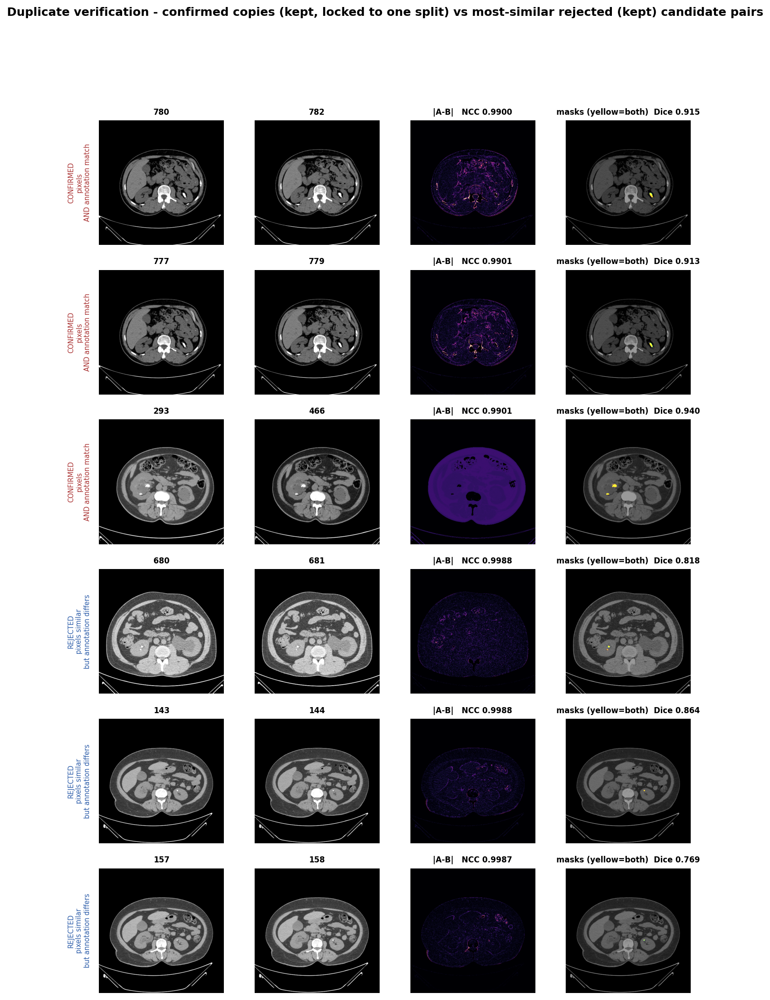

**fig00c_duplicate_hamming_hist.png**

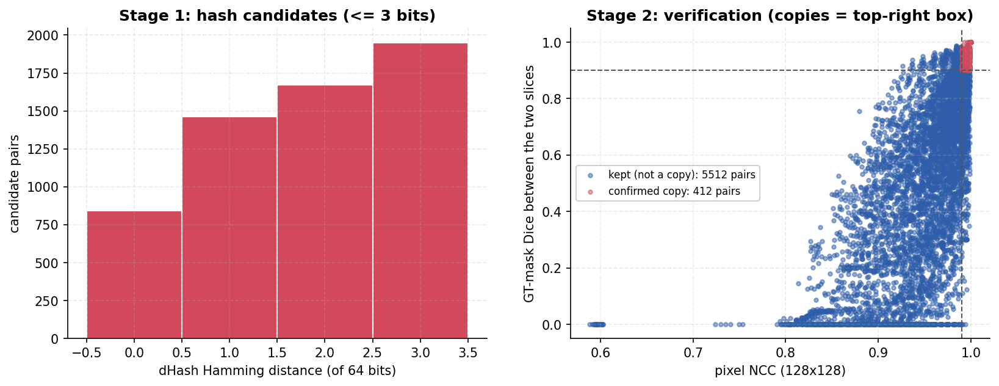

  spot-check sample: 30 candidate pairs -> duplicate_audit.csv + reports/duplicate_audit.pdf
  duplicate check, stage 1 (8x8 dHash <= 3 bits or identical MD5): 5924 candidate pairs touching 837 images; removing all of them ('full') would drop 803 images.
  stage 2 (pixel NCC >= 0.99 AND mask Dice >= 0.9): 7 byte-identical pairs, 405 near pairs CONFIRMED as copies, 5512 near pairs REJECTED (look-alike, not copies - kept and handled by the similarity grouping).
        4520  neither pixels nor annotation match
         769  pixels similar but annotation differs
         405  pixels AND annotation match
         223  annotation similar but pixels differ
  CFG.dedup_mode='group': removing 0 image(s). All images kept; 412 copy pair(s) touching 409 images will be locked into the same split. Check fig00b/fig00c and the spot-check in reports/duplicate_audit.pdf.

                                  metric        value
               images kept for the study          838
      unique filename id

**fig01_stone_size_distribution.png**

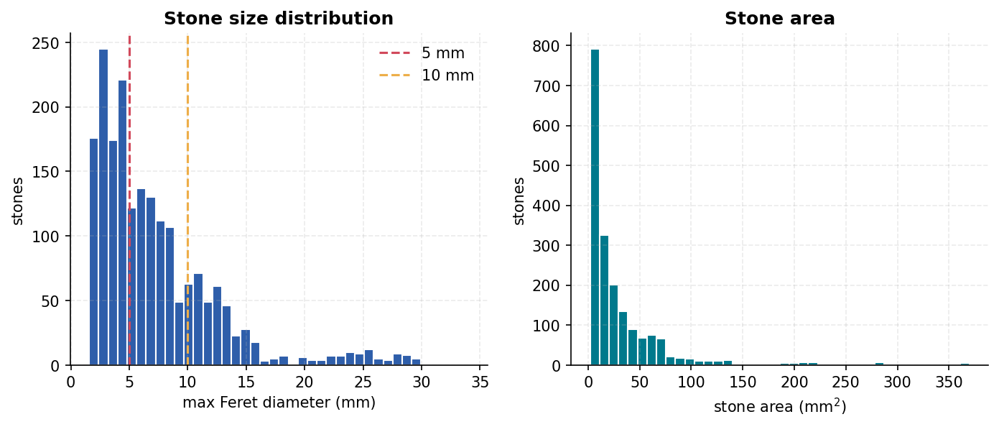

**fig02_class_composition.png**

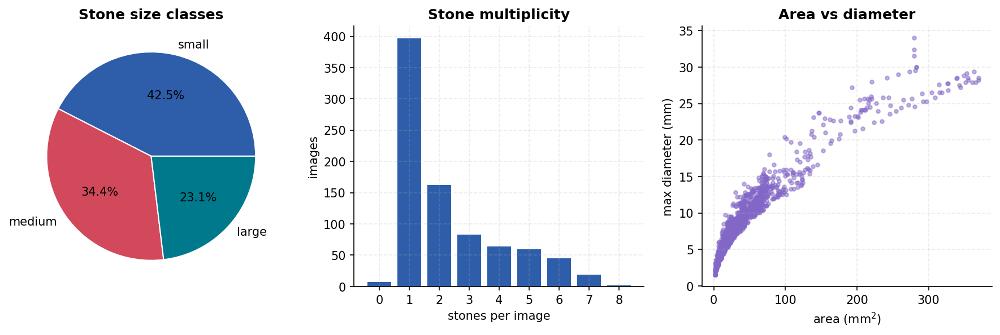

**fig03_shape_descriptors.png**

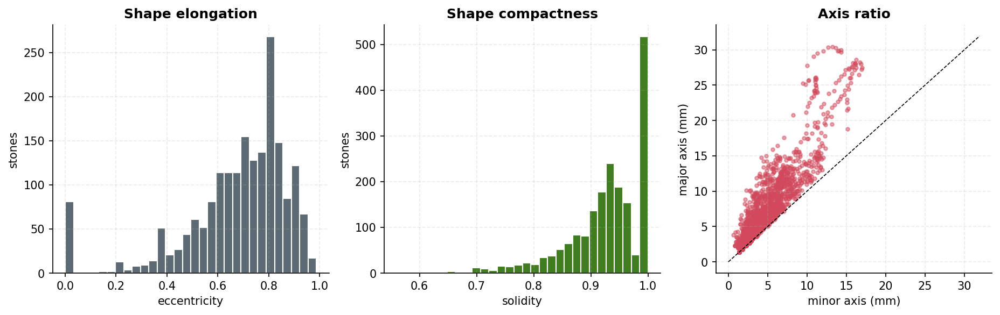

**fig04_imbalance_burden.png**

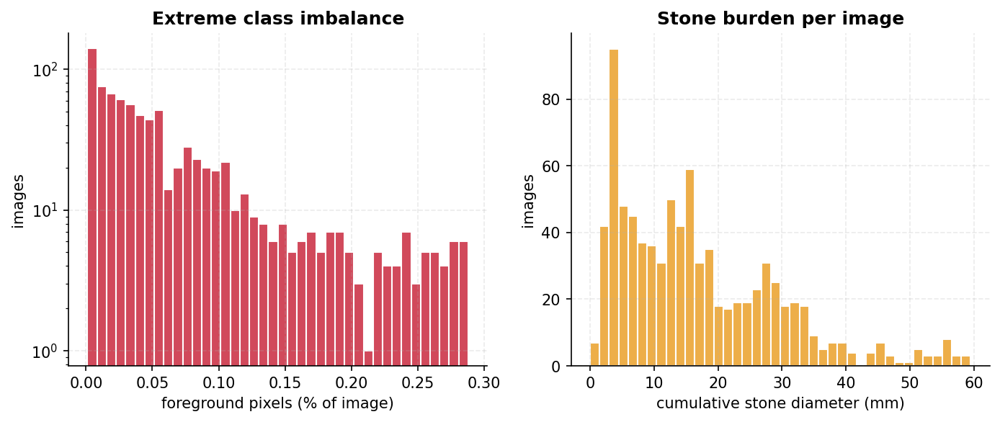

**fig05_intensity_resolution.png**

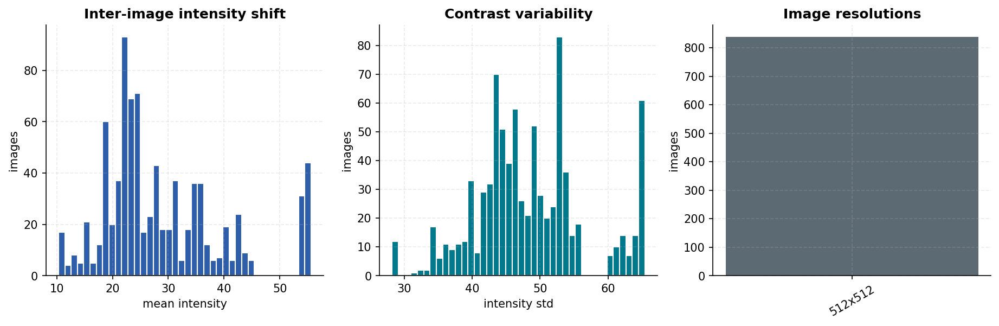

**fig06_sample_overlays.png**

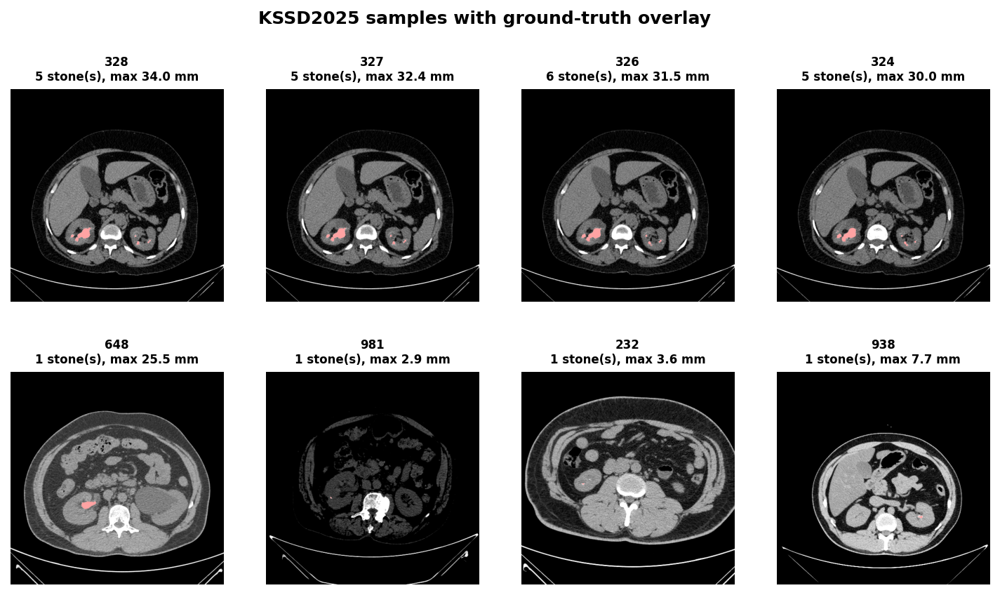


  STEP 1b  similarity-cluster grouping (proxy for patient identity)
  838 thumbnails, 350,703 pairwise NCCs in 7.7s
  [warn] the grouping could not link anything beyond the strictest threshold without exceeding the cap. Inspect grouping_threshold_scan.csv and consider setting CFG.group_ncc_threshold by hand.
  threshold scan around the chosen value (full table: grouping_threshold_scan.csv):
     threshold  n_clusters  largest  n_singletons  images_in_multi
         0.980          39      173             0              838
         0.985          39      173             0              838
         0.990          39      173             0              838
         0.991          40      173             0              838
         0.992          45      173             1              837
         0.993          51      173             5              833
         0.994          60      173            11              827
         0.995          82      173            32              806
  

**fig07b_similarity_grouping.png**

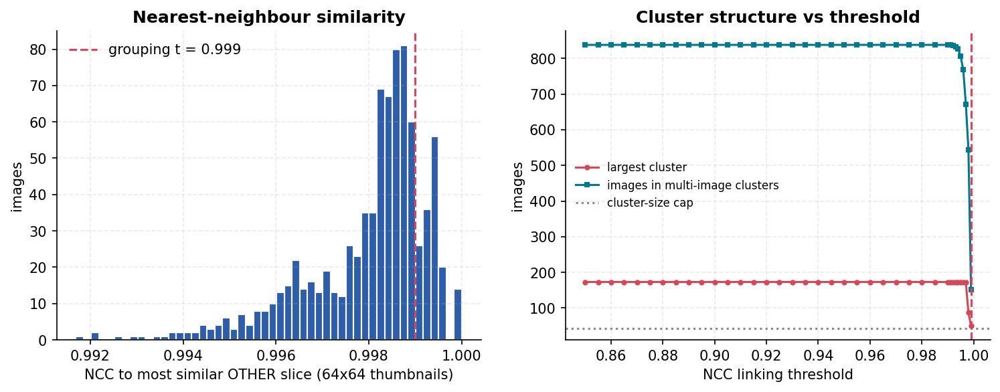

**fig07_patient_structure.png**

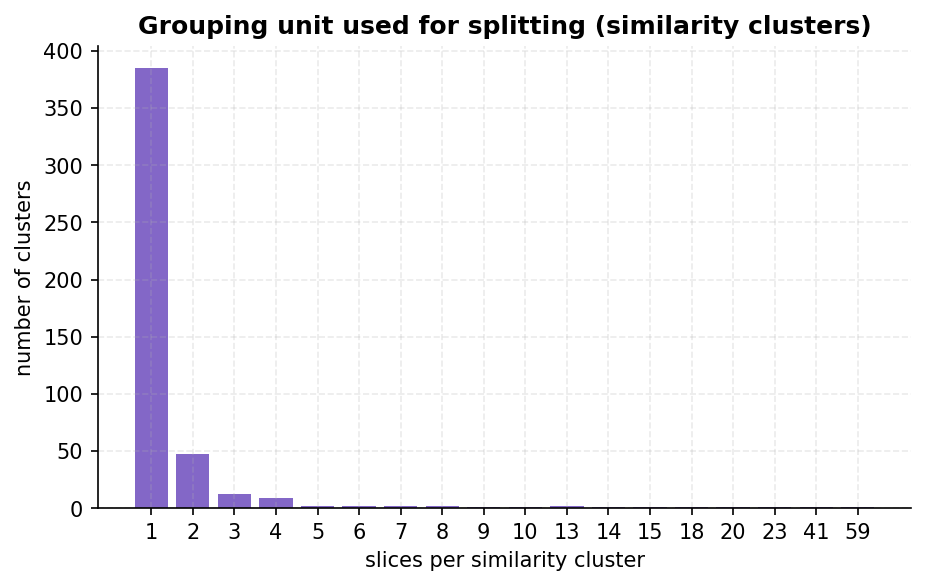


  STEP 4  stratified splitting grouped by 'group_id'
  grouping check passed: no 'group_id' appears in two splits (472 groups)

size_class  large  medium  none  small  images  groups  stones
split                                                         
test           76      38     0     26     140      66     303
train         258     212     7    133     610     354    1448
val            35      29     0     24      88      52     189


**fig08_split_composition.png**

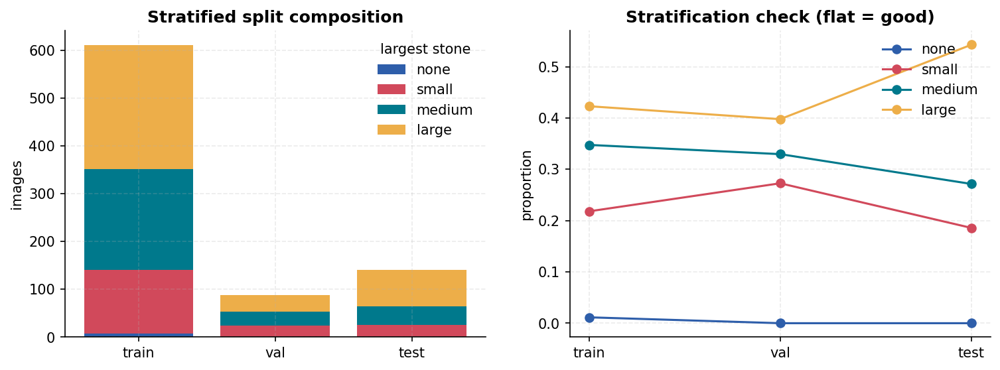

  duplicate-leakage check: 5924 candidate pair(s) still have both slices in the data; 1832 of them span two splits.
         none of those is a confirmed copy (median pixel NCC 0.952); look-alike slices are handled by the similarity grouping (threshold 0.999 at 64x64).
  residual proximity (test -> nearest train image): median NCC 0.995, max 0.999 (grouping threshold 0.999; values >= it would mean the grouping failed)

  STEP 1c  stone-free slices: grouped neg-train / neg-val / neg-test pools
[neg] downloading nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone (large; first run only) ...
Using Colab cache for faster access to the 'ct-kidney-dataset-normal-cyst-tumor-and-stone' dataset.
  Normal     5077 files available
  Cyst       3709 files available
  Tumor      2283 files available
  3600 candidate slices read and thumbnailed in 91.7s
  excluded 0 slice(s) with NCC >= 0.999 to a KSSD2025 slice (possible same scan, could contain a stone)
  threshold scan around the chosen valu

**fig09a_preprocessing.png**

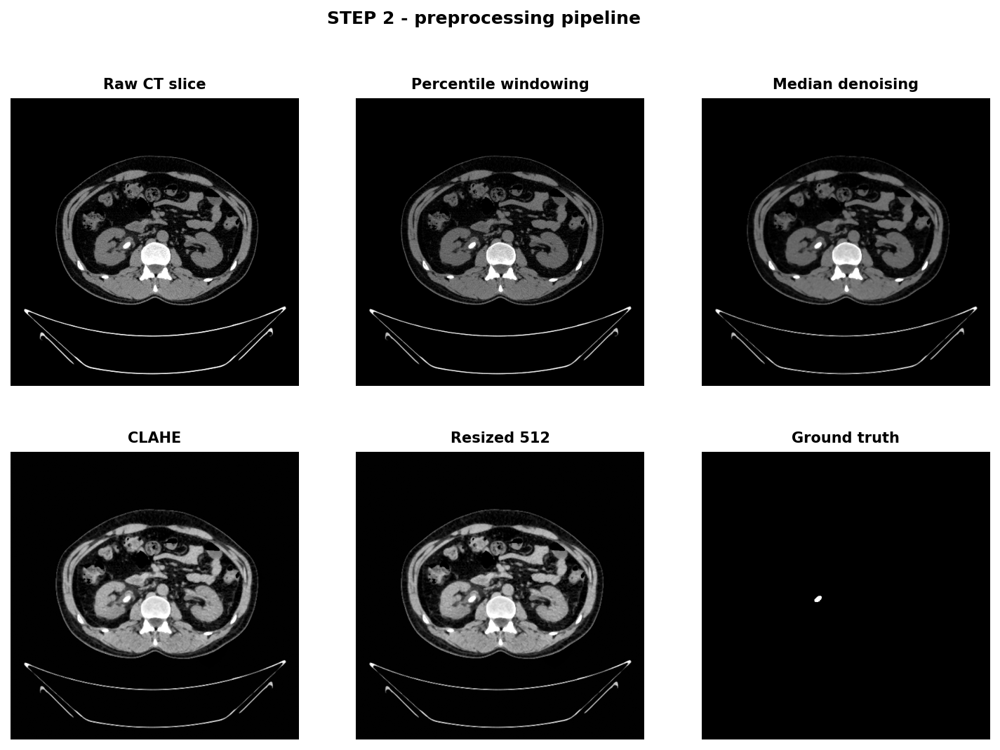

**fig09b_preprocessing_hist.png**

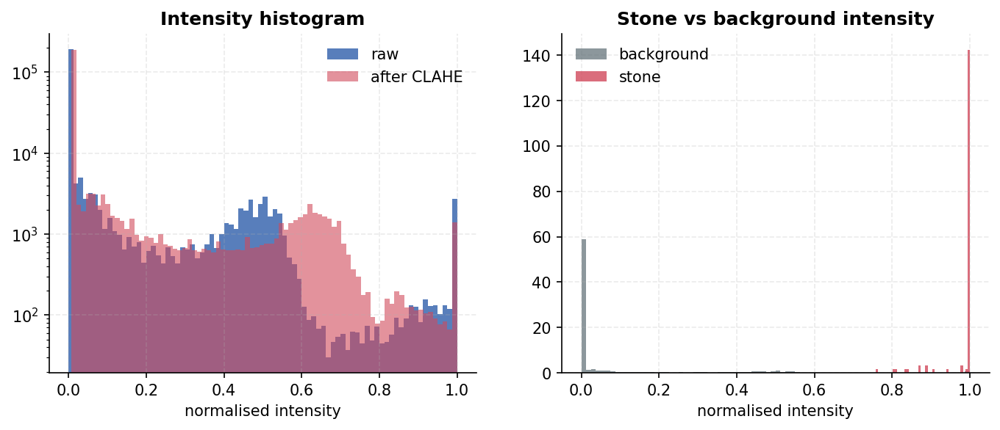

**fig09c_augmentation.png**

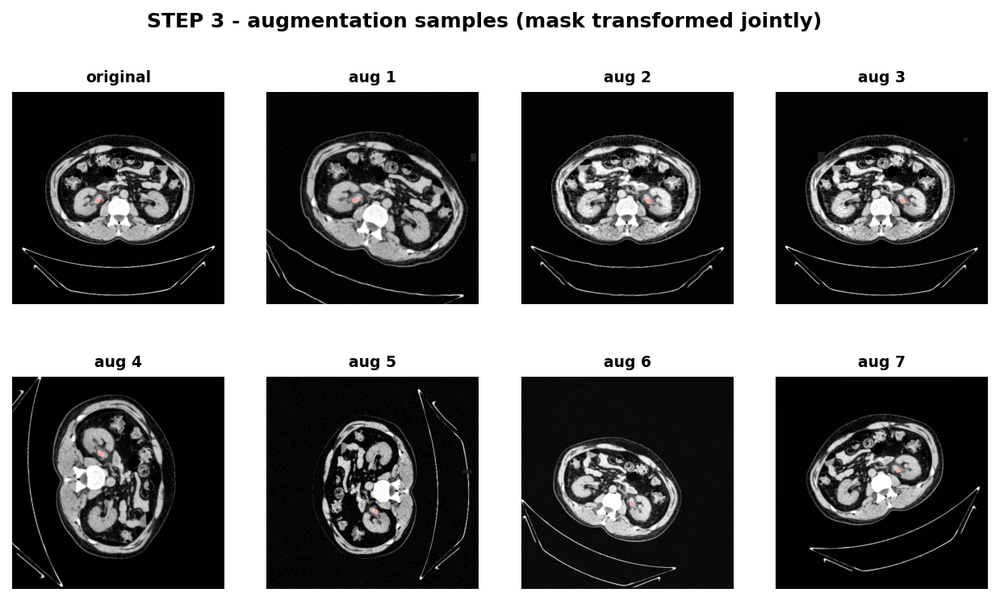


  building data loaders (images are preloaded into RAM)
  [train] preloaded 610 slices + pool of 1762 stone-free slices, 305 drawn per epoch (782 MB) in 53.5s
  [val] preloaded 88 slices (46 MB) in 1.5s
  [test] preloaded 140 slices (73 MB) in 2.5s
  [val_neg] preloaded 88 slices (23 MB) in 2.1s
  presence-head class balancing: pos_weight=0.5000 (from one training epoch's mix; floor=0.1)

  STEP 5  training MSABR-Net (proposed) | 9,951,018 params | 60 epochs | lr=0.0003 | EMA 0.999 | 305 stone-free slices/epoch | cuda
  ep   1/60 | train 2.3652/0.2517 | val 1.6554/0.4697 | neg-val clean 0.784 | score 0.4190 | 105.7s  * best
  ep   2/60 | train 2.2153/0.4380 | val 1.5084/0.5401 | neg-val clean 0.909 | score 0.5156 | 105.4s  * best
  ep   3/60 | train 2.0228/0.5323 | val 1.3474/0.6592 | neg-val clean 0.909 | score 0.6292 | 109.2s  * best
  ep   4/60 | train 1.8685/0.5685 | val 1.2497/0.7342 | neg-val clean 0.955 | score 0.7175 | 110.4s  * best
  ep   5/60 | train 1.7478/0.5883 | val 1.0

**fig10_history_msabrnet.png**

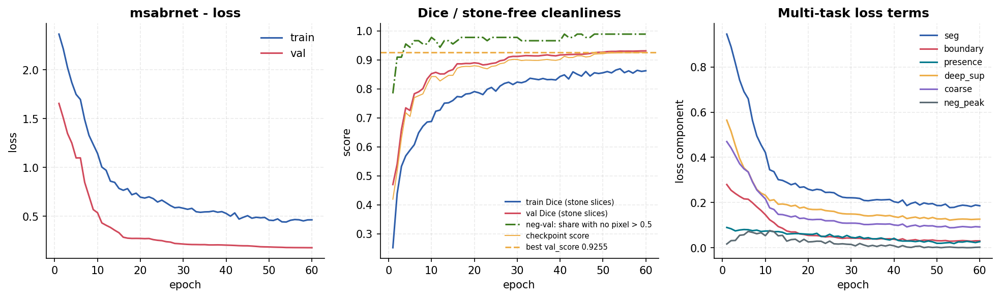

  selected checkpoint: epoch 60 (val Dice 0.9308, neg-val clean 0.989)

  OPERATING POINT  MSABR-Net (proposed)  (validation data only)
  TTA chosen on KSSD validation -> flips   [flips: Dice 0.9376, HD95 2.312 mm, ASSD 0.420 mm (t=0.99) | d4: Dice 0.9375, HD95 2.324 mm, ASSD 0.426 mm (t=0.98)]
  operating-point search for msabrnet: 88 KSSD val slices + 600 neg-val slices predicted in 384s
  validation boundary error: reference HD95 2.312 mm / ASSD 0.420 mm -> chosen HD95 2.312 mm / ASSD 0.419 mm  (criterion 'boundary', TTA flips)
  reference (Dice-only, previous protocol): t=0.99, area>=4px -> val Dice 0.9376, recall 0.9365, neg-val FP rate 0.023
  chosen operating point: t=0.97, area>=4px -> val Dice 0.9375, recall 0.9365, neg-val FP rate 0.023 (95% CI 0.014-0.039, n=600)


**fig26_operating_point_msabrnet.png**

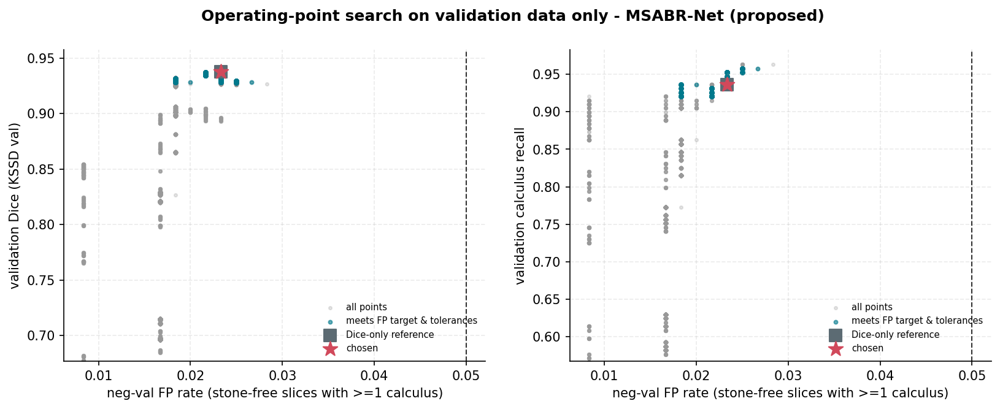

  neg-val false calculi at the chosen point: 14/600 slices from 2 of 33 similarity clusters (largest cluster holds 79% of them; Cyst 14) -> negval_fp_slices_msabrnet.csv
  size measurement chosen on validation (177 matched calculi, 5-fold grouped CV MAE in px): mask 0.451 | retau 0.402 | subpx 0.445 | subpx_cal 0.475 -> 'mask' [binary-mask Feret]; val bias: mask -0.213, retau -0.034, subpx -0.006 px

  STEPS 6-9 + 12  evaluating MSABR-Net (proposed) on the test set
  [info] msabrnet: presence AUC/AP WITHHELD (0 negative test image(s) < CFG.presence_min_neg=5). Reporting a number from this few negatives would be an artefact of the split, not a measurement -- see LIMITATIONS.txt.
  MSABR-Net (proposed) - test set:
    n_test                   140
    operating_point          t=0.97, area>=4px
    op_criterion             boundary
    tta                      flips
    size_method_label        binary-mask Feret
    dice                     0.9508
    dice_ci95                [0.942, 0.958

**fig23_train_proximity_msabrnet.png**

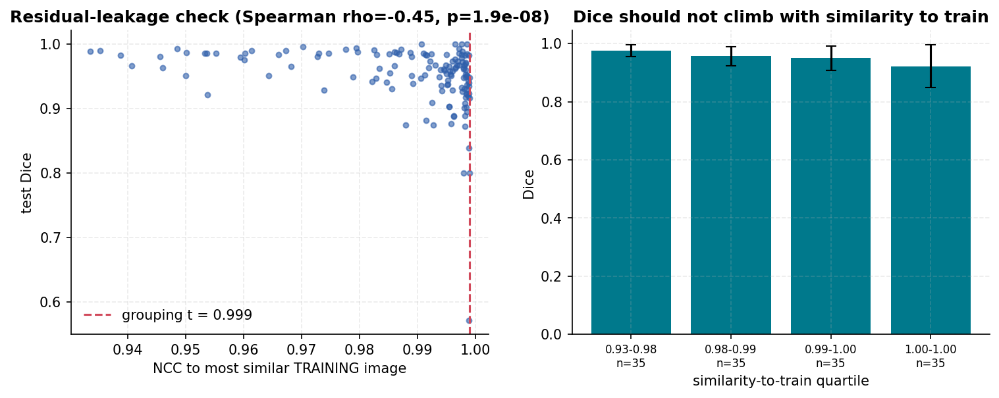

**qualitative_msabrnet.png**

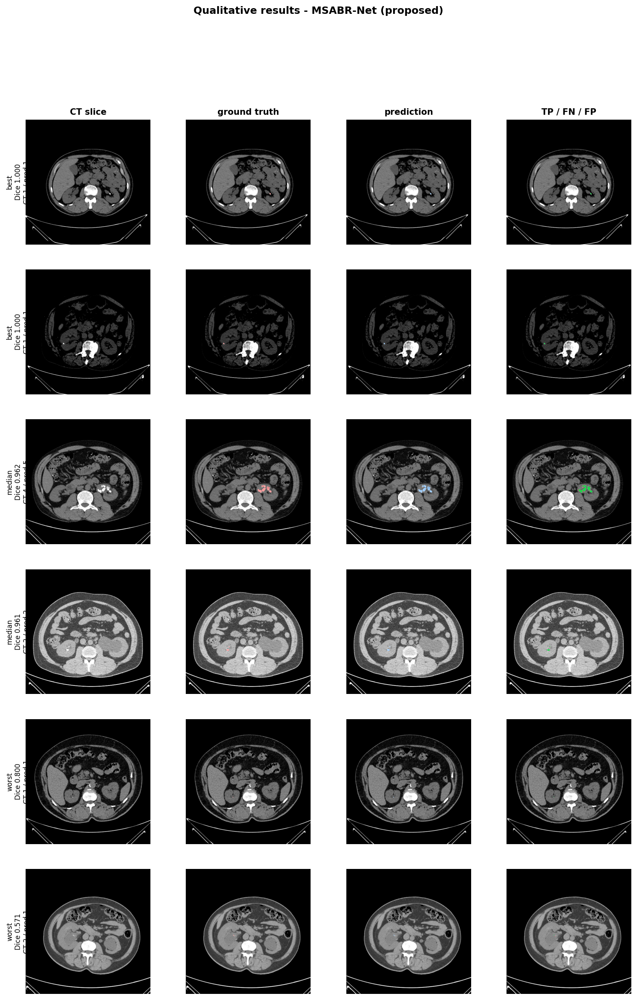

**fig11_segmentation_stats_msabrnet.png**

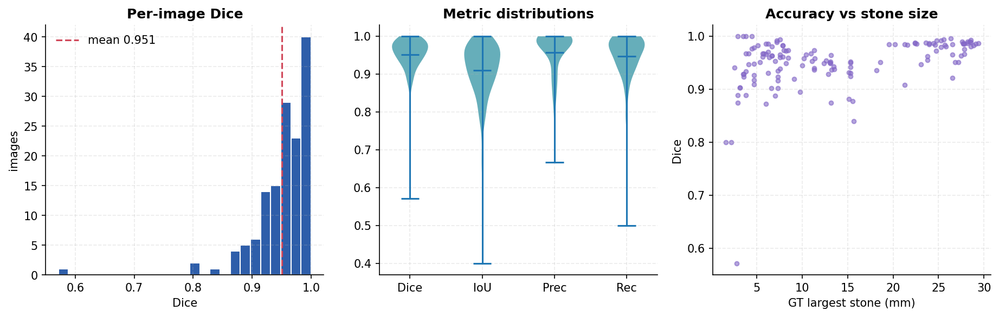

**fig12_error_analysis_msabrnet.png**

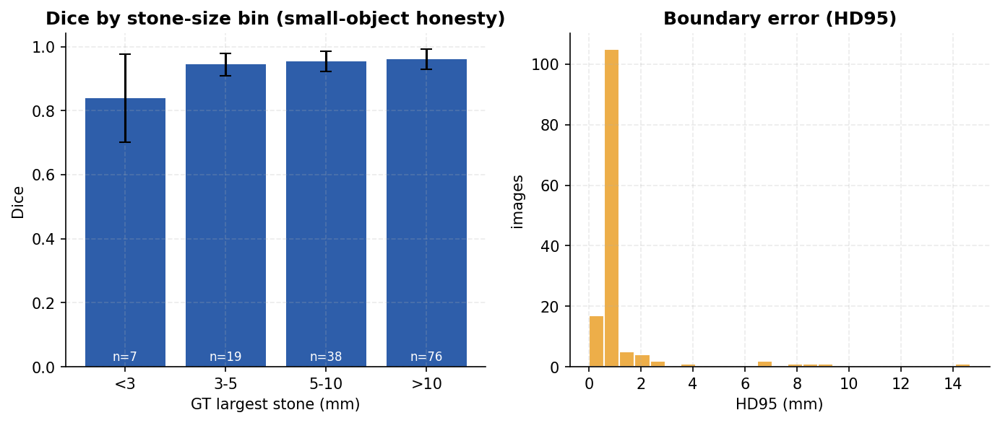

**fig13_detection_msabrnet.png**

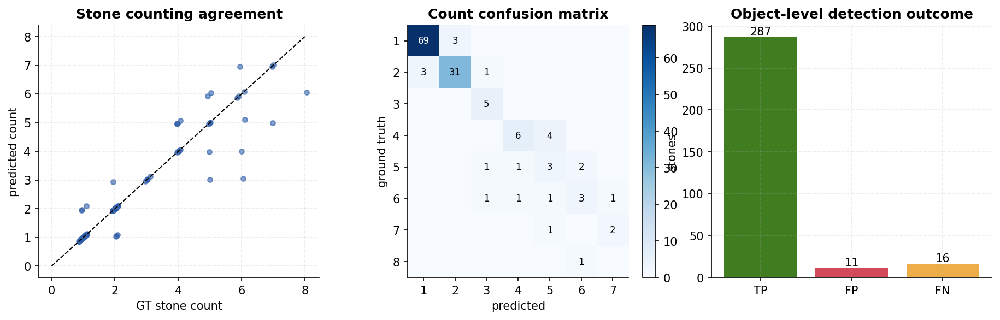

**fig14_size_estimation_msabrnet.png**

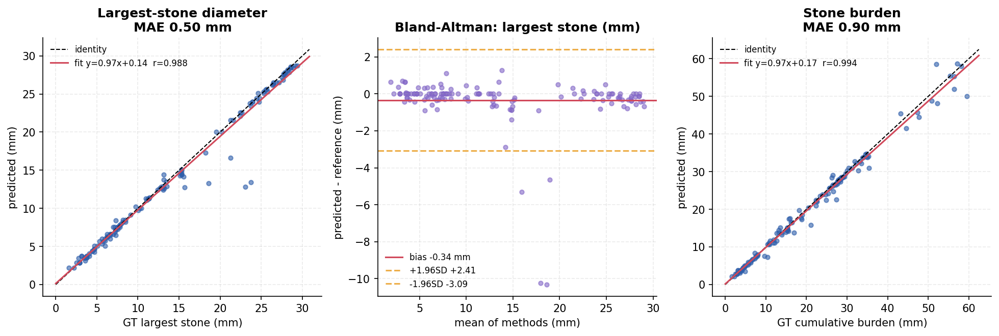

**fig15_per_stone_size_msabrnet.png**

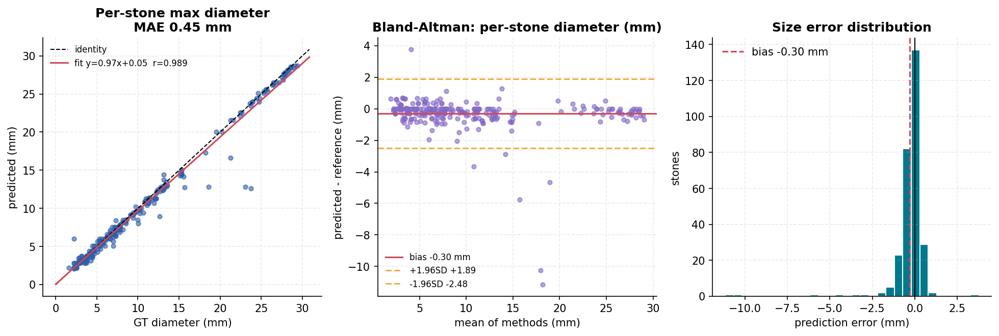

**fig16_severity_msabrnet.png**

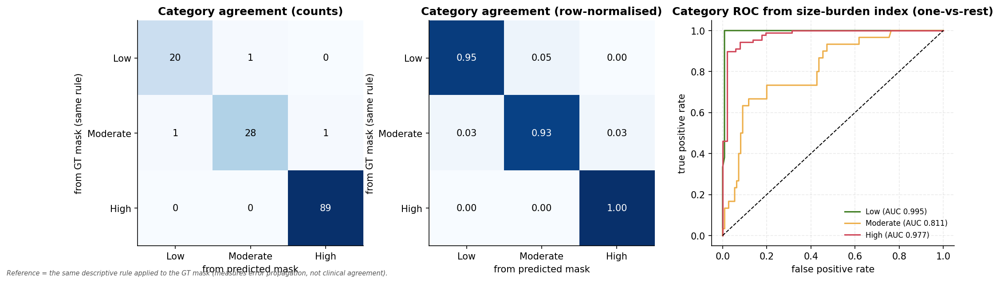

**fig17_size_burden_index_msabrnet.png**

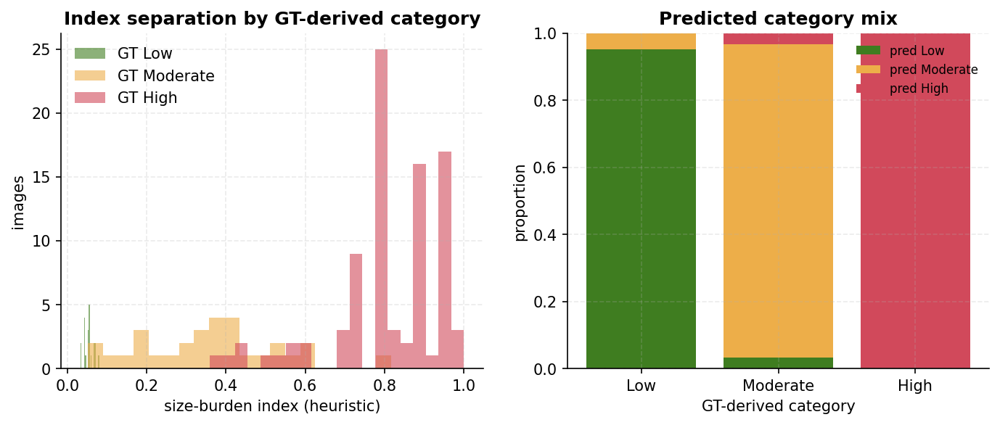


  STEP 10  explainable AI


**xai_1001.png**

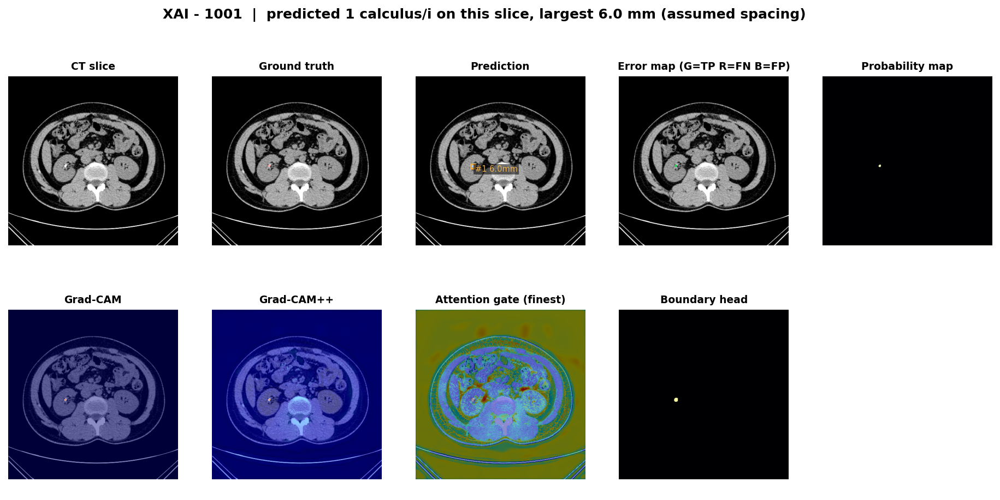

**xai_1002.png**

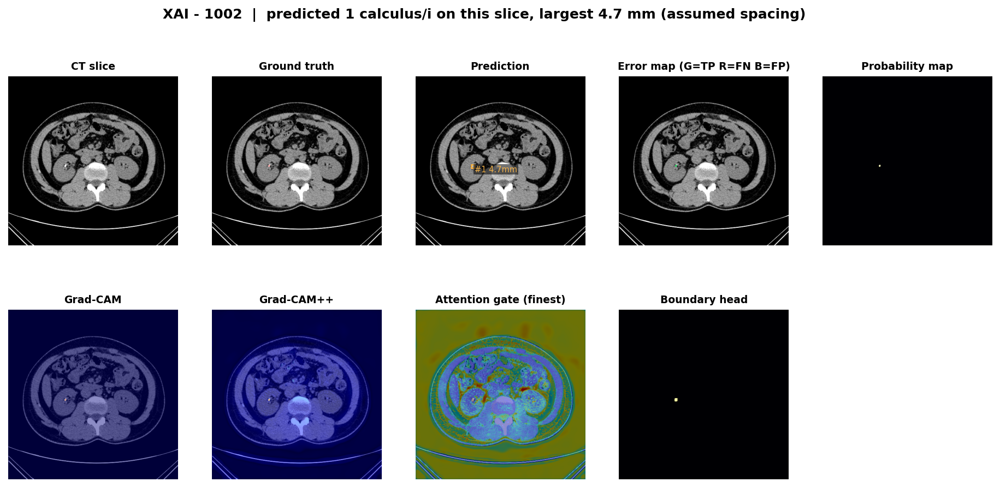

**xai_1023.png**

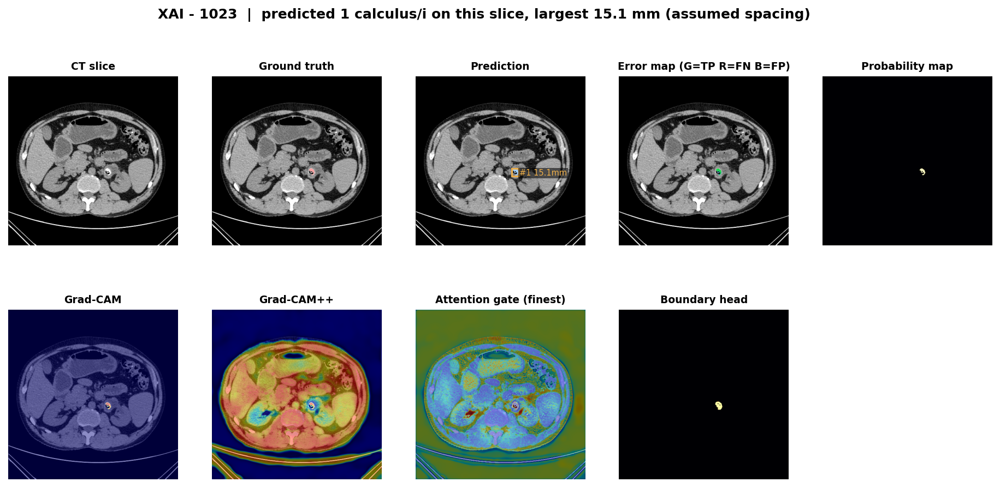

**xai_1028.png**

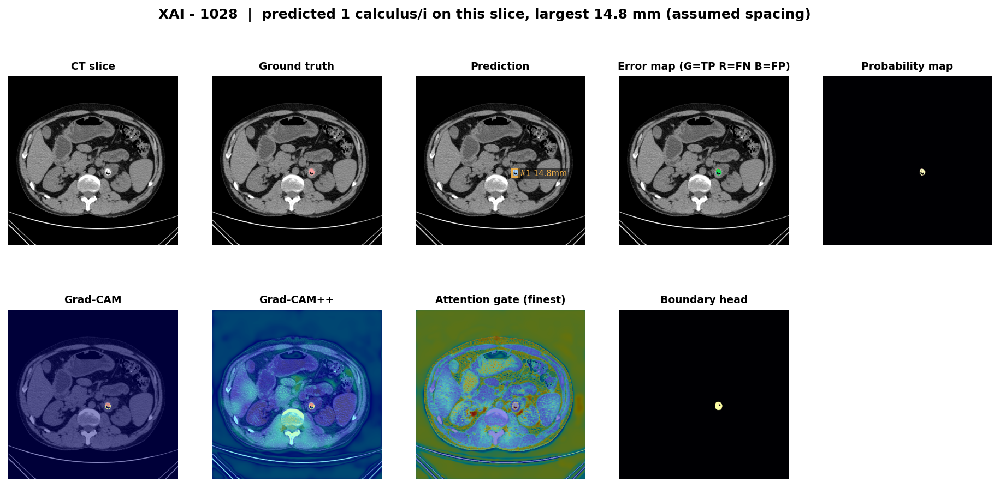

**xai_1029.png**

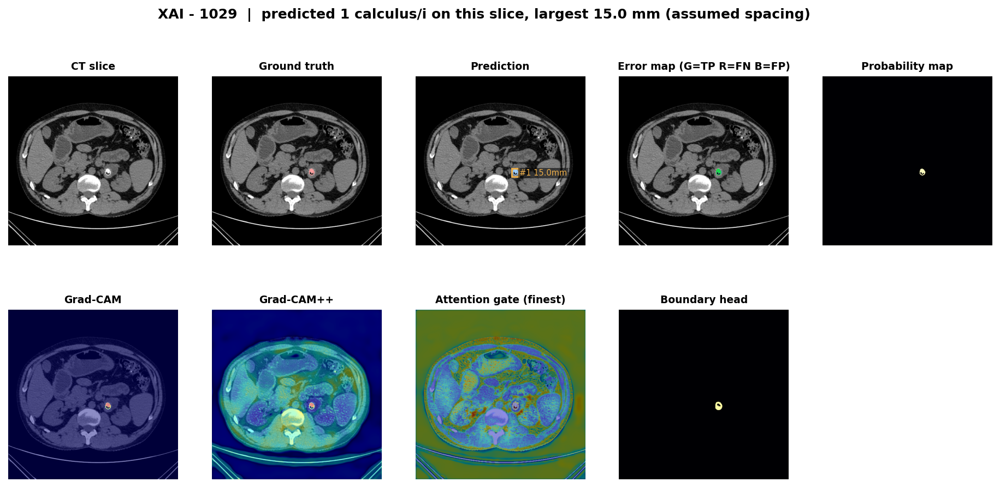

**xai_1030.png**

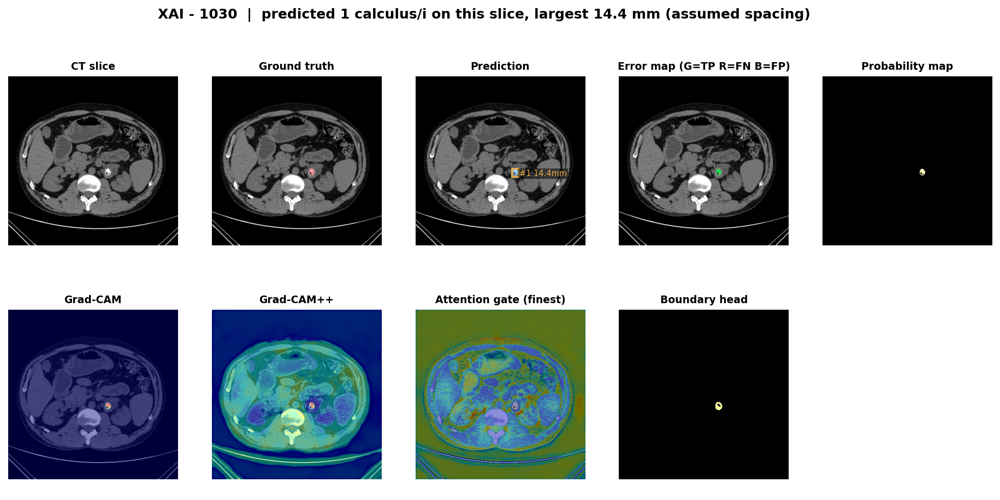

  6 XAI panels -> ./results/figures/xai  [operating point t=0.97, area>=4px]

  STEP 11  automated single-slice measurement reports


**msabrnet_1001.png**

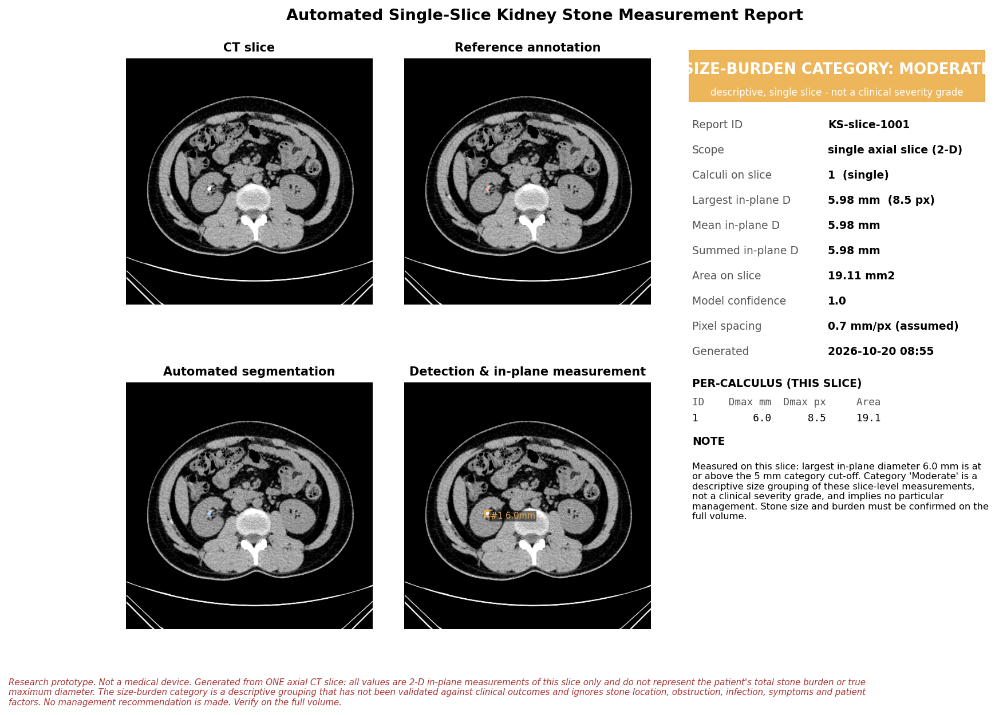

**msabrnet_1002.png**

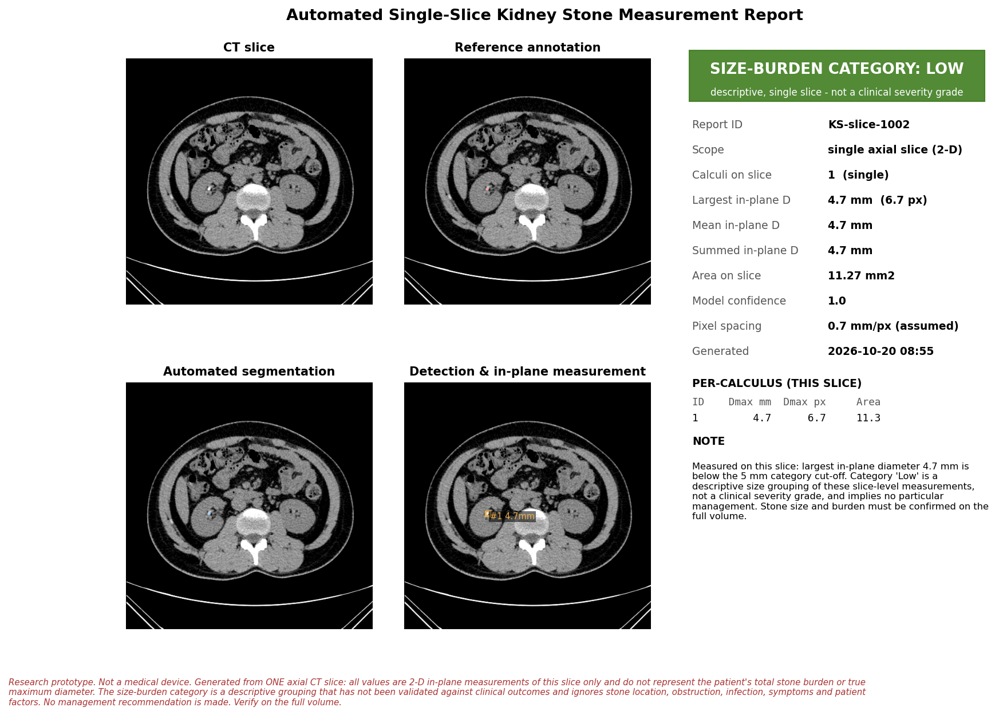

  12 reports (txt/json/png) + combined PDF -> ./results/reports  [operating point t=0.97, area>=4px]
  0/12 report(s) say 'No kidney stone detected'.

   AUTOMATED SINGLE-SLICE KIDNEY STONE MEASUREMENT REPORT
Report ID     : KS-slice-1001
Scope         : single axial slice (2-D)
Generated     : 2026-10-20 08:55
Pixel spacing : 0.7 mm/px  (ASSUMED - not read from DICOM)
Diameter      : binary-mask Feret
------------------------------------------------------------------
RESULT        : KIDNEY STONE DETECTED ON THIS SLICE (1 CALCULUS)
------------------------------------------------------------------
FINDINGS ON THIS SLICE
------------------------------------------------------------------
Calculi on this slice        : 1 (single)
Largest in-plane diameter    : 5.98 mm (8.5 px)  [medium]
Mean in-plane diameter       : 5.98 mm
Summed in-plane diameter     : 5.98 mm
Segmented area on this slice : 19.11 mm^2
------------------------------------------------------------------
PER-CALCULUS MEASU

**msabrnet_stonefree_neg_Normal_Normal_1196.png**

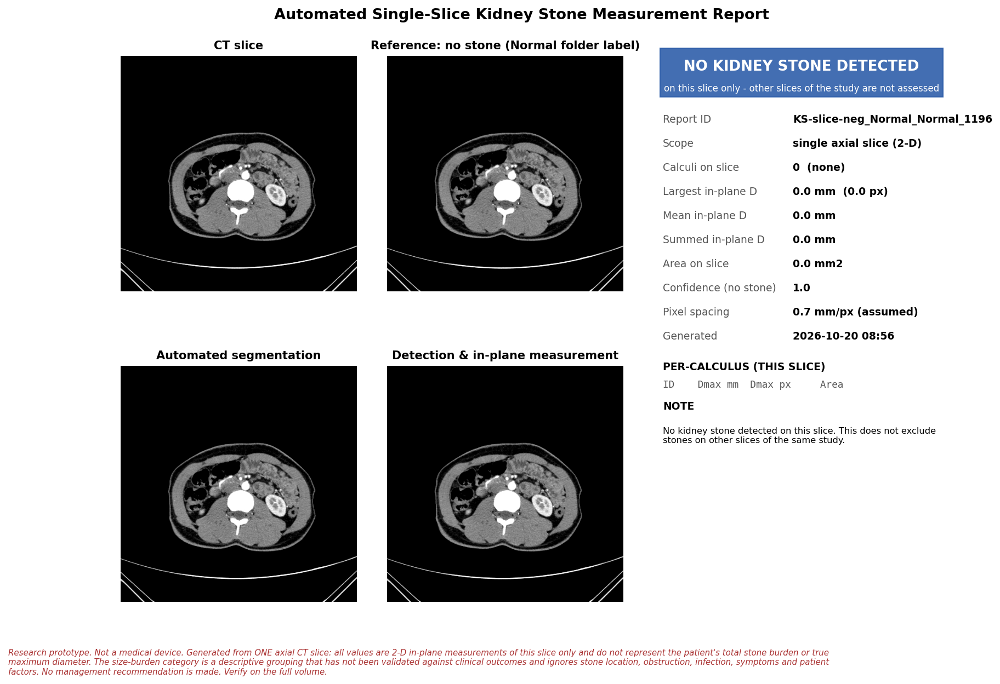

**msabrnet_stonefree_neg_Cyst_Cyst_397.png**

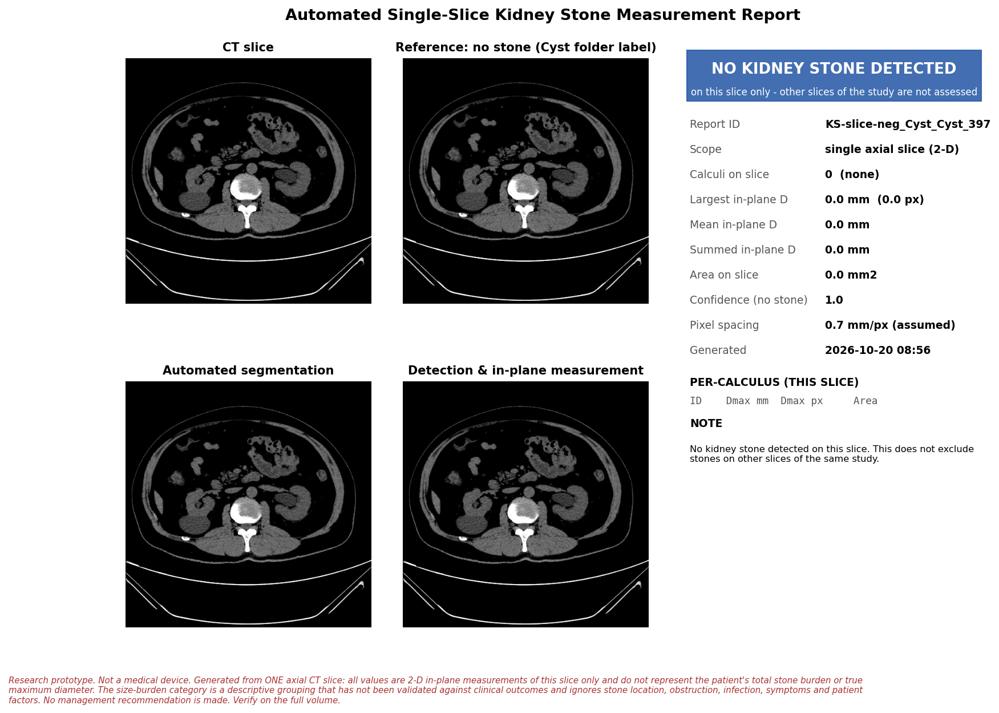

**msabrnet_stonefree_neg_Tumor_Tumor_630.png**

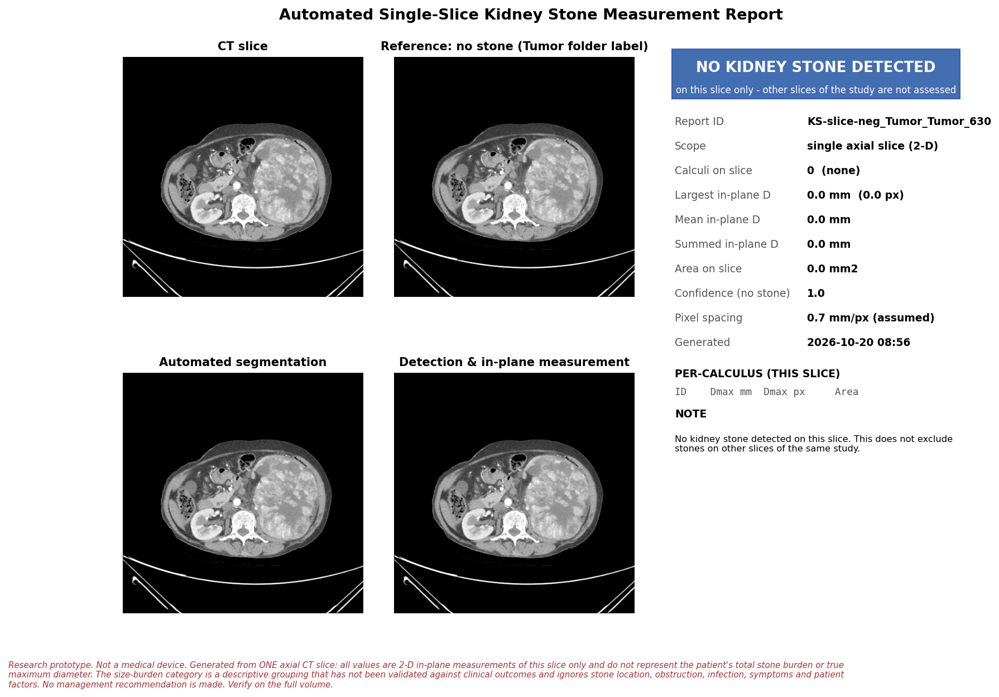

**fig28_stonefree_by_class_msabrnet_stonefree.png**

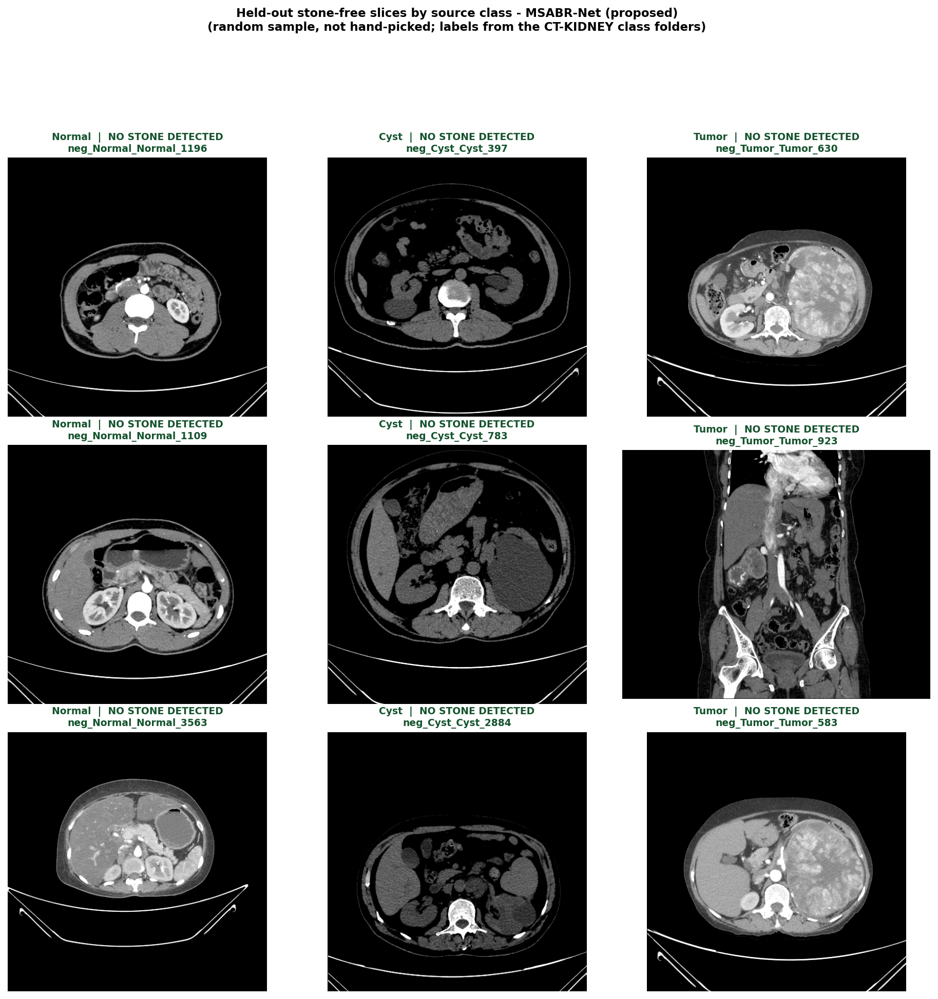

  9 reports (txt/json/png) + combined PDF -> ./results/reports  [operating point t=0.97, area>=4px]
  9/9 report(s) say 'No kidney stone detected'.
    Cyst    3/3 with no stone detected
    Normal  3/3 with no stone detected
    Tumor   3/3 with no stone detected

   AUTOMATED SINGLE-SLICE KIDNEY STONE MEASUREMENT REPORT
Report ID     : KS-slice-neg_Normal_Normal_1196
Scope         : single axial slice (2-D)
Generated     : 2026-10-20 08:56
Pixel spacing : 0.7 mm/px  (ASSUMED - not read from DICOM)
Diameter      : binary-mask Feret
------------------------------------------------------------------
RESULT        : NO KIDNEY STONE DETECTED ON THIS SLICE
Reference     : no stone (Normal folder label)
------------------------------------------------------------------
FINDINGS ON THIS SLICE
------------------------------------------------------------------
Calculi on this slice        : 0 (none)
Largest in-plane diameter    : 0.0 mm (0.0 px)  [none]
Mean in-plane diameter       : 0.0 mm
Su

**fig10_history_unet.png**

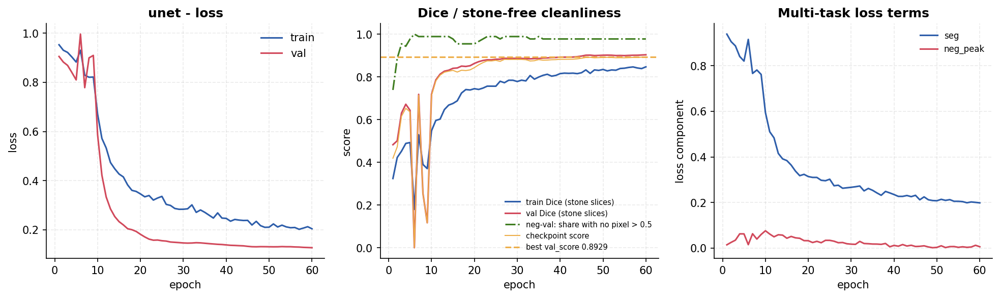

  selected checkpoint: epoch 60 (val Dice 0.9031, neg-val clean 0.977)

  OPERATING POINT  U-Net  (validation data only)
  TTA chosen on KSSD validation -> flips   [flips: Dice 0.9279, HD95 2.331 mm, ASSD 0.469 mm (t=0.99) | d4: Dice 0.9246, HD95 2.672 mm, ASSD 0.458 mm (t=0.98)]
  operating-point search for unet: 88 KSSD val slices + 600 neg-val slices predicted in 290s
  validation boundary error: reference HD95 2.331 mm / ASSD 0.469 mm -> chosen HD95 2.331 mm / ASSD 0.469 mm  (criterion 'boundary', TTA flips)
  reference (Dice-only, previous protocol): t=0.99, area>=4px -> val Dice 0.9279, recall 0.9471, neg-val FP rate 0.028
  chosen operating point: t=0.99, area>=4px -> val Dice 0.9279, recall 0.9471, neg-val FP rate 0.028 (95% CI 0.018-0.045, n=600)
  neg-val false calculi at the chosen point: 17/600 slices from 3 of 33 similarity clusters (largest cluster holds 71% of them; Cyst 17) -> negval_fp_slices_unet.csv
  size measurement chosen on validation (179 matched calculi, 5-fold

**fig10_history_attunet.png**

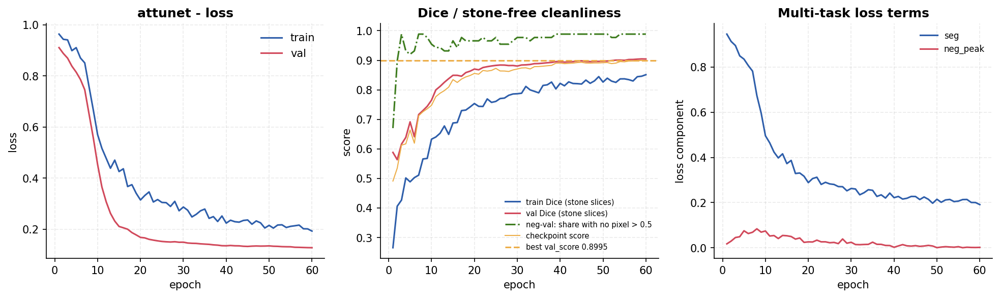

  selected checkpoint: epoch 59 (val Dice 0.9047, neg-val clean 0.989)

  OPERATING POINT  Attention U-Net  (validation data only)
  TTA chosen on KSSD validation -> flips   [flips: Dice 0.9228, HD95 2.524 mm, ASSD 0.409 mm (t=0.99) | d4: Dice 0.9242, HD95 2.667 mm, ASSD 0.432 mm (t=0.99)]
  operating-point search for attunet: 88 KSSD val slices + 600 neg-val slices predicted in 312s
  validation boundary error: reference HD95 2.524 mm / ASSD 0.409 mm -> chosen HD95 2.395 mm / ASSD 0.403 mm  (criterion 'boundary', TTA flips)
  reference (Dice-only, previous protocol): t=0.99, area>=4px -> val Dice 0.9228, recall 0.9630, neg-val FP rate 0.027
  chosen operating point: t=0.98, area>=4px -> val Dice 0.9218, recall 0.9683, neg-val FP rate 0.027 (95% CI 0.016-0.043, n=600)
  neg-val false calculi at the chosen point: 16/600 slices from 2 of 33 similarity clusters (largest cluster holds 75% of them; Cyst 16) -> negval_fp_slices_attunet.csv
  size measurement chosen on validation (182 matched

**fig10_history_unetpp.png**

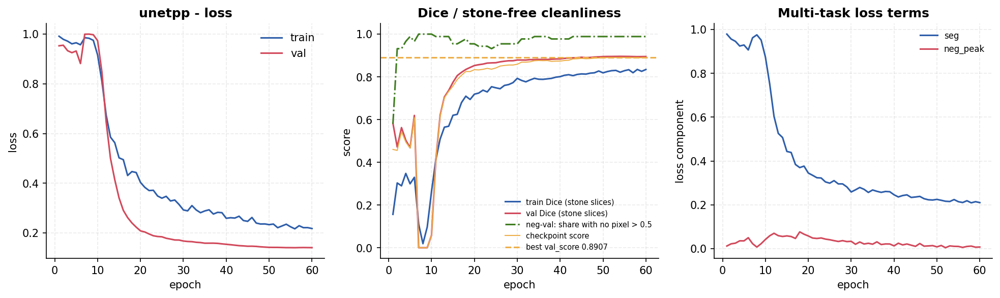

  selected checkpoint: epoch 54 (val Dice 0.8958, neg-val clean 0.989)

  OPERATING POINT  U-Net++  (validation data only)
  TTA chosen on KSSD validation -> flips   [flips: Dice 0.9127, HD95 2.587 mm, ASSD 0.531 mm (t=0.97) | d4: Dice 0.9135, HD95 2.853 mm, ASSD 0.556 mm (t=0.97)]
  operating-point search for unetpp: 88 KSSD val slices + 600 neg-val slices predicted in 487s
  validation boundary error: reference HD95 2.587 mm / ASSD 0.531 mm -> chosen HD95 2.462 mm / ASSD 0.475 mm  (criterion 'boundary', TTA flips)
  reference (Dice-only, previous protocol): t=0.97, area>=4px -> val Dice 0.9127, recall 0.9312, neg-val FP rate 0.027
  chosen operating point: t=0.90, area>=4px -> val Dice 0.9086, recall 0.9524, neg-val FP rate 0.028 (95% CI 0.018-0.045, n=600)
  neg-val false calculi at the chosen point: 17/600 slices from 3 of 33 similarity clusters (largest cluster holds 65% of them; Cyst 15, Tumor 2) -> negval_fp_slices_unetpp.csv
  size measurement chosen on validation (180 matched 

**fig10_history_resunet.png**

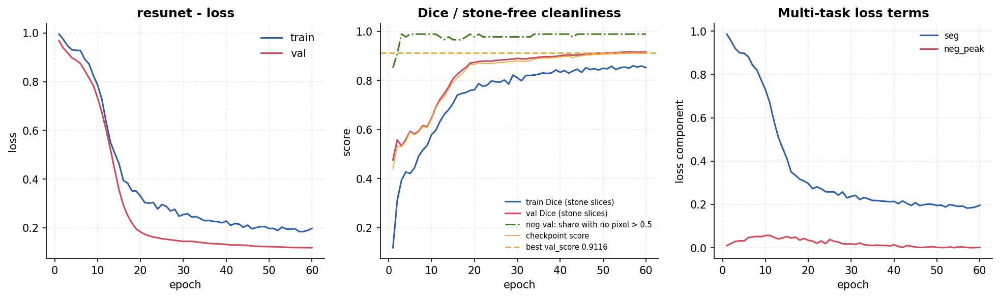

  selected checkpoint: epoch 60 (val Dice 0.9168, neg-val clean 0.989)

  OPERATING POINT  ResU-Net  (validation data only)
  TTA chosen on KSSD validation -> flips   [flips: Dice 0.9316, HD95 2.478 mm, ASSD 0.399 mm (t=0.99) | d4: Dice 0.9317, HD95 2.513 mm, ASSD 0.407 mm (t=0.97)]
  operating-point search for resunet: 88 KSSD val slices + 600 neg-val slices predicted in 313s
  validation boundary error: reference HD95 2.478 mm / ASSD 0.399 mm -> chosen HD95 2.354 mm / ASSD 0.386 mm  (criterion 'boundary', TTA flips)
  reference (Dice-only, previous protocol): t=0.99, area>=4px -> val Dice 0.9316, recall 0.9365, neg-val FP rate 0.023
  chosen operating point: t=0.90, area>=4px -> val Dice 0.9279, recall 0.9630, neg-val FP rate 0.025 (95% CI 0.015-0.041, n=600)
  neg-val false calculi at the chosen point: 15/600 slices from 3 of 33 similarity clusters (largest cluster holds 73% of them; Cyst 15) -> negval_fp_slices_resunet.csv
  size measurement chosen on validation (180 matched calcul

**fig10_history_transunet.png**

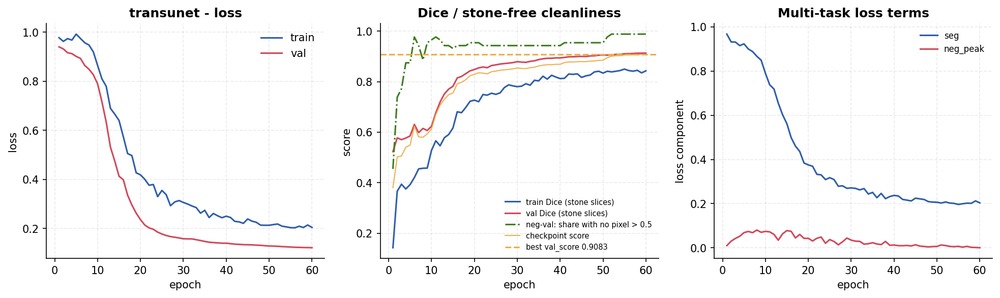

  selected checkpoint: epoch 60 (val Dice 0.9134, neg-val clean 0.989)

  OPERATING POINT  TransUNet-lite  (validation data only)
  TTA chosen on KSSD validation -> flips   [flips: Dice 0.9300, HD95 2.505 mm, ASSD 0.452 mm (t=0.9) | d4: Dice 0.9321, HD95 2.521 mm, ASSD 0.451 mm (t=0.95)]
  operating-point search for transunet: 88 KSSD val slices + 600 neg-val slices predicted in 266s
  validation boundary error: reference HD95 2.505 mm / ASSD 0.452 mm -> chosen HD95 1.132 mm / ASSD 0.368 mm  (criterion 'boundary', TTA flips)
  reference (Dice-only, previous protocol): t=0.90, area>=4px -> val Dice 0.9300, recall 0.9365, neg-val FP rate 0.025
  chosen operating point: t=0.80, area>=8px -> val Dice 0.9269, recall 0.9206, neg-val FP rate 0.020 (95% CI 0.011-0.035, n=600)
  neg-val false calculi at the chosen point: 12/600 slices from 2 of 33 similarity clusters (largest cluster holds 83% of them; Cyst 12) -> negval_fp_slices_transunet.csv
  size measurement chosen on validation (174 match

**fig19_comparison_bars.png**

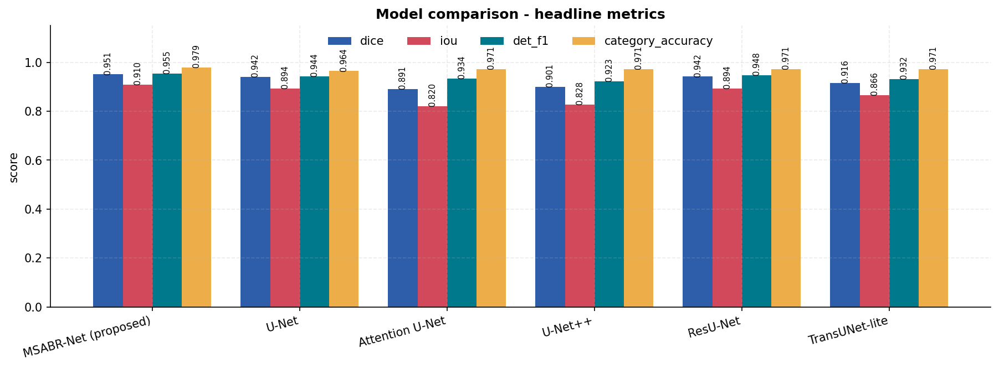

**fig20_comparison_radar.png**

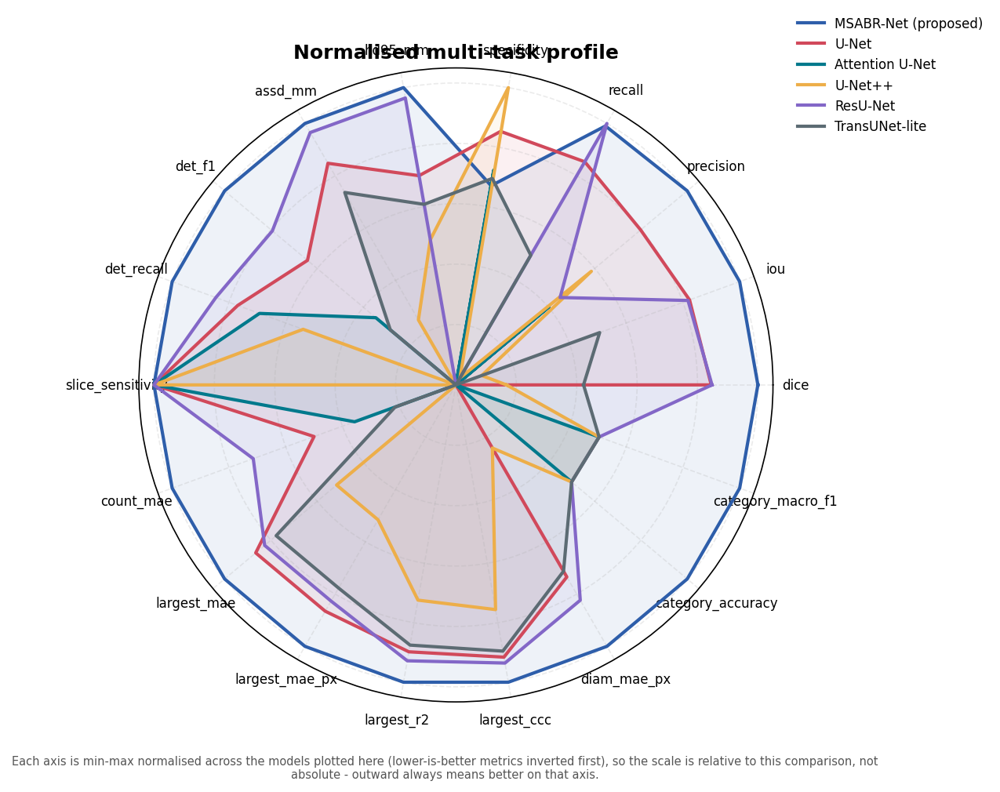

**fig21_dice_boxplot.png**

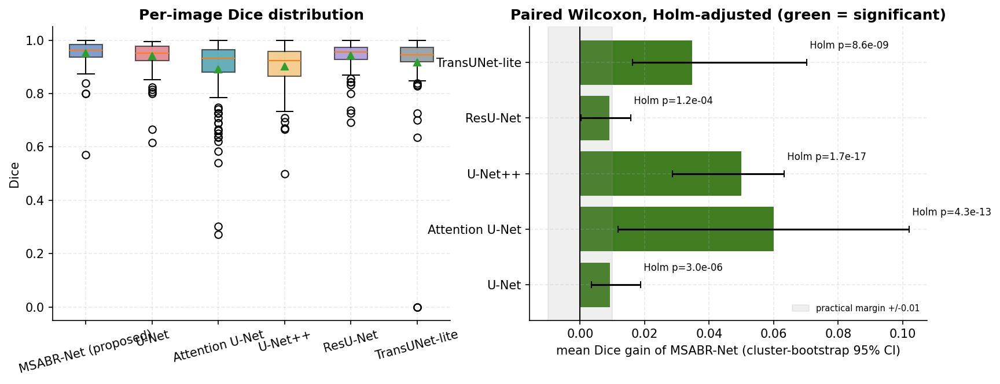


  held-out stone-free slices (neg-test), all models - same weights at two operating points:
    model  n_negative         ref_fp      chosen_fp  val_fp_rate  test_ref_dice  test_dice  test_slice_sensitivity  test_det_recall
 msabrnet         709 0.0% [0.0-0.5] 0.1% [0.0-0.8]       0.0233         0.9478     0.9508                  1.0000           0.9472
     unet         709 0.6% [0.2-1.4] 0.6% [0.2-1.4]       0.0283         0.9416     0.9416                  1.0000           0.9373
  attunet         709 0.3% [0.1-1.0] 0.4% [0.1-1.2]       0.0267         0.8740     0.8908                  1.0000           0.9340
   unetpp         709 0.1% [0.0-0.8] 0.4% [0.1-1.2]       0.0283         0.8779     0.9009                  1.0000           0.9274
  resunet         709 0.0% [0.0-0.5] 0.0% [0.0-0.5]       0.0250         0.9347     0.9417                  1.0000           0.9406
transunet         709 0.0% [0.0-0.5] 0.0% [0.0-0.5]       0.0200         0.9190     0.9162                  0.9786 

**fig25_external_negatives.png**

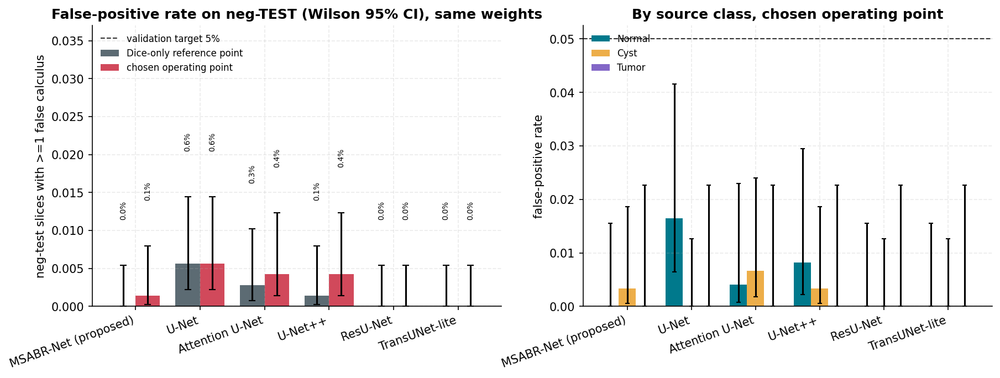


  source-shortcut audit (slice-level detection rate):
    model  kssd_test_slice_sensitivity  n_kssd_test_pos  n_jpeg_twins  jpeg_twin_detection_rate  tif_twin_detection_rate  twin_agreement  n_novel_stone_slices  novel_detection_rate  novel_detection_ci_low  novel_detection_ci_high  novel_det_Q1  novel_det_Q2  novel_det_Q3  novel_det_Q4  twin_drop  novel_drop_vs_kssd  max_drop_vs_kssd  shortcut_flag  novel_needs_review
 msabrnet                       1.0000              140           143                     0.986                    1.000           0.986                   400                0.1350                  0.1050                   0.1720          0.00          0.13          0.18          0.23      0.014              0.8650            0.8650          False                True
     unet                       1.0000              140           143                     0.993                    1.000           0.993                   400                0.4600                  0.4118 

**fig29_stonefree_margin.png**

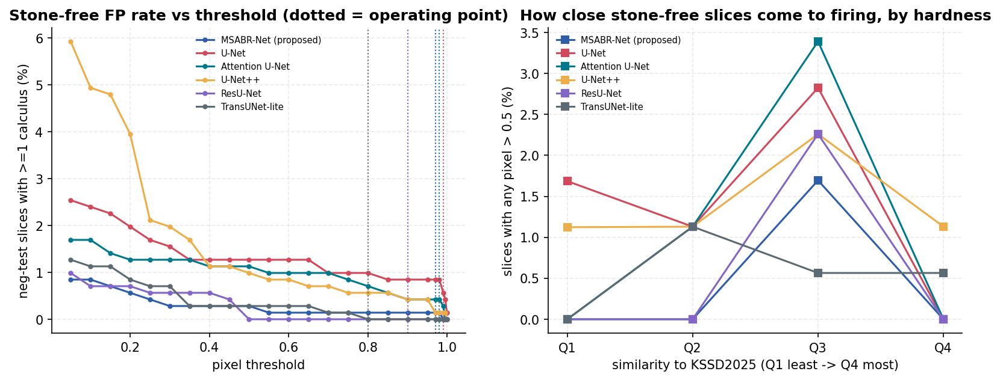


  SIZE AGREEMENT (pixels; mm = px x assumed spacing)
               model size_method  largest_mae_px  largest_medae_px  largest_bias_px  largest_r2  largest_ccc  v3_mask_largest_mae_px  v3_mask_largest_r2  stone_mae_px  stone_r2  stone_ccc  v3_mask_stone_mae_px  burden_mae_px  burden_r2  slices_detection_driven  sse_share_detection  largest_mae_px_boundary_only  largest_r2_boundary_only  merged_predictions  split_gt
MSABR-Net (proposed)        mask          0.7102            0.2955          -0.4839      0.9740       0.9867                  0.7102              0.9740        0.6457    0.9771     0.9883                0.6457         1.2802     0.9869                        7               0.4649                        0.5644                    0.9855                   1         5
               U-Net        mask          1.0253            0.4142          -0.7757      0.9532       0.9759                  1.0253              0.9532        0.9440    0.9563     0.9775                0.9440 

**fig22_capability_matrix.png**

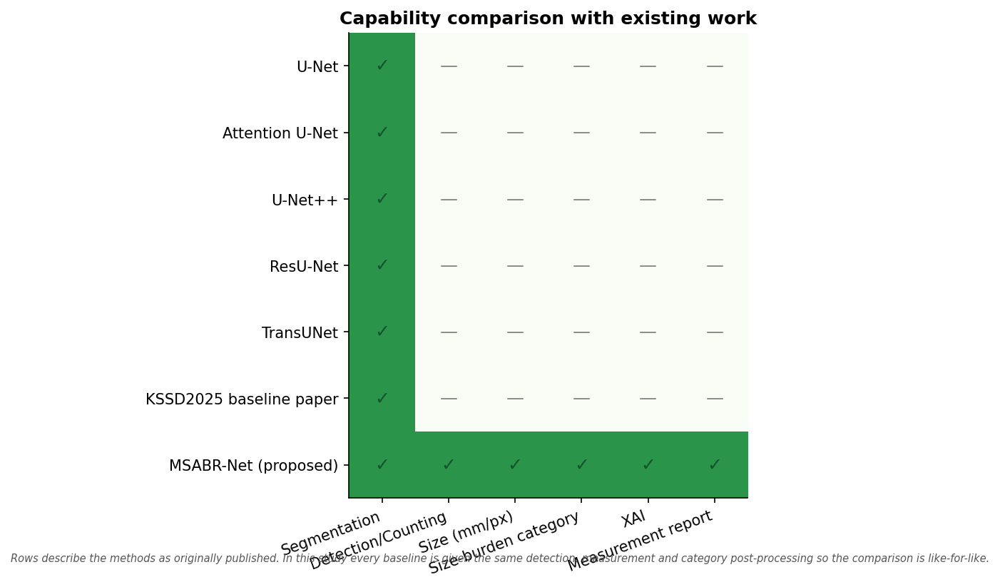


               Model  Params_M  Inference_s     FPS
MSABR-Net (proposed)    9.9510       0.0865 11.5607
               U-Net    7.8490       0.0677 14.7819
     Attention U-Net    7.9808       0.0708 14.1319
             U-Net++    2.2339       0.1320  7.5745
            ResU-Net    8.3979       0.0762 13.1161
      TransUNet-lite    4.3843       0.0605 16.5200

  spacing sensitivity of threshold-based outputs (assumed spacing 0.7 mm/px):
 spacing_mm  largest_mae_mm  largest_within_1mm  gt_Low  gt_Moderate  gt_High  frac_gt_category_differs_from_assumed  category_agreement  category_kappa
        0.5          0.3551              0.9643      27           30       83                                 0.0857              0.9643          0.9366
        0.6          0.4261              0.9500      25           28       87                                 0.0429              0.9857          0.9736
        0.7          0.4972              0.9429      21           30       89                    

In [ ]:
#!/usr/bin/env python
# -*- coding: utf-8 -*-
"""
================================================================================
KIDNEY STONE CT ANALYSIS FRAMEWORK -- KSSD2025 -- MSABR-Net -- SINGLE-FILE EDITION
================================================================================
Segmentation -> detection -> counting -> in-plane size (mm and px) -> slice-level
burden -> descriptive size-burden category -> explainable AI -> single-slice
measurement report -> benchmark against five baselines.

HOW TO RUN (Google Colab)
    Runtime > Change runtime type > T4 GPU. Paste this file into one cell and run
    it, or upload it and run  !python kssd2025_msabr_net.py
    First run with CFG.QUICK = True (2 epochs, 128 px) to confirm the download and
    the image/mask pairing, then set it back to False for the real run.
    Run time on a T4: stone-free training slices make each epoch ~1.5x longer, so
    MSABR-Net alone takes ~2-2.5 h and all six models ~9 h. To see the proposed
    model's false-positive result first, set CFG.run_baselines = False; then run
    the baselines (same settings) before quoting any comparison.

DATA
    The script downloads the real dataset with kagglehub
    ("murillobouzon/kssd2025-kidney-stone-segmentation-dataset"), offering a
    kaggle.json upload if credentials are missing, and reuses an existing copy
    (Kaggle input or kagglehub cache). Set CFG.data_root to use a local copy.
    There is no synthetic fallback. Keep the original TIF files: TIF and PNG are
    lossless; never convert to JPEG (its block artefacts corrupt exactly the
    stone boundaries this project measures, and turn binary masks into grey).

OUTPUTS (./results, zipped at the end; tables/reports carry a run tag)
    figures/      numbered figures, qualitative panels, XAI panels
    tables/       dataset stats, splits, per-image metrics, comparisons, tests
    reports/      single-slice report cards (.txt/.json/.png/.pdf), duplicate audit
    checkpoints/  best (EMA) weights per model
    predictions/  probability + binary masks per evaluated slice (.npz)
    LIMITATIONS.txt  every caveat this run triggered, with its numbers

HOW EACH REVIEWER-2 COMMENT IS ADDRESSED IN THE CODE
    #1 No patient IDs / leakage. Splits are grouped by image-similarity cluster
       (NCC of 64x64 thumbnails; connected components above an automatically
       chosen threshold) with StratifiedGroupKFold, so near-identical slices never
       straddle train and test. Residual train-test similarity is measured per test
       slice and Dice is checked against it (train_proximity.csv, fig23).
       Duplicates: nothing is removed (CFG.dedup_mode="group"); byte-identical and
       verified copies are locked into one split; dice_unique_slices counts each
       copied slice once. This is a proxy, not patient-level independence.
    #2 Assumed pixel spacing. Every size result is also reported in pixels (*_px);
       spacing_sensitivity_*.csv restates mm results over 0.50-1.00 mm/px;
       spacing_category_sensitivity_*.csv shows how many slices change category.
       Optional validation on DICOM with real PixelSpacing: CFG.external_paired_root.
    #3 Categories. "Size-burden category" is a descriptive grouping, not a
       validated severity grade; reports make no management, passage or MET
       statement; the heuristic index is hidden; category_scheme_sensitivity_*.csv
       compares cut-off schemes. category_* metrics measure error propagation
       (predicted-mask category vs GT-mask category), not clinical agreement.
    #4 Stone-free slices. Internal presence AUC is withheld (too few negatives);
       every model is evaluated on presumed stone-free CT-KIDNEY slices (Normal /
       Cyst / Tumor; same source family, NOT independent) with Wilson CIs, and
       false-positive calculi are shown for review (fig24, fp_review_*.csv).
       See "FALSE-POSITIVE REDUCTION" below for how the FP rate is reduced
       without touching the held-out evaluation slices.
    #5 Single slice. All outputs say "this slice"; no patient-level wording; the
       2-D volume surrogate is hidden by default.
    #6 Statistics. Paired Wilcoxon per baseline with Bonferroni (m = number of
       planned comparisons) AND Holm adjustment, a cluster-level test, cluster-
       bootstrap CIs, effect size, pre-specified practical margins and measurement-
       level differences (significance_tests.csv). Optional multi-seed study.

TRAINING RECIPE (identical for every model)
    Focal-Tversky + BCE (+ boundary, presence and deep-supervision terms for
    MSABR-Net) + a top-k "negative peak" loss on stone-free slices, AdamW,
    OneCycle LR stepped per iteration, weight EMA used for validation/checkpoint/
    test, collapse watchdog with one lower-LR retry, hard-negative mining,
    validation-selected operating point, flip TTA.

v3 FIXES (after the v2 run: 5/5 baselines collapsed, MSABR-Net NaN at epoch 42,
crash in external_negative_figure before LIMITATIONS/zip were written)
    - Early stopping could fire at epoch 21, before the epoch-30 collapse check, so
      no collapsed baseline was ever retried. Patience now only counts once val
      Dice >= collapse_dice_floor; the check moved to 40% of the epochs; a model
      still collapsed on its last attempt stops there instead of running on.
    - Focal-Tversky / Dice terms were averaged over stone-free slices too, where
      they reward an empty prediction (a collapse attractor) and, with gamma < 1,
      have an infinite gradient at a perfectly clean slice (the epoch-42 NaN).
      They now run on stone-bearing slices only, in float32, with a clamp.
    - Output heads start at a 1% prior (focal-loss initialisation); the negative
      peak loss is ramped in over the first epochs.
    - Non-finite steps are skipped (BatchNorm statistics repaired); an epoch that
      diverges stops the attempt and keeps the best checkpoint.
    - Operating point: ties go to recall, not to a lower validation FP rate.
      fp_target = 5% is the stated requirement.
    - Grouping: the cluster-size cap can no longer fall below the cluster that
      exists at the strictest threshold (v2 fell back to t = 0.999 = no grouping).
    - Wilson CI bound rounding fixed (the crash); every reporting step after
      training is wrapped so one failure cannot lose the tables, LIMITATIONS.txt
      and the zip. Checkpoints carry a recipe fingerprint; run_train=False reuses
      only checkpoints from this recipe that did not collapse.
    - Shortcut audit: the flag now rests on the JPEG twins (same slice, both
      formats); low detection on unannotated 'novel' Stone slices gets a review
      sheet (fig27) instead of a shortcut verdict.

v4 CHANGES (after the v3 run: 0/709 stone-free FP, largest-diameter MAE 0.65 px,
R^2 0.977). Evaluation only - the training recipe and its fingerprint are unchanged,
so run_train="auto" reuses the v3 checkpoints (restore ./results/checkpoints first).
    - "FP = 0" checked, not changed: neg-val fired on 2.3% of slices but neg-test on
      0%. The script now shows which neg-val slices fire and from how many similarity
      clusters (series), gives a cluster-level CI (the slices are not independent),
      re-scores every neg-test slice over a threshold grid (margin + a self-check of
      the FP count), stratifies by similarity to KSSD2025 (CT-KIDNEY also contains
      coronal and contrast slices, which are easy negatives), and puts the false
      calculi on stone-bearing test slices next to it (fp_diagnosis.csv, fig29).
    - Size: predicted calculi can be measured on the probability map at sub-pixel
      resolution, optionally with a linear calibration; the method is chosen by
      grouped CV on validation and frozen (size_methods_*.csv = test ablation).
      Lin's CCC and median AE are added, and the largest-diameter error is split into
      delineation vs detection (missed / spurious / merged / split) slices, which is
      where most of the R^2 loss sits (measurement_agreement.csv).
    - Boundary error (HD95 / ASSD): among the operating points that meet the same FP
      target and recall / Dice tolerances, the one with the lowest VALIDATION HD95 is
      taken (op_criterion="boundary"; "dice" = v3), and the TTA (flips vs 4 rotations x
      flips) is chosen on validation too. HD95 is also broken down into slices with a
      false / missed calculus vs the rest (boundary_agreement.csv). These criteria were
      added after the v3 test results were seen - report that.
    - compare_with_previous: this run vs CFG.previous_report (numbers from an earlier
      run / draft), in mm and, if previous_spacing_mm is set, in pixels.
    - Re-runs: split-consistency check before reusing checkpoints, deterministic
      CT-KIDNEY file discovery, training loaders built only when needed, old run-tagged
      tables are no longer re-tagged.

FALSE-POSITIVE REDUCTION (v2; previous run: 241/900 = 26.8% for MSABR-Net)
    Cause: KSSD2025 has 7 stone-free slices out of 838, so no model ever learned
    what a stone-free slice looks like, and the threshold was tuned for Dice only.
    Fix, applied identically to EVERY model:
      a. Stone-free CT-KIDNEY slices (Normal / Cyst / Tumor) are split into
         neg-train / neg-val / neg-test pools by similarity cluster, so no cluster
         is shared between them. neg-test is touched ONCE, for the final numbers.
      b. Training mixes neg-train slices into every epoch (CFG.neg_ratio per stone
         slice), half of them "hard" negatives (the ones the model currently fires
         on most), with a top-k negative peak loss and real negatives for the
         presence head.
      c. Checkpoint selection uses stone Dice on KSSD val AND the fraction of
         neg-val monitor slices with no predicted calculus.
      d. The operating point (pixel threshold, minimum component area, component
         peak probability, presence gate) is chosen on KSSD val + neg-val ONLY:
         the highest validation Dice whose validation FP rate is <= CFG.fp_target
         while stone recall and Dice stay within CFG.op_recall_tol / op_dice_tol
         of the Dice-only reference. All constants are fixed before the test set
         is evaluated; the test FP rate is reported as measured, whatever it is.
    Checks shipped with the result (all in tables/ and LIMITATIONS.txt):
      - fp_ablation: same weights, Dice-only reference vs chosen operating point,
        so the effect of post-processing is separated from the effect of training;
      - detection recall by stone size, so small stones are not silently dropped;
      - source-shortcut audit on CT-KIDNEY "Stone" slices (same source and file
        format as the negatives): if a model had learned "CT-KIDNEY JPEG = no
        stone", it would miss stones there.
================================================================================
"""

# =============================================================================
# SECTION 0 -- ENVIRONMENT, IMPORTS AND CONFIGURATION
# =============================================================================
import os
import re
import sys
import json
import glob
import time
import math
import random
import hashlib
import shutil
import datetime
import warnings
import subprocess

warnings.filterwarnings("ignore")


def _pip(pkg, imp=None):
    """Install a package only if it is missing (keeps Colab startup fast)."""
    try:
        __import__(imp or pkg.split("==")[0].replace("-", "_"))
        return True
    except ImportError:
        print(f"[setup] installing {pkg} ...")
        base = [sys.executable, "-m", "pip", "install", "-q"]
        if subprocess.call(base + [pkg]) != 0:      # PEP 668 externally-managed env
            subprocess.call(base + ["--break-system-packages", pkg])
        try:
            __import__(imp or pkg.split("==")[0].replace("-", "_"))
            return True
        except ImportError:
            return False


for _p, _i in [("numpy", "numpy"), ("pandas", "pandas"), ("scipy", "scipy"),
               ("scikit-image", "skimage"), ("scikit-learn", "sklearn"),
               ("opencv-python-headless", "cv2"), ("matplotlib", "matplotlib"),
               ("tifffile", "tifffile"), ("torch", "torch")]:
    _pip(_p, _i)

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.backends.backend_pdf import PdfPages

from skimage import measure
from scipy.ndimage import distance_transform_edt, binary_erosion, gaussian_filter
from scipy import stats
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score,
                             cohen_kappa_score, r2_score, auc)

try:                                    # inline figure display inside Colab
    from IPython.display import display, Image as IPyImage, Markdown
    _IN_NOTEBOOK = "ipykernel" in sys.modules or "google.colab" in sys.modules
except Exception:
    _IN_NOTEBOOK = False

IN_COLAB = "google.colab" in sys.modules


# -----------------------------------------------------------------------------
#  >>>>>>>>>>>>>>>>>>>>>>  EDIT EVERYTHING HERE  <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<
# -----------------------------------------------------------------------------
class CFG:
    # ---------- data ----------
    kaggle_slug   = "murillobouzon/kssd2025-kidney-stone-segmentation-dataset"
    # Leave "" to auto-detect/download from Kaggle. On a Kaggle notebook set e.g.
    # data_root = "/kaggle/input/kssd2025-kidney-stone-segmentation-dataset"
    data_root     = ""
    out_dir       = "./results"

    # ---------- geometry / CLINICAL CALIBRATION ----------
    # KSSD2025 ships rendered slices, NOT DICOM, so in-plane spacing is not in
    # the files. Every millimetre in this project = spacing x pixels. Replace the
    # value below with the real spacing, or report results in pixels and say so.
    pixel_spacing_mm = 0.70     # <<< PLACEHOLDER -- CALIBRATE THIS
    spacing_csv      = ""       # optional CSV: image,spacing_mm
    # Range used for the spacing sensitivity analysis (Reviewer 2, comment 2).
    # A 512 matrix over a 300-500 mm display FOV gives ~0.59-0.98 mm/px, so this
    # grid brackets the plausible in-plane spacings of adult abdominal CT.
    spacing_grid     = (0.50, 0.60, 0.70, 0.80, 0.90, 1.00)

    # ---------- grouped splitting (Reviewer 2, comment 1) ----------
    # KSSD2025 has no patient IDs, so "group by patient" is impossible. Instead,
    # slices that look near-identical (adjacent slices of one scan, re-hosted
    # copies) are clustered and every cluster is kept inside ONE split.
    #   "similarity" -> cluster by normalised cross-correlation (NCC) of 64x64
    #                   thumbnails; clusters = connected components of the
    #                   "NCC >= t" graph
    #   "filename"   -> old behaviour: one group per file (i.e. no grouping)
    group_mode             = "similarity"
    group_thumb_size       = 64
    group_ncc_floor        = 0.85   # never link two slices less similar than this
    group_max_cluster_frac = 0.05   # largest cluster may hold at most 5% of images
    group_ncc_threshold    = None   # None = automatic: the LOWEST t (= most linking,
                                    # most conservative against leakage) whose
                                    # largest cluster still fits the cap above.
                                    # Set a float to fix it by hand.
    # v3: the cap can never be smaller than the cluster that already exists at the
    # STRICTEST threshold (near-identical slices that must stay together anyway). In
    # v2 one such 50-slice cluster exceeded the 41-slice cap, so the scan fell back to
    # t = 0.999 and grouped almost nothing (test -> train median NCC 0.995).

    # ---------- training (identical recipe for every model) ----------
    img_size        = 512       # 384 or 256 if you hit GPU OOM / time limits
    in_channels     = 1
    batch_size      = 4
    epochs          = 60        # proposed model
    baseline_epochs = 60        # each baseline; keep equal to `epochs` for a fair comparison
    lr              = 3e-4
    weight_decay    = 1e-4
    amp             = True
    num_workers     = 0         # data is preloaded into RAM; 0 is fastest here
    early_stop      = 20
    seed            = 42
    deterministic   = True      # cuDNN deterministic mode: same seed -> same result on GPU
    # Exponential moving average of the weights. The EMA copy is what is validated,
    # checkpointed and tested; on a training set this small it is smoother and usually
    # generalises a little better than the raw weights. use_ema=False = previous recipe.
    use_ema         = True
    ema_decay       = 0.999     # ~1000-step horizon (~7 epochs at batch 4 on ~600 slices)
    lr_overrides = {            # per-model starting LR: these two baselines collapsed at
        "resunet":   1e-4,      # the shared 3e-4, so they get a lower one (helps the
        "transunet": 1e-4,      # baselines, never the proposed model)
    }
    grad_clip       = 5.0       # max gradient norm
    # Input preprocessing switches (same for every model). The 3x3 median filter can
    # erode the smallest calculi (2-3 px wide at 512 px) while the GT keeps them; if
    # small-stone recall is the bottleneck (detection_by_size_*.csv), compare
    # use_denoise=False on VALIDATION before adopting it.
    use_denoise     = True
    use_clahe       = True
    # Collapse watchdog: if train AND val Dice are both below collapse_dice_floor at
    # collapse_check_at x epochs, restart once with lr x collapse_lr_factor (0 = off).
    # Early stopping can no longer fire before this check (v3 fix: in v2, early stop
    # at epoch 21 pre-empted the epoch-30 check, so no baseline was ever retried), and
    # it only starts counting once the model has learned something (val Dice >= floor).
    collapse_dice_floor = 0.05
    collapse_check_at   = 0.40
    collapse_lr_factor  = 0.2

    # ---------- v3 training-stability fixes (same for every model) ----------
    # 1. Region losses (Focal-Tversky, Dice, deep supervision, boundary Dice) are
    #    computed on stone-bearing slices only. On a stone-free slice the Tversky index
    #    is 1/(1 + alpha*FP): it rewards predicting NOTHING with the same weight as a
    #    stone slice, which drove the v2 baselines into an all-background collapse,
    #    and with gamma < 1 its gradient is infinite at a perfectly clean slice, the
    #    source of the NaN at epoch 42. Stone-free slices still get pixel BCE and the
    #    negative peak loss below. False = v2 behaviour.
    region_loss_positive_only = True
    # 2. Prior-probability bias on every 1-channel output head (Lin et al., focal loss):
    #    logits start at logit(0.01) instead of 0 (p = 0.5 on every pixel), so training
    #    does not begin by pushing ~262k background pixels into sigmoid saturation.
    #    None = v2 initialisation.
    head_prior_prob = 0.01
    # 3. The negative peak loss is ramped in linearly over this many epochs so the
    #    stone task gets a head start before stone-free suppression is at full weight.
    neg_peak_ramp_epochs = 5
    # 4. A training epoch whose loss turns non-finite stops that attempt ("diverged");
    #    the best checkpoint so far is kept, and if nothing usable was learned yet the
    #    attempt is retried at the lower LR. Non-finite steps are skipped and BatchNorm
    #    statistics they corrupted are restored from the EMA copy.
    max_nonfinite_frac = 0.05

    # Reuse of checkpoints when run_train=False: a checkpoint is reused only if it was
    # trained with the current recipe (fingerprint of the training settings) and did not
    # collapse; otherwise that model is retrained.
    reuse_require_same_recipe = True

    # ---------- duplicate handling ----------
    # The 8x8 dHash flags ~600 of 838 KSSD2025 slices as candidates because most
    # abdominal slices share a similar outline at that size, so candidates are only
    # PROPOSED and then verified (pixel NCC at 128x128 AND GT-mask Dice).
    #   "group"      remove nothing; lock exact + verified copies into one split (DEFAULT)
    #   "off"        detect + report only; no locking (copies may leak across splits)
    #   "exact_only" remove byte-identical copies
    #   "verified"   remove byte-identical + verified near copies
    #   "full"       remove every dHash candidate (NOT recommended)
    dedup_mode             = "group"
    dedup_max_hamming      = 3      # dHash Hamming distance <= this => candidate pair
    dedup_verify_size      = 128    # thumbnail side used for the pixel check
    dedup_verify_ncc       = 0.99   # pixel similarity a true copy must reach ...
    dedup_verify_mask_dice = 0.90   # ... AND GT-mask overlap it must reach
    dedup_qc_pairs         = 6      # confirmed / rejected examples in fig00b
    dedup_audit_n          = 30     # random candidate pairs exported for a manual spot-check
    dedup_manual_csv       = ""     # optional filled duplicate_audit csv ("dup"/"not_dup"
                                    # in manual_verdict) overriding the automatic verdicts

    # ---------- presence (stone / no stone) ----------
    presence_min_neg          = 5     # fewer GT-negative test slices -> presence AUC withheld
    presence_pos_weight_floor = 0.10  # floor for the presence-head class-balancing weight

    # ---------- loss weights ----------
    w_tversky   = 1.0
    w_bce       = 0.5
    w_boundary  = 0.3
    w_presence  = 0.2
    tversky_alpha = 0.3         # <0.5 => false negatives cost more (screening)
    tversky_gamma = 0.75

    # ---------- split ----------
    train_frac, val_frac, test_frac = 0.70, 0.15, 0.15
    n_folds       = 5
    patient_regex = r"(?P<pid>^[A-Za-z]*[_-]?\d+)"

    # ---------- post-processing ----------
    prob_threshold   = 0.50     # fallback only; replaced by the operating point below
    min_stone_area_px = 4       # floor used when measuring GT and predicted masks
    connectivity     = 2        # 8-connectivity

    # ---------- false-positive control (v2) ----------
    # Stone-free TRAINING slices come from the neg-TRAIN pool only (see
    # neg_split_frac). The neg-TEST pool behind the reported FP rate is never
    # trained on, never used for checkpointing and never used for tuning.
    train_with_negatives = True
    neg_ratio        = 0.5      # stone-free slices per stone slice, drawn fresh every epoch
    neg_hard_frac    = 0.5      # share of them that are "hard" (highest recent max prob)
    neg_hard_warmup  = 3        # epochs of purely random negatives before mining starts
    w_neg_peak       = 0.5      # weight of the top-k BCE on stone-free slices
    neg_topk         = 64       # most confident pixels per stone-free slice in that loss
    aug_jpeg_p       = 0.25     # random JPEG re-encoding of training inputs, so compression
                                # artefacts cannot act as a "which dataset is this" cue
    # Checkpoint score = val Dice on KSSD stone slices x (1 - w x share of neg-val
    # monitor slices with any pixel > 0.5). Multiplicative, so an empty model scores
    # 0. w = 0 reproduces the previous behaviour (Dice only).
    ckpt_neg_weight  = 0.5
    neg_monitor_n    = None     # neg-val slices scored every epoch (None = size of KSSD val)

    # Operating point, chosen on VALIDATION ONLY (KSSD val + neg-val), then frozen.
    # PRE-SPECIFIED: state these values in the paper as fixed before the test set
    # was evaluated, and do not change them after looking at test results.
    #   chosen point = highest validation Dice such that
    #       validation FP rate (stone-free slices with >=1 calculus) <= fp_target
    #       validation stone recall >= reference recall - op_recall_tol
    #       validation Dice         >= reference Dice   - op_dice_tol
    #   reference = best Dice using the pixel threshold alone (the previous protocol).
    #   If nothing meets fp_target, the lowest-FP point within the tolerances is used
    #   and the run says so - the target is never forced.
    #   Among points within op_tie_dice of the best feasible Dice, the HIGHEST recall
    #   wins (then the simplest post-processing, then the lowest FP). In v2 the lowest
    #   FP won the tie, which traded 0.5 points of validation FP for 8 points of test
    #   slice sensitivity (0.986 -> 0.907) once the FP target was already met.
    # fp_target = 0.05: design requirement - fewer than 5% of stone-free slices with a
    # false calculus. target_dice is only REPORTED against (requirement check at the end
    # of the run); nothing is tuned towards it on the test set.
    fp_target      = 0.05
    target_dice    = 0.94
    op_tie_dice    = 0.002
    op_recall_tol  = 0.02
    op_dice_tol    = 0.01
    op_thresholds  = (0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.97, 0.98, 0.99)
    op_min_area_px = (4, 6, 8, 12, 16, 24)       # component must have >= this many px
    op_peak_probs  = (0.0, 0.9, 0.95, 0.98, 0.99, 0.995, 0.999)   # component max prob
    op_presence    = (None, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)
                                                 # slice gate; models with a presence head
    # v4 - boundary-aware choice among the feasible points (same FP target, same
    # recall / Dice tolerances as above). "dice" = the v3 rule (highest val Dice, ties
    # to recall). "boundary" = among feasible points within op_boundary_dice_tol of the
    # best feasible val Dice that drop no stone-bearing val slice, the lowest mean val
    # HD95 (then ASSD, then Dice). HD95 / ASSD punish small spurious blobs and ragged
    # edges far more than Dice does, which is why a Dice-only choice can leave them high.
    # Validation data only; applied identically to every model. NOTE for the paper:
    # this criterion was added after the v3 test results were seen - say so.
    op_criterion             = "boundary"
    op_boundary_dice_tol     = 0.005
    op_boundary_hd_tol_mm    = 0.01
    op_boundary_max_candidates = 150
    # v4 - test-time augmentation: "flips" (v3: identity + 3 flips), "d4" (4 rotations x
    # 2 flips; training already used rot90 and flips), or "auto" = whichever is better on
    # KSSD VALIDATION (lower HD95 at no Dice cost under op_criterion="boundary", higher
    # Dice under "dice"). d4 doubles inference time.
    tta_mode = "auto"

    # ---------- v4: size measurement (evaluation only - no retraining) ----------
    # The v3 run measured every predicted calculus with the Feret diameter of the
    # BINARY mask at the operating-point threshold (t = 0.80-0.99). That diameter is
    # quantised to whole pixels and depends on a threshold chosen for detection/Dice,
    # not for size. v4 can instead re-measure each predicted calculus on the
    # PROBABILITY map, inside a size_halo_px band around it (neighbours excluded):
    #   "retau"     binary Feret (1x, measured exactly like the GT) of the calculus
    #               re-delineated at a size threshold tau_re;
    #   "subpx"     the crop upsampled size_upsample x, thresholded at tau, Feret read
    #               at sub-pixel resolution;
    #   "subpx_cal" subpx + a linear calibration gt_px = a + b * subpx_px fitted on
    #               VALIDATION matched calculi.
    # Detection (which calculi exist, counts, FP) is unchanged.
    #   size_method = "auto"  -> mask / retau / subpx / subpx_cal is chosen by grouped
    #                            cross-validation on KSSD VAL only and frozen before
    #                            the test set; a more complex method is taken only if
    #                            it lowers the CV MAE by >= size_min_gain_px.
    #   size_method = "mask"  -> exactly the v3 measurement.
    # The GT diameter is ALWAYS the standard Feret of the binary annotation. The
    # test table size_methods_<model>.csv reports all four methods side by side.
    size_method          = "auto"
    size_upsample        = 4
    size_tau_grid        = (0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)
    size_halo_px         = 2
    size_cv_folds        = 5
    size_min_gain_px     = 0.02
    size_min_z           = 2.0   # ... and the paired CV gain must be >= 2 standard errors
    size_cal_slope_range = (0.8, 1.25)   # calibration rejected (identity) outside this
    size_min_val_pairs   = 20            # fewer matched val calculi -> keep "mask"

    # ---------- v4: stone-free false-positive diagnostics (evaluation only) ----------
    # Pixel thresholds at which every neg-test slice is re-scored, to show how far the
    # stone-free slices are from producing a false calculus (FP-vs-threshold curve and
    # margin). Reported only; nothing is tuned on it.
    fp_score_grid = (0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6,
                     0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.97, 0.98, 0.99, 0.995, 0.999)
    neg_val_fp_gallery = True     # crops of the neg-VAL slices that did fire (fig24)

    # ---------- v4: numbers quoted from an EARLIER run / draft, checked at the end ----
    # Printed side by side with this run (compare_with_previous). Only a check: nothing
    # is tuned towards them. mm values depend on the spacing that run assumed; set
    # previous_spacing_mm if you know it, so the comparison is also made in pixels.
    previous_report     = {"hd95_mm": 1.30, "assd_mm": 0.258, "largest_mae": 0.33,
                           "largest_r2": 0.990}
    previous_spacing_mm = None

    # ---------- multi-seed study (opt-in; multiplies run time by len(seeds)) ----------
    run_multiseed = False
    seeds         = (42, 1337, 2024)

    # ---------- size-burden category thresholds (Reviewer 2, comments 3 & 5) ----
    # These define a DESCRIPTIVE grouping of single-slice in-plane measurements.
    # They are NOT a clinically validated severity grade: treatment of renal
    # calculi also depends on location, obstruction, infection, symptoms,
    # composition and patient factors that this pipeline never observes, and
    # the 5/10 mm spontaneous-passage literature concerns URETERAL stones. The
    # cut-offs are kept only as size strata; the variable names keep the old
    # "sev_" prefix so existing tables/scripts still read them.
    sev_small_mm      = 5.0
    sev_large_mm      = 10.0
    sev_burden_high_mm = 20.0
    sev_multi_count   = 3
    # Alternative threshold schemes evaluated as a SENSITIVITY analysis only
    # (category_scheme_sensitivity). (small_mm, large_mm, burden_high_mm,
    # multi_count or None). "renal_10_20" uses size strata of the kind found in
    # renal-stone treatment algorithms (<10, 10-20, >20 mm); confirm the exact
    # strata against the guideline edition you cite before naming it in the paper.
    category_schemes = {
        "primary_5_10":  (5.0, 10.0, 20.0, 3),
        "renal_10_20":   (10.0, 20.0, 20.0, None),
    }

    # ---------- report card content (Reviewer 2, comments 3 & 5) ----------
    report_show_index  = False   # heuristic "size-burden index" (formerly "risk score")
    report_show_volume = False   # 2-D prolate-spheroid surrogate, not a true volume

    # ---------- stone-free slices (Reviewer 2, comment 4) ----------
    # KSSD2025 has only 7 stone-free slices (none in the test set). Presumed
    # stone-free slices come from the Normal / Cyst / Tumor classes of the public
    # CT-KIDNEY dataset (same Dhaka PACS source family as KSSD2025, so they add
    # NEGATIVES; they are NOT an independent external cohort). Slices that look
    # near-identical to any KSSD2025 slice are excluded first. The rest are
    # clustered by similarity and whole clusters go to neg-train / neg-val /
    # neg-test, so no near-identical slice is shared between the pools.
    run_external_negatives = True
    neg_kaggle_slug   = "nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone"
    neg_root          = ""                      # local folder -> skips the download
    neg_class_dirs    = ("Normal", "Cyst", "Tumor")   # never "Stone"
    neg_exclude_similar = True                  # drop slices too similar to KSSD2025
    neg_pool_per_class  = 1200                  # candidates read per class (seeded)
    neg_split_frac      = (0.55, 0.20, 0.25)    # train / val / test share of clusters
    neg_train_per_class = 650                   # caps applied after the grouped split
    neg_val_per_class   = 200
    neg_max_per_class   = 300                   # neg-TEST cap: 3 x 300 = 900, as before

    # ---------- source-shortcut audit ----------
    # Negatives are CT-KIDNEY JPEGs; KSSD2025 slices are TIFs. A model could lower
    # its FP rate by learning "CT-KIDNEY file = no stone". The audit runs every
    # model on CT-KIDNEY "Stone" slices (same source and format as the negatives,
    # but with stones) and reports how often a calculus is still found:
    #   copies of KSSD TEST slices -> same slice in both formats, must agree;
    #   slices that are not copies of any KSSD slice -> never seen in training.
    run_shortcut_audit = True
    audit_stone_dir    = "Stone"
    audit_max_slices   = 400
    audit_copy_ncc     = 0.99      # 128x128 NCC at/above which it is "the same slice"
    audit_models       = "all"     # "all" or "proposed"
    audit_review_n     = 16        # random 'novel' Stone slices shown with the proposed
                                   # model's prediction (fig27 + audit_review_*.csv), so
                                   # you can check whether a stone is visible at all

    # ---------- optional external set with KNOWN spacing (Reviewer 2, comment 2)
    # Folder with images/ (DICOM .dcm or image files) and masks/ (same stems).
    # DICOM spacing is read from PixelSpacing; otherwise from external_spacing_csv
    # (name,spacing_mm). Images without a mask are scored as stone-free.
    external_paired_root  = ""
    external_spacing_csv  = ""
    external_hu_window    = (40, 400)   # (centre, width) used to render DICOM HU.
                                        # MUST visually match KSSD2025's rendering -
                                        # check fig_external_rendering_check.png.
    external_unmatched_are_negative = True

    # ---------- statistics (Reviewer 2, comment 6) ----------
    alpha                 = 0.05
    n_bootstrap           = 2000
    # Pre-specified "practically negligible" margins. There is NO established
    # minimal clinically important difference for Dice; these are explicit,
    # user-chosen values that must be justified in the manuscript.
    practical_margin_dice = 0.01
    practical_margin_mm   = 0.50

    # ---------- what to run ----------
    run_eda        = True
    # run_train: True  = always train from scratch
    #            "auto" = reuse ./results/checkpoints/<model>.pt when it was trained
    #                    with this exact recipe on this exact split (fingerprint +
    #                    split check), train otherwise. The v4 changes are evaluation-
    #                    only, so the v3 checkpoints are reused and a full re-evaluation
    #                    of all six models takes ~1.5-2 h on a T4 instead of ~10 h.
    #            False = like "auto", but warn loudly when a model has to be trained.
    run_train      = "auto"
    run_xai        = True
    run_reports    = True
    run_baselines  = True       # False = MSABR-Net only (~2-2.5 h on a T4 instead of ~9 h)
    baselines      = ("unet", "attunet", "unetpp", "resunet", "transunet")
    n_xai_cases    = 6
    n_reports      = 12
    n_stonefree_reports = 9     # report cards for RANDOM held-out stone-free slices,
                                # 3 each from Normal / Cyst / Tumor (one per class shown
                                # inline, all saved + fig28 overview), not hand-picked:
                                # a slice where the model wrongly finds a stone is shown
    use_tta        = True
    show_figures   = True       # display every figure inline in Colab
    figure_dpi     = 150
    zip_results    = True

    # ---------- quick smoke test on the REAL data (fast, proves it runs) ------
    # True -> 2 epochs at 128 px, one baseline. Use this first to confirm the
    # download, the image/mask pairing and the patient split all work, THEN set
    # it back to False for the real training run.
    QUICK = False


if CFG.QUICK:
    CFG.epochs, CFG.baseline_epochs = 2, 1
    CFG.img_size, CFG.batch_size = 128, 4
    CFG.n_xai_cases, CFG.n_reports = 2, 2
    CFG.baselines = ("unet",)
    CFG.neg_pool_per_class = 40
    CFG.neg_train_per_class, CFG.neg_val_per_class, CFG.neg_max_per_class = 20, 8, 10
    CFG.audit_max_slices = 20


DIRS = {}
# run-time state shared between steps (filled in by main())
SIM = {}             # similarity matrix + thumbnails from build_similarity_groups()
GROUP_INFO = {}      # chosen NCC threshold, cluster statistics
PROX = None          # per val/test image: max similarity to any TRAIN image
GROUP_OF = {}        # image name -> group id
DUP_COPIES = set()   # dedup_mode="group": slices that are a second copy of another slice
NEG = {}             # stone-free pools: {"train": df, "val": df, "test": df, "info": dict}
NEG_VAL_FP = {}      # model -> neg-VAL slices that fired at the chosen operating point
REUSE_OK = True      # False if this run's splits differ from the run that made the checkpoints
_CURRENT_SEED = CFG.seed


def make_dirs():
    global DIRS
    DIRS = {
        "root":    CFG.out_dir,
        "figures": os.path.join(CFG.out_dir, "figures"),
        "qual":    os.path.join(CFG.out_dir, "figures", "qualitative"),
        "xai":     os.path.join(CFG.out_dir, "figures", "xai"),
        "tables":  os.path.join(CFG.out_dir, "tables"),
        "ckpt":    os.path.join(CFG.out_dir, "checkpoints"),
        "preds":   os.path.join(CFG.out_dir, "predictions"),
        "reports": os.path.join(CFG.out_dir, "reports"),
    }
    for p in DIRS.values():
        os.makedirs(p, exist_ok=True)
    return DIRS


def seed_all(s=CFG.seed):
    global _CURRENT_SEED
    _CURRENT_SEED = int(s)       # also drives the augmentation RNG (multi-seed runs)
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    if CFG.deterministic:
        # Without this, cuDNN is free to pick a different (faster but not bitwise-
        # reproducible) algorithm each run, so "the same seed" does not guarantee the
        # same result on GPU - the most likely explanation if an unchanged baseline's
        # Dice moves noticeably between two runs of this script.
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    else:
        torch.backends.cudnn.benchmark = True


def DEV():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def banner(txt):
    print("\n" + "=" * 78 + f"\n  {txt}\n" + "=" * 78)


SAFE_ERRORS = []     # (step, error) for every reporting step that failed but was skipped


def _safe(label, fn, *args, **kwargs):
    """Run a reporting / figure step; if it raises, log it and carry on. A plotting
    bug at the end of a 9-hour run must not throw away the tables, the limitations
    report and the zip (v2 crashed in external_negative_figure and lost all three)."""
    try:
        return fn(*args, **kwargs)
    except Exception as e:                                    # noqa: BLE001
        import traceback
        SAFE_ERRORS.append((label, f"{type(e).__name__}: {e}"))
        print(f"  [error] {label} failed and was skipped ({type(e).__name__}: {e}). "
              "The rest of the run continues; traceback below.")
        traceback.print_exc(limit=3)
        try:
            plt.close("all")
        except Exception:
            pass
        return None


def _latest_table(fname):
    """Path of tables/<fname>, or - if a previous run already renamed it with
    finalize_run_tag_filenames() - the newest '<stem>__<run_tag><ext>' copy.
    Returns the untagged path (which may not exist) when neither is present."""
    path = os.path.join(DIRS["tables"], fname)
    if os.path.exists(path):
        return path
    stem, ext = os.path.splitext(fname)
    tagged = sorted(glob.glob(os.path.join(DIRS["tables"], f"{stem}__*{ext}")),
                    key=os.path.getmtime)
    return tagged[-1] if tagged else path


def _previous_table(fname):
    """Newest run-tagged copy '<stem>__<run_tag><ext>' written by an EARLIER run, or
    None. Unlike _latest_table() it never returns the file this run just wrote."""
    stem, ext = os.path.splitext(fname)
    tagged = sorted(glob.glob(os.path.join(DIRS["tables"], f"{stem}__*{ext}")),
                    key=os.path.getmtime)
    return tagged[-1] if tagged else None


def check_split_consistency(df, fname, label):
    """Compare this run's split assignment (name -> split) with the one an earlier run
    wrote to tables/<fname>. Reused checkpoints are only valid if the slices they were
    trained on are still the training slices; a slice that moved into a held-out split
    would make the held-out numbers optimistic. Returns True if consistent (or nothing
    to compare against)."""
    global REUSE_OK
    prev = _previous_table(fname)
    if prev is None:
        return True
    try:
        p = pd.read_csv(prev, dtype={"name": str})
    except Exception:
        return True
    old = dict(zip(p["name"].astype(str), p["split"].astype(str)))
    new = dict(zip(df["name"].astype(str), df["split"].astype(str)))
    common = set(old) & set(new)
    moved = [n for n in common if old[n] != new[n]]
    into_heldout = [n for n in moved if old[n] == "train"]
    only_new = set(new) - set(old)          # never in any pool before -> never trained on
    ok = not into_heldout
    print(f"  [reuse check] {label}: {len(common)} slices also in {os.path.basename(prev)}; "
          f"{len(moved)} changed split, {len(into_heldout)} moved OUT of train, "
          f"{len(only_new)} new -> {'consistent' if ok else 'NOT consistent'}")
    if not ok:
        REUSE_OK = False
        print(f"  [WARN] the {label} split differs from the run that produced the existing "
              "checkpoints; they will NOT be reused (models are retrained) so that no "
              "training slice can end up in a held-out set.")
    return ok


# =============================================================================
# SECTION 1 -- DATA DISCOVERY AND I/O
# =============================================================================
IMG_EXT = (".tif", ".tiff", ".png", ".jpg", ".jpeg", ".bmp")
MASK_TOKENS = ("mask", "label", "gt", "seg", "annotation")


def imread_gray(path):
    """Read any 2-D image as float32 grayscale, preserving 16-bit range."""
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img is None:
        import tifffile
        img = tifffile.imread(path)
    img = np.asarray(img)
    if img.ndim == 3:
        img = img[..., :3].mean(axis=-1) if img.shape[-1] >= 3 else img[..., 0]
    return img.astype(np.float32)


def imread_mask(path):
    m = imread_gray(path)
    return (m > (0.5 * m.max() if m.max() > 1 else 0.5)).astype(np.uint8)


def file_md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()


MASK_DIR_NAMES = {"label", "labels", "mask", "masks", "gt", "groundtruth",
                  "ground_truth", "ground-truth", "annotation", "annotations",
                  "seg", "segmentation", "segmentations", "target", "targets"}
IMAGE_DIR_NAMES = {"image", "images", "img", "imgs", "ct", "scan", "scans",
                   "slice", "slices", "input", "inputs", "original", "originals",
                   "raw", "volume", "volumes"}


def _is_mask_path(p):
    low = os.path.basename(p).lower()
    parent = os.path.basename(os.path.dirname(p)).lower()
    return parent in MASK_DIR_NAMES or any(t in low for t in MASK_TOKENS)


def _norm_stem(name):
    """'Stone-12_mask' -> 'stone-12'  so an image and its mask compare equal."""
    st = os.path.splitext(os.path.basename(name))[0].lower().strip()
    changed = True
    while changed:
        changed = False
        for t in MASK_TOKENS:
            for sep in ("_", "-", ".", " ", ""):
                suf = sep + t
                if st.endswith(suf) and len(st) > len(suf):
                    st = st[: -len(suf)].rstrip("_-. ")
                    changed = True
    return st


def _mask_candidates(img_path):
    """Sibling-folder and same-folder naming conventions for a mask file."""
    stem, ext = os.path.splitext(img_path)
    base = os.path.basename(stem)
    d = os.path.dirname(img_path)
    parent = os.path.dirname(d)
    c = []
    for tok in MASK_TOKENS:                       # same folder: name_mask.tif
        c += [f"{stem}_{tok}{ext}", f"{stem}-{tok}{ext}", f"{stem}{tok}{ext}"]
    for folder in sorted(MASK_DIR_NAMES) + ["Masks", "Labels", "GT"]:
        for tok in ("", "_mask", "_label", "_gt", "_seg"):
            # sibling folder (data/image -> data/label) and nested folder
            c.append(os.path.join(parent, folder, f"{base}{tok}{ext}"))
            c.append(os.path.join(d, folder, f"{base}{tok}{ext}"))
    return c


def _pair_by_folder(by_dir):
    """PRIMARY strategy: a dedicated mask folder beside an image folder, e.g.
           data/image/xxx.tif   <->   data/label/xxx.tif
    This is the KSSD2025 layout. Filenames may be identical, which the
    suffix-based matcher below cannot handle, so this runs first."""
    mask_dirs = [d for d in by_dir if os.path.basename(d).lower() in MASK_DIR_NAMES]
    img_dirs = [d for d in by_dir
                if os.path.basename(d).lower() in IMAGE_DIR_NAMES and d not in mask_dirs]
    if not mask_dirs:
        return []
    if not img_dirs:            # any non-mask folder counts as an image folder
        img_dirs = [d for d in by_dir if d not in mask_dirs]
    if not img_dirs:
        return []

    lookup = {}                 # (mask_dir, normalised stem) -> path
    for md in mask_dirs:
        for mp in by_dir[md]:
            lookup[(md, _norm_stem(mp))] = mp

    rows = []
    for idir in img_dirs:
        # prefer a mask folder that is a sibling of this image folder
        ordered = sorted(mask_dirs,
                         key=lambda md: (os.path.dirname(md) != os.path.dirname(idir),
                                         len(md)))
        for ip in by_dir[idir]:
            st = _norm_stem(ip)
            for md in ordered:
                mp = lookup.get((md, st))
                if mp is not None and os.path.normpath(mp) != os.path.normpath(ip):
                    rows.append({"image": ip, "mask": mp,
                                 "name": os.path.splitext(os.path.basename(ip))[0]})
                    break
    return rows


def discover_pairs(root):
    """Auto-match image/mask pairs regardless of how the mirror organises them."""
    from collections import defaultdict
    files = [p for p in glob.glob(os.path.join(root, "**", "*"), recursive=True)
             if p.lower().endswith(IMG_EXT)]
    if not files:
        raise FileNotFoundError(f"No images found under {root}")

    by_dir = defaultdict(list)
    for f in files:
        by_dir[os.path.dirname(f)].append(f)
    for k in by_dir:
        by_dir[k].sort()

    # --- strategy 1: dedicated mask folder (data/image + data/label)
    rows = _pair_by_folder(by_dir)
    if rows:
        strategy = "paired folders"
    else:
        # --- strategy 2: filename suffix (xxx.tif + xxx_mask.tif)
        images = sorted(p for p in files if not _is_mask_path(p))
        masks = {os.path.normpath(p) for p in files if _is_mask_path(p)}
        rows = []
        for ip in images:
            hit = None
            for c in _mask_candidates(ip):
                if os.path.normpath(c) in masks or os.path.exists(c):
                    hit = c
                    break
            if hit is None:
                st = _norm_stem(ip)
                for m in masks:
                    if _norm_stem(m) == st and os.path.normpath(m) != os.path.normpath(ip):
                        hit = m
                        break
            if hit is not None:
                rows.append({"image": ip, "mask": hit,
                             "name": os.path.splitext(os.path.basename(ip))[0]})
        strategy = "filename suffix"

    if not rows:
        raise RuntimeError("Images found but no image/mask correspondence could be "
                           "established.")
    df = pd.DataFrame(rows).drop_duplicates(subset="image").reset_index(drop=True)
    n_src = len({r["image"] for r in rows})
    print(f"[data] pairing strategy: {strategy}  ({len(df)} pairs)")
    if len(df) < n_src:
        print(f"[warn] {n_src-len(df)} images had no matching mask -> dropped")
    return df


def infer_patient_ids(df):
    pat = re.compile(CFG.patient_regex)
    pids = []
    for n in df["name"]:
        m = pat.search(n)
        pids.append(m.group("pid") if m else n)
    df = df.copy(); df["patient_id"] = pids
    if df["patient_id"].nunique() == len(df):
        print("""
[IMPORTANT] Every image mapped to a UNIQUE case id, i.e. NO patient grouping.
    KSSD2025 is derived from the CT KIDNEY dataset, whose filenames carry no
    patient identifier, so several axial slices of the SAME patient can land in
    different splits and inflate your test scores.
    What this script does about it (CFG.group_mode="similarity"):
      - near-identical slices are clustered (STEP 1b) and each cluster is kept
        inside a single split, so adjacent slices of one scan cannot straddle
        train and test;
      - for every test image, the similarity to its closest TRAINING image is
        recorded and Dice is reported against it (residual-leakage analysis).
    Stronger still: ask the dataset authors for the slice->patient mapping.
    State the absence of patient IDs as a limitation either way.
    If the filenames DO encode a patient id, fix CFG.patient_regex instead.""")
    return df


def attach_spacing(df):
    df = df.copy(); df["spacing_mm"] = float(CFG.pixel_spacing_mm)
    if CFG.spacing_csv and os.path.exists(CFG.spacing_csv):
        s = pd.read_csv(CFG.spacing_csv)
        mp = dict(zip(s.iloc[:, 0].astype(str), s.iloc[:, 1].astype(float)))
        df["spacing_mm"] = [mp.get(n, CFG.pixel_spacing_mm) for n in df["name"]]
        print("[info] per-image pixel spacing loaded from CSV")
    else:
        print(f"[warn] using a CONSTANT placeholder spacing of "
              f"{CFG.pixel_spacing_mm} mm/px -- all mm results scale with it.")
    return df


# ------------------------------------------------- KAGGLE DATA SOURCE (only)
# Common places the dataset already lives, checked before downloading.
KAGGLE_MOUNTS = [
    "/kaggle/input/kssd2025-kidney-stone-segmentation-dataset",
    "/kaggle/input/kssd2025",
    "/content/kssd2025-kidney-stone-segmentation-dataset",
]


def print_tree(root, max_depth=3, max_files=6):
    """Print the real folder layout - the fastest way to debug a discovery failure."""
    print(f"\nFolder layout under {root}:")
    root = os.path.abspath(root)
    for cur, dirs, files in os.walk(root):
        depth = cur[len(root):].count(os.sep)
        if depth > max_depth:
            dirs[:] = []
            continue
        pad = "    " * depth
        print(f"{pad}{os.path.basename(cur) or root}/   ({len(files)} files)")
        for f in sorted(files)[:max_files]:
            print(f"{pad}    {f}")
        if len(files) > max_files:
            print(f"{pad}    ... (+{len(files)-max_files} more)")


def _kaggle_credentials_present():
    if os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json")):
        return True
    if os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"):
        return True
    return os.path.exists("/kaggle/input")          # running inside Kaggle itself


def _upload_kaggle_json():
    """Colab helper: let the user upload kaggle.json, then install it."""
    if not IN_COLAB:
        return False
    try:
        from google.colab import files
        print("\nUpload your kaggle.json (Kaggle > Settings > API > Create New Token):")
        up = files.upload()
        for fn in up:
            if fn.endswith(".json"):
                os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
                dst = os.path.expanduser("~/.kaggle/kaggle.json")
                with open(dst, "wb") as f:
                    f.write(up[fn])
                os.chmod(dst, 0o600)
                print("kaggle.json installed.")
                return True
    except Exception as e:
        print(f"[warn] kaggle.json upload failed: {e}")
    return False


def resolve_data_root():
    """Locate the KSSD2025 dataset. Kaggle is the ONLY source - no synthetic data."""
    # 1. explicit path set by the user
    if CFG.data_root:
        if os.path.isdir(CFG.data_root):
            print(f"[data] using CFG.data_root = {CFG.data_root}")
            return CFG.data_root
        raise FileNotFoundError(
            f"CFG.data_root='{CFG.data_root}' does not exist. Either fix the path or "
            "set CFG.data_root='' to download from Kaggle automatically.")

    # 2. already mounted (Kaggle notebooks, or a previous download)
    for p in KAGGLE_MOUNTS + sorted(glob.glob("/kaggle/input/*kssd*")) + \
            sorted(glob.glob(os.path.expanduser("~/.cache/kagglehub/**/kssd*"),
                             recursive=True)):
        if os.path.isdir(p):
            print(f"[data] found dataset already mounted at {p}")
            return p

    # 3. download via kagglehub
    if not _pip("kagglehub", "kagglehub"):
        raise RuntimeError("Could not install kagglehub. Run:  !pip install kagglehub")
    import kagglehub

    for attempt in (1, 2):
        try:
            path = kagglehub.dataset_download(CFG.kaggle_slug)
            print("Path to dataset files:", path)
            return path
        except Exception as e:
            print(f"[error] Kaggle download failed ({type(e).__name__}: {e})")
            if attempt == 1 and not _kaggle_credentials_present() and _upload_kaggle_json():
                print("[data] retrying download with the uploaded credentials ...")
                continue
            break

    raise RuntimeError(
        "\n" + "=" * 74 +
        "\nCOULD NOT OBTAIN THE KSSD2025 DATASET."
        "\nFix it with ONE of the following, then re-run:"
        "\n"
        "\n  A) Kaggle notebook: add the dataset via '+ Add Input' and set"
        "\n       CFG.data_root = '/kaggle/input/kssd2025-kidney-stone-segmentation-dataset'"
        "\n"
        "\n  B) Colab with credentials:"
        "\n       from google.colab import files; files.upload()   # upload kaggle.json"
        "\n       !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json"
        "\n     then re-run this script."
        "\n"
        "\n  C) Manual: download the dataset, unzip it in Colab, and set"
        "\n       CFG.data_root = '/content/<your_folder>'"
        "\n" + "=" * 74)


def sanity_check_index(df, root):
    """Catch the failure modes that only show up on the real dataset."""
    n_empty, n_check = 0, min(len(df), 40)
    for _, r in df.head(n_check).iterrows():
        if imread_mask(r["mask"]).sum() == 0:
            n_empty += 1
    if n_empty == n_check:
        print_tree(root)
        raise RuntimeError(
            "Every mask read as EMPTY. The image/mask pairing is probably wrong, or the "
            "masks use a label value the binariser missed. Check the layout printed above "
            "and the 'matched pairs' preview, then adjust MASK_TOKENS / imread_mask().")
    if n_empty > .5 * n_check:
        print(f"[warn] {n_empty}/{n_check} sampled masks are empty. If KSSD2025 really "
              "contains stone-free slices this is fine; otherwise check the pairing.")
    report_bit_depth(df)


def report_bit_depth(df, n=25):
    """Tell the user what they ACTUALLY have on disk. This decides whether a
    format conversion would lose anything (see convert_dataset_to_png)."""
    dtypes, maxima, uniq, shapes = set(), [], [], set()
    for _, r in df.head(n).iterrows():
        raw = cv2.imread(r["image"], cv2.IMREAD_UNCHANGED)
        if raw is None:
            import tifffile
            raw = tifffile.imread(r["image"])
        raw = np.asarray(raw)
        dtypes.add(str(raw.dtype)); shapes.add(raw.shape)
        maxima.append(float(raw.max())); uniq.append(int(np.unique(raw).size))
    hi = max(maxima) if maxima else 0
    eff8 = hi <= 255
    print(f"[data] image dtype(s): {sorted(dtypes)} | shapes: {sorted(shapes)[:3]}"
          f"{' ...' if len(shapes) > 3 else ''}")
    print(f"[data] max value {hi:.0f}, ~{int(np.mean(uniq))} distinct levels "
          f"-> effective depth: {'8-bit' if eff8 else '16-bit'}")
    if eff8 and "uint16" in dtypes:
        print("[note] stored as 16-bit but the data only occupies the 8-bit range; "
              "converting to 8-bit PNG would be lossless.")
    m = imread_mask(df.iloc[0]["mask"])
    print(f"[data] mask binarises to values {sorted(np.unique(m).tolist())}, "
          f"foreground {100*m.mean():.3f}% of the first slice")


# ------------------------------------------------------------ FORMAT CONVERSION
def convert_dataset_to_png(df, dst_root="./kssd2025_png", verify=True):
    """
    OPTIONAL. Convert the TIF dataset to PNG, losslessly, preserving bit depth.

    YOU ALMOST CERTAINLY DO NOT NEED THIS. TIF is already lossless and this
    pipeline reads it natively. Convert only if some other tool in your workflow
    cannot open TIF. See the notes at the bottom of this file for why JPEG is
    never an acceptable choice here.

    Returns a new index DataFrame pointing at the PNG copies; assign it to
    CFG.data_root's index or just point CFG.data_root at dst_root afterwards.
    """
    os.makedirs(f"{dst_root}/image", exist_ok=True)
    os.makedirs(f"{dst_root}/label", exist_ok=True)
    rows, bad = [], 0
    for _, r in df.iterrows():
        raw = cv2.imread(r["image"], cv2.IMREAD_UNCHANGED)
        if raw is None:
            import tifffile
            raw = tifffile.imread(r["image"])
        raw = np.asarray(raw)
        if raw.ndim == 3:
            raw = raw[..., :3].mean(-1).astype(raw.dtype)
        # keep 16-bit as 16-bit; PNG supports it. Only downcast if truly 8-bit.
        out = raw if raw.dtype == np.uint16 and raw.max() > 255 else \
            raw.astype(np.uint8) if raw.max() <= 255 else raw.astype(np.uint16)
        ip = f"{dst_root}/image/{r['name']}.png"
        mp = f"{dst_root}/label/{r['name']}.png"
        cv2.imwrite(ip, out)
        cv2.imwrite(mp, (imread_mask(r["mask"]) * 255).astype(np.uint8))
        if verify:
            back = cv2.imread(ip, cv2.IMREAD_UNCHANGED)
            if back is None or not np.array_equal(np.asarray(back), out):
                bad += 1
        rows.append({"image": ip, "mask": mp, "name": r["name"]})
    print(f"[convert] wrote {len(rows)} PNG pairs to {dst_root}")
    if verify:
        print(f"[convert] lossless round-trip check: "
              f"{'ALL PASSED' if bad == 0 else f'{bad} MISMATCHES - do not use'}")
    return pd.DataFrame(rows)


def build_index():
    root = resolve_data_root()
    try:
        df = discover_pairs(root)
    except Exception as e:
        print_tree(root)
        raise RuntimeError(
            f"Image/mask discovery failed on the real dataset ({e}). Use the folder "
            "layout printed above to extend MASK_TOKENS or _mask_candidates() near the "
            "top of this script.") from e

    df = infer_patient_ids(df)
    df = attach_spacing(df)
    print(f"\n[data] {len(df)} image/mask pairs | "
          f"{df['patient_id'].nunique()} inferred cases | root={root}")
    print("[data] matched pairs preview (verify these are correct!):")
    print(df[["name", "patient_id"]].head(5).to_string(index=False))
    for _, r in df.head(3).iterrows():
        print(f"       {os.path.basename(r['image'])}  <->  {os.path.basename(r['mask'])}")
    sanity_check_index(df, root)
    return df


# =============================================================================
# SECTION 2 -- MORPHOMETRY: STEPS 6, 7, 8
#   connected-component detection, per-stone size, stone-burden aggregation
# =============================================================================
STONE_COLS = ["stone_id", "area_px", "area_mm2", "perimeter_mm", "equiv_diam_mm",
              "major_axis_mm", "minor_axis_mm", "feret_max_mm", "volume_mm3",
              "eccentricity", "solidity", "cy", "cx",
              "bbox_r0", "bbox_c0", "bbox_r1", "bbox_c1"]


def _prop(p, new, old):
    """regionprops attribute lookup that works across scikit-image versions."""
    for n in (new, old):
        try:
            return getattr(p, n)
        except AttributeError:
            continue
    raise AttributeError(new)


def clean_mask(mask, min_area_px=4):
    """Drop speckle false positives (implemented directly: the skimage API for
    remove_small_objects changed semantics between versions)."""
    m = np.asarray(mask) > 0
    if min_area_px > 1 and m.any():
        lab = measure.label(m, connectivity=2)
        cnt = np.bincount(lab.ravel())
        keep = np.zeros(cnt.shape[0], bool)
        keep[1:] = cnt[1:] >= int(min_area_px)
        m = keep[lab]
    return m.astype(np.uint8)


def label_stones(mask, connectivity=None):
    return measure.label(np.asarray(mask) > 0,
                         connectivity=connectivity or CFG.connectivity)


def stone_table(mask, spacing_mm):
    """STEP 6+7: one row per detected stone, calibrated to millimetres."""
    m = clean_mask(mask, CFG.min_stone_area_px)
    lab = label_stones(m)
    s = float(spacing_mm)
    rows = []
    for i, p in enumerate(measure.regionprops(lab), start=1):
        major = _prop(p, "axis_major_length", "major_axis_length") * s
        minor = _prop(p, "axis_minor_length", "minor_axis_length") * s
        try:
            feret = p.feret_diameter_max * s
        except Exception:
            feret = major
        rows.append(dict(
            stone_id=i, area_px=int(p.area), area_mm2=p.area * s * s,
            perimeter_mm=p.perimeter * s,
            equiv_diam_mm=_prop(p, "equivalent_diameter_area",
                                "equivalent_diameter") * s,
            major_axis_mm=major, minor_axis_mm=minor, feret_max_mm=feret,
            # prolate-spheroid surrogate volume: the standard 2-D stand-in
            volume_mm3=(np.pi / 6.0) * major * minor * minor,
            eccentricity=float(p.eccentricity), solidity=float(p.solidity),
            cy=float(p.centroid[0]), cx=float(p.centroid[1]),
            bbox_r0=p.bbox[0], bbox_c0=p.bbox[1],
            bbox_r1=p.bbox[2], bbox_c1=p.bbox[3]))
    return pd.DataFrame(rows, columns=STONE_COLS)


def burden(stones):
    """STEP 8: aggregate stone burden for one image."""
    if len(stones) == 0:
        return dict(stone_count=0, largest_mm=0.0, mean_mm=0.0, min_mm=0.0,
                    linear_burden_mm=0.0, total_area_mm2=0.0,
                    total_volume_mm3=0.0, multiplicity="none")
    d = stones["feret_max_mm"].to_numpy()
    return dict(stone_count=int(len(d)), largest_mm=float(d.max()),
                mean_mm=float(d.mean()), min_mm=float(d.min()),
                linear_burden_mm=float(d.sum()),
                total_area_mm2=float(stones["area_mm2"].sum()),
                total_volume_mm3=float(stones["volume_mm3"].sum()),
                multiplicity="single" if len(d) == 1 else "multiple")


def size_bin(d_mm):
    if d_mm <= 0:
        return "none"
    if d_mm < CFG.sev_small_mm:
        return "small"
    if d_mm <= CFG.sev_large_mm:
        return "medium"
    return "large"


def analyse_mask(mask, spacing_mm):
    st = stone_table(mask, spacing_mm)
    su = burden(st)
    su["size_class"] = size_bin(su["largest_mm"])
    return st, su


# -----------------------------------------------------------------------------
# v4: sub-pixel diameter of PREDICTED calculi, read from the probability map
# -----------------------------------------------------------------------------
def subpixel_feret_px(prob, lab, sid, bbox, tau, up=None, halo=None):
    """Maximum Feret diameter (in ORIGINAL pixels) of predicted component `sid` of the
    label image `lab`, measured on the probability map instead of the binary mask:
    the crop around the component is upsampled `up` x (bilinear), thresholded at
    `tau` inside a `halo`-pixel band around the component (pixels of OTHER predicted
    components are excluded, so neighbouring calculi are never merged), and the Feret
    diameter of the part that overlaps the component is divided by `up`.
    Returns None when nothing survives the threshold (caller falls back to the
    binary-mask diameter)."""
    up = int(up or CFG.size_upsample)
    halo = int(CFG.size_halo_px if halo is None else halo)
    H, W = prob.shape
    r0, c0, r1, c1 = (int(v) for v in bbox)
    pad = halo + 2
    R0, C0, R1, C1 = max(r0 - pad, 0), max(c0 - pad, 0), min(r1 + pad, H), min(c1 + pad, W)
    L = lab[R0:R1, C0:C1]
    comp = (L == sid).astype(np.uint8)
    if not comp.any():
        return None
    k = 2 * halo + 1
    region = (cv2.dilate(comp, np.ones((k, k), np.uint8)) > 0) & ~((L > 0) & (L != sid))
    h, w = comp.shape
    P = cv2.resize(np.ascontiguousarray(prob[R0:R1, C0:C1], dtype=np.float32),
                   (w * up, h * up), interpolation=cv2.INTER_LINEAR)
    RG = cv2.resize(region.astype(np.uint8), (w * up, h * up),
                    interpolation=cv2.INTER_NEAREST) > 0
    CU = cv2.resize(comp, (w * up, h * up), interpolation=cv2.INTER_NEAREST) > 0
    m = (P > float(tau)) & RG
    if not m.any():
        return None
    ul = measure.label(m, connectivity=2)
    ids = np.unique(ul[CU & (ul > 0)])
    if not len(ids):
        return None
    keep = np.isin(ul, ids).astype(np.uint8)
    try:
        props = measure.regionprops(keep)
        return float(props[0].feret_diameter_max) / up
    except Exception:
        return None


def measure_prediction(prob, pred, spacing_mm, size_cfg=None):
    """Stone table + slice summary of a PREDICTED mask. Identical to analyse_mask()
    except that feret_max_mm (and so largest / mean / summed diameter and size class)
    follows the size method in `size_cfg`, chosen on validation by
    select_size_method(). All four measurements are kept:
        feret_mask_mm   binary-mask Feret at the operating threshold (v3 measurement)
        feret_retau_mm  binary Feret (1x, same as the GT) of the component re-delineated
                        at size_cfg['tau_re'] instead of the operating threshold
        feret_subpx_mm  sub-pixel Feret from the probability map at size_cfg['tau']
        feret_cal_mm    feret_subpx_mm after the validation-fitted linear calibration
    Detection (which calculi exist) is untouched; only the diameter changes."""
    st = stone_table(pred, spacing_mm)
    s = float(spacing_mm)
    for c in ("feret_mask_mm", "feret_retau_mm", "feret_subpx_mm", "feret_cal_mm"):
        st[c] = st["feret_max_mm"].astype(float)
    sc = size_cfg or {}
    if len(st) and prob is not None and sc.get("tau") is not None:
        lab = label_stones(clean_mask(pred, CFG.min_stone_area_px))
        sub, ret = [], []
        for _, q in st.iterrows():
            bb = (q.bbox_r0, q.bbox_c0, q.bbox_r1, q.bbox_c1)
            base = float(q.feret_max_mm) / s
            d = subpixel_feret_px(prob, lab, int(q.stone_id), bb, sc["tau"])
            sub.append(base if d is None else d)
            d1 = subpixel_feret_px(prob, lab, int(q.stone_id), bb,
                                   sc.get("tau_re", sc["tau"]), up=1)
            ret.append(base if d1 is None else d1)
        sub = np.asarray(sub, float)
        st["feret_retau_mm"] = np.asarray(ret, float) * s
        st["feret_subpx_mm"] = sub * s
        st["feret_cal_mm"] = apply_size_calibration(sub, sc) * s
        col = {"retau": "feret_retau_mm", "subpx": "feret_subpx_mm",
               "subpx_cal": "feret_cal_mm"}.get(sc.get("method"))
        if col:
            st["feret_max_mm"] = st[col]
    su = burden(st)
    su["size_class"] = size_bin(su["largest_mm"])
    return st, su


def apply_size_calibration(d_px, size_cfg):
    a = float((size_cfg or {}).get("cal_a", 0.0))
    b = float((size_cfg or {}).get("cal_b", 1.0))
    return np.maximum(a + b * np.asarray(d_px, float), 1.0)


def size_label(size_cfg):
    sc = size_cfg or {}
    m = sc.get("method", "mask")
    if m == "mask" or sc.get("tau") is None:
        return "binary-mask Feret"
    if m == "retau":
        return f"binary Feret re-delineated at prob > {sc.get('tau_re', sc['tau']):.2f}"
    s = f"sub-pixel Feret (prob > {sc['tau']:.2f}, {CFG.size_upsample}x)"
    if m == "subpx_cal":
        s += f", calibrated {sc.get('cal_a', 0):+.2f} + {sc.get('cal_b', 1):.3f} x d"
    return s


# =============================================================================
# SECTION 3 -- STEP 9: DESCRIPTIVE SIZE-BURDEN CATEGORY  (formerly "severity")
#   A deterministic, auditable rule applied to the measured in-plane geometry of
#   ONE slice. It is a size descriptor, NOT a clinically validated severity grade
#   and NOT a basis for management (Reviewer 2, comments 3 and 5). Internal names
#   (severity_label, sev_*) are kept so older tables and scripts still work.
# =============================================================================
CLASSES = ["Low", "Moderate", "High"]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
CATEGORY_NAME = "size-burden category"
INDEX_NAME = "size-burden index"


def _scheme(scheme=None):
    """(small_mm, large_mm, burden_high_mm, multi_count) for a named scheme;
    None = the primary thresholds in CFG.sev_*."""
    if scheme is None:
        return (CFG.sev_small_mm, CFG.sev_large_mm, CFG.sev_burden_high_mm,
                CFG.sev_multi_count)
    if isinstance(scheme, str):
        return CFG.category_schemes[scheme]
    return tuple(scheme)


def size_burden_index(summary):
    """Heuristic 0-1 SIZE-BURDEN INDEX (formerly called a "risk score"). The weights
    (0.5/0.1/0.2/0.2) are hand-chosen, not fitted to any outcome, so this is an
    ordering of slices by measured size/count/burden and nothing more. It is used
    only as a continuous score for the category ROC curves."""
    d = float(summary.get("largest_mm", 0.0))
    n = float(summary.get("stone_count", 0))
    b = float(summary.get("linear_burden_mm", 0.0))
    if n == 0:
        return 0.0
    s_size = np.clip((d - CFG.sev_small_mm) /
                     max(CFG.sev_large_mm - CFG.sev_small_mm, 1e-6), 0, 1) * .5 \
        + np.clip(d / (2 * CFG.sev_large_mm), 0, 1) * .1
    s_cnt = np.clip((n - 1) / max(CFG.sev_multi_count - 1, 1), 0, 1) * .2
    s_bur = np.clip(b / max(CFG.sev_burden_high_mm, 1e-6), 0, 1) * .2
    return float(np.clip(s_size + s_cnt + s_bur, 0, 1))


risk_score = size_burden_index      # old name, kept as an alias


def severity_label(summary, scheme=None):
    """Descriptive size-burden category of ONE slice (Low / Moderate / High)."""
    small, large, bhigh, multi = _scheme(scheme)
    d = float(summary.get("largest_mm", 0.0))
    n = int(summary.get("stone_count", 0))
    b = float(summary.get("linear_burden_mm", 0.0))
    if n == 0:
        return "Low"
    if d > large or b >= bhigh or (multi is not None and n >= multi):
        return "High"
    if d >= small or n > 1:
        return "Moderate"
    return "Low"


size_burden_category = severity_label


def measurement_note(label, summary):
    """Plain statement of what was measured on this slice and which descriptive
    threshold it crossed. Deliberately names NO intervention, no spontaneous-
    passage likelihood and no medical expulsive therapy: those depend on stone
    location, obstruction, infection, symptoms and patient factors this pipeline
    does not observe, and the passage literature concerns ureteral, not renal,
    calculi (Reviewer 2, comment 3)."""
    d = float(summary.get("largest_mm", 0.0))
    n = int(summary.get("stone_count", 0))
    b = float(summary.get("linear_burden_mm", 0.0))
    if n == 0:
        return ("No kidney stone detected on this slice. This does not exclude stones "
                "on other slices of the same study.")
    crossed = []
    if d > CFG.sev_large_mm:
        crossed.append(f"largest in-plane diameter {d:.1f} mm is above the "
                       f"{CFG.sev_large_mm:.0f} mm category cut-off")
    elif d >= CFG.sev_small_mm:
        crossed.append(f"largest in-plane diameter {d:.1f} mm is at or above the "
                       f"{CFG.sev_small_mm:.0f} mm category cut-off")
    else:
        crossed.append(f"largest in-plane diameter {d:.1f} mm is below the "
                       f"{CFG.sev_small_mm:.0f} mm category cut-off")
    if b >= CFG.sev_burden_high_mm:
        crossed.append(f"summed in-plane diameter on this slice {b:.1f} mm is at or "
                       f"above {CFG.sev_burden_high_mm:.0f} mm")
    if n >= CFG.sev_multi_count:
        crossed.append(f"{n} separate calculi are visible on this slice")
    return ("Measured on this slice: " + "; ".join(crossed) +
            f". Category '{label}' is a descriptive size grouping of these slice-level "
            "measurements, not a clinical severity grade, and implies no particular "
            "management. Stone size and burden must be confirmed on the full volume.")


recommendation = measurement_note     # back-compat alias


def assess(summary, scheme=None):
    lab = severity_label(summary, scheme)
    return dict(category=lab, category_idx=CLASS_TO_IDX[lab],
                size_index=size_burden_index(summary),
                note=measurement_note(lab, summary))


# =============================================================================
# SECTION 4 -- PLOTTING HELPERS (inline display in Colab)
# =============================================================================
PALETTE = ["#2E5EAA", "#D1495B", "#00798C", "#EDAE49", "#8367C7", "#5C6B73", "#3F7D20"]
SEV_COLORS = {"Low": "#3F7D20", "Moderate": "#EDAE49", "High": "#D1495B",
              "None": "#2E5EAA"}


def set_style():
    plt.rcParams.update({
        "figure.facecolor": "white", "axes.facecolor": "white",
        "axes.grid": True, "grid.alpha": .25, "grid.linestyle": "--",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
        "legend.frameon": False, "font.size": 10, "savefig.bbox": "tight"})


def save(fig, path, show=None):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    fig.savefig(path, dpi=CFG.figure_dpi)
    plt.close(fig)
    show = CFG.show_figures if show is None else show
    if show and _IN_NOTEBOOK:
        try:
            display(Markdown(f"**{os.path.basename(path)}**"))
            display(IPyImage(filename=path))
        except Exception:
            pass
    return path


def to_display(img):
    img = np.asarray(img, np.float32)
    lo, hi = np.percentile(img, [1, 99])
    if hi - lo < 1e-6:
        lo, hi = float(img.min()), float(img.max()) + 1e-6
    return np.clip((img - lo) / (hi - lo), 0, 1)


def overlay(img, mask, color=(1, .2, .2), alpha=.45):
    base = to_display(img); rgb = np.dstack([base] * 3)
    m = np.asarray(mask) > 0
    for c in range(3):
        rgb[..., c] = np.where(m, (1 - alpha) * rgb[..., c] + alpha * color[c],
                               rgb[..., c])
    return rgb


def error_map(img, gt, pred):
    """Green = TP, Red = FN (missed stone), Blue = FP (spurious)."""
    rgb = np.dstack([to_display(img)] * 3)
    gt, pr = np.asarray(gt) > 0, np.asarray(pred) > 0
    rgb[gt & pr] = [.10, .85, .30]
    rgb[gt & ~pr] = [.95, .15, .15]
    rgb[~gt & pr] = [.15, .45, .98]
    return rgb


def annotate_stones(ax, stones, color="#EDAE49"):
    for _, s in stones.iterrows():
        r0, c0, r1, c1 = int(s.bbox_r0), int(s.bbox_c0), int(s.bbox_r1), int(s.bbox_c1)
        ax.add_patch(mpatches.Rectangle((c0 - 2, r0 - 2), (c1 - c0) + 4, (r1 - r0) + 4,
                                        fill=False, ec=color, lw=1.4))
        ax.text(c1 + 3, r0, f"#{int(s.stone_id)} {s.feret_max_mm:.1f}mm", color=color,
                fontsize=7, va="top", bbox=dict(fc="black", alpha=.55, pad=1, lw=0))


def blend_heat(img, heat, alpha=.45):
    base = (to_display(img) * 255).astype(np.uint8)
    hm = cv2.applyColorMap((np.clip(heat, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_JET)
    hm = cv2.cvtColor(hm, cv2.COLOR_BGR2RGB)
    return (alpha * hm + (1 - alpha) * np.dstack([base] * 3)).astype(np.uint8)


# =============================================================================
# SECTION 5 -- STEP 1: DATASET ANALYSIS, DUPLICATE REMOVAL, EDA FIGURES
# =============================================================================
def dhash(img, hash_size=8):
    small = cv2.resize(to_display(img), (hash_size + 1, hash_size),
                       interpolation=cv2.INTER_AREA)
    return "".join("1" if b else "0" for b in (small[:, 1:] > small[:, :-1]).ravel())


def hamming(a, b):
    return sum(c1 != c2 for c1, c2 in zip(a, b))


def find_duplicates(df, max_hamming=None):
    """ALL candidate duplicate pairs (not greedy): byte-identical files (MD5) plus
    every pair whose 8x8 dHash differs by <= max_hamming bits. These are only
    CANDIDATES - see verify_duplicates()."""
    max_hamming = CFG.dedup_max_hamming if max_hamming is None else max_hamming
    names = df["name"].astype(str).tolist()
    md5 = df["md5"].astype(str).to_numpy()
    bits = np.array([[c == "1" for c in str(h)] for h in df["dhash"]], np.int32)
    cnt = bits.sum(1)
    H = cnt[:, None] + cnt[None, :] - 2 * (bits @ bits.T)
    same = md5[:, None] == md5[None, :]
    ii, jj = np.where(np.triu((H <= max_hamming) | same, k=1))
    rows = [dict(kind="exact" if same[i, j] else "near", i=int(i), j=int(j),
                 keep=names[i], drop=names[j], distance=int(H[i, j]))
            for i, j in zip(ii, jj)]
    return pd.DataFrame(rows, columns=["kind", "i", "j", "keep", "drop", "distance"])


def verify_duplicates(dup, thumbs, fg):
    """Second, stricter check on every candidate pair.
    thumbs: name -> zero-mean unit-norm 128x128 thumbnail (dot product = NCC)
    fg:     name -> (mask shape, flat indices of GT foreground pixels)
    A near-duplicate is CONFIRMED only if the pixels match (NCC) AND the
    annotations match (mask Dice). Same stones in the same place on a near-
    identical image = the same slice re-hosted; a look-alike neighbouring slice
    fails one of the two."""
    dup = dup.copy()
    if not len(dup):
        for c in ["ncc", "mask_dice", "auto_verdict", "manual_verdict", "confirmed", "reason"]:
            dup[c] = []
        return dup
    # NCC in chunks: stacking every candidate pair at 128x128 at once costs ~128 KB per
    # pair, which on the real dataset (thousands of dHash candidates) can exhaust Colab RAM.
    keep_n, drop_n = dup["keep"].tolist(), dup["drop"].tolist()
    ncc = np.empty(len(dup), np.float32)
    for s0 in range(0, len(dup), 2048):
        A = np.stack([thumbs[n] for n in keep_n[s0:s0 + 2048]])
        B = np.stack([thumbs[n] for n in drop_n[s0:s0 + 2048]])
        ncc[s0:s0 + len(A)] = (A * B).sum(1)
    dup["ncc"] = ncc.round(5)
    md = []
    for a, b in zip(dup["keep"], dup["drop"]):
        (sa, fa), (sb, fb) = fg[a], fg[b]
        if sa != sb:
            md.append(np.nan)
        elif len(fa) + len(fb) == 0:
            md.append(1.0)                     # both stone-free: annotations agree
        else:
            md.append(2 * len(np.intersect1d(fa, fb, assume_unique=True)) /
                      (len(fa) + len(fb)))
    dup["mask_dice"] = np.round(md, 4)
    pix = dup.ncc >= CFG.dedup_verify_ncc
    msk = dup.mask_dice >= CFG.dedup_verify_mask_dice
    exact = dup.kind == "exact"
    dup["auto_verdict"] = np.where(exact | (pix & msk), "dup", "not_dup")
    dup["reason"] = np.select(
        [exact, pix & msk, pix & ~msk, ~pix & msk],
        ["byte-identical file", "pixels AND annotation match",
         "pixels similar but annotation differs", "annotation similar but pixels differ"],
        "neither pixels nor annotation match")
    dup["manual_verdict"] = ""
    if CFG.dedup_manual_csv and os.path.exists(CFG.dedup_manual_csv):
        man = pd.read_csv(CFG.dedup_manual_csv, dtype=str).fillna("")
        man = man[man.manual_verdict.str.strip().str.lower().isin(["dup", "not_dup"])]
        mv = {(k, d): v.strip().lower() for k, d, v in
              zip(man["keep"], man["drop"], man["manual_verdict"])}
        dup["manual_verdict"] = [mv.get((k, d), "") for k, d in zip(dup["keep"], dup["drop"])]
        n_over = int((dup.manual_verdict != "").sum())
        n_flip = int(((dup.manual_verdict != "") & (dup.manual_verdict != dup.auto_verdict)).sum())
        print(f"  manual verdicts applied to {n_over} pair(s) from {CFG.dedup_manual_csv} "
              f"({n_flip} disagreed with the automatic verdict)")
    dup["confirmed"] = np.where(dup.manual_verdict != "", dup.manual_verdict == "dup",
                                dup.auto_verdict == "dup")
    return dup


def _drop_set(pairs):
    """Connected components of the given pairs; keep the earliest image of each
    component, drop the rest."""
    parent = {}

    def root(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    name_of = {}
    for i, j, k, d in zip(pairs["i"], pairs["j"], pairs["keep"], pairs["drop"]):
        i, j = int(i), int(j); name_of[i], name_of[j] = str(k), str(d)
        ri, rj = root(i), root(j)
        if ri != rj:
            parent[max(ri, rj)] = min(ri, rj)    # root = smallest index = kept image
    return {name_of[x] for x in list(parent) if root(x) != x}


def _confirmed_bool(dup):
    c = dup["confirmed"]
    return c if c.dtype == bool else c.astype(str).str.lower().isin(["true", "1"])


def _copy_pairs(dup):
    """Pairs that are TRUE copies: byte-identical files, or near pairs confirmed by
    both the pixel and the annotation check (or by a manual verdict)."""
    if dup is None or not len(dup):
        return dup
    return dup[(dup["kind"].astype(str) == "exact") | _confirmed_bool(dup)]


def _duplicates_to_drop(dup):
    """Which candidate pairs CFG.dedup_mode actually acts on. Detection and
    verification always run, so the evidence is on disk whatever the mode.
    "group" and "off" remove nothing ("group" instead locks copies into one split,
    see build_similarity_groups)."""
    if dup is None or not len(dup) or CFG.dedup_mode in ("off", "group"):
        return set()
    if CFG.dedup_mode == "exact_only":
        pairs = dup[dup.kind == "exact"]
    elif CFG.dedup_mode == "verified":
        pairs = dup[_confirmed_bool(dup)]
    else:                                                    # "full"
        pairs = dup
    return _drop_set(pairs) if len(pairs) else set()


def _pair_panel(axes, img_df, r, lookup):
    """image A | image B | |A-B| | both masks (red A, cyan B) for one pair."""
    ra, rb = lookup[str(r["keep"])], lookup[str(r["drop"])]
    a, b = imread_gray(ra["image"]), imread_gray(rb["image"])
    ma, mb = imread_mask(ra["mask"]), imread_mask(rb["mask"])
    da, db = to_display(a), to_display(b)
    axes[0].imshow(da, cmap="gray"); axes[0].set_title(f"{r['keep']}", fontsize=8)
    axes[1].imshow(db, cmap="gray"); axes[1].set_title(f"{r['drop']}", fontsize=8)
    if a.shape == b.shape:
        axes[2].imshow(np.abs(da - db), cmap="magma", vmin=0, vmax=.5)
    axes[2].set_title(f"|A-B|   NCC {r['ncc']:.4f}", fontsize=8)
    rgb = np.dstack([da] * 3) * .6
    if ma.shape == rgb.shape[:2]:
        rgb[ma > 0] = [1, .15, .15]
    if mb.shape == rgb.shape[:2]:
        rgb[(mb > 0) & (ma > 0)] = [1, 1, .2]
        rgb[(mb > 0) & ~(ma > 0)] = [.1, .9, .9]
    axes[3].imshow(rgb)
    axes[3].set_title(f"masks (yellow=both)  Dice {r['mask_dice']:.3f}", fontsize=8)
    for x in axes:
        x.axis("off")


def duplicate_qc_figure(img_df, dup, n_pairs=None):
    """fig00b: confirmed vs rejected near-duplicate examples (the rejected ones are
    the MOST similar rejected pairs, i.e. where a wrong 'not duplicate' would be
    likeliest). fig00c: hash distances, and the two verification signals for every
    candidate pair with the thresholds - true copies should sit in the top-right
    corner, well separated from look-alike slices."""
    set_style()
    n_pairs = n_pairs or CFG.dedup_qc_pairs
    lookup = {str(r["name"]): r for _, r in img_df.iterrows()}
    near = dup[dup.kind == "near"]
    conf = near[near.confirmed].sort_values("ncc").head(n_pairs // 2)
    rej = near[~near.confirmed].sort_values("ncc", ascending=False).head(n_pairs - len(conf))
    show = pd.concat([conf, rej])
    if len(show):
        fig, axes = plt.subplots(len(show), 4, figsize=(11, 2.7 * len(show)))
        axes = np.atleast_2d(axes)
        for k, (_, r) in enumerate(show.iterrows()):
            _pair_panel(axes[k], img_df, r, lookup)
            axes[k, 0].text(-.16, .5, ("CONFIRMED\n" if r["confirmed"] else "REJECTED\n")
                            + str(r["reason"]).replace(" but ", "\nbut ").replace(" AND ", "\nAND "),
                            transform=axes[k, 0].transAxes, rotation=90, va="center",
                            ha="center", fontsize=7,
                            color="#a33" if r["confirmed"] else "#2E5EAA")
        fate = {"verified": "removed", "full": "removed",
                "group": "kept, locked to one split"}.get(CFG.dedup_mode, "kept")
        fig.suptitle(f"Duplicate verification - confirmed copies ({fate}) vs most-similar "
                     "rejected (kept) candidate pairs", fontweight="bold")
        save(fig, f"{DIRS['figures']}/fig00b_duplicate_qc_pairs.png")

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
    ax[0].hist(dup["distance"], bins=range(0, int(dup["distance"].max()) + 2),
               color=PALETTE[1], edgecolor="white", align="left")
    ax[0].set(xlabel="dHash Hamming distance (of 64 bits)", ylabel="candidate pairs",
              title=f"Stage 1: hash candidates (<= {CFG.dedup_max_hamming} bits)")
    for ok, col, lab in [(False, PALETTE[0], "kept (not a copy)"),
                         (True, PALETTE[1], "confirmed copy")]:
        d = dup[dup.confirmed == ok]
        ax[1].scatter(d.ncc, d.mask_dice.fillna(-.05), s=10, alpha=.5, color=col,
                      label=f"{lab}: {len(d)} pairs")
    ax[1].axvline(CFG.dedup_verify_ncc, color="#555", ls="--", lw=1)
    ax[1].axhline(CFG.dedup_verify_mask_dice, color="#555", ls="--", lw=1)
    ax[1].set(xlabel=f"pixel NCC ({CFG.dedup_verify_size}x{CFG.dedup_verify_size})",
              ylabel="GT-mask Dice between the two slices",
              title="Stage 2: verification (copies = top-right box)")
    ax[1].legend(fontsize=8, loc="center left", framealpha=.9, frameon=True)
    save(fig, f"{DIRS['figures']}/fig00c_duplicate_hamming_hist.png")


def duplicate_audit(img_df, dup, n=None):
    """Random, seeded sample of candidate pairs (half confirmed, half rejected) for
    a manual spot-check: duplicate_audit.csv (fill 'manual_verdict' with dup /
    not_dup) + duplicate_audit.pdf (one row per pair). Point CFG.dedup_manual_csv
    at the filled CSV and re-run to apply your verdicts."""
    n = n or CFG.dedup_audit_n
    near = dup[dup.kind == "near"]
    if not len(near):
        return
    rng = np.random.default_rng(CFG.seed)
    conf, rej = near[near.confirmed], near[~near.confirmed]
    k_conf = min(len(conf), n // 2)
    k_rej = min(len(rej), n - k_conf)
    parts = [g.iloc[np.sort(rng.choice(len(g), k, replace=False))]
             for g, k in ((conf, k_conf), (rej, k_rej)) if k]
    samp = pd.concat(parts).reset_index(drop=True) if parts else near.head(0)
    samp.insert(0, "audit_id", np.arange(1, len(samp) + 1))
    cols = ["audit_id", "keep", "drop", "distance", "ncc", "mask_dice", "reason",
            "auto_verdict", "manual_verdict"]
    samp[cols].assign(manual_verdict="").to_csv(f"{DIRS['tables']}/duplicate_audit.csv",
                                                index=False)
    lookup = {str(r["name"]): r for _, r in img_df.iterrows()}
    set_style()
    with PdfPages(f"{DIRS['reports']}/duplicate_audit.pdf") as pp:
        for s0 in range(0, len(samp), 5):
            chunk = samp.iloc[s0:s0 + 5]
            fig, axes = plt.subplots(len(chunk), 4, figsize=(11, 2.7 * len(chunk)))
            axes = np.atleast_2d(axes)
            for k, (_, r) in enumerate(chunk.iterrows()):
                _pair_panel(axes[k], img_df, r, lookup)
                axes[k, 0].text(-.08, .5, f"#{r['audit_id']}  auto: {r['auto_verdict']}",
                                transform=axes[k, 0].transAxes, rotation=90,
                                va="center", ha="center", fontsize=8)
            fig.suptitle("Duplicate spot-check - write dup / not_dup for each audit_id "
                         "in duplicate_audit.csv", fontweight="bold", fontsize=10)
            pp.savefig(fig); plt.close(fig)
    print(f"  spot-check sample: {len(samp)} candidate pairs -> duplicate_audit.csv + "
          "reports/duplicate_audit.pdf")


def check_duplicate_leakage(split_df):
    """After splitting: which candidate pairs that were NOT removed (both slices still
    in the data) ended up in different splits? With dedup_mode="verified" these are
    pairs judged NOT to be copies; their pixel NCC is listed so you can see how
    similar they are. Confirmed copies that were kept (modes "off"/"exact_only")
    and land in different splits are real leakage and are flagged loudly."""
    dup_path = f"{DIRS['tables']}/duplicates.csv"
    if not os.path.exists(dup_path):
        return None
    try:
        # names MUST be read as strings: numeric names ("12") would otherwise become
        # ints and never match the string names in split_df
        dup = pd.read_csv(dup_path, dtype={"keep": str, "drop": str, "kind": str})
    except Exception:
        return None
    if len(dup) == 0:
        return []
    if dup["confirmed"].dtype != bool:
        dup["confirmed"] = dup["confirmed"].astype(str).str.lower().isin(["true", "1"])
    split_of = dict(zip(split_df["name"].astype(str), split_df["split"]))
    removed = _duplicates_to_drop(dup)
    leaks, n_both_present = [], 0
    for _, r in dup.iterrows():
        k_, d_ = str(r["keep"]), str(r["drop"])
        if k_ in removed or d_ in removed:
            continue
        s_keep, s_drop = split_of.get(k_), split_of.get(d_)
        if s_keep is None or s_drop is None:
            continue
        n_both_present += 1
        if s_keep != s_drop:
            leaks.append(dict(keep=k_, keep_split=s_keep, drop=d_, drop_split=s_drop,
                              kind=r["kind"], distance=r["distance"], ncc=r.get("ncc"),
                              mask_dice=r.get("mask_dice"),
                              confirmed=bool(r["confirmed"]) or r["kind"] == "exact"))
    L = pd.DataFrame(leaks)
    L.to_csv(f"{DIRS['tables']}/duplicate_split_leakage.csv", index=False)
    n_conf = int(L.confirmed.sum()) if len(L) else 0
    print(f"  duplicate-leakage check: {n_both_present} candidate pair(s) still have both "
          f"slices in the data; {len(L)} of them span two splits.")
    if n_conf:
        why = ("this should not happen in 'group' mode - check build_similarity_groups()"
               if CFG.dedup_mode == "group" else
               f"dedup_mode='{CFG.dedup_mode}' kept both without locking them together; "
               "use dedup_mode='group' (keeps every image) or 'verified'")
        print(f"  [WARN] {n_conf} CONFIRMED copy pair(s) span two splits - real leakage "
              f"({why}). See duplicate_split_leakage.csv.")
    elif len(L):
        t = GROUP_INFO.get("threshold")
        print(f"         none of those is a confirmed copy (median pixel NCC "
              f"{L.ncc.median():.3f}); look-alike slices are handled by the similarity "
              "grouping" + (f" (threshold {t:.3f} at 64x64)." if t is not None else "."))
    return leaks


def analyse_dataset(idx):
    banner("STEP 1  dataset analysis, quality control and de-duplication")
    set_style()
    img_rows, stone_rows = [], []
    thumbs, fg = {}, {}          # for the duplicate verification step
    t0 = time.time()
    for k, (_, r) in enumerate(idx.iterrows()):
        img = imread_gray(r["image"]); msk = imread_mask(r["mask"])
        if msk.shape != img.shape:
            msk = cv2.resize(msk, (img.shape[1], img.shape[0]),
                             interpolation=cv2.INTER_NEAREST)
        thumbs[str(r["name"])] = _thumb(img, CFG.dedup_verify_size)
        fg[str(r["name"])] = (msk.shape, np.flatnonzero(msk))
        st = stone_table(msk, r["spacing_mm"]); bu = burden(st)
        stone_rows.append(st.assign(name=r["name"], patient_id=r["patient_id"]))
        img_rows.append(dict(
            name=r["name"], patient_id=r["patient_id"], image=r["image"],
            mask=r["mask"], spacing_mm=r["spacing_mm"],
            height=img.shape[0], width=img.shape[1],
            i_min=float(img.min()), i_max=float(img.max()),
            i_mean=float(img.mean()), i_std=float(img.std()),
            mask_px=int(msk.sum()), mask_ratio=float(msk.mean()),
            md5=file_md5(r["image"]), dhash=dhash(img),
            size_class=size_bin(bu["largest_mm"]), **bu))
        if (k + 1) % 200 == 0:
            print(f"  ...analysed {k+1}/{len(idx)}")
    img_df = pd.DataFrame(img_rows)
    # skip stone-free slices' empty tables (pandas deprecates concatenating empty frames)
    stone_rows = [s for s in stone_rows if len(s)]
    stone_df = pd.concat(stone_rows, ignore_index=True) if stone_rows else \
        pd.DataFrame(columns=STONE_COLS + ["name", "patient_id"])
    print(f"  scanned {len(idx)} pairs in {time.time()-t0:.1f}s")

    img_df["name"] = img_df["name"].astype(str)
    dup = verify_duplicates(find_duplicates(img_df), thumbs, fg)
    dup.to_csv(f"{DIRS['tables']}/duplicates.csv", index=False)
    del thumbs, fg
    if len(dup):
        duplicate_qc_figure(img_df, dup)
        duplicate_audit(img_df, dup)
        exact = dup.kind == "exact"; near = ~exact
        cand_imgs = len(set(dup["keep"]) | set(dup["drop"]))
        n_full = len(_drop_set(dup))
        to_drop = _duplicates_to_drop(dup)
        print(f"  duplicate check, stage 1 (8x8 dHash <= {CFG.dedup_max_hamming} bits or "
              f"identical MD5): {len(dup)} candidate pairs touching {cand_imgs} images; "
              f"removing all of them ('full') would drop {n_full} images.")
        print(f"  stage 2 (pixel NCC >= {CFG.dedup_verify_ncc} AND mask Dice >= "
              f"{CFG.dedup_verify_mask_dice}): {int(exact.sum())} byte-identical pairs, "
              f"{int((near & dup.confirmed).sum())} near pairs CONFIRMED as copies, "
              f"{int((near & ~dup.confirmed).sum())} near pairs REJECTED (look-alike, "
              "not copies - kept and handled by the similarity grouping).")
        for reason, c in dup.loc[near, "reason"].value_counts().items():
            print(f"      {c:>6}  {reason}")
        extra = ""
        if CFG.dedup_mode == "group":
            cp = _copy_pairs(dup)
            extra = (f" All images kept; {len(cp)} copy pair(s) touching "
                     f"{len(set(cp['keep']) | set(cp['drop']))} images will be locked "
                     "into the same split.")
        print(f"  CFG.dedup_mode='{CFG.dedup_mode}': removing {len(to_drop)} image(s).{extra} "
              "Check fig00b/fig00c and the spot-check in reports/duplicate_audit.pdf.")
        if to_drop:
            img_df = img_df[~img_df.name.isin(to_drop)].reset_index(drop=True)
            stone_df = stone_df[stone_df.name.astype(str).isin(set(img_df.name))] \
                .reset_index(drop=True)

    img_df.to_csv(f"{DIRS['tables']}/image_level_stats.csv", index=False)
    stone_df.to_csv(f"{DIRS['tables']}/stone_level_stats.csv", index=False)
    summary = _dataset_summary(img_df, stone_df, dup)
    summary.to_csv(f"{DIRS['tables']}/dataset_summary.csv", index=False)
    print("\n" + summary.to_string(index=False))
    _eda_figures(img_df, stone_df)
    return img_df, stone_df, summary


def _dataset_summary(img_df, stone_df, dup):
    dia = stone_df["feret_max_mm"] if len(stone_df) else pd.Series(dtype=float)
    q = lambda p: float(np.percentile(dia, p)) if len(dia) else float("nan")
    to_drop = _duplicates_to_drop(dup) if len(dup) else set()
    n_cp = len(_copy_pairs(dup)) if len(dup) else 0
    rec = [("images kept for the study", len(img_df)),
           ("unique filename ids (NOT patients)", img_df.patient_id.nunique()),
           ("dedup_mode", CFG.dedup_mode),
           ("copy pairs locked into one split",
            n_cp if CFG.dedup_mode == "group" else 0),
           ("candidate pairs (dHash / MD5)", len(dup)),
           ("  byte-identical pairs", int((dup.kind == "exact").sum()) if len(dup) else 0),
           ("  near pairs confirmed as copies",
            int(((dup.kind == "near") & dup.confirmed).sum()) if len(dup) else 0),
           ("  near pairs rejected (look-alike, kept)",
            int(((dup.kind == "near") & ~dup.confirmed).sum()) if len(dup) else 0),
           ("images 'full' mode would remove", len(_drop_set(dup)) if len(dup) else 0),
           ("images actually removed", len(to_drop)),
           ("images with >=1 stone", int((img_df.stone_count > 0).sum())),
           ("images with no stone", int((img_df.stone_count == 0).sum())),
           ("total stones annotated", len(stone_df)),
           ("mean stones / image", round(float(img_df.stone_count.mean()), 3)),
           ("max stones in one image", int(img_df.stone_count.max()) if len(img_df) else 0),
           ("foreground pixels (%)", round(100 * float(img_df.mask_ratio.mean()), 4)),
           ("class imbalance bg:fg", f"1 : {float(img_df.mask_ratio.mean()):.2e}"),
           ("min stone diameter (mm)", round(float(dia.min()), 2) if len(dia) else 0),
           ("max stone diameter (mm)", round(float(dia.max()), 2) if len(dia) else 0),
           ("mean stone diameter (mm)", round(float(dia.mean()), 2) if len(dia) else 0),
           ("median stone diameter (mm)", round(q(50), 2)),
           ("IQR stone diameter (mm)", f"{q(25):.2f} - {q(75):.2f}"),
           ("small (<5 mm) stones", int((dia < CFG.sev_small_mm).sum())),
           ("medium (5-10 mm) stones",
            int(((dia >= CFG.sev_small_mm) & (dia <= CFG.sev_large_mm)).sum())),
           ("large (>10 mm) stones", int((dia > CFG.sev_large_mm).sum()))]
    return pd.DataFrame(rec, columns=["metric", "value"])


def _eda_figures(img_df, stone_df):
    F = DIRS["figures"]
    if len(stone_df):
        fig, ax = plt.subplots(1, 2, figsize=(11, 4))
        ax[0].hist(stone_df.feret_max_mm, bins=40, color=PALETTE[0], edgecolor="white")
        ax[0].axvline(CFG.sev_small_mm, color=PALETTE[1], ls="--", label="5 mm")
        ax[0].axvline(CFG.sev_large_mm, color=PALETTE[3], ls="--", label="10 mm")
        ax[0].set(xlabel="max Feret diameter (mm)", ylabel="stones",
                  title="Stone size distribution"); ax[0].legend()
        ax[1].hist(stone_df.area_mm2, bins=40, color=PALETTE[2], edgecolor="white")
        ax[1].set(xlabel="stone area (mm$^2$)", ylabel="stones", title="Stone area")
        save(fig, f"{F}/fig01_stone_size_distribution.png")

        fig, ax = plt.subplots(1, 3, figsize=(15, 4))
        vc = stone_df.feret_max_mm.apply(size_bin).value_counts()
        ax[0].pie(vc.values, labels=vc.index, autopct="%1.1f%%",
                  colors=PALETTE[:len(vc)], wedgeprops=dict(ec="white"))
        ax[0].set_title("Stone size classes")
        cc = img_df.stone_count.value_counts().sort_index()
        ax[1].bar(cc.index.astype(str), cc.values, color=PALETTE[0])
        ax[1].set(xlabel="stones per image", ylabel="images", title="Stone multiplicity")
        ax[2].scatter(stone_df.area_mm2, stone_df.feret_max_mm, s=10, alpha=.5,
                      color=PALETTE[4])
        ax[2].set(xlabel="area (mm$^2$)", ylabel="max diameter (mm)",
                  title="Area vs diameter")
        save(fig, f"{F}/fig02_class_composition.png")

        fig, ax = plt.subplots(1, 3, figsize=(15, 4))
        ax[0].hist(stone_df.eccentricity, bins=30, color=PALETTE[5], edgecolor="white")
        ax[0].set(xlabel="eccentricity", ylabel="stones", title="Shape elongation")
        ax[1].hist(stone_df.solidity, bins=30, color=PALETTE[6], edgecolor="white")
        ax[1].set(xlabel="solidity", ylabel="stones", title="Shape compactness")
        ax[2].scatter(stone_df.minor_axis_mm, stone_df.major_axis_mm, s=10, alpha=.5,
                      color=PALETTE[1])
        lim = float(stone_df.major_axis_mm.max()) * 1.05 + 1e-6
        ax[2].plot([0, lim], [0, lim], "k--", lw=.8)
        ax[2].set(xlabel="minor axis (mm)", ylabel="major axis (mm)", title="Axis ratio")
        save(fig, f"{F}/fig03_shape_descriptors.png")

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].hist(100 * img_df.mask_ratio, bins=40, color=PALETTE[1], edgecolor="white")
    ax[0].set(xlabel="foreground pixels (% of image)", ylabel="images",
              title="Extreme class imbalance"); ax[0].set_yscale("log")
    ax[1].hist(img_df.linear_burden_mm, bins=40, color=PALETTE[3], edgecolor="white")
    ax[1].set(xlabel="cumulative stone diameter (mm)", ylabel="images",
              title="Stone burden per image")
    save(fig, f"{F}/fig04_imbalance_burden.png")

    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].hist(img_df.i_mean, bins=40, color=PALETTE[0], edgecolor="white")
    ax[0].set(xlabel="mean intensity", ylabel="images", title="Inter-image intensity shift")
    ax[1].hist(img_df.i_std, bins=40, color=PALETTE[2], edgecolor="white")
    ax[1].set(xlabel="intensity std", ylabel="images", title="Contrast variability")
    sizes = img_df.groupby(["height", "width"]).size().sort_values(ascending=False)
    ax[2].bar([f"{h}x{w}" for h, w in sizes.index[:8]], sizes.values[:8], color=PALETTE[5])
    ax[2].set(ylabel="images", title="Image resolutions"); ax[2].tick_params(axis="x", rotation=30)
    save(fig, f"{F}/fig05_intensity_resolution.png")

    n = min(8, len(img_df))
    if n:
        pick = img_df.sort_values("largest_mm", ascending=False).head(max(n // 2, 1))
        rest = img_df.drop(pick.index)
        if len(rest) and n - len(pick) > 0:
            pick = pd.concat([pick, rest.sample(min(n - len(pick), len(rest)),
                                                random_state=CFG.seed)])
        ncol = max(len(pick) // 2, 1)
        fig, axes = plt.subplots(2, ncol, figsize=(3 * ncol, 6.4))
        axes = np.atleast_1d(axes).ravel()
        for a, (_, r) in zip(axes, pick.iterrows()):
            a.imshow(overlay(imread_gray(r["image"]), imread_mask(r["mask"])))
            a.set_title(f"{str(r['name'])[:16]}\n{int(r.stone_count)} stone(s), "
                        f"max {r.largest_mm:.1f} mm", fontsize=8); a.axis("off")
        for a in axes[len(pick):]:
            a.axis("off")
        fig.suptitle("KSSD2025 samples with ground-truth overlay", fontweight="bold")
        save(fig, f"{F}/fig06_sample_overlays.png")
    # fig07 (grouping structure) is now drawn by build_similarity_groups(), because
    # the groups no longer come from filenames.


# =============================================================================
# SECTION 5b -- STEP 1b: SIMILARITY-CLUSTER GROUPING  (Reviewer 2, comment 1)
#   No patient IDs exist, so we cannot guarantee patient-level independence.
#   What we CAN do is guarantee that no two slices that look near-identical -
#   the signature of adjacent slices from one scan or re-hosted copies - end up
#   in different splits, and then MEASURE how close each test image still is to
#   its nearest training image. That is what this section does.
# =============================================================================
def _thumb(img, size=None):
    """Zero-mean, unit-norm thumbnail; dot product of two = NCC."""
    size = size or CFG.group_thumb_size
    t = cv2.resize(window(img), (size, size), interpolation=cv2.INTER_AREA)
    t = t.ravel().astype(np.float32); t -= t.mean()
    n = float(np.linalg.norm(t))
    return t / n if n > 1e-8 else t


def _components(S, t):
    k, lab = connected_components(csr_matrix(S >= t), directed=False)
    sizes = np.bincount(lab)
    return k, lab, sizes


def _lock_copies_together(df):
    """dedup_mode="group": merge the groups of every true copy pair (exact file copy
    or verified near-copy) so both copies always land in the SAME split. No image is
    removed. Also records which slices are second copies (DUP_COPIES), so the test
    metrics can additionally be reported with each copied slice counted once."""
    global DUP_COPIES
    DUP_COPIES = set()
    dup_path = f"{DIRS['tables']}/duplicates.csv"
    if CFG.dedup_mode != "group" or not os.path.exists(dup_path):
        return df
    try:
        dup = pd.read_csv(dup_path, dtype={"keep": str, "drop": str, "kind": str})
    except Exception:
        return df
    if not len(dup):
        return df
    cp = _copy_pairs(dup)
    present = set(df["name"])
    cp = cp[cp["keep"].isin(present) & cp["drop"].isin(present)]
    if not len(cp):
        return df
    DUP_COPIES = _drop_set(cp)

    parent = {}

    def root(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    gid = dict(zip(df["name"], df["group_id"].astype(str)))
    n_before = len(set(gid.values()))
    for a, b in zip(cp["keep"], cp["drop"]):
        ra, rb = root(gid[a]), root(gid[b])
        if ra != rb:
            parent[max(ra, rb)] = min(ra, rb)
    df = df.copy()
    df["group_id"] = [root(g) for g in df["group_id"].astype(str)]
    n_after = df["group_id"].nunique()
    print(f"  dedup_mode='group': {len(cp)} copy pair(s) locked into one split each "
          f"({n_before - n_after} group merge(s)); {len(DUP_COPIES)} slice(s) are second "
          "copies - kept, and reported separately in the 'unique slices' metrics.")
    return df


def _scan_threshold(S, fixed=None):
    """Linking threshold for the 'NCC >= t' graph on similarity matrix S (diagonal
    must not be >= any t). Returns (threshold, how it was chosen, scan table).
    Automatic rule: the LOWEST t (most linking, most conservative against leakage)
    whose largest cluster holds <= CFG.group_max_cluster_frac of the images."""
    n = S.shape[0]
    # fine steps near the top, where near-identical slices separate
    grid = np.unique(np.r_[np.arange(CFG.group_ncc_floor, 0.99, 0.005),
                           np.arange(0.990, 0.9995, 0.001)].round(4))
    cap = max(2, int(np.floor(CFG.group_max_cluster_frac * n)))
    rows = []
    for t in grid:
        k, lab, sizes = _components(S, t)
        rows.append(dict(threshold=float(t), n_clusters=int(k),
                         largest=int(sizes.max()),
                         n_singletons=int((sizes == 1).sum()),
                         images_in_multi=int(sizes[sizes > 1].sum())))
    grid_df = pd.DataFrame(rows)
    if fixed is not None:
        return float(fixed), "set by hand (CFG.group_ncc_threshold)", grid_df
    # The cluster that exists at the strictest threshold is made of near-identical
    # slices; it has to stay together whatever the cap says, so the cap may not be
    # smaller than it (otherwise the scan falls back to the strictest threshold and
    # groups almost nothing - what happened in v2).
    floor_largest = int(grid_df.largest.iloc[-1])
    cap_eff = max(cap, floor_largest)
    ok = grid_df[grid_df.largest <= cap_eff]
    t = float(ok.threshold.min())
    how = (f"automatic: lowest NCC whose largest cluster <= {cap_eff} images "
           f"({100*cap_eff/n:.1f}% of the data")
    how += (f"; cap raised from {cap} to the {floor_largest}-slice cluster that already "
            "exists at the strictest threshold)" if cap_eff > cap else ")")
    if t >= float(grid[-1]):
        print("  [warn] the grouping could not link anything beyond the strictest "
              "threshold without exceeding the cap. Inspect grouping_threshold_scan.csv "
              "and consider setting CFG.group_ncc_threshold by hand.")
    show = grid_df[(grid_df.threshold >= t - 0.02) & (grid_df.threshold <= t + 0.004)]
    print("  threshold scan around the chosen value (full table: grouping_threshold_scan.csv):")
    print("    " + show.to_string(index=False).replace("\n", "\n    "))
    return t, how, grid_df


def build_similarity_groups(img_df):
    """Adds group_id / group_size / nn_ncc columns and fills SIM / GROUP_INFO."""
    global SIM, GROUP_INFO, GROUP_OF
    banner("STEP 1b  similarity-cluster grouping (proxy for patient identity)")
    df = img_df.copy()
    df["name"] = df["name"].astype(str)
    names = df["name"].tolist()
    n = len(df)
    t0 = time.time()
    T, T128 = [], []
    for p in df["image"]:
        im = imread_gray(p)
        T.append(_thumb(im)); T128.append(_thumb(im, CFG.dedup_verify_size))
    T, T128 = np.stack(T), np.stack(T128)
    S = (T @ T.T).astype(np.float32)
    np.fill_diagonal(S, -1.0)
    nn_j = S.argmax(1); nn = S[np.arange(n), nn_j]
    print(f"  {n} thumbnails, {n*(n-1)//2:,} pairwise NCCs in {time.time()-t0:.1f}s")

    if CFG.group_mode != "similarity":
        df["group_id"] = df["patient_id"].astype(str)
        thr = None
        grid_df = pd.DataFrame()
    else:
        thr, how, grid_df = _scan_threshold(S, CFG.group_ncc_threshold)
        k, lab, sizes = _components(S, thr)
        df["group_id"] = [f"g{l:04d}" for l in lab]
        print(f"  grouping threshold NCC >= {thr:.3f}  [{how}]")
        print(f"  {k} clusters | largest {sizes.max()} | singletons "
              f"{(sizes == 1).sum()} | images sharing a cluster "
              f"{sizes[sizes > 1].sum()} ({100*sizes[sizes > 1].sum()/n:.1f}%)")
    grid_df.to_csv(f"{DIRS['tables']}/grouping_threshold_scan.csv", index=False)
    df = _lock_copies_together(df)

    df["group_size"] = df.groupby("group_id")["name"].transform("size")
    df["nn_ncc"] = nn
    df["nn_name"] = [names[j] for j in nn_j]
    df[["name", "group_id", "group_size", "nn_ncc", "nn_name"]].to_csv(
        f"{DIRS['tables']}/similarity_groups.csv", index=False)

    np.fill_diagonal(S, 1.0)
    SIM = dict(names=names, T=T, T128=T128, S=S, threshold=thr)
    GROUP_OF = dict(zip(df["name"], df["group_id"]))
    sizes = df.groupby("group_id").size()
    GROUP_INFO = dict(mode=CFG.group_mode, threshold=thr, n_images=n,
                      n_groups=int(sizes.size), largest=int(sizes.max()),
                      n_singletons=int((sizes == 1).sum()),
                      nn_ncc_median=float(np.median(nn)))
    _grouping_figures(df, grid_df, thr)
    return df


def _grouping_figures(df, grid_df, thr):
    set_style()
    F = DIRS["figures"]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].hist(df.nn_ncc, bins=50, color=PALETTE[0], edgecolor="white")
    if thr is not None:
        ax[0].axvline(thr, color=PALETTE[1], ls="--", label=f"grouping t = {thr:.3f}")
        ax[0].legend()
    ax[0].set(xlabel="NCC to most similar OTHER slice (64x64 thumbnails)",
              ylabel="images", title="Nearest-neighbour similarity")
    if len(grid_df):
        ax[1].plot(grid_df.threshold, grid_df.largest, "o-", color=PALETTE[1],
                   ms=3, label="largest cluster")
        ax[1].plot(grid_df.threshold, grid_df.images_in_multi, "s-", color=PALETTE[2],
                   ms=3, label="images in multi-image clusters")
        ax[1].axhline(CFG.group_max_cluster_frac * len(df), color="#888", ls=":",
                      label="cluster-size cap")
        if thr is not None:
            ax[1].axvline(thr, color=PALETTE[1], ls="--")
        ax[1].set(xlabel="NCC linking threshold", ylabel="images",
                  title="Cluster structure vs threshold"); ax[1].legend(fontsize=8)
    save(fig, f"{F}/fig07b_similarity_grouping.png")

    fig, ax = plt.subplots(figsize=(7, 4))
    per = df.groupby("group_id").size().value_counts().sort_index()
    ax.bar(per.index.astype(str), per.values, color=PALETTE[4])
    ax.set(xlabel="slices per similarity cluster", ylabel="number of clusters",
           title="Grouping unit used for splitting (similarity clusters)")
    save(fig, f"{F}/fig07_patient_structure.png")

    multi = df[df.group_size > 1].sort_values(["group_size", "group_id"],
                                              ascending=[False, True])
    gids = multi.group_id.drop_duplicates().head(4).tolist()
    if gids:
        fig, axes = plt.subplots(len(gids), 4, figsize=(11, 2.8 * len(gids)))
        axes = np.atleast_2d(axes)
        for i, g in enumerate(gids):
            mem = df[df.group_id == g].head(4)
            for j in range(4):
                a = axes[i, j]; a.axis("off")
                if j < len(mem):
                    r = mem.iloc[j]
                    a.imshow(to_display(imread_gray(r["image"])), cmap="gray")
                    a.set_title(f"{g} | {r['name']}", fontsize=8)
        fig.suptitle("Example similarity clusters - members should look like the "
                     "same scan / adjacent slices", fontweight="bold")
        save(fig, f"{F}/fig07c_cluster_examples.png", show=False)


def train_proximity(split_df):
    """For every val/test image: the highest NCC to ANY training image. This is
    the residual-leakage measurement reported alongside the grouped split."""
    if not SIM:
        return None
    idx_of = {n: i for i, n in enumerate(SIM["names"])}
    names = split_df["name"].astype(str)
    tr = np.array([idx_of[n] for n in names[split_df.split == "train"] if n in idx_of])
    if len(tr) == 0:
        return None
    rows = []
    for nm, sp in zip(names, split_df["split"]):
        if sp == "train" or nm not in idx_of:
            continue
        s = SIM["S"][idx_of[nm], tr]
        j = int(np.argmax(s))
        rows.append(dict(name=nm, split=sp, max_ncc_to_train=float(s[j]),
                         nearest_train=SIM["names"][tr[j]]))
    df = pd.DataFrame(rows)
    df.to_csv(f"{DIRS['tables']}/train_proximity.csv", index=False)
    t = SIM.get("threshold")
    te = df[df.split == "test"]
    if len(te):
        print(f"  residual proximity (test -> nearest train image): median NCC "
              f"{te.max_ncc_to_train.median():.3f}, max {te.max_ncc_to_train.max():.3f}"
              + (f" (grouping threshold {t:.3f}; values >= it would mean the "
                 "grouping failed)" if t is not None else ""))
        if t is not None and (te.max_ncc_to_train >= t).any():
            print("  [WARN] some test images are at/above the grouping threshold to a "
                  "training image - this should not happen; check the split code.")
    return df


def proximity_figure(per_image, name):
    if "max_ncc_to_train" not in per_image:
        return
    pos = per_image[(per_image.gt_count > 0) & per_image.max_ncc_to_train.notna()]
    if len(pos) < 10:
        return
    set_style()
    q = pd.qcut(pos.max_ncc_to_train, 4, duplicates="drop")
    g = pos.groupby(q, observed=True).seg_dice.agg(["mean", "std", "count"])
    g.to_csv(f"{DIRS['tables']}/proximity_dice_{name}.csv")
    rho, p = stats.spearmanr(pos.max_ncc_to_train, pos.seg_dice)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].scatter(pos.max_ncc_to_train, pos.seg_dice, s=14, alpha=.6, color=PALETTE[0])
    if SIM.get("threshold") is not None:
        ax[0].axvline(SIM["threshold"], color=PALETTE[1], ls="--",
                      label=f"grouping t = {SIM['threshold']:.3f}"); ax[0].legend()
    ax[0].set(xlabel="NCC to most similar TRAINING image", ylabel="test Dice",
              title=f"Residual-leakage check (Spearman rho={rho:.2f}, p={p:.2g})")
    ax[1].bar(range(len(g)), g["mean"], yerr=g["std"].fillna(0), color=PALETTE[2],
              capsize=4)
    ax[1].set_xticks(range(len(g)))
    ax[1].set_xticklabels([f"{iv.left:.2f}-{iv.right:.2f}\nn={c}"
                           for iv, c in zip(g.index, g["count"])], fontsize=8)
    ax[1].set(xlabel="similarity-to-train quartile", ylabel="Dice",
              title="Dice should not climb with similarity to train")
    save(fig, f"{DIRS['figures']}/fig23_train_proximity_{name}.png")


# =============================================================================
# SECTION 6 -- STEP 2: PREPROCESSING
#   windowing -> denoise -> CLAHE -> resize -> z-score.
#   CLAHE BEFORE denoising would amplify quantum noise into stone-like specks.
# =============================================================================
def window(img, p_low=.5, p_high=99.5):
    lo, hi = np.percentile(img, [p_low, p_high])
    if hi - lo < 1e-6:
        lo, hi = float(img.min()), float(img.max()) + 1e-6
    return np.clip((img - lo) / (hi - lo), 0, 1).astype(np.float32)


def denoise(x01, k=3):
    return cv2.medianBlur((x01 * 255).astype(np.uint8), k).astype(np.float32) / 255.


def clahe(x01, clip=2.0, grid=8):
    cl = cv2.createCLAHE(clipLimit=clip, tileGridSize=(grid, grid))
    return cl.apply((x01 * 255).astype(np.uint8)).astype(np.float32) / 255.


def znorm(x):
    return ((x - x.mean()) / (x.std() + 1e-6)).astype(np.float32)


def preprocess(img, mask=None, size=None, use_clahe=None, use_denoise=None):
    size = size or CFG.img_size
    use_clahe = CFG.use_clahe if use_clahe is None else use_clahe
    use_denoise = CFG.use_denoise if use_denoise is None else use_denoise
    x = window(img)
    if use_denoise:
        x = denoise(x)
    if use_clahe:
        x = clahe(x)
    x = cv2.resize(x, (size, size), interpolation=cv2.INTER_LINEAR)
    m = None if mask is None else cv2.resize(mask.astype(np.uint8), (size, size),
                                             interpolation=cv2.INTER_NEAREST)
    return znorm(x), m


def figure_preprocessing(img, mask):
    set_style()
    x = window(img); xd = denoise(x); xc = clahe(xd)
    xr = cv2.resize(xc, (CFG.img_size, CFG.img_size), interpolation=cv2.INTER_LINEAR)
    mr = cv2.resize(mask.astype(np.uint8), (CFG.img_size, CFG.img_size),
                    interpolation=cv2.INTER_NEAREST)
    stages = [("Raw CT slice", to_display(img)), ("Percentile windowing", x),
              ("Median denoising", xd), ("CLAHE", xc),
              (f"Resized {CFG.img_size}", xr), ("Ground truth", mr.astype(float))]
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for a, (t, im) in zip(axes.ravel(), stages):
        a.imshow(im, cmap="gray"); a.set_title(t, fontsize=10); a.axis("off")
    fig.suptitle("STEP 2 - preprocessing pipeline", fontweight="bold")
    save(fig, f"{DIRS['figures']}/fig09a_preprocessing.png")

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].hist(to_display(img).ravel(), bins=80, color=PALETTE[0], alpha=.8, label="raw")
    ax[0].hist(xc.ravel(), bins=80, color=PALETTE[1], alpha=.6, label="after CLAHE")
    ax[0].set(title="Intensity histogram", xlabel="normalised intensity")
    ax[0].set_yscale("log"); ax[0].legend()
    if mask.sum() > 0:
        m = mask.astype(bool); disp = to_display(img)
        ax[1].hist(disp[~m].ravel(), bins=80, density=True, color=PALETTE[5],
                   alpha=.7, label="background")
        ax[1].hist(disp[m].ravel(), bins=40, density=True, color=PALETTE[1],
                   alpha=.8, label="stone")
        ax[1].set(title="Stone vs background intensity", xlabel="normalised intensity")
        ax[1].legend()
    save(fig, f"{DIRS['figures']}/fig09b_preprocessing_hist.png")


# =============================================================================
# SECTION 7 -- STEP 3: AUGMENTATION (pure numpy/cv2, no albumentations)
#   Implemented directly so there is no library-version breakage in Colab.
#   Masks are transformed jointly with nearest-neighbour interpolation.
# =============================================================================
def _affine(img, mask, rng):
    h, w = img.shape
    ang = rng.uniform(-25, 25); sc = rng.uniform(.85, 1.15)
    tx, ty = rng.uniform(-.06, .06) * w, rng.uniform(-.06, .06) * h
    M = cv2.getRotationMatrix2D((w / 2, h / 2), ang, sc)
    M[0, 2] += tx; M[1, 2] += ty
    img = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR,
                         borderMode=cv2.BORDER_CONSTANT, borderValue=float(img.min()))
    mask = cv2.warpAffine(mask, M, (w, h), flags=cv2.INTER_NEAREST,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    return img, mask


def _elastic(img, mask, rng, alpha=22, sigma=6):
    h, w = img.shape
    dx = gaussian_filter(rng.uniform(-1, 1, (h, w)).astype(np.float32), sigma) * alpha
    dy = gaussian_filter(rng.uniform(-1, 1, (h, w)).astype(np.float32), sigma) * alpha
    yy, xx = np.meshgrid(np.arange(h, dtype=np.float32),
                         np.arange(w, dtype=np.float32), indexing="ij")
    mx, my = (xx + dx).astype(np.float32), (yy + dy).astype(np.float32)
    img = cv2.remap(img, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
    mask = cv2.remap(mask, mx, my, cv2.INTER_NEAREST, borderMode=cv2.BORDER_REFLECT_101)
    return img, mask


def _grid_distort(img, mask, rng, steps=5, limit=.2):
    h, w = img.shape
    def axis_map(n):
        cuts = np.linspace(0, n, steps + 1).astype(int)
        out = np.zeros(n, np.float32); prev = 0
        for i in range(steps):
            a, b = cuts[i], cuts[i + 1]
            length = (b - a) * (1 + rng.uniform(-limit, limit))
            out[a:b] = np.linspace(prev, prev + length, b - a, endpoint=False)
            prev += length
        return out * (n - 1) / max(out[-1], 1e-6)
    mx = np.tile(axis_map(w), (h, 1)).astype(np.float32)
    my = np.tile(axis_map(h)[:, None], (1, w)).astype(np.float32)
    img = cv2.remap(img, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
    mask = cv2.remap(mask, mx, my, cv2.INTER_NEAREST, borderMode=cv2.BORDER_REFLECT_101)
    return img, mask


def _coarse_dropout(img, mask, rng, n_holes=4, size=24):
    """Cutout applied ONLY to background: blanking a stone while keeping its mask
    would teach the network to hallucinate."""
    h, w = img.shape
    out = img.copy()
    for _ in range(rng.integers(1, n_holes + 1)):
        hh = int(rng.integers(8, size)); ww = int(rng.integers(8, size))
        r0 = int(rng.integers(0, max(h - hh, 1))); c0 = int(rng.integers(0, max(w - ww, 1)))
        if mask[r0:r0 + hh, c0:c0 + ww].sum() == 0:
            out[r0:r0 + hh, c0:c0 + ww] = float(img.mean())
    return out, mask


def augment(img, mask, rng):
    """img float32 (~0-1 range), mask uint8. Returns augmented pair."""
    if rng.random() < .5:
        img, mask = np.fliplr(img).copy(), np.fliplr(mask).copy()
    if rng.random() < .2:
        img, mask = np.flipud(img).copy(), np.flipud(mask).copy()
    if rng.random() < .3:
        k = int(rng.integers(1, 4))
        img, mask = np.rot90(img, k).copy(), np.rot90(mask, k).copy()
    if rng.random() < .7:
        img, mask = _affine(img, mask, rng)
    if rng.random() < .20:
        img, mask = _elastic(img, mask, rng)
    if rng.random() < .20:
        img, mask = _grid_distort(img, mask, rng)
    if rng.random() < .5:                                   # brightness / contrast
        img = np.clip(img * rng.uniform(.8, 1.2) + rng.uniform(-.2, .2), 0, 1)
    if rng.random() < .3:                                   # gamma
        img = np.clip(np.power(np.clip(img, 0, 1), rng.uniform(.8, 1.25)), 0, 1)
    if rng.random() < .3:                                   # gaussian noise
        img = np.clip(img + rng.normal(0, rng.uniform(.01, .05), img.shape), 0, 1)
    if rng.random() < .2:                                   # CLAHE jitter
        img = clahe(np.clip(img, 0, 1), clip=float(rng.uniform(1.5, 3.0)))
    if CFG.aug_jpeg_p > 0 and rng.random() < CFG.aug_jpeg_p:
        img = _jpeg_roundtrip(img, int(rng.integers(60, 96)))
    if rng.random() < .15:
        img, mask = _coarse_dropout(img, mask, rng)
    return img.astype(np.float32), mask.astype(np.uint8)


def _jpeg_roundtrip(img01, quality):
    """Encode/decode the INPUT image as JPEG (mask untouched). The stone-free
    training slices are CT-KIDNEY JPEGs and the KSSD2025 slices are TIFs; giving
    both kinds random JPEG artefacts stops 'blockiness' from telling the network
    which dataset - and therefore which label - a slice comes from."""
    u8 = (np.clip(img01, 0, 1) * 255).astype(np.uint8)
    ok, buf = cv2.imencode(".jpg", u8, [int(cv2.IMWRITE_JPEG_QUALITY), int(quality)])
    if not ok:
        return img01
    return cv2.imdecode(buf, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.


def figure_augmentation(img01, mask, n=8):
    set_style()
    rng = np.random.default_rng(CFG.seed)
    ncol = max(n // 2, 1)
    fig, axes = plt.subplots(2, ncol, figsize=(2.6 * ncol, 5.6))
    for i, a in enumerate(np.atleast_1d(axes).ravel()):
        if i == 0:
            xi, mi = img01, mask; a.set_title("original", fontsize=9)
        else:
            xi, mi = augment(img01, mask, rng); a.set_title(f"aug {i}", fontsize=9)
        a.imshow(overlay(xi, mi)); a.axis("off")
    fig.suptitle("STEP 3 - augmentation samples (mask transformed jointly)",
                 fontweight="bold")
    save(fig, f"{DIRS['figures']}/fig09c_augmentation.png")


# =============================================================================
# SECTION 8 -- STEP 4: LEAKAGE-SAFE, STRATIFIED, PATIENT-GROUPED SPLITTING
# =============================================================================
def _strata(df):
    mult = np.where(df.stone_count >= 2, "multi", "single")
    return (df.size_class.astype(str) + "|" + mult).to_numpy()


def build_splits(img_df):
    gcol = "group_id" if "group_id" in img_df.columns else "patient_id"
    banner(f"STEP 4  stratified splitting grouped by '{gcol}'")
    if gcol == "patient_id" and img_df.patient_id.nunique() == len(img_df):
        print("  [warn] grouping by filename id = one group per image = NO grouping.")
    set_style()
    y, g, idx = _strata(img_df), img_df[gcol].astype(str).to_numpy(), np.arange(len(img_df))

    n_test = max(2, int(round(1 / max(CFG.test_frac, 1e-6))))
    rest_i, test_i = next(iter(StratifiedGroupKFold(
        n_splits=n_test, shuffle=True, random_state=CFG.seed).split(idx, y, g)))
    rest = img_df.iloc[rest_i]
    val_share = CFG.val_frac / max(CFG.train_frac + CFG.val_frac, 1e-6)
    n_val = max(2, int(round(1 / max(val_share, 1e-6))))
    tr_j, va_j = next(iter(StratifiedGroupKFold(
        n_splits=n_val, shuffle=True, random_state=CFG.seed + 1).split(
        np.arange(len(rest)), _strata(rest), rest[gcol].astype(str).to_numpy())))

    split = pd.Series(index=img_df.index, dtype=object)
    split.iloc[test_i] = "test"; split.iloc[rest_i[tr_j]] = "train"
    split.iloc[rest_i[va_j]] = "val"
    df = img_df.copy(); df["split"] = split.values

    bad = df.groupby(gcol)["split"].nunique()
    assert (bad > 1).sum() == 0, f"group leakage: {list(bad[bad>1].index)[:5]}"
    print(f"  grouping check passed: no '{gcol}' appears in two splits "
          f"({df[gcol].nunique()} groups)")
    real = df.split.value_counts(normalize=True)
    for s_, want in [("train", CFG.train_frac), ("val", CFG.val_frac),
                     ("test", CFG.test_frac)]:
        got = float(real.get(s_, 0.0))
        if abs(got - want) > .05:
            print(f"  [warn] {s_} holds {100*got:.1f}% of images (target "
                  f"{100*want:.0f}%) - large clusters limit how evenly groups split.")

    df["fold"] = -1
    for k, (_, va) in enumerate(StratifiedGroupKFold(
            n_splits=CFG.n_folds, shuffle=True,
            random_state=CFG.seed).split(idx, y, g)):
        df.iloc[va, df.columns.get_loc("fold")] = k

    df.to_csv(f"{DIRS['tables']}/splits.csv", index=False)
    tab = df.groupby(["split", "size_class"]).size().unstack(fill_value=0)
    tab["images"] = tab.sum(axis=1)
    tab["groups"] = df.groupby("split")[gcol].nunique()
    tab["stones"] = df.groupby("split").stone_count.sum()
    tab.to_csv(f"{DIRS['tables']}/split_composition.csv")
    print("\n" + tab.to_string())

    order = [s for s in ["train", "val", "test"] if s in tab.index]
    cols = [c for c in ["none", "small", "medium", "large"] if c in tab.columns]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    bottom = np.zeros(len(order))
    for i, c in enumerate(cols):
        v = tab.loc[order, c].to_numpy(float)
        ax[0].bar(order, v, bottom=bottom, label=c, color=PALETTE[i]); bottom += v
    ax[0].set(ylabel="images", title="Stratified split composition")
    ax[0].legend(title="largest stone")
    frac = tab.loc[order, cols].div(tab.loc[order, cols].sum(axis=1), axis=0)
    for i, c in enumerate(cols):
        ax[1].plot(order, frac[c], "o-", color=PALETTE[i], label=c)
    ax[1].set(ylabel="proportion", title="Stratification check (flat = good)")
    ax[1].legend()
    save(fig, f"{DIRS['figures']}/fig08_split_composition.png")
    return df


# =============================================================================
# SECTION 9 -- TORCH DATASET (preloaded into RAM; no worker processes needed)
# =============================================================================
def boundary_target(mask, width=2):
    m = (mask > 0).astype(np.uint8)
    if m.sum() == 0:
        return m.astype(np.float32)
    k = np.ones((2 * width + 1, 2 * width + 1), np.uint8)
    return (cv2.dilate(m, k) - cv2.erode(m, k)).astype(np.float32)


def _load_mask_or_empty(r, shape):
    mp = r.get("mask", "")
    if isinstance(mp, str) and mp:
        m = imread_mask(mp)
        if m.shape != shape:
            m = cv2.resize(m, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)
        return m
    return None                              # stone-free slice: no mask file


class KidneyStoneDataset(Dataset):
    """Slices preloaded into RAM.

    df      rows that are always part of the set (KSSD2025 slices; a row with an
            empty 'mask' is a stone-free slice).
    neg_df  TRAINING ONLY: a pool of stone-free slices. Each epoch, resample() draws
            n_neg_per_epoch of them: a CFG.neg_hard_frac share are the "hard" ones
            (highest max probability the last time the model saw them, updated by
            run_epoch through update_neg_scores()), the rest are random. Epoch size
            is constant, so the OneCycle schedule length is unaffected.
    Index i < len(df) -> row of df; otherwise -> the (i - len(df))-th selected
    negative. 'neg_id' in the batch is the pool index of a negative, -1 otherwise."""

    def __init__(self, df, split="train", verbose=True, neg_df=None, n_neg_per_epoch=0):
        self.df = df.reset_index(drop=True)
        self.split = split
        self.train = split == "train"
        self.rng = np.random.default_rng(_CURRENT_SEED + (0 if self.train else 1))
        t0 = time.time()
        self.X, self.M = self._load(self.df)
        self.NX = []
        if neg_df is not None and len(neg_df):
            self.NX, _ = self._load(neg_df.reset_index(drop=True))
        self.n_neg = int(min(n_neg_per_epoch, len(self.NX)))
        self.neg_score = np.full(len(self.NX), np.nan, np.float32)
        self.epoch, self.n_hard_last = 0, 0
        self.sel = np.arange(self.n_neg)
        if verbose:
            mb = sum(a.nbytes for a in self.X + self.NX) / 1e6 + \
                sum(m.nbytes for m in self.M if m is not None) / 1e6
            extra = (f" + pool of {len(self.NX)} stone-free slices, {self.n_neg} drawn per "
                     "epoch" if len(self.NX) else "")
            print(f"  [{split}] preloaded {len(self.X)} slices{extra} "
                  f"({mb:.0f} MB) in {time.time()-t0:.1f}s")

    @staticmethod
    def _load(df):
        X, M = [], []
        for _, r in df.iterrows():
            img = load_image(r["image"])
            msk = _load_mask_or_empty(r, img.shape)
            x, m = preprocess(img, msk)
            x01 = (x - x.min()) / (x.max() - x.min() + 1e-6)
            X.append((x01 * 255).astype(np.uint8))           # ~0.26 MB / image at 512
            M.append(None if m is None else m.astype(np.uint8))
        return X, M

    # ---------------------------------------------------------- hard negatives
    def resample(self):
        """Draw this epoch's stone-free slices (training set only)."""
        if not self.train or self.n_neg == 0:
            return
        self.epoch += 1
        n, k = len(self.NX), self.n_neg
        scored = np.isfinite(self.neg_score)
        n_hard = int(round(CFG.neg_hard_frac * k)) if self.epoch > CFG.neg_hard_warmup else 0
        n_hard = min(n_hard, int(scored.sum()))
        if n_hard > 0:
            sc = np.where(scored, self.neg_score, -np.inf)
            hard = np.argsort(-sc, kind="stable")[:n_hard]
            rest = np.setdiff1d(np.arange(n), hard)
            self.sel = np.concatenate([hard, self.rng.choice(rest, k - n_hard, replace=False)])
        else:
            self.sel = self.rng.choice(n, k, replace=False)
        self.n_hard_last = n_hard

    def update_neg_scores(self, neg_ids, maxprob):
        ids = np.asarray(neg_ids).ravel()
        ok = ids >= 0
        if ok.any():
            self.neg_score[ids[ok]] = np.asarray(maxprob).ravel()[ok]

    def hard_negative_stats(self):
        s = self.neg_score[np.isfinite(self.neg_score)]
        if not len(s):
            return {}
        return dict(neg_seen=int(len(s)), neg_maxprob_median=float(np.median(s)),
                    neg_frac_above_05=float((s > .5).mean()), neg_hard_drawn=self.n_hard_last)

    # ---------------------------------------------------------- torch API
    def __len__(self):
        return len(self.X) + self.n_neg

    def __getitem__(self, i):
        if i < len(self.X):
            x8, m, neg_id = self.X[i], self.M[i], -1
        else:
            neg_id = int(self.sel[i - len(self.X)])
            x8, m = self.NX[neg_id], None
        x = x8.astype(np.float32) / 255.
        m = np.zeros(x.shape, np.uint8) if m is None else m.copy()
        if self.train:
            x, m = augment(x, m, self.rng)
        x = znorm(x)
        return {"image": torch.from_numpy(np.ascontiguousarray(x))[None],
                "mask": torch.from_numpy(np.ascontiguousarray(m.astype(np.float32)))[None],
                "boundary": torch.from_numpy(boundary_target(m))[None],
                "presence": torch.tensor([float(m.sum() > 0)]),
                "neg_id": torch.tensor(neg_id),
                "index": torch.tensor(i)}


def _use_negatives():
    return bool(CFG.train_with_negatives and NEG.get("train") is not None
                and len(NEG["train"]))


def make_loaders(split_df):
    """Returns a dict of loaders: train / val / test (KSSD2025) and, when stone-free
    pools exist, valneg (the neg-VAL monitor used for checkpoint selection)."""
    out = {}
    for s in ["train", "val", "test"]:
        d = split_df[split_df.split == s]
        neg_df, n_neg = None, 0
        if s == "train" and _use_negatives():
            neg_df = NEG["train"]
            n_neg = int(round(CFG.neg_ratio * len(d)))
        ds = KidneyStoneDataset(d, s, neg_df=neg_df, n_neg_per_epoch=n_neg)
        out[s] = DataLoader(ds, batch_size=CFG.batch_size, shuffle=(s == "train"),
                            num_workers=CFG.num_workers,
                            pin_memory=torch.cuda.is_available(),
                            drop_last=(s == "train" and len(ds) > CFG.batch_size))
    out["valneg"] = None
    if NEG.get("val") is not None and len(NEG["val"]) and CFG.ckpt_neg_weight > 0:
        nv = NEG["val"]
        k = CFG.neg_monitor_n or int((split_df.split == "val").sum())
        if len(nv) > k:
            nv = nv.sample(k, random_state=CFG.seed)
        ds = KidneyStoneDataset(nv, "val_neg")
        out["valneg"] = DataLoader(ds, batch_size=CFG.batch_size, shuffle=False,
                                   num_workers=CFG.num_workers,
                                   pin_memory=torch.cuda.is_available())
    if not _use_negatives():
        print("  [warn] training WITHOUT stone-free slices (none available or "
              "CFG.train_with_negatives=False): expect a high false-positive rate.")
    return out


# =============================================================================
# SECTION 10 -- MODELS
#   Proposed: MSABR-Net (Multi-Scale Attention & Boundary-Refined Network)
#   Baselines: U-Net, Attention U-Net, U-Net++, ResU-Net, TransUNet-lite
# =============================================================================
def up(x, ref):
    return F.interpolate(x, size=ref.shape[-2:], mode="bilinear", align_corners=False)


class ConvBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.b = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True))

    def forward(self, x):
        return self.b(x)


class SEBlock(nn.Module):
    """Channel attention - cheap, and measurably helps tiny-object recall."""
    def __init__(self, c, r=8):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(c, max(c // r, 4)), nn.ReLU(inplace=True),
                                nn.Linear(max(c // r, 4), c), nn.Sigmoid())

    def forward(self, x):
        return x * self.fc(x.mean(dim=(2, 3)))[:, :, None, None]


class ResConvBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.b = ConvBlock(cin, cout)
        # BatchNorm on the 1x1 projection shortcut (standard ResNet practice) keeps both
        # paths on the same scale; without it ResU-Net tended to collapse on this data.
        self.sc = (nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout))
                   if cin != cout else nn.Identity())
        self.se = SEBlock(cout)

    def forward(self, x):
        return F.relu(self.se(self.b(x)) + self.sc(x), inplace=True)


class AttentionGate(nn.Module):
    """Additive attention gate (Oktay et al.) filtering the skip connection."""
    def __init__(self, c_skip, c_gate, c_int):
        super().__init__()
        self.wg = nn.Sequential(nn.Conv2d(c_gate, c_int, 1, bias=False), nn.BatchNorm2d(c_int))
        self.wx = nn.Sequential(nn.Conv2d(c_skip, c_int, 1, bias=False), nn.BatchNorm2d(c_int))
        self.psi = nn.Sequential(nn.Conv2d(c_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())

    def forward(self, skip, gate):
        g = self.wg(gate)
        if g.shape[-2:] != skip.shape[-2:]:
            g = F.interpolate(g, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        a = self.psi(F.relu(self.wx(skip) + g, inplace=True))
        return skip * a, a


class ASPP(nn.Module):
    """Multi-scale context: parallel dilated convs + image-level pooling."""
    def __init__(self, cin, cout, rates=(1, 3, 6, 12)):
        super().__init__()
        self.br = nn.ModuleList([nn.Sequential(
            nn.Conv2d(cin, cout, 1 if r == 1 else 3, padding=0 if r == 1 else r,
                      dilation=r, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
            for r in rates])
        self.pool = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(cin, cout, 1, bias=False),
                                  nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
        self.fuse = nn.Sequential(nn.Conv2d(cout * (len(rates) + 1), cout, 1, bias=False),
                                  nn.BatchNorm2d(cout), nn.ReLU(inplace=True), nn.Dropout2d(.1))

    def forward(self, x):
        f = [b(x) for b in self.br]
        p = F.interpolate(self.pool(x), size=x.shape[-2:], mode="bilinear", align_corners=False)
        return self.fuse(torch.cat(f + [p], 1))


class BoundaryRefinement(nn.Module):
    """Predicts a stone edge map and applies it as a residual correction to the
    segmentation logits - directly targets the boundary errors that dominate Dice
    when objects are only a few pixels wide."""
    def __init__(self, c):
        super().__init__()
        self.edge = nn.Sequential(
            nn.Conv2d(c, c // 2, 3, padding=1, bias=False), nn.BatchNorm2d(c // 2),
            nn.ReLU(inplace=True),
            nn.Conv2d(c // 2, c // 2, 3, padding=1, bias=False), nn.BatchNorm2d(c // 2),
            nn.ReLU(inplace=True))
        self.edge_out = nn.Conv2d(c // 2, 1, 1)
        self.refine = nn.Sequential(
            nn.Conv2d(c // 2 + 1, c // 2, 3, padding=1, bias=False), nn.BatchNorm2d(c // 2),
            nn.ReLU(inplace=True), nn.Conv2d(c // 2, 1, 1))

    def forward(self, feat, seg_logits):
        e = self.edge(feat)
        return seg_logits + self.refine(torch.cat([e, seg_logits], 1)), self.edge_out(e)


class MSABRNet(nn.Module):
    """PROPOSED MODEL.
    1. Multi-scale residual-SE encoder + ASPP bottleneck (2 px .. 60 px stones)
    2. Attention-gated skips (suppresses bone / contrast false positives)
    3. Boundary-refinement head (what actually moves the mm error)
    4. Deep supervision (stabilises training on only ~590 training slices)
    5. Auxiliary stone-presence head (image-level confidence for the report)
    """
    def __init__(self, in_ch=1, base=32, deep_supervision=True):
        super().__init__()
        c1, c2, c3, c4, c5 = base, base * 2, base * 4, base * 8, base * 16
        self.ds = deep_supervision
        self.e1, self.e2 = ResConvBlock(in_ch, c1), ResConvBlock(c1, c2)
        self.e3, self.e4 = ResConvBlock(c2, c3), ResConvBlock(c3, c4)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = ASPP(c4, c5)
        self.a4 = AttentionGate(c4, c5, c4 // 2); self.a3 = AttentionGate(c3, c4, c3 // 2)
        self.a2 = AttentionGate(c2, c3, c2 // 2); self.a1 = AttentionGate(c1, c2, c1 // 2)
        self.d4, self.d3 = ResConvBlock(c5 + c4, c4), ResConvBlock(c4 + c3, c3)
        self.d2, self.d1 = ResConvBlock(c3 + c2, c2), ResConvBlock(c2 + c1, c1)
        self.head = nn.Conv2d(c1, 1, 1)
        self.aux3, self.aux2 = nn.Conv2d(c3, 1, 1), nn.Conv2d(c2, 1, 1)
        self.brm = BoundaryRefinement(c1)
        self.presence = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                      nn.Linear(c5, 64), nn.ReLU(inplace=True),
                                      nn.Dropout(.2), nn.Linear(64, 1))
        self.attn_maps = {}

    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(self.pool(e1))
        e3 = self.e3(self.pool(e2)); e4 = self.e4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        s4, a4 = self.a4(e4, b);  d4 = self.d4(torch.cat([up(b, e4), s4], 1))
        s3, a3 = self.a3(e3, d4); d3 = self.d3(torch.cat([up(d4, e3), s3], 1))
        s2, a2 = self.a2(e2, d3); d2 = self.d2(torch.cat([up(d3, e2), s2], 1))
        s1, a1 = self.a1(e1, d2); d1 = self.d1(torch.cat([up(d2, e1), s1], 1))
        self.attn_maps = {"a4": a4, "a3": a3, "a2": a2, "a1": a1}
        coarse = self.head(d1)
        seg, edge = self.brm(d1, coarse)
        out = {"seg": seg, "coarse": coarse, "boundary": edge, "presence": self.presence(b)}
        if self.ds and self.training:
            out["aux"] = [F.interpolate(self.aux3(d3), size=x.shape[-2:], mode="bilinear",
                                        align_corners=False),
                          F.interpolate(self.aux2(d2), size=x.shape[-2:], mode="bilinear",
                                        align_corners=False)]
        return out

    def cam_layer(self):
        return self.d1


class UNet(nn.Module):
    def __init__(self, in_ch=1, base=32, block=ConvBlock):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.e = nn.ModuleList([block(in_ch, c[0])] + [block(c[i], c[i + 1]) for i in range(3)])
        self.b = block(c[3], c[4])
        self.d = nn.ModuleList([block(c[4] + c[3], c[3]), block(c[3] + c[2], c[2]),
                                block(c[2] + c[1], c[1]), block(c[1] + c[0], c[0])])
        self.pool, self.head = nn.MaxPool2d(2), nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        sk = []
        for blk in self.e:
            x = blk(x); sk.append(x); x = self.pool(x)
        x = self.b(x)
        for blk, s in zip(self.d, reversed(sk)):
            x = blk(torch.cat([up(x, s), s], 1))
        return {"seg": self.head(x)}

    def cam_layer(self):
        return self.d[-1]


class ResUNet(UNet):
    def __init__(self, in_ch=1, base=32):
        super().__init__(in_ch, base, block=ResConvBlock)


class AttentionUNet(nn.Module):
    def __init__(self, in_ch=1, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.e = nn.ModuleList([ConvBlock(in_ch, c[0])] +
                               [ConvBlock(c[i], c[i + 1]) for i in range(3)])
        self.b = ConvBlock(c[3], c[4])
        self.g = nn.ModuleList([AttentionGate(c[3], c[4], c[3] // 2),
                                AttentionGate(c[2], c[3], c[2] // 2),
                                AttentionGate(c[1], c[2], c[1] // 2),
                                AttentionGate(c[0], c[1], c[0] // 2)])
        self.d = nn.ModuleList([ConvBlock(c[4] + c[3], c[3]), ConvBlock(c[3] + c[2], c[2]),
                                ConvBlock(c[2] + c[1], c[1]), ConvBlock(c[1] + c[0], c[0])])
        self.pool, self.head = nn.MaxPool2d(2), nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        sk = []
        for blk in self.e:
            x = blk(x); sk.append(x); x = self.pool(x)
        x = self.b(x)
        for gate, blk, s in zip(self.g, self.d, reversed(sk)):
            s2, _ = gate(s, x)
            x = blk(torch.cat([up(x, s2), s2], 1))
        return {"seg": self.head(x)}

    def cam_layer(self):
        return self.d[-1]


class UNetPP(nn.Module):
    """U-Net++ with nested dense skip pathways."""
    def __init__(self, in_ch=1, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8]
        self.pool = nn.MaxPool2d(2)
        self.x00, self.x10 = ConvBlock(in_ch, c[0]), ConvBlock(c[0], c[1])
        self.x20, self.x30 = ConvBlock(c[1], c[2]), ConvBlock(c[2], c[3])
        self.x01 = ConvBlock(c[0] + c[1], c[0]); self.x11 = ConvBlock(c[1] + c[2], c[1])
        self.x21 = ConvBlock(c[2] + c[3], c[2])
        self.x02 = ConvBlock(c[0] * 2 + c[1], c[0]); self.x12 = ConvBlock(c[1] * 2 + c[2], c[1])
        self.x03 = ConvBlock(c[0] * 3 + c[1], c[0])
        self.head = nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        x00 = self.x00(x)
        x10 = self.x10(self.pool(x00)); x01 = self.x01(torch.cat([x00, up(x10, x00)], 1))
        x20 = self.x20(self.pool(x10)); x11 = self.x11(torch.cat([x10, up(x20, x10)], 1))
        x02 = self.x02(torch.cat([x00, x01, up(x11, x00)], 1))
        x30 = self.x30(self.pool(x20)); x21 = self.x21(torch.cat([x20, up(x30, x20)], 1))
        x12 = self.x12(torch.cat([x10, x11, up(x21, x10)], 1))
        x03 = self.x03(torch.cat([x00, x01, x02, up(x12, x00)], 1))
        self._last = x03
        return {"seg": self.head(x03)}

    def cam_layer(self):
        return self.x03


class TransUNetLite(nn.Module):
    """CNN encoder + transformer bottleneck + U-Net decoder, sized so it actually
    trains on ~600 slices without ImageNet pretraining."""
    def __init__(self, in_ch=1, base=32, depth=4, heads=4):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8]
        self.e = nn.ModuleList([ConvBlock(in_ch, c[0])] +
                               [ConvBlock(c[i], c[i + 1]) for i in range(3)])
        self.pool = nn.MaxPool2d(2)
        self.embed = nn.Conv2d(c[3], c[3], 1)
        layer = nn.TransformerEncoderLayer(d_model=c[3], nhead=heads,
                                           dim_feedforward=c[3] * 2, batch_first=True,
                                           dropout=.1, norm_first=True)
        self.tr = nn.TransformerEncoder(layer, num_layers=depth)
        self.pos = nn.Parameter(torch.zeros(1, 32 * 32, c[3]))
        # LayerScale-style gated residual around the transformer (Touvron et al., 2021):
        # tr_gate starts near 0, so training begins as a plain CNN encoder-decoder and
        # leans on the (unpretrained) transformer only as it becomes useful. Without
        # this path the baseline failed to train at all on a dataset this small.
        self.tr_gate = nn.Parameter(torch.full((c[3],), 1e-4))
        self.d = nn.ModuleList([ConvBlock(c[3] + c[2], c[2]), ConvBlock(c[2] + c[1], c[1]),
                                ConvBlock(c[1] + c[0], c[0])])
        self.head = nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        sk = []
        for blk in self.e:
            x = blk(x); sk.append(x); x = self.pool(x)
        z = self.embed(x); B, C, H, W = z.shape
        t = z.flatten(2).transpose(1, 2)
        pos = self.pos
        if pos.shape[1] != t.shape[1]:
            pos = F.interpolate(self.pos.transpose(1, 2), size=t.shape[1],
                                mode="linear", align_corners=False).transpose(1, 2)
        gated = t + self.tr_gate * self.tr(t + pos)
        x = gated.transpose(1, 2).reshape(B, C, H, W)
        for blk, s in zip(self.d, list(reversed(sk))[1:]):
            x = blk(torch.cat([up(x, s), s], 1))
        x = up(x, sk[0])
        return {"seg": self.head(x)}

    def cam_layer(self):
        return self.d[-1]


REGISTRY = {"msabrnet": MSABRNet, "unet": UNet, "attunet": AttentionUNet,
            "unetpp": UNetPP, "resunet": ResUNet, "transunet": TransUNetLite}
PRETTY = {"msabrnet": "MSABR-Net (proposed)", "unet": "U-Net",
          "attunet": "Attention U-Net", "unetpp": "U-Net++",
          "resunet": "ResU-Net", "transunet": "TransUNet-lite"}


def build_model(name, in_ch=1, base=32):
    if name not in REGISTRY:
        raise KeyError(f"unknown model '{name}', options: {list(REGISTRY)}")
    return REGISTRY[name](in_ch=in_ch, base=base)


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


# =============================================================================
# SECTION 11 -- LOSSES
#   Stones occupy ~0.01-0.1% of a slice, so plain BCE collapses to the empty
#   prediction. Focal-Tversky with alpha<0.5 penalises misses more than false
#   alarms, which is the right asymmetry for a screening tool.
# =============================================================================
def _reduce_region(per_sample, sel=None):
    """Mean of a per-sample region loss over the selected samples (all if sel is
    None). With no selected sample the result is a graph-connected zero, so the
    backward pass still works on a batch of stone-free slices only."""
    if sel is None:
        return per_sample.mean()
    if bool(sel.any()):
        return per_sample[sel].mean()
    return per_sample.sum() * 0.0


def dice_loss(logits, target, eps=1., sel=None):
    # float32 on purpose: under autocast the logits arrive as fp16
    p = torch.sigmoid(logits.float())
    t = target.float()
    num = 2 * (p * t).sum((1, 2, 3)) + eps
    den = p.sum((1, 2, 3)) + t.sum((1, 2, 3)) + eps
    return _reduce_region(1 - num / den, sel)


def focal_tversky_loss(logits, target, alpha=.3, gamma=.75, eps=1., sel=None):
    p = torch.sigmoid(logits.float())
    t = target.float()
    tp = (p * t).sum((1, 2, 3))
    fp = (p * (1 - t)).sum((1, 2, 3))
    fn = ((1 - p) * t).sum((1, 2, 3))
    ti = (tp + eps) / (tp + alpha * fp + (1 - alpha) * fn + eps)
    # (1 - ti) can round to 0 or a hair below it; x**gamma with gamma < 1 then gives
    # NaN in the forward pass or an infinite gradient in the backward pass (the v2
    # epoch-42 NaN). The clamp keeps both finite.
    return _reduce_region((1 - ti).clamp_min(1e-6) ** gamma, sel)


def _presence_pos_weight(train_loader):
    """Class-balancing pos_weight (n_negative / n_positive) for the presence head,
    computed from what one training epoch contains: KSSD2025 training slices plus
    the stone-free slices drawn per epoch. Without the stone-free pool, negatives
    are a handful and the floor stops the weight becoming so extreme that the head
    overfits them."""
    try:
        ds = train_loader.dataset
        n_pos = sum(1 for m in ds.M if m is not None and m.max() > 0)
        n_neg = len(ds.M) - n_pos + int(getattr(ds, "n_neg", 0))
        if n_pos == 0 or n_neg == 0:
            return None
        return max(n_neg / n_pos, CFG.presence_pos_weight_floor)
    except Exception:
        return None


class MultiTaskLoss(nn.Module):
    def __init__(self, presence_pos_weight=None):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        pw = None if presence_pos_weight is None else torch.tensor([float(presence_pos_weight)])
        self.presence_bce = nn.BCEWithLogitsLoss(pos_weight=pw)
        self.neg_peak_scale = 1.0       # set per epoch by train_model (linear ramp-in)

    def forward(self, out, batch):
        m, b, pres = batch["mask"].float(), batch["boundary"].float(), batch["presence"].float()
        seg = out["seg"].float()
        # region losses on stone-bearing slices only (see CFG.region_loss_positive_only)
        sel = (pres.view(-1) > .5) if CFG.region_loss_positive_only else None
        ft = lambda lg: focal_tversky_loss(lg, m, CFG.tversky_alpha, CFG.tversky_gamma,
                                           sel=sel)
        loss = CFG.w_tversky * ft(seg) + CFG.w_bce * self.bce(seg, m)
        parts = {"seg": float(loss.detach())}
        if "coarse" in out:
            l = .5 * ft(out["coarse"].float())
            loss = loss + l; parts["coarse"] = float(l.detach())
        if "boundary" in out and CFG.w_boundary > 0:
            bo = out["boundary"].float()
            l = CFG.w_boundary * (self.bce(bo, b) + dice_loss(bo, b, sel=sel))
            loss = loss + l; parts["boundary"] = float(l.detach())
        if "presence" in out and CFG.w_presence > 0:
            l = CFG.w_presence * self.presence_bce(out["presence"].float(), pres)
            loss = loss + l; parts["presence"] = float(l.detach())
        if "aux" in out:
            l = sum(.3 * ft(a.float()) for a in out["aux"])
            loss = loss + l; parts["deep_sup"] = float(l.detach())
        if CFG.w_neg_peak > 0:
            # Negative peak loss: on stone-free slices, BCE towards 0 on the k most
            # confident pixels. A single confident blob is what turns a stone-free
            # slice into a false positive, and the area-based terms above barely
            # notice a blob of a few pixels. Summed over stone-free samples and
            # divided by the batch size, so it scales with how many are present.
            neg = pres.view(-1) < .5
            if bool(neg.any()):
                lg = seg[neg].flatten(1)
                top = lg.topk(min(int(CFG.neg_topk), lg.shape[1]), dim=1).values
                l = (CFG.w_neg_peak * float(self.neg_peak_scale) *
                     F.softplus(top).mean(1).sum() / seg.shape[0])
                loss = loss + l; parts["neg_peak"] = float(l.detach())
            else:
                parts["neg_peak"] = 0.0
        parts["total"] = float(loss.detach())
        return loss, parts


def init_output_prior(model, prob=None):
    """Prior-probability initialisation of every 1-channel output head (Lin et al.,
    2017): bias = logit(prob), so the network starts by predicting a rare foreground
    instead of p = 0.5 everywhere. Applied identically to every architecture. The
    boundary-refinement correction of MSABR-Net starts at zero (zero-init residual),
    so its seg output starts at the same prior as every baseline."""
    prob = CFG.head_prior_prob if prob is None else prob
    if prob is None:
        return model
    b = float(np.log(prob / (1.0 - prob)))
    n = 0
    for nm in ("head", "aux3", "aux2"):
        mod = getattr(model, nm, None)
        if isinstance(mod, nn.Conv2d) and mod.out_channels == 1 and mod.bias is not None:
            nn.init.constant_(mod.bias, b); n += 1
    brm = getattr(model, "brm", None)
    if isinstance(brm, BoundaryRefinement):
        nn.init.constant_(brm.edge_out.bias, b); n += 1
        last = brm.refine[-1]
        nn.init.zeros_(last.weight)
        if last.bias is not None:
            nn.init.zeros_(last.bias)
    if n == 0:
        print(f"  [warn] init_output_prior: no output head found on "
              f"{type(model).__name__}; initialisation unchanged.")
    return model


# =============================================================================
# SECTION 12 -- STEP 5: TRAINING
# =============================================================================
@torch.no_grad()
def _dice_batch(logits, target, thr=.5):
    p = (torch.sigmoid(logits) > thr).float()
    num = 2 * (p * target).sum((1, 2, 3))
    den = p.sum((1, 2, 3)) + target.sum((1, 2, 3))
    return torch.where(den > 0, num / den, torch.ones_like(den)).cpu().numpy()


class ModelEMA:
    """Exponential moving average of a model's weights (Polyak averaging).
    Floating-point params AND BatchNorm running statistics are averaged; integer
    buffers (num_batches_tracked) are copied. The decay ramps up over the first
    updates, (1+n)/(10+n), so early in training the average follows the model
    closely instead of being dominated by the random initialisation."""

    def __init__(self, model, decay=0.999):
        import copy
        self.decay = float(decay)
        self.updates = 0
        self.ema = copy.deepcopy(model).eval()      # build BEFORE the first forward pass
        for p in self.ema.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        d = min(self.decay, (1 + self.updates) / (10 + self.updates))
        msd = model.state_dict()
        for k, v in self.ema.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(msd[k].detach().to(v.dtype), alpha=1.0 - d)
            else:
                v.copy_(msd[k])


def _state_is_finite(module):
    """True if every floating-point parameter and buffer of `module` is finite."""
    with torch.no_grad():
        for v in module.state_dict().values():
            if v.is_floating_point() and not bool(torch.isfinite(v).all()):
                return False
    return True


@torch.no_grad()
def _repair_bn_buffers(model, reference):
    """A forward pass that produced a non-finite loss has already written its batch
    statistics into BatchNorm running_mean / running_var (the optimiser step is
    skipped, but those buffers are not protected by it). Restore any non-finite
    running buffer from `reference` (the EMA copy), or reset it if there is none."""
    ref = reference.state_dict() if reference is not None else {}
    n = 0
    for k, v in model.state_dict().items():
        if ("running_" in k and v.is_floating_point()
                and not bool(torch.isfinite(v).all())):
            if k in ref and bool(torch.isfinite(ref[k]).all()):
                v.copy_(ref[k])
            else:
                v.fill_(1.0 if "var" in k else 0.0)
            n += 1
    return n


def run_epoch(model, loader, crit, opt=None, scaler=None, dev=None, sched=None, ema=None):
    """One pass over `loader`; trains if `opt` is given. The LR schedule is stepped
    once per optimiser step (as OneCycleLR is defined) and the EMA copy, if any, is
    updated after every step. On the training set, this epoch's stone-free slices
    are drawn first and their max probability is fed back for hard-negative mining.
    A training step whose loss is non-finite is skipped entirely (no backward, no
    EMA update) and any BatchNorm statistics it corrupted are repaired.

    Returns dict(loss, dice_pos = mean Dice over slices WITH a stone, clean_neg =
    share of stone-free slices with no pixel above 0.5, parts = loss terms,
    n_steps, n_nonfinite)."""
    train = opt is not None
    model.train(train)
    if train and hasattr(loader.dataset, "resample"):
        loader.dataset.resample()
    tot, n, dices, pos, maxp, acc = 0., 0, [], [], [], {}
    n_steps = n_bad = 0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for batch in loader:
            batch = {k: v.to(dev, non_blocking=True) for k, v in batch.items()}
            with torch.autocast(device_type=dev.type,
                                enabled=bool(CFG.amp and dev.type == "cuda")):
                out = model(batch["image"])
                loss, parts = crit(out, batch)
            n_steps += 1
            finite = bool(torch.isfinite(loss.detach()))
            if train:
                opt.zero_grad(set_to_none=True)
                if finite:
                    scaler.scale(loss).backward()
                    scaler.unscale_(opt)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.grad_clip)
                    scaler.step(opt); scaler.update()
                else:
                    _repair_bn_buffers(model, ema.ema if ema is not None else None)
                if sched is not None:       # keep the schedule aligned with the epochs
                    try:
                        sched.step()
                    except ValueError:      # OneCycleLR past total_steps: hold last LR
                        pass
                if ema is not None and finite:
                    ema.update(model)
            bs = batch["image"].size(0)
            if finite:
                tot += float(loss.detach()) * bs; n += bs
                for k, v in parts.items():
                    acc[k] = acc.get(k, 0.) + v * bs
            else:
                n_bad += 1
            with torch.no_grad():
                seg = out["seg"].detach().float()
                mx = torch.sigmoid(seg).flatten(1).max(1).values.cpu().numpy()
            dices.append(_dice_batch(seg, batch["mask"]))
            pos.append((batch["mask"].flatten(1).amax(1) > 0).cpu().numpy())
            maxp.append(mx)
            if train and "neg_id" in batch and hasattr(loader.dataset, "update_neg_scores"):
                loader.dataset.update_neg_scores(batch["neg_id"].cpu().numpy(),
                                                 np.nan_to_num(mx, nan=1.0))
    d = np.concatenate(dices) if dices else np.zeros(0)
    p = np.concatenate(pos) if pos else np.zeros(0, bool)
    mp = np.concatenate(maxp) if maxp else np.zeros(0)
    return dict(loss=tot / n if n else np.nan,
                dice_pos=float(np.nanmean(d[p])) if p.any() else np.nan,
                clean_neg=float((mp[~p] <= .5).mean()) if (~p).any() else np.nan,
                parts={k: v / max(n, 1) for k, v in acc.items()},
                n_steps=n_steps, n_nonfinite=n_bad)


def _build_optim(model, epochs, lr, train_loader, dev):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CFG.weight_decay)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=lr, total_steps=max(epochs * max(len(train_loader), 1), 2),
        pct_start=.25, div_factor=10, final_div_factor=100)
    try:
        scaler = torch.amp.GradScaler(enabled=bool(CFG.amp and dev.type == "cuda"))
    except AttributeError:                                   # older torch
        scaler = torch.cuda.amp.GradScaler(enabled=bool(CFG.amp and dev.type == "cuda"))
    return opt, sched, scaler


def _ckpt_score(dice_pos, clean_neg):
    """Checkpoint score = val Dice on stone slices x (1 - w x val FP share on the
    neg-val monitor). Multiplicative, so a model that predicts nothing scores 0
    (an additive mix would reward an empty model with w x 1.0 early in training and
    could trigger early stopping before the model has learned anything)."""
    if not np.isfinite(dice_pos):
        return np.nan
    if not np.isfinite(clean_neg) or CFG.ckpt_neg_weight <= 0:
        return float(dice_pos)
    return float(dice_pos * (1.0 - CFG.ckpt_neg_weight * (1.0 - clean_neg)))


def train_model(train_loader, val_loader, name, epochs=None, tag=None, valneg_loader=None):
    """Trains `name`, with one automatic retry at a reduced LR if the run looks
    like a training collapse (both train and val Dice on STONE slices still ~0 at
    the epoch fraction CFG.collapse_check_at). A collapse in one attempt does not
    silently disappear: it is still visible in the saved history (an 'attempt'
    column) and model_comparison.csv flags the model as training_collapsed if it
    never recovered (see aggregate()).

    Checkpoint selection uses _ckpt_score(): KSSD val Dice, discounted by the share
    of neg-val monitor slices on which the model fires (valneg_loader). Both sets
    are validation data; the neg-TEST pool is never seen here."""
    # `tag` names the output files (checkpoint, history) so that repeated runs of
    # the same architecture (multi_seed_study) do not overwrite each other.
    dev = DEV(); epochs = epochs or CFG.epochs
    tag = tag or name
    base_lr = CFG.lr_overrides.get(name, CFG.lr)
    check_ep = max(3, int(round(epochs * CFG.collapse_check_at)))
    ck = f"{DIRS['ckpt']}/{tag}.pt"
    presence_pw = _presence_pos_weight(train_loader)
    if presence_pw is not None:
        print(f"  presence-head class balancing: pos_weight={presence_pw:.4f} "
              f"(from one training epoch's mix; floor={CFG.presence_pos_weight_floor})")
    n_neg_ep = int(getattr(train_loader.dataset, "n_neg", 0))

    banner(f"STEP 5  training {PRETTY.get(name,name)} | "
           f"{count_params(build_model(name, CFG.in_channels)):,} params "
           f"| {epochs} epochs | lr={base_lr:g} | "
           f"{'EMA ' + str(CFG.ema_decay) if CFG.use_ema else 'no EMA'} | "
           f"{n_neg_ep} stone-free slices/epoch | {dev}")

    attempts_lr = [base_lr]
    if CFG.collapse_lr_factor:
        attempts_lr.append(base_lr * CFG.collapse_lr_factor)

    all_hist = []
    best_overall, best_state, winning_attempt, best_info = -1., None, 1, {}
    outcome, prev_outcome = "completed", None
    for attempt_idx, lr in enumerate(attempts_lr, start=1):
        if attempt_idx > 1:
            print(f"  [retry] {PRETTY.get(name,name)} {prev_outcome} at "
                  f"lr={attempts_lr[attempt_idx - 2]:g} - restarting once with lr={lr:g}.")
            if hasattr(train_loader.dataset, "neg_score"):
                train_loader.dataset.neg_score[:] = np.nan
                train_loader.dataset.epoch = 0
        model = init_output_prior(build_model(name, CFG.in_channels)).to(dev)
        ema = ModelEMA(model, CFG.ema_decay) if CFG.use_ema else None
        crit = MultiTaskLoss(presence_pos_weight=presence_pw).to(dev)
        opt, sched, scaler = _build_optim(model, epochs, lr, train_loader, dev)
        best, bad, learned, outcome = -1., 0, False, "completed"
        is_last = attempt_idx == len(attempts_lr)
        for ep in range(1, epochs + 1):
            t0 = time.time()
            ramp = max(int(CFG.neg_peak_ramp_epochs), 0)
            crit.neg_peak_scale = min(1.0, ep / ramp) if ramp else 1.0
            tr = run_epoch(model, train_loader, crit, opt, scaler, dev, sched=sched, ema=ema)
            # validate (and checkpoint) the averaged weights when EMA is on
            net = ema.ema if ema is not None else model
            va = run_epoch(net, val_loader, crit, None, None, dev)
            vn = run_epoch(net, valneg_loader, crit, None, None, dev) \
                if valneg_loader is not None else None
            trd, vad = tr["dice_pos"], va["dice_pos"]
            clean = vn["clean_neg"] if vn is not None else np.nan
            score = _ckpt_score(vad, clean)
            hn = train_loader.dataset.hard_negative_stats() \
                if hasattr(train_loader.dataset, "hard_negative_stats") else {}
            all_hist.append(dict(epoch=ep, attempt=attempt_idx, lr_base=lr,
                                 lr_now=float(opt.param_groups[0]["lr"]),
                                 val_weights="ema" if ema is not None else "raw",
                                 train_loss=tr["loss"], val_loss=va["loss"],
                                 train_dice=trd, val_dice=vad,
                                 train_clean_neg=tr["clean_neg"], val_clean_neg=clean,
                                 val_score=score, nonfinite_steps=tr["n_nonfinite"],
                                 neg_peak_scale=crit.neg_peak_scale,
                                 secs=time.time() - t0, **tr["parts"], **hn))
            # ---- divergence: too many non-finite steps, or the weights went non-finite
            frac_bad = tr["n_nonfinite"] / max(tr["n_steps"], 1)
            if frac_bad > CFG.max_nonfinite_frac or not _state_is_finite(model) or \
                    (ema is not None and not _state_is_finite(ema.ema)):
                print(f"  ep {ep:3d}/{epochs} | training DIVERGED ({tr['n_nonfinite']}/"
                      f"{tr['n_steps']} steps with a non-finite loss, or non-finite "
                      "weights); stopping this attempt and keeping the best checkpoint "
                      "so far.")
                outcome = "diverged"
                break
            flag = ""
            if np.isfinite(score) and score > best:
                best, bad = score, 0
                if score > best_overall:
                    best_overall = score
                    best_state = {k: v.detach().cpu().clone()
                                  for k, v in net.state_dict().items()}
                    winning_attempt = attempt_idx
                    best_info = dict(epoch=ep, val_dice=vad, val_clean_neg=clean)
                flag = "  * best"
            elif learned:
                bad += 1            # patience only counts once something has been learned
            learned = learned or (np.isfinite(vad) and vad >= CFG.collapse_dice_floor)
            neg_txt = f" | neg-val clean {clean:.3f} | score {score:.4f}" \
                if np.isfinite(clean) else ""
            skip_txt = f" | {tr['n_nonfinite']} step(s) skipped" if tr["n_nonfinite"] else ""
            print(f"  ep {ep:3d}/{epochs} | train {tr['loss']:.4f}/{trd:.4f} | "
                  f"val {va['loss']:.4f}/{vad:.4f}{neg_txt} | "
                  f"{time.time()-t0:5.1f}s{skip_txt}{flag}")
            if ep == check_ep and not learned and max(np.nan_to_num(trd),
                                                      np.nan_to_num(vad)) < CFG.collapse_dice_floor:
                print(f"  [warn] {name}: train & val Dice on stone slices both still below "
                      f"{CFG.collapse_dice_floor} at epoch {check_ep}/{epochs} (lr={lr:g}). "
                      + ("Retrying once at a lower LR rather than reporting a broken model."
                         if not is_last else
                         "No retry left: stopping here; the model is reported as TRAINING "
                         "FAILED."))
                outcome = "collapsed"
                break
            if learned and bad >= CFG.early_stop:
                print(f"  early stop at epoch {ep} (best score this attempt {best:.4f})")
                break
        prev_outcome = {"collapsed": "looked collapsed",
                        "diverged": "diverged before learning anything usable"}.get(outcome)
        retry = (outcome == "collapsed" or
                 (outcome == "diverged" and best_overall < CFG.collapse_dice_floor))
        if not retry or is_last:
            break

    h = pd.DataFrame(all_hist)
    h["global_epoch"] = np.arange(1, len(h) + 1)
    h.to_csv(f"{DIRS['tables']}/history_{tag}.csv", index=False)
    _safe(f"training-history figure ({tag})", plot_history, h, tag)
    if best_info:
        print(f"  selected checkpoint: epoch {best_info['epoch']} (val Dice "
              f"{best_info['val_dice']:.4f}, neg-val clean {best_info['val_clean_neg']:.3f})")

    if best_state is None:          # no finite score in any attempt
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    torch.save({"model": best_state, "name": name, "val_score": best_overall,
                "val_dice": best_info.get("val_dice", np.nan),
                "val_clean_neg": best_info.get("val_clean_neg", np.nan),
                "ema": bool(CFG.use_ema), "winning_attempt": winning_attempt,
                "trained_with_negatives": bool(n_neg_ep),
                "n_attempts": int(h["attempt"].nunique()),
                "last_outcome": outcome,
                "recipe": recipe_fingerprint(name, epochs)}, ck)
    model = build_model(name, CFG.in_channels).to(dev)
    model.load_state_dict(best_state)
    return model


RECIPE_KEYS = ["img_size", "in_channels", "batch_size", "lr", "weight_decay", "amp",
               "use_denoise", "use_clahe",
               "use_ema", "ema_decay", "grad_clip", "early_stop", "seed",
               "collapse_dice_floor", "collapse_check_at", "collapse_lr_factor",
               "region_loss_positive_only", "head_prior_prob", "neg_peak_ramp_epochs",
               "max_nonfinite_frac", "w_tversky", "w_bce", "w_boundary", "w_presence",
               "tversky_alpha", "tversky_gamma", "train_with_negatives", "neg_ratio",
               "neg_hard_frac", "neg_hard_warmup", "w_neg_peak", "neg_topk", "aug_jpeg_p",
               "ckpt_neg_weight", "neg_monitor_n", "neg_pool_per_class",
               "neg_train_per_class", "neg_val_per_class", "neg_split_frac",
               "group_mode", "group_max_cluster_frac", "group_ncc_threshold", "dedup_mode",
               "train_frac", "val_frac", "test_frac"]


def recipe_fingerprint(name, epochs):
    """Short hash of every setting that changes how `name` is trained (and on which
    split), stored in its checkpoint so that a checkpoint from another recipe is never
    silently mixed into a comparison."""
    d = {k: getattr(CFG, k, None) for k in RECIPE_KEYS}
    d.update(model=name, epochs=int(epochs), lr_eff=CFG.lr_overrides.get(name, CFG.lr),
             recipe_version="v3")
    return hashlib.md5(json.dumps(d, sort_keys=True, default=str).encode()).hexdigest()[:12]


def load_reusable_checkpoint(name, epochs):
    """Model from an existing checkpoint, or None if it must be (re)trained: missing,
    trained with another recipe (CFG.reuse_require_same_recipe), or collapsed."""
    ck = f"{DIRS['ckpt']}/{name}.pt"
    if not os.path.exists(ck):
        return None
    try:
        c = torch.load(ck, map_location="cpu", weights_only=False)
    except TypeError:                                     # older torch: no weights_only
        c = torch.load(ck, map_location="cpu")
    want = recipe_fingerprint(name, epochs)
    if CFG.reuse_require_same_recipe and c.get("recipe") != want:
        print(f"  [reuse] {ck} was trained with a different recipe "
              f"({c.get('recipe', 'pre-v3')} != {want}) - retraining {name}.")
        return None
    vd = c.get("val_dice", np.nan)
    if not (np.isfinite(vd) and vd >= CFG.collapse_dice_floor):
        print(f"  [reuse] {ck} has val Dice {vd} (collapsed) - retraining {name}.")
        return None
    model = build_model(name, CFG.in_channels)
    model.load_state_dict(c["model"])
    print(f"  loaded existing checkpoint {ck} (recipe {want}, val Dice {vd:.4f})")
    return model


def plot_history(h, name):
    set_style()
    xk = "global_epoch" if "global_epoch" in h.columns else "epoch"
    x = h[xk]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    ax[0].plot(x, h.train_loss, color=PALETTE[0], label="train")
    ax[0].plot(x, h.val_loss, color=PALETTE[1], label="val")
    ax[0].set(xlabel="epoch", ylabel="loss", title=f"{name} - loss"); ax[0].legend()
    ax[1].plot(x, h.train_dice, color=PALETTE[0], label="train Dice (stone slices)")
    ax[1].plot(x, h.val_dice, color=PALETTE[1], label="val Dice (stone slices)")
    if "val_clean_neg" in h and h.val_clean_neg.notna().any():
        ax[1].plot(x, h.val_clean_neg, color=PALETTE[6], ls="-.",
                   label="neg-val: share with no pixel > 0.5")
        ax[1].plot(x, h.val_score, color=PALETTE[3], lw=1, label="checkpoint score")
    best_col = "val_score" if "val_score" in h and h.val_score.notna().any() else "val_dice"
    ax[1].axhline(h[best_col].max(), ls="--", color=PALETTE[3],
                  label=f"best {best_col} {h[best_col].max():.4f}")
    ax[1].set(xlabel="epoch", ylabel="score", title="Dice / stone-free cleanliness")
    ax[1].legend(fontsize=7)
    for i, c in enumerate([c for c in ["seg", "boundary", "presence", "deep_sup", "coarse",
                                       "neg_peak"]
                           if c in h.columns]):
        ax[2].plot(x, h[c], color=PALETTE[i], label=c)
    ax[2].set(xlabel="epoch", ylabel="loss component", title="Multi-task loss terms")
    ax[2].legend(fontsize=8)
    if "attempt" in h.columns and h["attempt"].nunique() > 1:
        boundary = h.loc[h["attempt"] == h["attempt"].max(), xk].min()
        for a in ax:
            a.axvline(boundary, color="#888", ls=":", lw=1)
        ax[1].text(boundary, ax[1].get_ylim()[0], "  restarted\n  (collapse)",
                   fontsize=7, color="#888", va="bottom")
    save(fig, f"{DIRS['figures']}/fig10_history_{name}.png")


# -----------------------------------------------------------------------------
# OPERATING POINT: how a probability map becomes calculi (identical everywhere:
# validation search, test evaluation, stone-free slices, audit, XAI, reports)
# -----------------------------------------------------------------------------
def make_op(t=None, min_area=None, peak=0.0, presence=None, **extra):
    """t        pixel threshold: pixels with prob > t form candidate components
    min_area  a component needs at least this many pixels (native resolution)
    peak      ... and a maximum probability >= peak (0 = off). With t < peak this
              is hysteresis thresholding: the full extent of a confident component
              is kept, weak blobs are dropped.
    presence  slice-level gate on the presence head (None = off; models without a
              presence head ignore it)."""
    return dict(t=float(CFG.prob_threshold if t is None else t),
                min_area=int(CFG.min_stone_area_px if min_area is None else min_area),
                peak=float(peak or 0.0),
                presence=None if presence is None or (isinstance(presence, float)
                                                      and not np.isfinite(presence))
                else float(presence), **extra)


def as_op(op):
    if op is None:
        return make_op()
    if isinstance(op, (int, float, np.floating)):
        return make_op(t=float(op))
    return op


def op_label(op):
    if op is None:
        return ""
    op = as_op(op)
    s = f"t={op['t']:.2f}, area>={op['min_area']}px"
    if op["peak"] > op["t"]:
        s += f", peak>={op['peak']:g}"
    if op.get("presence") is not None:
        s += f", presence>={op['presence']:.2f}"
    return s


def postprocess(prob, op, presence_head=None):
    """Binary calculus mask from a probability map under operating point `op`."""
    op = as_op(op)
    if (op.get("presence") is not None and presence_head is not None
            and presence_head < op["presence"]):
        return np.zeros(prob.shape, np.uint8)
    m = prob > op["t"]
    if not m.any():
        return np.zeros(prob.shape, np.uint8)
    lab = measure.label(m, connectivity=CFG.connectivity)
    n = int(lab.max())
    keep = np.bincount(lab.ravel(), minlength=n + 1) >= op["min_area"]
    if op["peak"] > op["t"]:
        from scipy import ndimage as ndi
        pk = np.asarray(ndi.maximum(prob, lab, index=np.arange(1, n + 1)))
        keep[1:] &= pk >= op["peak"]
    keep[0] = False
    return keep[lab].astype(np.uint8)


def _component_tables(prob, gt, thresholds):
    """Per threshold t: area, peak prob and GT overlap of every component of
    (prob > t), plus which cleaned-GT calculi each component touches."""
    from scipy import ndimage as ndi
    g = gt > 0
    g_lab = label_stones(clean_mask(gt, CFG.min_stone_area_px))
    out = []
    for t in thresholds:
        lab = measure.label(prob > t, connectivity=CFG.connectivity)
        n = int(lab.max())
        if n == 0:
            out.append((np.zeros(0), np.zeros(0), np.zeros(0), np.zeros((0, 2), int)))
            continue
        idx = np.arange(1, n + 1)
        area = np.bincount(lab.ravel(), minlength=n + 1)[1:].astype(float)
        inter = np.bincount(lab[g].ravel(), minlength=n + 1)[1:].astype(float)
        peak = np.asarray(ndi.maximum(prob, lab, index=idx), float)
        both = (lab > 0) & (g_lab > 0)
        pairs = np.unique(np.stack([lab[both] - 1, g_lab[both] - 1], 1), axis=0) \
            if both.any() else np.zeros((0, 2), int)
        out.append((area, peak, inter, pairs))
    return out, int(g.sum()), int(g_lab.max())


def slice_detection_score(prob, op, grid=None):
    """Highest pixel threshold in `grid` at which this slice would still contain a
    calculus under the operating point's other rules (component area >= min_area,
    component peak >= peak); 0 if none even at the lowest threshold. So 'the slice
    has a calculus at pixel threshold t' <=> score >= t. Used for the FP-vs-threshold
    curve and the margin of the stone-free slices (the presence gate is ignored)."""
    from scipy import ndimage as ndi
    op = as_op(op)
    grid = np.asarray(CFG.fp_score_grid if grid is None else grid, float)
    m0 = prob > grid[0]
    if not m0.any():
        return 0.0
    rr, cc = np.nonzero(m0)
    crop = prob[rr.min():rr.max() + 1, cc.min():cc.max() + 1]
    best = 0.0
    for t in grid:                     # qualifying is monotone in t -> stop at first miss
        lab = measure.label(crop > t, connectivity=CFG.connectivity)
        n = int(lab.max())
        if n == 0:
            break
        ok = np.bincount(lab.ravel(), minlength=n + 1)[1:] >= op["min_area"]
        if op["peak"] > t and ok.any():
            ok &= np.asarray(ndi.maximum(crop, lab, index=np.arange(1, n + 1))) >= op["peak"]
        if not ok.any():
            break
        best = float(t)
    return best


def _val_size_pairs(cache, op):
    """Matched (GT, predicted) calculi on KSSD VALIDATION under operating point `op`:
    GT Feret (px), binary-mask Feret (px) and sub-pixel Feret (px) at every tau."""
    taus = tuple(float(t) for t in CFG.size_tau_grid)
    rows = []
    for c in cache:
        gt, sp = c["gt"], c["sp"]
        prob = c["prob"].astype(np.float32)
        pr = postprocess(prob, op, c["head_raw"])
        if not pr.any() or not gt.any():
            continue
        gs, ps = stone_table(gt, sp), stone_table(pr, sp)
        gl = label_stones(clean_mask(gt, CFG.min_stone_area_px))
        pl = label_stones(clean_mask(pr, CFG.min_stone_area_px))
        pairs, _ = match_stones(gs, ps, gl, pl, .25)
        for g, p, _ in pairs:
            q = ps[ps.stone_id == p].iloc[0]
            row = dict(name=c["name"], group=c["group"],
                       gt_px=float(gs.loc[gs.stone_id == g, "feret_max_mm"].iloc[0]) / sp,
                       mask_px=float(q.feret_max_mm) / sp)
            bb = (q.bbox_r0, q.bbox_c0, q.bbox_r1, q.bbox_c1)
            for t in taus:
                d = subpixel_feret_px(prob, pl, int(p), bb, t)
                row[f"sub_{t:g}"] = row["mask_px"] if d is None else d
                d1 = subpixel_feret_px(prob, pl, int(p), bb, t, up=1)
                row[f"re_{t:g}"] = row["mask_px"] if d1 is None else d1
            rows.append(row)
    return pd.DataFrame(rows), taus


def select_size_method(cache, op, name):
    """Choose HOW predicted calculi are measured, on KSSD validation only.
    Candidates, from simplest to most complex:
      mask       binary Feret at the operating threshold (v3)
      retau      binary Feret (1x, measured exactly like the GT) of the component
                 re-delineated at tau_re: the operating threshold is chosen for
                 detection / Dice, not for size, and a high one erodes every calculus
      subpx      Feret at 4x sub-pixel resolution on the probability map at tau
      subpx_cal  subpx followed by gt = a + b * subpx (least squares)
    tau / tau_re minimise the matched-calculus diameter MAE in pixels. Methods are
    compared by grouped K-fold CV over the validation similarity clusters (tau and
    calibration re-fitted inside every fold, so the comparison is not in-sample). A
    more complex method is taken only if it lowers the CV MAE by >=
    CFG.size_min_gain_px over the best simpler one AND that paired gain is at least
    CFG.size_min_z standard errors (so a small validation set cannot switch by chance)."""
    from sklearn.model_selection import GroupKFold
    out = dict(method="mask", tau=None, tau_re=None, cal_a=0.0, cal_b=1.0, n_val_pairs=0,
               cv_mae_mask=np.nan, cv_mae_retau=np.nan, cv_mae_subpx=np.nan,
               cv_mae_subpx_cal=np.nan)
    if CFG.size_method == "mask":
        print("  size measurement: binary-mask Feret (CFG.size_method='mask').")
        return out
    D, taus = _val_size_pairs(cache, op)
    out["n_val_pairs"] = len(D)
    if len(D) < CFG.size_min_val_pairs:
        print(f"  [warn] size measurement: only {len(D)} matched validation calculi; "
              "keeping the binary-mask Feret.")
        return out
    y = D.gt_px.to_numpy(float)
    X = {pre: np.stack([D[f"{pre}_{t:g}"].to_numpy(float) for t in taus], 1)
         for pre in ("sub", "re")}
    mask_px = D.mask_px.to_numpy(float)

    def fit_tau(pre, idx):
        mae = np.abs(X[pre][idx] - y[idx, None]).mean(0)
        cand = np.flatnonzero(mae <= mae.min() + 1e-9)
        return int(min(cand, key=lambda i: abs(taus[i] - 0.5)))   # index into taus

    def fit_cal(x, yy):
        if len(x) < 10 or np.std(x) < 1e-6:
            return 0.0, 1.0
        b, a = np.polyfit(x, yy, 1)
        lo, hi = CFG.size_cal_slope_range
        return (float(a), float(b)) if lo <= b <= hi else (0.0, 1.0)

    groups = D.group.astype(str).to_numpy()
    n_splits = int(min(CFG.size_cv_folds, len(np.unique(groups))))
    meths = ("mask", "retau", "subpx", "subpx_cal")
    err = {m: np.full(len(D), np.nan) for m in meths}
    if n_splits >= 2:
        for tr, te in GroupKFold(n_splits=n_splits).split(D, groups=groups):
            i_re, i_sub = fit_tau("re", tr), fit_tau("sub", tr)
            xs = X["sub"][:, i_sub]
            a, b = fit_cal(xs[tr], y[tr])
            err["mask"][te] = np.abs(mask_px[te] - y[te])
            err["retau"][te] = np.abs(X["re"][te, i_re] - y[te])
            err["subpx"][te] = np.abs(xs[te] - y[te])
            err["subpx_cal"][te] = np.abs(
                apply_size_calibration(xs[te], dict(cal_a=a, cal_b=b)) - y[te])
    cv = {m: float(np.nanmean(v)) if np.isfinite(v).any() else np.nan
          for m, v in err.items()}
    allidx = np.arange(len(D))
    i_re, i_sub = fit_tau("re", allidx), fit_tau("sub", allidx)
    x_all = X["sub"][:, i_sub]
    a, b = fit_cal(x_all, y)
    if CFG.size_method in meths:
        method = CFG.size_method
    else:                                   # "auto": simplest unless clearly better
        method, g = "mask", CFG.size_min_gain_px
        for m in meths[1:]:
            if m == "subpx_cal" and (a, b) == (0.0, 1.0):
                continue
            d = err[method] - err[m]            # paired, out-of-fold, per calculus
            d = d[np.isfinite(d)]
            if len(d) < 5:
                continue
            se = float(d.std(ddof=1) / np.sqrt(len(d))) if len(d) > 1 else np.inf
            z = float(d.mean() / se) if se > 0 else (np.inf if d.mean() > 0 else 0.0)
            # switch only for a gain that is both large enough and clearly not noise
            if d.mean() >= g and z >= CFG.size_min_z:
                method = m
    out.update(method=method, tau=float(taus[i_sub]), tau_re=float(taus[i_re]),
               cal_a=a, cal_b=b, **{f"cv_mae_{m}": cv[m] for m in meths},
               val_bias_mask_px=float(np.mean(mask_px - y)),
               val_bias_retau_px=float(np.mean(X["re"][:, i_re] - y)),
               val_bias_subpx_px=float(np.mean(x_all - y)))
    tab = pd.DataFrame([dict(tau=t,
                             retau_val_mae_px=float(np.abs(X["re"][:, j] - y).mean()),
                             retau_val_bias_px=float((X["re"][:, j] - y).mean()),
                             subpx_val_mae_px=float(np.abs(X["sub"][:, j] - y).mean()),
                             subpx_val_bias_px=float((X["sub"][:, j] - y).mean()))
                        for j, t in enumerate(taus)])
    tab.to_csv(f"{DIRS['tables']}/size_tau_scan_{name}.csv", index=False)
    pd.DataFrame([out]).to_csv(f"{DIRS['tables']}/size_method_selection_{name}.csv",
                               index=False)
    print(f"  size measurement chosen on validation ({len(D)} matched calculi, "
          f"{n_splits}-fold grouped CV MAE in px): " +
          " | ".join(f"{m} {cv[m]:.3f}" for m in meths) +
          f" -> '{method}' [{size_label(out)}]; val bias: mask "
          f"{out['val_bias_mask_px']:+.3f}, retau {out['val_bias_retau_px']:+.3f}, "
          f"subpx {out['val_bias_subpx_px']:+.3f} px")
    return out


def _val_boundary(P, op_):
    """Mean HD95 / ASSD (mm), mean per-slice Dice and slice sensitivity of operating
    point op_ on the cached KSSD validation slices - the same per-slice definitions
    as segmentation_metrics() / aggregate() use on the test set."""
    hd, asd, dice, sens = [], [], [], []
    for c in P:
        pr = postprocess(c["prob"], op_, c["head_raw"]) > 0
        g = c["gt"] > 0
        if g.any():
            sens.append(bool(pr.any()))
        den = int(g.sum()) + int(pr.sum())
        dice.append(1.0 if den == 0 else 2.0 * float((g & pr).sum()) / den)
        d1, d2 = surface_distances(g, pr, c["sp"])
        if d1 is not None:
            alld = np.concatenate([d1, d2])
            hd.append(float(np.percentile(alld, 95)))
            asd.append(float(alld.sum() / len(alld)))
    nm = lambda v: float(np.mean(v)) if len(v) else np.nan
    return dict(val_hd95=nm(hd), val_assd=nm(asd), val_dice_chk=nm(dice),
                val_slice_sens=nm(sens))


def _quick_quality(P, thr):
    """Best pixel-threshold-only point on cached val slices (for the TTA choice)."""
    best = None
    for t in thr:
        q = _val_boundary(P, make_op(t=t))
        if best is None or q["val_dice_chk"] > best["val_dice_chk"] + 1e-12:
            best = dict(q, t=float(t))
    return best


def _boundary_choice(F, P):
    """op_criterion="boundary": among the feasible points F within op_boundary_dice_tol
    of the best feasible val Dice, keep those that drop no stone-bearing val slice, then
    take the lowest mean val HD95 (within op_boundary_hd_tol_mm), then the lowest ASSD,
    then the highest Dice / recall, then the simplest post-processing. Returns
    (index into F or None, table of the evaluated candidates)."""
    C = F[F.val_dice >= F.val_dice.max() - CFG.op_boundary_dice_tol]
    C = C.sort_values("val_dice", ascending=False).head(CFG.op_boundary_max_candidates)
    rows = []
    for idx, r in C.iterrows():
        o = make_op(t=r.t, min_area=int(r.min_area), peak=r.peak,
                    presence=None if not np.isfinite(r.presence) else float(r.presence))
        rows.append(dict(_val_boundary(P, o), idx=idx))
    B = pd.DataFrame(rows).set_index("idx")
    ok = B.val_hd95.notna()
    if not ok.any():
        return None, B
    Bk = B[ok]
    Bk = Bk[Bk.val_slice_sens >= Bk.val_slice_sens.max() - 1e-9]
    Bk = Bk[Bk.val_hd95 <= Bk.val_hd95.min() + CFG.op_boundary_hd_tol_mm]
    Bk = Bk.join(C[["val_dice", "val_recall", "_cx"]])
    ci = Bk.sort_values(["val_assd", "val_dice", "val_recall", "_cx"],
                        ascending=[True, False, False, True]).index[0]
    return ci, B


@torch.no_grad()
def select_operating_point(model, name, val_df, neg_val_df=None):
    """Choose the operating point on VALIDATION data only (KSSD val + neg-val),
    with every slice predicted exactly as at test time (native resolution, TTA).

    Reference point = best val Dice using the pixel threshold alone (min area =
    CFG.min_stone_area_px, no peak filter, no gate): the previous protocol.
    Chosen point    = among points with val FP rate <= CFG.fp_target, val recall
                      >= ref recall - CFG.op_recall_tol and val Dice >= ref Dice -
                      CFG.op_dice_tol: the highest val Dice; points within
                      CFG.op_tie_dice of it are treated as tied and the highest
                      recall wins (then simplest post-processing, then lowest FP).
                      If none meets the FP target: the lowest-FP point within the
                      Dice/recall tolerances, flagged target_met=False.
    Recall here = share of GT calculi touched by a kept component (the test set
    uses the stricter IoU >= 0.25 matching)."""
    dev = DEV(); model.eval().to(dev)
    thr = tuple(float(t) for t in CFG.op_thresholds)
    has_head = False

    def collect(df, keep=False):
        nonlocal has_head
        rows = []
        for _, r in df.iterrows():
            prob, img, _, head = predict_image(model, r["image"], dev, CFG.use_tta)
            gt = _read_gt(r, img.shape)
            tabs, gt_area, n_gt = _component_tables(prob, gt, thr)
            has_head = has_head or head is not None
            row = dict(tabs=tabs, gt_area=gt_area, n_gt=n_gt,
                       head=np.nan if head is None else float(head))
            if keep:      # kept for the size-method selection (KSSD val only, ~1.3 MB/slice)
                row.update(prob=prob.astype(np.float32), gt=(gt > 0).astype(np.uint8),
                           sp=float(r["spacing_mm"]), name=str(r["name"]),
                           group=str(r.get("group_id", r["name"])), head_raw=head)
            rows.append(row)
        return rows

    t0 = time.time()
    mode_cfg = CFG.tta_mode if CFG.use_tta else "none"
    tta_note = ""
    if mode_cfg == "auto":
        cand = {}
        for m in ("flips", "d4"):
            model._tta_mode = m
            cand[m] = collect(val_df, keep=True)
        qf, qd = _quick_quality(cand["flips"], thr), _quick_quality(cand["d4"], thr)
        if CFG.op_criterion == "boundary":
            use_d4 = (qd["val_dice_chk"] >= qf["val_dice_chk"] - CFG.op_boundary_dice_tol
                      and qd["val_hd95"] < qf["val_hd95"])
        else:
            use_d4 = qd["val_dice_chk"] > qf["val_dice_chk"] + 1e-4
        tta = "d4" if use_d4 else "flips"
        tta_note = (f"flips: Dice {qf['val_dice_chk']:.4f}, HD95 {qf['val_hd95']:.3f} mm, "
                    f"ASSD {qf['val_assd']:.3f} mm (t={qf['t']:g}) | d4: Dice "
                    f"{qd['val_dice_chk']:.4f}, HD95 {qd['val_hd95']:.3f} mm, ASSD "
                    f"{qd['val_assd']:.3f} mm (t={qd['t']:g})")
        print(f"  TTA chosen on KSSD validation -> {tta}   [{tta_note}]")
        P = cand[tta]
        del cand
    else:
        tta = mode_cfg
        P = collect(val_df, keep=True)
    if mode_cfg != "none":
        model._tta_mode = tta
    N = collect(neg_val_df) if neg_val_df is not None and len(neg_val_df) else []
    print(f"  operating-point search for {name}: {len(P)} KSSD val slices + {len(N)} "
          f"neg-val slices predicted in {time.time()-t0:.0f}s")

    gt_area = np.array([r["gt_area"] for r in P], float)
    gt_off = np.r_[0, np.cumsum([r["n_gt"] for r in P])].astype(int)
    n_gt_tot = int(gt_off[-1])
    head_p = np.array([r["head"] for r in P]); head_n = np.array([r["head"] for r in N])
    pres_grid = [p for p in CFG.op_presence if p is None or has_head]

    def stack(rows, ti):
        im, ar, pk, it, pc, pg, off = [], [], [], [], [], [], 0
        for i, r in enumerate(rows):
            a, p, x, pr = r["tabs"][ti]
            im.append(np.full(len(a), i)); ar.append(a); pk.append(p); it.append(x)
            if len(pr):
                pc.append(pr[:, 0] + off); pg.append(pr[:, 1] + gt_off[i] if rows is P else pr[:, 1])
            off += len(a)
        cat = lambda L, dt=float: np.concatenate(L).astype(dt) if L else np.zeros(0, dt)
        return cat(im, int), cat(ar), cat(pk), cat(it), cat(pc, int), cat(pg, int)

    recs = []
    for ti, t in enumerate(thr):
        ip, ap, kp, xp, pcp, pgp = stack(P, ti)
        inn, an, kn, _, _, _ = stack(N, ti) if N else (np.zeros(0, int),) * 6
        for a in CFG.op_min_area_px:
            ka_p, ka_n = ap >= a, (an >= a if N else np.zeros(0, bool))
            for c in CFG.op_peak_probs:
                if 0 < c <= t:
                    continue                         # no-op filter: skip duplicate rows
                kc_p = ka_p & (kp >= c)
                kc_n = ka_n & (kn >= c) if N else ka_n
                for g in pres_grid:
                    gate_p = np.ones(len(P), bool) if g is None else ~(head_p < g)
                    kept_p = kc_p & gate_p[ip]
                    isum = np.bincount(ip[kept_p], weights=xp[kept_p], minlength=len(P))
                    asum = np.bincount(ip[kept_p], weights=ap[kept_p], minlength=len(P))
                    den = gt_area + asum
                    dice = float(np.mean(np.where(den > 0, 2 * isum / np.maximum(den, 1e-9),
                                                  1.0))) if len(P) else np.nan
                    hit = np.zeros(n_gt_tot, bool)
                    if len(pcp):
                        hit[pgp[kept_p[pcp]]] = True
                    rec = float(hit.mean()) if n_gt_tot else np.nan
                    fp_comps_pos = int((kept_p & (xp == 0)).sum())
                    if N:
                        gate_n = np.ones(len(N), bool) if g is None else ~(head_n < g)
                        kept_n = kc_n & gate_n[inn]
                        fp_img = np.bincount(inn[kept_n], minlength=len(N)) > 0
                        fpr = float(fp_img.mean())
                    else:
                        fpr = np.nan
                    recs.append(dict(t=t, min_area=int(a), peak=float(c),
                                     presence=np.nan if g is None else float(g),
                                     val_dice=dice, val_recall=rec, val_fp_rate=fpr,
                                     val_fp_components_on_stone_slices=fp_comps_pos))
    G = pd.DataFrame(recs)
    G["is_reference"] = False; G["feasible"] = False; G["chosen"] = False

    a_ref = CFG.min_stone_area_px if CFG.min_stone_area_px in CFG.op_min_area_px \
        else min(CFG.op_min_area_px)
    ref_rows = G[(G.min_area == a_ref) & (G.peak == 0) & G.presence.isna()]
    ri = ref_rows.sort_values(["val_dice", "t"], ascending=[False, False]).index[0]
    G.loc[ri, "is_reference"] = True
    ref = G.loc[ri]
    within = (G.val_recall >= ref.val_recall - CFG.op_recall_tol - 1e-12) & \
             (G.val_dice >= ref.val_dice - CFG.op_dice_tol - 1e-12)
    if N:
        G["feasible"] = within & (G.val_fp_rate <= CFG.fp_target + 1e-12)
    complexity = (G.presence.notna().astype(int) + (G.peak > 0).astype(int) +
                  (G.min_area > CFG.min_stone_area_px).astype(int))
    G["_cx"] = complexity
    if not N:
        ci, target_met = ri, False
        print("  [warn] no neg-val slices: the operating point is the Dice-only reference "
              "and the FP rate is uncontrolled.")
    elif G.feasible.any():
        F = G[G.feasible]
        ci = None
        if CFG.op_criterion == "boundary":
            ci, B = _boundary_choice(F, P)
            for col in ("val_hd95", "val_assd", "val_slice_sens"):
                G.loc[B.index, col] = B[col]
        if ci is None:                      # v3 rule (or no boundary could be measured)
            F = F[F.val_dice >= F.val_dice.max() - CFG.op_tie_dice]
            # once the FP target is met, a tie goes to RECALL (missed stones), then to the
            # simplest post-processing, and only then to a lower FP rate
            ci = F.sort_values(["val_recall", "_cx", "val_fp_rate", "val_dice"],
                               ascending=[False, True, True, False]).index[0]
        target_met = True
    else:
        W = G[within]
        ci = W.sort_values(["val_fp_rate", "val_dice", "_cx"],
                           ascending=[True, False, True]).index[0]
        target_met = False
    G.loc[ci, "chosen"] = True
    G = G.drop(columns="_cx")
    n_neg = len(N)
    lo_hi = [wilson_ci(int(round(f * n_neg)), n_neg) if n_neg and np.isfinite(f)
             else (np.nan, np.nan) for f in G.val_fp_rate]
    G["val_fp_ci_low"] = [a for a, _ in lo_hi]; G["val_fp_ci_high"] = [b for _, b in lo_hi]
    G.to_csv(f"{DIRS['tables']}/operating_point_scan_{name}.csv", index=False)

    c = G.loc[ci]
    pres = None if not np.isfinite(c.presence) else float(c.presence)
    ref_op = make_op(t=ref.t, min_area=int(ref.min_area), val_dice=float(ref.val_dice),
                     val_recall=float(ref.val_recall), val_fp_rate=float(ref.val_fp_rate))
    op = make_op(t=c.t, min_area=int(c.min_area), peak=c.peak, presence=pres,
                 val_dice=float(c.val_dice), val_recall=float(c.val_recall),
                 val_fp_rate=float(c.val_fp_rate), val_fp_ci=(float(c.val_fp_ci_low),
                                                               float(c.val_fp_ci_high)),
                 target_met=bool(target_met), n_val_pos=len(P), n_val_neg=n_neg,
                 ref=ref_op, tta=tta, criterion=CFG.op_criterion)
    bq_c, bq_r = _val_boundary(P, op), _val_boundary(P, ref_op)
    op.update(val_hd95=bq_c["val_hd95"], val_assd=bq_c["val_assd"])
    ref_op.update(val_hd95=bq_r["val_hd95"], val_assd=bq_r["val_assd"])
    print(f"  validation boundary error: reference HD95 {bq_r['val_hd95']:.3f} mm / ASSD "
          f"{bq_r['val_assd']:.3f} mm -> chosen HD95 {bq_c['val_hd95']:.3f} mm / ASSD "
          f"{bq_c['val_assd']:.3f} mm  (criterion '{CFG.op_criterion}', TTA {tta})")
    print(f"  reference (Dice-only, previous protocol): {op_label(ref_op)} -> val Dice "
          f"{ref.val_dice:.4f}, recall {ref.val_recall:.4f}, neg-val FP rate "
          f"{ref.val_fp_rate:.3f}")
    print(f"  chosen operating point: {op_label(op)} -> val Dice {c.val_dice:.4f}, "
          f"recall {c.val_recall:.4f}, neg-val FP rate {c.val_fp_rate:.3f} "
          f"(95% CI {c.val_fp_ci_low:.3f}-{c.val_fp_ci_high:.3f}, n={n_neg})")
    if N and not target_met:
        print(f"  [warn] {name}: no point reached the FP target {CFG.fp_target:.0%} on "
              f"validation within the Dice/recall tolerances; using the lowest-FP point "
              "allowed. Reported as such - the target is not forced.")
    _safe("operating-point figure", _operating_point_figure, G, name)

    # ---- v4: WHICH neg-val slices fire, and from how many independent clusters. The
    # slice-level Wilson CI treats 600 slices as independent; they come from a few
    # dozen similarity clusters (series), so the cluster count is the real sample size.
    if N:
        def _fires(row):
            ti = thr.index(float(row["t"]))
            inn, an, kn, _, _, _ = stack(N, ti)
            k = (an >= int(row["min_area"])) & (kn >= float(row["peak"]))
            if np.isfinite(row["presence"]):
                k &= ~(head_n < float(row["presence"]))[inn]
            return np.bincount(inn[k], minlength=len(N)) > 0
        nv = neg_val_df.reset_index(drop=True)
        cols = [x for x in ["name", "image", "neg_class", "group_id", "max_ncc_to_kssd"]
                if x in nv.columns]
        F = nv[cols].copy()
        F["fires_chosen"] = _fires(c)
        F["fires_reference"] = _fires(ref)
        F.to_csv(f"{DIRS['tables']}/negval_fp_slices_{name}.csv", index=False)
        hit = F[F.fires_chosen]
        gcol = "group_id" if "group_id" in F else "name"
        n_cl = int(F[gcol].nunique())
        per_cl = hit.groupby(gcol).size().sort_values(ascending=False)
        top_share = float(per_cl.iloc[0] / len(hit)) if len(hit) else np.nan
        op.update(val_fp_slices=int(len(hit)), val_fp_clusters=int(per_cl.size),
                  n_val_neg_clusters=n_cl, val_fp_top_cluster_share=top_share)
        NEG_VAL_FP[name] = hit
        if len(hit):
            cls_txt = ", ".join(f"{k} {v}" for k, v in hit.neg_class.value_counts().items()) \
                if "neg_class" in hit else ""
            print(f"  neg-val false calculi at the chosen point: {len(hit)}/{len(F)} slices "
                  f"from {per_cl.size} of {n_cl} similarity clusters (largest cluster holds "
                  f"{100*top_share:.0f}% of them; {cls_txt}) -> negval_fp_slices_{name}.csv")
        else:
            print(f"  neg-val false calculi at the chosen point: 0/{len(F)} slices "
                  f"({n_cl} clusters)")

    # ---- v4: how predicted calculi are MEASURED (validation only, frozen before test)
    sz = _safe(f"size-method selection ({name})", select_size_method, P, op, name)
    op["size"] = sz if sz is not None else dict(method="mask", tau=None, tau_re=None,
                                                 cal_a=0.0, cal_b=1.0)
    return op


def _operating_point_figure(G, name):
    if G.val_fp_rate.isna().all():
        return
    set_style()
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
    for a, ycol, yl in [(ax[0], "val_dice", "validation Dice (KSSD val)"),
                        (ax[1], "val_recall", "validation calculus recall")]:
        a.scatter(G.val_fp_rate, G[ycol], s=6, alpha=.25, color="#999", label="all points")
        F = G[G.feasible]
        if len(F):
            a.scatter(F.val_fp_rate, F[ycol], s=8, alpha=.6, color=PALETTE[2],
                      label="meets FP target & tolerances")
        r, c = G[G.is_reference].iloc[0], G[G.chosen].iloc[0]
        a.scatter([r.val_fp_rate], [r[ycol]], s=90, marker="s", color=PALETTE[5],
                  label="Dice-only reference", zorder=5)
        a.scatter([c.val_fp_rate], [c[ycol]], s=140, marker="*", color=PALETTE[1],
                  label="chosen", zorder=6)
        a.axvline(CFG.fp_target, color="#333", ls="--", lw=1)
        lo = max(0.0, float(np.nanpercentile(G[ycol], 5)) - .02)
        a.set(xlabel="neg-val FP rate (stone-free slices with >=1 calculus)", ylabel=yl,
              ylim=(lo, min(1.0, float(G[ycol].max())) + .02))
        a.legend(fontsize=7, loc="lower right")
    fig.suptitle(f"Operating-point search on validation data only - {PRETTY.get(name, name)}",
                 fontweight="bold")
    save(fig, f"{DIRS['figures']}/fig26_operating_point_{name}.png",
         show=(name == "msabrnet"))


def spacing_sensitivity_table(summary, name, spacings=None):
    """Restate every millimetre-scale result in `summary` across a plausible pixel-
    spacing range (manuscript Table 3). Lengths scale linearly with s, areas
    quadratically; dimensionless metrics (Dice, IoU, R^2, kappa, ...) are unaffected
    and omitted. Cheap: rescales already-computed results, no retraining."""
    spacings = spacings or CFG.spacing_grid
    s0 = float(CFG.pixel_spacing_mm)
    length_keys = ["hd95_mm", "assd_mm", "largest_mae", "largest_rmse", "largest_bias",
                  "diam_mae", "diam_rmse", "diam_bias", "burden_mae", "burden_rmse",
                  "burden_bias"]
    area_keys = ["area_mae", "area_rmse", "area_bias"]
    rows = []
    for k in length_keys + area_keys:
        if k not in summary or not np.isfinite(summary.get(k, np.nan)):
            continue
        base = float(summary[k])
        row = {"metric": k, "scaling": "area (s^2)" if k in area_keys else "length (s)"}
        for s in spacings:
            f = (s / s0) ** (2 if k in area_keys else 1)
            row[f"s={s:.2f}"] = round(base * f, 4)
        rows.append(row)
    if np.isfinite(summary.get("largest_mae", np.nan)):
        row = {"metric": "largest_mae / 5mm threshold", "scaling": "length (s)"}
        for s in spacings:
            row[f"s={s:.2f}"] = round(float(summary["largest_mae"]) * (s / s0) / 5.0, 4)
        rows.append(row)
    df = pd.DataFrame(rows)
    df.to_csv(f"{DIRS['tables']}/spacing_sensitivity_{name}.csv", index=False)
    return df


def spacing_category_sensitivity(per_image, name, spacings=None):
    """What the ASSUMED spacing does to the threshold-based outputs (Reviewer 2,
    comment 2). Lengths scale linearly, but the 1-mm tolerance and the mm
    category cut-offs do not, so the fraction of slices 'within 1 mm' and the
    category each slice falls into both change with the assumed spacing. Uses
    the stored per-image measurements; no re-inference."""
    spacings = spacings or CFG.spacing_grid
    pi = per_image
    s0 = pi.spacing_mm.astype(float).to_numpy()
    gt0 = pi.gt_category.to_numpy()
    rows = []
    for sp in spacings:
        f = sp / s0
        gl, pl = pi.gt_largest_mm.to_numpy() * f, pi.pred_largest_mm.to_numpy() * f
        gb, pb = pi.gt_burden_mm.to_numpy() * f, pi.pred_burden_mm.to_numpy() * f
        gcat = np.array([severity_label(dict(largest_mm=a, stone_count=n, linear_burden_mm=b))
                         for a, n, b in zip(gl, pi.gt_count, gb)])
        pcat = np.array([severity_label(dict(largest_mm=a, stone_count=n, linear_burden_mm=b))
                         for a, n, b in zip(pl, pi.pred_count, pb)])
        gi = np.array([CLASS_TO_IDX[c] for c in gcat]); pj = np.array([CLASS_TO_IDX[c] for c in pcat])
        err = np.abs(pl - gl)
        rows.append({"spacing_mm": sp,
                     "largest_mae_mm": float(err.mean()),
                     "largest_within_1mm": float((err <= 1).mean()),
                     "gt_Low": int((gcat == "Low").sum()),
                     "gt_Moderate": int((gcat == "Moderate").sum()),
                     "gt_High": int((gcat == "High").sum()),
                     "frac_gt_category_differs_from_assumed": float((gcat != gt0).mean()),
                     "category_agreement": float((gcat == pcat).mean()),
                     "category_kappa": float(cohen_kappa_score(gi, pj))
                     if len(set(gi)) > 1 or len(set(pj)) > 1 else np.nan})
    df = pd.DataFrame(rows).round(4)
    df.to_csv(f"{DIRS['tables']}/spacing_category_sensitivity_{name}.csv", index=False)
    print("\n  spacing sensitivity of threshold-based outputs "
          f"(assumed spacing {CFG.pixel_spacing_mm} mm/px):")
    print(df.to_string(index=False))
    return df


def category_scheme_sensitivity(per_image, name):
    """Same measurements, different category cut-offs (Reviewer 2, comment 3):
    shows how much of the category assignment is a consequence of the chosen
    thresholds rather than of the images."""
    pi = per_image
    out, cats = [], {}
    for sch in CFG.category_schemes:
        g = np.array([severity_label(dict(largest_mm=a, stone_count=n, linear_burden_mm=b), sch)
                      for a, n, b in zip(pi.gt_largest_mm, pi.gt_count, pi.gt_burden_mm)])
        p = np.array([severity_label(dict(largest_mm=a, stone_count=n, linear_burden_mm=b), sch)
                      for a, n, b in zip(pi.pred_largest_mm, pi.pred_count, pi.pred_burden_mm)])
        cats[sch] = g
        gi = [CLASS_TO_IDX[c] for c in g]; pj = [CLASS_TO_IDX[c] for c in p]
        out.append({"scheme": sch, "thresholds": str(CFG.category_schemes[sch]),
                    "gt_Low": int((g == "Low").sum()), "gt_Moderate": int((g == "Moderate").sum()),
                    "gt_High": int((g == "High").sum()),
                    "agreement": float(np.mean(g == p)),
                    "kappa": float(cohen_kappa_score(gi, pj)) if len(set(gi + pj)) > 1 else np.nan})
    keys = list(cats)
    for i in range(len(keys)):
        for j in range(i + 1, len(keys)):
            same = cats[keys[i]] == cats[keys[j]]
            out.append({"scheme": f"{keys[i]} vs {keys[j]}",
                        "thresholds": "GT category under scheme A vs scheme B",
                        "agreement": float(np.mean(same)),
                        "frac_gt_category_differs": float(np.mean(~same))})
    df = pd.DataFrame(out)
    df.to_csv(f"{DIRS['tables']}/category_scheme_sensitivity_{name}.csv", index=False)
    return df


# =============================================================================
# SECTION 13 -- STEP 12: METRICS
# =============================================================================
def _confusion(gt, pr):
    gt, pr = gt.astype(bool), pr.astype(bool)
    return (float((gt & pr).sum()), float((~gt & pr).sum()),
            float((gt & ~pr).sum()), float((~gt & ~pr).sum()))


def surface_distances(gt, pr, spacing=1.):
    g, p = gt.astype(bool), pr.astype(bool)
    if g.sum() == 0 or p.sum() == 0:
        return None, None
    # v4: crop to the bounding box of GT | prediction (+2 px). Exact - every surface
    # pixel lies inside the crop, so every nearest-surface distance is unchanged - and
    # ~100x faster on 512 x 512 slices with stones of a few pixels.
    rr, cc = np.nonzero(g | p)
    r0, r1 = max(rr.min() - 2, 0), min(rr.max() + 3, g.shape[0])
    c0, c1 = max(cc.min() - 2, 0), min(cc.max() + 3, g.shape[1])
    g, p = g[r0:r1, c0:c1], p[r0:r1, c0:c1]
    sg = np.logical_xor(g, binary_erosion(g, border_value=0))
    sp = np.logical_xor(p, binary_erosion(p, border_value=0))
    if sg.sum() == 0 or sp.sum() == 0:
        return None, None
    return distance_transform_edt(~sp, sampling=spacing)[sg], \
        distance_transform_edt(~sg, sampling=spacing)[sp]


def segmentation_metrics(gt, pr, spacing_mm=1.):
    tp, fp, fn, tn = _confusion(gt, pr)
    eps = 1e-8
    both_empty = (gt.sum() + pr.sum()) == 0
    out = dict(dice=1. if both_empty else (2 * tp) / (2 * tp + fp + fn + eps),
               iou=1. if both_empty else tp / (tp + fp + fn + eps),
               precision=tp / (tp + fp + eps), recall=tp / (tp + fn + eps),
               specificity=tn / (tn + fp + eps), tp=tp, fp=fp, fn=fn, tn=tn)
    out["f1"] = 2 * out["precision"] * out["recall"] / (out["precision"] + out["recall"] + eps)
    out["sensitivity"] = out["recall"]
    out["vs"] = 1 - abs(fn - fp) / (2 * tp + fp + fn + eps)
    d1, d2 = surface_distances(gt, pr, spacing_mm)
    if d1 is None:
        out.update(hd95_mm=np.nan, hd_mm=np.nan, assd_mm=np.nan)
    else:
        alld = np.concatenate([d1, d2])
        out.update(hd95_mm=float(np.percentile(alld, 95)), hd_mm=float(alld.max()),
                   assd_mm=float((d1.sum() + d2.sum()) / (len(d1) + len(d2))))
    return out


def match_stones(gt_stones, pr_stones, gt_lab, pr_lab, iou_thr=.25):
    """Greedy IoU matching between GT and predicted connected components."""
    g_ids = list(gt_stones.stone_id) if len(gt_stones) else []
    p_ids = list(pr_stones.stone_id) if len(pr_stones) else []
    pairs, used = [], set()
    for g in g_ids:
        gm = gt_lab == g; best, bi = None, 0.
        for p in p_ids:
            if p in used:
                continue
            pm = pr_lab == p
            inter = np.logical_and(gm, pm).sum()
            if inter == 0:
                continue
            i = inter / np.logical_or(gm, pm).sum()
            if i > bi:
                best, bi = p, i
        if best is not None and bi >= iou_thr:
            used.add(best); pairs.append((g, best, bi))
    tp = len(pairs)
    return pairs, dict(tp=tp, fp=len(p_ids) - tp, fn=len(g_ids) - tp,
                       n_gt=len(g_ids), n_pred=len(p_ids))


def detection_summary(counts):
    tp = sum(c["tp"] for c in counts); fp = sum(c["fp"] for c in counts)
    fn = sum(c["fn"] for c in counts); eps = 1e-8
    p, r = tp / (tp + fp + eps), tp / (tp + fn + eps)
    return dict(det_precision=p, det_recall=r, det_f1=2 * p * r / (p + r + eps),
                det_tp=tp, det_fp=fp, det_fn=fn)


def counting_metrics(n_gt, n_pr):
    # *_per_slice: a calculus spanning several axial sections is counted once per
    # section, so this is the number of calculi visible IN THIS PLANE, not a
    # patient-level stone count. The short keys are the same numbers.
    n_gt, n_pr = np.asarray(n_gt, float), np.asarray(n_pr, float)
    d = dict(count_mae=float(np.abs(n_gt - n_pr).mean()),
             count_rmse=float(np.sqrt(((n_gt - n_pr) ** 2).mean())),
             count_exact_acc=float((n_gt == n_pr).mean()),
             count_within1=float((np.abs(n_gt - n_pr) <= 1).mean()))
    d.update({f"{k}_per_slice": v for k, v in d.items()})
    return d


def lin_ccc(y, yh):
    """Lin's concordance correlation coefficient: agreement with the identity line
    (penalises bias and scale differences, unlike Pearson r). Scale-invariant, so the
    same in px and mm."""
    y, yh = np.asarray(y, float), np.asarray(yh, float)
    ok = np.isfinite(y) & np.isfinite(yh); y, yh = y[ok], yh[ok]
    if len(y) < 2:
        return np.nan
    vy, vh = y.var(), yh.var()
    den = vy + vh + (y.mean() - yh.mean()) ** 2
    return float(2 * np.mean((y - y.mean()) * (yh - yh.mean())) / den) if den > 0 else np.nan


def regression_metrics(y, yh, prefix=""):
    """r2 = 1 - SS_res / SS_tot about the IDENTITY line (agreement, not a fitted
    regression), ccc = Lin's concordance, medae = median absolute error."""
    y, yh = np.asarray(y, float), np.asarray(yh, float)
    ok = np.isfinite(y) & np.isfinite(yh); y, yh = y[ok], yh[ok]
    keys = ["mae", "medae", "rmse", "r2", "ccc", "pearson_r", "p_value", "bias",
            "loa_low", "loa_high"]
    if len(y) < 2 or y.std() < 1e-9 or yh.std() < 1e-9:
        base = {f"{prefix}{k}": np.nan for k in keys}
        if len(y) >= 1:
            e = yh - y
            base[f"{prefix}mae"] = float(np.abs(e).mean())
            base[f"{prefix}medae"] = float(np.median(np.abs(e)))
            base[f"{prefix}rmse"] = float(np.sqrt((e ** 2).mean()))
            base[f"{prefix}bias"] = float(e.mean())
        return base
    e = yh - y
    r, p = stats.pearsonr(y, yh)
    return {f"{prefix}mae": float(np.abs(e).mean()),
            f"{prefix}medae": float(np.median(np.abs(e))),
            f"{prefix}rmse": float(np.sqrt((e ** 2).mean())),
            f"{prefix}r2": float(r2_score(y, yh)), f"{prefix}ccc": lin_ccc(y, yh),
            f"{prefix}pearson_r": float(r),
            f"{prefix}p_value": float(p), f"{prefix}bias": float(e.mean()),
            f"{prefix}loa_low": float(e.mean() - 1.96 * e.std()),
            f"{prefix}loa_high": float(e.mean() + 1.96 * e.std())}


def classification_metrics(y, yh, labels, scores=None):
    p, r, f, sup = precision_recall_fscore_support(
        y, yh, labels=list(range(len(labels))), zero_division=0)
    pm, rm, fm, _ = precision_recall_fscore_support(y, yh, average="macro", zero_division=0)
    out = dict(accuracy=accuracy_score(y, yh), macro_precision=pm, macro_recall=rm,
               macro_f1=fm, kappa=cohen_kappa_score(y, yh))
    for i, l in enumerate(labels):
        out[f"precision_{l}"] = p[i]; out[f"recall_{l}"] = r[i]
        out[f"f1_{l}"] = f[i]; out[f"support_{l}"] = int(sup[i])
    if scores is not None:
        try:
            yb = np.zeros((len(y), len(labels)))
            yb[np.arange(len(y)), np.asarray(y, int)] = 1
            keep = yb.sum(0) > 0
            out["auc_macro_ovr"] = float(roc_auc_score(
                yb[:, keep], np.asarray(scores)[:, keep], average="macro", multi_class="ovr"))
        except Exception:
            out["auc_macro_ovr"] = np.nan
    out["confusion_matrix"] = confusion_matrix(y, yh, labels=list(range(len(labels)))).tolist()
    return out


def bootstrap_ci(vals, n=2000, alpha=.05, seed=0):
    v = np.asarray([x for x in vals if np.isfinite(x)], float)
    if len(v) < 3:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    bs = [rng.choice(v, len(v), replace=True).mean() for _ in range(n)]
    return float(np.percentile(bs, 100 * alpha / 2)), \
        float(np.percentile(bs, 100 * (1 - alpha / 2)))


# =============================================================================
# SECTION 14 -- INFERENCE + FULL MULTI-TASK EVALUATION (STEPS 6-9, 12)
#   Predictions are resized back to the ORIGINAL slice resolution before any
#   morphometry, so the network input size never contaminates the mm numbers.
# =============================================================================
_DICOM_EXT = (".dcm", ".dicom", ".ima")


def _is_dicom(path):
    return str(path).lower().endswith(_DICOM_EXT)


def read_dicom(path):
    """DICOM slice -> (image rendered with CFG.external_hu_window on 0-255, spacing_mm).
    The rendering window must visually match KSSD2025 (see
    fig_external_rendering_check.png) or the comparison is a domain shift test."""
    _pip("pydicom", "pydicom")
    import pydicom
    ds = pydicom.dcmread(path)
    hu = ds.pixel_array.astype(np.float32) * float(getattr(ds, "RescaleSlope", 1) or 1) \
        + float(getattr(ds, "RescaleIntercept", 0) or 0)
    c, w = CFG.external_hu_window
    img = np.clip((hu - (c - w / 2.0)) / float(w), 0, 1) * 255.0
    ps = getattr(ds, "PixelSpacing", None)
    spacing = None
    if ps is not None and len(ps) >= 2:
        spacing = float(ps[0])
        if abs(float(ps[0]) - float(ps[1])) > 1e-3:
            print(f"  [warn] {os.path.basename(path)}: non-square pixels {list(ps)}; "
                  "using the row spacing.")
    return img.astype(np.float32), spacing


def load_image(path):
    """Grayscale float32 image from any supported file (TIF/PNG/JPG/DICOM)."""
    if _is_dicom(path):
        return read_dicom(path)[0]
    return imread_gray(path)


def tta_mode_of(model):
    """TTA used for `model`: the mode chosen on validation by select_operating_point()
    (stored on the model), else CFG.tta_mode, with "auto" falling back to "flips"."""
    m = getattr(model, "_tta_mode", None) or CFG.tta_mode
    return "flips" if m == "auto" else m


@torch.no_grad()
def predict_image(model, img_path, dev, tta=True):
    """Returns (prob_map, raw_image, presence_maxprob, presence_head).

    presence_maxprob = max predicted probability anywhere on the slice. Always
        available and computed IDENTICALLY for every architecture, so this is
        the signal to use whenever models are being COMPARED against each
        other (see evaluate_model()/aggregate()).
    presence_head = the dedicated presence-classifier head's sigmoid output,
        or None for architectures without one (all baselines). Kept separate
        from presence_maxprob and never substituted for it, so cross-model
        comparisons always use the same signal.
    """
    img = load_image(img_path)
    x, _ = preprocess(img, None)
    t = torch.from_numpy(x)[None, None].to(dev)
    mode = tta_mode_of(model) if tta else "none"
    if mode == "d4":
        # 4 rotations x {identity, horizontal flip}; inverted view by view
        views = [(k, f) for k in range(4) for f in (False, True)]
        fwd = lambda z, k, f: torch.flip(torch.rot90(z, k, (-2, -1)), [-1]) if f \
            else torch.rot90(z, k, (-2, -1))
        inv = lambda z, k, f: torch.rot90(torch.flip(z, [-1]) if f else z, -k, (-2, -1))
        out = model(torch.cat([fwd(t, k, f) for k, f in views], 0))
        p = torch.sigmoid(out["seg"].float())
        probs = [inv(p[i:i + 1], k, f) for i, (k, f) in enumerate(views)]
    else:
        # all TTA views in ONE batch (eval-mode BatchNorm has no batch dependence, so
        # this equals one-by-one inference, but is markedly faster on a GPU)
        flips = [None] + ([[-1], [-2], [-1, -2]] if mode == "flips" else [])
        xb = torch.cat([t if f is None else torch.flip(t, f) for f in flips], 0)
        out = model(xb)
        p = torch.sigmoid(out["seg"].float())
        probs = [p[i:i + 1] if f is None else torch.flip(p[i:i + 1], f)
                 for i, f in enumerate(flips)]
    pres_head = [float(v) for v in torch.sigmoid(out["presence"].float()).view(-1)] \
        if "presence" in out else []
    prob = torch.stack(probs).mean(0)[0, 0].cpu().numpy()
    prob = cv2.resize(prob, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_LINEAR)
    presence_maxprob = float(prob.max())
    presence_head = float(np.mean(pres_head)) if pres_head else None
    return prob, img, presence_maxprob, presence_head


def _read_gt(r, shape):
    """GT mask for an index row; rows without a mask (stone-free sets) -> empty."""
    mp = r.get("mask") if hasattr(r, "get") else None
    if isinstance(mp, str) and mp:
        gt = imread_mask(mp)
        if gt.shape != shape:
            gt = cv2.resize(gt, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)
        return gt
    return np.zeros(shape, np.uint8)


def evaluate_model(model, index_df, name, op=None, save_preds="all", threshold=None):
    """Evaluate under operating point `op` (see make_op / select_operating_point).
    If op carries a 'ref' point, the same predictions are also scored at it
    (ref_* columns) - the fp_ablation that separates post-processing from training.
    save_preds: "all" | "positive" (only slices with a prediction) | "none".
    `threshold` is accepted for backward compatibility (= a pixel-threshold-only op)."""
    dev = DEV(); model.eval().to(dev)
    op = as_op(op if op is not None else threshold)
    ref = op.get("ref")
    pdir = os.path.join(DIRS["preds"], name); os.makedirs(pdir, exist_ok=True)
    img_rows, stone_rows, det, fp_rows, gt_rows = [], [], [], [], []

    for _, r in index_df.iterrows():
        prob, img, pres, pres_head = predict_image(model, r["image"], dev, CFG.use_tta)
        gt = _read_gt(r, img.shape)
        pr = postprocess(prob, op, pres_head)
        sp = float(r["spacing_mm"])
        if ref is not None:
            pr_ref = postprocess(prob, ref, pres_head)
            ref_count = int(label_stones(clean_mask(pr_ref, CFG.min_stone_area_px)).max())
            den = int(gt.sum()) + int(pr_ref.sum())
            ref_dice = 1.0 if den == 0 else 2.0 * float(((gt > 0) & (pr_ref > 0)).sum()) / den
        else:
            ref_count, ref_dice = np.nan, np.nan

        seg = segmentation_metrics(gt, pr, sp)
        gs, gsum = analyse_mask(gt, sp)
        # predicted calculi are measured with the size method chosen on validation
        # (op["size"]); the GT is always measured on the binary annotation
        ps, psum = measure_prediction(prob, pr, sp, op.get("size"))
        gsev, psev = assess(gsum), assess(psum)
        # Label the CLEANED masks, exactly as stone_table() did, so component ids
        # line up with `gs` / `ps` (the raw mask could contain <min_stone_area_px
        # specks that shift the label numbering).
        gt_lab = label_stones(clean_mask(gt, CFG.min_stone_area_px))
        pr_lab = label_stones(clean_mask(pr, CFG.min_stone_area_px))
        pairs, cnt = match_stones(gs, ps, gt_lab, pr_lab, .25)
        det.append(cnt)
        matched_g = {g for g, _, _ in pairs}
        pair_set = {(g, p) for g, p, _ in pairs}
        # where does the largest-diameter error of this slice come from?
        #   boundary  = the largest GT calculus is matched to the largest predicted one,
        #               so the error is pure delineation;
        #   detection = missed / spurious / merged / split calculi changed WHICH object
        #               is the largest (these few slices dominate SS_res and so R^2)
        if gsum["stone_count"] == 0 and psum["stone_count"] == 0:
            largest_src = "none"
        elif gsum["stone_count"] > 0 and psum["stone_count"] > 0:
            g_big = int(gs.loc[gs.feret_max_mm.idxmax(), "stone_id"])
            p_big = int(ps.loc[ps.feret_max_mm.idxmax(), "stone_id"])
            largest_src = "boundary" if (g_big, p_big) in pair_set else "detection"
        else:
            largest_src = "detection"
        both = (pr_lab > 0) & (gt_lab > 0)
        if both.any():
            ov = np.unique(np.stack([pr_lab[both], gt_lab[both]], 1), axis=0)
            n_merged = int((np.bincount(ov[:, 0]) >= 2).sum())   # 1 prediction, >=2 GT
            n_split = int((np.bincount(ov[:, 1]) >= 2).sum())    # 1 GT, >=2 predictions
        else:
            n_merged = n_split = 0
        lg = lambda col: float(ps[col].max()) if len(ps) else 0.0
        for _, q in gs.iterrows():
            gt_rows.append(dict(name=r["name"], gt_id=int(q.stone_id),
                                diam_mm=float(q.feret_max_mm),
                                diam_px=float(q.feret_max_mm) / sp,
                                area_px=int(q.area_px),
                                detected=int(q.stone_id) in matched_g))

        for g, p, iou in pairs:
            gr = gs[gs.stone_id == g].iloc[0]; pp = ps[ps.stone_id == p].iloc[0]
            # boundary error of this matched calculus alone (no FP / FN objects)
            d1, d2 = surface_distances(gt_lab == g, pr_lab == p, sp)
            hd_pair = float(np.percentile(np.concatenate([d1, d2]), 95)) \
                if d1 is not None else np.nan
            stone_rows.append(dict(name=r["name"], gt_id=g, pred_id=p, iou=iou,
                                   spacing_mm=sp, hd95_mm=hd_pair,
                                   gt_diam_mm=gr.feret_max_mm, pred_diam_mm=pp.feret_max_mm,
                                   pred_diam_mask_mm=pp.feret_mask_mm,
                                   pred_diam_retau_mm=pp.feret_retau_mm,
                                   pred_diam_subpx_mm=pp.feret_subpx_mm,
                                   pred_diam_cal_mm=pp.feret_cal_mm,
                                   gt_area_mm2=gr.area_mm2, pred_area_mm2=pp.area_mm2,
                                   gt_vol_mm3=gr.volume_mm3, pred_vol_mm3=pp.volume_mm3))

        # unmatched predicted components = false-positive calculi (Reviewer 2, #4)
        matched_p = {p for _, p, _ in pairs}
        if len(ps):
            hi = float(np.percentile(img, 99.5)) + 1e-6
            for _, q in ps[~ps.stone_id.isin(matched_p)].iterrows():
                comp = pr_lab == int(q.stone_id)
                fp_rows.append(dict(
                    name=r["name"], image=r["image"], stone_id=int(q.stone_id),
                    area_px=int(q.area_px), feret_mm=float(q.feret_max_mm),
                    cy=float(q.cy), cx=float(q.cx),
                    bbox=(int(q.bbox_r0), int(q.bbox_c0), int(q.bbox_r1), int(q.bbox_c1)),
                    mean_intensity=float(img[comp].mean()),
                    rel_intensity=float(img[comp].mean() / hi),
                    mean_prob=float(prob[comp].mean()),
                    gt_has_stone=bool(gt.any())))

        img_rows.append(dict(
            name=r["name"], patient_id=r.get("patient_id", r["name"]),
            group_id=GROUP_OF.get(str(r["name"]), ""), spacing_mm=sp,
            dup_copy=str(r["name"]) in DUP_COPIES,
            presence_prob=pres, presence_prob_head=pres_head,
            conf=float(prob[pr > 0].mean()) if pr.sum() else float(prob.max()),
            **{f"seg_{k}": v for k, v in seg.items()},
            gt_count=gsum["stone_count"], pred_count=psum["stone_count"],
            gt_largest_mm=gsum["largest_mm"], pred_largest_mm=psum["largest_mm"],
            pred_largest_mask_mm=lg("feret_mask_mm"),
            pred_largest_retau_mm=lg("feret_retau_mm"),
            pred_largest_subpx_mm=lg("feret_subpx_mm"),
            pred_largest_cal_mm=lg("feret_cal_mm"),
            largest_err_source=largest_src, n_merged=n_merged, n_split=n_split,
            slice_score=slice_detection_score(prob, op),
            gt_burden_mm=gsum["linear_burden_mm"], pred_burden_mm=psum["linear_burden_mm"],
            gt_area_mm2=gsum["total_area_mm2"], pred_area_mm2=psum["total_area_mm2"],
            gt_vol_mm3=gsum["total_volume_mm3"], pred_vol_mm3=psum["total_volume_mm3"],
            gt_category=gsev["category"], pred_category=psev["category"],
            gt_cat_idx=gsev["category_idx"], pred_cat_idx=psev["category_idx"],
            gt_size_index=gsev["size_index"], pred_size_index=psev["size_index"],
            det_tp=cnt["tp"], det_fp=cnt["fp"], det_fn=cnt["fn"],
            ref_pred_count=ref_count, ref_seg_dice=ref_dice,
            image=r["image"], mask=r.get("mask", "")))

        if save_preds == "all" or (save_preds == "positive" and pr.any()):
            np.savez_compressed(os.path.join(pdir, f"{r['name']}.npz"),
                                prob=prob.astype(np.float16), pred=pr.astype(np.uint8))

    per_image = pd.DataFrame(img_rows)
    per_image["name"] = per_image["name"].astype(str)
    if PROX is not None and len(PROX):
        per_image = per_image.merge(PROX[["name", "max_ncc_to_train"]], on="name",
                                    how="left")
    matched = pd.DataFrame(stone_rows)
    fps = pd.DataFrame(fp_rows)
    gt_st = pd.DataFrame(gt_rows, columns=["name", "gt_id", "diam_mm", "diam_px",
                                           "area_px", "detected"])
    per_image.to_csv(f"{DIRS['tables']}/per_image_{name}.csv", index=False)
    matched.to_csv(f"{DIRS['tables']}/matched_stones_{name}.csv", index=False)
    fps.to_csv(f"{DIRS['tables']}/false_positives_{name}.csv", index=False)
    summary = aggregate(per_image, matched, det, name)
    summary["operating_point"] = op_label(op)
    summary["tta"] = tta_mode_of(model) if CFG.use_tta else "none"
    summary["op_criterion"] = op.get("criterion", "dice")
    summary["size_method"] = (op.get("size") or {}).get("method", "mask")
    summary["size_method_label"] = size_label(op.get("size"))
    if len(gt_st):
        gt_st.to_csv(f"{DIRS['tables']}/gt_stones_{name}.csv", index=False)
        summary.update(detection_by_size(gt_st, name))
    pd.DataFrame([{k: v for k, v in summary.items() if not isinstance(v, list)}]).to_csv(
        f"{DIRS['tables']}/summary_{name}.csv", index=False)
    return dict(per_image=per_image, matched=matched, summary=summary, false_pos=fps)


SIZE_BINS_MM = [0, 3, 5, 10, np.inf]
SIZE_BIN_KEYS = ["lt3mm", "3to5mm", "5to10mm", "gt10mm"]


def detection_by_size(gt_st, name):
    """Detection recall (IoU >= 0.25 matching) per GT calculus size bin. Bins are in
    mm at the ASSUMED spacing; the px range of each bin is listed beside it."""
    d = gt_st.assign(bin=pd.cut(gt_st.diam_mm, SIZE_BINS_MM, labels=SIZE_BIN_KEYS,
                                right=False))
    rows, out = [], {}
    for b in SIZE_BIN_KEYS:
        g = d[d.bin == b]
        k, n = int(g.detected.sum()), len(g)
        lo, hi = wilson_ci(k, n)
        rows.append(dict(size_bin=b, n_gt_calculi=n, detected=k,
                         recall=k / n if n else np.nan, recall_ci_low=lo, recall_ci_high=hi,
                         diam_px_min=float(g.diam_px.min()) if n else np.nan,
                         diam_px_max=float(g.diam_px.max()) if n else np.nan))
        out[f"det_recall_{b}"] = k / n if n else np.nan
    pd.DataFrame(rows).to_csv(f"{DIRS['tables']}/detection_by_size_{name}.csv", index=False)
    return out


def aggregate(per_image, matched, det, name):
    s = {"model": name, "n_test": len(per_image)}
    for k in ["dice", "iou", "precision", "recall", "specificity", "f1",
              "hd95_mm", "assd_mm", "vs"]:
        c = f"seg_{k}"
        if c in per_image:
            s[k] = float(np.nanmean(per_image[c])); s[f"{k}_std"] = float(np.nanstd(per_image[c]))
    lo, hi = bootstrap_ci(per_image["seg_dice"])
    s["dice_ci95"] = f"[{lo:.3f}, {hi:.3f}]"
    # Pooled ("global") Dice: TP/FP/FN summed over every test pixel first. A different
    # metric from the mean per-slice Dice above (large stones weigh more); reported
    # alongside it, never instead of it.
    if {"seg_tp", "seg_fp", "seg_fn"} <= set(per_image.columns):
        tp_, fp_, fn_ = (float(per_image[c].sum()) for c in ("seg_tp", "seg_fp", "seg_fn"))
        s["dice_global"] = 2 * tp_ / (2 * tp_ + fp_ + fn_) if (tp_ + fp_ + fn_) else np.nan
    pos = per_image[per_image.gt_count > 0]
    s["dice_positive_only"] = float(np.nanmean(pos["seg_dice"])) if len(pos) else np.nan
    s["training_collapsed"] = bool(np.isfinite(s["dice_positive_only"])
                                   and s["dice_positive_only"] < CFG.collapse_dice_floor)
    # slice-level sensitivity: share of stone-bearing slices with >= 1 predicted calculus
    # (a slice-level gate could otherwise silently drop whole positive slices)
    s["slice_sensitivity"] = float((pos.pred_count > 0).mean()) if len(pos) else np.nan
    if "ref_seg_dice" in per_image and per_image.ref_seg_dice.notna().any():
        s["ref_dice"] = float(np.nanmean(per_image.ref_seg_dice))
        s["ref_slice_sensitivity"] = float((pos.ref_pred_count > 0).mean()) \
            if len(pos) else np.nan
    # dedup_mode="group" keeps second copies of a slice; these numbers count every
    # copied slice ONCE, so a reader can see the copies did not inflate the result.
    dc = per_image["dup_copy"].astype(bool) if "dup_copy" in per_image else \
        pd.Series(False, index=per_image.index)
    u = per_image[~dc]
    s["n_dup_copies"] = int(dc.sum())
    s["dice_unique_slices"] = float(np.nanmean(u["seg_dice"])) if len(u) else np.nan
    up = u[u.gt_count > 0]
    s["dice_positive_only_unique_slices"] = float(np.nanmean(up["seg_dice"])) \
        if len(up) else np.nan
    s.update(detection_summary(det))
    s.update(counting_metrics(per_image.gt_count, per_image.pred_count))
    if len(matched):
        s.update(regression_metrics(matched.gt_diam_mm, matched.pred_diam_mm, "diam_"))
        s.update(regression_metrics(matched.gt_area_mm2, matched.pred_area_mm2, "area_"))
        s.update(regression_metrics(matched.gt_vol_mm3, matched.pred_vol_mm3, "vol_"))
    s.update(regression_metrics(per_image.gt_largest_mm, per_image.pred_largest_mm, "largest_"))
    s.update(regression_metrics(per_image.gt_burden_mm, per_image.pred_burden_mm, "burden_"))
    err = np.abs(per_image.pred_largest_mm - per_image.gt_largest_mm)
    s["largest_within_1mm"] = float((err <= 1).mean())
    s["largest_within_2mm"] = float((err <= 2).mean())

    # ---- spacing-INDEPENDENT versions of the size results (Reviewer 2, #2).
    # These are what the images actually support; the mm numbers above are these
    # multiplied by the assumed spacing.
    sp = per_image.spacing_mm.astype(float).replace(0, np.nan)
    e_px = (per_image.pred_largest_mm - per_image.gt_largest_mm) / sp
    s["largest_mae_px"] = float(np.nanmean(np.abs(e_px)))
    s["largest_bias_px"] = float(np.nanmean(e_px))
    s["largest_within_1px"] = float((np.abs(e_px) <= 1).mean())
    s["largest_within_2px"] = float((np.abs(e_px) <= 2).mean())
    eb_px = (per_image.pred_burden_mm - per_image.gt_burden_mm) / sp
    s["burden_mae_px"] = float(np.nanmean(np.abs(eb_px)))
    if "seg_hd95_mm" in per_image:
        s["hd95_px"] = float(np.nanmean(per_image.seg_hd95_mm / sp))
        s["hd95_median_mm"] = float(np.nanmedian(per_image.seg_hd95_mm))
        s["assd_px"] = float(np.nanmean(per_image.seg_assd_mm / sp))
        s["n_hd95_slices"] = int(per_image.seg_hd95_mm.notna().sum())
        if {"det_fp", "det_fn"} <= set(per_image.columns):
            bad = ((per_image.det_fp > 0) | (per_image.det_fn > 0)).to_numpy()
            hd_ = per_image.seg_hd95_mm.to_numpy(float)
            fin = np.isfinite(hd_)
            s["n_slices_with_fp_or_fn"] = int(bad.sum())
            s["hd95_share_from_fp_fn_slices"] = float(hd_[fin & bad].sum() / hd_[fin].sum()) \
                if hd_[fin].sum() > 0 else np.nan
            s["hd95_mm_slices_without_fp_fn"] = float(np.nanmean(hd_[~bad])) \
                if (~bad & fin).any() else np.nan
    if len(matched) and "hd95_mm" in matched:
        # object-level boundary error: matched calculi only, so it separates the
        # delineation error from the detection error (FP / FN calculi) that dominates
        # the slice-level HD95. A DIFFERENT metric - name it if you quote it.
        s["hd95_matched_calculi_mm"] = float(np.nanmean(matched.hd95_mm))
    if len(matched) and "spacing_mm" in matched:
        ed = (matched.pred_diam_mm - matched.gt_diam_mm) / matched.spacing_mm.astype(float)
        s["diam_mae_px"] = float(np.abs(ed).mean())
        s["diam_bias_px"] = float(ed.mean())
        s["diam_medae_px"] = float(np.median(np.abs(ed)))
    s["largest_medae_px"] = float(np.nanmedian(np.abs(e_px)))

    # ---- v4: the measurement methods side by side on the SAME detections
    # (mask = v3 binary Feret, retau = binary Feret re-delineated at a size threshold,
    # subpx = sub-pixel from the probability map, cal = subpx + validation calibration). Only the method in size_method is the result;
    # the others are the ablation.
    gl_px = per_image.gt_largest_mm / sp
    for m, col in [("mask", "pred_largest_mask_mm"), ("retau", "pred_largest_retau_mm"),
                   ("subpx", "pred_largest_subpx_mm"), ("cal", "pred_largest_cal_mm")]:
        if col in per_image:
            rm = regression_metrics(gl_px, per_image[col] / sp)
            for k in ("mae", "medae", "bias", "r2", "ccc"):
                s[f"largest_px_{m}_{k}"] = rm[k]
        dcol = {"mask": "pred_diam_mask_mm", "retau": "pred_diam_retau_mm",
                "subpx": "pred_diam_subpx_mm", "cal": "pred_diam_cal_mm"}[m]
        if len(matched) and dcol in matched:
            msp = matched.spacing_mm.astype(float)
            rm = regression_metrics(matched.gt_diam_mm / msp, matched[dcol] / msp)
            for k in ("mae", "medae", "bias", "r2", "ccc"):
                s[f"diam_px_{m}_{k}"] = rm[k]

    # ---- v4: where the largest-diameter error (and so the loss of R^2) comes from
    if "largest_err_source" in per_image:
        e2 = (e_px ** 2).fillna(0)
        det_m = (per_image.largest_err_source == "detection").to_numpy()
        bnd = (per_image.largest_err_source == "boundary").to_numpy()
        s["n_largest_boundary"] = int(bnd.sum())
        s["n_largest_detection_err"] = int(det_m.sum())
        s["largest_sse_share_detection"] = float(e2[det_m].sum() / e2.sum()) \
            if e2.sum() > 0 else np.nan
        if bnd.sum() >= 3:
            rb = regression_metrics(gl_px[bnd], (per_image.pred_largest_mm / sp)[bnd])
            s["largest_mae_px_boundary"] = rb["mae"]
            s["largest_r2_boundary"] = rb["r2"]
            s["largest_ccc_boundary"] = rb["ccc"]
        s["n_merged_pred"] = int(per_image.n_merged.sum())
        s["n_split_gt"] = int(per_image.n_split.sum())

    # ---- residual-leakage check (Reviewer 2, #1): does Dice rise with how similar
    # a test slice is to its closest training slice?
    if "max_ncc_to_train" in per_image:
        pp = per_image[(per_image.gt_count > 0) & per_image.max_ncc_to_train.notna()]
        if len(pp) >= 10 and pp.seg_dice.std() > 0:
            rho, p = stats.spearmanr(pp.max_ncc_to_train, pp.seg_dice)
            s["prox_spearman_rho"] = float(rho); s["prox_spearman_p"] = float(p)
            s["prox_median_ncc_to_train"] = float(pp.max_ncc_to_train.median())
    scores = np.stack([1 - per_image.pred_size_index,
                       1 - np.abs(per_image.pred_size_index - .5) * 2,
                       per_image.pred_size_index], axis=1)
    cm = classification_metrics(per_image.gt_cat_idx.to_numpy(),
                                per_image.pred_cat_idx.to_numpy(), CLASSES, scores)
    # category_*: the reference category is the same descriptive rule applied to the
    # GT mask (not a clinician's judgement), so these measure how faithfully
    # segmentation error survives the rule -- error propagation, NOT clinical agreement.
    for k, v in cm.items():
        if k != "confusion_matrix":
            s[f"category_{k}"] = v
    y = (per_image.gt_count > 0).astype(int).to_numpy()
    s["n_test_negative"] = int((1 - y).sum())
    s["presence_reliable"] = bool(s["n_test_negative"] >= CFG.presence_min_neg)
    if not s["presence_reliable"]:
        # With this few negatives an AUC/AP is an artefact of the split, not a
        # measurement, so it is WITHHELD (the keys are deliberately absent).
        s["presence_note"] = (f"withheld: only {s['n_test_negative']} GT-negative test "
                              f"image(s), need >= {CFG.presence_min_neg}")
        print(f"  [info] {name}: presence AUC/AP WITHHELD ({s['n_test_negative']} "
              f"negative test image(s) < CFG.presence_min_neg={CFG.presence_min_neg}). "
              f"Reporting a number from this few negatives would be an artefact of the "
              f"split, not a measurement -- see LIMITATIONS.txt.")
    elif 0 < y.sum() < len(y):
        # Consistent signal (max predicted probability on the slice), comparable across
        # every architecture - this is what should drive any cross-model comparison.
        s["presence_auc"] = float(roc_auc_score(y, per_image.presence_prob))
        s["presence_ap"] = float(average_precision_score(y, per_image.presence_prob))
        # Dedicated presence-head signal, only meaningful for models that trained one
        # (currently MSABR-Net). Reported under a different name so it is never averaged
        # or plotted against the maxprob signal of models that don't have a head.
        head_col = per_image.get("presence_prob_head")
        if head_col is not None and head_col.notna().any():
            mask = head_col.notna().to_numpy()
            yh, hv = y[mask], head_col[mask].to_numpy()
            if 0 < yh.sum() < len(yh):
                s["presence_auc_head"] = float(roc_auc_score(yh, hv))
                s["presence_ap_head"] = float(average_precision_score(yh, hv))
    return s


# =============================================================================
# SECTION 15 -- STEP 10: EXPLAINABLE AI
#   Grad-CAM for segmentation maximises the summed logit inside the predicted
#   stone region: "which image evidence supported calling THIS object a stone?"
# =============================================================================
class GradCAM:
    def __init__(self, model, layer=None):
        self.model = model
        self.layer = layer if layer is not None else model.cam_layer()
        self.acts = self.grads = None
        self.h = []

    def __enter__(self):
        self.h.append(self.layer.register_forward_hook(
            lambda m, i, o: setattr(self, "acts", o)))
        self.h.append(self.layer.register_full_backward_hook(
            lambda m, gi, go: setattr(self, "grads", go[0])))
        return self

    def __exit__(self, *a):
        for h in self.h:
            h.remove()
        self.h = []

    def __call__(self, x, plusplus=False):
        self.model.zero_grad(set_to_none=True)
        out = self.model(x)
        logits = out["seg"]
        region = (torch.sigmoid(logits) > .5).float()
        if region.sum() == 0:
            region = (logits >= logits.flatten().topk(64).values.min()).float()
        (logits * region).sum().backward(retain_graph=True)
        A, G = self.acts, self.grads
        if plusplus:
            g2, g3 = G ** 2, G ** 3
            den = 2 * g2 + (A * g3).sum((2, 3), keepdim=True)
            alpha = g2 / torch.where(den != 0, den, torch.ones_like(den))
            w = (alpha * F.relu(G)).sum((2, 3), keepdim=True)
        else:
            w = G.mean((2, 3), keepdim=True)
        cam = F.relu((w * A).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear",
                            align_corners=False)[0, 0].detach().cpu().numpy()
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8), out


@torch.no_grad()
def occlusion_map(model, x, patch=64, stride=32):
    base = torch.sigmoid(model(x)["seg"].float()).sum().item()
    H, W = x.shape[-2:]
    heat = np.zeros((H, W), np.float32); cnt = np.zeros((H, W), np.float32)
    for r in range(0, max(H - patch, 0) + 1, stride):
        for c in range(0, max(W - patch, 0) + 1, stride):
            xx = x.clone(); xx[..., r:r + patch, c:c + patch] = x.mean()
            drop = base - torch.sigmoid(model(xx)["seg"].float()).sum().item()
            heat[r:r + patch, c:c + patch] += drop
            cnt[r:r + patch, c:c + patch] += 1
    heat = np.clip(heat / np.maximum(cnt, 1), 0, None)
    return heat / (heat.max() + 1e-8)


def explain_case(model, row, out_png, do_occlusion=False, op=None):
    set_style()
    op = as_op(op)                                  # operating point chosen in main()
    dev = DEV(); model.eval().to(dev)
    prob, img, _, head = predict_image(model, row["image"], dev, tta=False)
    gt = _read_gt(row, img.shape)
    pred = postprocess(prob, op, head)
    stones, summ = measure_prediction(prob, pred, float(row["spacing_mm"]), op.get("size"))

    x, _ = preprocess(img, None)
    xt = torch.from_numpy(x)[None, None].to(dev).requires_grad_(True)
    with GradCAM(model) as cam_fn:
        cam, out = cam_fn(xt)
        cam_pp, _ = cam_fn(xt, plusplus=True)
    R = lambda a: cv2.resize(a, (img.shape[1], img.shape[0]))
    cam, cam_pp = R(cam), R(cam_pp)

    panels = [("CT slice", to_display(img), "gray"),
              ("Ground truth", overlay(img, gt), None),
              ("Prediction", overlay(img, pred, (.2, .6, 1.)), None),
              ("Error map (G=TP R=FN B=FP)", error_map(img, gt, pred), None),
              ("Probability map", prob, "magma"),
              ("Grad-CAM", blend_heat(img, cam), None),
              ("Grad-CAM++", blend_heat(img, cam_pp), None)]
    if getattr(model, "attn_maps", {}):
        a = list(model.attn_maps.values())[-1][0, 0].detach().float().cpu().numpy()
        panels.append(("Attention gate (finest)", blend_heat(img, R(a)), None))
    if "boundary" in out:
        b = torch.sigmoid(out["boundary"].float())[0, 0].detach().cpu().numpy()
        panels.append(("Boundary head", R(b), "inferno"))
    if do_occlusion:
        with torch.no_grad():
            panels.append(("Occlusion sensitivity",
                           blend_heat(img, R(occlusion_map(model, xt.detach()))), None))

    ncol = 5; nrow = int(np.ceil(len(panels) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.1 * ncol, 3.4 * nrow))
    axes = np.atleast_1d(axes).ravel()
    for a, (t, im, cm) in zip(axes, panels):
        a.imshow(im, cmap=cm) if cm else a.imshow(im)
        a.set_title(t, fontsize=9); a.axis("off")
        if t == "Prediction" and len(stones):
            annotate_stones(a, stones)
    for a in axes[len(panels):]:
        a.axis("off")
    fig.suptitle(f"XAI - {row['name']}  |  predicted {summ['stone_count']} calculus/i on "
                 f"this slice, largest {summ['largest_mm']:.1f} mm (assumed spacing)",
                 fontweight="bold")
    save(fig, out_png)


# =============================================================================
# SECTION 16 -- STEP 11: AUTOMATED SINGLE-SLICE MEASUREMENT REPORT
#   Revised after review (Reviewer 2, comments 3 and 5): every quantity is
#   labelled as a slice-level, in-plane measurement; the category is labelled
#   descriptive and unvalidated; no management, passage or MET statement is made;
#   the heuristic index and the 2-D volume surrogate are hidden by default.
# =============================================================================
DISCLAIMER = ("Research prototype. Not a medical device. Generated from ONE axial CT "
              "slice: all values are 2-D in-plane measurements of this slice only and "
              "do not represent the patient's total stone burden or true maximum "
              "diameter. The size-burden category is a descriptive grouping that has not "
              "been validated against clinical outcomes and ignores stone location, "
              "obstruction, infection, symptoms and patient factors. No management "
              "recommendation is made. Verify on the full volume.")


def _spacing_label(spacing_mm):
    assumed = not (CFG.spacing_csv and os.path.exists(CFG.spacing_csv))
    return f"{spacing_mm} mm/px" + ("  (ASSUMED - not read from DICOM)" if assumed else "")


def build_report(name, stones, summary, confidence=None, spacing_mm=None,
                 reference_label=None, diameter_method=None):
    sev = assess(summary)
    sp = float(spacing_mm if spacing_mm is not None else CFG.pixel_spacing_mm)
    n_st = int(summary["stone_count"])
    rep = {
        "report_id": f"KS-slice-{name}",
        "finding": ("No kidney stone detected on this slice" if n_st == 0 else
                    f"Kidney stone detected on this slice ({n_st} "
                    f"{'calculus' if n_st == 1 else 'calculi'})"),
        "reference_label": reference_label or "",
        "scope": "single axial slice (2-D)",
        "generated": datetime.datetime.now().strftime("%Y-%m-%d %H:%M"),
        "pixel_spacing_mm": sp,
        "pixel_spacing_label": _spacing_label(sp),
        "diameter_method": diameter_method or "binary-mask Feret",
        "calculi_on_slice": int(summary["stone_count"]),
        "largest_inplane_diameter_mm": round(float(summary["largest_mm"]), 2),
        "largest_inplane_diameter_px": round(float(summary["largest_mm"]) / sp, 1),
        "mean_inplane_diameter_mm": round(float(summary["mean_mm"]), 2),
        "slice_linear_burden_mm": round(float(summary["linear_burden_mm"]), 2),
        "slice_area_mm2": round(float(summary["total_area_mm2"]), 2),
        "multiplicity_on_slice": summary["multiplicity"],
        "size_class": summary.get("size_class", ""),
        "size_burden_category": sev["category"],
        "category_note": "descriptive; not clinically validated",
        "model_confidence": round(float(confidence), 3) if confidence is not None else None,
        "measurement_note": sev["note"],
        "stones": [{"id": int(s.stone_id),
                    "max_inplane_diameter_mm": round(float(s.feret_max_mm), 2),
                    "max_inplane_diameter_px": round(float(s.feret_max_mm) / sp, 1),
                    "major_axis_mm": round(float(s.major_axis_mm), 2),
                    "minor_axis_mm": round(float(s.minor_axis_mm), 2),
                    "area_mm2": round(float(s.area_mm2), 2),
                    "location_rc_px": [round(float(s.cy), 1), round(float(s.cx), 1)]}
                   for _, s in stones.iterrows()],
        "disclaimer": DISCLAIMER}
    if n_st == 0:
        # "Low" is a size grouping of calculi that exist; it must not be printed on a
        # slice where none was found
        rep["size_burden_category"] = "None"
        rep["category_note"] = "not applicable - no stone on this slice"
    if CFG.report_show_index:
        rep["size_burden_index_heuristic"] = round(sev["size_index"], 3)
    if CFG.report_show_volume:
        rep["volume_surrogate_mm3_2d"] = round(float(summary["total_volume_mm3"]), 2)
        for st, (_, s) in zip(rep["stones"], stones.iterrows()):
            st["volume_surrogate_mm3_2d"] = round(float(s.volume_mm3), 2)
    return rep


def report_text(rep):
    L = ["=" * 66, "   AUTOMATED SINGLE-SLICE KIDNEY STONE MEASUREMENT REPORT", "=" * 66,
         f"Report ID     : {rep['report_id']}",
         f"Scope         : {rep['scope']}",
         f"Generated     : {rep['generated']}",
         f"Pixel spacing : {rep['pixel_spacing_label']}",
         f"Diameter      : {rep.get('diameter_method', 'binary-mask Feret')}",
         "-" * 66, f"RESULT        : {rep['finding'].upper()}"]
    if rep.get("reference_label"):
        L.append(f"Reference     : {rep['reference_label']}")
    L += ["-" * 66, "FINDINGS ON THIS SLICE", "-" * 66,
         f"Calculi on this slice        : {rep['calculi_on_slice']} "
         f"({rep['multiplicity_on_slice']})",
         f"Largest in-plane diameter    : {rep['largest_inplane_diameter_mm']} mm "
         f"({rep['largest_inplane_diameter_px']} px)  [{rep['size_class']}]",
         f"Mean in-plane diameter       : {rep['mean_inplane_diameter_mm']} mm",
         f"Summed in-plane diameter     : {rep['slice_linear_burden_mm']} mm",
         f"Segmented area on this slice : {rep['slice_area_mm2']} mm^2"]
    if "volume_surrogate_mm3_2d" in rep:
        L.append(f"2-D volume surrogate         : {rep['volume_surrogate_mm3_2d']} mm^3 "
                 "(ellipsoid from one slice; NOT a volumetric measurement)")
    L += ["-" * 66, "PER-CALCULUS MEASUREMENTS (THIS SLICE)", "-" * 66,
          f"{'ID':<4}{'Dmax(mm)':>10}{'Dmax(px)':>10}{'Major(mm)':>11}{'Minor(mm)':>11}"
          f"{'Area(mm2)':>12}"]
    for s in rep["stones"]:
        L.append(f"{s['id']:<4}{s['max_inplane_diameter_mm']:>10.2f}"
                 f"{s['max_inplane_diameter_px']:>10.1f}{s['major_axis_mm']:>11.2f}"
                 f"{s['minor_axis_mm']:>11.2f}{s['area_mm2']:>12.2f}")
    if not rep["stones"]:
        L.append("  (no kidney stone detected on this slice)")
    L += ["-" * 66, "DESCRIPTIVE CATEGORY", "-" * 66,
          f"Size-burden category : {rep['size_burden_category']} "
          f"({rep['category_note']})"]
    if "size_burden_index_heuristic" in rep:
        L.append(f"Size-burden index    : {rep['size_burden_index_heuristic']:.3f} "
                 "(hand-weighted heuristic, not a risk estimate)")
    L += [(f"Confidence (no stone): {rep['model_confidence']}  (1 - highest pixel "
           "probability on the slice)" if rep["calculi_on_slice"] == 0 else
           f"Model confidence     : {rep['model_confidence']}  (mean probability inside "
           "the segmented calculi)"), "",
          "NOTE", "-" * 66, rep["measurement_note"], "",
          "-" * 66, DISCLAIMER, "=" * 66]
    return "\n".join(L)


def _wrap(s, n):
    words, lines, cur = s.split(), [], ""
    for w in words:
        if len(cur) + len(w) + 1 > n:
            lines.append(cur); cur = w
        else:
            cur = (cur + " " + w).strip()
    lines.append(cur)
    return "\n".join(lines)


def render_report_card(rep, img, gt, pred, stones, out_png, show=None):
    set_style()
    fig = plt.figure(figsize=(13, 8.4))
    gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1.25], hspace=.18, wspace=.12,
                          bottom=.1, top=.93)
    ref_t = "Reference annotation"
    if rep.get("reference_label"):
        ref_t = f"Reference: {rep['reference_label']}"
    for pos, im, t in [((0, 0), to_display(img), "CT slice"),
                       ((0, 1), overlay(img, gt), ref_t),
                       ((1, 0), overlay(img, pred, (.2, .6, 1.)), "Automated segmentation")]:
        ax = fig.add_subplot(gs[pos])
        ax.imshow(im, cmap="gray" if t == "CT slice" else None)
        ax.set_title(t, fontsize=10); ax.axis("off")
    ax = fig.add_subplot(gs[1, 1]); ax.imshow(to_display(img), cmap="gray")
    if len(stones):
        annotate_stones(ax, stones)
    ax.set_title("Detection & in-plane measurement", fontsize=10); ax.axis("off")

    ax = fig.add_subplot(gs[:, 2]); ax.axis("off")
    cat = rep["size_burden_category"]
    ax.add_patch(plt.Rectangle((.02, .905), .96, .085, transform=ax.transAxes,
                               color=SEV_COLORS.get(cat, "#888"), alpha=.9))
    no_stone = rep["calculi_on_slice"] == 0
    ax.text(.5, .958, "NO KIDNEY STONE DETECTED" if no_stone else
            f"SIZE-BURDEN CATEGORY: {cat.upper()}", transform=ax.transAxes,
            ha="center", va="center", fontsize=12.5, fontweight="bold", color="white")
    ax.text(.5, .92, "on this slice only - other slices of the study are not assessed"
            if no_stone else "descriptive, single slice - not a clinical severity grade",
            transform=ax.transAxes, ha="center", va="center", fontsize=8, color="white")
    body = [("Report ID", rep["report_id"]), ("Scope", rep["scope"]),
            ("Calculi on slice", f"{rep['calculi_on_slice']}  "
                                 f"({rep['multiplicity_on_slice']})"),
            ("Largest in-plane D", f"{rep['largest_inplane_diameter_mm']} mm  "
                                   f"({rep['largest_inplane_diameter_px']} px)"),
            ("Mean in-plane D", f"{rep['mean_inplane_diameter_mm']} mm"),
            ("Summed in-plane D", f"{rep['slice_linear_burden_mm']} mm"),
            ("Area on slice", f"{rep['slice_area_mm2']} mm2")]
    if "volume_surrogate_mm3_2d" in rep:
        body.append(("2-D vol. surrogate", f"{rep['volume_surrogate_mm3_2d']} mm3"))
    if "size_burden_index_heuristic" in rep:
        body.append(("Index (heuristic)", f"{rep['size_burden_index_heuristic']:.3f}"))
    sp_short = (f"{rep['pixel_spacing_mm']} mm/px"
                + (" (assumed)" if "ASSUMED" in rep["pixel_spacing_label"] else ""))
    body += [("Confidence (no stone)" if no_stone else "Model confidence",
              f"{rep['model_confidence']}"),
             ("Pixel spacing", sp_short), ("Generated", rep["generated"])]
    y = .86
    for k, v in body:
        ax.text(.03, y, k, transform=ax.transAxes, fontsize=9, color="#555")
        ax.text(.47, y, str(v), transform=ax.transAxes, fontsize=9, fontweight="bold")
        y -= .042
    y -= .012
    ax.text(.03, y, "PER-CALCULUS (THIS SLICE)", transform=ax.transAxes,
            fontsize=9, fontweight="bold"); y -= .03
    ax.text(.03, y, f"{'ID':<4}{'Dmax mm':>9}{'Dmax px':>9}{'Area':>9}",
            transform=ax.transAxes, fontsize=8.5, family="monospace", color="#555")
    y -= .027
    for s in rep["stones"][:5]:
        ax.text(.03, y, f"{s['id']:<4}{s['max_inplane_diameter_mm']:>9.1f}"
                        f"{s['max_inplane_diameter_px']:>9.1f}{s['area_mm2']:>9.1f}",
                transform=ax.transAxes, fontsize=8.5, family="monospace"); y -= .027
    if len(rep["stones"]) > 5:
        ax.text(.03, y, f"... (+{len(rep['stones'])-5} more)", transform=ax.transAxes,
                fontsize=8, color="#777"); y -= .027
    y -= .012
    ax.text(.03, y, "NOTE", transform=ax.transAxes, fontsize=9, fontweight="bold")
    y -= .03
    ax.text(.03, y, _wrap(rep["measurement_note"], 62), transform=ax.transAxes,
            fontsize=7.8, va="top")
    fig.text(.02, .012, _wrap(DISCLAIMER, 200), fontsize=7.2, color="#a33",
             va="bottom", style="italic")
    fig.suptitle("Automated Single-Slice Kidney Stone Measurement Report",
                 fontweight="bold", fontsize=13)
    return save(fig, out_png, show=show)


def batch_reports(model, index_df, name, n=12, op=None,
                  title="STEP 11  automated single-slice measurement reports"):
    banner(title)
    op = as_op(op)                                  # operating point chosen in main()
    dev = DEV(); model.eval().to(dev)
    pngs, reports, panels = [], [], []
    has_cls = "neg_class" in index_df.columns
    seen_cls = set()
    for i, (_, r) in enumerate(index_df.head(n).iterrows()):
        prob, img, _, head = predict_image(model, r["image"], dev, CFG.use_tta)
        gt = _read_gt(r, img.shape)
        pred = postprocess(prob, op, head)
        stones, summ = measure_prediction(prob, pred, float(r["spacing_mm"]), op.get("size"))
        conf = float(prob[pred > 0].mean()) if pred.sum() else float(1 - prob.max())
        ref_lab = None
        if not gt.any():
            cls = r.get("neg_class", "")
            ref_lab = "no stone" + (f" ({cls} folder label)"
                                    if isinstance(cls, str) and cls else " (annotation)")
        rep = build_report(r["name"], stones, summ, conf, float(r["spacing_mm"]),
                           reference_label=ref_lab,
                           diameter_method=size_label(op.get("size")))
        reports.append(rep)
        base = f"{DIRS['reports']}/{name}_{r['name']}"
        with open(base + ".txt", "w") as f:
            f.write(report_text(rep))
        with open(base + ".json", "w") as f:
            json.dump(rep, f, indent=2)
        # display only a few inline, else the notebook gets enormous: the first two,
        # or for stone-free slices the first card of EACH class (Normal / Cyst / Tumor)
        if has_cls:
            cls = str(r.get("neg_class", ""))
            show_it = cls not in seen_cls
            seen_cls.add(cls)
            panels.append((cls, str(r["name"]), img, pred, int(summ["stone_count"])))
        else:
            show_it = i < 2
        pngs.append(render_report_card(rep, img, gt, pred, stones, base + ".png",
                                       show=show_it))
    if panels:
        _safe("stone-free overview figure", stonefree_overview_figure, panels, name)
    if pngs:
        import matplotlib.image as mpimg
        with PdfPages(f"{DIRS['reports']}/{name}_reports.pdf") as pp:
            for p in pngs:
                fig = plt.figure(figsize=(13, 8.4)); a = fig.add_axes([0, 0, 1, 1])
                a.imshow(mpimg.imread(p)); a.axis("off"); pp.savefig(fig); plt.close(fig)
    pd.DataFrame([{k: v for k, v in r.items() if k != "stones"} for r in reports]).to_csv(
        f"{DIRS['tables']}/reports_{name}.csv", index=False)
    print(f"  {len(reports)} reports (txt/json/png) + combined PDF -> {DIRS['reports']}"
          f"  [operating point {op_label(op)}]")
    n_none = sum(r_["calculi_on_slice"] == 0 for r_ in reports)
    print(f"  {n_none}/{len(reports)} report(s) say 'No kidney stone detected'.")
    if panels:
        for c in sorted({p[0] for p in panels}):
            sub = [p for p in panels if p[0] == c]
            print(f"    {c:<7} {sum(p[4] == 0 for p in sub)}/{len(sub)} with no stone detected")
    if reports:
        print("\n" + report_text(reports[0]))
    return reports


def stonefree_overview_figure(panels, name):
    """One column per source class (Normal / Cyst / Tumor), randomly drawn held-out
    stone-free slices with the model's prediction overlaid. A slice where the model
    wrongly finds a calculus is shown in red, not left out."""
    set_style()
    classes = [c for c in CFG.neg_class_dirs if any(p[0] == c for p in panels)] + \
        sorted({p[0] for p in panels} - set(CFG.neg_class_dirs))
    rows = max(sum(p[0] == c for p in panels) for c in classes)
    fig, axes = plt.subplots(rows, len(classes), figsize=(4.2 * len(classes), 4.4 * rows),
                             squeeze=False)
    for j, c in enumerate(classes):
        sub = [p for p in panels if p[0] == c]
        for i in range(rows):
            a = axes[i, j]; a.axis("off")
            if i >= len(sub):
                continue
            _, nm, img, pred, k = sub[i]
            a.imshow(overlay(img, pred, (1., .15, .15)) if k else to_display(img),
                     cmap=None if k else "gray")
            ok = k == 0
            a.set_title(f"{c}  |  {'NO STONE DETECTED' if ok else f'{k} FALSE CALCULUS'}"
                        f"\n{nm}", fontsize=9, color="#14532d" if ok else "#b91c1c",
                        fontweight="bold")
    fig.suptitle(f"Held-out stone-free slices by source class - {PRETTY.get(name.split('_')[0], name)}"
                 "\n(random sample, not hand-picked; labels from the CT-KIDNEY class folders)",
                 fontweight="bold", fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    save(fig, f"{DIRS['figures']}/fig28_stonefree_by_class_{name}.png")


# =============================================================================
# SECTION 17 -- RESULT FIGURES
# =============================================================================
def qualitative_grid(per_image, name, n=6):
    set_style()
    df = per_image[per_image.gt_count > 0].sort_values("seg_dice", ascending=False)
    if len(df) == 0:
        return
    k = max(n // 3, 1); mid = len(df) // 2
    mid_slice = df.iloc[max(mid - k // 2, 0): max(mid - k // 2, 0) + k]
    pick = pd.concat([df.head(k), mid_slice, df.tail(k)])
    tags = ["best"] * k + ["median"] * len(mid_slice) + ["worst"] * k
    fig, axes = plt.subplots(len(pick), 4, figsize=(13, 3.1 * len(pick)))
    axes = np.atleast_2d(axes)
    for i, ((_, r), tag) in enumerate(zip(pick.iterrows(), tags)):
        img = imread_gray(r["image"]); gt = imread_mask(r["mask"])
        if gt.shape != img.shape:
            gt = cv2.resize(gt, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
        z = np.load(f"{DIRS['preds']}/{name}/{r['name']}.npz")
        pred = z["pred"]
        for j, (im, t, cm) in enumerate([
                (to_display(img), "CT slice", "gray"),
                (overlay(img, gt), "ground truth", None),
                (overlay(img, pred, (.2, .6, 1.)), "prediction", None),
                (error_map(img, gt, pred), "TP / FN / FP", None)]):
            ax = axes[i, j]
            ax.imshow(im, cmap=cm) if cm else ax.imshow(im)
            ax.axis("off")
            if i == 0:
                ax.set_title(t, fontsize=10)
        axes[i, 0].text(-.06, .5, f"{tag}\nDice {r.seg_dice:.3f}\n"
                                  f"GT {int(r.gt_count)} / pred {int(r.pred_count)}",
                        transform=axes[i, 0].transAxes, rotation=90, va="center",
                        ha="center", fontsize=8)
    fig.suptitle(f"Qualitative results - {PRETTY.get(name,name)}", fontweight="bold")
    save(fig, f"{DIRS['qual']}/qualitative_{name}.png")


def segmentation_figures(per_image, name):
    set_style()
    pos = per_image[per_image.gt_count > 0]
    if len(pos) == 0:
        return
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].hist(pos.seg_dice, bins=25, color=PALETTE[0], edgecolor="white")
    ax[0].axvline(pos.seg_dice.mean(), color=PALETTE[1], ls="--",
                  label=f"mean {pos.seg_dice.mean():.3f}")
    ax[0].set(xlabel="Dice", ylabel="images", title="Per-image Dice"); ax[0].legend()
    vp = ax[1].violinplot([pos.seg_dice.dropna(), pos.seg_iou.dropna(),
                           pos.seg_precision.dropna(), pos.seg_recall.dropna()],
                          showmeans=True)
    for b in vp["bodies"]:
        b.set_facecolor(PALETTE[2]); b.set_alpha(.6)
    ax[1].set_xticks([1, 2, 3, 4]); ax[1].set_xticklabels(["Dice", "IoU", "Prec", "Rec"])
    ax[1].set(title="Metric distributions")
    ax[2].scatter(pos.gt_largest_mm, pos.seg_dice, s=14, alpha=.6, color=PALETTE[4])
    ax[2].set(xlabel="GT largest stone (mm)", ylabel="Dice",
              title="Accuracy vs stone size")
    save(fig, f"{DIRS['figures']}/fig11_segmentation_stats_{name}.png")

    pos = pos.assign(bin=pd.cut(pos.gt_largest_mm, [0, 3, 5, 10, 1e9],
                                labels=["<3", "3-5", "5-10", ">10"]))
    g = pos.groupby("bin", observed=True).seg_dice.agg(["mean", "std", "count"])
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].bar(g.index.astype(str), g["mean"], yerr=g["std"].fillna(0),
              color=PALETTE[0], capsize=4)
    for i, c in enumerate(g["count"]):
        ax[0].text(i, .02, f"n={c}", ha="center", fontsize=8, color="white")
    ax[0].set(xlabel="GT largest stone (mm)", ylabel="Dice",
              title="Dice by stone-size bin (small-object honesty)")
    hd = pos.seg_hd95_mm.replace([np.inf], np.nan).dropna()
    if len(hd):
        ax[1].hist(hd, bins=25, color=PALETTE[3], edgecolor="white")
    ax[1].set(xlabel="HD95 (mm)", ylabel="images", title="Boundary error (HD95)")
    save(fig, f"{DIRS['figures']}/fig12_error_analysis_{name}.png")


def detection_figures(per_image, name):
    set_style()
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    mx = int(max(per_image.gt_count.max(), per_image.pred_count.max(), 1))
    j = np.random.default_rng(0).normal(0, .06, len(per_image))
    ax[0].scatter(per_image.gt_count + j, per_image.pred_count + j, s=18, alpha=.6,
                  color=PALETTE[0])
    ax[0].plot([0, mx], [0, mx], "k--", lw=1)
    ax[0].set(xlabel="GT stone count", ylabel="predicted count",
              title="Stone counting agreement")
    cm = pd.crosstab(per_image.gt_count, per_image.pred_count)
    im = ax[1].imshow(cm.values, cmap="Blues")
    ax[1].set_xticks(range(len(cm.columns))); ax[1].set_xticklabels(cm.columns)
    ax[1].set_yticks(range(len(cm.index))); ax[1].set_yticklabels(cm.index)
    for i in range(cm.shape[0]):
        for k in range(cm.shape[1]):
            if cm.values[i, k]:
                ax[1].text(k, i, cm.values[i, k], ha="center", va="center", fontsize=8,
                           color="white" if cm.values[i, k] > cm.values.max() / 2 else "black")
    ax[1].set(xlabel="predicted", ylabel="ground truth", title="Count confusion matrix")
    ax[1].grid(False); fig.colorbar(im, ax=ax[1], fraction=.046)
    tot = per_image[["det_tp", "det_fp", "det_fn"]].sum()
    ax[2].bar(["TP", "FP", "FN"], tot.values, color=[PALETTE[6], PALETTE[1], PALETTE[3]])
    for i, v in enumerate(tot.values):
        ax[2].text(i, v, str(int(v)), ha="center", va="bottom")
    ax[2].set(ylabel="stones", title="Object-level detection outcome")
    save(fig, f"{DIRS['figures']}/fig13_detection_{name}.png")


def _agreement(ax, y, yh, xl, yl, title):
    y, yh = np.asarray(y, float), np.asarray(yh, float)
    ok = np.isfinite(y) & np.isfinite(yh); y, yh = y[ok], yh[ok]
    ax.scatter(y, yh, s=16, alpha=.6, color=PALETTE[0])
    lim = max(y.max() if len(y) else 1, yh.max() if len(yh) else 1, 1) * 1.05
    ax.plot([0, lim], [0, lim], "k--", lw=1, label="identity")
    if len(y) > 2 and y.std() > 1e-9:
        m, b = np.polyfit(y, yh, 1); xs = np.linspace(0, lim, 50)
        r = np.corrcoef(y, yh)[0, 1]
        ax.plot(xs, m * xs + b, color=PALETTE[1], label=f"fit y={m:.2f}x{b:+.2f}  r={r:.3f}")
    ax.set(xlabel=xl, ylabel=yl,
           title=f"{title}\nMAE {np.abs(yh-y).mean():.2f} mm" if len(y) else title)
    ax.legend(fontsize=8)


def _bland_altman(ax, y, yh, title):
    y, yh = np.asarray(y, float), np.asarray(yh, float)
    ok = np.isfinite(y) & np.isfinite(yh); y, yh = y[ok], yh[ok]
    if len(y) == 0:
        return
    mean, diff = (y + yh) / 2, yh - y
    bias, sd = diff.mean(), diff.std()
    ax.scatter(mean, diff, s=16, alpha=.6, color=PALETTE[4])
    ax.axhline(bias, color=PALETTE[1], label=f"bias {bias:+.2f} mm")
    ax.axhline(bias + 1.96 * sd, color=PALETTE[3], ls="--", label=f"+1.96SD {bias+1.96*sd:+.2f}")
    ax.axhline(bias - 1.96 * sd, color=PALETTE[3], ls="--", label=f"-1.96SD {bias-1.96*sd:+.2f}")
    ax.set(xlabel="mean of methods (mm)", ylabel="predicted - reference (mm)", title=title)
    ax.legend(fontsize=8)


def size_figures(per_image, matched, name):
    set_style()
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
    _agreement(ax[0], per_image.gt_largest_mm, per_image.pred_largest_mm,
               "GT largest stone (mm)", "predicted (mm)", "Largest-stone diameter")
    _bland_altman(ax[1], per_image.gt_largest_mm, per_image.pred_largest_mm,
                  "Bland-Altman: largest stone (mm)")
    _agreement(ax[2], per_image.gt_burden_mm, per_image.pred_burden_mm,
               "GT cumulative burden (mm)", "predicted (mm)", "Stone burden")
    save(fig, f"{DIRS['figures']}/fig14_size_estimation_{name}.png")

    if len(matched):
        fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
        _agreement(ax[0], matched.gt_diam_mm, matched.pred_diam_mm,
                   "GT diameter (mm)", "predicted (mm)", "Per-stone max diameter")
        _bland_altman(ax[1], matched.gt_diam_mm, matched.pred_diam_mm,
                      "Bland-Altman: per-stone diameter (mm)")
        err = matched.pred_diam_mm - matched.gt_diam_mm
        ax[2].hist(err, bins=30, color=PALETTE[2], edgecolor="white")
        ax[2].axvline(0, color="k", lw=1)
        ax[2].axvline(err.mean(), color=PALETTE[1], ls="--", label=f"bias {err.mean():+.2f} mm")
        ax[2].set(xlabel="prediction error (mm)", ylabel="stones",
                  title="Size error distribution"); ax[2].legend()
        save(fig, f"{DIRS['figures']}/fig15_per_stone_size_{name}.png")


def severity_figures(per_image, name):
    set_style()
    y = per_image.gt_cat_idx.to_numpy(int); yh = per_image.pred_cat_idx.to_numpy(int)
    cm = confusion_matrix(y, yh, labels=range(len(CLASSES)))
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
    for a, M, t, fmt in [(ax[0], cm, "Category agreement (counts)", "d"),
                         (ax[1], cmn, "Category agreement (row-normalised)", ".2f")]:
        a.imshow(M, cmap="Blues", vmin=0)
        a.set_xticks(range(len(CLASSES))); a.set_xticklabels(CLASSES)
        a.set_yticks(range(len(CLASSES))); a.set_yticklabels(CLASSES)
        for i in range(len(CLASSES)):
            for k in range(len(CLASSES)):
                a.text(k, i, format(M[i, k], fmt), ha="center", va="center", fontsize=10,
                       color="white" if M[i, k] > M.max() / 2 else "black")
        a.set(xlabel="from predicted mask", ylabel="from GT mask (same rule)", title=t)
        a.grid(False)
    for i, c in enumerate(CLASSES):
        yb = (y == i).astype(int)
        if yb.sum() in (0, len(yb)):
            continue
        risk = per_image.pred_size_index.to_numpy()
        score = risk if c == "High" else (1 - risk if c == "Low"
                                          else 1 - np.abs(risk - .5) * 2)
        fpr, tpr, _ = roc_curve(yb, score)
        ax[2].plot(fpr, tpr, color=SEV_COLORS[c], label=f"{c} (AUC {auc(fpr,tpr):.3f})")
    ax[2].plot([0, 1], [0, 1], "k--", lw=1)
    ax[2].set(xlabel="false positive rate", ylabel="true positive rate",
              title="Category ROC from size-burden index (one-vs-rest)")
    ax[2].legend(fontsize=8)
    fig.text(.01, .01, "Reference = the same descriptive rule applied to the GT mask "
             "(measures error propagation, not clinical agreement).", fontsize=7,
             color="#555", style="italic")
    save(fig, f"{DIRS['figures']}/fig16_severity_{name}.png")

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for i, c in enumerate(CLASSES):
        v = per_image.loc[per_image.gt_cat_idx == i, "pred_size_index"]
        if len(v):
            ax[0].hist(v, bins=20, alpha=.6, color=SEV_COLORS[c], label=f"GT {c}")
    ax[0].set(xlabel="size-burden index (heuristic)", ylabel="images",
              title="Index separation by GT-derived category"); ax[0].legend()
    tab = pd.crosstab(per_image.gt_category, per_image.pred_category, normalize="index")
    tab = tab.reindex(index=[c for c in CLASSES if c in tab.index],
                      columns=[c for c in CLASSES if c in tab.columns], fill_value=0)
    bottom = np.zeros(len(tab))
    for c in tab.columns:
        ax[1].bar(tab.index, tab[c], bottom=bottom, color=SEV_COLORS[c], label=f"pred {c}")
        bottom += tab[c].to_numpy()
    ax[1].set(ylabel="proportion", xlabel="GT-derived category",
              title="Predicted category mix"); ax[1].legend(fontsize=8)
    save(fig, f"{DIRS['figures']}/fig17_size_burden_index_{name}.png")


def presence_figure(per_image, name):
    y = (per_image.gt_count > 0).astype(int).to_numpy()
    if y.sum() in (0, len(y)):
        return
    if int((1 - y).sum()) < CFG.presence_min_neg:
        # Consistent with aggregate(): no ROC from a handful of negatives. Stone-free
        # performance comes from the external negative set (Reviewer 2, #4).
        print(f"  [info] fig18 skipped for {name}: only {int((1 - y).sum())} stone-free "
              f"test slice(s) (< CFG.presence_min_neg={CFG.presence_min_neg}).")
        return
    s = per_image.presence_prob.to_numpy()
    fpr, tpr, _ = roc_curve(y, s); pr, rc, _ = precision_recall_curve(y, s)
    set_style()
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(fpr, tpr, color=PALETTE[0], label=f"AUC {roc_auc_score(y,s):.3f}")
    ax[0].plot([0, 1], [0, 1], "k--", lw=1)
    ax[0].set(xlabel="FPR", ylabel="TPR", title="Stone-presence ROC"); ax[0].legend()
    ax[1].plot(rc, pr, color=PALETTE[1], label=f"AP {average_precision_score(y,s):.3f}")
    ax[1].set(xlabel="recall", ylabel="precision", title="Precision-recall"); ax[1].legend()
    save(fig, f"{DIRS['figures']}/fig18_presence_{name}.png")


def dice_by_cluster(per_image, name, top=8):
    """Where the test Dice is lost: mean Dice per similarity cluster. Clusters are
    whole units of the split, so one large, hard cluster that lands in the test set
    can pull the mean down on its own (v2: 64 of 140 test slices were second copies,
    with mean Dice ~0.59 vs 0.87 for the rest). Diagnostic only - nothing is
    excluded from the reported metrics because of it."""
    pi = per_image[per_image.gt_count > 0]
    if "group_id" not in pi or not len(pi):
        return None
    g = pi.groupby("group_id").agg(n_slices=("seg_dice", "size"),
                                   mean_dice=("seg_dice", "mean"),
                                   n_dup_copies=("dup_copy", "sum"))
    g["share_of_test"] = g.n_slices / len(pi)
    # how much the overall mean would move if this cluster scored the overall mean
    g["dice_points_lost"] = (pi.seg_dice.mean() - g.mean_dice) * g.share_of_test
    g = g.sort_values("dice_points_lost", ascending=False)
    g.to_csv(f"{DIRS['tables']}/dice_by_cluster_{name}.csv")
    print(f"  test Dice by similarity cluster (largest losses first; full table "
          f"dice_by_cluster_{name}.csv):")
    print("    " + g.head(top).round(4).to_string().replace("\n", "\n    "))
    return g


def all_result_figures(res, name):
    banner("STEP 12  result figures")
    for lab, fn, args in [
            ("Dice by cluster", dice_by_cluster, (res["per_image"], name)),
            ("proximity figure", proximity_figure, (res["per_image"], name)),
            ("false-positive gallery (test)", false_positive_gallery,
             (res.get("false_pos"), name, "internal test set")),
            ("qualitative grid", qualitative_grid, (res["per_image"], name)),
            ("segmentation figures", segmentation_figures, (res["per_image"], name)),
            ("detection figures", detection_figures, (res["per_image"], name)),
            ("size figures", size_figures, (res["per_image"], res["matched"], name)),
            ("category figures", severity_figures, (res["per_image"], name)),
            ("presence figure", presence_figure, (res["per_image"], name))]:
        _safe(lab, fn, *args)


# =============================================================================
# SECTION 17b -- STONE-FREE / EXTERNAL EVALUATION AND FALSE-POSITIVE REVIEW
#   (Reviewer 2, comments 2 and 4)
# =============================================================================
EXT_INDEX = None      # optional external set with known spacing
AUDIT_INDEX = None    # CT-KIDNEY "Stone" slices for the source-shortcut audit


def wilson_ci(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    lo, hi = max(0.0, c - h), min(1.0, c + h)
    # At k = 0 (or k = n) the bound is exactly 0 (or 1) in theory, but c - h rounds to
    # ~1e-19 for some n. That put the interval a hair ABOVE the observed rate and
    # produced the v2 crash "'yerr' must not contain negative values".
    if k <= 0:
        lo = 0.0
    if k >= n:
        hi = 1.0
    return (min(lo, p), max(hi, p))


def _ci_yerr(mid, lo, hi):
    """Asymmetric error-bar array for matplotlib from an estimate and its CI: never
    negative (matplotlib refuses negative yerr) and 0 where the CI is missing."""
    mid, lo, hi = (np.asarray(v, float) for v in (mid, lo, hi))
    lower = np.nan_to_num(mid - lo, nan=0.0)
    upper = np.nan_to_num(hi - mid, nan=0.0)
    return np.vstack([np.clip(lower, 0, None), np.clip(upper, 0, None)])


def false_positive_gallery(fp, name, source, n=12, half=40):
    """Crops around predicted calculi that match no GT calculus, plus a review sheet
    (fp_review_*.csv, empty 'reviewer_label' column) so a reader can record what
    each one actually is: vascular calcification, bone, bowel contrast, phlebolith,
    or a TRUE stone the annotation missed."""
    tag = re.sub(r"[^a-z0-9]+", "_", source.lower()).strip("_")
    if fp is None or len(fp) == 0:
        print(f"  no false-positive calculi for {name} on the {source}.")
        return
    keep = [c for c in fp.columns if c != "bbox"]
    fp[keep].assign(reviewer_label="").to_csv(
        f"{DIRS['tables']}/fp_review_{name}_{tag}.csv", index=False)
    set_style()
    pick = fp.sort_values("area_px", ascending=False).head(n)
    ncol = 4; nrow = int(math.ceil(len(pick) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.1 * ncol, 3.3 * nrow))
    axes = np.atleast_1d(axes).ravel()
    for a, (_, r) in zip(axes, pick.iterrows()):
        disp = to_display(load_image(r["image"]))
        H, W = disp.shape
        cy, cx = int(r["cy"]), int(r["cx"])
        r0, r1 = max(cy - half, 0), min(cy + half, H)
        c0, c1 = max(cx - half, 0), min(cx + half, W)
        a.imshow(disp[r0:r1, c0:c1], cmap="gray")
        b = r["bbox"]
        a.add_patch(mpatches.Rectangle((b[1] - c0 - 1.5, b[0] - r0 - 1.5),
                                       b[3] - b[1] + 2, b[2] - b[0] + 2,
                                       fill=False, ec="#1f77ff", lw=1.3))
        a.set_title(f"{r['name']}\n{r['feret_mm']:.1f} mm | rel. int. "
                    f"{r['rel_intensity']:.2f}", fontsize=7.5)
        a.axis("off")
    for a in axes[len(pick):]:
        a.axis("off")
    fig.suptitle(f"False-positive calculi - {PRETTY.get(name, name)} - {source} "
                 f"({len(fp)} total, largest {len(pick)} shown)\nReview each: vascular "
                 "calcification? bone? contrast? or a true stone missing from the "
                 "annotation?", fontweight="bold", fontsize=10)
    save(fig, f"{DIRS['figures']}/fig24_false_positives_{name}_{tag}.png", show=False)


def _find_class_files(root, class_names):
    want = {c.lower(): c for c in class_names}
    out = {c: {} for c in class_names}
    for cur, dirs, files in os.walk(root):
        dirs.sort()                    # deterministic walk order -> same pools every run
        c = want.get(os.path.basename(cur).lower())
        if c is None:
            continue
        for f in sorted(files):
            if f.lower().endswith(IMG_EXT):
                out[c].setdefault(f, os.path.join(cur, f))   # dedupe nested copies
    return {c: sorted(v.values()) for c, v in out.items()}


def resolve_negative_root():
    if CFG.neg_root:
        if os.path.isdir(CFG.neg_root):
            return CFG.neg_root
        raise FileNotFoundError(f"CFG.neg_root='{CFG.neg_root}' does not exist")
    slug_dir = CFG.neg_kaggle_slug.split("/")[-1]
    for p in [f"/kaggle/input/{slug_dir}"] + sorted(glob.glob(os.path.expanduser(
            f"~/.cache/kagglehub/datasets/{CFG.neg_kaggle_slug}/versions/*"))):
        if os.path.isdir(p) and any(_find_class_files(p, CFG.neg_class_dirs).values()):
            print(f"[neg] found stone-free source already present at {p}")
            return p
    if not _pip("kagglehub", "kagglehub"):
        raise RuntimeError("kagglehub unavailable")
    import kagglehub
    print(f"[neg] downloading {CFG.neg_kaggle_slug} (large; first run only) ...")
    return kagglehub.dataset_download(CFG.neg_kaggle_slug)


def _neg_name(cls, path):
    stem = re.sub(r"[^A-Za-z0-9]+", "_",
                  os.path.splitext(os.path.basename(path))[0]).strip("_")
    return f"neg_{cls}_{stem}"


def build_negative_pools():
    """Presumed stone-free slices split into neg-train / neg-val / neg-test.

    1. up to CFG.neg_pool_per_class slices per class are read (seeded sample);
    2. slices near-identical to any KSSD2025 slice are dropped (same scan, could
       contain a stone);
    3. the rest are clustered with the SAME similarity rule used for KSSD2025, and
       whole clusters are assigned to train / val / test (class-stratified), so a
       slice and its near-duplicates never sit on both sides of the train/test line;
    4. per-class caps are applied inside each pool.
    neg-test is what the reported FP rate is computed on; nothing else touches it."""
    global NEG
    banner("STEP 1c  stone-free slices: grouped neg-train / neg-val / neg-test pools")
    root = resolve_negative_root()
    found = _find_class_files(root, CFG.neg_class_dirs)
    rng = np.random.default_rng(CFG.seed)
    rows = []
    for c, files in found.items():
        print(f"  {c:<8} {len(files):>6} files available")
        if len(files) > CFG.neg_pool_per_class:
            files = sorted(rng.choice(files, CFG.neg_pool_per_class, replace=False).tolist())
        for f in files:
            nm = _neg_name(c, f)
            rows.append(dict(image=f, mask="", name=nm, patient_id=nm, neg_class=c,
                             spacing_mm=float(CFG.pixel_spacing_mm)))
    if not rows:
        print_tree(root)
        raise RuntimeError(f"no images found in class folders {CFG.neg_class_dirs}")
    df = pd.DataFrame(rows).drop_duplicates("name").reset_index(drop=True)
    t0 = time.time()
    T = np.stack([_thumb(load_image(p)) for p in df["image"]])
    print(f"  {len(df)} candidate slices read and thumbnailed in {time.time()-t0:.1f}s")

    if CFG.neg_exclude_similar and SIM:
        df["max_ncc_to_kssd"] = (T @ SIM["T"].T).max(1)
        t = SIM["threshold"] if SIM.get("threshold") is not None else CFG.group_ncc_floor
        ex = (df.max_ncc_to_kssd >= t).to_numpy()
        df[ex].to_csv(f"{DIRS['tables']}/negatives_excluded_similar_to_kssd.csv",
                      index=False)
        print(f"  excluded {int(ex.sum())} slice(s) with NCC >= {t:.3f} to a KSSD2025 "
              "slice (possible same scan, could contain a stone)")
        df, T = df[~ex].reset_index(drop=True), T[~ex]

    # --- similarity clusters among the negatives (same rule as for KSSD2025)
    S = (T @ T.T).astype(np.float32)
    np.fill_diagonal(S, -1.0)
    thr, how, scan = _scan_threshold(S, CFG.group_ncc_threshold)
    scan.to_csv(f"{DIRS['tables']}/negative_grouping_threshold_scan.csv", index=False)
    k, lab, sizes = _components(S, thr)
    df["group_id"] = [f"n{l:05d}" for l in lab]
    print(f"  negative clusters: NCC >= {thr:.3f} [{how}] -> {k} clusters, largest "
          f"{sizes.max()}, {int(sizes[sizes > 1].sum())} slices share a cluster")

    # --- grouped, class-stratified split into train / val / test
    fr = np.asarray(CFG.neg_split_frac, float); fr = fr / fr.sum()
    n_folds = int(min(20, k))
    n_te = max(1, int(round(fr[2] * n_folds)))
    n_va = max(1, int(round(fr[1] * n_folds)))
    if n_te + n_va >= n_folds:
        raise RuntimeError("too few stone-free clusters to build three pools")
    fold = np.full(len(df), -1)
    sgkf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=CFG.seed)
    for f_, (_, idx) in enumerate(sgkf.split(np.arange(len(df)), df.neg_class,
                                             df.group_id)):
        fold[idx] = f_
    df["split"] = np.where(fold < n_te, "test", np.where(fold < n_te + n_va, "val", "train"))
    bad = df.groupby("group_id")["split"].nunique()
    assert (bad > 1).sum() == 0, "a stone-free cluster appears in two pools"

    caps = {"train": CFG.neg_train_per_class, "val": CFG.neg_val_per_class,
            "test": CFG.neg_max_per_class}
    keep = np.zeros(len(df), bool)
    for (sp, c), g in df.groupby(["split", "neg_class"]):
        idx = g.index.to_numpy()
        if len(idx) > caps[sp]:
            idx = np.sort(rng.choice(idx, caps[sp], replace=False))
        keep[idx] = True
    df, T = df[keep].reset_index(drop=True), T[keep]

    # --- residual similarity of every val/test negative to its closest TRAIN negative
    tr = (df.split == "train").to_numpy()
    df["max_ncc_to_negtrain"] = np.nan
    if tr.any():
        oth = ~tr
        df.loc[oth, "max_ncc_to_negtrain"] = (T[oth] @ T[tr].T).max(1)
    df.to_csv(f"{DIRS['tables']}/negative_splits.csv", index=False)
    df[df.split == "test"].to_csv(f"{DIRS['tables']}/negative_index.csv", index=False)

    tab = df.groupby(["split", "neg_class"]).size().unstack(fill_value=0)
    tab["slices"] = tab.sum(axis=1)
    tab["clusters"] = df.groupby("split").group_id.nunique()
    print("\n" + tab.to_string())
    te = df[df.split == "test"]
    if len(te) and te.max_ncc_to_negtrain.notna().any():
        print(f"  neg-test -> nearest neg-train slice: median NCC "
              f"{te.max_ncc_to_negtrain.median():.3f}, max {te.max_ncc_to_negtrain.max():.3f}"
              f" (linking threshold {thr:.3f})")
    print("  NOTE: labels come from the source dataset's class folders (no stone "
          "annotation was done for them), and the source is the same PACS family as "
          "KSSD2025, so this is NOT an independent external cohort.")
    NEG = {s: df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test")}
    NEG["info"] = dict(root=root, threshold=thr, n_clusters=int(k),
                       largest_cluster=int(sizes.max()),
                       test_median_ncc_to_train=float(te.max_ncc_to_negtrain.median())
                       if len(te) and te.max_ncc_to_negtrain.notna().any() else np.nan)
    return NEG


def evaluate_external_negatives(model, name, op, internal_pi):
    """False positives on the held-out neg-TEST pool + pooled presence AUC. Reports
    both the chosen operating point and the Dice-only reference point computed on
    the SAME predictions (fp_ablation), so post-processing and training effects can
    be told apart."""
    neg_test = NEG["test"]
    res = evaluate_model(model, neg_test, f"{name}_extneg", op=op, save_preds="positive")
    extra = [c for c in ("group_id", "max_ncc_to_kssd", "max_ncc_to_negtrain")
             if c in neg_test.columns]
    pi = res["per_image"].drop(columns=["group_id"], errors="ignore").merge(
        neg_test[["name", "neg_class"] + extra].rename(columns={"group_id": "neg_group"}),
        on="name", how="left")
    n = len(pi); has = pi.pred_count > 0; k = int(has.sum())
    lo, hi = wilson_ci(k, n)
    k_ref = int((pi.ref_pred_count > 0).sum())
    lo_r, hi_r = wilson_ci(k_ref, n)
    out = dict(model=name, operating_point=op_label(op), op_threshold=float(op["t"]),
               n_negative=n, images_with_fp=k,
               image_fp_rate=k / max(n, 1), image_fp_rate_ci_low=lo,
               image_fp_rate_ci_high=hi, image_specificity=1 - k / max(n, 1),
               fp_target=CFG.fp_target,
               val_fp_rate=op.get("val_fp_rate", np.nan),
               ref_operating_point=op_label(op.get("ref")),
               ref_images_with_fp=k_ref, ref_image_fp_rate=k_ref / max(n, 1),
               ref_image_fp_rate_ci_low=lo_r, ref_image_fp_rate_ci_high=hi_r,
               fp_calculi_total=int(pi.pred_count.sum()),
               fp_calculi_per_image=float(pi.pred_count.mean()),
               frac_category_above_low=float((pi.pred_category != "Low").mean()),
               median_fp_diameter_mm=float(pi.loc[has, "pred_largest_mm"].median())
               if k else np.nan)
    for c, g in pi.groupby("neg_class"):
        kc = int((g.pred_count > 0).sum())
        lo_c, hi_c = wilson_ci(kc, len(g))
        out[f"fp_rate_{c}"] = kc / len(g); out[f"n_{c}"] = len(g)
        out[f"fp_rate_{c}_ci_low"], out[f"fp_rate_{c}_ci_high"] = lo_c, hi_c
        out[f"ref_fp_rate_{c}"] = float((g.ref_pred_count > 0).mean())
    ip = internal_pi
    y = np.r_[(ip.gt_count > 0).astype(int).to_numpy(), np.zeros(n, int)]
    sc = np.r_[ip.presence_prob.to_numpy(float), pi.presence_prob.to_numpy(float)]
    if 0 < y.sum() < len(y):
        out["pooled_presence_auc"] = float(roc_auc_score(y, sc))
        out["pooled_presence_ap"] = float(average_precision_score(y, sc))
        h1, h2 = ip.get("presence_prob_head"), pi.get("presence_prob_head")
        if h1 is not None and h2 is not None and h1.notna().all() and h2.notna().all():
            sh = np.r_[h1.to_numpy(float), h2.to_numpy(float)]
            out["pooled_presence_auc_head"] = float(roc_auc_score(y, sh))
    print(f"  [{name}] held-out stone-free slices: {k}/{n} with >=1 false calculus "
          f"(rate {k/max(n,1):.3f}, 95% CI {lo:.3f}-{hi:.3f}) at the chosen operating "
          f"point; {k_ref}/{n} ({k_ref/max(n,1):.3f}) at the Dice-only reference point "
          f"(same weights). Pooled presence AUC "
          f"{out.get('pooled_presence_auc', float('nan')):.3f}")
    if k / max(n, 1) > CFG.fp_target:
        print(f"  [{name}] test FP rate is ABOVE the validation target "
              f"{CFG.fp_target:.0%}. It is reported as measured; do not re-tune on test.")
    _safe(f"stone-free FP diagnostics ({name})", _negtest_diagnostics, pi, name, op, out)
    return out, res["false_pos"]


def _negtest_diagnostics(pi, name, op, out):
    """v4 checks on a (possibly zero) neg-test FP count. Adds to `out` in place.
    1. Cluster view: the neg-test slices come from a few dozen similarity clusters
       (series); slices of one series are not independent, so the number of clusters
       is the real sample size and the cluster-level Wilson bound is the honest CI.
    2. Margin: every slice is re-scored over CFG.fp_score_grid; the FP-vs-threshold
       curve shows how far the stone-free slices are from producing a false calculus.
       Also a self-check: the count at the operating threshold must equal the count
       from the post-processed masks.
    3. Hardness: FP rate by quartile of similarity to KSSD2025 (64x64 NCC). CT-KIDNEY
       contains coronal and axial, contrast and non-contrast slices; the slices least
       like KSSD2025 are trivial negatives, the most KSSD-like quartile is the test
       that matters."""
    n = len(pi)
    has = (pi.pred_count > 0).to_numpy()
    # ---- 1. clusters
    if "neg_group" in pi and pi.neg_group.notna().any():
        cl = pi.groupby("neg_group").agg(n=("name", "size"),
                                         fp=("pred_count", lambda v: int((v > 0).sum())),
                                         fp_ref=("ref_pred_count",
                                                 lambda v: int((v > 0).sum())))
        n_cl, k_cl = len(cl), int((cl.fp > 0).sum())
        lo_c, hi_c = wilson_ci(k_cl, n_cl)
        out.update(n_neg_clusters=n_cl, clusters_with_fp=k_cl,
                   cluster_fp_rate=k_cl / max(n_cl, 1), cluster_fp_ci_low=lo_c,
                   cluster_fp_ci_high=hi_c, largest_cluster_share=float(cl.n.max() / n))
        cl.sort_values(["fp", "n"], ascending=False).to_csv(
            f"{DIRS['tables']}/negtest_fp_by_cluster_{name}.csv")
        print(f"  [{name}] cluster view: {k_cl}/{n_cl} similarity clusters contain a false "
              f"calculus (cluster-level 95% CI {100*lo_c:.1f}-{100*hi_c:.1f}%). The {n} "
              f"slices come from {n_cl} clusters (largest = {100*cl.n.max()/n:.0f}% of "
              "them), so the slice-level CI above is too narrow; quote this one too.")
    # ---- 2. margin / FP-vs-threshold
    if "slice_score" in pi:
        ss = pi.slice_score.to_numpy(float)
        grid = np.asarray(CFG.fp_score_grid, float)
        curve = pd.DataFrame(dict(pixel_threshold=grid,
                                  n_slices_with_fp=[int((ss >= t).sum()) for t in grid],
                                  fp_rate=[float((ss >= t).mean()) for t in grid]))
        curve.to_csv(f"{DIRS['tables']}/negtest_fp_vs_threshold_{name}.csv", index=False)
        out["neg_max_slice_score"] = float(ss.max()) if n else np.nan
        out["fp_rate_at_t050"] = float((ss >= 0.5).mean()) if n else np.nan
        out["frac_maxprob_above_050"] = float((pi.presence_prob > 0.5).mean()) if n else np.nan
        t_op = float(op["t"])
        if op.get("presence") is None and np.any(np.isclose(grid, t_op)):
            k_score = int((ss >= t_op - 1e-9).sum())
            out["fp_count_selfcheck_ok"] = bool(k_score == int(has.sum()))
            if k_score != int(has.sum()):
                print(f"  [WARN] {name}: FP self-check mismatch ({k_score} from the score vs "
                      f"{int(has.sum())} from the masks) - please report this.")
        lowest = curve[curve.n_slices_with_fp > 0].pixel_threshold
        print(f"  [{name}] margin: highest pixel threshold at which any neg-test slice still "
              f"yields a calculus = {out['neg_max_slice_score']:.3f} (operating threshold "
              f"{t_op:.2f}); {int((ss >= 0.5).sum())}/{n} slices would fire at t=0.50, "
              f"{int((ss >= 0.3).sum())}/{n} at t=0.30. Full curve: "
              f"negtest_fp_vs_threshold_{name}.csv"
              + ("" if len(lowest) else " (no slice fires at any threshold >= "
                 f"{grid[0]:.2f})"))
    # ---- 3. hardness: similarity to KSSD2025
    if "max_ncc_to_kssd" in pi and pi.max_ncc_to_kssd.notna().sum() >= 8:
        d = pi[pi.max_ncc_to_kssd.notna()].copy()
        d["q"] = pd.qcut(d.max_ncc_to_kssd.rank(method="first"), 4, labels=False)
        rows = []
        for q, g in d.groupby("q"):
            kq = int((g.pred_count > 0).sum()); loq, hiq = wilson_ci(kq, len(g))
            rows.append(dict(quartile=f"Q{int(q)+1}", ncc_min=float(g.max_ncc_to_kssd.min()),
                             ncc_max=float(g.max_ncc_to_kssd.max()), n=len(g),
                             n_clusters=int(g.neg_group.nunique()) if "neg_group" in g else np.nan,
                             fp=kq, fp_rate=kq / len(g), fp_ci_high=hiq,
                             frac_maxprob_above_050=float((g.presence_prob > 0.5).mean()),
                             median_slice_score=float(g.slice_score.median())
                             if "slice_score" in g else np.nan))
        H = pd.DataFrame(rows)
        H.to_csv(f"{DIRS['tables']}/negtest_by_kssd_similarity_{name}.csv", index=False)
        top = H.iloc[-1]
        out.update(fp_rate_most_kssd_like=float(top.fp_rate), fp_most_kssd_like=int(top.fp),
                   n_most_kssd_like=int(top.n), fp_ci_high_most_kssd_like=float(top.fp_ci_high),
                   ncc_min_most_kssd_like=float(top.ncc_min))
        print(f"  [{name}] hardness: most KSSD-like quartile (NCC {top.ncc_min:.3f}-"
              f"{top.ncc_max:.3f}): {int(top.fp)}/{int(top.n)} with a false calculus "
              f"(95% CI upper {100*top.fp_ci_high:.1f}%), share with any pixel > 0.5: "
              f"{100*top.frac_maxprob_above_050:.1f}%; least KSSD-like quartile: "
              f"{int(H.iloc[0].fp)}/{int(H.iloc[0].n)}.")


def external_negative_figure(ext_rows):
    if not ext_rows:
        return
    set_style()
    df = pd.DataFrame(ext_rows)
    names = [PRETTY.get(m, m) for m in df.model]
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
    x = np.arange(len(df)); w = .38
    for off, col, lo, hi, lab, c in [
            (-w / 2, "ref_image_fp_rate", "ref_image_fp_rate_ci_low",
             "ref_image_fp_rate_ci_high", "Dice-only reference point", PALETTE[5]),
            (w / 2, "image_fp_rate", "image_fp_rate_ci_low", "image_fp_rate_ci_high",
             "chosen operating point", PALETTE[1])]:
        err = _ci_yerr(df[col], df[lo], df[hi])
        ax[0].bar(x + off, df[col], w, yerr=err, capsize=3, color=c, label=lab)
        for xi, v, h in zip(x + off, df[col], df[hi]):
            ax[0].text(xi, h + .006, f"{100*v:.1f}%", ha="center", va="bottom",
                       fontsize=6.5, rotation=90)
    ax[0].axhline(CFG.fp_target, color="#333", ls="--", lw=1,
                  label=f"validation target {CFG.fp_target:.0%}")
    ax[0].set_xticks(x); ax[0].set_xticklabels(names, rotation=20, ha="right")
    ax[0].set(ylabel="neg-test slices with >=1 false calculus",
              title="False-positive rate on neg-TEST (Wilson 95% CI), same weights",
              ylim=(0, min(1.0, float(df.ref_image_fp_rate_ci_high.max())) * 1.18 + .02))
    ax[0].legend(fontsize=8, loc="upper left")
    cls = [c for c in CFG.neg_class_dirs if f"fp_rate_{c}" in df]
    wc = .8 / max(len(cls), 1)
    for i, c in enumerate(cls):
        err = _ci_yerr(df[f"fp_rate_{c}"], df[f"fp_rate_{c}_ci_low"],
                       df[f"fp_rate_{c}_ci_high"])
        ax[1].bar(x + i * wc, df[f"fp_rate_{c}"], wc, yerr=err, capsize=2, label=c,
                  color=PALETTE[i + 2])
    ax[1].axhline(CFG.fp_target, color="#333", ls="--", lw=1)
    ax[1].set_xticks(x + .4 - wc / 2); ax[1].set_xticklabels(names, rotation=20, ha="right")
    ax[1].set(ylabel="false-positive rate", title="By source class, chosen operating point")
    ax[1].legend(fontsize=8, loc="upper left")
    save(fig, f"{DIRS['figures']}/fig25_external_negatives.png")


def fp_ablation_table(ext_rows):
    """Same trained weights, two operating points, on the held-out neg-TEST pool and
    the KSSD test set: the Dice-only reference point (previous protocol) vs the
    point chosen on validation. The difference is what post-processing contributes;
    the reference column itself already includes the effect of training with
    stone-free slices."""
    df = pd.DataFrame(ext_rows)
    cols = ["model", "n_negative",
            "ref_operating_point", "ref_image_fp_rate", "ref_image_fp_rate_ci_low",
            "ref_image_fp_rate_ci_high", "test_ref_dice",
            "operating_point", "image_fp_rate", "image_fp_rate_ci_low",
            "image_fp_rate_ci_high", "test_dice", "test_slice_sensitivity",
            "test_det_recall", "val_fp_rate", "fp_target"]
    out = df[[c for c in cols if c in df]].copy()
    out.to_csv(f"{DIRS['tables']}/fp_ablation.csv", index=False)
    print("\n  held-out stone-free slices (neg-test), all models - same weights at two "
          "operating points:")
    show = out.assign(
        ref_fp=lambda d: [f"{100*r:.1f}% [{100*a:.1f}-{100*b:.1f}]" for r, a, b in
                          zip(d.ref_image_fp_rate, d.ref_image_fp_rate_ci_low,
                              d.ref_image_fp_rate_ci_high)],
        chosen_fp=lambda d: [f"{100*r:.1f}% [{100*a:.1f}-{100*b:.1f}]" for r, a, b in
                             zip(d.image_fp_rate, d.image_fp_rate_ci_low,
                                 d.image_fp_rate_ci_high)])
    keep = [c for c in ["model", "n_negative", "ref_fp", "chosen_fp", "val_fp_rate",
                        "test_ref_dice", "test_dice", "test_slice_sensitivity",
                        "test_det_recall"] if c in show]
    print(show[keep].round(4).to_string(index=False))
    return out


@torch.no_grad()
def neg_val_fp_gallery(model, name, op, n=12):
    """Crops of the neg-VAL slices on which the model DOES produce a calculus at the
    chosen operating point (they exist even when neg-test has none), with a review
    sheet (fp_review_<model>_neg_val_*.csv): label each as vascular calcification,
    phlebolith, bone, contrast, or a true stone in a 'stone-free' folder."""
    hit = NEG_VAL_FP.get(name)
    if hit is None or not len(hit):
        return
    dev = DEV(); model.eval().to(dev)
    rows = []
    for _, r in hit.head(n).iterrows():
        prob, img, _, head = predict_image(model, r["image"], dev, CFG.use_tta)
        pred = postprocess(prob, op, head)
        st = stone_table(pred, CFG.pixel_spacing_mm)
        lab = label_stones(clean_mask(pred, CFG.min_stone_area_px))
        hi = float(np.percentile(img, 99.5)) + 1e-6
        for _, q in st.iterrows():
            comp = lab == int(q.stone_id)
            rows.append(dict(name=r["name"], image=r["image"],
                             neg_class=r.get("neg_class", ""), group_id=r.get("group_id", ""),
                             stone_id=int(q.stone_id), area_px=int(q.area_px),
                             feret_mm=float(q.feret_max_mm), cy=float(q.cy), cx=float(q.cx),
                             bbox=(int(q.bbox_r0), int(q.bbox_c0), int(q.bbox_r1),
                                   int(q.bbox_c1)),
                             mean_intensity=float(img[comp].mean()),
                             rel_intensity=float(img[comp].mean() / hi),
                             mean_prob=float(prob[comp].mean())))
    false_positive_gallery(pd.DataFrame(rows), name, "neg-val slices (validation)", n=n)


def fp_diagnosis(ext_rows, op_rows, summaries):
    """One table that answers 'why is the stone-free FP rate on test zero?':
    validation vs test, slices vs independent clusters, margin to the threshold,
    the hardest (most KSSD-like) quartile, and the false calculi that DO occur on
    the stone-bearing KSSD test slices (object-level FP)."""
    if not ext_rows:
        return None
    opr = {r["model"]: r for r in (op_rows or [])}
    sm = {s["model"]: s for s in summaries}
    rows = []
    for e in ext_rows:
        m = e["model"]; o = opr.get(m, {}); s = sm.get(m, {})
        n_pos = s.get("n_test", np.nan) - s.get("n_test_negative", 0)
        rows.append(dict(
            model=m,
            val_fp=f"{o.get('val_fp_slices', np.nan)}/{o.get('n_val_neg', np.nan)}",
            val_fp_clusters=f"{o.get('val_fp_clusters', np.nan)}/"
                            f"{o.get('n_val_neg_clusters', np.nan)}",
            val_top_cluster_share=o.get("val_fp_top_cluster_share", np.nan),
            test_fp=f"{e['images_with_fp']}/{e['n_negative']}",
            test_fp_ci_high_slices=e.get("image_fp_rate_ci_high", np.nan),
            test_fp_clusters=f"{e.get('clusters_with_fp', np.nan)}/"
                             f"{e.get('n_neg_clusters', np.nan)}",
            test_fp_ci_high_clusters=e.get("cluster_fp_ci_high", np.nan),
            op_threshold=e.get("op_threshold", np.nan),
            neg_max_slice_score=e.get("neg_max_slice_score", np.nan),
            test_fp_at_t050=e.get("fp_rate_at_t050", np.nan),
            most_kssd_like_fp=f"{e.get('fp_most_kssd_like', 'nan')}/"
                              f"{e.get('n_most_kssd_like', 'nan')}",
            most_kssd_like_ci_high=e.get("fp_ci_high_most_kssd_like", np.nan),
            kssd_test_false_calculi=s.get("det_fp", np.nan),
            kssd_test_false_calculi_per_slice=s.get("det_fp", np.nan) / n_pos
            if n_pos else np.nan,
            kssd_test_det_precision=s.get("det_precision", np.nan),
            selfcheck_ok=e.get("fp_count_selfcheck_ok", np.nan)))
    D = pd.DataFrame(rows)
    D.to_csv(f"{DIRS['tables']}/fp_diagnosis.csv", index=False)
    banner("WHY IS THE STONE-FREE FP RATE ON TEST ZERO?  (diagnosis, nothing tuned)")
    print(D.round(4).to_string(index=False))
    # do all models fire on the SAME neg-val slices? (=> the slices, not the models)
    sets = {m: set(df_.name) for m, df_ in NEG_VAL_FP.items() if df_ is not None}
    if len(sets) >= 2:
        allm = set.intersection(*sets.values()); anym = set.union(*sets.values())
        print(f"\n  neg-val slices that fire: {len(anym)} for at least one model, "
              f"{len(allm)} for EVERY model -> the validation FPs are a property of a few "
              "slices/series, not of one architecture.")
    print("""
  How to read this:
   * val_fp vs test_fp: the validation FPs sit in a handful of similarity clusters
     (series). The test pool simply contains no such series, so 0 on test is a real
     measurement but a lucky draw, not proof that the true rate is 0.
   * test_fp_ci_high_clusters is the honest 95% upper bound: the slices are not
     independent, the clusters (series) are closer to it. Quote it with the 0/709.
   * neg_max_slice_score < op_threshold = margin: the highest pixel threshold at which
     any test stone-free slice would still yield a calculus.
   * most_kssd_like_*: FP on the stone-free slices that look most like KSSD2025. The
     CT-KIDNEY folders also hold coronal and contrast-enhanced slices, which are easy
     negatives for a model trained on KSSD2025; this quartile is the hard case.
   * kssd_test_false_calculi: false calculi DO occur on stone-bearing slices
     (object-level FP). Report them next to the stone-free rate so 'FP = 0' is not
     read as 'never produces a false calculus'.""")
    _safe("FP-vs-threshold figure", _fp_threshold_figure, ext_rows)
    return D


def _fp_threshold_figure(ext_rows):
    set_style()
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
    drew = False
    for i, e in enumerate(ext_rows):
        m = e["model"]
        p = f"{DIRS['tables']}/negtest_fp_vs_threshold_{m}.csv"
        if not os.path.exists(p):
            continue
        c = pd.read_csv(p)
        col = PALETTE[i % len(PALETTE)]
        ax[0].plot(c.pixel_threshold, 100 * c.fp_rate, "o-", ms=3, color=col,
                   label=PRETTY.get(m, m))
        if np.isfinite(e.get("op_threshold", np.nan)):
            ax[0].axvline(float(e["op_threshold"]), color=col, ls=":", lw=1)
        drew = True
        q = f"{DIRS['tables']}/negtest_by_kssd_similarity_{m}.csv"
        if os.path.exists(q):
            H = pd.read_csv(q)
            ax[1].plot(H.quartile, 100 * H.frac_maxprob_above_050, "s-", color=col,
                       label=PRETTY.get(m, m))
    if not drew:
        plt.close(fig)
        return
    ax[0].set(xlabel="pixel threshold", ylabel="neg-test slices with >=1 calculus (%)",
              title="Stone-free FP rate vs threshold (dotted = operating point)")
    ax[0].legend(fontsize=7)
    ax[1].set(xlabel="similarity to KSSD2025 (Q1 least -> Q4 most)",
              ylabel="slices with any pixel > 0.5 (%)",
              title="How close stone-free slices come to firing, by hardness")
    ax[1].legend(fontsize=7)
    save(fig, f"{DIRS['figures']}/fig29_stonefree_margin.png")


def boundary_table(summaries):
    """HD95 / ASSD for every model, with what drives them: the slice-level HD95 of a
    slice that contains a false or a missed calculus measures the distance to that
    object, not boundary quality."""
    rows = []
    for s in summaries:
        rows.append(dict(model=PRETTY.get(s["model"], s["model"]), tta=s.get("tta"),
                         criterion=s.get("op_criterion"), op=s.get("operating_point"),
                         hd95_mm=s.get("hd95_mm"), assd_mm=s.get("assd_mm"),
                         hd95_px=s.get("hd95_px"), assd_px=s.get("assd_px"),
                         hd95_median_mm=s.get("hd95_median_mm"),
                         slices_with_fp_or_fn=s.get("n_slices_with_fp_or_fn"),
                         hd95_share_from_those=s.get("hd95_share_from_fp_fn_slices"),
                         hd95_mm_other_slices=s.get("hd95_mm_slices_without_fp_fn"),
                         hd95_matched_calculi_mm=s.get("hd95_matched_calculi_mm"),
                         dice=s.get("dice")))
    D = pd.DataFrame(rows)
    D.to_csv(f"{DIRS['tables']}/boundary_agreement.csv", index=False)
    banner("BOUNDARY ERROR (HD95 / ASSD; mm at the assumed spacing, px spacing-free)")
    print(D.round(4).to_string(index=False))
    print("  hd95_mm / assd_mm = mean over test slices (the v3 definition, the one to quote). "
          "hd95_share_from_those = share of the summed slice HD95 that comes from slices with "
          "a false or missed calculus; hd95_matched_calculi_mm is a different, object-level "
          "metric - name it explicitly if you report it.")
    return D


def compare_with_previous(summaries):
    """This run vs the numbers in CFG.previous_report (an earlier run / draft)."""
    prev = CFG.previous_report or {}
    s = next((x for x in summaries if x.get("model") == "msabrnet"), None)
    if not prev or s is None:
        return None
    sp_now, sp_prev = float(CFG.pixel_spacing_mm), CFG.previous_spacing_mm
    rows = []
    for k, v in prev.items():
        now = s.get(k, np.nan)
        is_mm = k.endswith("_mm") or k in ("largest_mae", "largest_rmse", "diam_mae")
        lower_better = "r2" not in k and "ccc" not in k and "dice" not in k
        row = dict(metric=k, previous=v, this_run=now,
                   better_now=bool(np.isfinite(now) and (now < v if lower_better else now > v)))
        if is_mm:
            row["this_run_px"] = now / sp_now if np.isfinite(now) else np.nan
            row["previous_px"] = v / sp_prev if sp_prev else np.nan
        rows.append(row)
    D = pd.DataFrame(rows)
    D.to_csv(f"{DIRS['tables']}/compare_with_previous.csv", index=False)
    banner("CHECK AGAINST PREVIOUSLY REPORTED NUMBERS (MSABR-Net; measured, not tuned)")
    print(D.round(4).to_string(index=False))
    print(f"  mm values scale with the assumed spacing ({sp_now} mm/px in this run). If the "
          "earlier numbers came from a run with another spacing, a different split (v1/v2 "
          "were not grouped) or no stone-free training, they are not comparable; quote only "
          "numbers from ONE run, and do not change the spacing to move a mm number.")
    return D


def size_method_table(summary):
    """Test-set ablation of the measurement method for one model (same detections):
    mask = v3 binary-mask Feret, retau = binary Feret re-delineated at the size
    threshold, subpx = probability-map sub-pixel Feret, cal = subpx + validation
    calibration. The method actually used was fixed on validation."""
    m = summary["model"]
    rows = []
    for meth in ("mask", "retau", "subpx", "cal"):
        rows.append(dict(method=meth, used=(summary.get("size_method") ==
                                            {"cal": "subpx_cal"}.get(meth, meth)),
                         **{f"largest_{k}": summary.get(f"largest_px_{meth}_{k}")
                            for k in ("mae", "medae", "bias", "r2", "ccc")},
                         **{f"stone_{k}": summary.get(f"diam_px_{meth}_{k}")
                            for k in ("mae", "medae", "bias", "r2", "ccc")}))
    D = pd.DataFrame(rows)
    D.to_csv(f"{DIRS['tables']}/size_methods_{m}.csv", index=False)
    if m == "msabrnet":
        print(f"\n  measurement-method ablation on the TEST set for {PRETTY.get(m, m)} "
              "(pixels; same detections; the 'used' row was fixed on validation):")
        print(D.round(4).to_string(index=False))
    return D


def measurement_table(summaries):
    """Size agreement for every model in PIXELS (spacing-free), with the v3 binary-mask
    measurement next to the validation-chosen one, and where the error comes from."""
    rows = []
    for s in summaries:
        rows.append(dict(
            model=PRETTY.get(s["model"], s["model"]), size_method=s.get("size_method"),
            largest_mae_px=s.get("largest_mae_px"), largest_medae_px=s.get("largest_medae_px"),
            largest_bias_px=s.get("largest_bias_px"), largest_r2=s.get("largest_r2"),
            largest_ccc=s.get("largest_ccc"),
            v3_mask_largest_mae_px=s.get("largest_px_mask_mae"),
            v3_mask_largest_r2=s.get("largest_px_mask_r2"),
            stone_mae_px=s.get("diam_mae_px"), stone_r2=s.get("diam_r2"),
            stone_ccc=s.get("diam_ccc"), v3_mask_stone_mae_px=s.get("diam_px_mask_mae"),
            burden_mae_px=s.get("burden_mae_px"), burden_r2=s.get("burden_r2"),
            slices_detection_driven=s.get("n_largest_detection_err"),
            sse_share_detection=s.get("largest_sse_share_detection"),
            largest_mae_px_boundary_only=s.get("largest_mae_px_boundary"),
            largest_r2_boundary_only=s.get("largest_r2_boundary"),
            merged_predictions=s.get("n_merged_pred"), split_gt=s.get("n_split_gt")))
    D = pd.DataFrame(rows)
    D.to_csv(f"{DIRS['tables']}/measurement_agreement.csv", index=False)
    banner("SIZE AGREEMENT (pixels; mm = px x assumed spacing)")
    print(D.round(4).to_string(index=False))
    s0 = next((s for s in summaries if s.get("model") == "msabrnet"), summaries[0] if
              summaries else {})
    if np.isfinite(s0.get("largest_mae_px", np.nan)):
        print(f"\n  * mm values differ from px values only by the assumed spacing "
              f"({s0['largest_mae_px']:.3f} px x {CFG.pixel_spacing_mm} mm/px = "
              f"{s0['largest_mae_px'] * CFG.pixel_spacing_mm:.3f} mm); "
              "spacing_sensitivity_*.csv rescales them. Quote the px numbers.")
    print("""  * R^2 / CCC are dragged down by the few 'detection-driven' slices (largest calculus
    missed, spurious, merged or split), see sse_share_detection; on the remaining slices
    the error is pure delineation (largest_*_boundary_only). Improving R^2 further is a
    detection problem (merges / misses), not a measurement problem.
  * v3_mask_* is the previous binary-mask measurement on the SAME detections.""")
    return D


# ------------------------------------------------- source-shortcut audit
def build_shortcut_audit_index(split_df):
    """CT-KIDNEY 'Stone' slices (same source/format as the negatives, but with
    stones), matched to KSSD2025 at 128x128 NCC:
      copy_of_kssd_test -> the JPEG twin of a KSSD test slice (compare answers);
      novel             -> not a copy of any KSSD slice, never trained on;
    copies of KSSD train/val slices are left out (the model saw their twin)."""
    banner("STEP 1e  source-shortcut audit set (CT-KIDNEY 'Stone' slices)")
    root = NEG.get("info", {}).get("root") or resolve_negative_root()
    files = _find_class_files(root, [CFG.audit_stone_dir])[CFG.audit_stone_dir]
    if not files:
        print(f"  [warn] no '{CFG.audit_stone_dir}' folder under {root}; audit skipped.")
        return None
    if "T128" not in SIM:
        print("  [warn] KSSD thumbnails unavailable; audit skipped.")
        return None
    t0 = time.time()
    T128, T64 = [], []
    for p in files:
        im = load_image(p)
        T128.append(_thumb(im, CFG.dedup_verify_size)); T64.append(_thumb(im))
    T128, T64 = np.stack(T128), np.stack(T64)
    N = T128 @ SIM["T128"].T
    j = N.argmax(1); best = N[np.arange(len(files)), j]
    split_of = dict(zip(split_df["name"].astype(str), split_df["split"]))
    kssd_names = SIM["names"]
    tr_idx = [i for i, nm in enumerate(kssd_names) if split_of.get(nm) == "train"]
    max64_train = (T64 @ SIM["T"][tr_idx].T).max(1) if tr_idx else np.full(len(files), np.nan)
    rows = []
    for i, p in enumerate(files):
        m_name = kssd_names[j[i]]
        is_copy = best[i] >= CFG.audit_copy_ncc
        sp = split_of.get(m_name, "")
        grp = ("copy_of_kssd_test" if is_copy and sp == "test" else
               "copy_of_kssd_trainval" if is_copy else "novel")
        stem = re.sub(r"[^A-Za-z0-9]+", "_",
                      os.path.splitext(os.path.basename(p))[0]).strip("_")
        rows.append(dict(image=p, mask="", name=f"aud_{stem}", patient_id=f"aud_{stem}",
                         spacing_mm=float(CFG.pixel_spacing_mm), audit_group=grp,
                         kssd_match=m_name, kssd_match_split=sp,
                         ncc128_to_kssd=float(best[i]),
                         max_ncc64_to_kssd_train=float(max64_train[i])))
    df = pd.DataFrame(rows).drop_duplicates("name")
    print(f"  {len(df)} 'Stone' slices matched in {time.time()-t0:.1f}s: " +
          ", ".join(f"{g} {n}" for g, n in df.audit_group.value_counts().items()))
    df = df[df.audit_group != "copy_of_kssd_trainval"]
    nov = df[df.audit_group == "novel"]
    if len(nov) > CFG.audit_max_slices:
        rng = np.random.default_rng(CFG.seed)
        nov = nov.iloc[np.sort(rng.choice(len(nov), CFG.audit_max_slices, replace=False))]
    df = pd.concat([df[df.audit_group == "copy_of_kssd_test"], nov]).reset_index(drop=True)
    df.to_csv(f"{DIRS['tables']}/shortcut_audit_index.csv", index=False)
    if not (df.audit_group == "copy_of_kssd_test").any():
        print("  [note] no CT-KIDNEY slice matched a KSSD test slice at NCC >= "
              f"{CFG.audit_copy_ncc}; only the 'novel' arm of the audit is available.")
    return df


@torch.no_grad()
def run_shortcut_audit(model, name, op, test_pi):
    """Slice-level detection on CT-KIDNEY 'Stone' slices vs on KSSD test slices."""
    if AUDIT_INDEX is None or not len(AUDIT_INDEX):
        return None
    dev = DEV(); model.eval().to(dev)
    # seeded sample of 'novel' slices kept for a visual review sheet (proposed model)
    review = set()
    nv_idx = np.flatnonzero((AUDIT_INDEX.audit_group == "novel").to_numpy())
    if name == "msabrnet" and CFG.audit_review_n and len(nv_idx):
        rng = np.random.default_rng(CFG.seed)
        review = set(rng.choice(nv_idx, min(CFG.audit_review_n, len(nv_idx)),
                                replace=False).tolist())
    det, maxp, kept = [], [], {}
    for i, (_, r) in enumerate(AUDIT_INDEX.iterrows()):
        prob, img, _, head = predict_image(model, r["image"], dev, CFG.use_tta)
        pred = postprocess(prob, op, head)
        det.append(int(label_stones(pred).max() > 0)); maxp.append(float(prob.max()))
        if i in review:
            kept[i] = (img, pred, float(prob.max()))
    a = AUDIT_INDEX.assign(detected=det, max_prob=maxp)
    a.to_csv(f"{DIRS['tables']}/shortcut_audit_{name}.csv", index=False)
    if kept:
        _safe("audit review sheet", _audit_review_sheet, a, kept, name)
    pos = test_pi[test_pi.gt_count > 0]
    kssd_sens = float((pos.pred_count > 0).mean()) if len(pos) else np.nan
    out = dict(model=name, kssd_test_slice_sensitivity=kssd_sens, n_kssd_test_pos=len(pos))
    cp = a[a.audit_group == "copy_of_kssd_test"]
    if len(cp):
        tif_det = dict(zip(test_pi["name"].astype(str), (test_pi.pred_count > 0).astype(int)))
        twin = cp.kssd_match.map(tif_det)
        ok = twin.notna()
        out.update(n_jpeg_twins=int(ok.sum()),
                   jpeg_twin_detection_rate=float(cp.detected[ok].mean()) if ok.any() else np.nan,
                   tif_twin_detection_rate=float(twin[ok].mean()) if ok.any() else np.nan,
                   twin_agreement=float((cp.detected[ok] == twin[ok]).mean())
                   if ok.any() else np.nan)
    nv = a[a.audit_group == "novel"]
    if len(nv):
        k = int(nv.detected.sum()); lo, hi = wilson_ci(k, len(nv))
        out.update(n_novel_stone_slices=len(nv), novel_detection_rate=k / len(nv),
                   novel_detection_ci_low=lo, novel_detection_ci_high=hi)
        # v4: detection on novel Stone slices by similarity to KSSD2025. If it is high
        # on KSSD-like slices and low on unlike ones (e.g. coronal / contrast views,
        # which CT-KIDNEY contains and KSSD2025 does not annotate), the model is
        # domain-limited there - which is also why the least KSSD-like stone-free
        # slices are trivially "clean" (see negtest_by_kssd_similarity_*.csv).
        col = "max_ncc64_to_kssd_train"
        if col in nv and nv[col].notna().sum() >= 8:
            q = pd.qcut(nv[col].rank(method="first"), 4, labels=False)
            rates = nv.groupby(q).detected.mean()
            out.update({f"novel_det_Q{int(i)+1}": float(v) for i, v in rates.items()})
            print(f"  [{name}] novel Stone-slice detection by KSSD-likeness quartile "
                  "(Q1 least -> Q4 most like KSSD2025): " +
                  " | ".join(f"Q{int(i)+1} {v:.2f}" for i, v in rates.items()))
    # The JPEG twins are the controlled comparison: the SAME slice, with the same
    # annotated stone, in the negatives' file format. A large drop there means the
    # model keys on the source/format. The 'novel' Stone slices carry only a folder
    # label - KSSD2025 was built from the Stone slices that had an annotatable stone,
    # so many of the slices left out may show none - and a low rate there is not, on
    # its own, evidence of a shortcut (review fig27 / audit_review_*.csv).
    twin_drop = (out["tif_twin_detection_rate"] - out["jpeg_twin_detection_rate"]
                 if np.isfinite(out.get("jpeg_twin_detection_rate", np.nan)) else np.nan)
    novel_drop = (kssd_sens - out["novel_detection_rate"]
                  if np.isfinite(out.get("novel_detection_rate", np.nan)) else np.nan)
    out["twin_drop"] = float(twin_drop) if np.isfinite(twin_drop) else np.nan
    out["novel_drop_vs_kssd"] = float(novel_drop) if np.isfinite(novel_drop) else np.nan
    gaps = [g for g in (twin_drop, novel_drop) if np.isfinite(g)]
    out["max_drop_vs_kssd"] = float(max(gaps)) if gaps else np.nan
    if np.isfinite(twin_drop):
        out["shortcut_flag"] = bool(twin_drop > 0.10)
    else:
        out["shortcut_flag"] = bool(np.isfinite(novel_drop) and novel_drop > 0.10)
    out["novel_needs_review"] = bool(np.isfinite(novel_drop) and novel_drop > 0.10)
    msg = (f"  [{name}] shortcut audit: KSSD test slice sensitivity {kssd_sens:.3f}")
    if "jpeg_twin_detection_rate" in out:
        msg += (f" | JPEG twins of KSSD test slices {out['jpeg_twin_detection_rate']:.3f} "
                f"vs same slices as TIF {out['tif_twin_detection_rate']:.3f} "
                f"(agreement {out['twin_agreement']:.3f}, n={out['n_jpeg_twins']})")
    if "novel_detection_rate" in out:
        msg += (f" | novel CT-KIDNEY Stone slices {out['novel_detection_rate']:.3f} "
                f"(n={out['n_novel_stone_slices']})")
    print(msg)
    if out["shortcut_flag"]:
        print(f"  [WARN] {name}: the same slices are detected far less often as CT-KIDNEY "
              "JPEGs than as KSSD2025 TIFs - part of the FP reduction may come from "
              "recognising the image source. See LIMITATIONS.txt.")
    elif out["novel_needs_review"]:
        print(f"  [note] {name}: few 'novel' CT-KIDNEY Stone slices get a detection, but "
              "the JPEG twins of KSSD test slices are detected as often as the TIFs, so "
              "this is not a format shortcut. Whether those slices show a stone at all is "
              "unknown (folder label only) - check fig27 / audit_review_*.csv.")
    return out


def _audit_review_sheet(a, kept, name):
    """Random 'novel' CT-KIDNEY Stone slices with the model's prediction, plus a CSV
    with an empty 'stone_visible' column to fill in. If most of them show no calculus,
    a low detection rate on them is correct behaviour, not a shortcut."""
    set_style()
    rows = sorted(kept)
    ncol = 4; nrow = int(math.ceil(len(rows) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 3.4 * nrow))
    axes = np.atleast_1d(axes).ravel()
    for ax_, i in zip(axes, rows):
        img, pred, mp = kept[i]
        ax_.imshow(overlay(img, pred, (.2, .6, 1.)))
        ax_.set_title(f"{a.iloc[i]['name'][:22]}\n"
                      f"{'DETECTED' if a.iloc[i]['detected'] else 'no detection'} | "
                      f"max p {mp:.2f}", fontsize=7.5)
        ax_.axis("off")
    for ax_ in axes[len(rows):]:
        ax_.axis("off")
    fig.suptitle(f"Shortcut-audit review - random 'novel' CT-KIDNEY Stone slices "
                 f"({PRETTY.get(name, name)}; blue = predicted calculus)\nIs a stone "
                 "visible? Fill 'stone_visible' (yes/no) in audit_review_*.csv",
                 fontweight="bold", fontsize=9.5)
    save(fig, f"{DIRS['figures']}/fig27_audit_review_{name}.png", show=False)
    cols = ["name", "image", "detected", "max_prob", "max_ncc64_to_kssd_train"]
    a.iloc[rows][[c for c in cols if c in a]].assign(stone_visible="").to_csv(
        f"{DIRS['tables']}/audit_review_{name}.csv", index=False)


# ------------------------------------------------- optional known-spacing set
def build_external_paired_index():
    root = CFG.external_paired_root
    if not root or not os.path.isdir(root):
        raise FileNotFoundError(f"CFG.external_paired_root='{root}' not found")
    banner("STEP 1d  external evaluation set with known pixel spacing")
    pick = lambda opts: next((os.path.join(root, o) for o in opts
                              if os.path.isdir(os.path.join(root, o))), None)
    img_dir = pick(["images", "image", "imgs", "ct"]) or root
    msk_dir = pick(["masks", "mask", "labels", "label", "gt"])
    ok_ext = IMG_EXT + _DICOM_EXT
    imgs = sorted(p for p in glob.glob(os.path.join(img_dir, "**", "*"), recursive=True)
                  if p.lower().endswith(ok_ext) and (msk_dir is None or
                                                     not p.startswith(msk_dir)))
    masks = {}
    if msk_dir:
        for p in glob.glob(os.path.join(msk_dir, "**", "*"), recursive=True):
            if p.lower().endswith(IMG_EXT):
                masks[_norm_stem(p)] = p
    csv_sp = {}
    if CFG.external_spacing_csv and os.path.exists(CFG.external_spacing_csv):
        t = pd.read_csv(CFG.external_spacing_csv, dtype={0: str})
        csv_sp = dict(zip(t.iloc[:, 0].astype(str), t.iloc[:, 1].astype(float)))
    rows, n_hdr = [], 0
    for p in imgs:
        nm = os.path.splitext(os.path.basename(p))[0]
        mp = masks.get(_norm_stem(p), "")
        if not mp and not CFG.external_unmatched_are_negative:
            continue
        sp, src = None, "assumed"
        if _is_dicom(p):
            sp = read_dicom(p)[1]
            src = "dicom" if sp else src
        if sp is None and nm in csv_sp:
            sp, src = csv_sp[nm], "csv"
        if sp is None:
            sp = float(CFG.pixel_spacing_mm)
        n_hdr += src != "assumed"
        rows.append(dict(image=p, mask=mp, name=f"ext_{nm}", patient_id=f"ext_{nm}",
                         spacing_mm=float(sp), spacing_source=src))
    df = pd.DataFrame(rows)
    if not len(df):
        raise RuntimeError("no external images found")
    df.to_csv(f"{DIRS['tables']}/external_index.csv", index=False)
    print(f"  {len(df)} external slices | {int((df['mask'] != '').sum())} with masks | "
          f"{n_hdr} with real (header/CSV) spacing | spacing range "
          f"{df.spacing_mm.min():.3f}-{df.spacing_mm.max():.3f} mm/px")
    _external_rendering_check(df)
    return df


def _external_rendering_check(ext_df):
    """KSSD2025 vs external slice side by side. If they do not look alike (window,
    contrast, field of view), measurement error on the external set mixes domain
    shift with spacing error - adjust CFG.external_hu_window first."""
    set_style()
    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    if SIM and "names" in SIM:
        try:
            k = pd.read_csv(f"{DIRS['tables']}/image_level_stats.csv",
                            dtype={"name": str}).iloc[0]["image"]
            a = load_image(k)
            ax[0].imshow(to_display(a), cmap="gray"); ax[0].set_title("KSSD2025 slice")
            ax[2].hist(a.ravel(), bins=64, alpha=.6, density=True, label="KSSD2025")
        except Exception:
            pass
    b = load_image(ext_df.iloc[0]["image"])
    ax[1].imshow(to_display(b), cmap="gray"); ax[1].set_title("external slice")
    ax[2].hist(b.ravel(), bins=64, alpha=.6, density=True, label="external")
    ax[2].set_yscale("log"); ax[2].legend(); ax[2].set_title("intensity histograms")
    for a_ in ax[:2]:
        a_.axis("off")
    save(fig, f"{DIRS['figures']}/fig_external_rendering_check.png")


# =============================================================================
# SECTION 17c -- PAIRED STATISTICS  (Reviewer 2, comment 6)
#   * multiplicity: raw p, Bonferroni AND Holm adjusted p (alpha/m stated)
#   * dependence: a cluster-level test (one value per similarity cluster)
#   * uncertainty: cluster-bootstrap 95% CI of the mean paired difference
#   * relevance: effect size, a pre-specified practical margin, and the
#     measurement-level consequences (diameter error, category agreement)
# =============================================================================
def _holm(p):
    p = np.asarray(p, float)
    adj = np.full_like(p, np.nan)
    fin = np.where(np.isfinite(p))[0]
    m = len(fin)
    running = 0.0
    for rank, i in enumerate(fin[np.argsort(p[fin])]):
        running = max(running, min(1.0, (m - rank) * p[i]))
        adj[i] = running
    return adj


def _rank_biserial(d):
    d = np.asarray(d, float); d = d[d != 0]
    if len(d) == 0:
        return np.nan
    r = stats.rankdata(np.abs(d))
    wp, wm = r[d > 0].sum(), r[d < 0].sum()
    return float((wp - wm) / (wp + wm))


def _cluster_boot_ci(d, groups, n=None, seed=0):
    """95% CI of the mean of d, resampling whole clusters (not slices)."""
    n = n or CFG.n_bootstrap
    t = pd.DataFrame({"d": np.asarray(d, float), "g": np.asarray(groups)}).dropna()
    if len(t) < 3:
        return (np.nan, np.nan)
    agg = t.groupby("g").d.agg(["sum", "count"])
    sums, cnts = agg["sum"].to_numpy(), agg["count"].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(sums), size=(n, len(sums)))
    est = sums[idx].sum(1) / cnts[idx].sum(1)
    return (float(np.percentile(est, 2.5)), float(np.percentile(est, 97.5)))


def _wilcoxon_p(d):
    d = np.asarray(d, float)
    if len(d) < 6 or not np.any(d != 0):
        return np.nan
    try:
        return float(stats.wilcoxon(d).pvalue)
    except Exception:
        return np.nan


def paired_significance(summaries, per_image_map, ref="msabrnet"):
    collapsed = {s["model"] for s in summaries if s.get("training_collapsed")}
    prop = per_image_map.get(ref)
    if prop is None:
        return pd.DataFrame()
    a = CFG.alpha
    rows = []
    for m, pi in per_image_map.items():
        if m == ref or m in collapsed:
            continue
        mg = prop.merge(pi, on="name", suffixes=("_p", "_b"))
        grp_all = mg["name"].map(lambda x: GROUP_OF.get(str(x), str(x))).to_numpy()
        pos = mg.gt_count_p > 0
        d = (mg.seg_dice_p - mg.seg_dice_b)[pos].to_numpy()
        g = grp_all[pos.to_numpy()]
        if len(d) < 6:
            continue
        cl = pd.DataFrame({"d": d, "g": g}).groupby("g").d.mean().to_numpy()
        lo, hi = _cluster_boot_ci(d, g)
        sp = mg.spacing_mm_p.astype(float).to_numpy()
        ae_p = np.abs(mg.pred_largest_mm_p - mg.gt_largest_mm_p).to_numpy()
        ae_b = np.abs(mg.pred_largest_mm_b - mg.gt_largest_mm_b).to_numpy()
        dd = ae_b - ae_p                       # > 0  = proposed has SMALLER error
        lo2, hi2 = _cluster_boot_ci(dd, grp_all)
        ok_p = (mg.pred_cat_idx_p == mg.gt_cat_idx_p).to_numpy()
        ok_b = (mg.pred_cat_idx_b == mg.gt_cat_idx_b).to_numpy()
        b01, b10 = int((ok_p & ~ok_b).sum()), int((~ok_p & ok_b).sum())
        mcn = float(stats.binomtest(b01, b01 + b10, .5).pvalue) if b01 + b10 else 1.0
        rows.append(dict(
            baseline=PRETTY.get(m, m), model_key=m, n_slices=len(d), n_clusters=len(cl),
            mean_delta_dice=float(d.mean()), median_delta_dice=float(np.median(d)),
            delta_dice_ci_low=lo, delta_dice_ci_high=hi,
            rank_biserial=_rank_biserial(d),
            wilcoxon_p=_wilcoxon_p(d), wilcoxon_p_cluster=_wilcoxon_p(cl),
            delta_abs_err_largest_mm=float(dd.mean()),
            delta_abs_err_largest_mm_ci_low=lo2, delta_abs_err_largest_mm_ci_high=hi2,
            delta_abs_err_largest_px=float(np.mean(dd / sp)),
            category_discordant_slices=float(np.mean(
                mg.pred_cat_idx_p.to_numpy() != mg.pred_cat_idx_b.to_numpy())),
            category_only_proposed_correct=b01, category_only_baseline_correct=b10,
            category_mcnemar_exact_p=mcn))
    df = pd.DataFrame(rows)
    if not len(df):
        return df
    # m = the number of PLANNED comparisons (every baseline), not just those that were
    # tested: a baseline that failed to train is excluded from the test, but the
    # Bonferroni divisor must not silently shrink because of it (Reviewer 2, #6).
    # Holm over the tested comparisons is equivalent to Holm over all planned ones
    # when the excluded (failed) baselines count as trivially rejected.
    k = max(len([m for m in per_image_map if m != ref]), len(df))
    df["n_comparisons_planned"] = k
    df["n_comparisons_tested"] = len(df)
    df["bonferroni_alpha"] = a / k
    df["p_bonferroni"] = np.minimum(1.0, df.wilcoxon_p * k)
    df["p_holm"] = _holm(df.wilcoxon_p)
    df["significant_bonferroni"] = df.wilcoxon_p < a / k
    df["significant_holm"] = df.p_holm < a
    df["p_cluster_holm"] = _holm(df.wilcoxon_p_cluster)
    df["significant_cluster_holm"] = df.p_cluster_holm < a
    md, mm = CFG.practical_margin_dice, CFG.practical_margin_mm
    df["dice_ci_inside_practical_margin"] = (df.delta_dice_ci_low > -md) & \
                                            (df.delta_dice_ci_high < md)
    df["size_ci_inside_practical_margin"] = (df.delta_abs_err_largest_mm_ci_low > -mm) & \
                                            (df.delta_abs_err_largest_mm_ci_high < mm)

    def _interp(r):
        if r.significant_holm:
            fav = "MSABR-Net" if r.mean_delta_dice > 0 else r.baseline
            s = f"Dice difference significant after Holm correction (in favour of {fav})"
            s += ("; but the whole 95%% CI lies inside the +/-%.3g practical margin, so it "
                  "is NOT practically meaningful" % md) if r.dice_ci_inside_practical_margin \
                else "; CI extends beyond the practical margin"
        else:
            s = "Dice difference NOT significant after Holm correction"
        s += ("; largest-diameter error difference %+.2f mm (CI %+.2f to %+.2f) %s the "
              "+/-%.2g mm margin" % (r.delta_abs_err_largest_mm,
                                     r.delta_abs_err_largest_mm_ci_low,
                                     r.delta_abs_err_largest_mm_ci_high,
                                     "inside" if r.size_ci_inside_practical_margin
                                     else "not inside", mm))
        return s
    df["interpretation"] = df.apply(_interp, axis=1)
    df.to_csv(f"{DIRS['tables']}/significance_tests.csv", index=False)
    show = df[["baseline", "n_slices", "n_clusters", "mean_delta_dice",
               "delta_dice_ci_low", "delta_dice_ci_high", "wilcoxon_p", "p_bonferroni",
               "p_holm", "significant_bonferroni", "significant_holm",
               "wilcoxon_p_cluster", "delta_abs_err_largest_mm"]]
    print("\n  paired comparisons vs MSABR-Net (positive delta = MSABR-Net better):")
    print(show.round(5).to_string(index=False))
    print(f"\n  Bonferroni: m = {k} planned comparisons ({len(df)} tested) -> alpha/m = "
          f"{a/k:.4f}. A raw p-value BELOW {a/k:.4f} IS significant (equivalently "
          f"p_bonferroni < {a}).")
    for _, r in df.iterrows():
        print(f"   - {r.baseline}: {r.interpretation}")
    return df


# =============================================================================
# SECTION 18 -- COMPARISON STUDY
# =============================================================================
MAIN_METRICS = ["dice", "iou", "precision", "recall", "specificity", "hd95_mm",
                "assd_mm", "det_f1", "det_recall", "slice_sensitivity", "count_mae",
                "largest_mae", "largest_mae_px", "largest_r2", "largest_ccc",
                "diam_mae_px", "category_accuracy", "category_macro_f1"]
HIGHER_BETTER = {"dice": 1, "iou": 1, "precision": 1, "recall": 1, "specificity": 1,
                 "hd95_mm": 0, "assd_mm": 0, "det_f1": 1, "det_recall": 1,
                 "slice_sensitivity": 1, "count_mae": 0,
                 "largest_mae": 0, "largest_mae_px": 0, "largest_r2": 1, "largest_ccc": 1,
                 "diam_mae_px": 0, "category_accuracy": 1, "category_macro_f1": 1}
# category_* = agreement of the descriptive category computed from the predicted vs the
# GT mask (error propagation), not clinical agreement.


def comparison_table(summaries):
    df = pd.DataFrame([{k: v for k, v in s.items() if not isinstance(v, list)}
                       for s in summaries])
    df["Model"] = df["model"].map(lambda m: PRETTY.get(m, m))
    df["Status"] = np.where(df.get("training_collapsed", False),
                            "TRAINING FAILED", "ok")
    cols = ["Model", "Status"] + [c for c in MAIN_METRICS if c in df.columns]
    out = df[cols].copy()
    for c in cols[2:]:
        out[c] = out[c].astype(float).round(4)
    out.to_csv(f"{DIRS['tables']}/model_comparison.csv", index=False)
    try:
        open(f"{DIRS['tables']}/model_comparison.tex", "w").write(
            out.to_latex(index=False, float_format="%.4f",
                         caption="Quantitative comparison on the held-out test set. Rows "
                                 "marked TRAINING FAILED did not converge (see the "
                                 "collapse watchdog in train\\_model) and are excluded "
                                 "from the headline comparison figures.",
                         label="tab:comparison"))
    except Exception:
        pass
    print("\n" + out.to_string(index=False))
    if df.get("training_collapsed", pd.Series(dtype=bool)).any():
        failed = df.loc[df.training_collapsed, "Model"].tolist()
        print(f"\n  [warn] excluded from fig19/fig20/fig21 (training collapsed, "
              f"positive-image Dice < {CFG.collapse_dice_floor} even after the automatic "
              f"retry): {failed}. Their raw numbers stay in model_comparison.csv, marked "
              "TRAINING FAILED, for transparency.")
    return out


def comparison_figures(summaries, per_image_map, sig=None):
    """NOTE: models flagged training_collapsed (see aggregate()) are left out of every
    figure in this function. Plotting e.g. Dice=0.002 next to Dice=0.90 on the same axes
    doesn't communicate "our method is 500x better" - it communicates a baseline that
    never trained, and a skimmed screenshot of that bar chart is easy to misread as the
    former. The full numbers stay in model_comparison.csv either way."""
    set_style()
    df = pd.DataFrame([{k: v for k, v in s.items() if not isinstance(v, list)}
                       for s in summaries])
    collapsed_mask = df.get("training_collapsed", pd.Series(False, index=df.index)).fillna(False)
    excluded = [PRETTY.get(m, m) for m in df.loc[collapsed_mask, "model"]]
    note = (f"{len(excluded)} model(s) excluded - training did not converge: "
            f"{', '.join(excluded)} (full numbers in model_comparison.csv)"
            if excluded else None)
    df_ok = df.loc[~collapsed_mask].reset_index(drop=True)
    names = [PRETTY.get(m, m) for m in df_ok["model"]]

    keys = [k for k in ["dice", "iou", "det_f1", "category_accuracy"] if k in df_ok.columns]
    fig, ax = plt.subplots(figsize=(1.6 * len(df_ok) + 5, 4.4))
    w = .8 / max(len(keys), 1); x = np.arange(len(df_ok))
    for i, k in enumerate(keys):
        ax.bar(x + i * w, df_ok[k], w, label=k, color=PALETTE[i])
        for xi, v in zip(x + i * w, df_ok[k]):
            ax.text(xi, v, f"{v:.3f}", ha="center", va="bottom", fontsize=7, rotation=90)
    ax.set_xticks(x + .4 - w / 2); ax.set_xticklabels(names, rotation=15, ha="right")
    ax.set(ylabel="score", title="Model comparison - headline metrics", ylim=(0, 1.15))
    ax.legend(ncol=max(len(keys), 1))
    if note:
        fig.text(.01, .01, note, fontsize=7, color="#a33", style="italic")
    save(fig, f"{DIRS['figures']}/fig19_comparison_bars.png")

    rkeys = [k for k in MAIN_METRICS if k in df_ok.columns and df_ok[k].notna().all()]
    if len(rkeys) >= 3 and len(df_ok) >= 2:
        M = df_ok[rkeys].to_numpy(float).copy()
        for j, k in enumerate(rkeys):
            col = M[:, j]; rng = col.max() - col.min()
            nrm = (col - col.min()) / rng if rng > 1e-9 else np.ones_like(col)
            M[:, j] = nrm if HIGHER_BETTER[k] else 1 - nrm
        ang = np.linspace(0, 2 * np.pi, len(rkeys), endpoint=False).tolist(); ang += ang[:1]
        fig, ax = plt.subplots(figsize=(7.5, 7), subplot_kw=dict(polar=True))
        for i, n in enumerate(names):
            v = M[i].tolist() + [M[i][0]]
            ax.plot(ang, v, color=PALETTE[i % len(PALETTE)], lw=2, label=n)
            ax.fill(ang, v, color=PALETTE[i % len(PALETTE)], alpha=.08)
        ax.set_xticks(ang[:-1]); ax.set_xticklabels(rkeys, fontsize=8); ax.set_yticklabels([])
        ax.set_title("Normalised multi-task profile", fontweight="bold")
        ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=8)
        cap = ("Each axis is min-max normalised across the models plotted here (lower-is-"
               "better metrics inverted first), so the scale is relative to this "
               "comparison, not absolute - outward always means better on that axis.")
        if note:
            cap += "  " + note
        fig.text(.5, .02, cap, ha="center", fontsize=7, color="#555", wrap=True)
        save(fig, f"{DIRS['figures']}/fig20_comparison_radar.png")

    collapsed_models = set(df.loc[collapsed_mask, "model"])
    per_image_map_ok = {m: pi for m, pi in per_image_map.items() if m not in collapsed_models}
    if len(per_image_map_ok) >= 2:
        fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
        data, labels = [], []
        for m, pi in per_image_map_ok.items():
            d = pi[pi.gt_count > 0].seg_dice.dropna().to_numpy()
            if len(d):
                data.append(d); labels.append(PRETTY.get(m, m))
        if data:
            bp = ax[0].boxplot(data, patch_artist=True, showmeans=True)
            ax[0].set_xticks(range(1, len(labels) + 1)); ax[0].set_xticklabels(labels)
            for b, c in zip(bp["boxes"], PALETTE):
                b.set_facecolor(c); b.set_alpha(.6)
            ax[0].set(ylabel="Dice", title="Per-image Dice distribution")
            ax[0].tick_params(axis="x", rotation=15)
        sd = sig if sig is not None else pd.DataFrame()
        if len(sd):
            sd = sd[sd.model_key.isin(per_image_map_ok)].reset_index(drop=True)
        if len(sd):
            # statistics are computed once, in paired_significance(); this only plots
            err = _ci_yerr(sd.mean_delta_dice, sd.delta_dice_ci_low, sd.delta_dice_ci_high)
            ax[1].barh(sd.baseline, sd.mean_delta_dice, xerr=err, capsize=3,
                       color=[PALETTE[6] if s_ else PALETTE[5]
                              for s_ in sd.significant_holm])
            for i, (v, p) in enumerate(zip(sd.delta_dice_ci_high, sd.p_holm)):
                ax[1].text(max(v, 0), i + .3, f" Holm p={p:.1e}", va="center", fontsize=8)
            m_ = CFG.practical_margin_dice
            ax[1].axvspan(-m_, m_, color="#999", alpha=.15,
                          label=f"practical margin +/-{m_}")
            ax[1].axvline(0, color="k", lw=1); ax[1].legend(fontsize=7, loc="lower right")
            ax[1].set(xlabel="mean Dice gain of MSABR-Net (cluster-bootstrap 95% CI)",
                      title="Paired Wilcoxon, Holm-adjusted (green = significant)")
        if note:
            fig.text(.01, .01, note, fontsize=7, color="#a33", style="italic")
        save(fig, f"{DIRS['figures']}/fig21_dice_boxplot.png")


def capability_matrix():
    rows = [["U-Net", 1, 0, 0, 0, 0, 0], ["Attention U-Net", 1, 0, 0, 0, 0, 0],
            ["U-Net++", 1, 0, 0, 0, 0, 0], ["ResU-Net", 1, 0, 0, 0, 0, 0],
            ["TransUNet", 1, 0, 0, 0, 0, 0], ["KSSD2025 baseline paper", 1, 0, 0, 0, 0, 0],
            ["MSABR-Net (proposed)", 1, 1, 1, 1, 1, 1]]
    cols = ["Method", "Segmentation", "Detection/Counting", "Size (mm/px)",
            "Size-burden category", "XAI", "Measurement report"]
    df = pd.DataFrame(rows, columns=cols)
    df.to_csv(f"{DIRS['tables']}/capability_matrix.csv", index=False)
    set_style()
    fig, ax = plt.subplots(figsize=(10, .55 * len(df) + 1.8))
    M = df[cols[1:]].to_numpy(float)
    ax.imshow(M, cmap="Greens", vmin=0, vmax=1.4)
    ax.set_xticks(range(len(cols) - 1)); ax.set_xticklabels(cols[1:], rotation=20, ha="right")
    ax.set_yticks(range(len(df))); ax.set_yticklabels(df.Method)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, "\u2713" if M[i, j] else "\u2014", ha="center", va="center",
                    fontsize=12, fontweight="bold" if M[i, j] else "normal",
                    color="#14532d" if M[i, j] else "#888")
    ax.set_title("Capability comparison with existing work", fontweight="bold"); ax.grid(False)
    fig.text(.01, .005, "Rows describe the methods as originally published. In this "
             "study every baseline is given the same detection, measurement and "
             "category post-processing so the comparison is like-for-like.",
             fontsize=7, color="#555", style="italic")
    save(fig, f"{DIRS['figures']}/fig22_capability_matrix.png")
    return df


def complexity_table():
    dev = DEV(); rows = []
    for m in ["msabrnet"] + list(CFG.baselines):
        try:
            net = build_model(m, CFG.in_channels).to(dev).eval()
            x = torch.randn(1, CFG.in_channels, CFG.img_size, CFG.img_size, device=dev)
            with torch.no_grad():
                for _ in range(2):
                    net(x)
                if dev.type == "cuda":
                    torch.cuda.synchronize()
                t0 = time.time()
                for _ in range(5):
                    net(x)
                if dev.type == "cuda":
                    torch.cuda.synchronize()
                dt = (time.time() - t0) / 5
            rows.append(dict(Model=PRETTY.get(m, m), Params_M=count_params(net) / 1e6,
                             Inference_s=dt, FPS=1 / dt))
            del net, x
            if dev.type == "cuda":
                torch.cuda.empty_cache()
        except Exception as e:
            print(f"  [warn] complexity for {m} failed: {e}")
    df = pd.DataFrame(rows).round(4)
    df.to_csv(f"{DIRS['tables']}/complexity.csv", index=False)
    print("\n" + df.to_string(index=False))
    return df


def write_limitations_report(split_df, summaries, sig=None, ext_rows=None, op_rows=None,
                             audit_rows=None):
    """Every data-quality / methodology caveat this run triggered, in one plain-text
    file that ships inside the results zip. Section numbers follow Reviewer 2."""
    L = ["=" * 78,
         "LIMITATIONS AND CAVEATS - READ BEFORE CITING ANY NUMBER IN THIS FOLDER",
         "=" * 78, ""]
    prop = next((s for s in summaries if s.get("model") == "msabrnet"), None)

    # ---------------------------------------------------------------- R2.1
    L += ["1. PATIENT INDEPENDENCE / GROUPING (Reviewer 2, comment 1)"]
    gcol = "group_id" if "group_id" in split_df else "patient_id"
    L += [f"   KSSD2025 filenames carry no patient identifier "
          f"({split_df.patient_id.nunique()} unique filename ids for {len(split_df)} "
          "images), so patient-level independence CANNOT be guaranteed."]
    if gcol == "group_id" and GROUP_INFO.get("threshold") is not None:
        gi = GROUP_INFO
        L += [f"   Grouping variable: similarity cluster. Slices were linked when the "
              f"normalised cross-correlation of their 64x64 thumbnails was >= "
              f"{gi['threshold']:.3f}; clusters are the connected components of that "
              f"graph ({gi['n_groups']} clusters, largest {gi['largest']} slices, "
              f"{gi['n_singletons']} singletons). The threshold was the lowest value "
              f"(most aggressive grouping) for which no cluster exceeds "
              f"{100*CFG.group_max_cluster_frac:.0f}% of the data. "
              "StratifiedGroupKFold kept every cluster inside one split.",
              "   This prevents near-identical slices (adjacent slices of one scan, "
              "re-hosted copies) from straddling train and test. It does NOT prevent two "
              "dissimilar slices of the same patient from doing so."]
        te = PROX[PROX.split == "test"] if PROX is not None and len(PROX) else None
        if te is not None and len(te):
            L += [f"   Residual proximity: each test slice's most similar training "
                  f"slice has median NCC {te.max_ncc_to_train.median():.3f} (max "
                  f"{te.max_ncc_to_train.max():.3f}); see train_proximity.csv and "
                  "fig23_train_proximity_*.png."]
        if prop and "prox_spearman_rho" in prop:
            L += [f"   Dice vs similarity-to-train (MSABR-Net, stone-bearing test "
                  f"slices): Spearman rho = {prop['prox_spearman_rho']:.3f}, p = "
                  f"{prop['prox_spearman_p']:.3g}. A clearly positive rho would mean "
                  "performance still benefits from train-test resemblance."]
    else:
        L += ["   Grouping fell back to filename ids = one group per image = NO "
              "grouping. Do not describe this split as patient-level."]
    L += [""]

    # ---------------------------------------------------------------- duplicates
    L += ["2. DUPLICATE / NEAR-DUPLICATE IMAGES"]
    dup_path = f"{DIRS['tables']}/duplicates.csv"
    dup = None
    if os.path.exists(dup_path):
        try:
            dup = pd.read_csv(dup_path, dtype={"keep": str, "drop": str})
            if dup["confirmed"].dtype != bool:
                dup["confirmed"] = dup["confirmed"].astype(str).str.lower().isin(["true", "1"])
        except Exception:
            dup = None
    if dup is not None and len(dup):
        near = dup.kind == "near"
        L += [f"   Two-stage check. Stage 1 (8x8 dHash <= {CFG.dedup_max_hamming} bits, or "
              f"identical MD5) produced {len(dup)} CANDIDATE pairs; removing them all "
              f"would have dropped {len(_drop_set(dup))} images, because at 8x8 most "
              "abdominal slices look alike. Stage 2 confirmed a pair as a copy only if "
              f"pixel NCC at {CFG.dedup_verify_size}x{CFG.dedup_verify_size} >= "
              f"{CFG.dedup_verify_ncc} AND the two GT masks overlap with Dice >= "
              f"{CFG.dedup_verify_mask_dice}: {int((dup.kind == 'exact').sum())} "
              f"byte-identical pairs, {int((near & dup.confirmed).sum())} near pairs "
              f"confirmed, {int((near & ~dup.confirmed).sum())} rejected. "
              f"dedup_mode='{CFG.dedup_mode}' removed {len(_duplicates_to_drop(dup))} "
              "images; rejected look-alikes were kept and handled by the similarity "
              "grouping (section 1)." +
              (f" In 'group' mode no image is removed: each of the {len(_copy_pairs(dup))} "
               "copy pairs (exact + confirmed) was forced into a single split, so no copy "
               "crosses train/test. Second copies stay in the evaluation sets; "
               "dice_unique_slices in summary_*.csv counts each copied slice once."
               if CFG.dedup_mode == "group" else ""),
              "   Verify by eye: fig00b (confirmed vs most-similar rejected pairs), fig00c "
              "(where each pair falls against both thresholds), and the random spot-check "
              "in reports/duplicate_audit.pdf + tables/duplicate_audit.csv. Report the "
              "spot-check agreement in the paper; set CFG.dedup_manual_csv to apply your "
              "own verdicts."]
        if "manual_verdict" in dup and dup.manual_verdict.fillna("").astype(str).str.len().gt(0).any():
            L += [f"   Manual verdicts were applied to "
                  f"{int(dup.manual_verdict.fillna('').astype(str).str.len().gt(0).sum())} pair(s)."]
    else:
        L += ["   No duplicate candidates were detected in this run."]
    L += ["   NOTE: before this revision, check_duplicate_leakage() compared integer "
          "and string image names and therefore always reported 'no leakage'. Results "
          "from earlier runs were obtained WITHOUT grouping and without a working "
          "leakage check; they should not be compared directly with this run.", ""]

    # ---------------------------------------------------------------- R2.2
    L += ["3. PIXEL SPACING (Reviewer 2, comment 2)",
          f"   CFG.pixel_spacing_mm = {CFG.pixel_spacing_mm} mm/px is ASSUMED (KSSD2025 "
          "ships rendered slices without DICOM headers). All mm values equal a pixel "
          "measurement times this constant."]
    if prop:
        L += [f"   Spacing-independent result (MSABR-Net): largest-diameter MAE "
              f"{prop.get('largest_mae_px', np.nan):.2f} px, bias "
              f"{prop.get('largest_bias_px', np.nan):+.2f} px, within 1 px "
              f"{100*prop.get('largest_within_1px', np.nan):.1f}%, within 2 px "
              f"{100*prop.get('largest_within_2px', np.nan):.1f}%. The mm MAE is this "
              "times the assumed spacing, so it is a statement about agreement with the "
              "annotation on the pixel grid, not about clinical mm accuracy."]
        L += [f"   Diameter of predicted calculi: {prop.get('size_method_label', 'n/a')} "
              "(method chosen on KSSD validation by grouped CV, frozen before test; "
              "size_method_selection_*.csv, size_methods_*.csv). The GT diameter is the "
              "Feret diameter of the binary annotation, itself quantised to whole pixels, "
              "so an error of a few tenths of a pixel is at the resolution of the "
              "reference. R^2 / CCC: "
              f"{prop.get('largest_r2', np.nan):.3f} / {prop.get('largest_ccc', np.nan):.3f}; "
              f"{prop.get('n_largest_detection_err', 'n/a')} slice(s) where the largest "
              "calculus was missed, spurious, merged or split carry "
              f"{100*prop.get('largest_sse_share_detection', np.nan):.0f}% of the squared "
              "error (measurement_agreement.csv)."]
    L += ["   spacing_sensitivity_msabrnet.csv restates every mm metric across "
          f"{list(CFG.spacing_grid)} mm/px; spacing_category_sensitivity_msabrnet.csv "
          "shows how many slices change category and how 'within 1 mm' changes."]
    L += ["   External validation with known spacing: " +
          ("run on CFG.external_paired_root (see summary_*_external.csv)."
           if CFG.external_paired_root else
           "NOT performed (no DICOM set with stone masks was supplied; "
           "set CFG.external_paired_root).")]
    L += [""]

    # ---------------------------------------------------------------- R2.3
    L += ["4. SIZE-BURDEN CATEGORY (Reviewer 2, comment 3)",
          "   Low/Moderate/High is a deterministic, descriptive grouping of slice-level "
          "measurements (CFG.sev_* thresholds). It has NOT been validated against "
          "clinical outcomes, does not use stone location, obstruction, infection, "
          "symptoms or patient factors, and the report makes no management, passage or "
          "MET statement. 'category_accuracy' compares the category from the predicted mask "
          "with the category from the GT mask under the SAME rule, i.e. it measures "
          "error propagation, not clinical agreement. category_scheme_sensitivity_*.csv "
          "shows how many slices change category under alternative cut-offs.", ""]

    # ---------------------------------------------------------------- R2.4
    n_neg = int((split_df.stone_count == 0).sum())
    n_neg_test = int(((split_df.stone_count == 0) & (split_df.split == "test")).sum())
    L += ["5. STONE-FREE PERFORMANCE (Reviewer 2, comment 4)",
          f"   KSSD2025 contains {n_neg} stone-free slices ({n_neg_test} in the test "
          "set), so specificity cannot be estimated from it; the internal presence AUC "
          "is withheld and fig18 is not drawn."]
    if NEG.get("test") is not None:
        info = NEG.get("info", {})
        L += [f"   Stone-free slices were split into neg-train {len(NEG['train'])}, neg-val "
              f"{len(NEG['val'])} and neg-test {len(NEG['test'])} slices (Normal/Cyst/"
              "Tumor) by similarity cluster (64x64 NCC >= "
              f"{info.get('threshold', np.nan):.3f}, {info.get('n_clusters', 0)} clusters), "
              "so no cluster is shared between pools (negative_splits.csv). neg-test -> "
              f"nearest neg-train slice: median NCC "
              f"{info.get('test_median_ncc_to_train', np.nan):.3f}.",
              f"   Training with stone-free slices: "
              f"{'YES' if _use_negatives() else 'NO (CFG.train_with_negatives=False)'}; "
              f"{CFG.neg_ratio:g} neg-train slices "
              f"per KSSD training slice per epoch, {100*CFG.neg_hard_frac:.0f}% of them hard "
              f"negatives after {CFG.neg_hard_warmup} warm-up epochs; top-{CFG.neg_topk} "
              f"negative peak loss (weight {CFG.w_neg_peak}); random JPEG re-encoding of "
              f"training inputs (p={CFG.aug_jpeg_p}). Checkpoint score = KSSD val Dice x "
              f"(1 - {CFG.ckpt_neg_weight} x neg-val FP share).",
              f"   Operating point chosen on KSSD val + neg-val only, PRE-SPECIFIED rule: "
              f"highest val Dice with val FP rate <= {CFG.fp_target:.0%}, val recall >= "
              f"reference - {CFG.op_recall_tol} and val Dice >= reference - "
              f"{CFG.op_dice_tol} (reference = Dice-only pixel threshold, the previous "
              "protocol). neg-test was evaluated once with the frozen point. The val FP "
              "rate of the chosen point is optimistically biased (it was selected on that "
              "data); the neg-test rate is the one to quote."]
        L.append(f"   v4: among the feasible points the operating point is chosen by "
                 f"'{CFG.op_criterion}' (boundary = lowest validation HD95 within "
                 f"{CFG.op_boundary_dice_tol} Dice of the best feasible point, no stone-bearing "
                 f"val slice dropped); TTA '{CFG.tta_mode}' (chosen on validation). Both "
                 "criteria were introduced AFTER the v3 test results had been seen; the test "
                 "set is still never used for any choice, but this must be disclosed.")
        for r in (op_rows or []):
            L.append(f"   {PRETTY.get(r['model'], r['model'])}: chosen {r['operating_point']} "
                     f"(val FP {r.get('val_fp_rate', np.nan):.3f}, target met on val: "
                     f"{r.get('target_met')}); reference {r['ref_operating_point']} "
                     f"(val FP {r.get('ref_val_fp_rate', np.nan):.3f}).")
    if ext_rows:
        for r in ext_rows:
            if np.isfinite(r.get("cluster_fp_ci_high", np.nan)):
                L.append(f"   {PRETTY.get(r['model'], r['model'])} (clusters): "
                         f"{r.get('clusters_with_fp')}/{r.get('n_neg_clusters')} neg-test "
                         "similarity clusters with a false calculus, cluster-level 95% CI "
                         f"upper bound {100*r['cluster_fp_ci_high']:.1f}%; most KSSD-like "
                         f"quartile {r.get('fp_most_kssd_like', 'n/a')}/"
                         f"{r.get('n_most_kssd_like', 'n/a')}; highest threshold at which "
                         f"any neg-test slice fires {r.get('neg_max_slice_score', np.nan):.3f}.")
            L.append(f"   {PRETTY.get(r['model'], r['model'])}: {r['images_with_fp']}/"
                     f"{r['n_negative']} held-out stone-free slices with >=1 false "
                     f"calculus (rate {r['image_fp_rate']:.3f}, 95% CI "
                     f"{r['image_fp_rate_ci_low']:.3f}-{r['image_fp_rate_ci_high']:.3f}); "
                     f"same weights at the reference point {r['ref_image_fp_rate']:.3f}; "
                     f"KSSD test Dice {r.get('test_dice', np.nan):.4f} (reference point "
                     f"{r.get('test_ref_dice', np.nan):.4f}); pooled presence AUC "
                     f"{r.get('pooled_presence_auc', np.nan):.3f}.")
            if r["image_fp_rate"] > CFG.fp_target:
                L.append(f"      -> above the {CFG.fp_target:.0%} validation target. Report "
                         "it as measured; re-tuning on neg-test would invalidate it.")
        L += ["   A zero on neg-test is a real count, not a bug (fp_diagnosis.csv: the "
              "count is re-derived from per-slice scores as a self-check), but the "
              "validation pool DID contain firing slices, concentrated in a few similarity "
              "clusters (negval_fp_slices_*.csv, fig24_*neg_val*). Slices of one series are "
              "not independent: quote the cluster-level bound next to the slice-level one. "
              "CT-KIDNEY mixes coronal/axial and contrast/non-contrast slices; FP on the "
              "most KSSD-like quartile (negtest_by_kssd_similarity_*.csv) is the hard "
              "case. False calculi on stone-bearing KSSD test slices (det_fp) are the "
              "object-level false positives and must be reported alongside.",
              "   fp_ablation.csv separates the two levers: the reference column is the "
              "effect of TRAINING with stone-free slices (same post-processing as before), "
              "the chosen column adds the validation-selected post-processing. A "
              "comparison with a previous run trained without stone-free slices is NOT a "
              "controlled ablation (different code and checkpoint selection); for a "
              "clean one, rerun with CFG.train_with_negatives=False and the same seed.",
              "   Small calculi: detection_by_size_*.csv gives recall per size bin; a "
              "higher minimum component area or peak threshold removes small blobs, so "
              "check that the <3 mm bin did not collapse before quoting the FP gain.",
              "   These negatives come from the Normal/Cyst/Tumor folders of the "
              "CT-KIDNEY dataset: same PACS source family as KSSD2025, labels from the "
              "folder names (no stone annotation was performed), .jpg files. They add "
              "negatives; they are NOT an independent external cohort. Slices of a Cyst "
              "or Tumor study may still contain a calculus, so some 'false' positives may "
              "be true. The pooled AUC mixes two sources and may partly reflect source "
              "differences. Review fig24_false_positives_* / fp_review_*.csv to say what "
              "the false calculi are (vascular calcification, bone, contrast, missed "
              "true stone)."]
        if audit_rows:
            for a in audit_rows:
                parts = [f"KSSD test slice sensitivity {a.get('kssd_test_slice_sensitivity', np.nan):.3f}"]
                if "jpeg_twin_detection_rate" in a:
                    parts.append(f"JPEG twins of KSSD test slices "
                                 f"{a['jpeg_twin_detection_rate']:.3f} (n={a['n_jpeg_twins']}, "
                                 f"agreement with TIF {a['twin_agreement']:.3f})")
                if "novel_detection_rate" in a:
                    parts.append(f"novel CT-KIDNEY Stone slices {a['novel_detection_rate']:.3f}"
                                 f" (n={a['n_novel_stone_slices']})")
                verdict = ("." if not (a.get("shortcut_flag") or a.get("novel_needs_review"))
                           else " -> FLAGGED: the same slices are found less often as "
                           "CT-KIDNEY JPEGs; possible source shortcut."
                           if a.get("shortcut_flag") else
                           " -> novel-slice rate is low but the JPEG twins match the TIFs, "
                           "so this is not a format shortcut; review fig27 to see whether "
                           "those slices show a stone at all.")
                L.append(f"   Shortcut audit, {PRETTY.get(a['model'], a['model'])}: "
                         + "; ".join(parts) + verdict)
            L += ["   The audit asks whether a model finds stones on CT-KIDNEY JPEGs (the "
                  "source of the negatives) as often as on KSSD2025 TIFs. The controlled "
                  "arm is the JPEG twins: the same annotated slice in both formats, so a "
                  "large drop there means the model recognises the source. The 'novel' "
                  "Stone slices carry only a folder label: KSSD2025 was built from the "
                  "Stone slices that had an annotatable stone, so the ones left out may "
                  "show none, and a low rate on them is not by itself evidence of a "
                  "shortcut - fig27_audit_review_*.png / audit_review_*.csv let you check. "
                  "'Detected' means >=1 calculus predicted anywhere on the slice."]
        else:
            L += ["   The source-shortcut audit was not run (no CT-KIDNEY 'Stone' folder or "
                  "CFG.run_shortcut_audit=False); a source shortcut cannot be ruled out."]
    else:
        L += ["   No external stone-free evaluation was run (CFG.run_external_negatives "
              "off or the download failed)."]
    L += [""]

    # ---------------------------------------------------------------- R2.5
    L += ["6. SINGLE-SLICE, 2-D MEASUREMENTS (Reviewer 2, comment 5)",
          "   Every count, diameter, area and burden is measured on ONE axial slice. A "
          "calculus spanning several slices is counted on each; the in-plane maximum "
          "diameter can underestimate the true 3-D maximum; the 'volume' is a 2-D "
          "ellipsoid surrogate (hidden in reports by default). No patient-level stone "
          "burden or management conclusion can be drawn from these numbers.", ""]

    # ---------------------------------------------------------------- R2.6
    L += ["7. STATISTICS (Reviewer 2, comment 6)"]
    if sig is not None and len(sig):
        k = int(sig["n_comparisons_planned"].iloc[0])
        L += [f"   {k} planned paired comparisons ({len(sig)} tested) -> Bonferroni alpha "
              f"= {CFG.alpha/k:.4f}; a raw p below it IS significant. Holm-adjusted p is "
              "reported as the primary "
              "multiplicity correction, plus a cluster-level Wilcoxon (one value per "
              "similarity cluster) because slices within a cluster are not independent."]
        for _, r in sig.iterrows():
            L.append(f"   vs {r.baseline}: dDice {r.mean_delta_dice:+.4f} "
                     f"[{r.delta_dice_ci_low:+.4f}, {r.delta_dice_ci_high:+.4f}], raw p "
                     f"{r.wilcoxon_p:.2g}, Holm p {r.p_holm:.2g}, cluster p "
                     f"{r.wilcoxon_p_cluster:.2g}. {r.interpretation}.")
        L += [f"   Practical margins (+/-{CFG.practical_margin_dice} Dice, "
              f"+/-{CFG.practical_margin_mm} mm) are pre-specified choices, not "
              "established clinical thresholds - justify them in the manuscript."]
    L += ["   All of this is ONE training run per model. Per-slice tests say whether "
          "these particular weights differ, not whether one ARCHITECTURE is better; "
          "that needs CFG.run_multiseed=True (multiseed_significance.csv)."]
    failed = [PRETTY.get(s["model"], s["model"]) for s in summaries
              if s.get("training_collapsed")]
    if failed:
        L += [f"   {', '.join(failed)} did not converge and are excluded from fig19-21 "
              "and from the significance tests."]
    L += [""]

    L += ["8. TRAINING BUDGET",
          (f"   Every model trained for {CFG.epochs} epochs."
           if CFG.epochs == CFG.baseline_epochs else
           f"   Proposed model {CFG.epochs} epochs, baselines {CFG.baseline_epochs}: "
           "check fig10_history_*.png for plateaus before calling this fair."),
          (f"   Every model used the same recipe: per-step OneCycle LR, weight EMA "
           f"(decay {CFG.ema_decay}) for validation/checkpoint/test, same loss, "
           "augmentation, stone-free training slices, operating-point selection and "
           "TTA." if CFG.use_ema else
           "   Every model used the same recipe (per-step OneCycle LR, no EMA)."),
          "   v3 recipe changes, applied to every model: region losses on stone-bearing "
          f"slices only ({CFG.region_loss_positive_only}), prior-probability head bias "
          f"({CFG.head_prior_prob}), negative-peak loss ramped in over "
          f"{CFG.neg_peak_ramp_epochs} epochs, non-finite steps skipped, early stopping "
          f"only after the model reaches val Dice {CFG.collapse_dice_floor}, collapse "
          f"check at {CFG.collapse_check_at:.0%} of the epochs. Results from the v2 run are "
          "not comparable with this run; quote numbers from one run only."]
    hist = sorted(glob.glob(os.path.join(DIRS["tables"], "history_*.csv")))
    for hp in hist:
        try:
            hh = pd.read_csv(hp)
            nb = int(hh.get("nonfinite_steps", pd.Series([0])).fillna(0).sum())
            na = int(hh["attempt"].nunique()) if "attempt" in hh else 1
            if nb or na > 1:
                L.append(f"   {os.path.basename(hp)}: {na} attempt(s), {nb} non-finite "
                         "training step(s) skipped.")
        except Exception:
            pass
    if SAFE_ERRORS:
        L += ["", "9. REPORTING STEPS THAT FAILED IN THIS RUN (skipped, rest completed)"]
        L += [f"   {lab_}: {err_}" for lab_, err_ in SAFE_ERRORS]
    L += [""]
    L.append("=" * 78)
    path = f"{DIRS['root']}/LIMITATIONS.txt"
    with open(path, "w") as f:
        f.write("\n".join(L))
    print(f"\n  limitations summary -> {path}")
    return path


# =============================================================================
# SECTION 19 -- MAIN
# =============================================================================
def multi_seed_study(split_df, test_df, models=None, seeds=None, epochs=None):
    """Repeat training over CFG.seeds and report mean/std ACROSS RUNS, plus an
    across-run paired t-test for msabrnet vs each baseline.

    Why this exists: the per-slice paired Wilcoxon test inside a single run
    (paired_significance()) answers "do these particular trained weights differ on
    these slices" -- it does NOT answer "does architecture A beat architecture B",
    which needs run-to-run variance a single seed cannot estimate. With Dice gaps of
    ~0.01 between the top models the ordering can invert on reseeding. Opt-in
    (CFG.run_multiseed) because it multiplies run time by len(seeds).
    """
    models = models or (["msabrnet"] + list(CFG.baselines))
    seeds = seeds or CFG.seeds
    banner(f"MULTI-SEED STUDY  ({len(models)} models x {len(seeds)} seeds)")
    rows = []
    for sd in seeds:
        for name in models:
            print(f"\n--- seed {sd} | {PRETTY.get(name, name)} ---")
            seed_all(sd)
            L = make_loaders(split_df)
            tag = f"{name}_seed{sd}"
            ep = epochs or (CFG.epochs if name == "msabrnet" else CFG.baseline_epochs)
            model = train_model(L["train"], L["val"], name, epochs=ep, tag=tag,
                                valneg_loader=L["valneg"])
            op = select_operating_point(model, tag, split_df[split_df.split == "val"],
                                        NEG.get("val"))
            res = evaluate_model(model, test_df, tag, op=op, save_preds="none")
            s = res["summary"]
            fp_rate = np.nan
            if NEG.get("test") is not None and len(NEG["test"]):
                rn = evaluate_model(model, NEG["test"], f"{tag}_extneg", op=op,
                                    save_preds="none")
                fp_rate = float((rn["per_image"].pred_count > 0).mean())
            rows.append(dict(model=name, seed=sd, dice=s.get("dice"),
                             dice_positive_only=s.get("dice_positive_only"),
                             iou=s.get("iou"), hd95_mm=s.get("hd95_mm"),
                             det_f1=s.get("det_f1"), largest_mae=s.get("largest_mae"),
                             largest_mae_px=s.get("largest_mae_px"),
                             neg_test_fp_rate=fp_rate))
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    df = pd.DataFrame(rows)
    df.to_csv(f"{DIRS['tables']}/multiseed_runs.csv", index=False)
    agg = df.drop(columns="seed").groupby("model").agg(["mean", "std"]).round(4)
    agg.to_csv(f"{DIRS['tables']}/multiseed_summary.csv")
    print("\nAcross-seed summary (mean / std over runs):")
    print(agg.to_string())

    tests = []
    if "msabrnet" in df.model.values:
        prop = df[df.model == "msabrnet"].set_index("seed")["dice"]
        for m in df.model.unique():
            if m == "msabrnet":
                continue
            base = df[df.model == m].set_index("seed")["dice"]
            common = prop.index.intersection(base.index)
            if len(common) < 2:
                continue
            a, b = prop.loc[common].to_numpy(), base.loc[common].to_numpy()
            try:
                tstat, p = stats.ttest_rel(a, b)
            except Exception:
                tstat, p = np.nan, np.nan
            tests.append(dict(baseline=PRETTY.get(m, m), n_seeds=len(common),
                              mean_delta_dice=float((a - b).mean()), t=float(tstat),
                              p_value=float(p), significant=bool(np.isfinite(p) and p < .05)))
    if tests:
        td = pd.DataFrame(tests)
        td.to_csv(f"{DIRS['tables']}/multiseed_significance.csv", index=False)
        print("\nAcross-run paired t-tests (this is the test that supports an "
              "architectural claim; the per-slice Wilcoxon inside a single run does not):")
        print(td.round(5).to_string(index=False))
        if len(seeds) < 5:
            print(f"  [caution] {len(seeds)} seeds gives low power; read a "
                  "non-significant result as 'undetermined', not 'equal'.")
    return df


HEADLINE_KEYS = ["n_test", "operating_point", "op_criterion", "tta", "size_method_label",
                 "dice", "dice_ci95",
                 "dice_positive_only",
                 "dice_unique_slices", "dice_global", "iou", "precision", "recall",
                 "hd95_mm", "assd_mm", "hd95_px", "assd_px", "hd95_median_mm",
                 "hd95_matched_calculi_mm", "n_slices_with_fp_or_fn",
                 "hd95_share_from_fp_fn_slices",
                 "slice_sensitivity", "ref_dice", "ref_slice_sensitivity",
                 "det_precision", "det_recall", "det_f1", "det_fp", "det_fn",
                 "count_mae", "largest_mae_px", "largest_medae_px", "largest_mae",
                 "largest_r2", "largest_ccc", "largest_px_mask_mae", "largest_px_mask_r2",
                 "diam_mae_px", "diam_r2", "n_largest_detection_err",
                 "largest_sse_share_detection", "largest_r2_boundary",
                 "category_accuracy", "prox_spearman_rho", "training_collapsed"]


def print_headline(summary):
    """Compact per-model summary (the full set of ~150 numbers is in summary_*.csv)."""
    print(f"  {PRETTY.get(summary.get('model'), summary.get('model'))} - test set:")
    for k in HEADLINE_KEYS:
        if k in summary:
            v = summary[k]
            v = f"{v:.4f}" if isinstance(v, (float, np.floating)) else v
            print(f"    {k:<24} {v}")


def requirement_check(summaries, ext_rows):
    """Measured test results against the stated requirements (CFG.target_dice on mean
    per-slice test Dice, CFG.fp_target on the held-out stone-free FP rate). Nothing is
    tuned here; it only states whether each model meets them."""
    fp = {r["model"]: r for r in (ext_rows or [])}
    rows = []
    for s in summaries:
        m = s["model"]; e = fp.get(m, {})
        fpr = e.get("image_fp_rate", np.nan)
        rows.append(dict(model=PRETTY.get(m, m), test_dice=s.get("dice", np.nan),
                         test_dice_ci95=s.get("dice_ci95", ""),
                         dice_unique_slices=s.get("dice_unique_slices", np.nan),
                         dice_global_pooled=s.get("dice_global", np.nan),
                         stonefree_fp_rate=fpr,
                         stonefree_fp_ci_high=e.get("image_fp_rate_ci_high", np.nan),
                         stonefree_fp_ci_high_clusters=e.get("cluster_fp_ci_high", np.nan),
                         kssd_test_false_calculi=s.get("det_fp", np.nan),
                         meets_dice=bool(s.get("dice", 0) >= CFG.target_dice),
                         meets_fp=bool(np.isfinite(fpr) and fpr < CFG.fp_target),
                         training_collapsed=bool(s.get("training_collapsed", False))))
    R = pd.DataFrame(rows)
    R.to_csv(f"{DIRS['tables']}/requirements_check.csv", index=False)
    banner(f"REQUIREMENT CHECK  (test Dice >= {CFG.target_dice}, stone-free FP rate < "
           f"{CFG.fp_target:.0%}) - measured, not tuned")
    print(R.round(4).to_string(index=False))
    print("  test_dice = mean per-slice Dice (the headline metric). dice_global_pooled pools "
          "all test pixels first - a DIFFERENT metric in which large stones weigh more, so "
          "it is usually higher when small stones are missed; if you quote it, name it as "
          "pooled/global Dice.")
    return R


def finalize_run_tag_filenames(run_tag=None):
    """Rename any un-tagged file in tables/ and reports/ so re-running never
    silently overwrites a previous run's output."""
    run_tag = run_tag or time.strftime("%Y%m%d_%H%M%S")
    n = 0
    for d in (DIRS.get("tables"), DIRS.get("reports")):
        if not d or not os.path.isdir(d):
            continue
        for p in glob.glob(os.path.join(d, "*")):
            if not os.path.isfile(p):
                continue
            stem, ext = os.path.splitext(os.path.basename(p))
            # already tagged by this run OR by an earlier run (otherwise a second run in
            # the same results folder would re-tag old files as name__old__new)
            if stem.endswith(f"__{run_tag}") or re.search(r"__\d{8}_\d{6}$", stem):
                continue
            dst = os.path.join(d, f"{stem}__{run_tag}{ext}")
            if not os.path.exists(dst):
                shutil.move(p, dst); n += 1
    print(f"  [io] run-tagged {n} output file(s) with '__{run_tag}'")
    return run_tag


def main():
    global PROX, EXT_INDEX, AUDIT_INDEX
    t_start = time.time()
    make_dirs(); seed_all(); set_style()
    print(f"device: {DEV()}  |  torch {torch.__version__}  |  "
          f"output: {os.path.abspath(CFG.out_dir)}")
    if CFG.QUICK:
        print("[mode] QUICK smoke test on the REAL dataset "
              "(2 epochs, 128 px). Set CFG.QUICK = False for the real run.")
    if DEV().type == "cpu":
        print("[warn] no GPU detected. In Colab: Runtime > Change runtime type > T4 GPU.")

    # ---------------------------------------------------- STEP 1: data + EDA
    idx = build_index()
    # finalize_run_tag_filenames() renames tables to *__<run_tag>.csv at the end of a
    # run, so look for the newest tagged copy too.
    prev_stats = _latest_table("image_level_stats.csv")
    if CFG.run_eda or not os.path.exists(prev_stats):
        img_df, stone_df, _ = analyse_dataset(idx)
    else:
        img_df = pd.read_csv(prev_stats, dtype={"name": str, "patient_id": str,
                                                "md5": str, "dhash": str})
        print(f"[data] run_eda=False: reusing {os.path.basename(prev_stats)} "
              f"({len(img_df)} images, de-duplication as in that run)")
        # re-save untagged copies so this run's tables folder is self-contained and
        # the leakage check / limitations report find them under their usual names
        img_df.to_csv(f"{DIRS['tables']}/image_level_stats.csv", index=False)
        prev_dup = _latest_table("duplicates.csv")
        if os.path.exists(prev_dup) and \
                prev_dup != f"{DIRS['tables']}/duplicates.csv":
            shutil.copy(prev_dup, f"{DIRS['tables']}/duplicates.csv")

    # ---------------------------------------------------- STEP 1b: grouping
    img_df = build_similarity_groups(img_df)

    # ---------------------------------------------------- STEP 4: split
    split_df = build_splits(img_df)
    test_df = split_df[split_df.split == "test"].reset_index(drop=True)
    if CFG.run_train is not True:
        check_split_consistency(split_df, "splits.csv", "KSSD2025")
    check_duplicate_leakage(split_df)
    PROX = train_proximity(split_df)

    # ---------------------------------------------------- STEP 1c/1d: extra sets
    # Built BEFORE training so a download problem shows up in minute 2, not hour 5.
    if CFG.run_external_negatives:
        try:
            build_negative_pools()
        except Exception as e:
            NEG.clear()
            print(f"[warn] stone-free slices unavailable ({type(e).__name__}: {e}).\n"
                  "       Continuing WITHOUT them: no stone-free training, no FP control, "
                  "no FP evaluation. See CFG.neg_root / CFG.neg_kaggle_slug.")
        if NEG and CFG.run_train is not True:
            check_split_consistency(pd.concat([NEG[s_] for s_ in ("train", "val", "test")]),
                                    "negative_splits.csv", "stone-free pools")
        if NEG and CFG.run_shortcut_audit:
            try:
                AUDIT_INDEX = build_shortcut_audit_index(split_df)
            except Exception as e:
                AUDIT_INDEX = None
                print(f"[warn] shortcut audit set unavailable ({type(e).__name__}: {e}).")
    if CFG.external_paired_root:
        try:
            EXT_INDEX = build_external_paired_index()
        except Exception as e:
            EXT_INDEX = None
            print(f"[warn] external known-spacing set unavailable ({e}).")

    # ---------------------------------------------------- STEP 2/3 figures
    banner("STEP 2/3  preprocessing and augmentation")
    posr = split_df[split_df.stone_count > 0]
    r0 = (posr if len(posr) else split_df).iloc[0]
    _img, _msk = imread_gray(r0["image"]), imread_mask(r0["mask"])
    if _msk.shape != _img.shape:
        _msk = cv2.resize(_msk, (_img.shape[1], _img.shape[0]),
                          interpolation=cv2.INTER_NEAREST)
    figure_preprocessing(_img, _msk)
    _x, _m = preprocess(_img, _msk)
    figure_augmentation((_x - _x.min()) / (_x.max() - _x.min() + 1e-6), _m)

    # ---------------------------------------------------- STEP 5: training
    # Loaders (preloaded into RAM, ~1 min) are only built if a model has to be trained.
    L = None
    val_df = split_df[split_df.split == "val"].reset_index(drop=True)

    summaries, per_image_map, ext_rows, ext_summaries = [], {}, [], []
    op_rows, audit_rows = [], []
    model_list = ["msabrnet"] + (list(CFG.baselines) if CFG.run_baselines else [])

    for mi, name in enumerate(model_list):
        ep_m = CFG.epochs if mi == 0 else CFG.baseline_epochs
        model = None
        if CFG.run_train is not True and REUSE_OK:
            model = load_reusable_checkpoint(name, ep_m)
        if model is None:
            if CFG.run_train is False:
                print(f"  [warn] run_train=False but no reusable checkpoint for {name} "
                      "(missing, other recipe, other split, or collapsed): training it.")
            if L is None:
                banner("building data loaders (images are preloaded into RAM)")
                L = make_loaders(split_df)
            model = train_model(L["train"], L["val"], name, epochs=ep_m,
                                valneg_loader=L["valneg"])

        banner(f"OPERATING POINT  {PRETTY.get(name,name)}  (validation data only)")
        op = select_operating_point(model, name, val_df, NEG.get("val"))
        sz = op.get("size") or {}
        op_rows.append(dict(model=name, operating_point=op_label(op),
                            **{k: v for k, v in op.items()
                               if k not in ("ref", "val_fp_ci", "size")},
                            size_method=sz.get("method"), size_tau=sz.get("tau"),
                            size_tau_re=sz.get("tau_re"),
                            size_cal_a=sz.get("cal_a"), size_cal_b=sz.get("cal_b"),
                            size_cv_mae_mask=sz.get("cv_mae_mask"),
                            size_cv_mae_retau=sz.get("cv_mae_retau"),
                            size_cv_mae_subpx=sz.get("cv_mae_subpx"),
                            size_cv_mae_subpx_cal=sz.get("cv_mae_subpx_cal"),
                            val_fp_ci_low=op.get("val_fp_ci", (np.nan, np.nan))[0],
                            val_fp_ci_high=op.get("val_fp_ci", (np.nan, np.nan))[1],
                            ref_operating_point=op_label(op.get("ref")),
                            ref_val_dice=op.get("ref", {}).get("val_dice", np.nan),
                            ref_val_recall=op.get("ref", {}).get("val_recall", np.nan),
                            ref_val_fp_rate=op.get("ref", {}).get("val_fp_rate", np.nan)))

        if CFG.neg_val_fp_gallery and NEG_VAL_FP.get(name) is not None:
            _safe(f"neg-val FP gallery ({name})", neg_val_fp_gallery, model, name, op)

        banner(f"STEPS 6-9 + 12  evaluating {PRETTY.get(name,name)} on the test set")
        res = evaluate_model(model, test_df, name, op=op)
        res["summary"]["threshold"] = op["t"]
        summaries.append(res["summary"]); per_image_map[name] = res["per_image"]
        print_headline(res["summary"])

        if NEG.get("test") is not None and len(NEG["test"]):
            banner(f"HELD-OUT STONE-FREE SLICES (neg-test)  {PRETTY.get(name,name)}")
            r_ = _safe(f"stone-free evaluation ({name})", evaluate_external_negatives,
                       model, name, op, res["per_image"])
            if r_ is not None:
                ext, ext_fp = r_
                ext["test_dice"] = res["summary"].get("dice")
                ext["test_ref_dice"] = res["summary"].get("ref_dice")
                ext["test_slice_sensitivity"] = res["summary"].get("slice_sensitivity")
                ext["test_det_recall"] = res["summary"].get("det_recall")
                ext_rows.append(ext)
                if mi == 0:
                    _safe("false-positive gallery", false_positive_gallery, ext_fp, name,
                          "presumed stone-free slices")
        if AUDIT_INDEX is not None and len(AUDIT_INDEX) and \
                (CFG.audit_models == "all" or mi == 0):
            banner(f"SOURCE-SHORTCUT AUDIT  {PRETTY.get(name,name)}")
            au = _safe(f"shortcut audit ({name})", run_shortcut_audit, model, name, op,
                       res["per_image"])
            if au:
                audit_rows.append(au)
        if EXT_INDEX is not None and len(EXT_INDEX):
            banner(f"EXTERNAL KNOWN-SPACING SET  {PRETTY.get(name,name)}")
            er = _safe(f"external known-spacing set ({name})", evaluate_model, model,
                       EXT_INDEX, f"{name}_external", op=op, save_preds="positive")
            if er is not None:
                ext_summaries.append(er["summary"])

        if mi == 0:
            _safe("result figures", all_result_figures, res, name)
            if CFG.run_xai:
                banner("STEP 10  explainable AI")
                cases = test_df[test_df.stone_count > 0].head(CFG.n_xai_cases)
                for _, r in cases.iterrows():
                    _safe(f"XAI panel {r['name']}", explain_case, model, r,
                          f"{DIRS['xai']}/xai_{r['name']}.png", op=op)
                print(f"  {len(cases)} XAI panels -> {DIRS['xai']}  "
                      f"[operating point {op_label(op)}]")
            if CFG.run_reports:
                _safe("measurement reports", batch_reports, model, test_df, name,
                      n=CFG.n_reports, op=op)
                if CFG.n_stonefree_reports and NEG.get("test") is not None \
                        and len(NEG["test"]):
                    # random (seeded) held-out stone-free slices, a few per class -
                    # not hand-picked, so a wrong "stone" call is shown too
                    k = int(math.ceil(CFG.n_stonefree_reports / max(
                        NEG["test"].neg_class.nunique(), 1)))
                    # interleave the classes (Normal, Cyst, Tumor, Normal, ...) so the
                    # cards cover every class even if n is not a multiple of 3
                    sf = pd.concat([g.sample(min(len(g), k), random_state=CFG.seed)
                                    .assign(_rank=np.arange(min(len(g), k)))
                                    for _, g in NEG["test"].groupby("neg_class")])
                    order = {c: i for i, c in enumerate(CFG.neg_class_dirs)}
                    sf = sf.assign(_cls=sf.neg_class.map(order).fillna(99)) \
                        .sort_values(["_rank", "_cls"]).drop(columns=["_rank", "_cls"])
                    _safe("stone-free reports", batch_reports, model,
                          sf.head(CFG.n_stonefree_reports), f"{name}_stonefree",
                          n=CFG.n_stonefree_reports, op=op,
                          title="STEP 11b  reports for held-out stone-free slices "
                                "(Normal / Cyst / Tumor)")

        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # ---------------------------------------------------- comparison study
    # Every step below is wrapped: a failure is logged and skipped, so the tables,
    # LIMITATIONS.txt and the zip are always written.
    banner("COMPARISON STUDY")
    _safe("comparison table", comparison_table, summaries)
    sig = _safe("significance tests", paired_significance, summaries, per_image_map)
    _safe("comparison figures", comparison_figures, summaries, per_image_map, sig)
    if op_rows:
        pd.DataFrame(op_rows).to_csv(f"{DIRS['tables']}/operating_points.csv", index=False)
    if ext_rows:
        pd.DataFrame(ext_rows).round(4).to_csv(
            f"{DIRS['tables']}/external_negatives_summary.csv", index=False)
        _safe("fp ablation table", fp_ablation_table, ext_rows)
        _safe("stone-free FP figure", external_negative_figure, ext_rows)
    if audit_rows:
        A = pd.DataFrame(audit_rows).round(4)
        A.to_csv(f"{DIRS['tables']}/shortcut_audit_summary.csv", index=False)
        print("\n  source-shortcut audit (slice-level detection rate):")
        print(A.to_string(index=False))
    if ext_summaries:
        pd.DataFrame([{k: v for k, v in s_.items() if not isinstance(v, list)}
                      for s_ in ext_summaries]).to_csv(
            f"{DIRS['tables']}/external_known_spacing_summary.csv", index=False)
    _safe("FP diagnosis", fp_diagnosis, ext_rows, op_rows, summaries)
    _safe("size agreement table", measurement_table, summaries)
    _safe("boundary table", boundary_table, summaries)
    _safe("comparison with previous numbers", compare_with_previous, summaries)
    for s_ in summaries:
        _safe(f"size-method table ({s_['model']})", size_method_table, s_)
    _safe("capability matrix", capability_matrix)
    _safe("complexity table", complexity_table)

    # ---------------------------------------------------- spacing / category sensitivity
    # Cheap (rescales stored results, no re-inference) -- always run.
    prop_summary = next((s for s in summaries if s.get("model") == "msabrnet"), None)
    if prop_summary is not None:
        _safe("spacing sensitivity", spacing_sensitivity_table, prop_summary, "msabrnet")
        _safe("spacing category sensitivity", spacing_category_sensitivity,
              per_image_map["msabrnet"], "msabrnet")
        _safe("category scheme sensitivity", category_scheme_sensitivity,
              per_image_map["msabrnet"], "msabrnet")
        print(f"  spacing / category sensitivity tables -> {DIRS['tables']}")

    _safe("requirement check", requirement_check, summaries, ext_rows)
    _safe("limitations report", write_limitations_report, split_df, summaries, sig,
          ext_rows, op_rows, audit_rows)

    # ---------------------------------------------------- multi-seed (opt-in)
    if CFG.run_multiseed:
        _safe("multi-seed study", multi_seed_study, split_df, test_df)

    if SAFE_ERRORS:
        print("\n  [summary] these reporting steps failed and were skipped "
              "(everything else completed):")
        for lab_, err_ in SAFE_ERRORS:
            print(f"    - {lab_}: {err_}")

    # ---------------------------------------------------- run-tag outputs
    _safe("run-tag renaming", finalize_run_tag_filenames)

    # ---------------------------------------------------- wrap up
    if CFG.zip_results:
        zp = shutil.make_archive("kssd2025_results", "zip", CFG.out_dir)
        print(f"\nresults archived -> {zp}")
        if IN_COLAB:
            print("to save it locally:  from google.colab import files; "
                  "files.download('kssd2025_results.zip')")

    banner(f"DONE in {(time.time()-t_start)/60:.1f} min")
    print(f"figures : {DIRS['figures']}\ntables  : {DIRS['tables']}\n"
          f"reports : {DIRS['reports']}\nlimits  : {DIRS['root']}/LIMITATIONS.txt")
    print("""
REMEMBER BEFORE YOU PUBLISH  (all of this is also written to LIMITATIONS.txt)
  1. Results from runs BEFORE this revision used an ungrouped split and a leakage
     check that could not detect leakage. Re-quote every number from THIS run.
  2. Grouping is by image-similarity clusters, not patients. Say so, report the
     threshold (similarity_groups.csv) and the residual proximity (fig23).
     Duplicates: report candidates vs confirmed copies (dataset_summary.csv) and
     your spot-check of reports/duplicate_audit.pdf.
  3. CFG.pixel_spacing_mm is ASSUMED. Lead with the *_px results; present mm
     values as "at an assumed 0.70 mm/px" with spacing_sensitivity_*.csv.
  4. The Low/Moderate/High category is DESCRIPTIVE and unvalidated; it implies no
     management. category_accuracy measures error propagation, not clinical agreement.
  5. Stone-free performance comes from external_negatives_summary.csv, computed on
     the held-out neg-TEST pool only (same source family, not independent). The
     operating point was fixed on validation data; quote the test FP rate as
     measured, with its Wilson CI, next to fp_ablation.csv (same weights, previous
     protocol) and shortcut_audit_summary.csv. Label the FPs using fp_review_*.csv.
     Do NOT change CFG.fp_target or the tolerances after seeing the test numbers.
     A zero is a real count: quote it with the CLUSTER-level upper bound and the
     most-KSSD-like quartile (fp_diagnosis.csv), and report the false calculi on
     stone-bearing test slices (det_fp) next to it.
  6. All measurements are single-slice 2-D; no patient-level burden claims.
  7. Use p_holm (or p_bonferroni) from significance_tests.csv; raw p < alpha/m
     IS significant. Discuss the CI against the practical margin, not just p.
  8. One seed per model: CFG.run_multiseed=True is what supports an architecture
     claim; differences of ~0.01 Dice can reorder on reseeding.
""")


if __name__ == "__main__":
    main()